# Optimising Eddy Currents with NMR Probe

The NMR probe is made to measure the eddy currents in different places within the imaging volume. Connect along the probe in the direction you want to optimise in then run the notebook using that 'axis'. 

The notebook will:
1. Create a mock gradient for the duration you wanted which will be used to test if the suggested pre-emphasis (PE) is viable or exceeds the current limits set in globals.
2. Loads the starting parameters from the eddyE.yaml and eddyB0.yaml in globals into an 'opt' yaml that is used by optuna to place new optimisation parameter suggestions in and run the pulse sequence from. It also loads into a 'start' yaml which is used to remember the initial parameters as they will be overwritten in globals. This is placed into the folder titled by the axis it applies to. 
3. Run the gradient (E) optimisation on the parameters saved for that axis connected on the probe to minimise the area under the field gradient over time graph. After the desired number of trials ends it will save the best parameters in 'best', these will then be loaded into the following B0 optimisation. Plots the optimisation performance at the end.
4. Run the offset (B0) optimisation on the parameters saved at the start into 'opt', using optimal E parameters. Ends after the desired number of trials and then plots the optimisation run information. Saves the optimal parameters into the GLOBALS_DIR yaml.

Saving:
- df_pars is a csv table of the parameters used in the optimisation sequence
- gradient_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the gradient
- offset_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the offset
- eddyE.yaml and eddyB0.yaml saved into GLOBALS_DIR - the optimal parameters optuna found

### Imports

In [1]:
from matipo import GLOBALS_DIR
import panel as pn
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
plt.style.use('default')
import yaml
from pathlib import Path
import optuna
import shutil
import nest_asyncio
nest_asyncio.apply()

In [2]:
from user_interface.optimiser import Optimiser
opt = Optimiser()

The seq consists of a long gradient pulse which has and FID then is turned off. RF pulses and acquisitions are staggered after this to obtain the eddy current effects over time and measure them. The frequency of these acquisitions is collected and is plotted over time (should be an exp decay). The frequency info shows the eddy currents and then we use the RMS of the raw signal to check that the flip angle used leads to steady-state behaviour. The RMS is plotted against the time and should be non-zero to show that there is signal being acquired.

Notes:
- n_pulses does not include the gradient calibration pulse (just how many are in the eddy current acquisistion)

### Define Parameters

In [3]:
flip_angle = 4.5
axis = "Y"

seq_params = {
    "OPT_AXIS": axis,
    "n_scans": 1,
    "a_pulse": opt.get_yaml_info("hardpulse_90_tx0.yaml")["a_90"],
    "t_pulse": (opt.get_yaml_info("hardpulse_90_tx0.yaml")["t_90"])*flip_angle/90,
    "t_dw": 10e-6,
    "n_samples": 100,
    "t_acq_delay": 100e-6,
    "t_grad": 10.0,
    "t_ramp": 1e-3,
    "t_wait": 8e-3,
    "n_pulses": 30,
    "t_end": 10.0,
    "t_next": 5,  # wait between scans
    "g_val": 0.1, # convert this into g_read before using
    "tx_chan": 0,
    "rx_chan_list": (3, 0, 1),
    "pre_emphasis": True,
    "b0": True,
    "file_pars": f"{Path.cwd()}/",
    "file_cals": GLOBALS_DIR,
    "d_r": opt.get_yaml_info("probe_distances.yaml")["d_r"],
    "d_c": opt.get_yaml_info("probe_distances.yaml")["d_c"],
    "d_l": opt.get_yaml_info("probe_distances.yaml")["d_l"],

}

print(seq_params)

{'OPT_AXIS': 'Y', 'n_scans': 1, 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 't_acq_delay': 0.0001, 't_grad': 10.0, 't_ramp': 0.001, 't_wait': 0.008, 'n_pulses': 30, 't_end': 10.0, 't_next': 5, 'g_val': 0.1, 'tx_chan': 0, 'rx_chan_list': (3, 0, 1), 'pre_emphasis': True, 'b0': True, 'file_pars': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\ISMRM/', 'file_cals': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', 'd_r': '5e-2', 'd_c': 0, 'd_l': '-5e-2'}


In [4]:
OPT_AXIS = seq_params["OPT_AXIS"]
# read in the g_hzpm
with open(GLOBALS_DIR+"g_hzpm_slope.yaml", "r") as f:
    cal_data = yaml.safe_load(f)
    print(cal_data)

g_hzpm = cal_data[OPT_AXIS]*seq_params["g_val"]

MAX_EXP = opt.get_yaml_info("fitting_pars.yaml")["MAX_EXP"]

{'X': 1386806.596701649, 'Y': 2359703.084965453, 'Z': 1933006.7109302483}


### Calculate G_ideal

In [5]:
n_scans = seq_params["n_scans"]
a_pulse=seq_params["a_pulse"]
t_pulse=seq_params["t_pulse"]
t_dw = seq_params["t_dw"]
n_samples = seq_params["n_samples"]
t_acq_delay = seq_params["t_acq_delay"]
t_grad = seq_params["t_grad"]
t_ramp = seq_params["t_ramp"]
t_wait = seq_params["t_wait"]
n_pulses = seq_params["n_pulses"]
t_end = seq_params["t_end"] 
t_next = seq_params["t_next"] # wait between scans 
tx_chan = seq_params["tx_chan"]
rx_chan_list = seq_params["rx_chan_list"]

g_read = np.array(opt.get_g_read(seq_params["OPT_AXIS"], seq_params["g_val"]))
g_shim = np.array(opt.get_yaml_info("shims.yaml")["offsets"][:-1])

t_acq = n_samples * t_dw
t_rf_wait = t_pulse + t_acq_delay + t_acq

waits_pulses = opt.get_pulse_timings(t_pulse, t_acq, t_acq_delay, t_wait, t_end, n_pulses)

g_ideal, t, rf_arr, freq_arr, acq_arr, phase_arr, i_pulse = opt.g_ideal1(g_shim, g_shim+g_read, 
                                                                     t_ramp, t_grad, t_rf_wait, 
                                                                     t_next, t_acq_delay, 
                                                                     t_wait, t_acq, 
                                                                     waits_pulses, t_end, 
                                                                     dt = 10e-6,
        pulse_time = t_pulse, amp = a_pulse, phase = 0, acq = "n", p_acq = None)

#### Load and Save Parameters 

Save the gradient and offset files locally to optimise from and for a record of the starting values. 

In [6]:
# save the E and B files locally 
files = ["eddy_E.yaml", "eddy_B0.yaml"]
opt_names = ["eddy_Eopt.yaml", "eddy_B0opt.yaml"]
start_names = ["eddy_E_start.yaml", "eddy_B0_start.yaml"]

(Path.cwd() / OPT_AXIS).mkdir(parents=True, exist_ok=True)

for i, file in enumerate(files):
    src = Path(GLOBALS_DIR+file)
    dst = Path.cwd() / opt_names[i]
    dst2 = Path.cwd() / OPT_AXIS / start_names[i]
    
    shutil.copy2(src, dst)
    shutil.copy2(src, dst2)
    
    print(f"Copied to {dst}")
    print(f"Copied to {dst2}")

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_Eopt.yaml", "r") as f:
    E_START = yaml.safe_load(f)
    # print("E_START:", E_START)

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_B0opt.yaml", "r") as f:
    B_START = yaml.safe_load(f)
    # print("B_START:", B_START)

Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\eddy_Eopt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\Y\eddy_E_start.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\eddy_B0opt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\Y\eddy_B0_start.yaml


### Run Gradient Optimiser

#### Set optimisation parameters for the gradient

In [7]:
num_trials = 100 # number of trials to optimise over
percentage = 40 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "E" # tells that this is optimising the gradient (E)

#### Start and run optimiser sequence for gradient

[I 2026-11-25 14:27:37,365] A new study created in memory with name: no-name-c18765e8-faef-41fa-8beb-4dd47d488699


E max = 0.12926506146776026
E nanmax = 0.12926506146776026
E contains nan = False
B max = 0.2512957138938101
B nanmax = 0.2512957138938101
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2512957138938101 !!!!!!!!!!!!!!!!


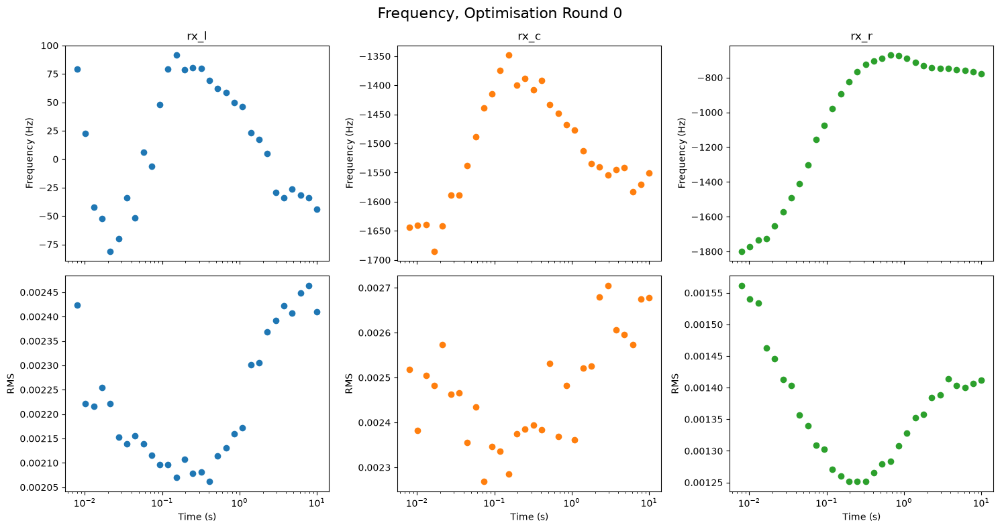

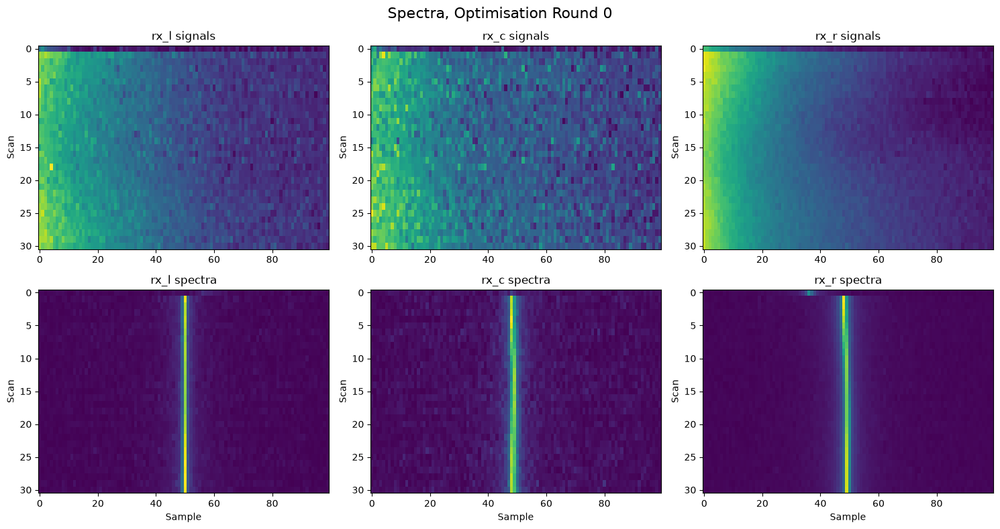

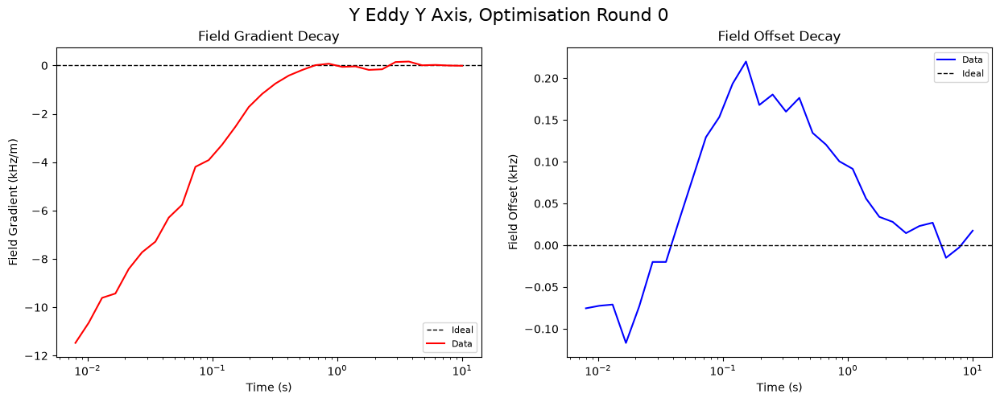

[I 2026-11-25 14:28:28,359] Trial 0 finished with value: 1599.145893445251 and parameters: {'Y_A1': 0.050264767944691, 'Y_A2': 0.1205326345225696, 'Y_A3': 0.0761974357726882, 'Y_A4': 0}. Best is trial 0 with value: 1599.145893445251.


max |E| = 18780.609695152416
mean |E| = 10468.765617191404
RMS E = 11144.008705252552
Total cost = 1.599e+03
E max = 0.12057283343044785
E nanmax = 0.12057283343044785
E contains nan = False
B max = 0.23439780160163548
B nanmax = 0.23439780160163548
B contains nan = False
Trial 1


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23439780160163548 !!!!!!!!!!!!!!!!


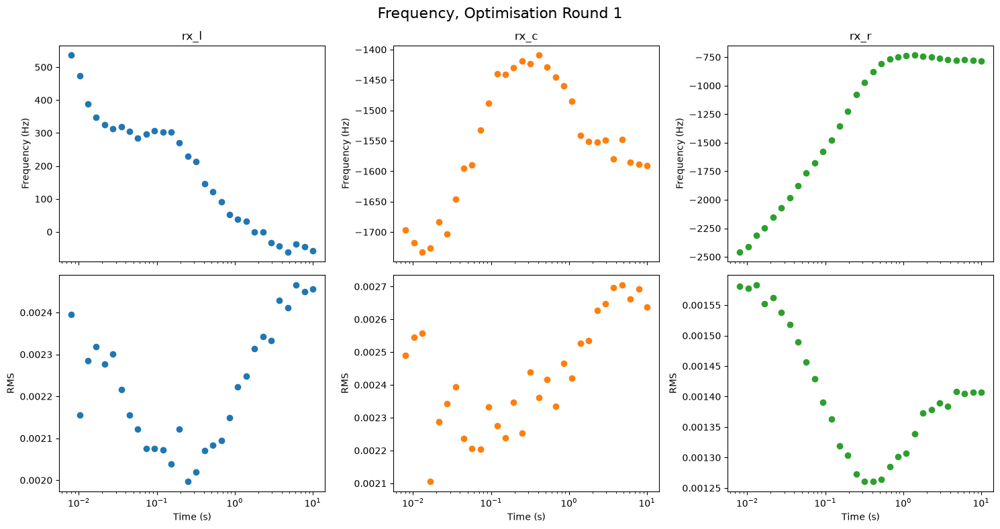

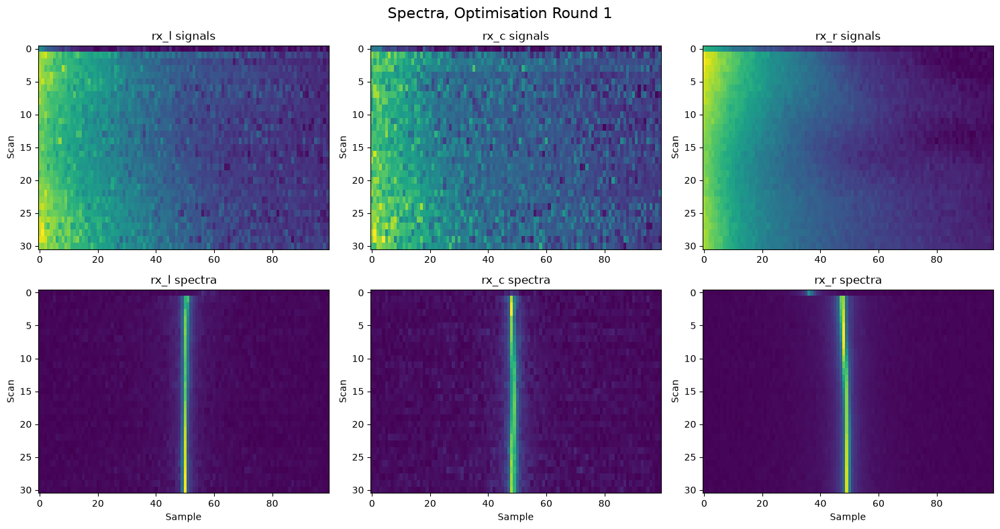

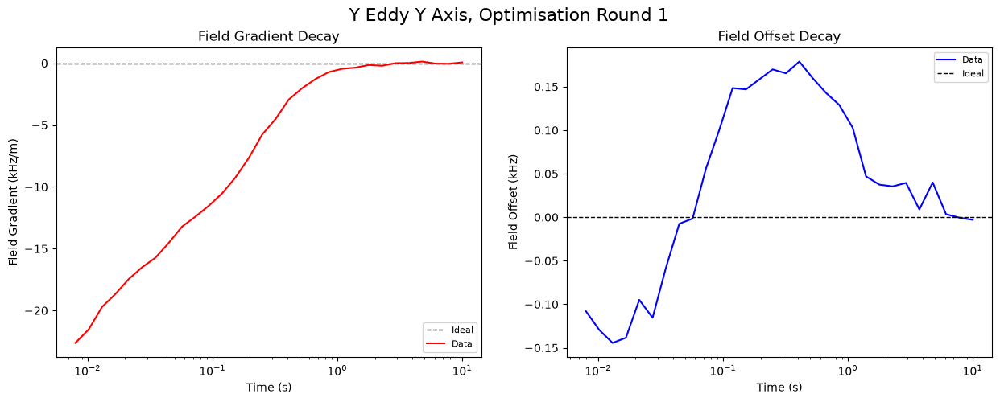

[I 2026-11-25 14:29:53,238] Trial 1 finished with value: 4897.375023521018 and parameters: {'Y_A1': 0.03838367667767065, 'Y_A2': 0.09161662188121153, 'Y_A3': 0.052327417076806465, 'Y_A4': 1.0532303782873975e-09}. Best is trial 0 with value: 1599.145893445251.


max |E| = 29930.03498250874
mean |E| = 14959.353656505078
RMS E = 16822.74750395655
Total cost = 4.897e+03
E max = 0.12750086494823307
E nanmax = 0.12750086494823307
E contains nan = False
B max = 0.24786598543117797
B nanmax = 0.24786598543117797
B contains nan = False
Trial 2


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24786598543117797 !!!!!!!!!!!!!!!!


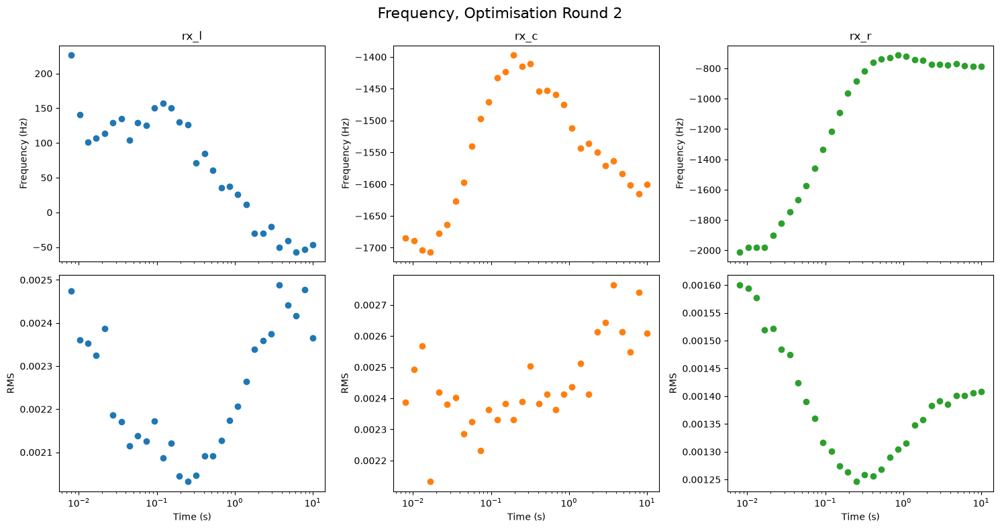

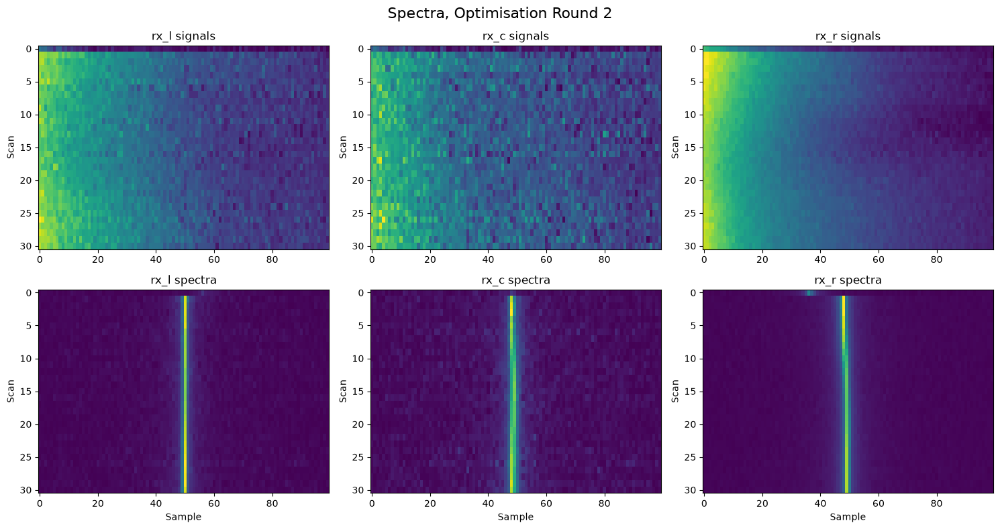

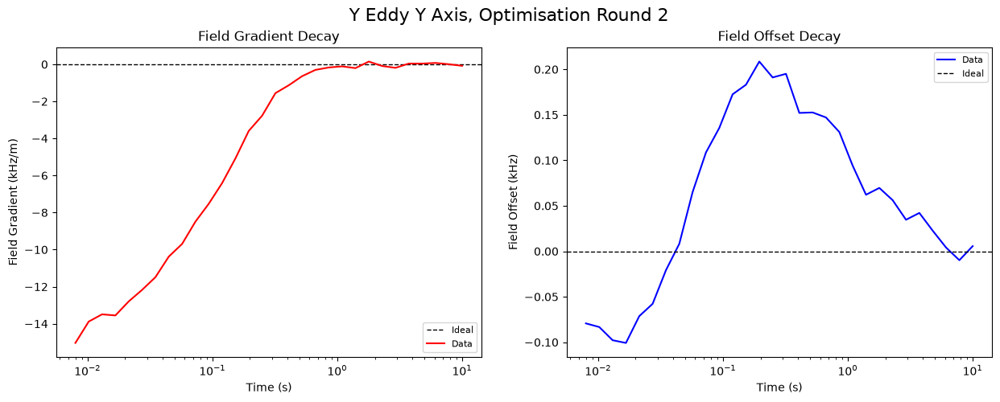

[I 2026-11-25 14:31:17,256] Trial 2 finished with value: 2774.4116255061385 and parameters: {'Y_A1': 0.069485290354734, 'Y_A2': 0.11261228217822189, 'Y_A3': 0.05315514634004854, 'Y_A4': -9.99461955210671e-09}. Best is trial 0 with value: 1599.145893445251.


max |E| = 22368.81559220389
mean |E| = 12348.992170581374
RMS E = 13503.64439084486
Total cost = 2.774e+03
E max = 0.13124716773583964
E nanmax = 0.13124716773583964
E contains nan = False
B max = 0.25514906629002676
B nanmax = 0.25514906629002676
B contains nan = False
Trial 3


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25514906629002676 !!!!!!!!!!!!!!!!


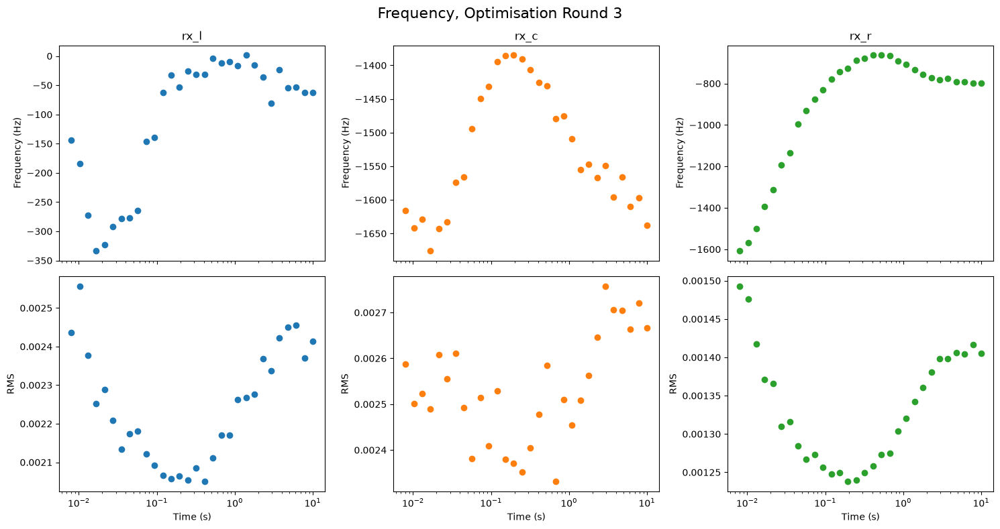

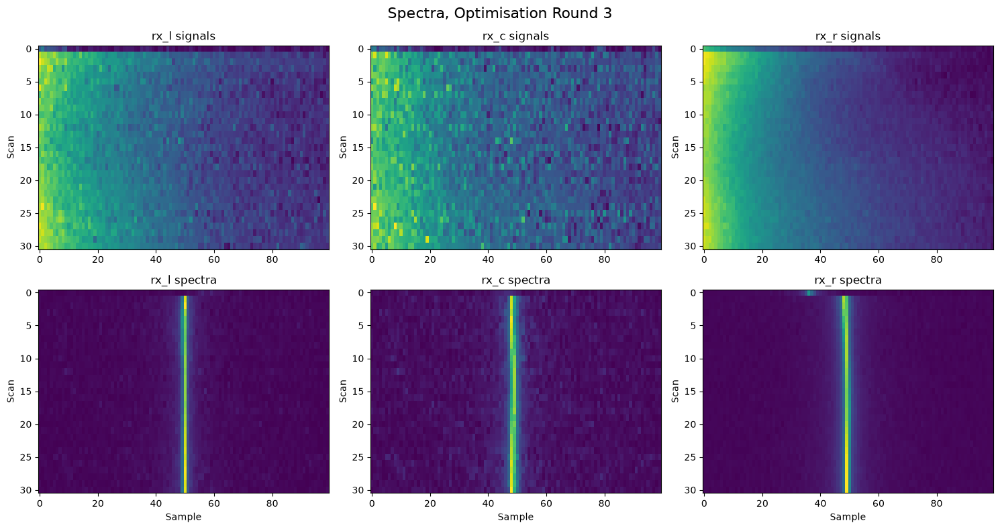

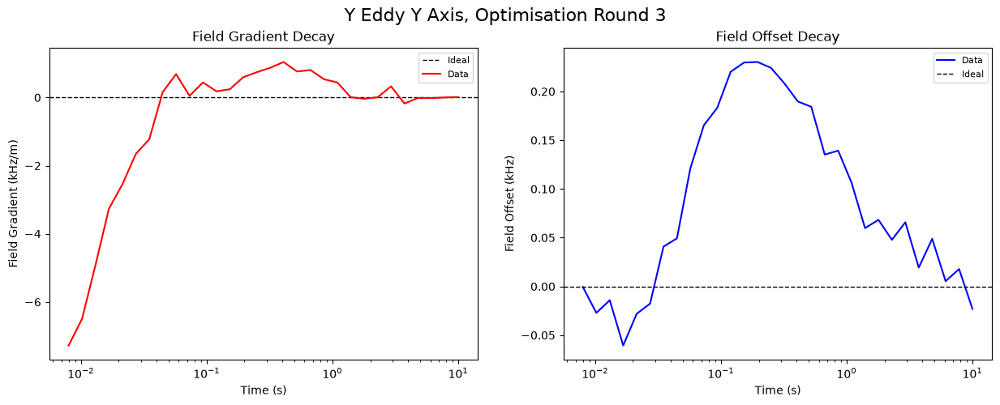

[I 2026-11-25 14:32:41,156] Trial 3 finished with value: 1331.9090586631914 and parameters: {'Y_A1': 0.03194127640410664, 'Y_A2': 0.1355399056145937, 'Y_A3': 0.09135944298732972, 'Y_A4': -2.7084408704705257e-09}. Best is trial 3 with value: 1331.9090586631914.


max |E| = 14632.683658170912
mean |E| = 8010.827919373643
RMS E = 8283.227138533737
Total cost = 1.332e+03
E max = 0.13326210233388897
E nanmax = 0.13326210233388897
E contains nan = False
B max = 0.2590661011565763
B nanmax = 0.2590661011565763
B contains nan = False
Trial 4


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2590661011565763 !!!!!!!!!!!!!!!!


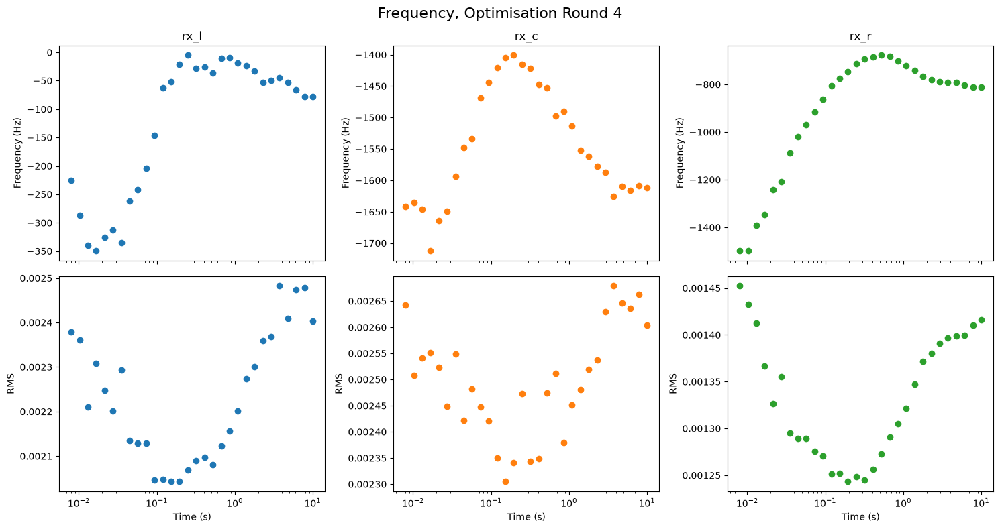

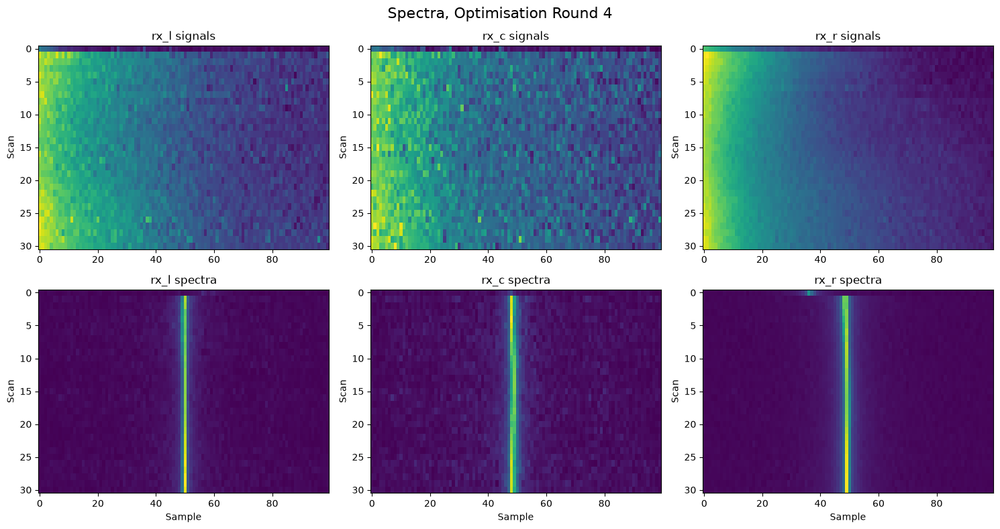

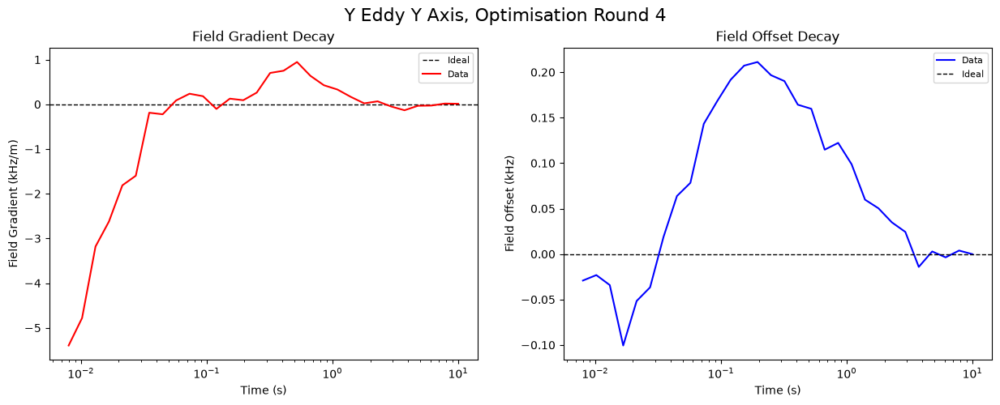

[I 2026-11-25 14:34:04,754] Trial 4 finished with value: 1035.496734019013 and parameters: {'Y_A1': 0.045300640293158126, 'Y_A2': 0.13322904485661544, 'Y_A3': 0.0954873286880409, 'Y_A4': 4.472181993530856e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 12743.628185907042
mean |E| = 7850.907879393635
RMS E = 7998.560778741705
Total cost = 1.035e+03
E max = 0.13303884891115833
E nanmax = 0.13303884891115833
E contains nan = False
B max = 0.25863201387219276
B nanmax = 0.25863201387219276
B contains nan = False
Trial 5


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25863201387219276 !!!!!!!!!!!!!!!!


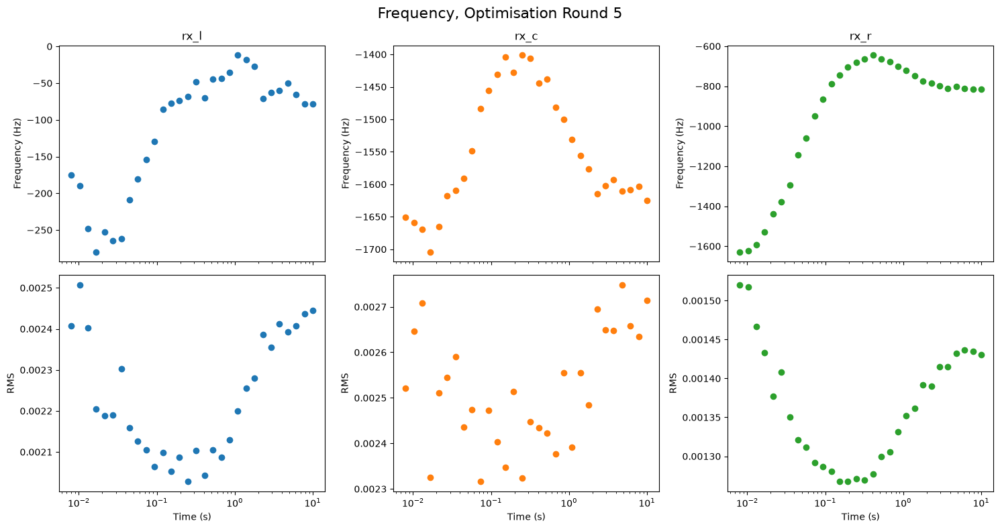

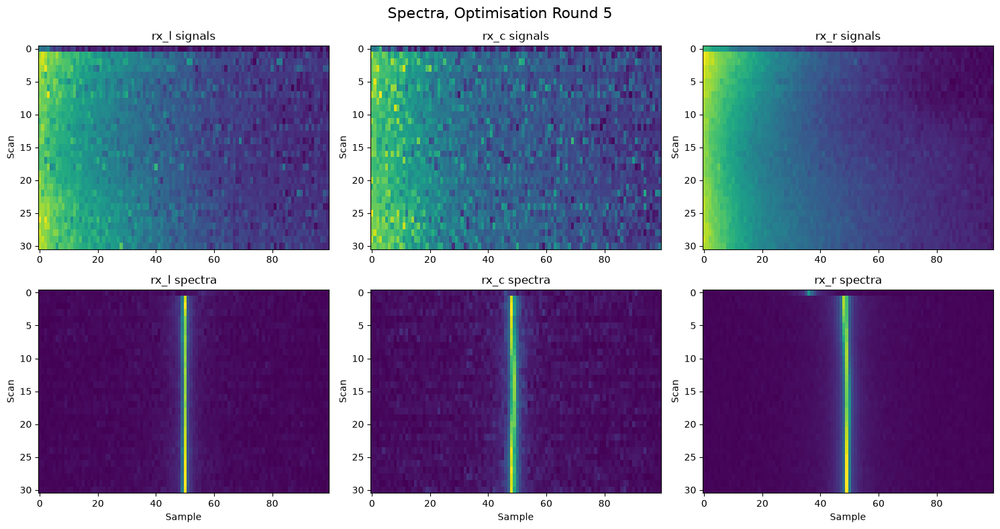

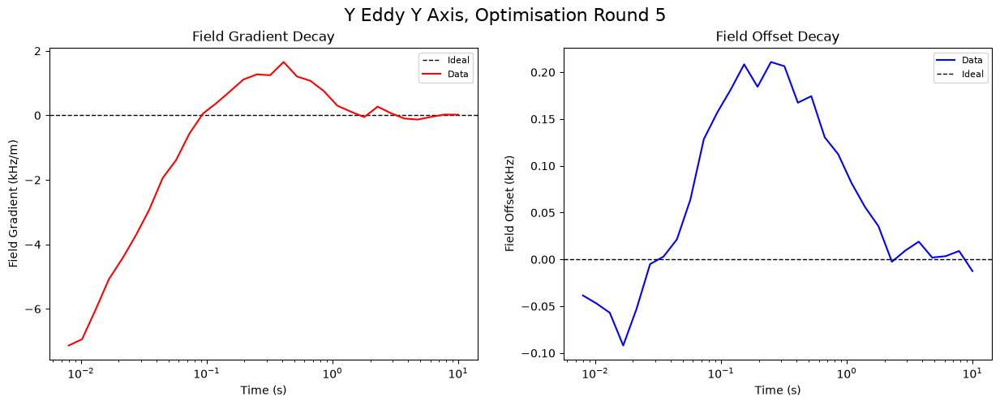

[I 2026-11-25 14:35:28,795] Trial 5 finished with value: 1857.7884258152008 and parameters: {'Y_A1': 0.06629542882316225, 'Y_A2': 0.14210378797044232, 'Y_A3': 0.06457715019485356, 'Y_A4': -3.3972259092128446e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 14537.73113443278
mean |E| = 8408.629018823918
RMS E = 8777.41610834509
Total cost = 1.858e+03
E max = 0.13563233582224402
E nanmax = 0.13563233582224402
E contains nan = False
B max = 0.26367393007013923
B nanmax = 0.26367393007013923
B contains nan = False
Trial 6


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26367393007013923 !!!!!!!!!!!!!!!!


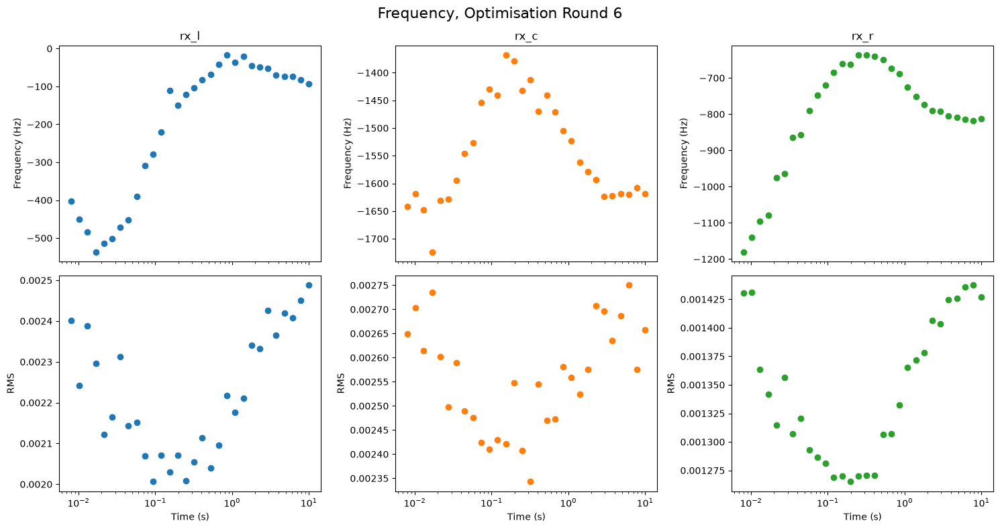

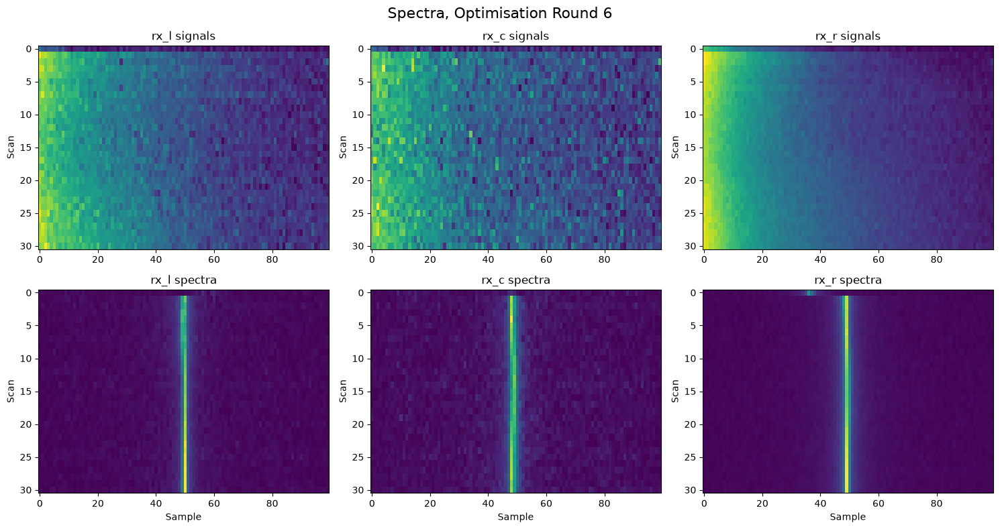

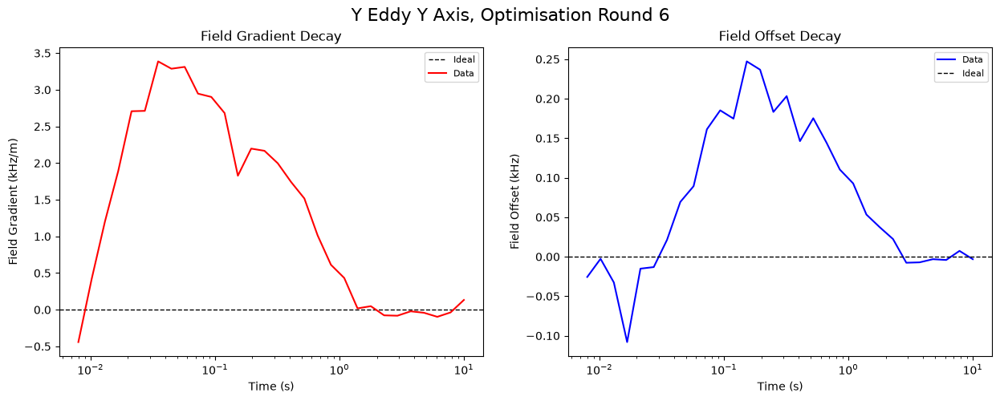

[I 2026-11-25 14:36:53,329] Trial 6 finished with value: 2182.9620663338837 and parameters: {'Y_A1': 0.04047799346133831, 'Y_A2': 0.14534148796365293, 'Y_A3': 0.10313295981054796, 'Y_A4': 6.928944695312823e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 7766.116941529233
mean |E| = 5979.343661502581
RMS E = 6109.348154053112
Total cost = 2.183e+03
E max = 0.12865930917494353
E nanmax = 0.12865930917494353
E contains nan = False
B max = 0.25011817470262243
B nanmax = 0.25011817470262243
B contains nan = False
Trial 7


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25011817470262243 !!!!!!!!!!!!!!!!


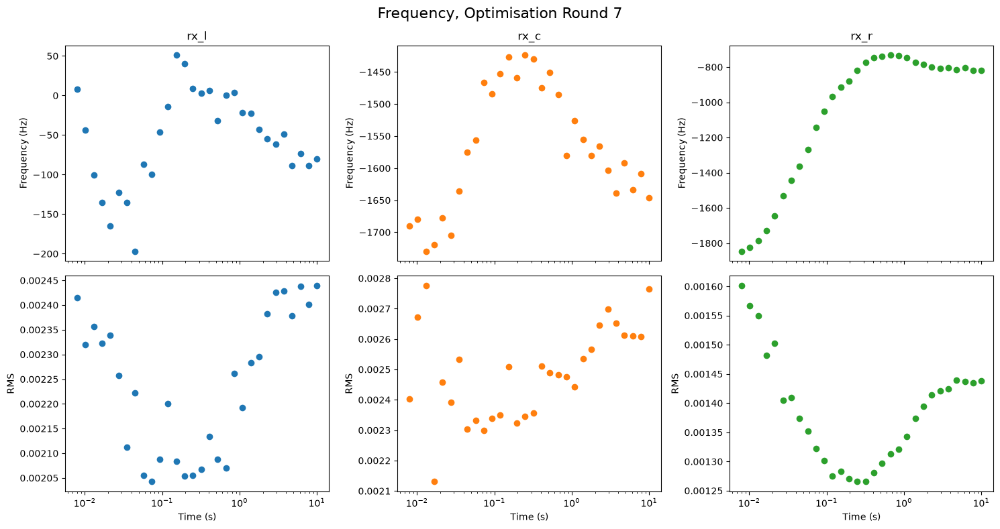

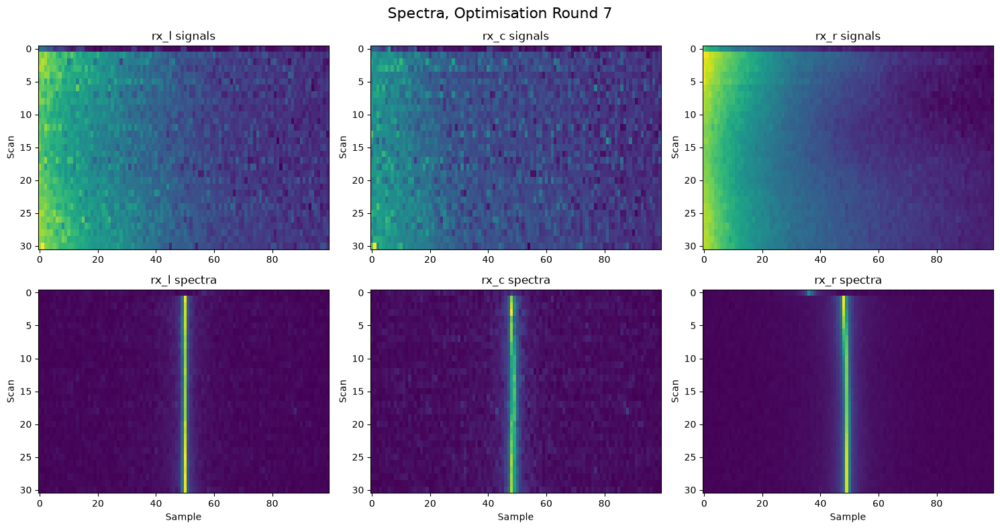

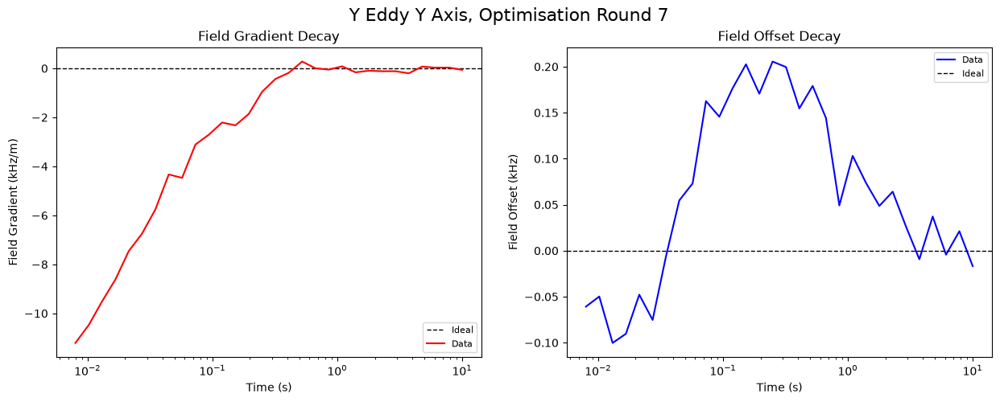

[I 2026-11-25 14:38:17,791] Trial 7 finished with value: 1598.3601436889348 and parameters: {'Y_A1': 0.03487151428448912, 'Y_A2': 0.12242019344407698, 'Y_A3': 0.08420133719800407, 'Y_A4': -4.803803808686376e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 18540.729635182404
mean |E| = 10089.955022488753
RMS E = 10695.113492510764
Total cost = 1.598e+03
E max = 0.1272741900222019
E nanmax = 0.1272741900222019
E contains nan = False
B max = 0.2474253773098892
B nanmax = 0.2474253773098892
B contains nan = False
Trial 8


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2474253773098892 !!!!!!!!!!!!!!!!


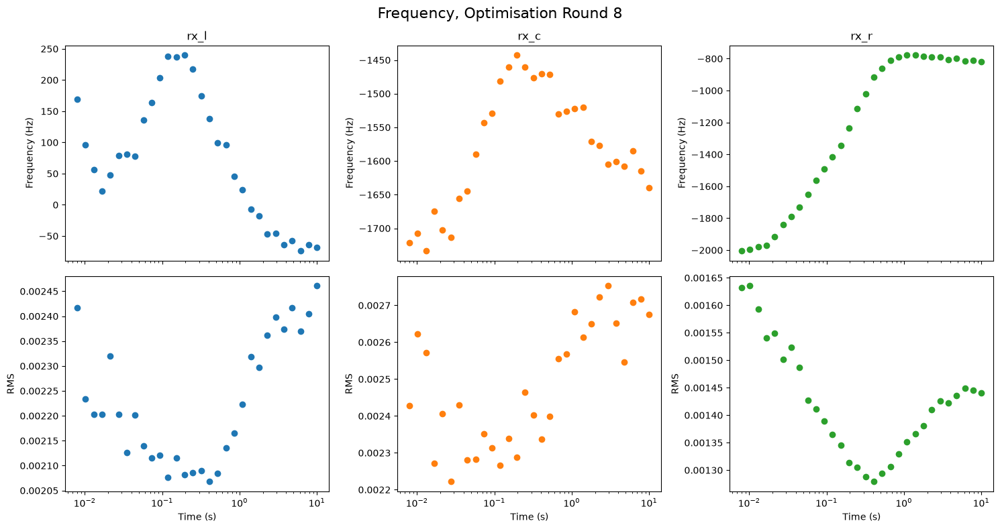

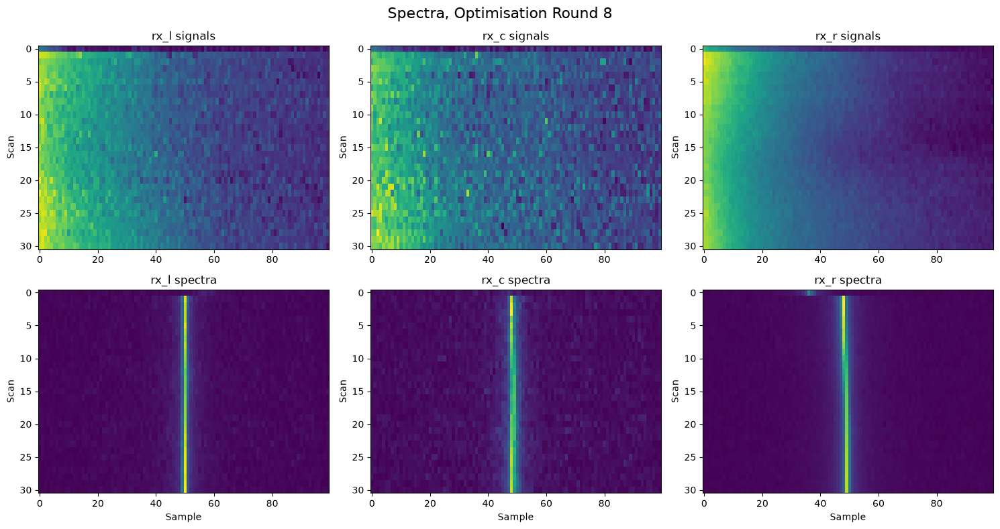

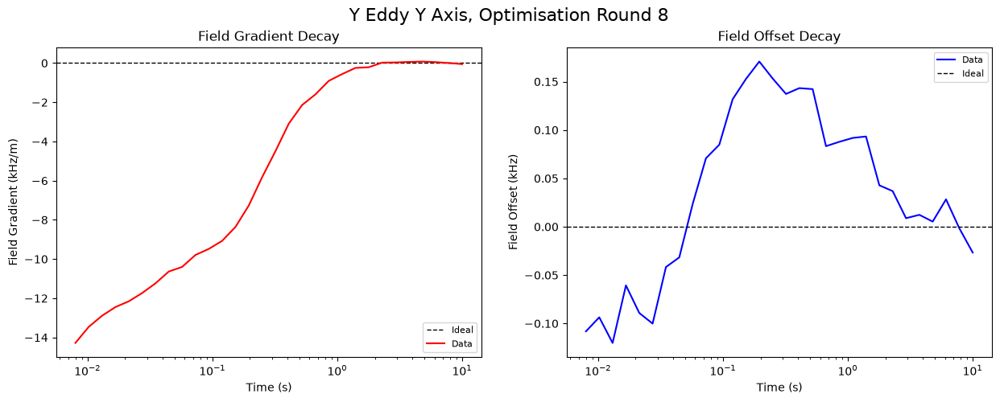

[I 2026-11-25 14:39:39,408] Trial 8 finished with value: 4411.519599739467 and parameters: {'Y_A1': 0.050619960376620726, 'Y_A2': 0.08931669421779373, 'Y_A3': 0.0936738118935773, 'Y_A4': 4.176170760392763e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 21744.127936031975
mean |E| = 13201.39930034982
RMS E = 14193.0688988592
Total cost = 4.412e+03
E max = 0.12630011867602253
E nanmax = 0.12630011867602253
E contains nan = False
B max = 0.2455317727143429
B nanmax = 0.2455317727143429
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2455317727143429 !!!!!!!!!!!!!!!!


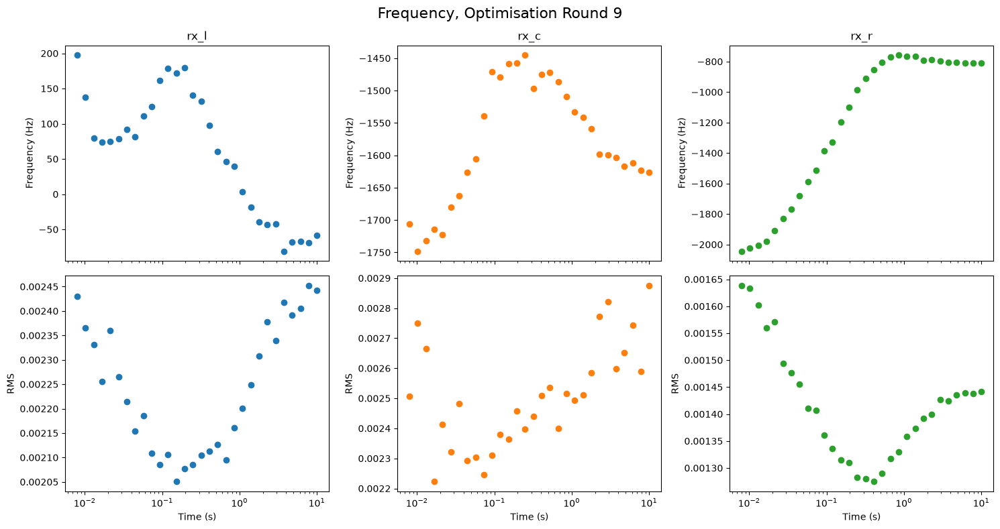

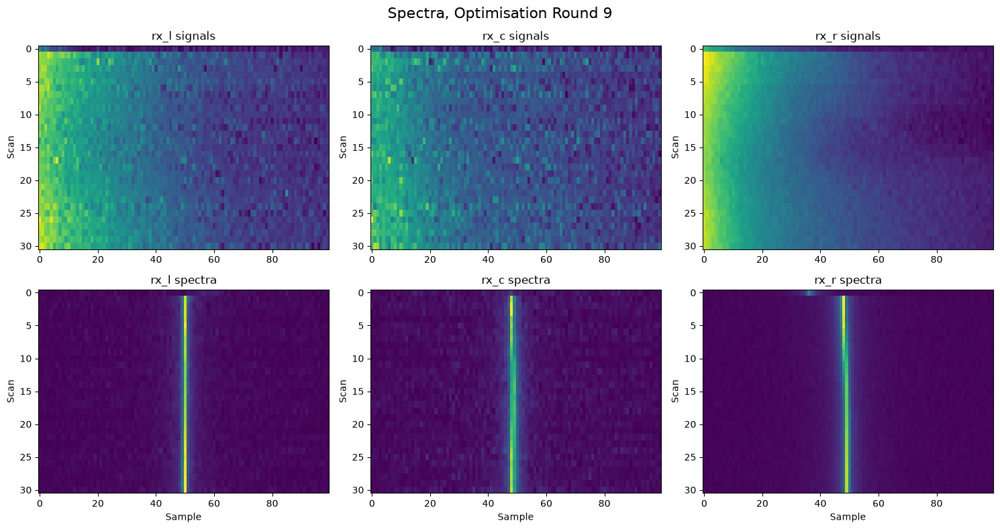

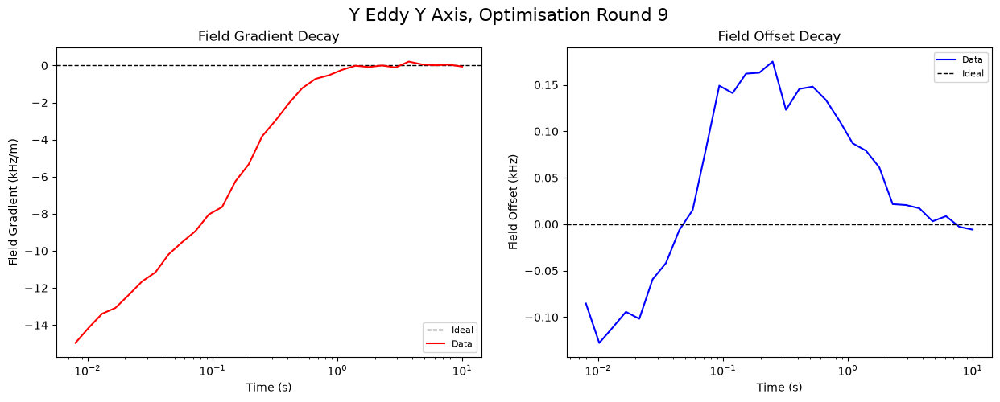

[I 2026-11-25 14:40:27,362] Trial 9 finished with value: 3406.4234091531002 and parameters: {'Y_A1': 0.049191110899251454, 'Y_A2': 0.10262489801437076, 'Y_A3': 0.0743515248735468, 'Y_A4': -7.989332768557813e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 22413.793103448268
mean |E| = 12719.473596535063
RMS E = 13786.915087113955
Total cost = 3.406e+03
E max = 0.13060731941947054
E nanmax = 0.13060731941947054
E contains nan = False
B max = 0.253905156911684
B nanmax = 0.253905156911684
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.253905156911684 !!!!!!!!!!!!!!!!


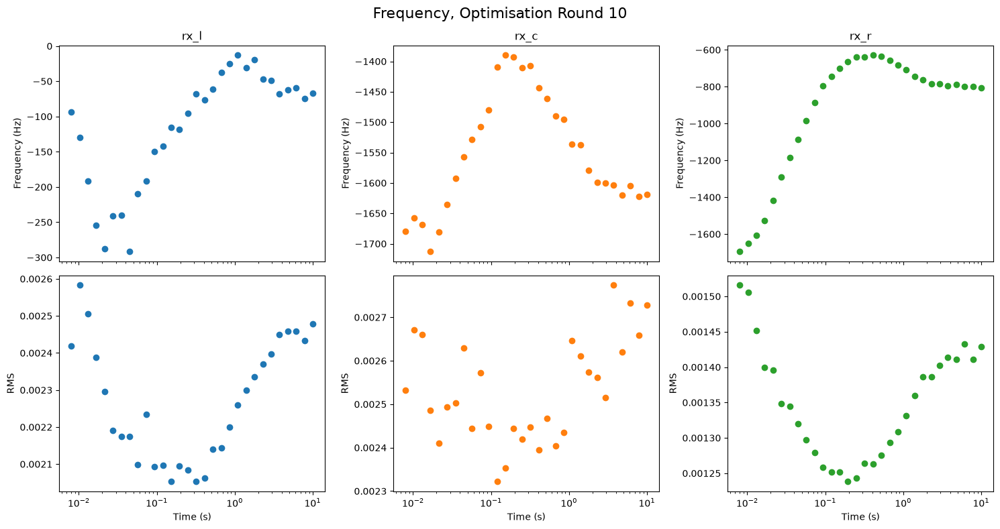

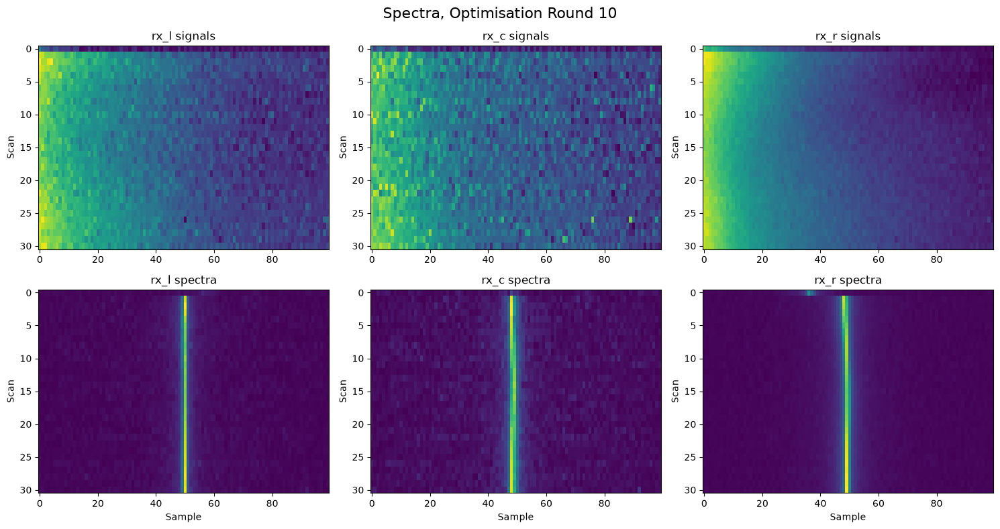

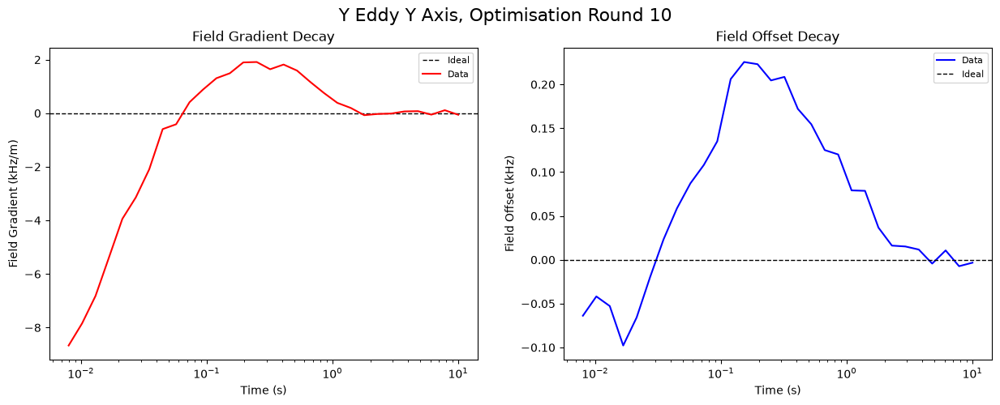

[I 2026-11-25 14:41:15,346] Trial 10 finished with value: 2102.0786326772827 and parameters: {'Y_A1': 0.041430075380461395, 'Y_A2': 0.14610718869455258, 'Y_A3': 0.06662671800692534, 'Y_A4': 9.093932097299275e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 16016.991504247871
mean |E| = 8128.935532233881
RMS E = 8620.483572174528
Total cost = 2.102e+03
E max = 0.1366431945522065
E nanmax = 0.1366431945522065
E contains nan = False
B max = 0.26563899790227613
B nanmax = 0.26563899790227613
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26563899790227613 !!!!!!!!!!!!!!!!


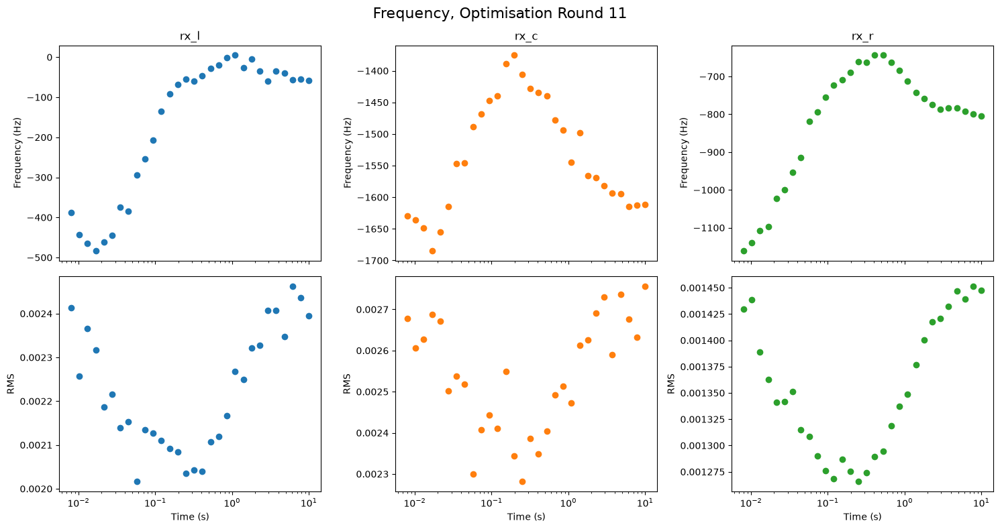

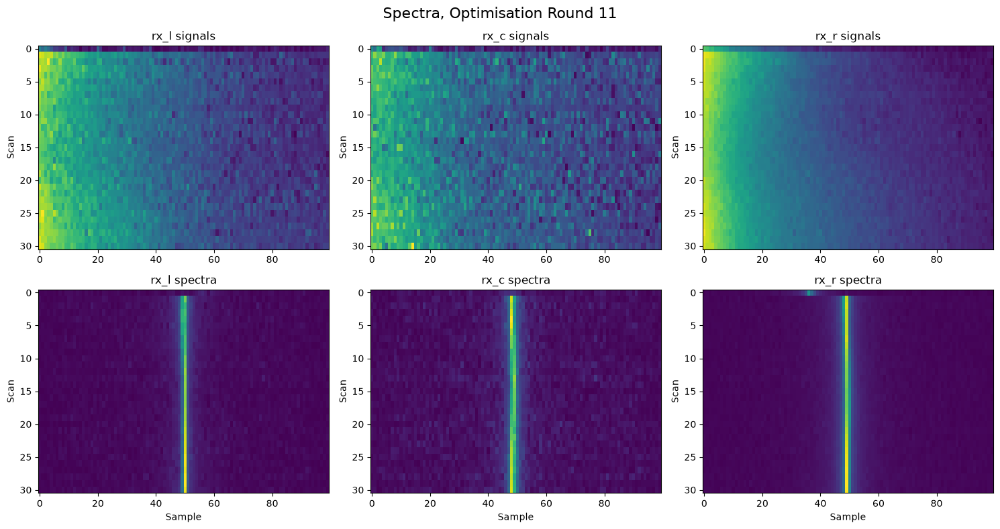

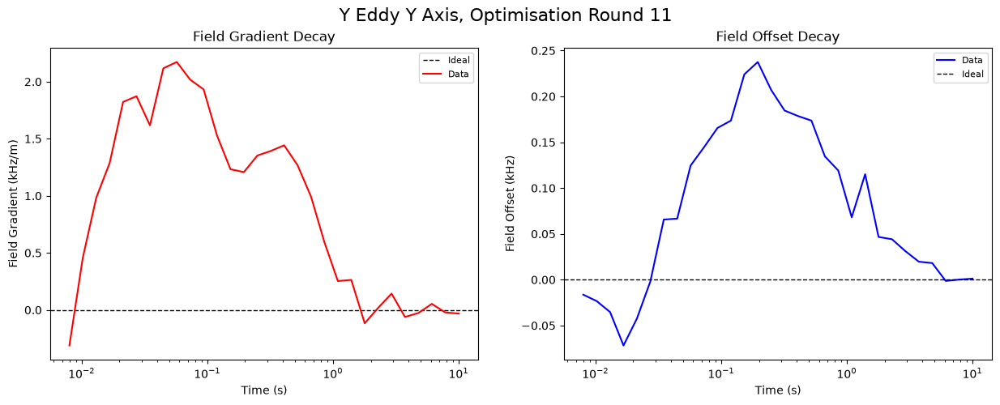

[I 2026-11-25 14:42:03,205] Trial 11 finished with value: 1703.070411506095 and parameters: {'Y_A1': 0.05619666857440628, 'Y_A2': 0.13970254363081247, 'Y_A3': 0.10140812101659277, 'Y_A4': 4.560858996221926e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 7731.134432783607
mean |E| = 6504.581042811926
RMS E = 6551.923056553984
Total cost = 1.703e+03
E max = 0.13360180481381217
E nanmax = 0.13360180481381217
E contains nan = False
B max = 0.25972656736680677
B nanmax = 0.25972656736680677
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25972656736680677 !!!!!!!!!!!!!!!!


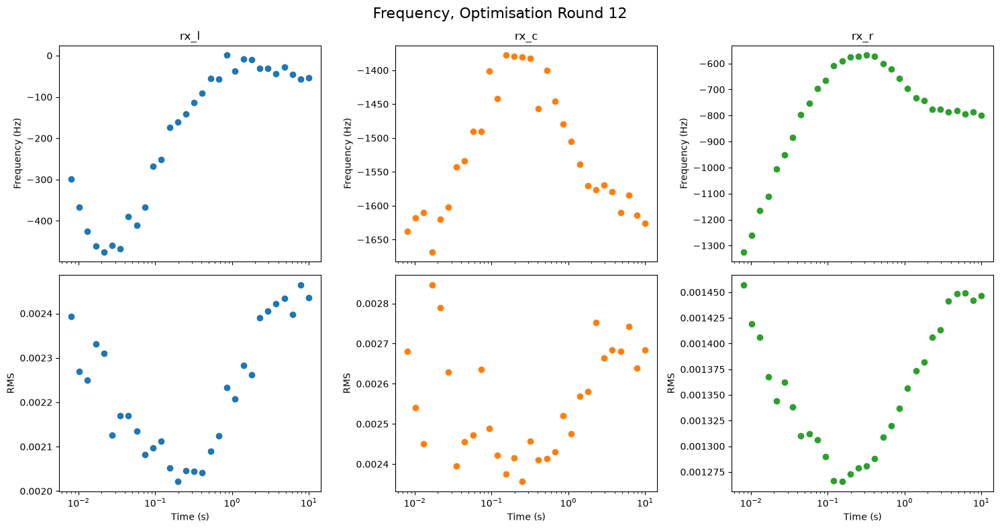

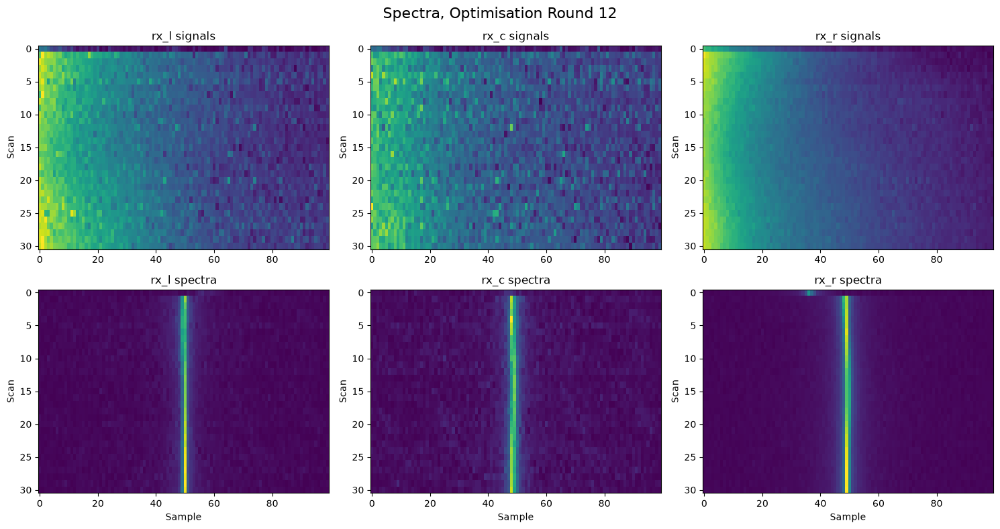

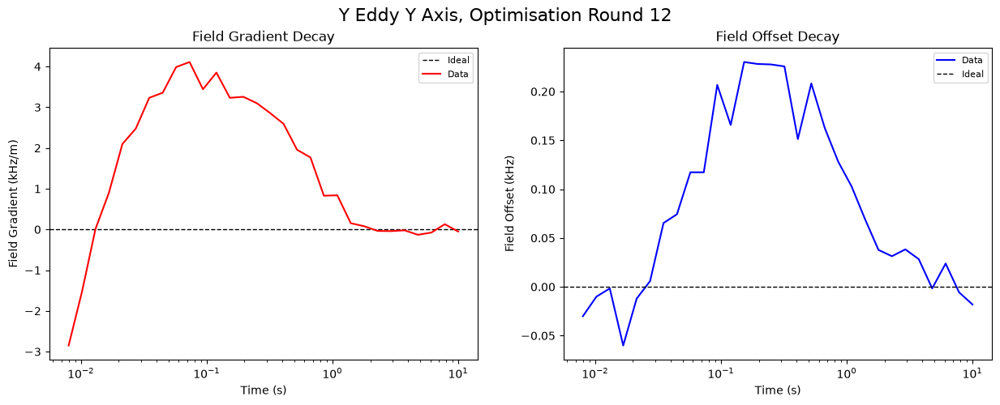

[I 2026-11-25 14:42:53,515] Trial 12 finished with value: 3082.5811920423735 and parameters: {'Y_A1': 0.03118630279249618, 'Y_A2': 0.1552675538463302, 'Y_A3': 0.08720700761295111, 'Y_A4': 3.306710673071943e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 10259.870064967514
mean |E| = 5958.687323005162
RMS E = 6215.468067546519
Total cost = 3.083e+03
E max = 0.13751883727922862
E nanmax = 0.13751883727922862
E contains nan = False
B max = 0.26734136810347714
B nanmax = 0.26734136810347714
B contains nan = False
Trial 13


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26734136810347714 !!!!!!!!!!!!!!!!


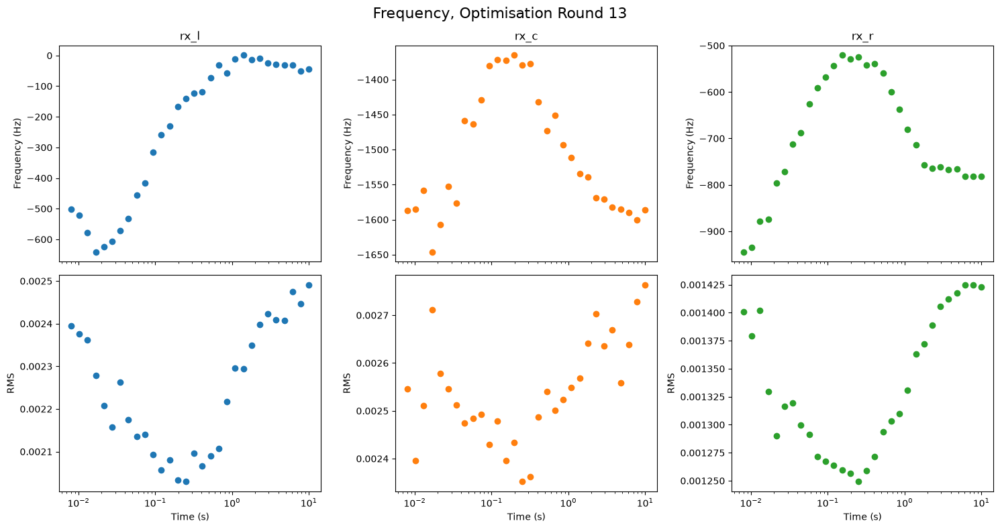

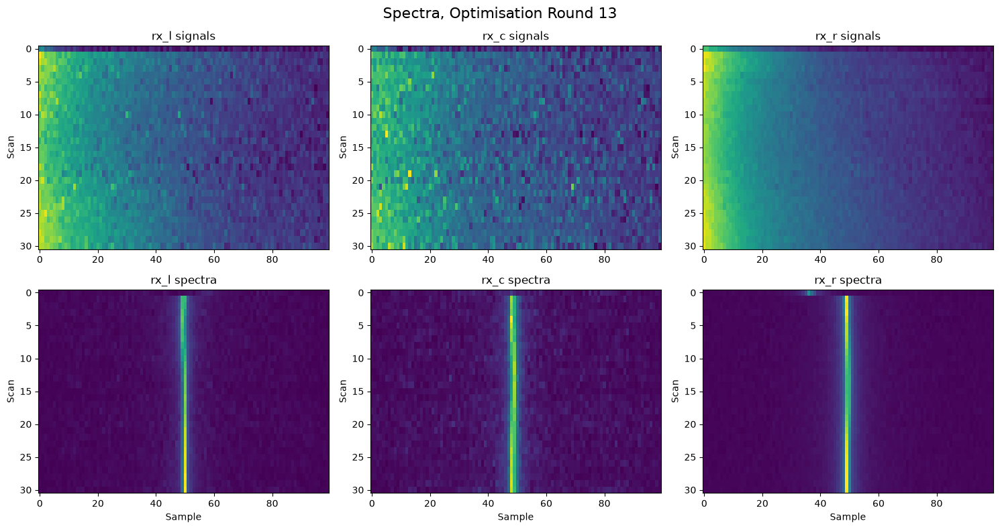

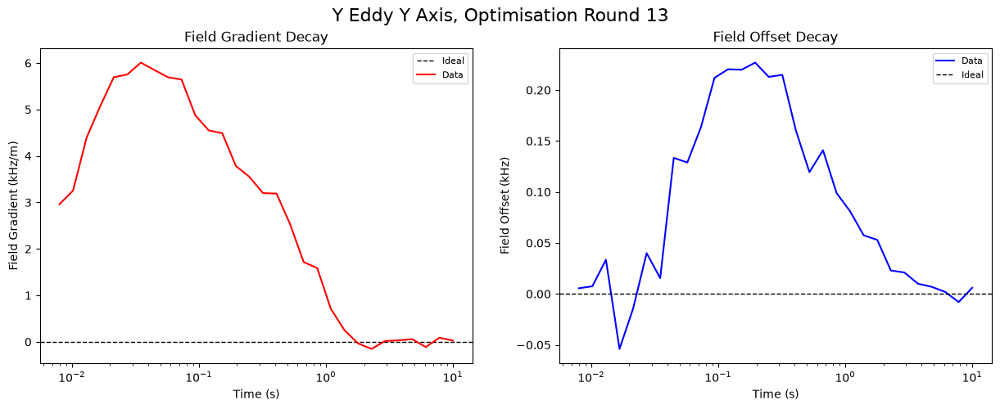

[I 2026-11-25 14:44:18,361] Trial 13 finished with value: 3629.8921515925485 and parameters: {'Y_A1': 0.03677342439707759, 'Y_A2': 0.15866055381011193, 'Y_A3': 0.1047903581931982, 'Y_A4': -9.60706577652596e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 7551.2243878060945
mean |E| = 4575.378977178076
RMS E = 5092.384294784363
Total cost = 3.630e+03
E max = 0.1317587039588436
E nanmax = 0.1317587039588436
E contains nan = False
B max = 0.25614345944797046
B nanmax = 0.25614345944797046
B contains nan = False
Trial 14


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25614345944797046 !!!!!!!!!!!!!!!!


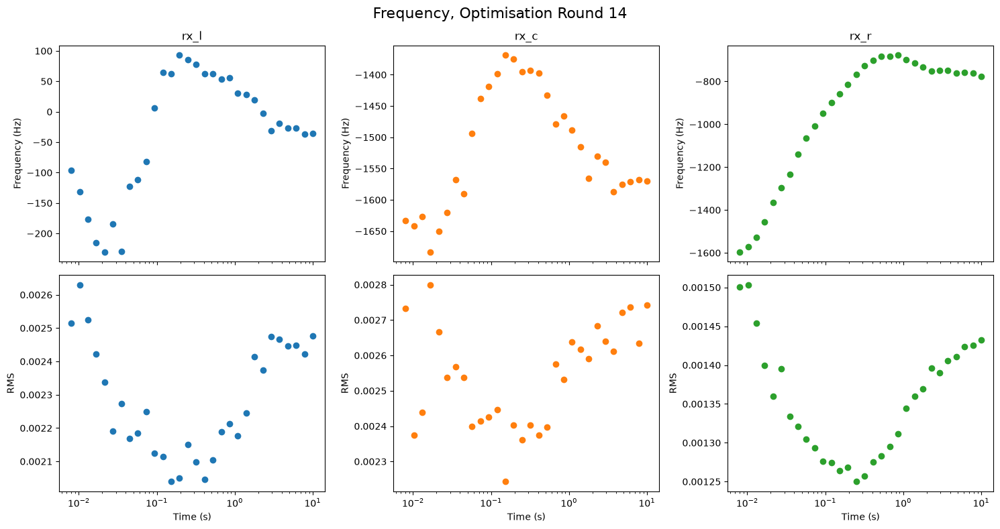

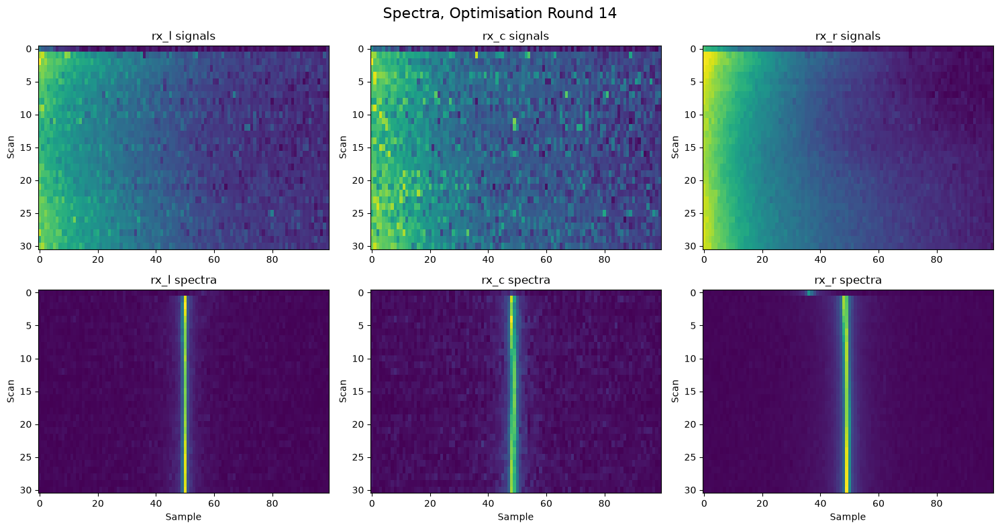

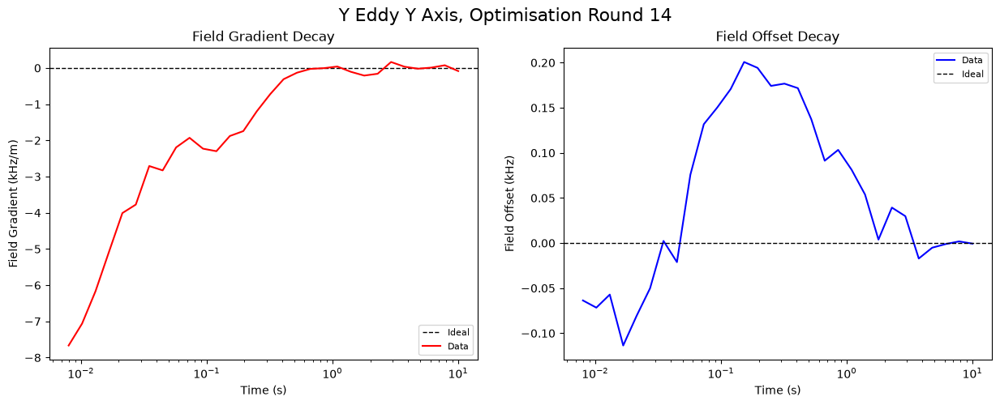

[I 2026-11-25 14:45:42,307] Trial 14 finished with value: 1358.4160920929228 and parameters: {'Y_A1': 0.04072315751566576, 'Y_A2': 0.1201983075082686, 'Y_A3': 0.10289754723146038, 'Y_A4': 9.89522034455114e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 14997.50124937531
mean |E| = 9138.597367982673
RMS E = 9404.128052766386
Total cost = 1.358e+03
E max = 0.13628712071742405
E nanmax = 0.13628712071742405
E contains nan = False
B max = 0.2649468993387044
B nanmax = 0.2649468993387044
B contains nan = False
Trial 15


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2649468993387044 !!!!!!!!!!!!!!!!


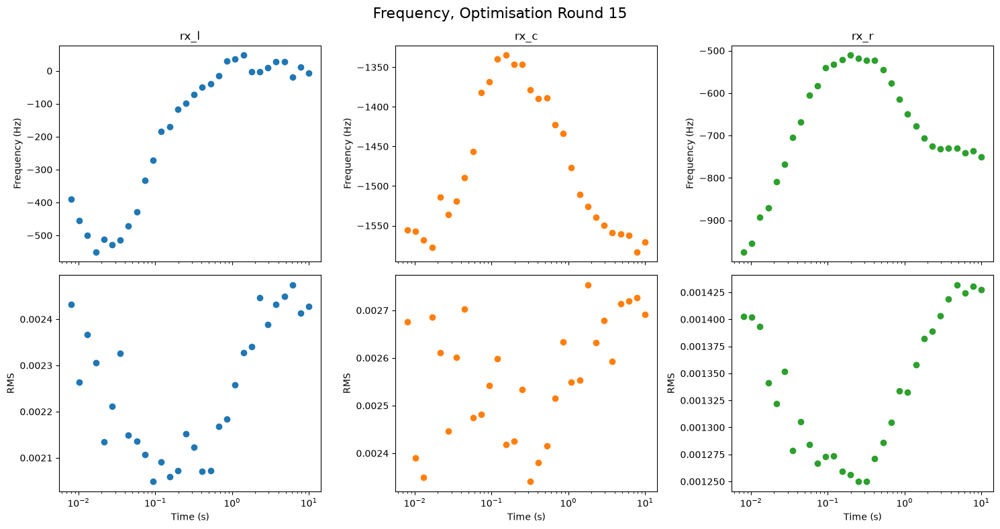

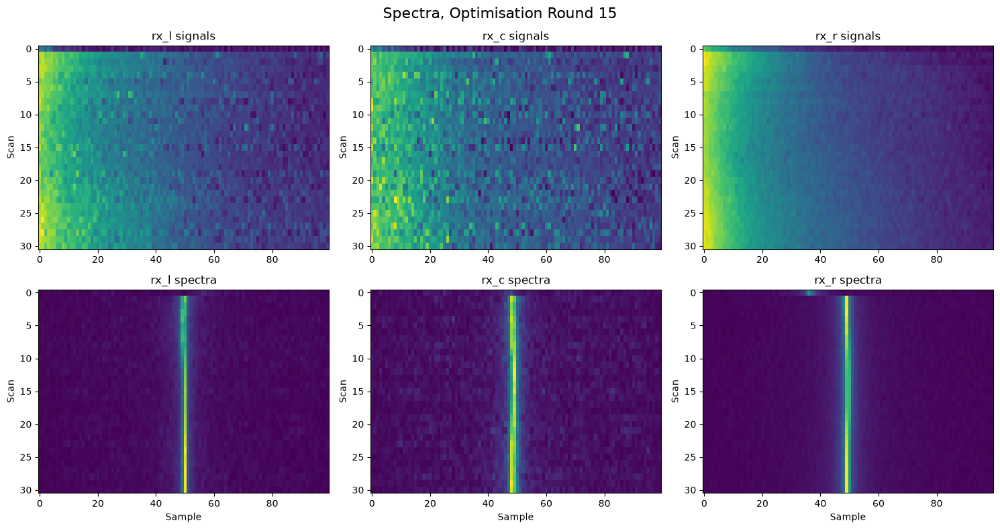

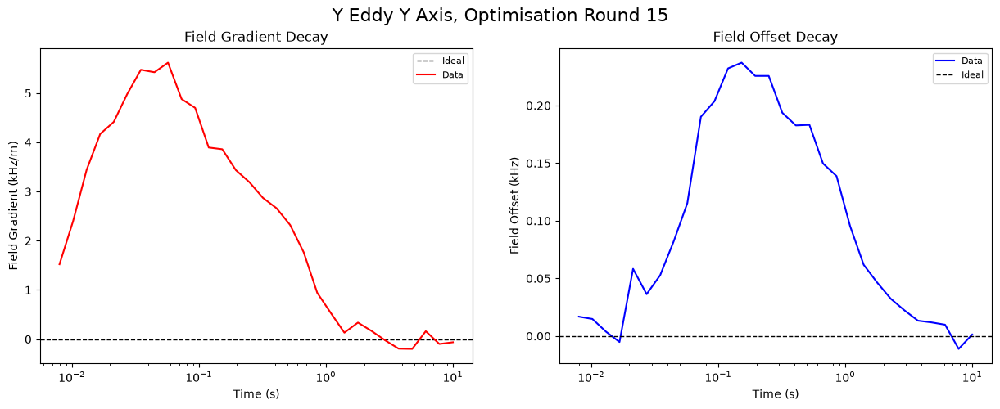

[I 2026-11-25 14:47:07,491] Trial 15 finished with value: 3770.88415659975 and parameters: {'Y_A1': 0.0303143844715248, 'Y_A2': 0.15540796945566476, 'Y_A3': 0.10595713176829301, 'Y_A4': -3.824157206830694e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 7576.211894052972
mean |E| = 4954.356155255705
RMS E = 5341.346620199842
Total cost = 3.771e+03
E max = 0.1284933456862833
E nanmax = 0.1284933456862833
E contains nan = False
B max = 0.24979551986675377
B nanmax = 0.24979551986675377
B contains nan = False
Trial 16


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24979551986675377 !!!!!!!!!!!!!!!!


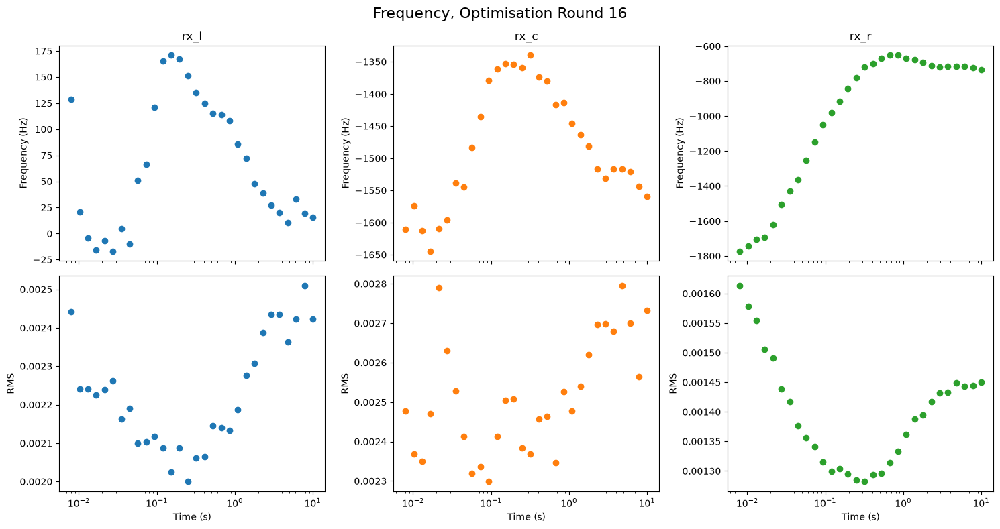

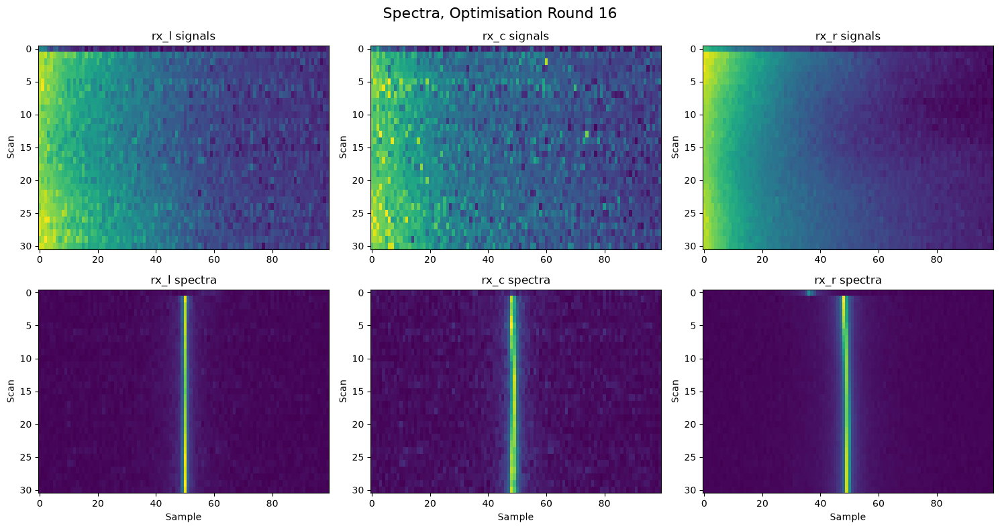

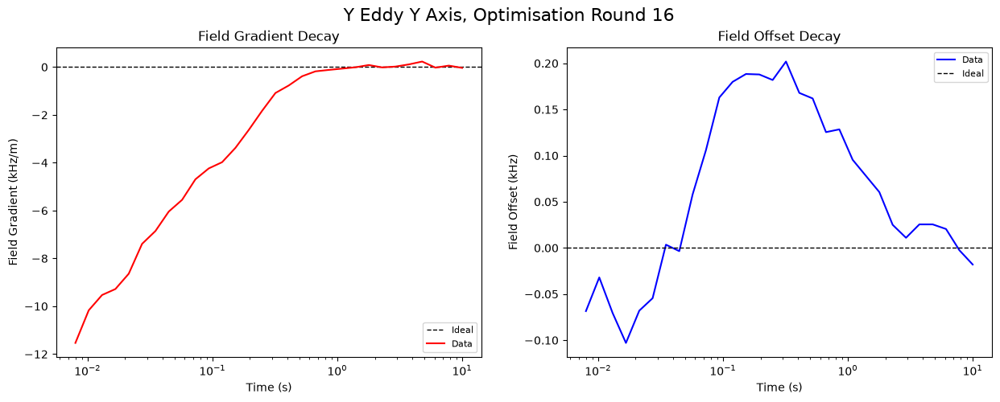

[I 2026-11-25 14:48:31,429] Trial 16 finished with value: 2000.8647370565366 and parameters: {'Y_A1': 0.037783824277782894, 'Y_A2': 0.11512302744430922, 'Y_A3': 0.08794853045741989, 'Y_A4': 6.2861215591793646e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 19015.492253873057
mean |E| = 10745.460603031815
RMS E = 11373.757857085599
Total cost = 2.001e+03
E max = 0.13026209460712848
E nanmax = 0.13026209460712848
E contains nan = False
B max = 0.2532339644944493
B nanmax = 0.2532339644944493
B contains nan = False
Trial 17


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2532339644944493 !!!!!!!!!!!!!!!!


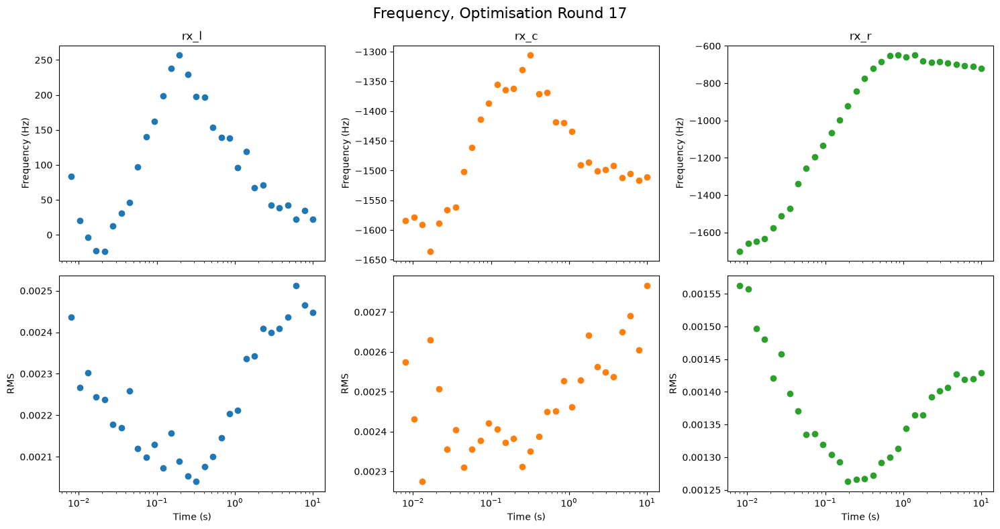

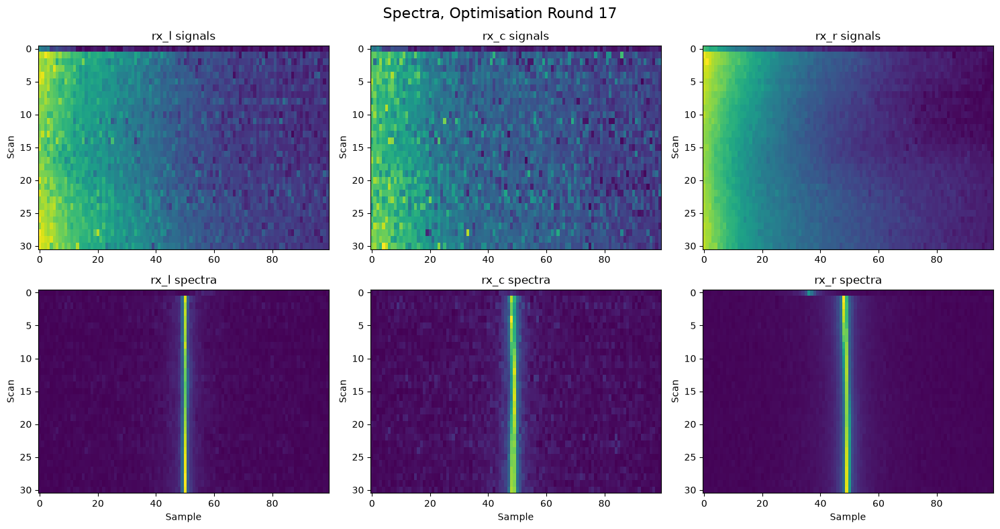

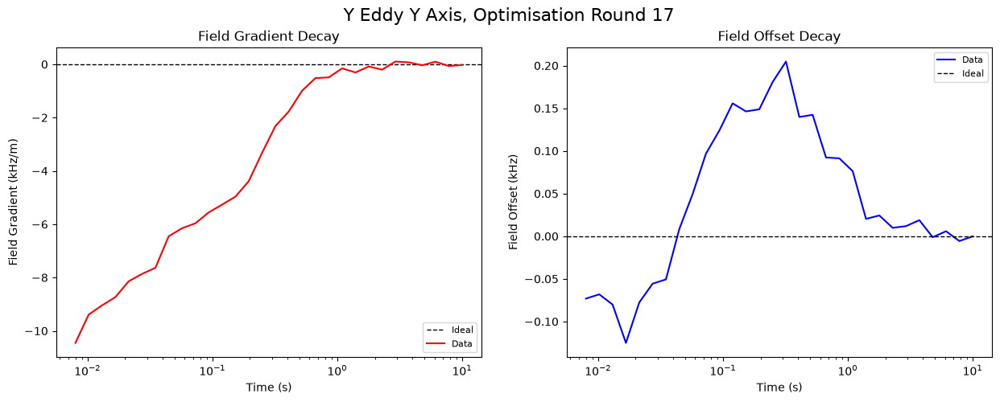

[I 2026-11-25 14:49:57,007] Trial 17 finished with value: 2906.4344694090955 and parameters: {'Y_A1': 0.049145663970585195, 'Y_A2': 0.10550359328263047, 'Y_A3': 0.09984741663324954, 'Y_A4': -3.5316297608075925e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 17841.07946026986
mean |E| = 11055.472263868063
RMS E = 11610.054676818947
Total cost = 2.906e+03
E max = 0.1347443130084666
E nanmax = 0.1347443130084666
E contains nan = False
B max = 0.261947542712159
B nanmax = 0.261947542712159
B contains nan = False
Trial 18


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.261947542712159 !!!!!!!!!!!!!!!!


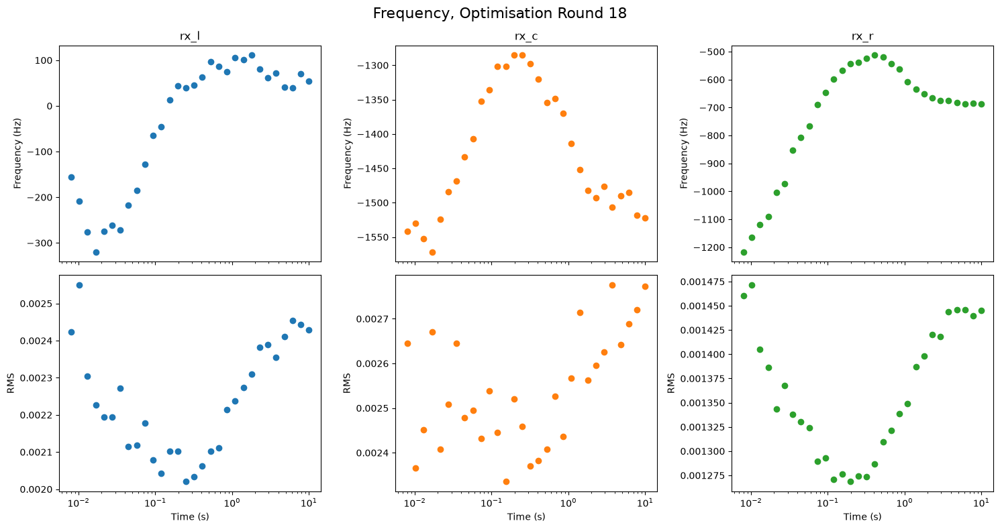

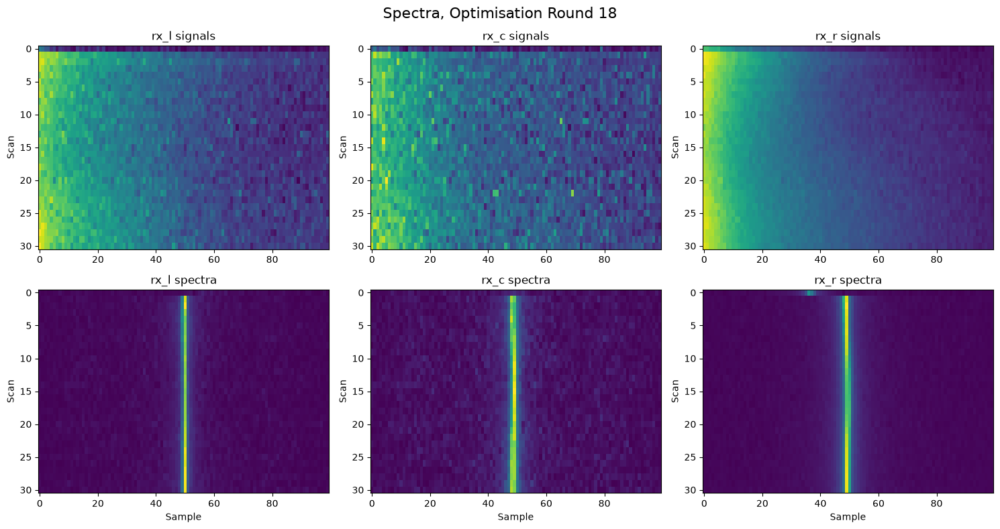

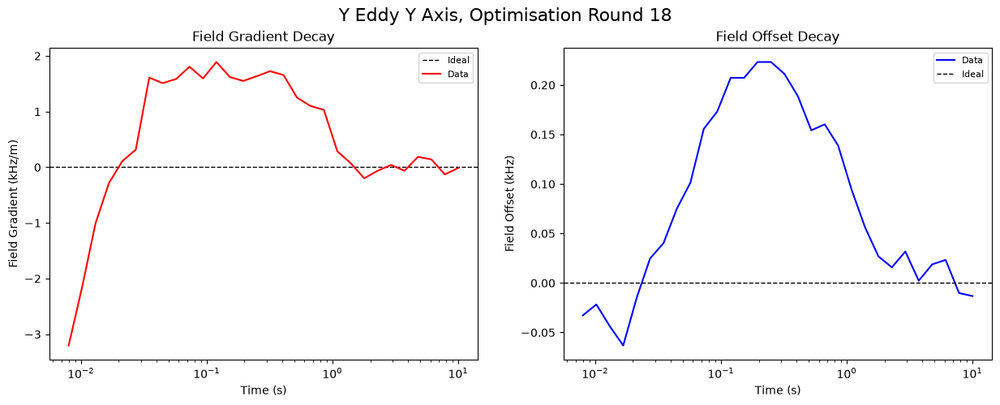

[I 2026-11-25 14:51:20,398] Trial 18 finished with value: 2320.099641356674 and parameters: {'Y_A1': 0.0518742488407034, 'Y_A2': 0.14384425678961713, 'Y_A3': 0.08826101840242336, 'Y_A4': 5.073635695887069e-09}. Best is trial 4 with value: 1035.496734019013.


max |E| = 10614.69265367316
mean |E| = 6892.553723138428
RMS E = 6993.949702330447
Total cost = 2.320e+03
E max = 0.1354281002172084
E nanmax = 0.1354281002172084
E contains nan = False
B max = 0.2632768191739079
B nanmax = 0.2632768191739079
B contains nan = False
Trial 19


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2632768191739079 !!!!!!!!!!!!!!!!


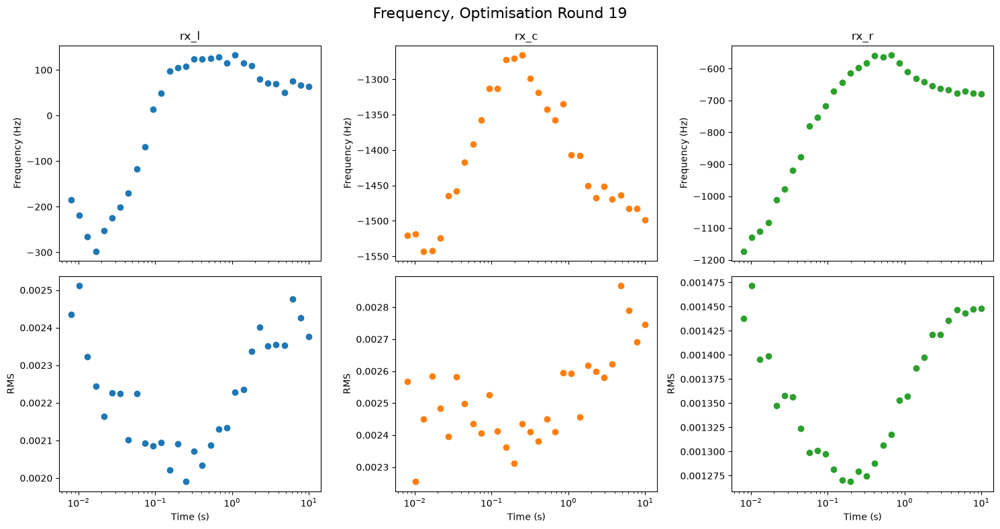

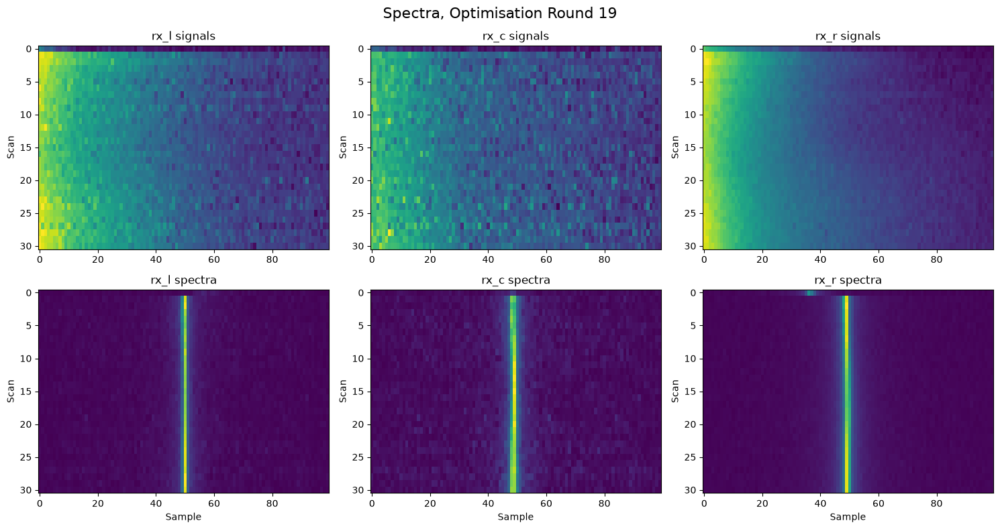

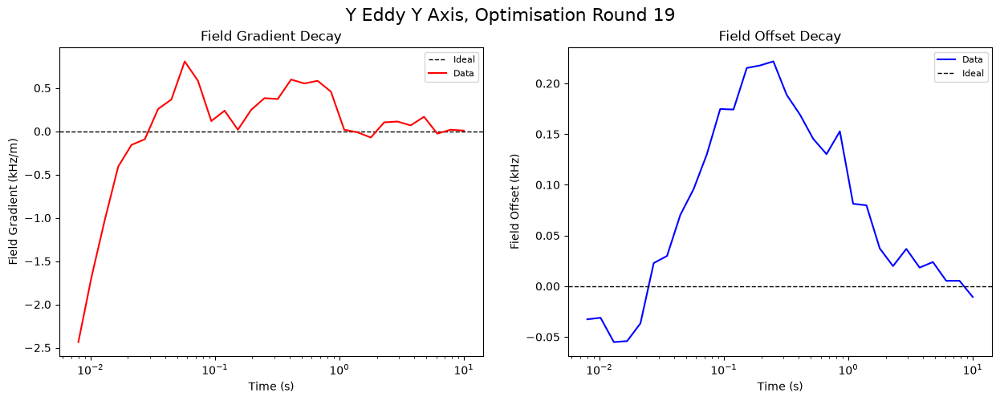

[I 2026-11-25 14:52:47,042] Trial 19 finished with value: 974.8585701818189 and parameters: {'Y_A1': 0.0550492333149204, 'Y_A2': 0.13182235554288405, 'Y_A3': 0.10262475620929383, 'Y_A4': 2.0706954449561393e-10}. Best is trial 19 with value: 974.8585701818189.


max |E| = 9875.062468765613
mean |E| = 7433.116774945856
RMS E = 7461.894556767921
Total cost = 9.749e+02
E max = 0.13596483252177197
E nanmax = 0.13596483252177197
E contains nan = False
B max = 0.26432019767967524
B nanmax = 0.26432019767967524
B contains nan = False
Trial 20


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26432019767967524 !!!!!!!!!!!!!!!!


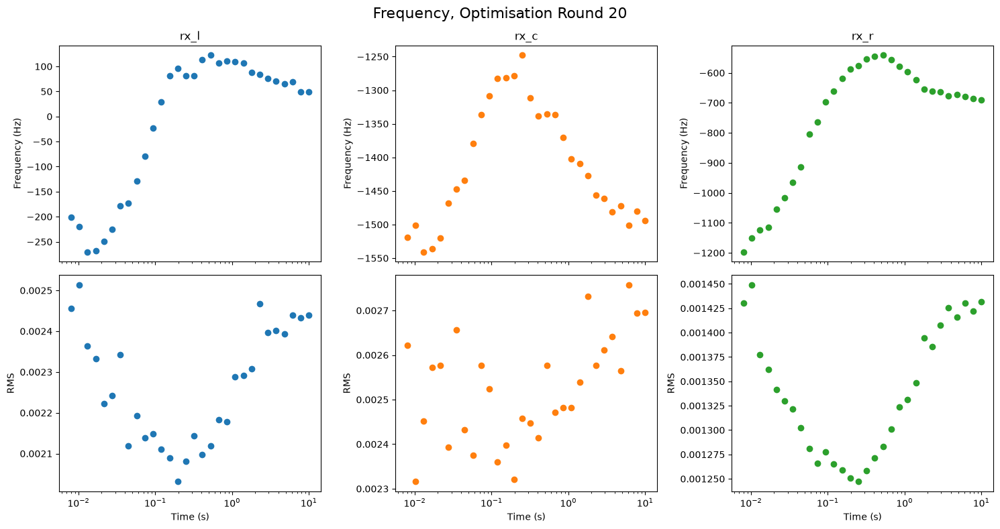

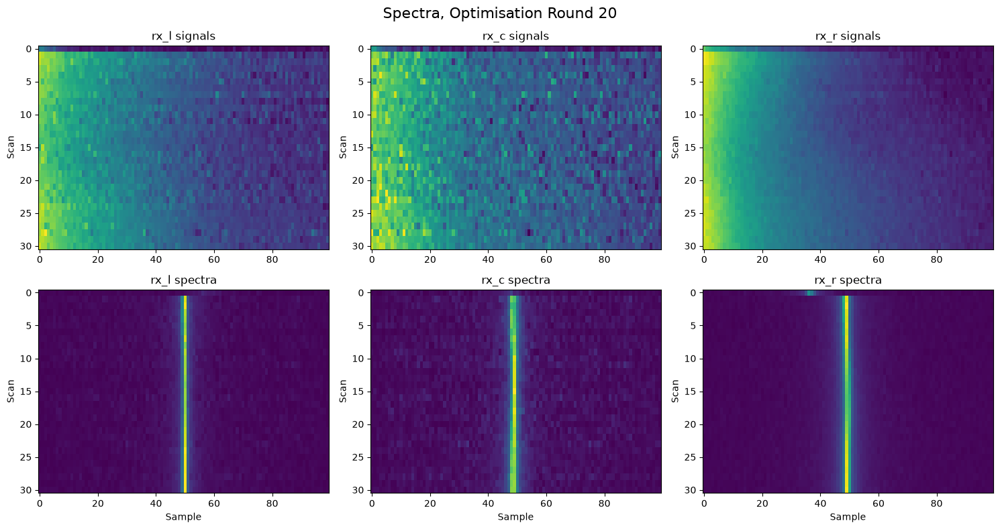

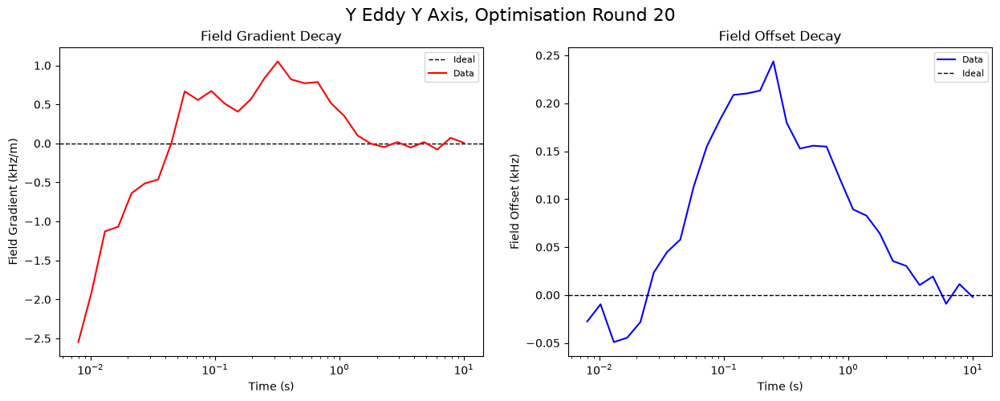

[I 2026-11-25 14:54:12,427] Trial 20 finished with value: 1186.13394578388 and parameters: {'Y_A1': 0.06652782504080493, 'Y_A2': 0.13622572158710286, 'Y_A3': 0.09090100786294465, 'Y_A4': -1.9110684657186576e-11}. Best is trial 19 with value: 974.8585701818189.


max |E| = 9955.02248875562
mean |E| = 7398.134266200231
RMS E = 7441.861596221964
Total cost = 1.186e+03
E max = 0.1362781588441405
E nanmax = 0.1362781588441405
E contains nan = False
B max = 0.26492929904527585
B nanmax = 0.26492929904527585
B contains nan = False
Trial 21


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26492929904527585 !!!!!!!!!!!!!!!!


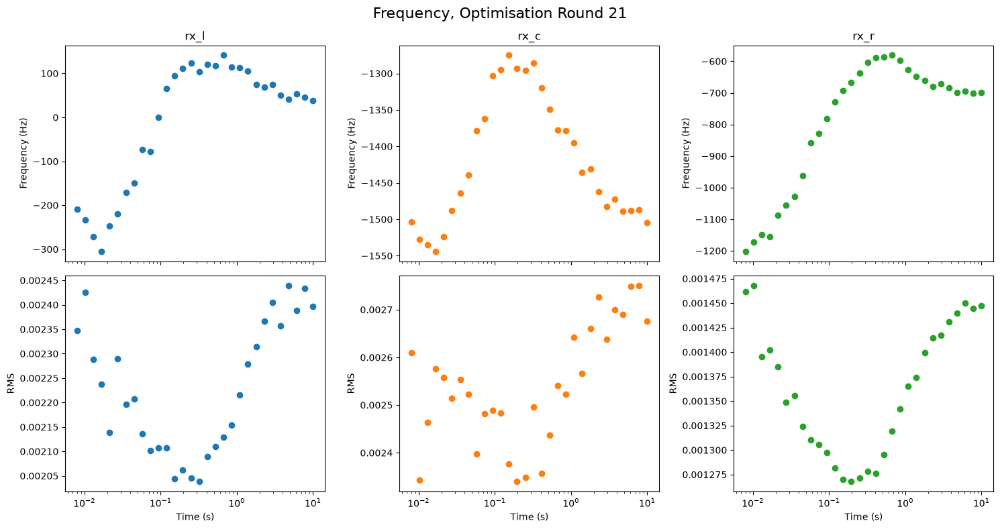

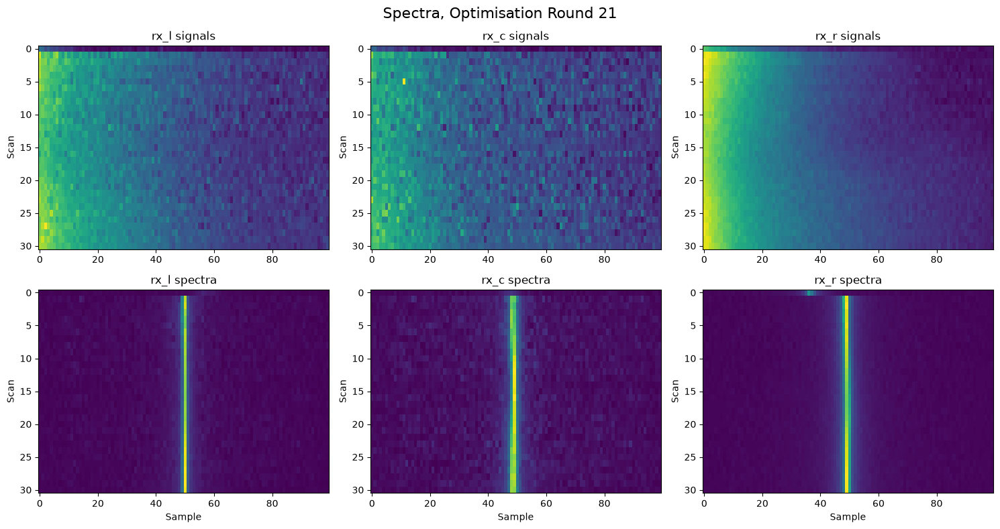

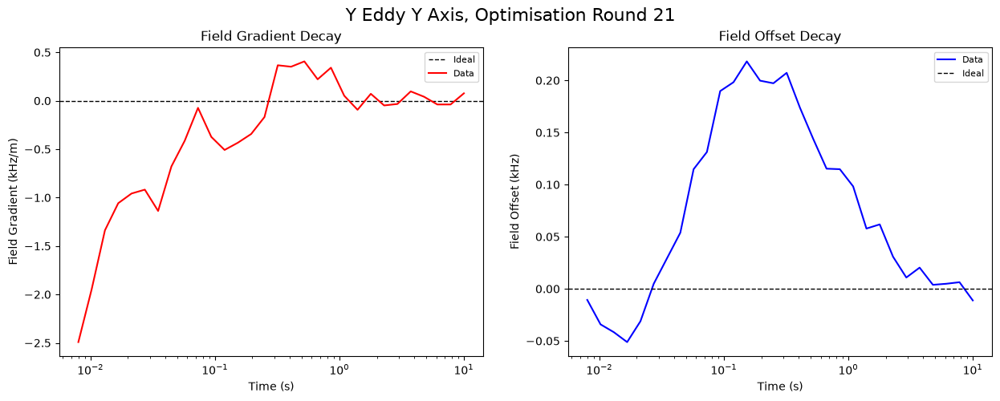

[I 2026-11-25 14:55:35,476] Trial 21 finished with value: 831.9737550062971 and parameters: {'Y_A1': 0.06808841520347166, 'Y_A2': 0.12919432056585223, 'Y_A3': 0.09891671251708717, 'Y_A4': -2.75569185105376e-10}. Best is trial 21 with value: 831.9737550062971.


max |E| = 9935.032483758117
mean |E| = 7811.760786273528
RMS E = 7841.31855526091
Total cost = 8.320e+02
E max = 0.13804039170679447
E nanmax = 0.13804039170679447
E contains nan = False
B max = 0.2683552202146617
B nanmax = 0.2683552202146617
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2683552202146617 !!!!!!!!!!!!!!!!


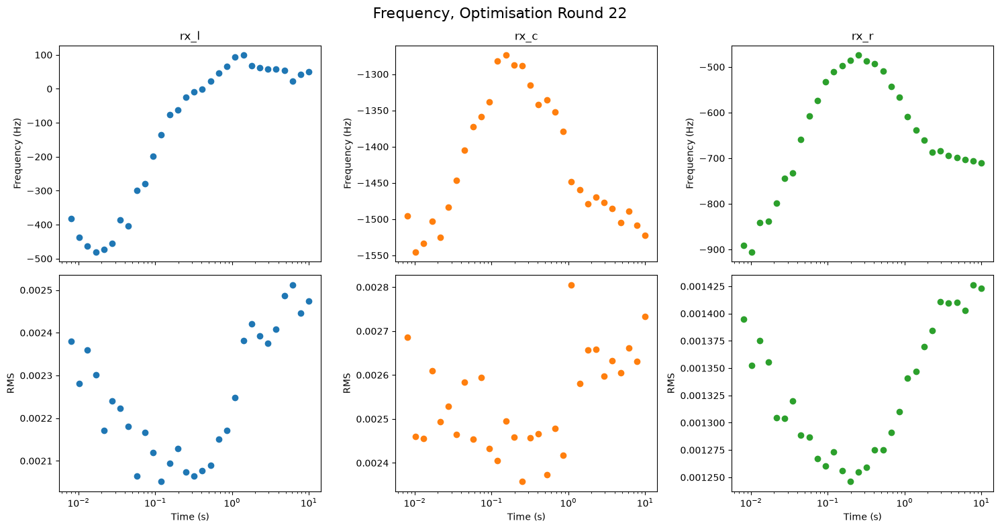

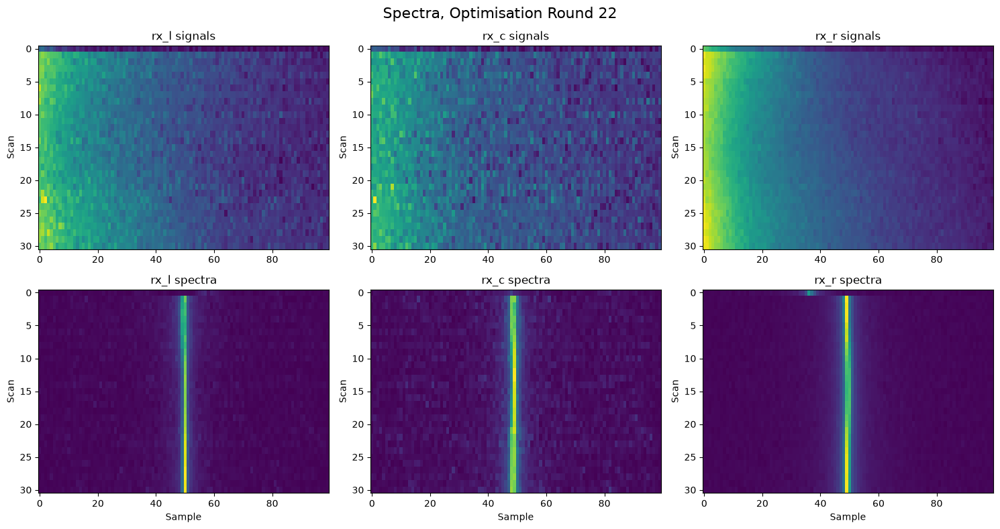

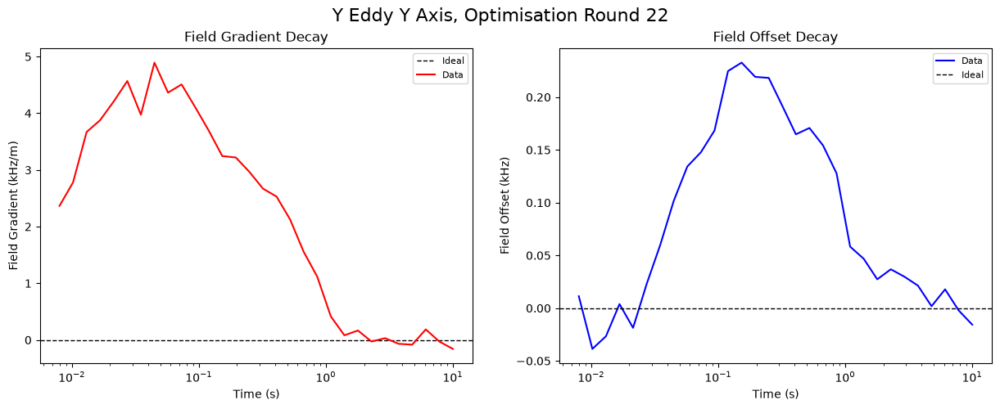

[I 2026-11-25 14:56:24,984] Trial 22 finished with value: 3161.897400120335 and parameters: {'Y_A1': 0.05121245781082987, 'Y_A2': 0.15306925469762006, 'Y_A3': 0.1010473607477158, 'Y_A4': 3.185242575094848e-10}. Best is trial 21 with value: 831.9737550062971.


max |E| = 7611.194402798599
mean |E| = 5220.722971847408
RMS E = 5507.591323596462
Total cost = 3.162e+03
E max = 0.13906954227155757
E nanmax = 0.13906954227155757
E contains nan = False
B max = 0.2703558626737177
B nanmax = 0.2703558626737177
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2703558626737177 !!!!!!!!!!!!!!!!


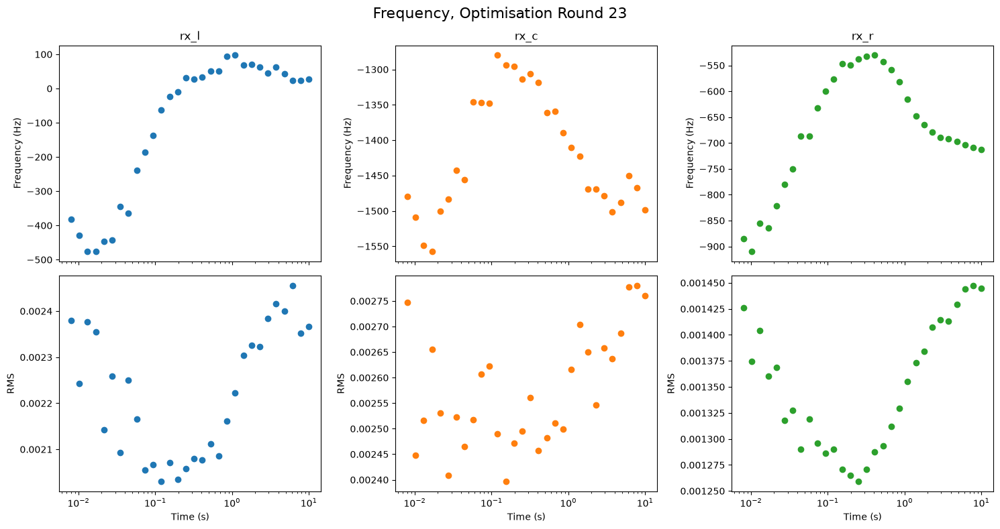

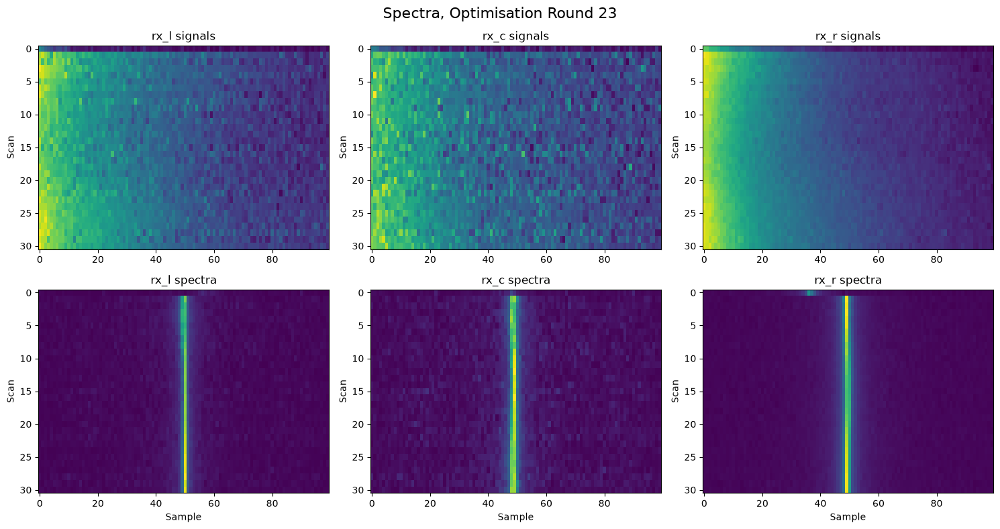

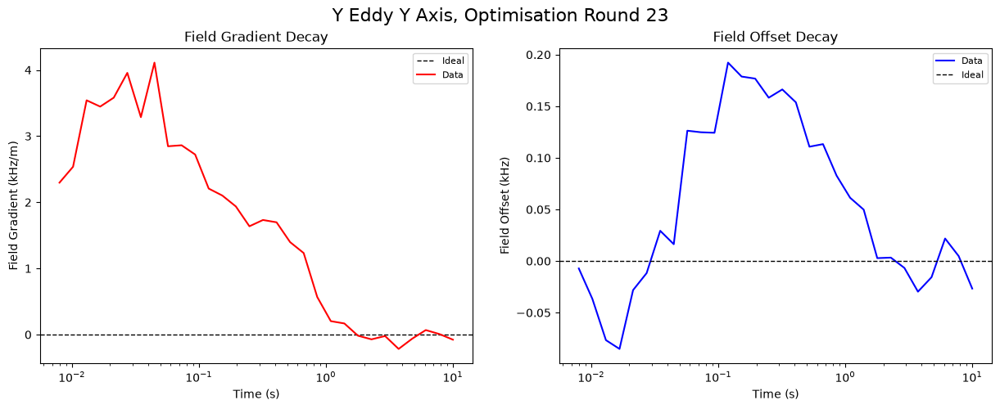

[I 2026-11-25 14:57:13,426] Trial 23 finished with value: 2124.3274082120856 and parameters: {'Y_A1': 0.06206986196999199, 'Y_A2': 0.1447603977522786, 'Y_A3': 0.10655831674237506, 'Y_A4': -8.603769481207353e-10}. Best is trial 21 with value: 831.9737550062971.


max |E| = 7551.2243878060945
mean |E| = 5678.494086290186
RMS E = 5849.896024248459
Total cost = 2.124e+03
E max = 0.1336725791005386
E nanmax = 0.1336725791005386
E contains nan = False
B max = 0.2598640215318048
B nanmax = 0.2598640215318048
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2598640215318048 !!!!!!!!!!!!!!!!


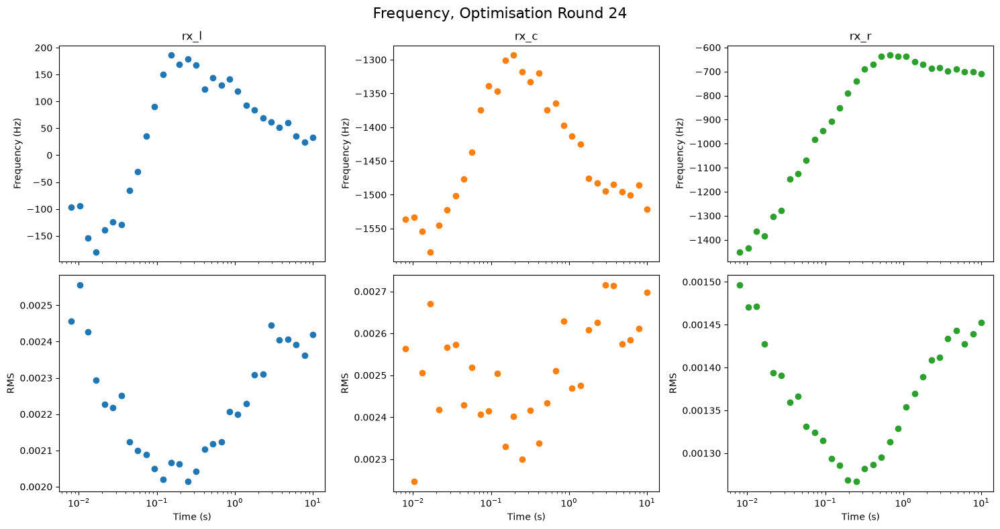

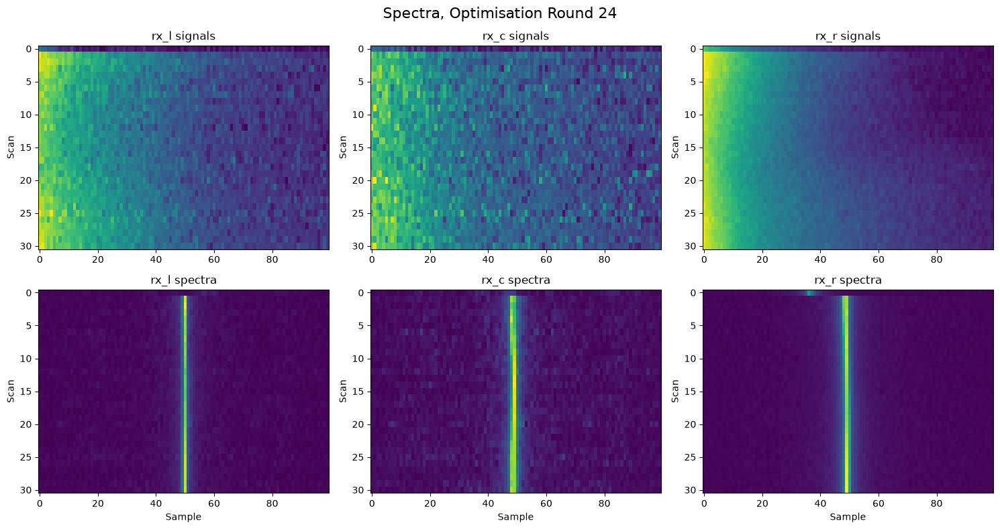

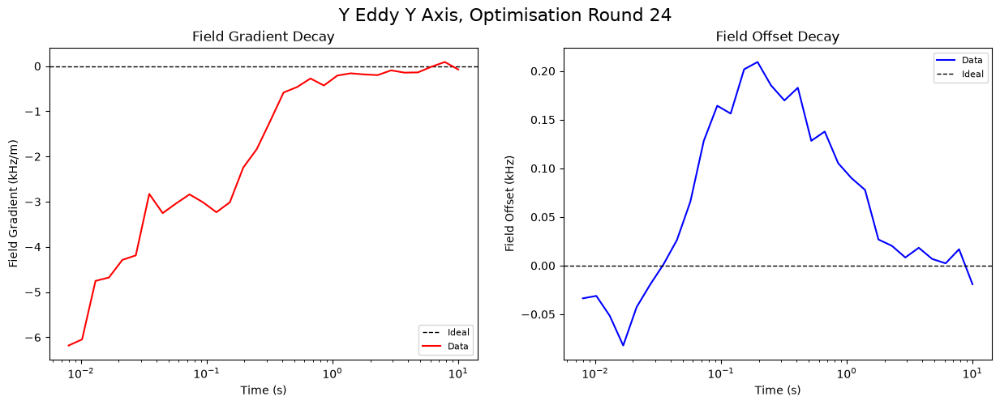

[I 2026-11-25 14:58:01,862] Trial 24 finished with value: 2078.5272143239877 and parameters: {'Y_A1': 0.0557750367932239, 'Y_A2': 0.11616978167949896, 'Y_A3': 0.10628936759987381, 'Y_A4': 1.0276721017114568e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 13533.233383308343
mean |E| = 9336.165250707978
RMS E = 9534.72192480826
Total cost = 2.079e+03
E max = 0.13266859046574034
E nanmax = 0.13266859046574034
E contains nan = False
B max = 0.2579122812396569
B nanmax = 0.2579122812396569
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2579122812396569 !!!!!!!!!!!!!!!!


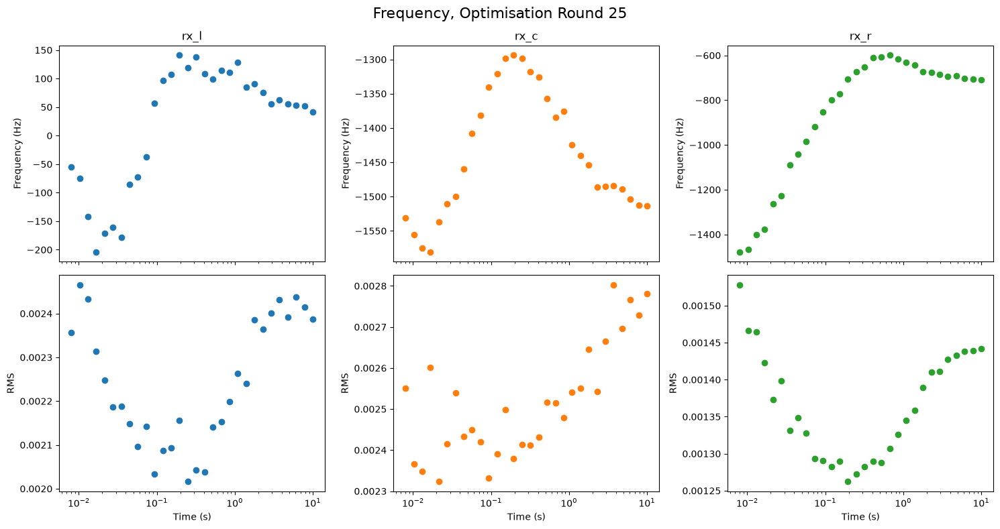

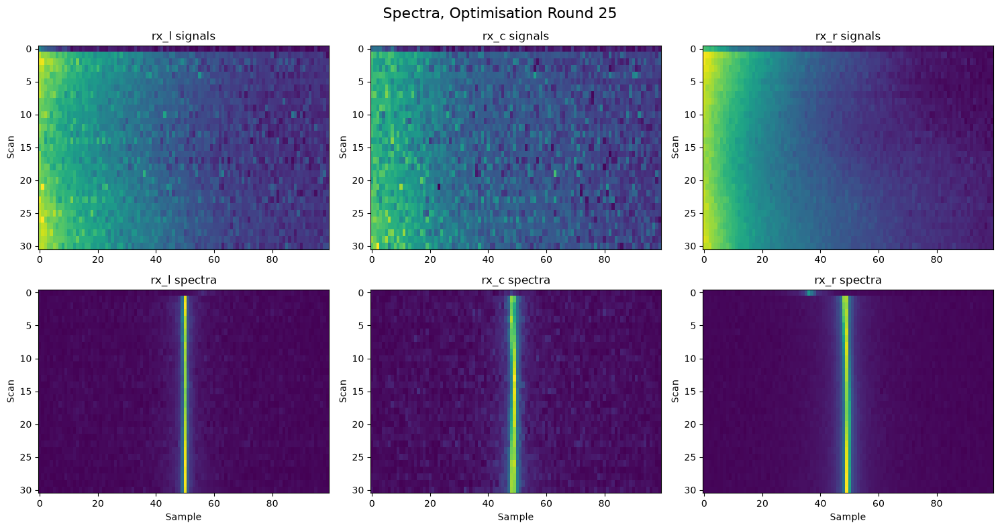

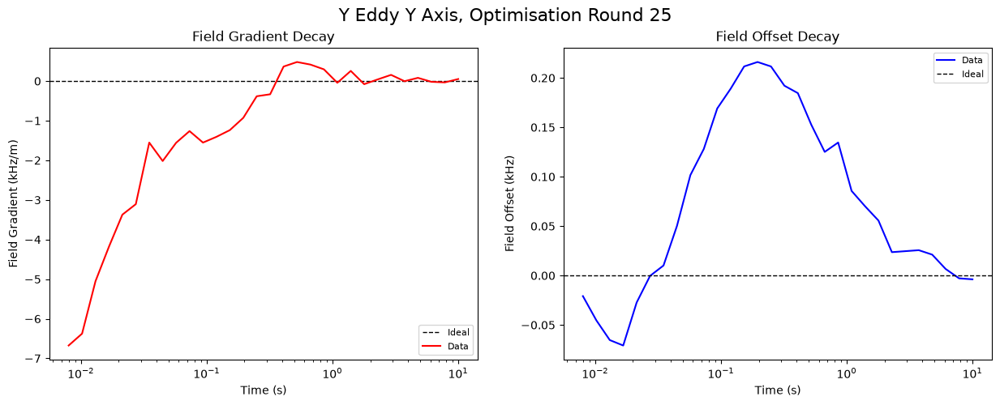

[I 2026-11-25 14:58:50,236] Trial 25 finished with value: 1151.5655183657732 and parameters: {'Y_A1': 0.04747581232350417, 'Y_A2': 0.12439168646275049, 'Y_A3': 0.098646609148696, 'Y_A4': 4.929644213208538e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 14227.88605697151
mean |E| = 8853.573213393302
RMS E = 9070.671273581534
Total cost = 1.152e+03
E max = 0.13396510627484906
E nanmax = 0.13396510627484906
E contains nan = False
B max = 0.2604326459240864
B nanmax = 0.2604326459240864
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2604326459240864 !!!!!!!!!!!!!!!!


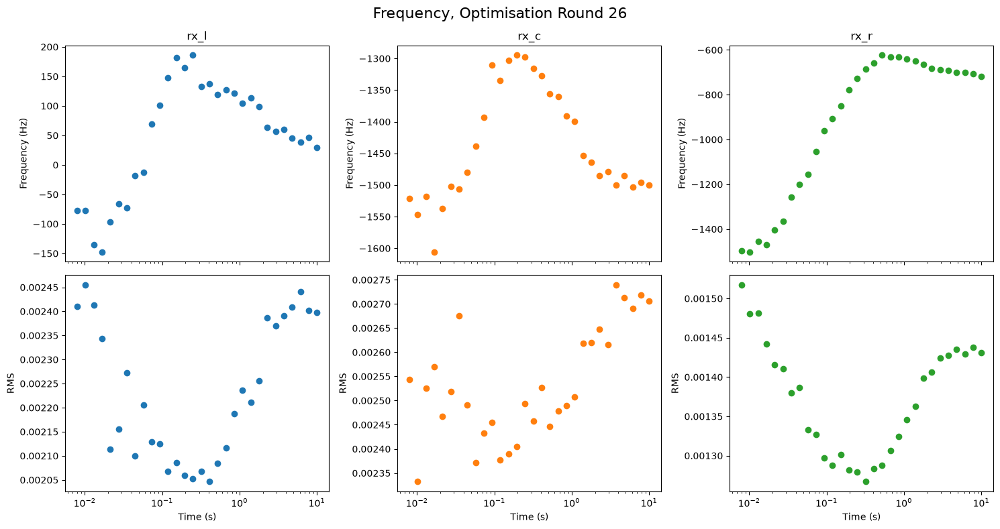

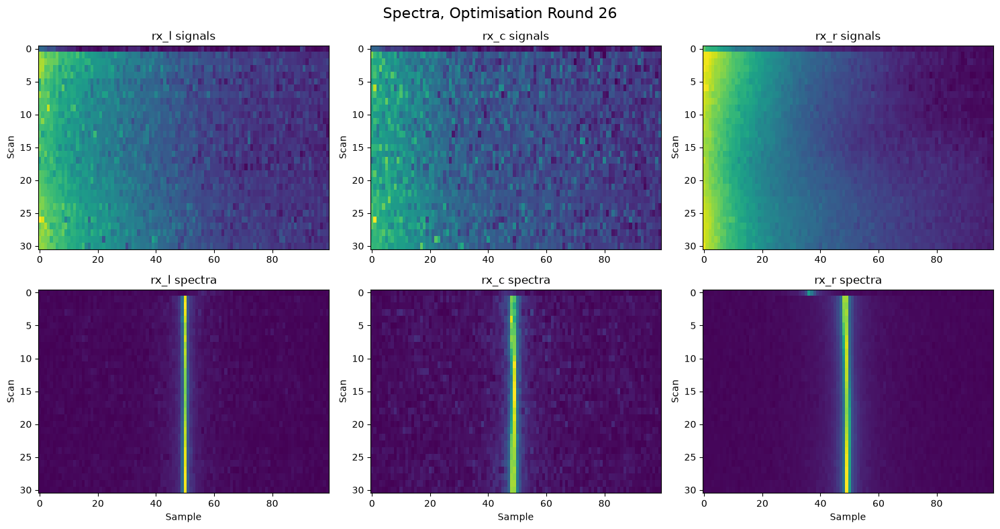

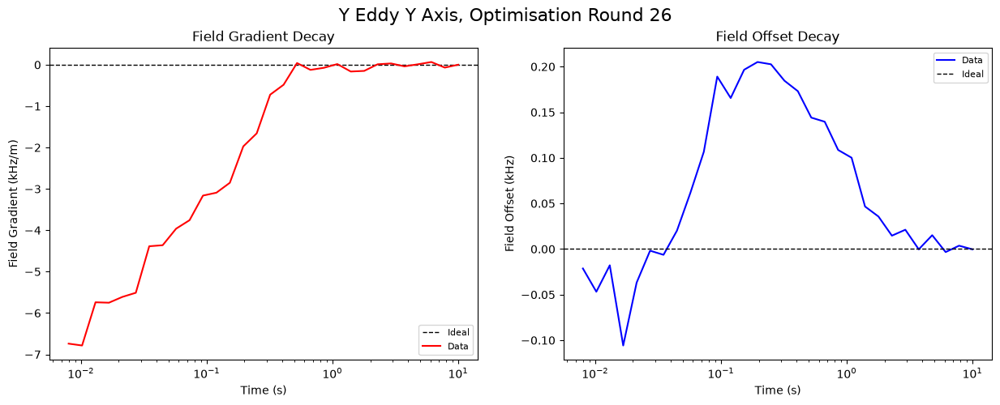

[I 2026-11-25 14:59:39,675] Trial 26 finished with value: 1407.8995222888343 and parameters: {'Y_A1': 0.06993623393509332, 'Y_A2': 0.11824269527393316, 'Y_A3': 0.09295607546309892, 'Y_A4': -1.9048712406329276e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 14252.873563218385
mean |E| = 9700.483091787439
RMS E = 9993.343440518369
Total cost = 1.408e+03
E max = 0.13204371041966212
E nanmax = 0.13204371041966212
E contains nan = False
B max = 0.2566975200290284
B nanmax = 0.2566975200290284
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2566975200290284 !!!!!!!!!!!!!!!!


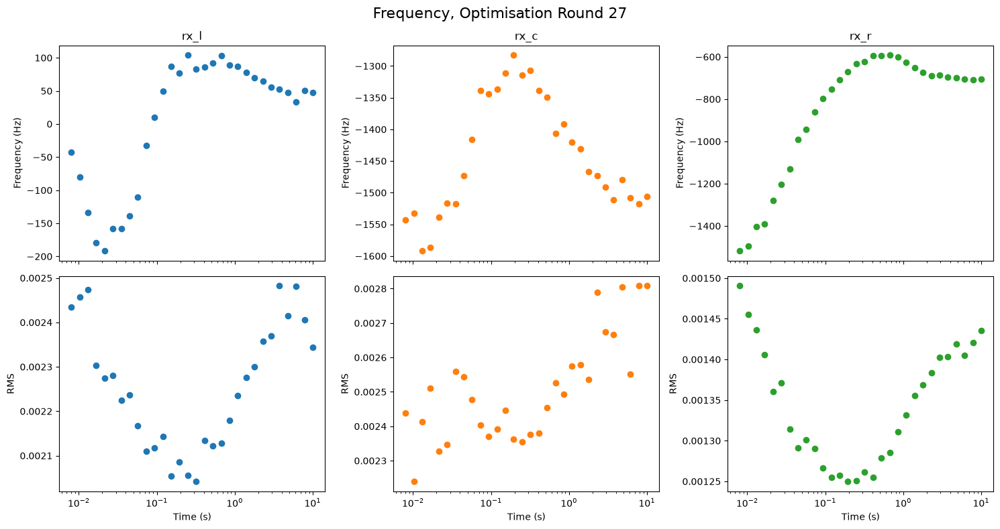

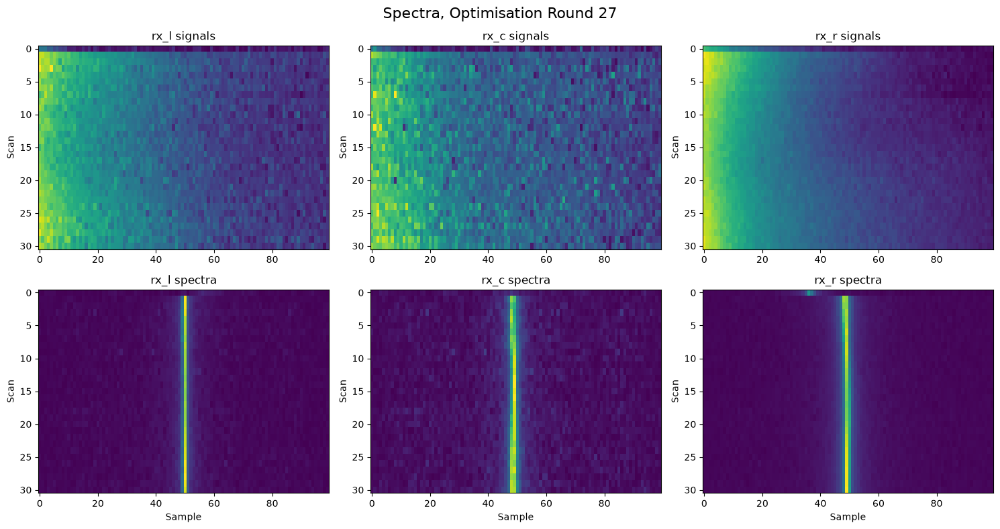

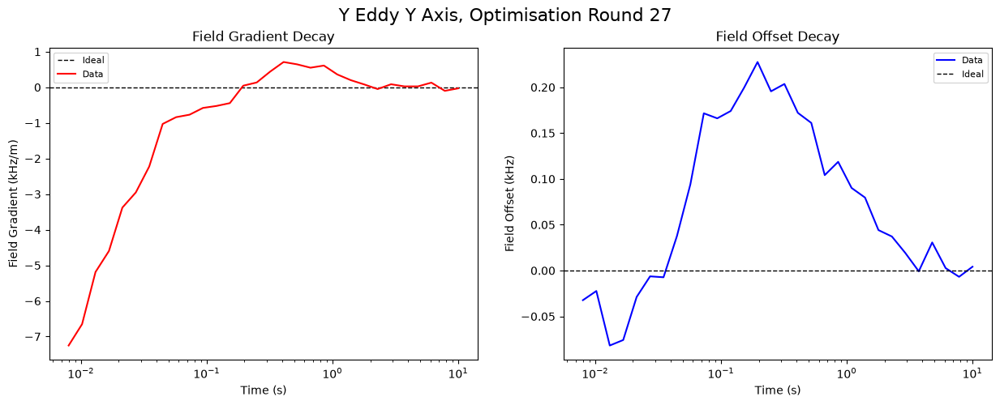

[I 2026-11-25 15:00:28,931] Trial 27 finished with value: 1393.6443958463556 and parameters: {'Y_A1': 0.04302347134434609, 'Y_A2': 0.13011031016667543, 'Y_A3': 0.09247184282547462, 'Y_A4': 1.3641358993008394e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 14757.621189405292
mean |E| = 8592.037314675992
RMS E = 8859.02504350022
Total cost = 1.394e+03
E max = 0.13297046027515208
E nanmax = 0.13297046027515208
E contains nan = False
B max = 0.25849902735071006
B nanmax = 0.25849902735071006
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25849902735071006 !!!!!!!!!!!!!!!!


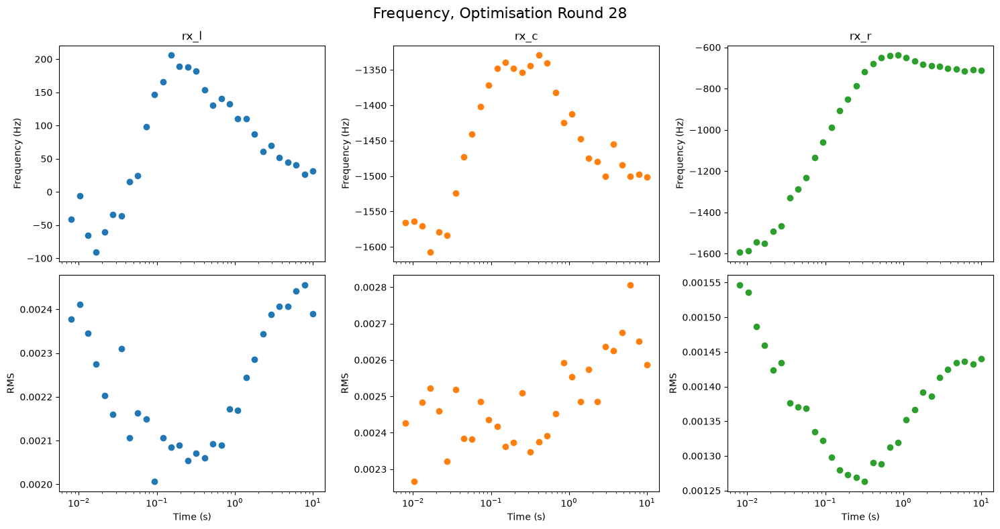

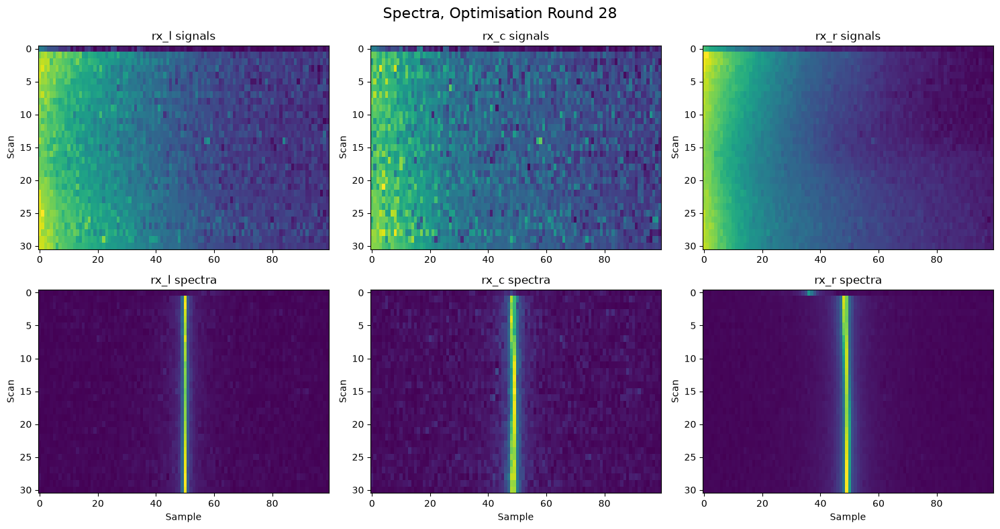

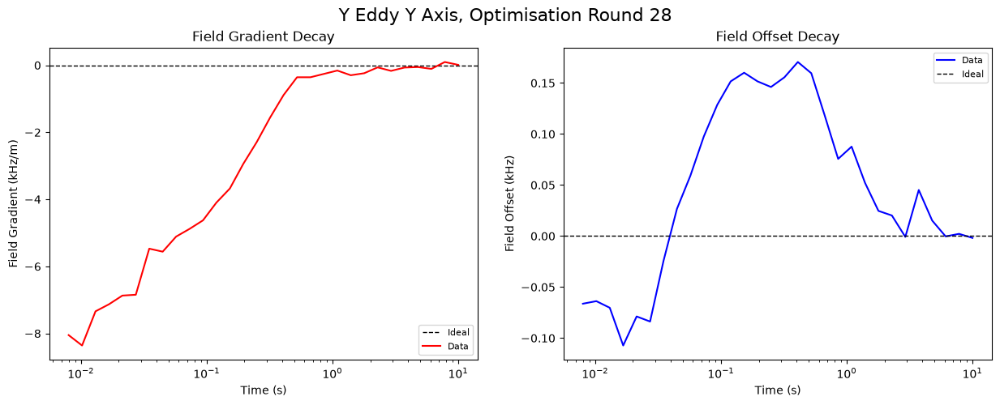

[I 2026-11-25 15:01:18,562] Trial 28 finished with value: 2368.437144438772 and parameters: {'Y_A1': 0.06907130726959099, 'Y_A2': 0.11373712947060911, 'Y_A3': 0.09161420161913511, 'Y_A4': 3.1212744212584823e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 15812.093953023486
mean |E| = 10376.811594202894
RMS E = 10781.86713633387
Total cost = 2.368e+03
E max = 0.13054719557337643
E nanmax = 0.13054719557337643
E contains nan = False
B max = 0.253788200541303
B nanmax = 0.253788200541303
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.253788200541303 !!!!!!!!!!!!!!!!


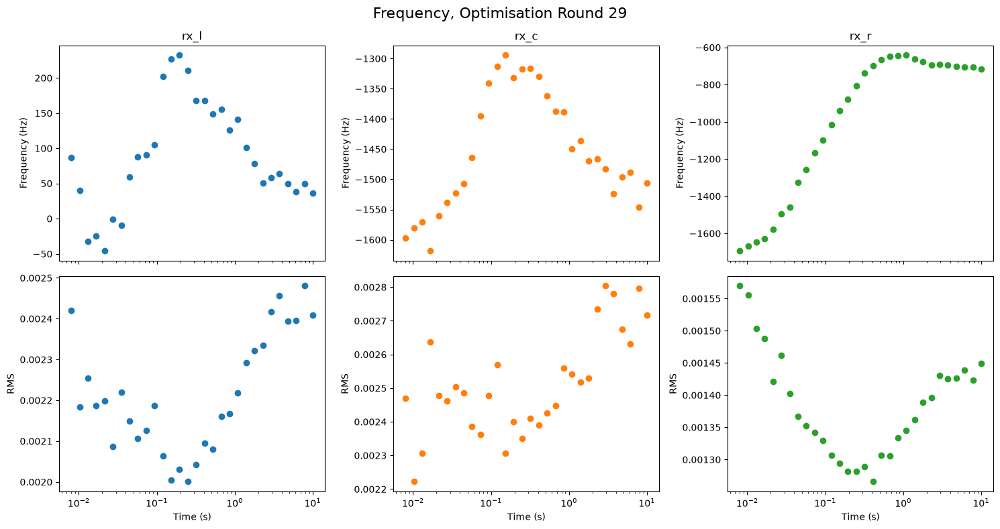

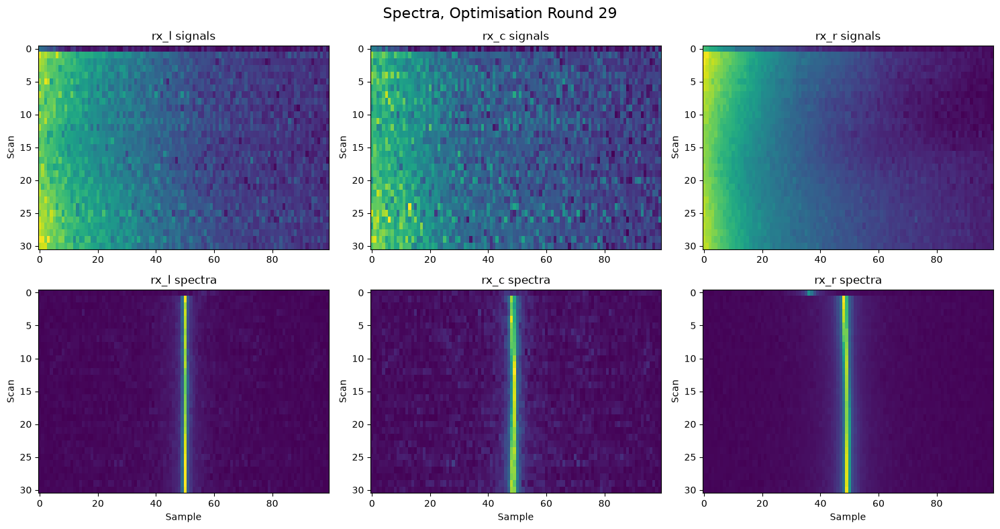

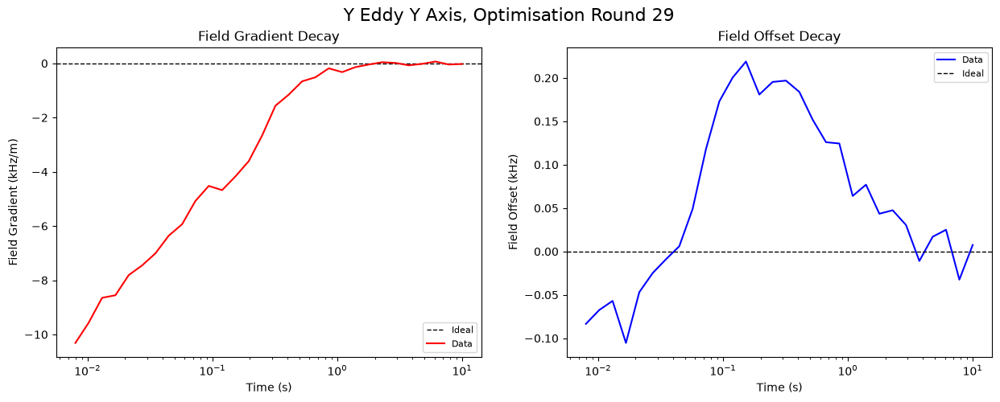

[I 2026-11-25 15:02:07,077] Trial 29 finished with value: 2185.6123388857245 and parameters: {'Y_A1': 0.052382157014682885, 'Y_A2': 0.1107095368365695, 'Y_A3': 0.09354402012525855, 'Y_A4': -1.0321536197243677e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 17816.091954022984
mean |E| = 10868.565717141426
RMS E = 11403.60273484336
Total cost = 2.186e+03
E max = 0.1377918113907939
E nanmax = 0.1377918113907939
E contains nan = False
B max = 0.267871928775992
B nanmax = 0.267871928775992
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.267871928775992 !!!!!!!!!!!!!!!!


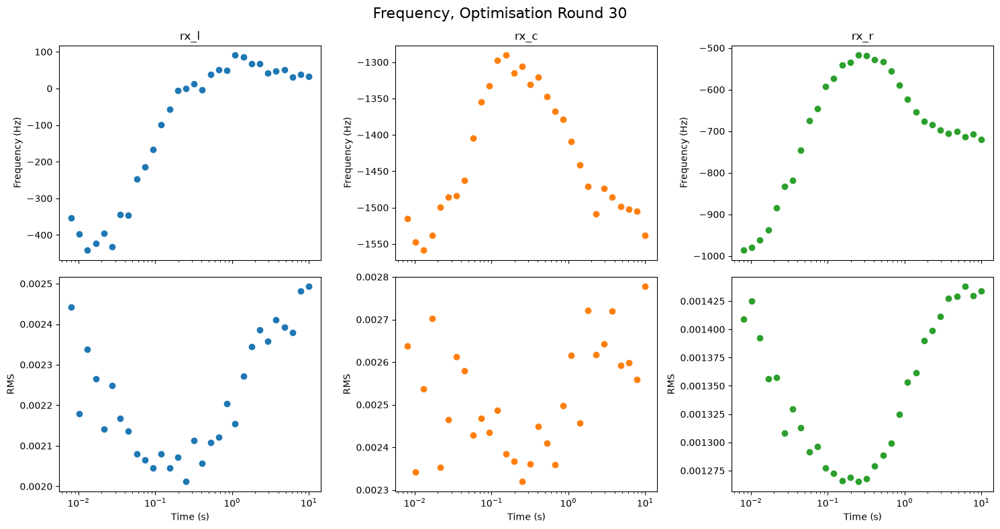

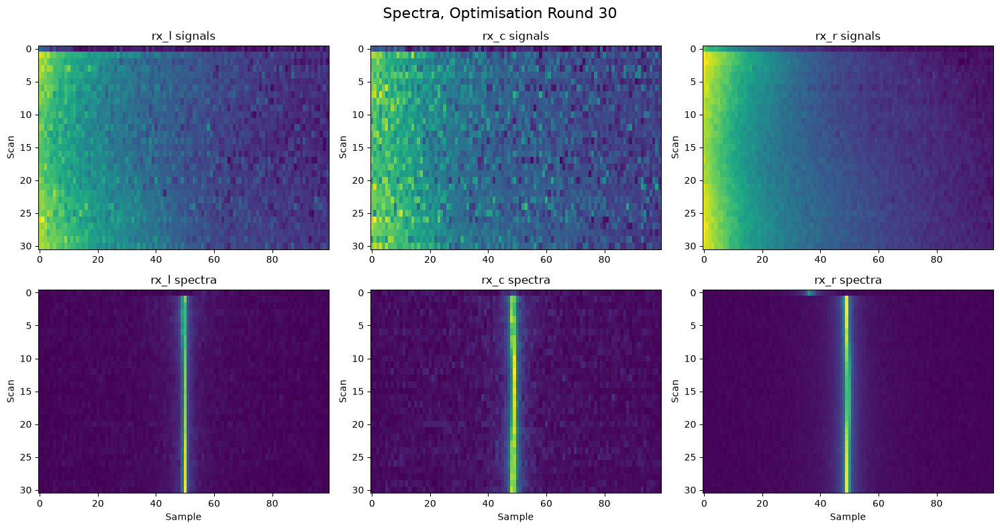

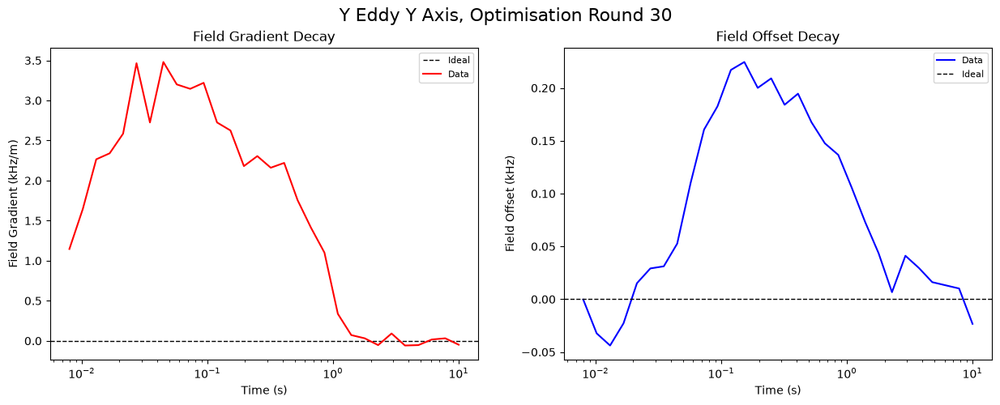

[I 2026-11-25 15:02:55,231] Trial 30 finished with value: 2307.1651378094293 and parameters: {'Y_A1': 0.06092159896936186, 'Y_A2': 0.14875856248065192, 'Y_A3': 0.09502204973205162, 'Y_A4': -1.4150771296713461e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 7531.234382808593
mean |E| = 5870.5647176411785
RMS E = 6001.819306917002
Total cost = 2.307e+03
E max = 0.1334346269251575
E nanmax = 0.1334346269251575
E contains nan = False
B max = 0.25940148587962986
B nanmax = 0.25940148587962986
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25940148587962986 !!!!!!!!!!!!!!!!


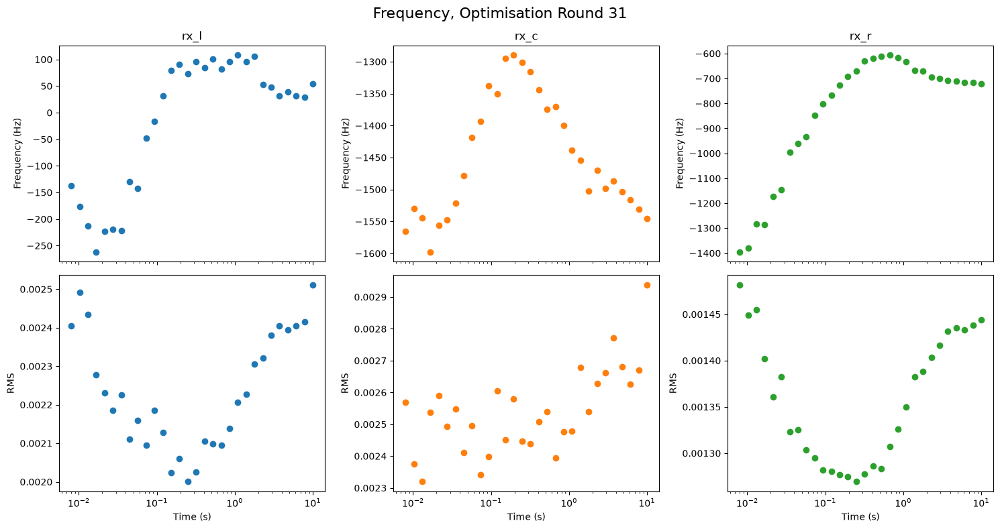

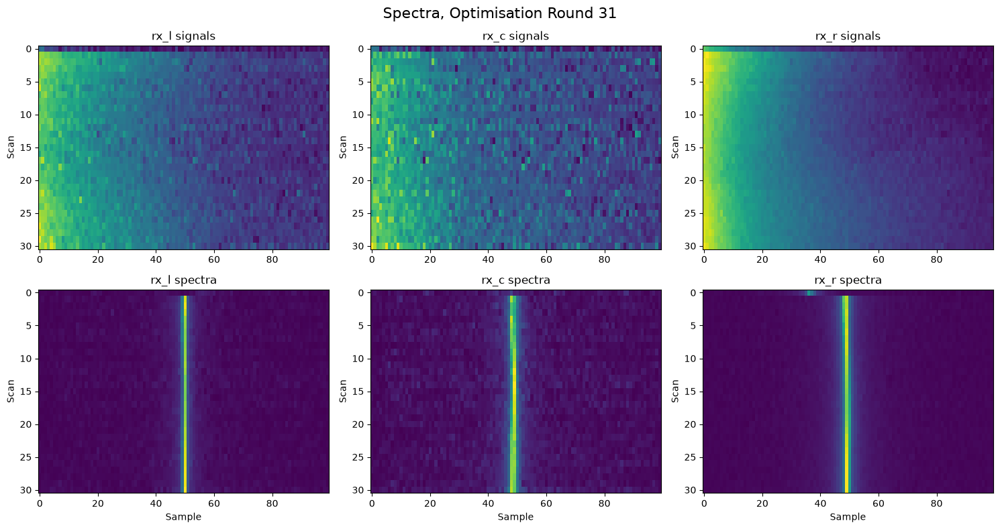

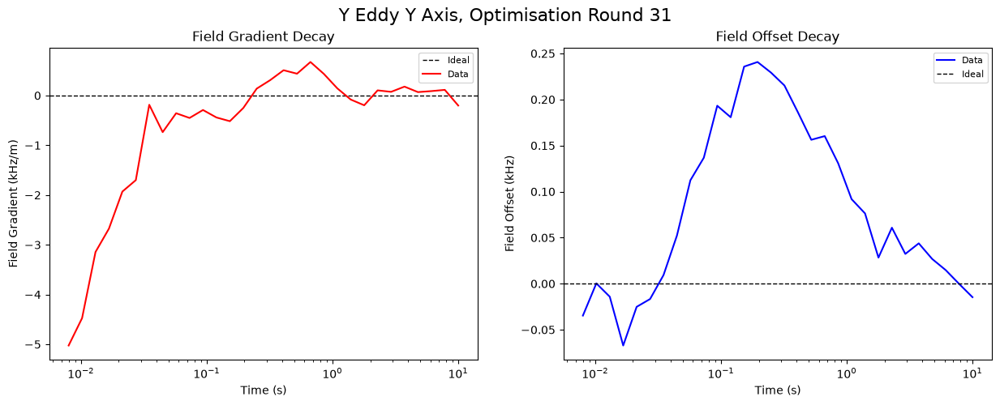

[I 2026-11-25 15:03:44,349] Trial 31 finished with value: 1567.33760192393 and parameters: {'Y_A1': 0.04606088482443192, 'Y_A2': 0.12810318510306584, 'Y_A3': 0.10131584613648094, 'Y_A4': 1.9184515748807423e-10}. Best is trial 21 with value: 831.9737550062971.


max |E| = 12583.708145927034
mean |E| = 8206.06363484924
RMS E = 8325.621250201444
Total cost = 1.567e+03
E max = 0.1361313249394768
E nanmax = 0.1361313249394768
E contains nan = False
B max = 0.2646439416621717
B nanmax = 0.2646439416621717
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2646439416621717 !!!!!!!!!!!!!!!!


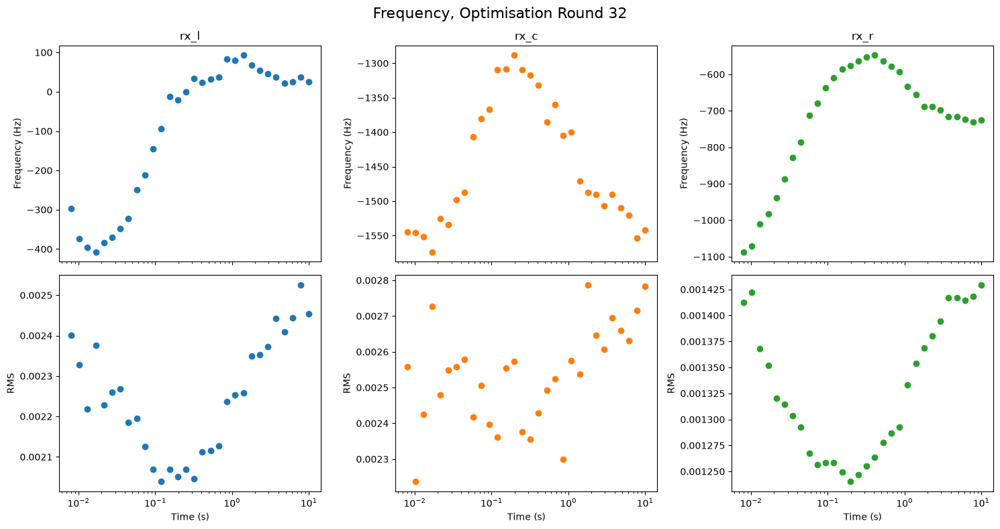

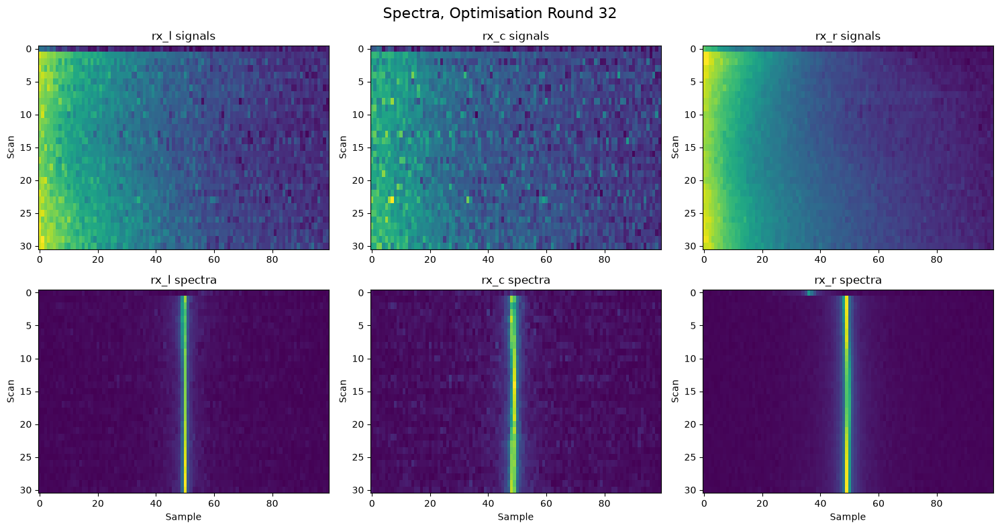

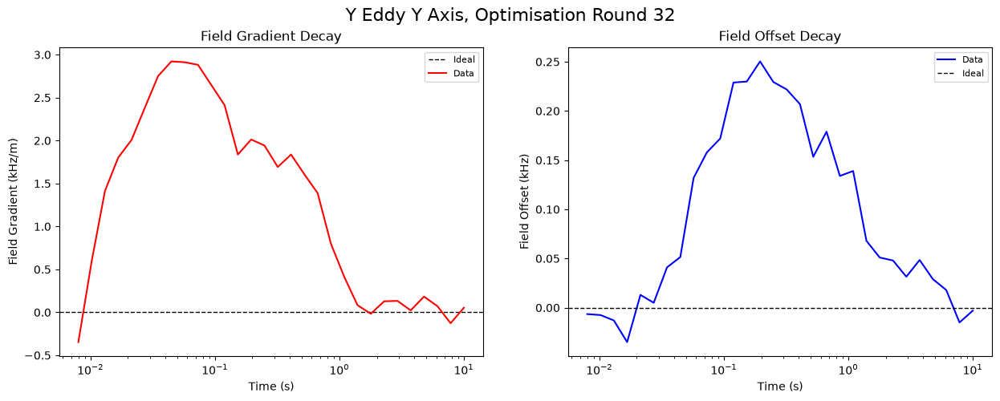

[I 2026-11-25 15:04:32,149] Trial 32 finished with value: 2515.1693813185875 and parameters: {'Y_A1': 0.04932156172549325, 'Y_A2': 0.1438026082244243, 'Y_A3': 0.10001374568603547, 'Y_A4': 8.348005996868877e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 7906.046976511743
mean |E| = 6278.194236215224
RMS E = 6369.748777653482
Total cost = 2.515e+03
E max = 0.13239912037926901
E nanmax = 0.13239912037926901
E contains nan = False
B max = 0.2573884121020852
B nanmax = 0.2573884121020852
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2573884121020852 !!!!!!!!!!!!!!!!


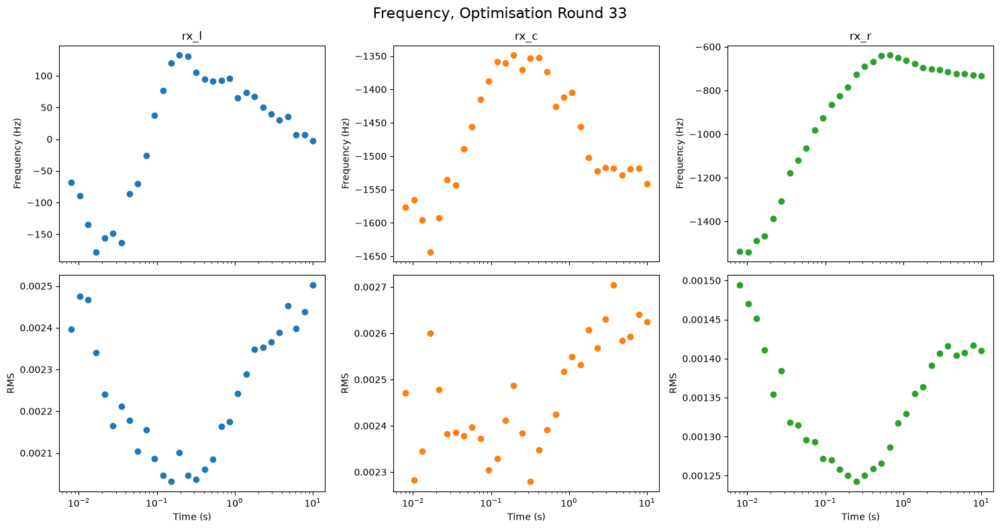

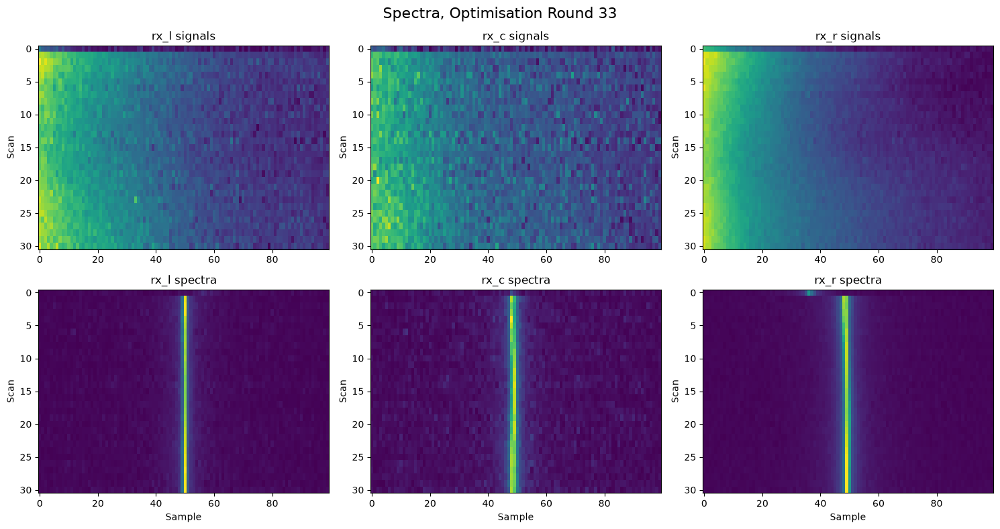

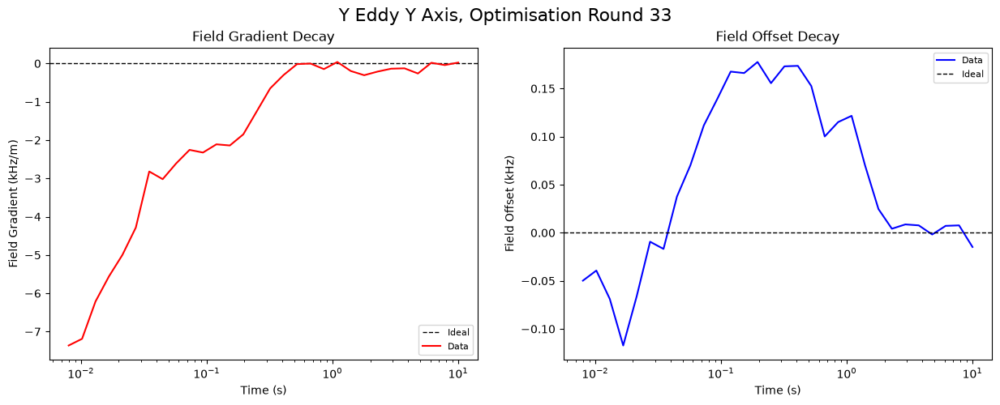

[I 2026-11-25 15:05:19,829] Trial 33 finished with value: 1739.841262108891 and parameters: {'Y_A1': 0.04981096511204987, 'Y_A2': 0.12133015577064911, 'Y_A3': 0.09782008081906898, 'Y_A4': 4.579645979348916e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 14677.661169415289
mean |E| = 9258.370814592701
RMS E = 9532.677064532658
Total cost = 1.740e+03
E max = 0.13407575555296572
E nanmax = 0.13407575555296572
E contains nan = False
B max = 0.26064778370011005
B nanmax = 0.26064778370011005
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26064778370011005 !!!!!!!!!!!!!!!!


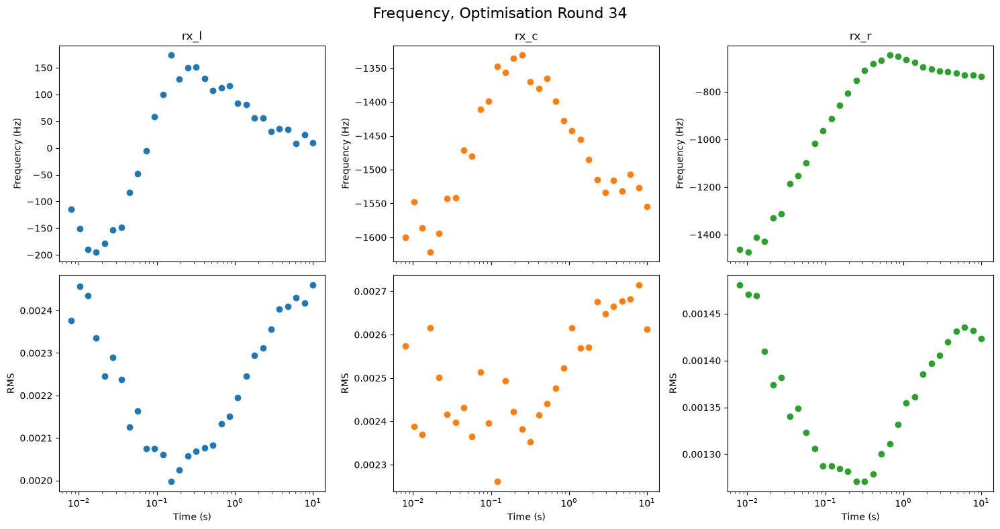

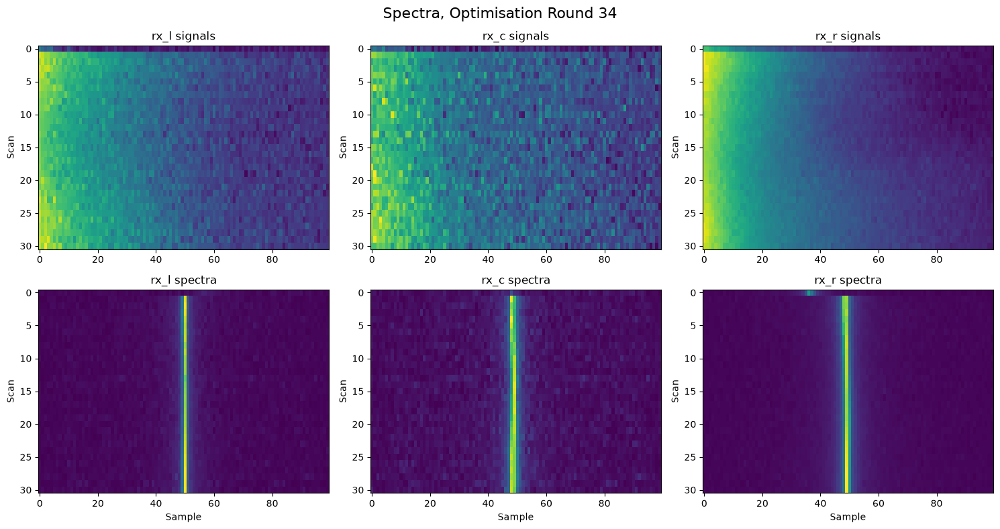

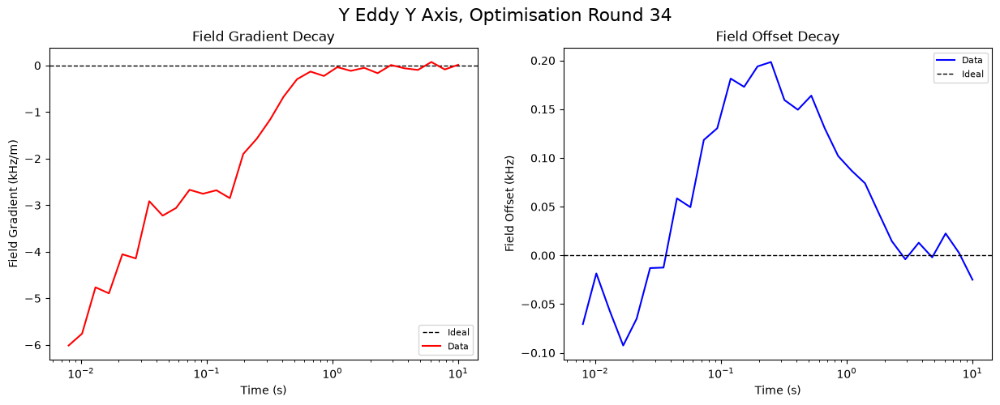

[I 2026-11-25 15:06:07,599] Trial 34 finished with value: 1611.3286225027264 and parameters: {'Y_A1': 0.06196869920798478, 'Y_A2': 0.11786379455782392, 'Y_A3': 0.10156066772838862, 'Y_A4': -3.230107707543547e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 13468.265867066462
mean |E| = 9330.334832583703
RMS E = 9525.611531058808
Total cost = 1.611e+03
E max = 0.13207408423150438
E nanmax = 0.13207408423150438
E contains nan = False
B max = 0.25675656321864093
B nanmax = 0.25675656321864093
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25675656321864093 !!!!!!!!!!!!!!!!


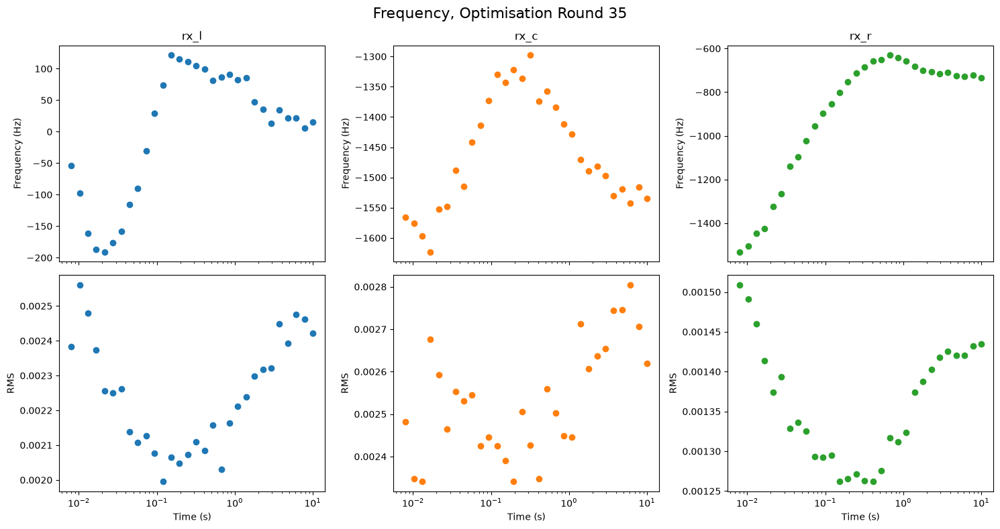

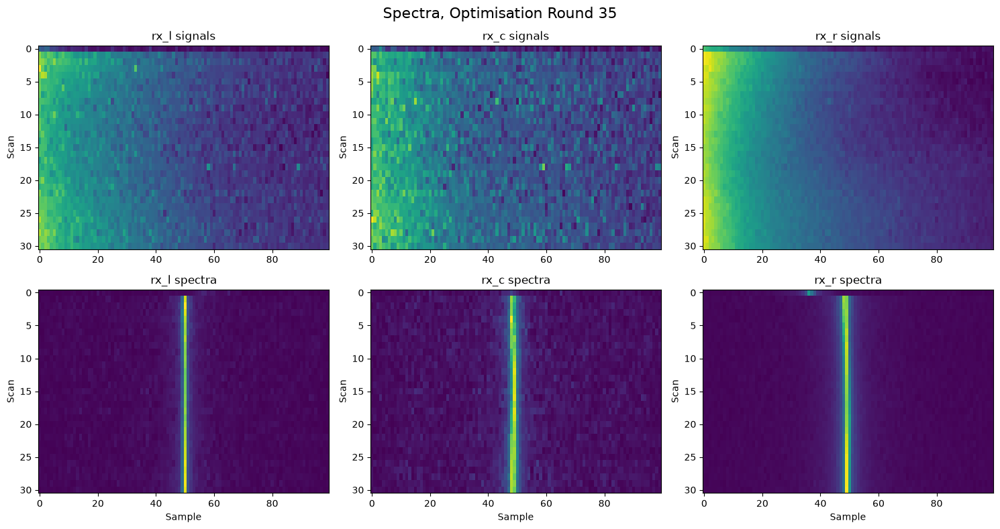

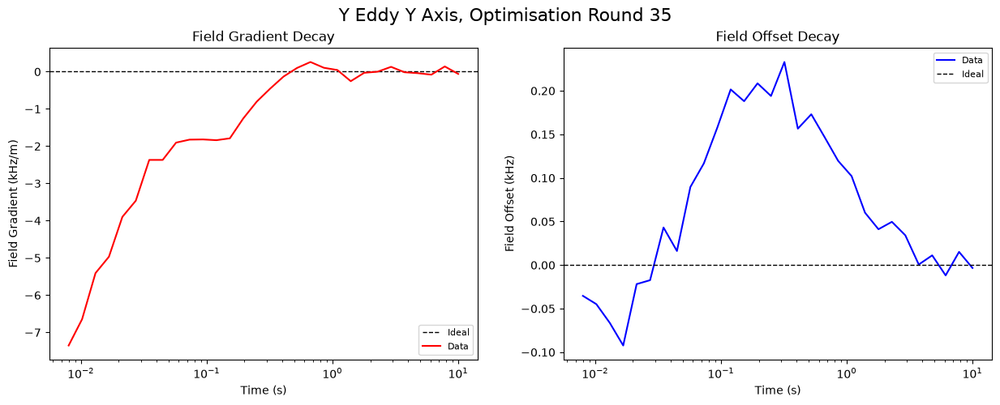

[I 2026-11-25 15:06:55,408] Trial 35 finished with value: 1346.682228284433 and parameters: {'Y_A1': 0.04221826683881784, 'Y_A2': 0.12201158355399316, 'Y_A3': 0.10183756201465782, 'Y_A4': 6.049448145397435e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 14782.60869565217
mean |E| = 9030.984507746123
RMS E = 9273.672950334065
Total cost = 1.347e+03
E max = 0.13271362524239289
E nanmax = 0.13271362524239289
E contains nan = False
B max = 0.2579997651395968
B nanmax = 0.2579997651395968
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2579997651395968 !!!!!!!!!!!!!!!!


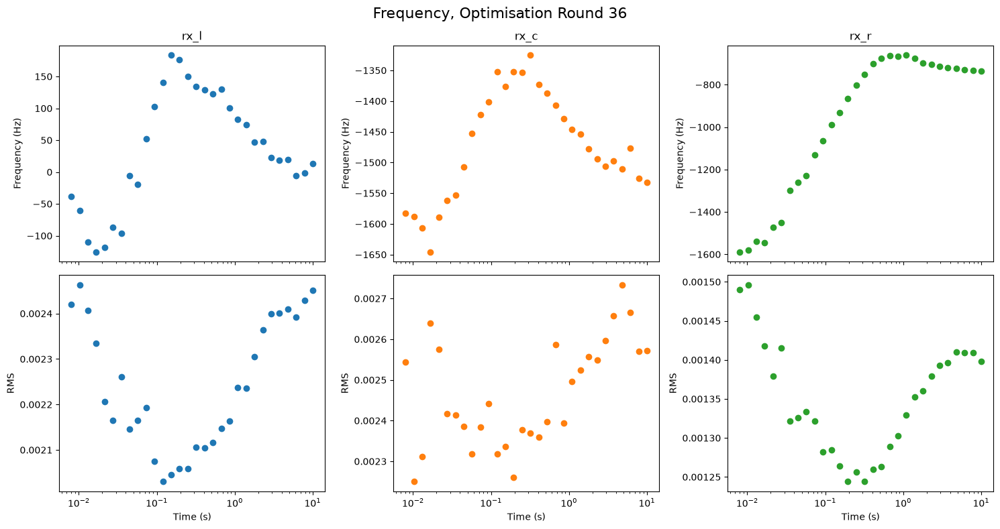

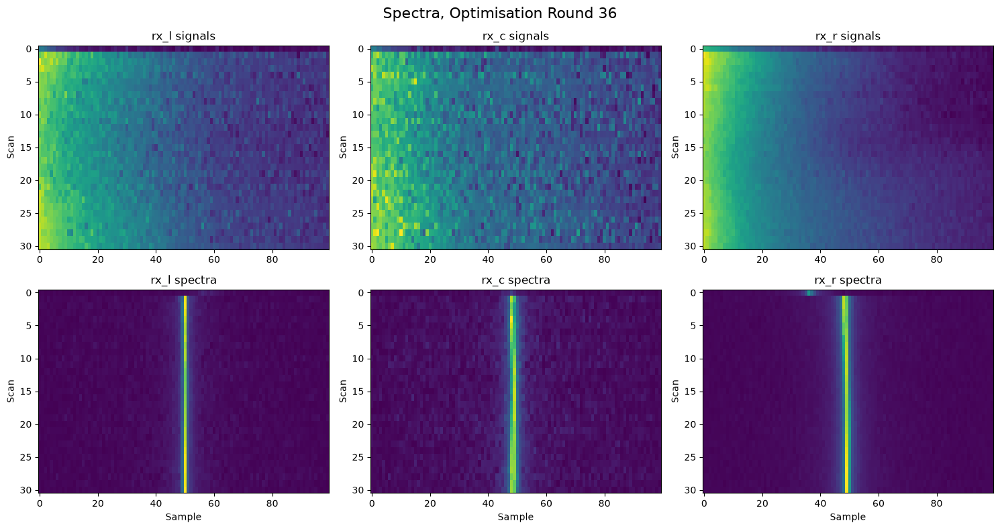

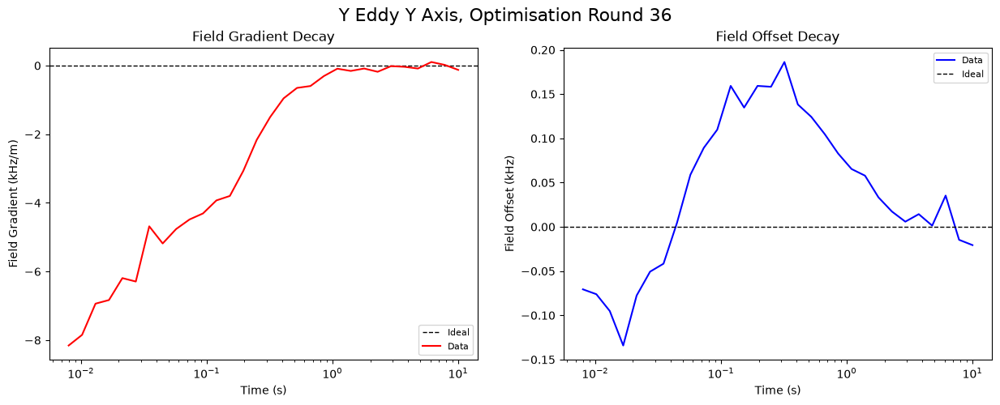

[I 2026-11-25 15:07:43,159] Trial 36 finished with value: 2208.4764604824363 and parameters: {'Y_A1': 0.0609940043654772, 'Y_A2': 0.11240773877966509, 'Y_A3': 0.09879270252172587, 'Y_A4': 2.4066423706609937e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 15507.24637681159
mean |E| = 10127.26969848409
RMS E = 10495.510947274144
Total cost = 2.208e+03
E max = 0.13621865395595698
E nanmax = 0.13621865395595698
E contains nan = False
B max = 0.26481365225297515
B nanmax = 0.26481365225297515
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26481365225297515 !!!!!!!!!!!!!!!!


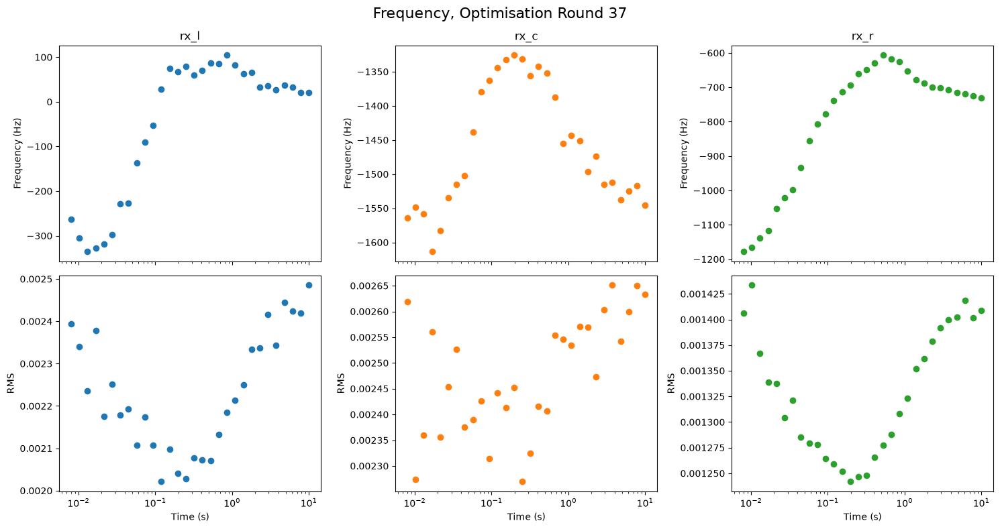

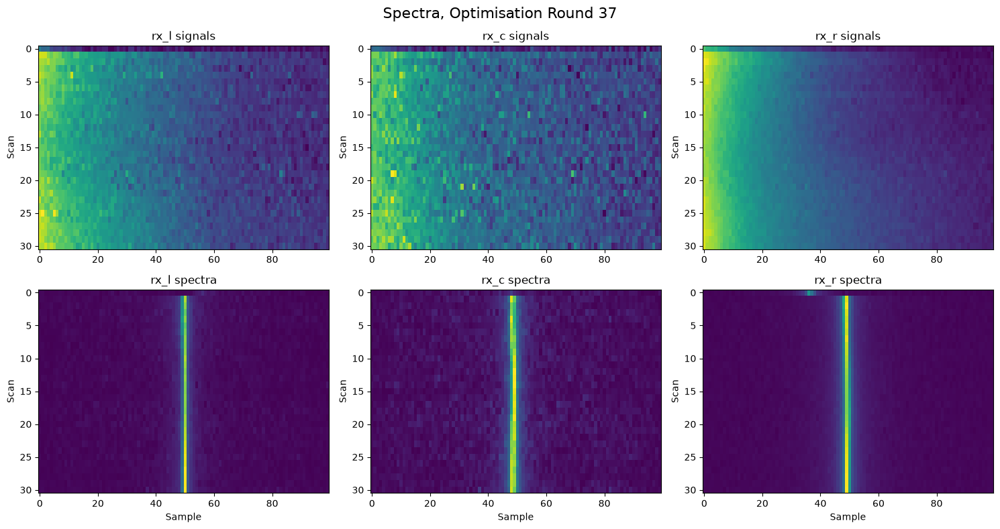

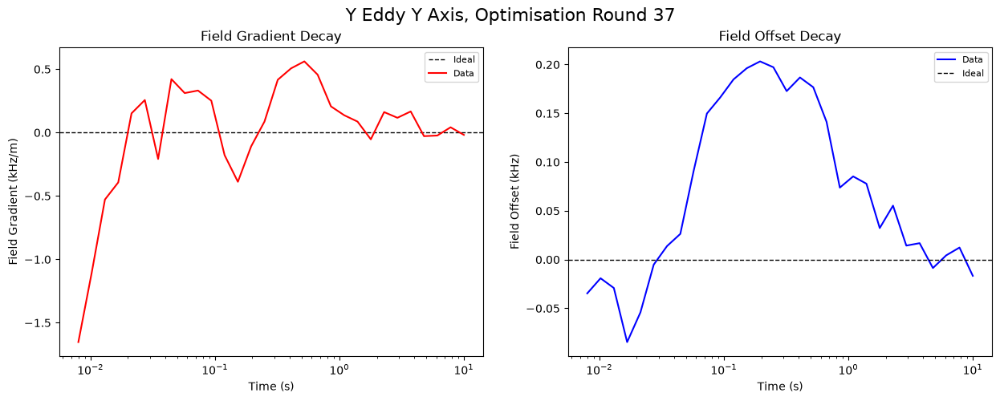

[I 2026-11-25 15:08:31,228] Trial 37 finished with value: 933.2078952650246 and parameters: {'Y_A1': 0.0604215604352092, 'Y_A2': 0.12936536701142246, 'Y_A3': 0.10547443963304738, 'Y_A4': 1.9411555238270473e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 9150.424787606195
mean |E| = 7498.584041312675
RMS E = 7512.50467536655
Total cost = 9.332e+02
E max = 0.13651578184321853
E nanmax = 0.13651578184321853
E contains nan = False
B max = 0.2653912672294277
B nanmax = 0.2653912672294277
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2653912672294277 !!!!!!!!!!!!!!!!


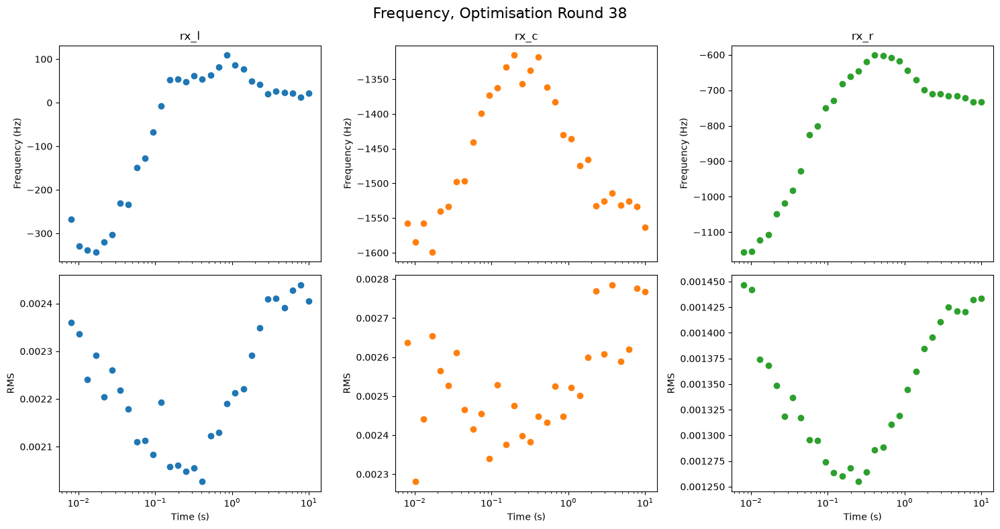

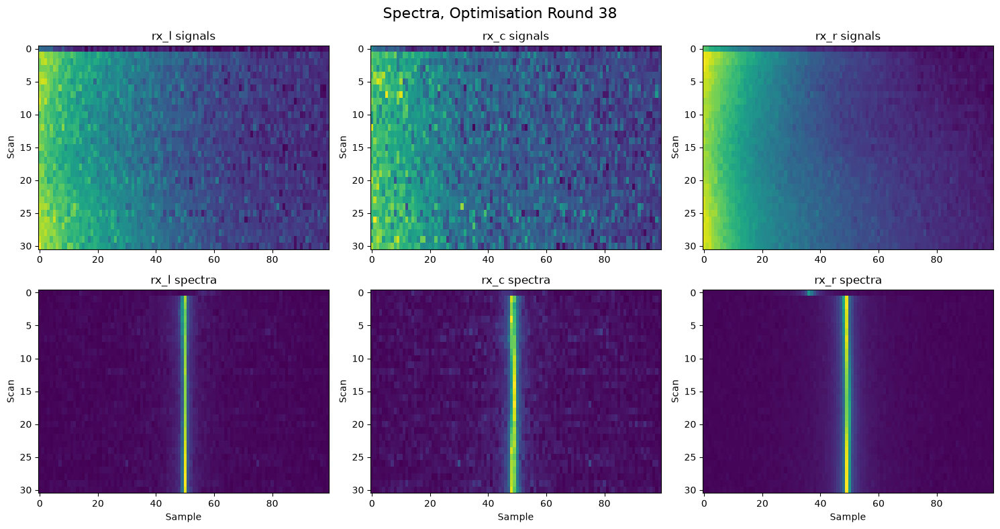

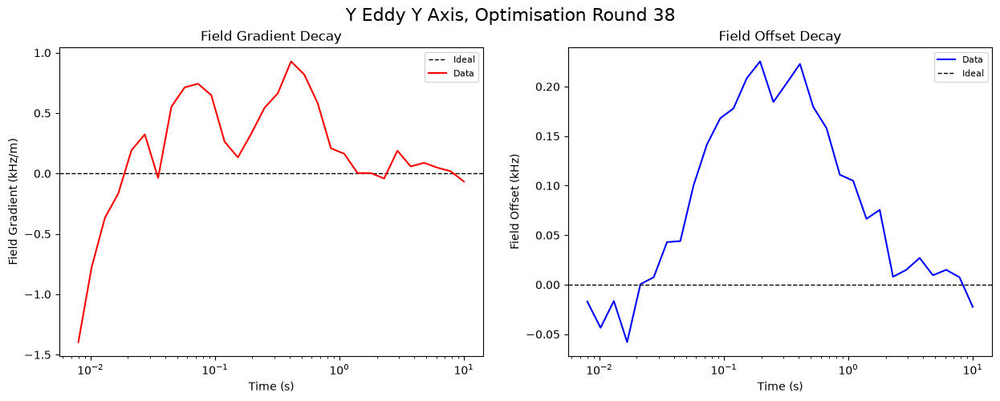

[I 2026-11-25 15:09:19,919] Trial 38 finished with value: 1058.6173141679437 and parameters: {'Y_A1': 0.06360762335286312, 'Y_A2': 0.13330231813515891, 'Y_A3': 0.10039825573695456, 'Y_A4': -3.0597044530046697e-09}. Best is trial 21 with value: 831.9737550062971.


max |E| = 8875.56221889055
mean |E| = 7300.849575212391
RMS E = 7315.920750179225
Total cost = 1.059e+03
E max = 0.13440569512513179
E nanmax = 0.13440569512513179
E contains nan = False
B max = 0.261289231996975
B nanmax = 0.261289231996975
B contains nan = False
Trial 39


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.261289231996975 !!!!!!!!!!!!!!!!


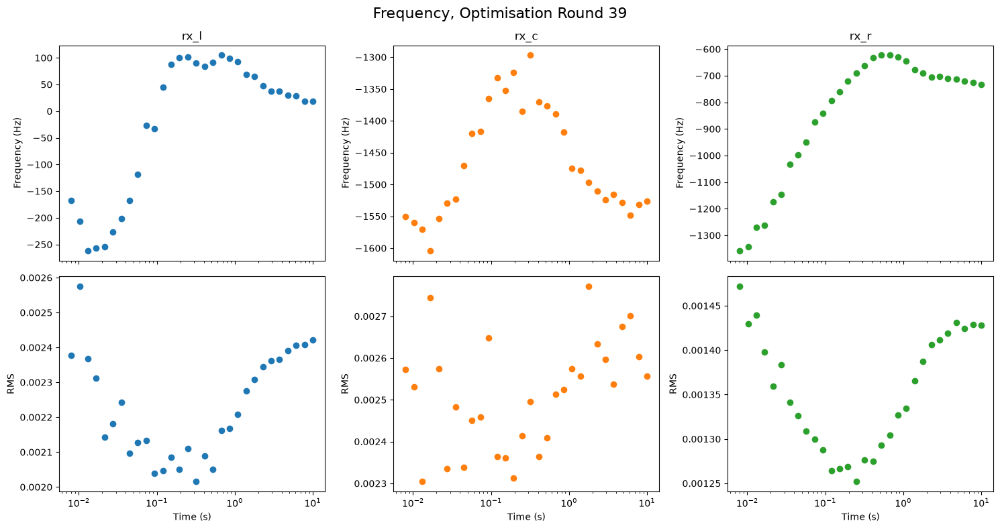

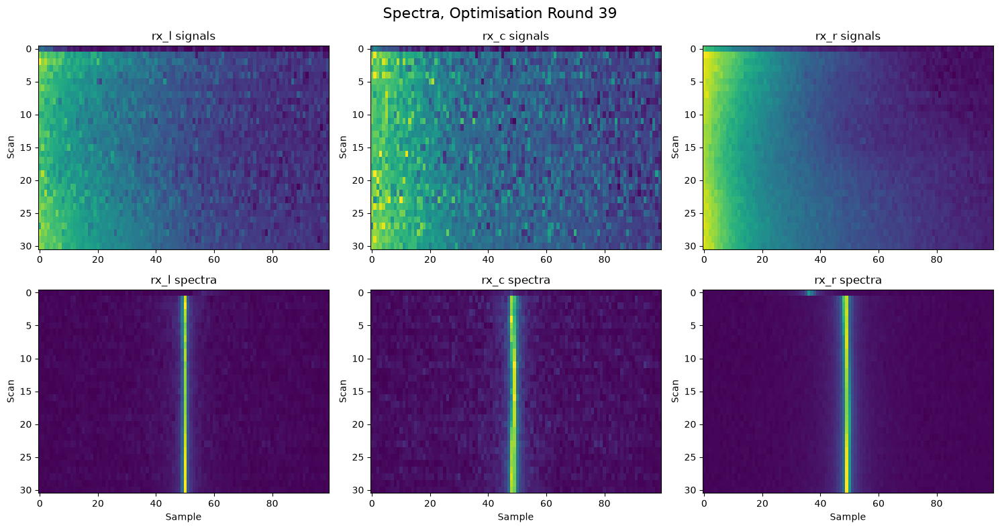

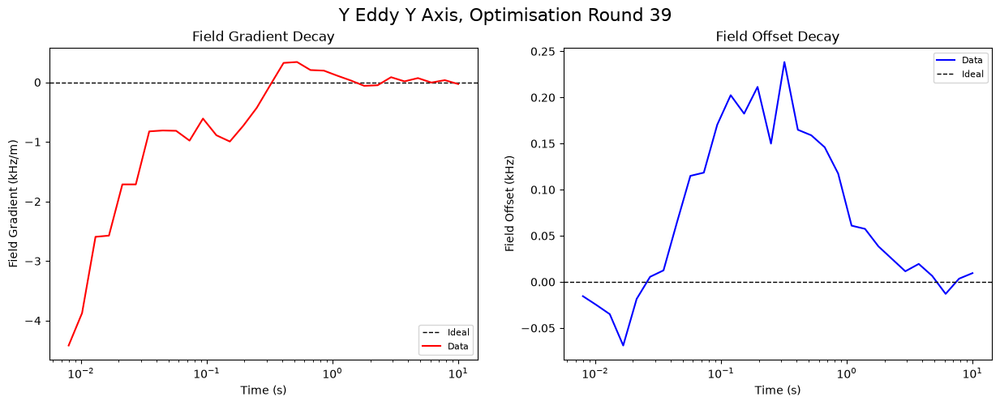

[I 2026-11-25 15:10:09,166] Trial 39 finished with value: 759.5239601555228 and parameters: {'Y_A1': 0.05478484564447099, 'Y_A2': 0.12612656251960822, 'Y_A3': 0.10192182971505873, 'Y_A4': 3.1622131440072764e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11904.04797601199
mean |E| = 8244.71097784441
RMS E = 8330.486469144693
Total cost = 7.595e+02
E max = 0.13594999805017355
E nanmax = 0.13594999805017355
E contains nan = False
B max = 0.2642913973847013
B nanmax = 0.2642913973847013
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2642913973847013 !!!!!!!!!!!!!!!!


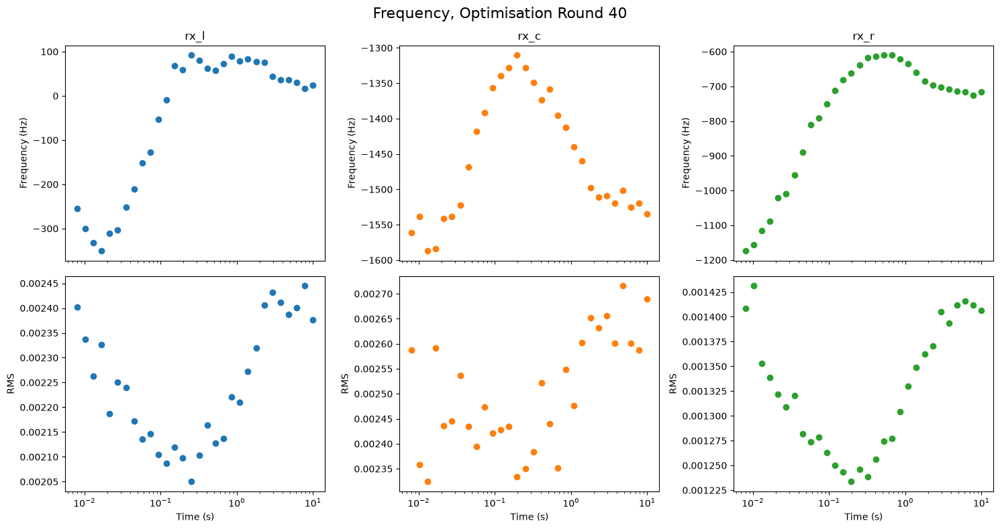

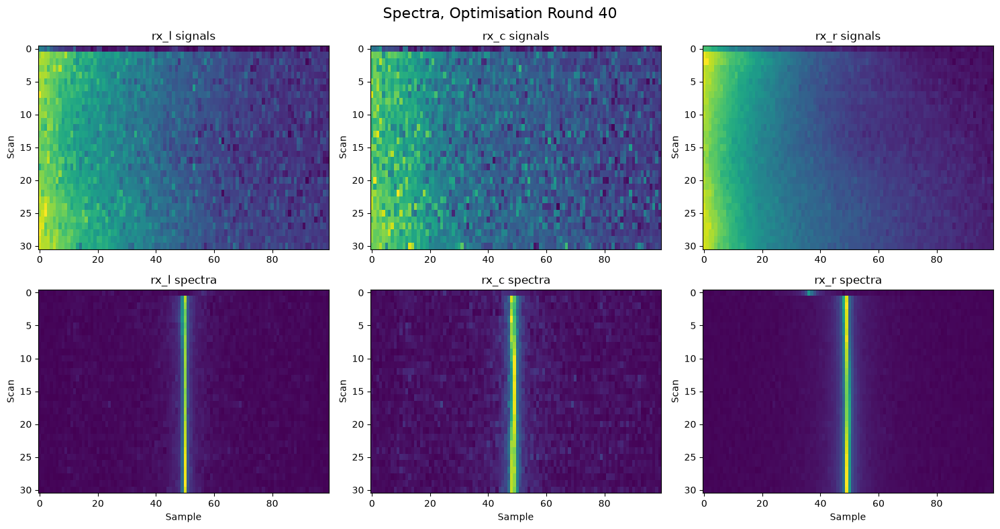

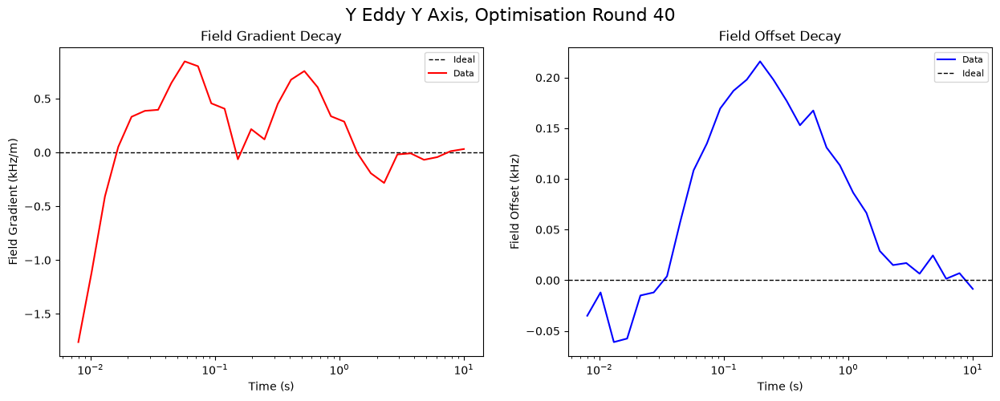

[I 2026-11-25 15:10:57,315] Trial 40 finished with value: 1018.6509733176892 and parameters: {'Y_A1': 0.056263311450959086, 'Y_A2': 0.13166632032458955, 'Y_A3': 0.10514252338828677, 'Y_A4': 6.059640327797481e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9195.402298850573
mean |E| = 7304.680992836914
RMS E = 7324.216847999883
Total cost = 1.019e+03
E max = 0.13451244001875085
E nanmax = 0.13451244001875085
E contains nan = False
B max = 0.2614967424646109
B nanmax = 0.2614967424646109
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2614967424646109 !!!!!!!!!!!!!!!!


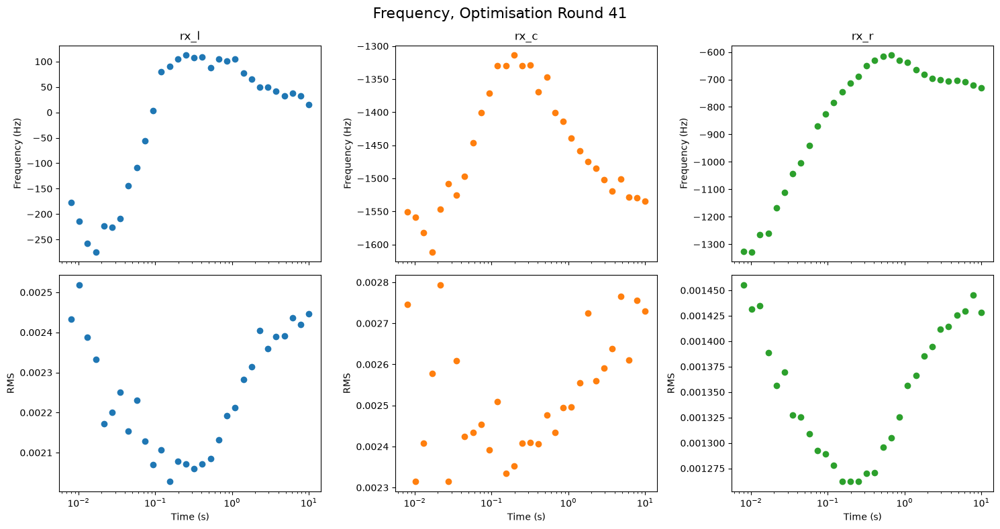

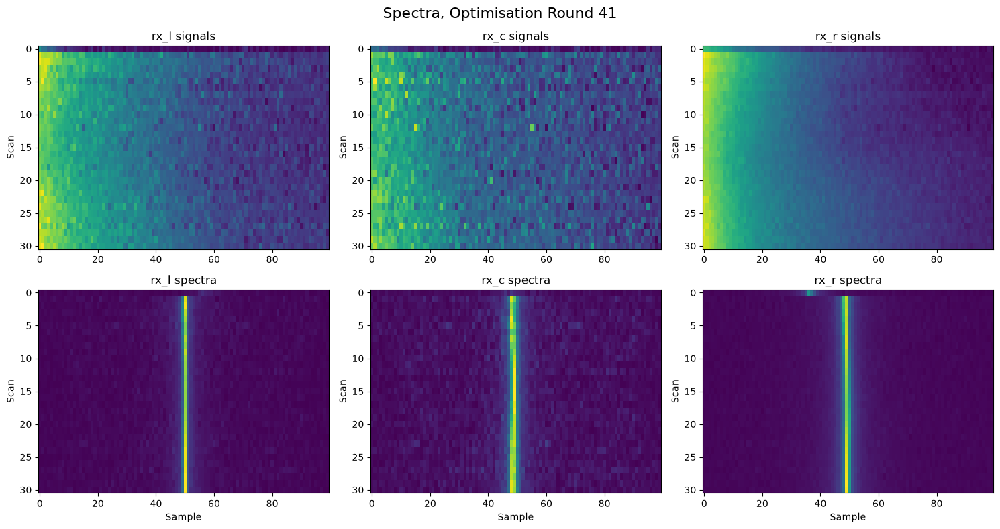

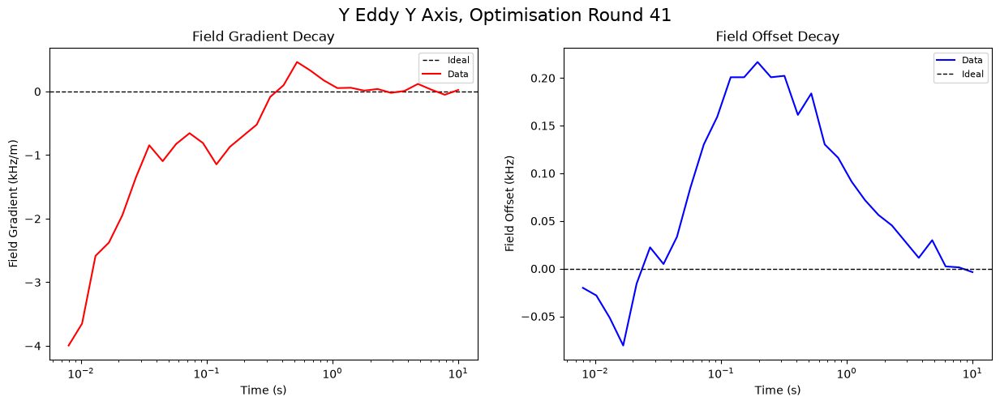

[I 2026-11-25 15:11:46,761] Trial 41 finished with value: 810.4161884336991 and parameters: {'Y_A1': 0.055893387098566207, 'Y_A2': 0.12615409188791715, 'Y_A3': 0.1015897414127046, 'Y_A4': 4.5314576310559715e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11484.257871064467
mean |E| = 8227.386306846574
RMS E = 8303.635142063082
Total cost = 8.104e+02
E max = 0.13389517544587443
E nanmax = 0.13389517544587443
E contains nan = False
B max = 0.2602967584626416
B nanmax = 0.2602967584626416
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2602967584626416 !!!!!!!!!!!!!!!!


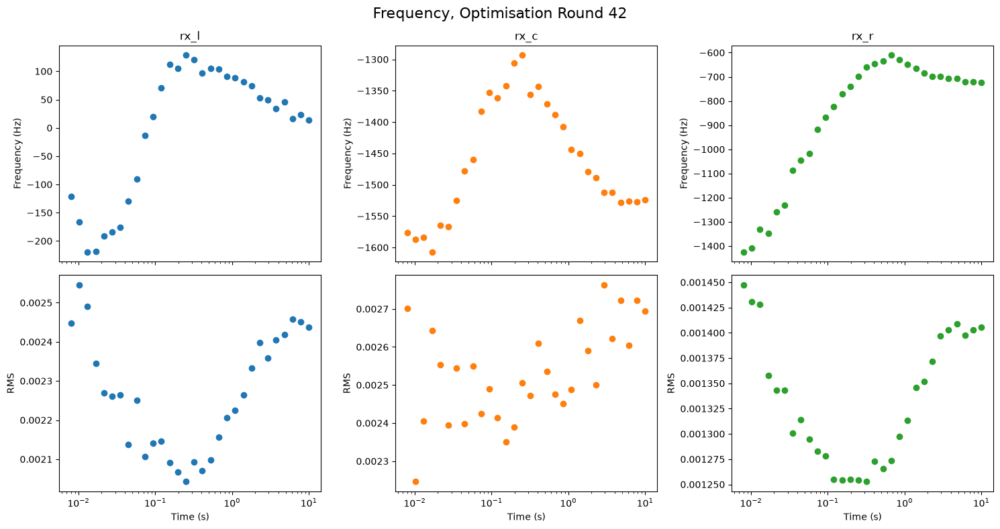

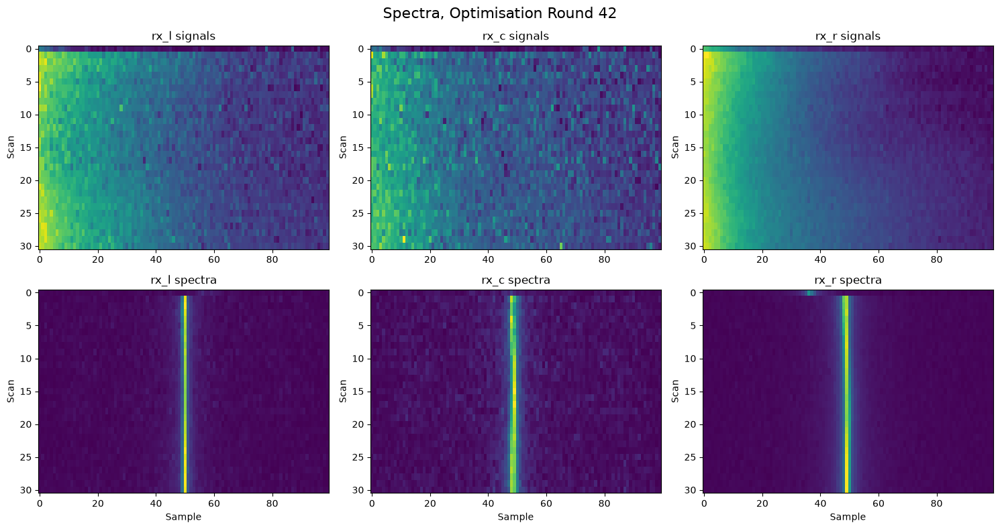

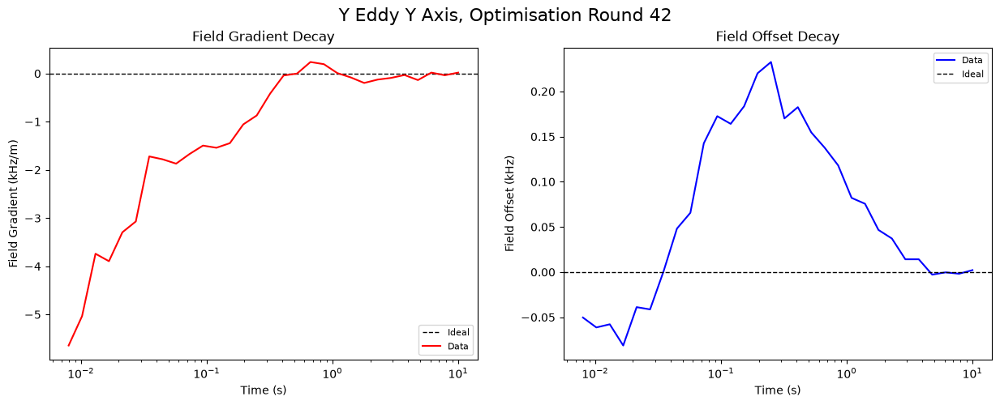

[I 2026-11-25 15:12:35,114] Trial 42 finished with value: 1103.552391768263 and parameters: {'Y_A1': 0.056647473960496436, 'Y_A2': 0.1238988980587767, 'Y_A3': 0.09905713778284786, 'Y_A4': 2.118453988274638e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13033.48325837081
mean |E| = 8683.491587539562
RMS E = 8831.504733543752
Total cost = 1.104e+03
E max = 0.13280389646459853
E nanmax = 0.13280389646459853
E contains nan = False
B max = 0.25817529289271485
B nanmax = 0.25817529289271485
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25817529289271485 !!!!!!!!!!!!!!!!


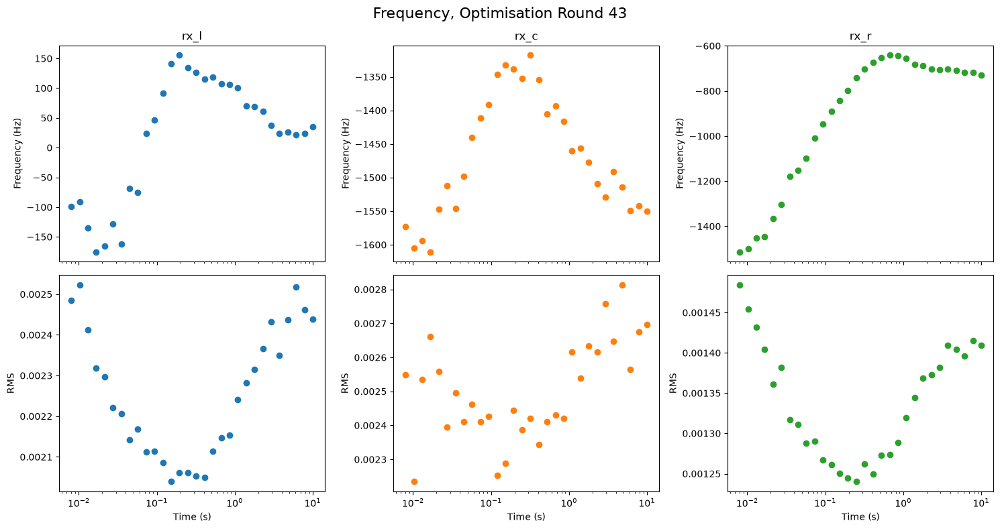

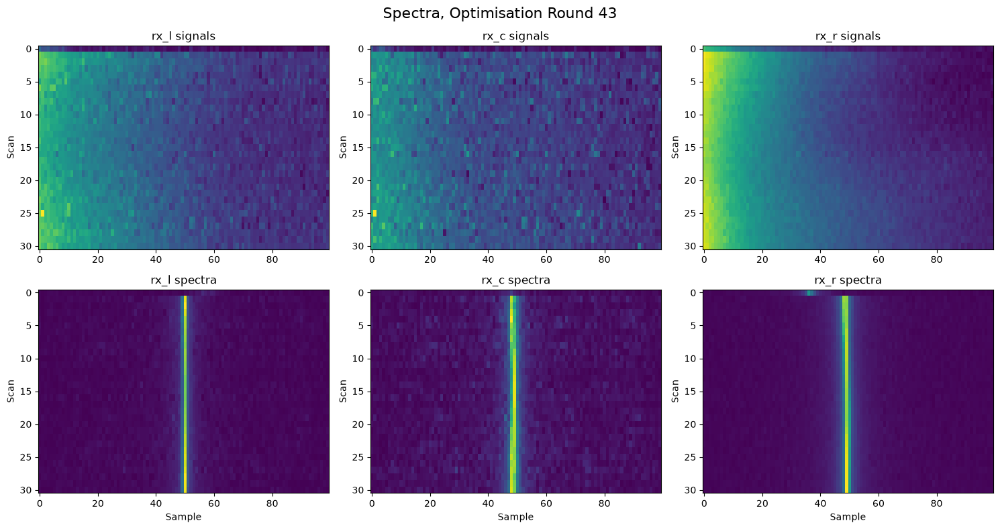

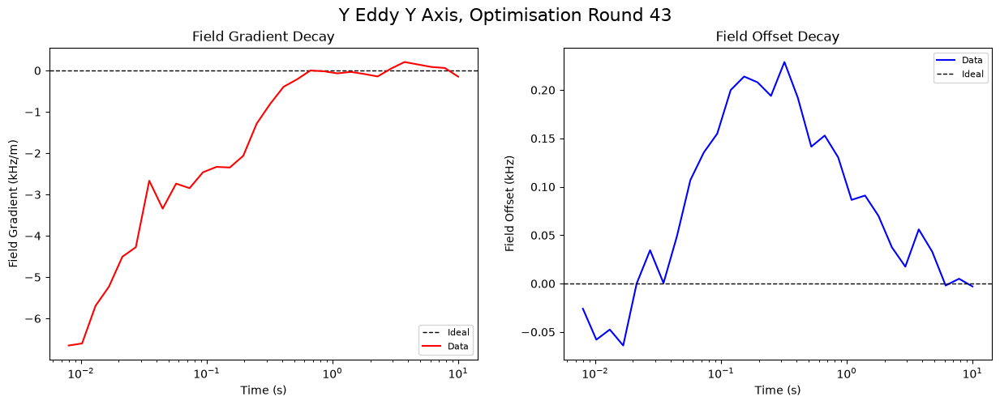

[I 2026-11-25 15:13:23,502] Trial 43 finished with value: 1761.14512550595 and parameters: {'Y_A1': 0.052802336742160734, 'Y_A2': 0.11807914572252538, 'Y_A3': 0.10118285287036717, 'Y_A4': -9.465234937401867e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 14142.92853573213
mean |E| = 9368.14925870398
RMS E = 9610.556865899765
Total cost = 1.761e+03
E max = 0.13076870838622145
E nanmax = 0.13076870838622145
E contains nan = False
B max = 0.2542188368120769
B nanmax = 0.2542188368120769
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2542188368120769 !!!!!!!!!!!!!!!!


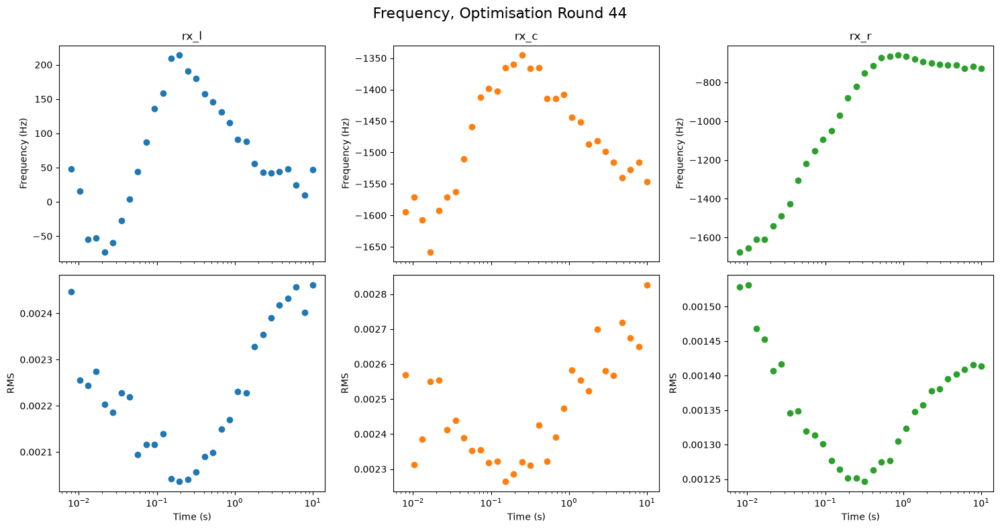

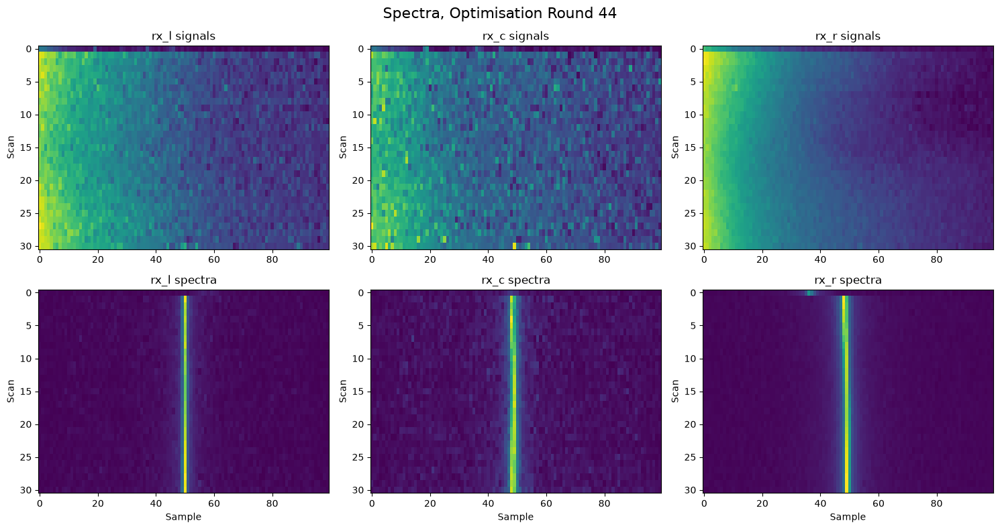

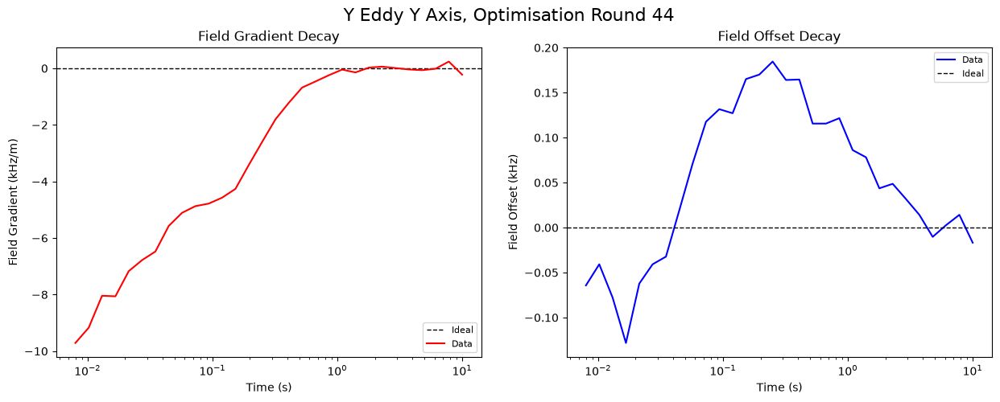

[I 2026-11-25 15:14:12,515] Trial 44 finished with value: 2641.773812242806 and parameters: {'Y_A1': 0.04958105957660314, 'Y_A2': 0.10898929023188153, 'Y_A3': 0.09943074961514502, 'Y_A4': 2.2376509885902506e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 17226.3868065967
mean |E| = 10690.15492253873
RMS E = 11166.13349040631
Total cost = 2.642e+03
E max = 0.13501915634758843
E nanmax = 0.13501915634758843
E contains nan = False
B max = 0.2624818162247483
B nanmax = 0.2624818162247483
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2624818162247483 !!!!!!!!!!!!!!!!


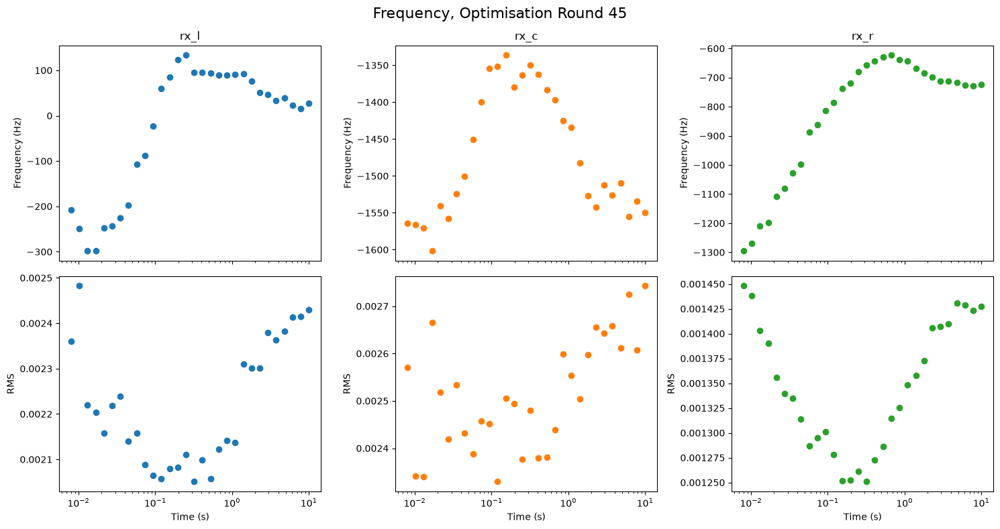

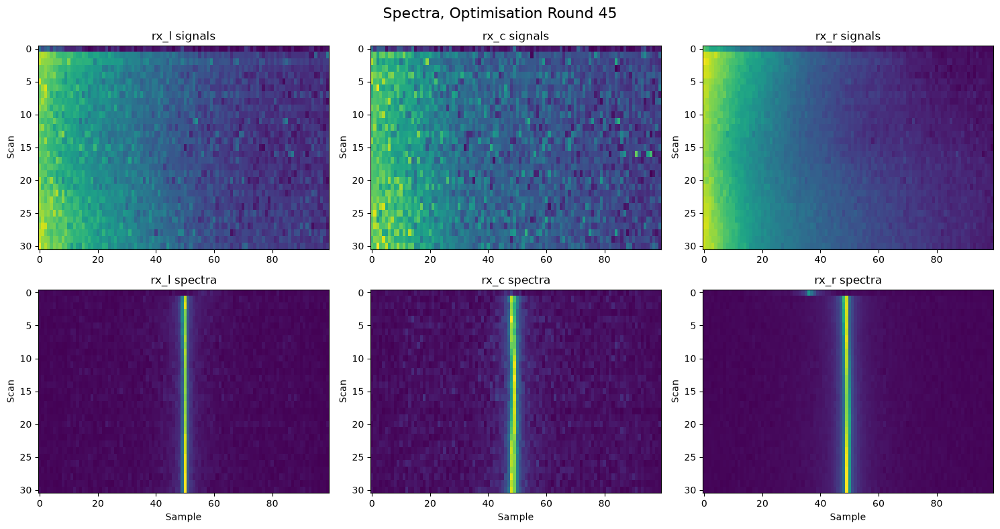

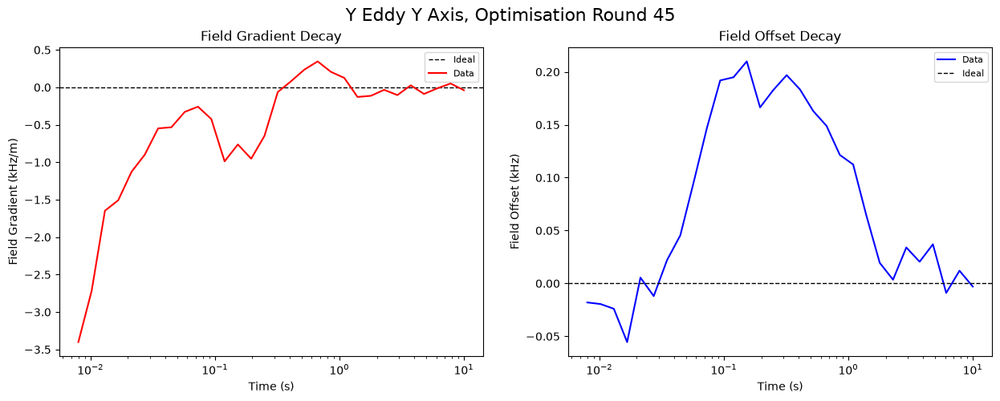

[I 2026-11-25 15:15:00,858] Trial 45 finished with value: 869.7959922772131 and parameters: {'Y_A1': 0.05489036485305617, 'Y_A2': 0.12574601789663403, 'Y_A3': 0.1063279925147481, 'Y_A4': 4.281971247648559e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10879.560219890054
mean |E| = 8019.490254872562
RMS E = 8063.723660411815
Total cost = 8.698e+02
E max = 0.13600126674587945
E nanmax = 0.13600126674587945
E contains nan = False
B max = 0.2643910323870802
B nanmax = 0.2643910323870802
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2643910323870802 !!!!!!!!!!!!!!!!


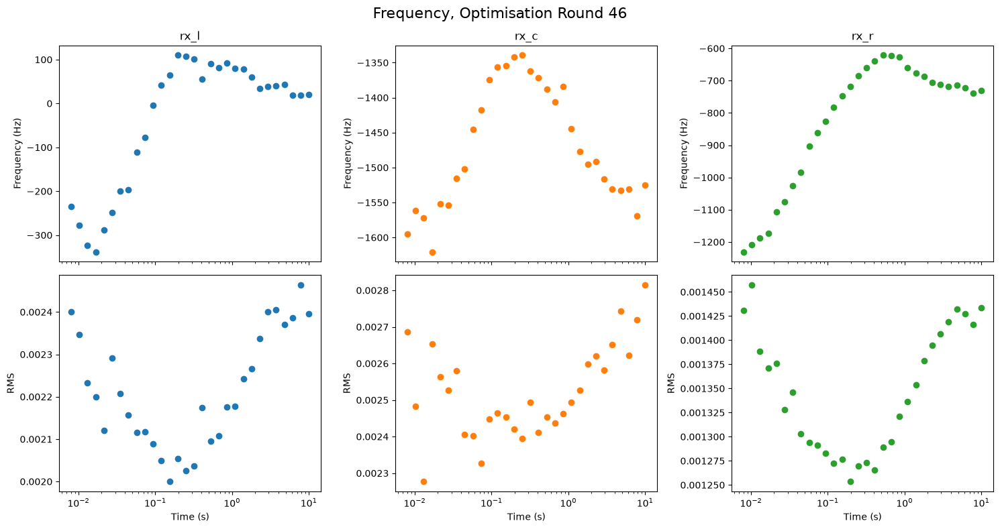

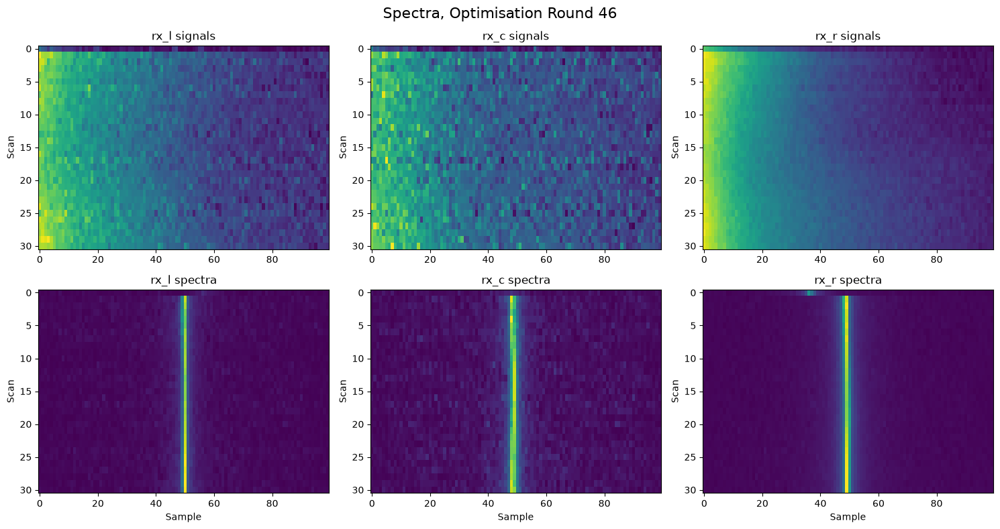

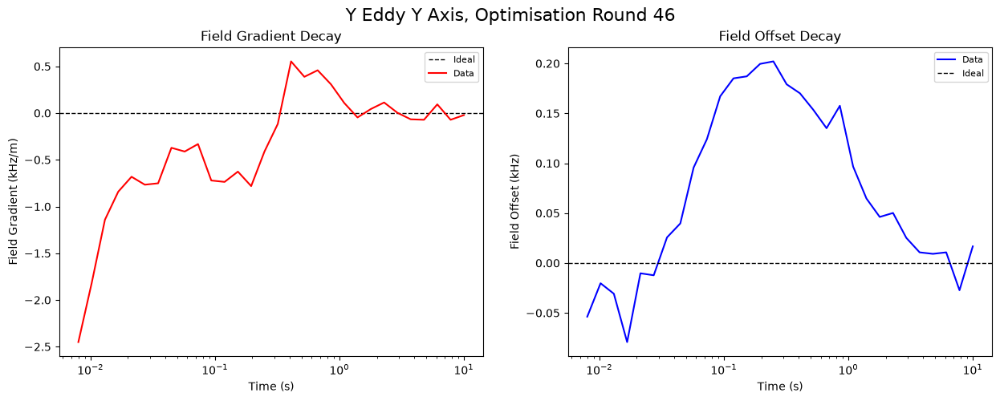

[I 2026-11-25 15:15:49,170] Trial 46 finished with value: 1012.3230522947932 and parameters: {'Y_A1': 0.06298946820485063, 'Y_A2': 0.12654308444447412, 'Y_A3': 0.10457481107740232, 'Y_A4': 3.127760649831761e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9955.022488755618
mean |E| = 7876.894885890387
RMS E = 7902.805781105085
Total cost = 1.012e+03
E max = 0.13620120706995809
E nanmax = 0.13620120706995809
E contains nan = False
B max = 0.2647797589162481
B nanmax = 0.2647797589162481
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2647797589162481 !!!!!!!!!!!!!!!!


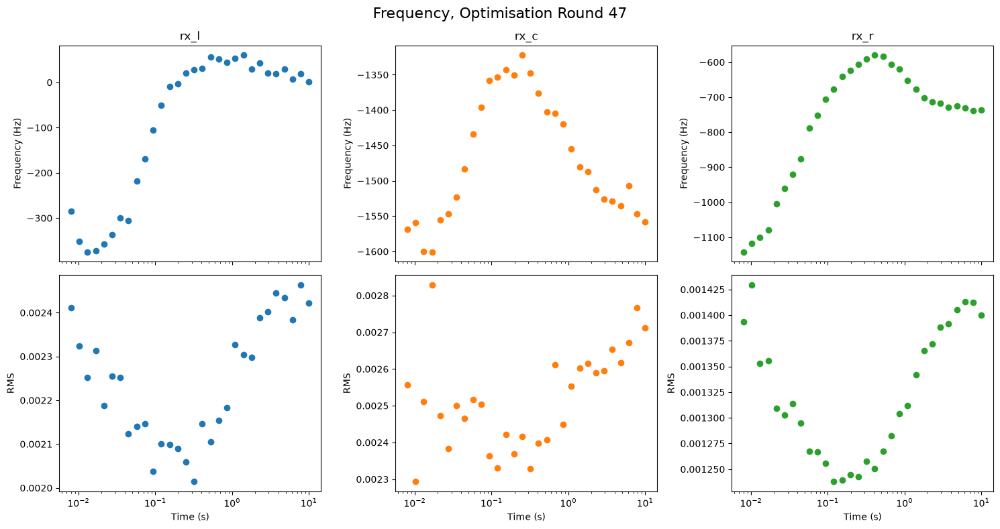

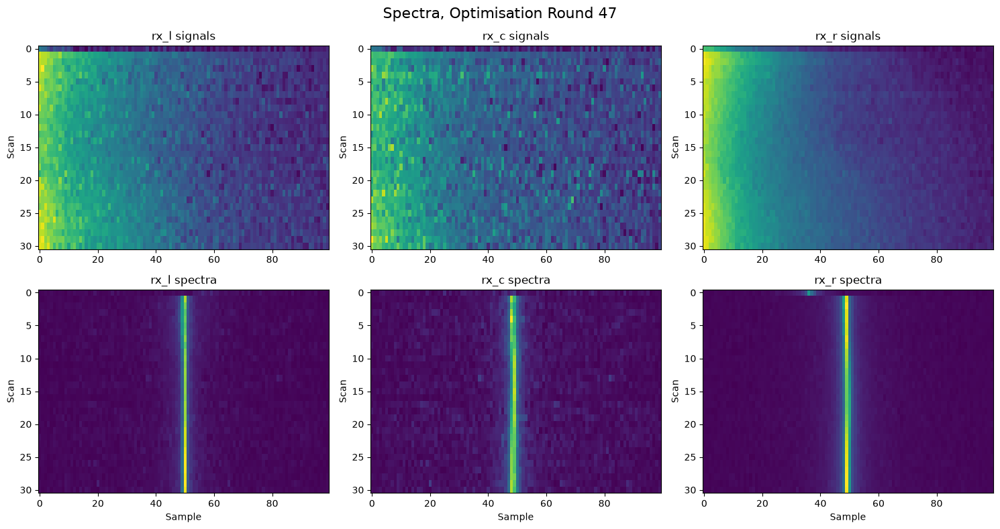

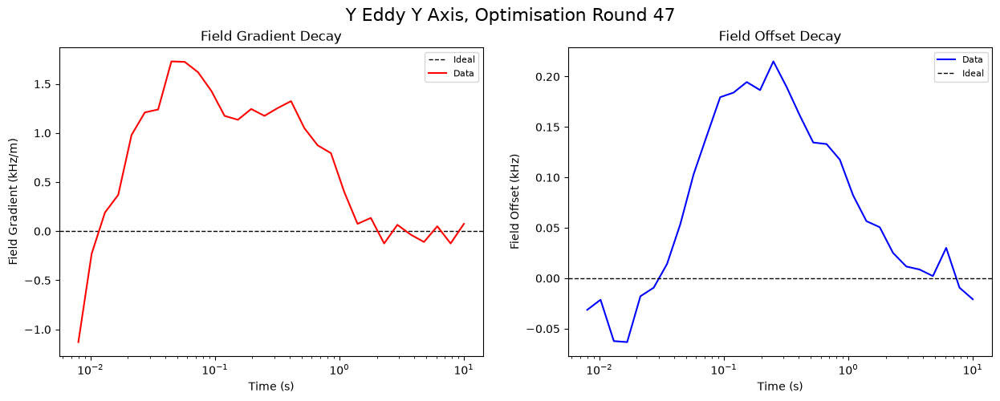

[I 2026-11-25 15:16:37,371] Trial 47 finished with value: 1906.639394262794 and parameters: {'Y_A1': 0.056892530227774324, 'Y_A2': 0.13903337986853873, 'Y_A3': 0.09853076244807786, 'Y_A4': 1.445726752042937e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 8570.714642678658
mean |E| = 6789.272030651338
RMS E = 6825.97754040588
Total cost = 1.907e+03
E max = 0.1341623423926804
E nanmax = 0.1341623423926804
E contains nan = False
B max = 0.26081614835827416
B nanmax = 0.26081614835827416
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26081614835827416 !!!!!!!!!!!!!!!!


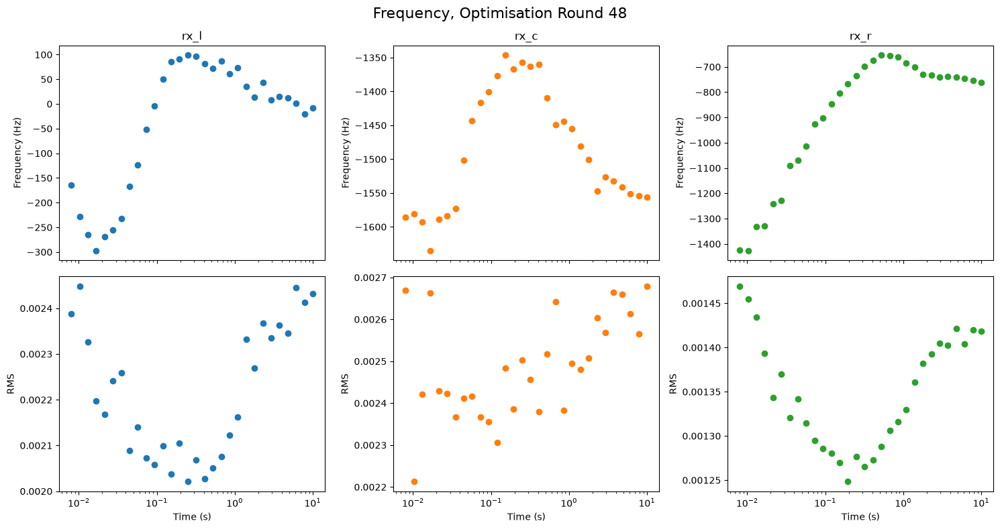

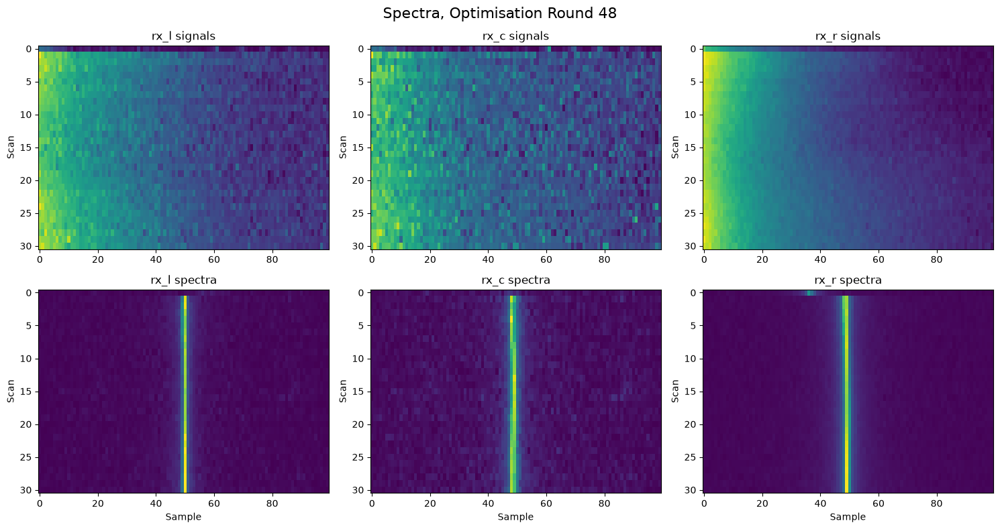

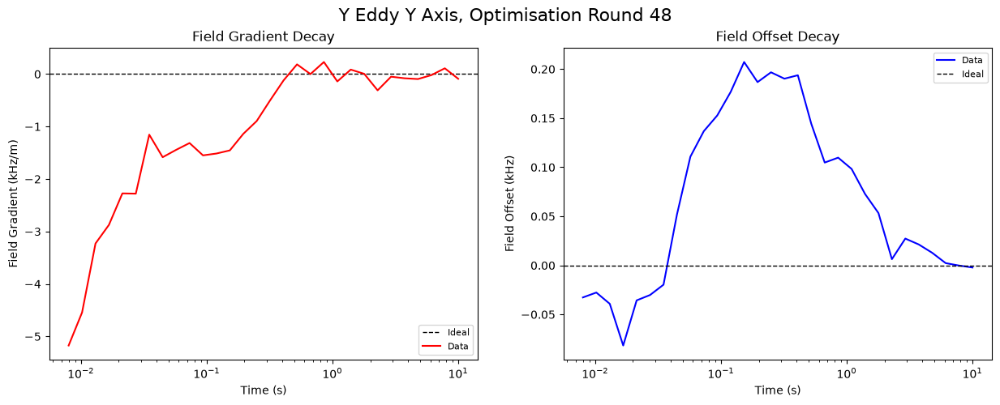

[I 2026-11-25 15:17:25,360] Trial 48 finished with value: 1322.3015302304445 and parameters: {'Y_A1': 0.053956031336456996, 'Y_A2': 0.12319788981625654, 'Y_A3': 0.10406677397197596, 'Y_A4': 4.598490892489773e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12613.693153423286
mean |E| = 8548.22588705647
RMS E = 8658.163006035453
Total cost = 1.322e+03
E max = 0.13239380435654782
E nanmax = 0.13239380435654782
E contains nan = False
B max = 0.2573780530281459
B nanmax = 0.2573780530281459
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2573780530281459 !!!!!!!!!!!!!!!!


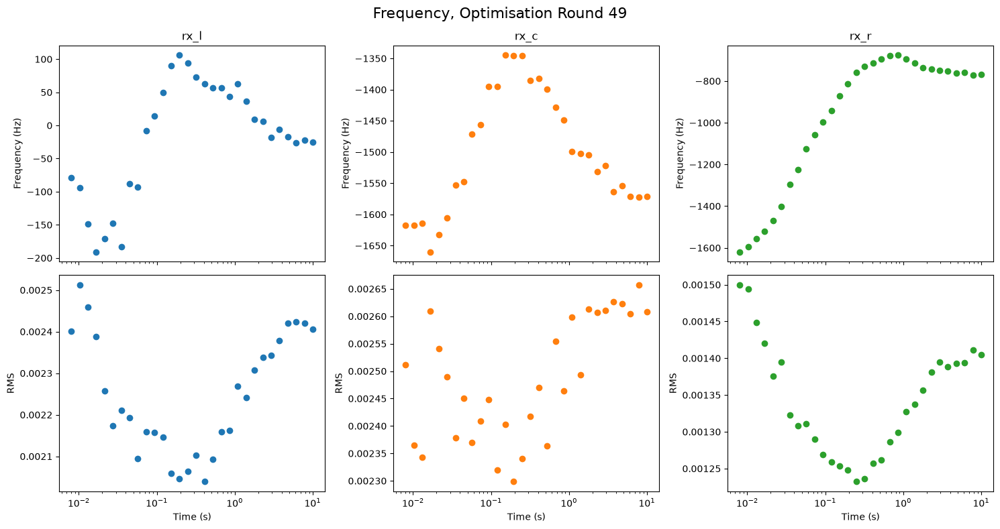

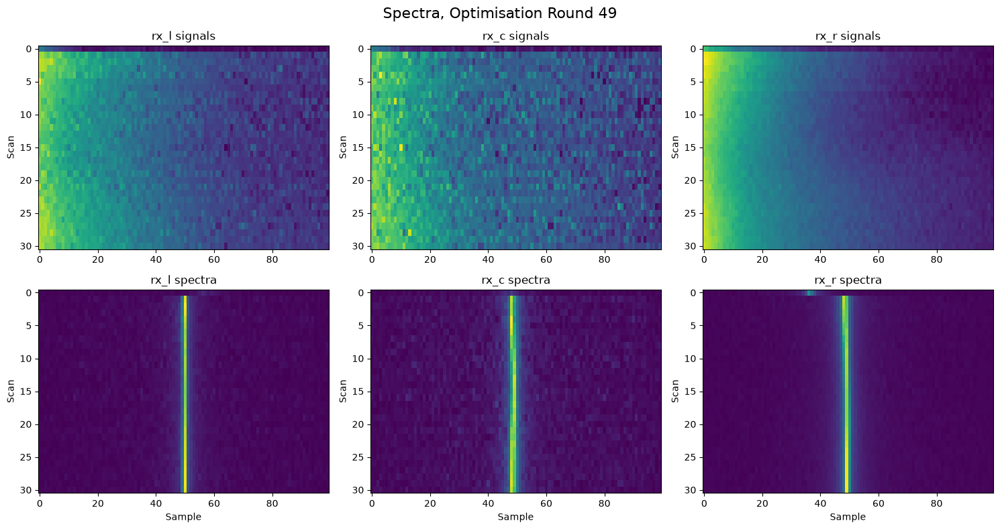

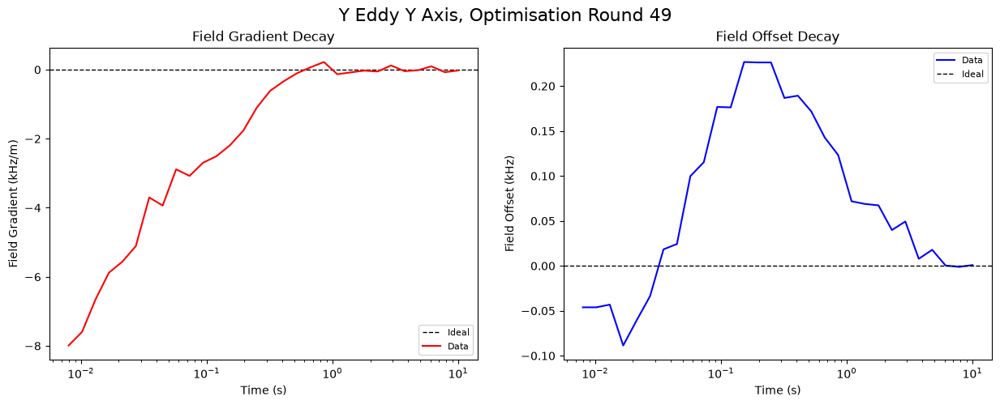

[I 2026-11-25 15:18:13,640] Trial 49 finished with value: 1411.8820759640428 and parameters: {'Y_A1': 0.05587521114985285, 'Y_A2': 0.12076676751926337, 'Y_A3': 0.09274998352358843, 'Y_A4': 2.2342188943594283e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 15412.293853073457
mean |E| = 9544.894219556887
RMS E = 9875.56212194663
Total cost = 1.412e+03
E max = 0.13215485771615473
E nanmax = 0.13215485771615473
E contains nan = False
B max = 0.25691353678487533
B nanmax = 0.25691353678487533
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25691353678487533 !!!!!!!!!!!!!!!!


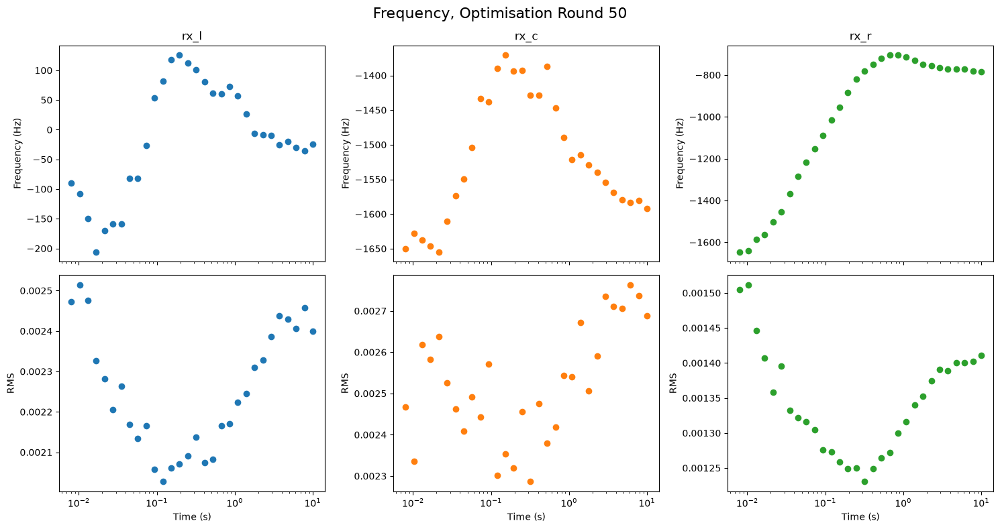

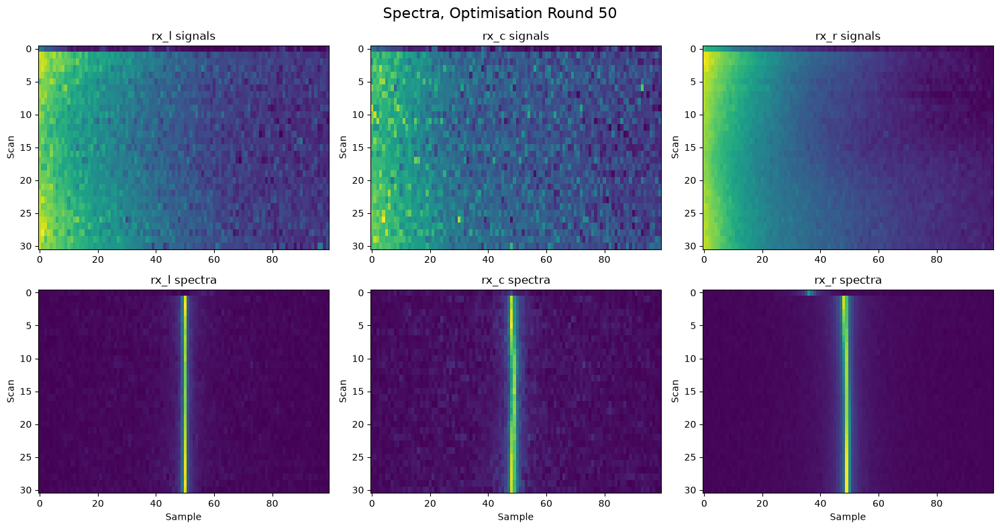

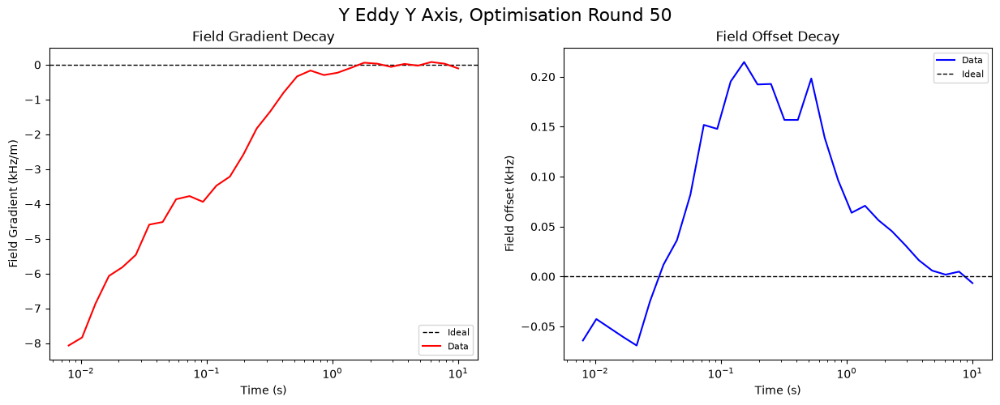

[I 2026-11-25 15:19:01,562] Trial 50 finished with value: 1761.9812049852856 and parameters: {'Y_A1': 0.0538585816529969, 'Y_A2': 0.11464413286691774, 'Y_A3': 0.09928807293425493, 'Y_A4': 4.420662469280975e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 15562.21889055472
mean |E| = 10000.166583374976
RMS E = 10339.863135883637
Total cost = 1.762e+03
E max = 0.13599672583022865
E nanmax = 0.13599672583022865
E contains nan = False
B max = 0.26438225304301605
B nanmax = 0.26438225304301605
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26438225304301605 !!!!!!!!!!!!!!!!


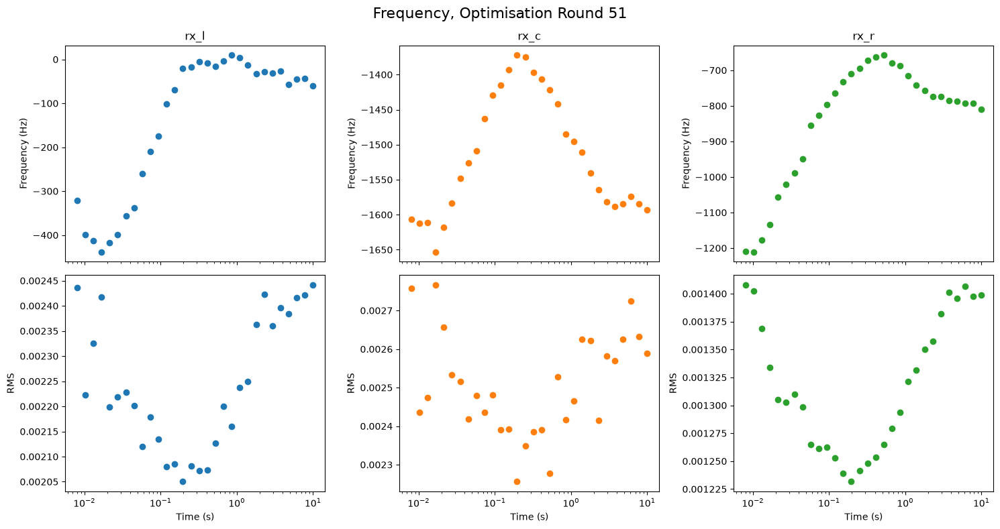

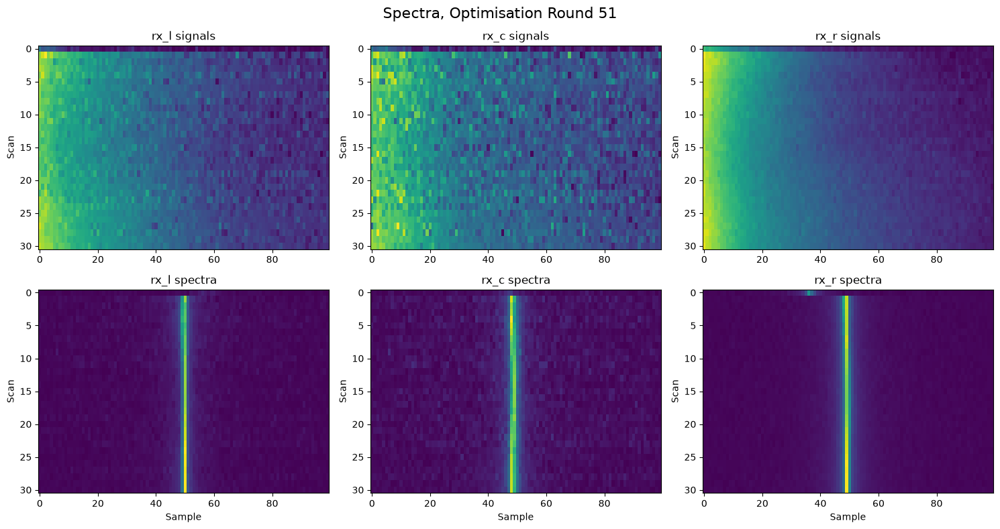

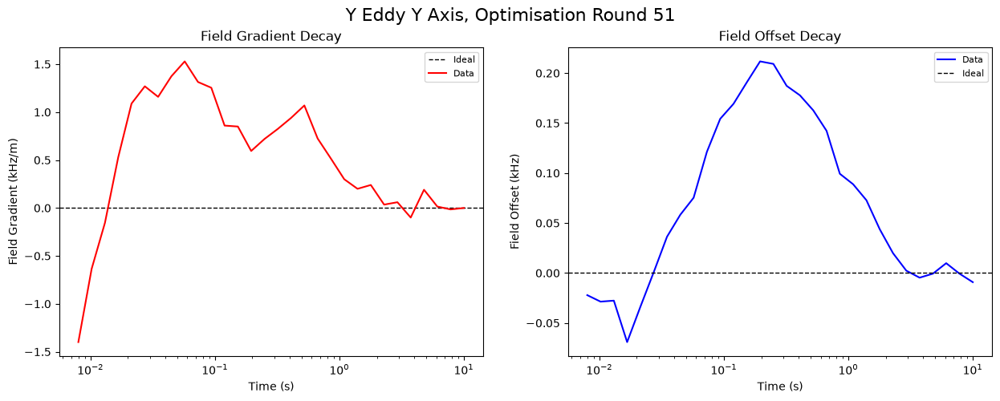

[I 2026-11-25 15:19:49,716] Trial 51 finished with value: 1472.5873193967 and parameters: {'Y_A1': 0.05327782122148447, 'Y_A2': 0.13521288387649624, 'Y_A3': 0.10450704584022083, 'Y_A4': 3.0339719945794017e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 8885.557221389303
mean |E| = 6974.512743628183
RMS E = 7004.431859102831
Total cost = 1.473e+03
E max = 0.13549605360520117
E nanmax = 0.13549605360520117
E contains nan = False
B max = 0.26340888902731435
B nanmax = 0.26340888902731435
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26340888902731435 !!!!!!!!!!!!!!!!


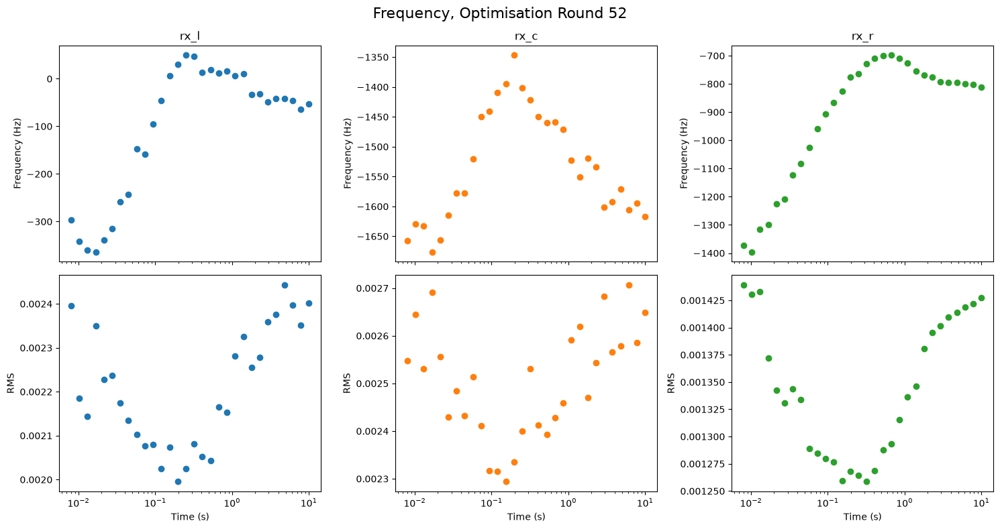

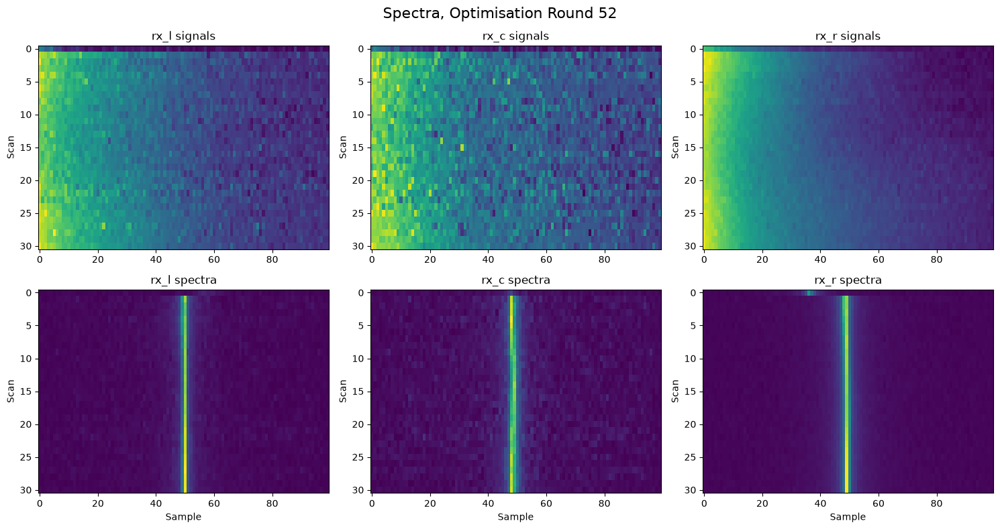

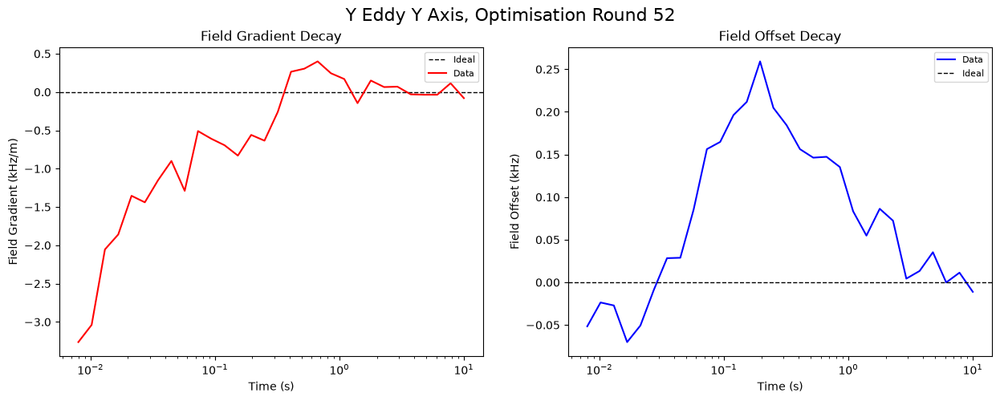

[I 2026-11-25 15:20:38,190] Trial 52 finished with value: 1112.5976071474838 and parameters: {'Y_A1': 0.0622208567748848, 'Y_A2': 0.12775875611043178, 'Y_A3': 0.10066520534119104, 'Y_A4': -4.152299211081785e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10764.61769115442
mean |E| = 8134.099616858236
RMS E = 8187.838545048698
Total cost = 1.113e+03
E max = 0.13507015519913068
E nanmax = 0.13507015519913068
E contains nan = False
B max = 0.26258091664840205
B nanmax = 0.26258091664840205
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26258091664840205 !!!!!!!!!!!!!!!!


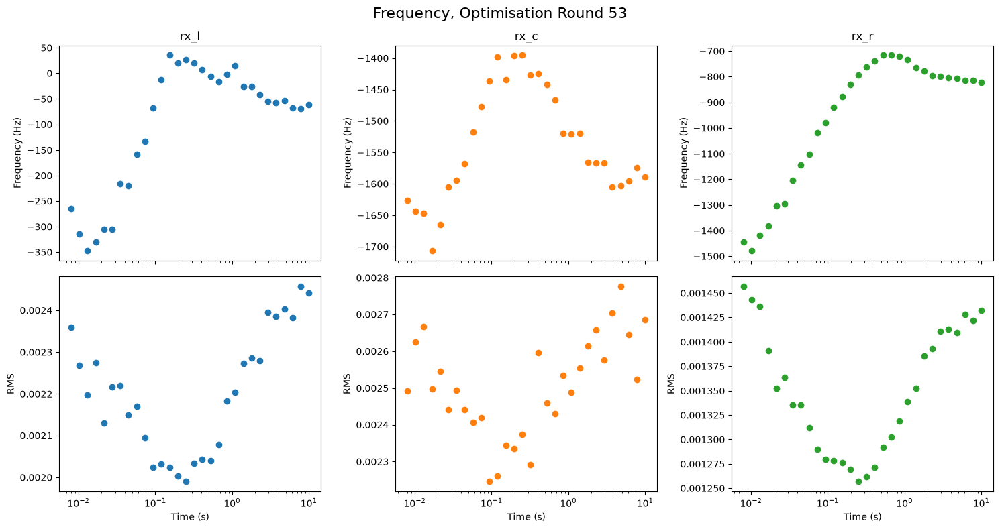

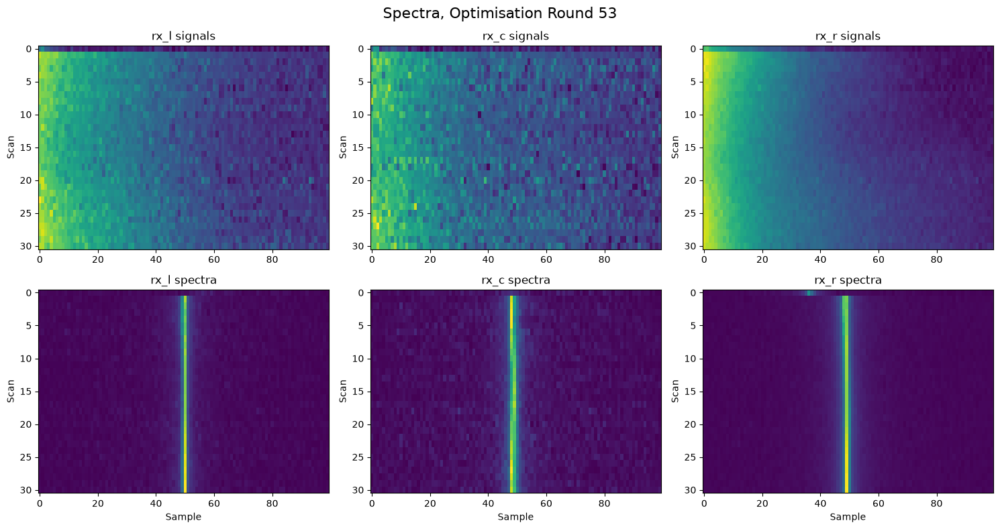

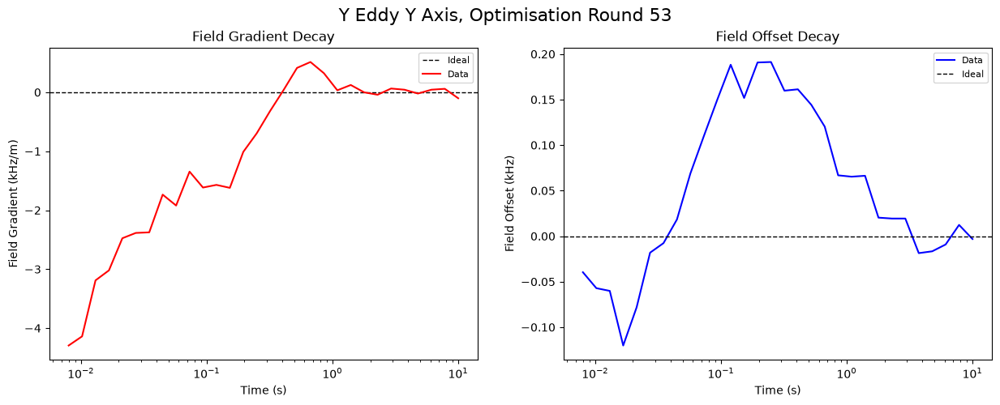

[I 2026-11-25 15:21:26,513] Trial 53 finished with value: 1112.004488821729 and parameters: {'Y_A1': 0.06494477719012139, 'Y_A2': 0.12428086158273992, 'Y_A3': 0.09887664823929457, 'Y_A4': 1.5190111012837194e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11804.097951024487
mean |E| = 8583.874729302011
RMS E = 8692.159205088923
Total cost = 1.112e+03
E max = 0.13565223286297098
E nanmax = 0.13565223286297098
E contains nan = False
B max = 0.26371255495197427
B nanmax = 0.26371255495197427
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26371255495197427 !!!!!!!!!!!!!!!!


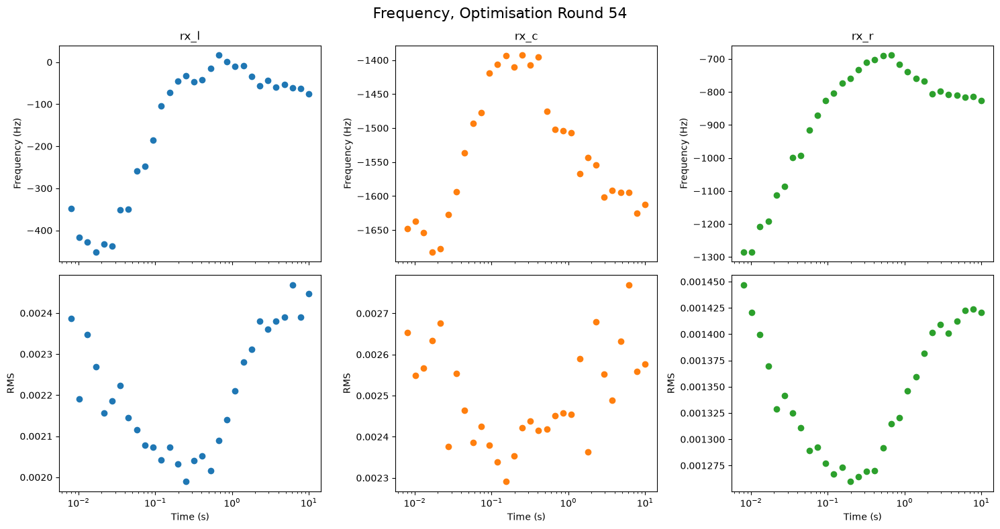

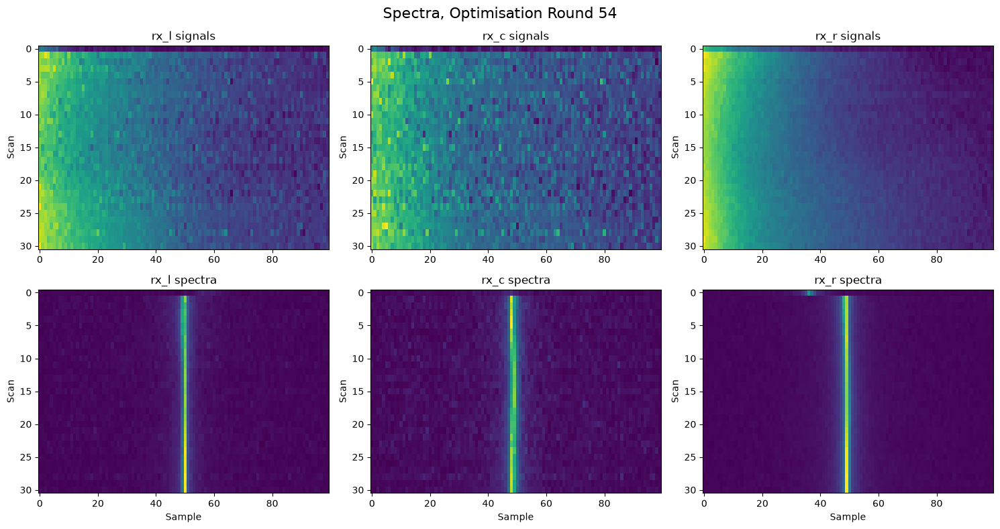

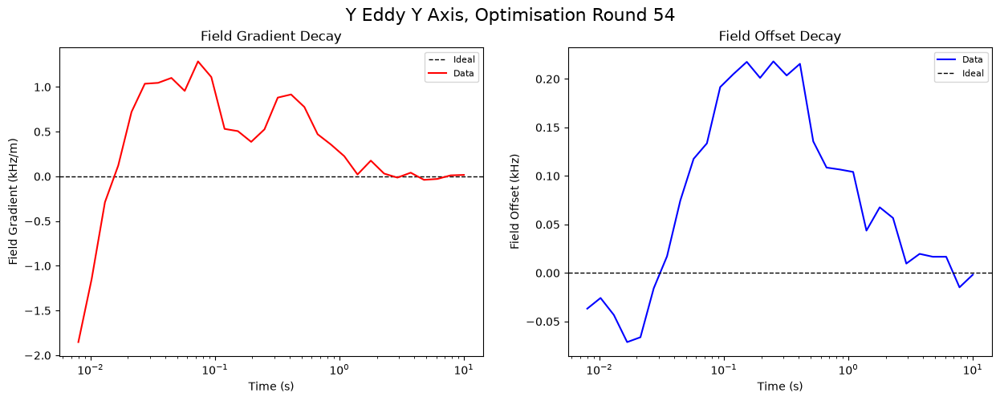

[I 2026-11-25 15:22:14,655] Trial 54 finished with value: 949.0345804816848 and parameters: {'Y_A1': 0.05144693766971292, 'Y_A2': 0.13317730231212047, 'Y_A3': 0.10601411557379466, 'Y_A4': -6.690467394422755e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9375.312343828084
mean |E| = 7193.236714975844
RMS E = 7223.09050340092
Total cost = 9.490e+02
E max = 0.13499060469237012
E nanmax = 0.13499060469237012
E contains nan = False
B max = 0.2624262814093195
B nanmax = 0.2624262814093195
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2624262814093195 !!!!!!!!!!!!!!!!


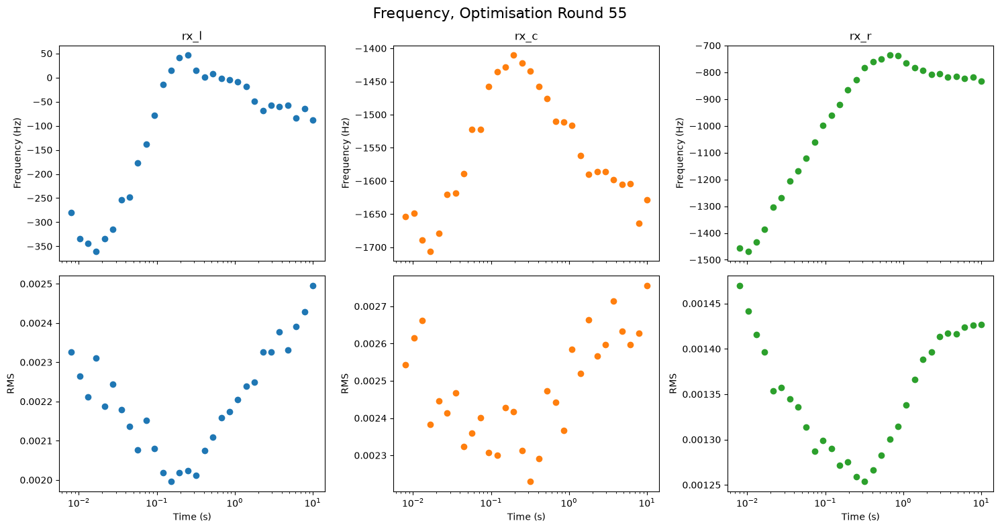

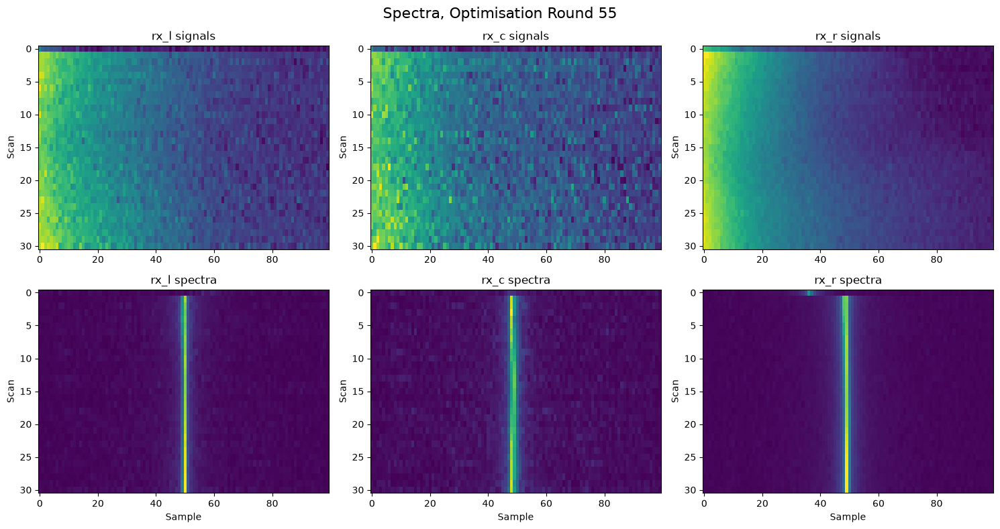

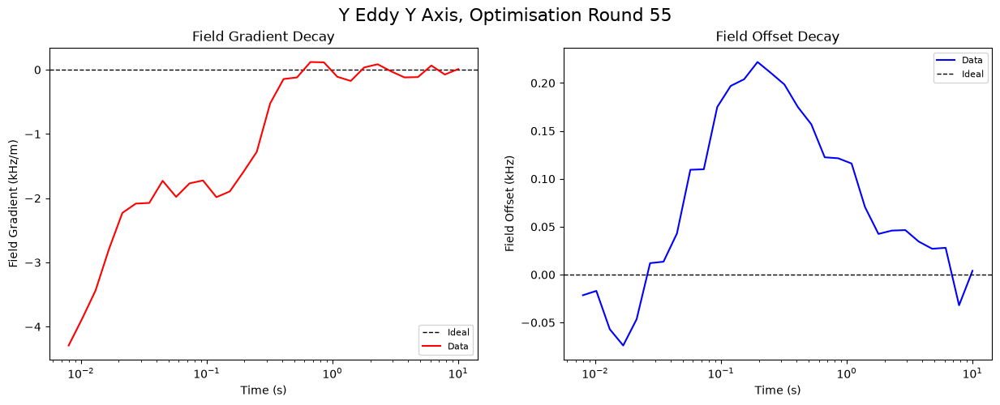

[I 2026-11-25 15:23:02,805] Trial 55 finished with value: 1280.820162371703 and parameters: {'Y_A1': 0.06108015028446956, 'Y_A2': 0.12115646958323115, 'Y_A3': 0.10515253862542588, 'Y_A4': 6.457204422944796e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11759.120439780108
mean |E| = 8657.004830917871
RMS E = 8751.420370126534
Total cost = 1.281e+03
E max = 0.1353040506122626
E nanmax = 0.1353040506122626
E contains nan = False
B max = 0.2630356645752353
B nanmax = 0.2630356645752353
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2630356645752353 !!!!!!!!!!!!!!!!


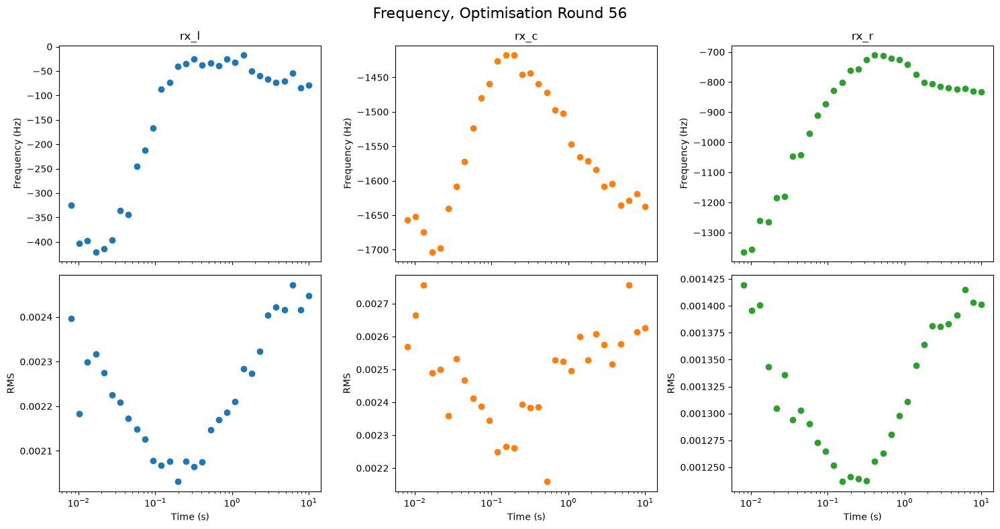

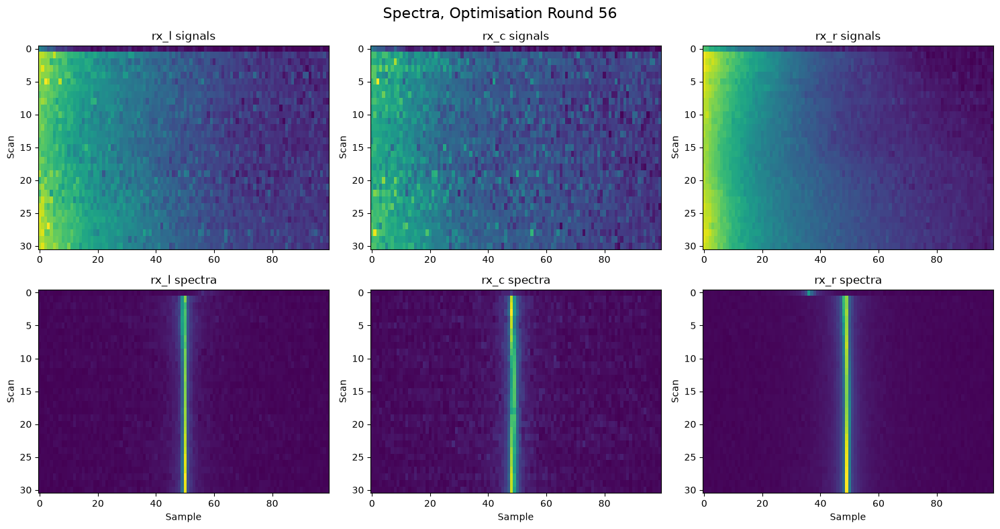

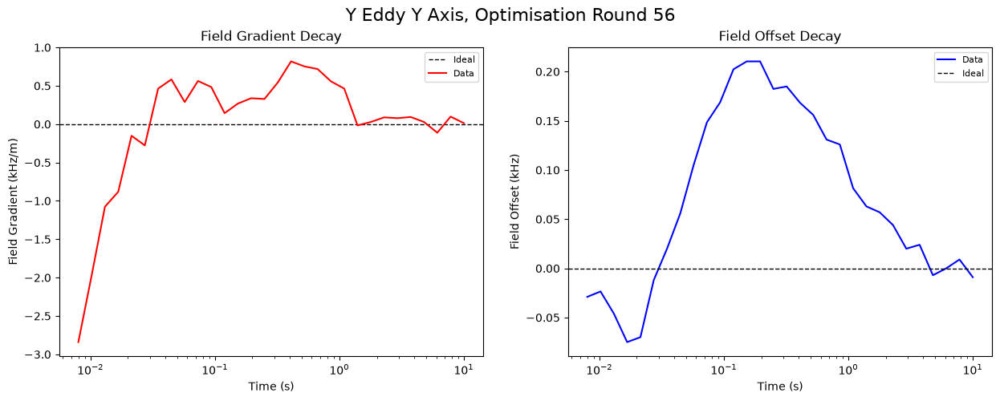

[I 2026-11-25 15:23:51,153] Trial 56 finished with value: 1313.6250023681514 and parameters: {'Y_A1': 0.05486052143145787, 'Y_A2': 0.13222488565919538, 'Y_A3': 0.10155047307263534, 'Y_A4': -1.911742758199686e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10394.802598700646
mean |E| = 7540.729635182407
RMS E = 7580.629735472301
Total cost = 1.314e+03
E max = 0.13278741172028966
E nanmax = 0.13278741172028966
E contains nan = False
B max = 0.25814325725200177
B nanmax = 0.25814325725200177
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25814325725200177 !!!!!!!!!!!!!!!!


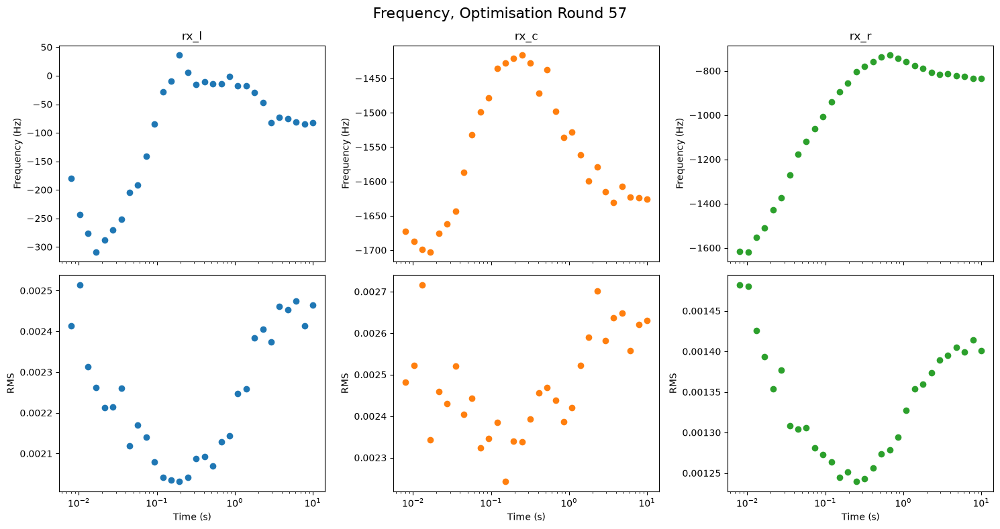

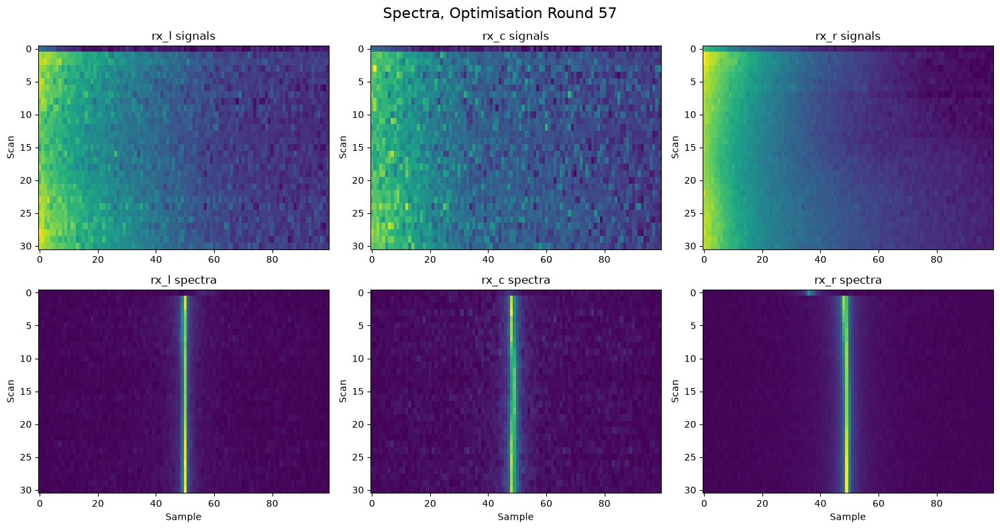

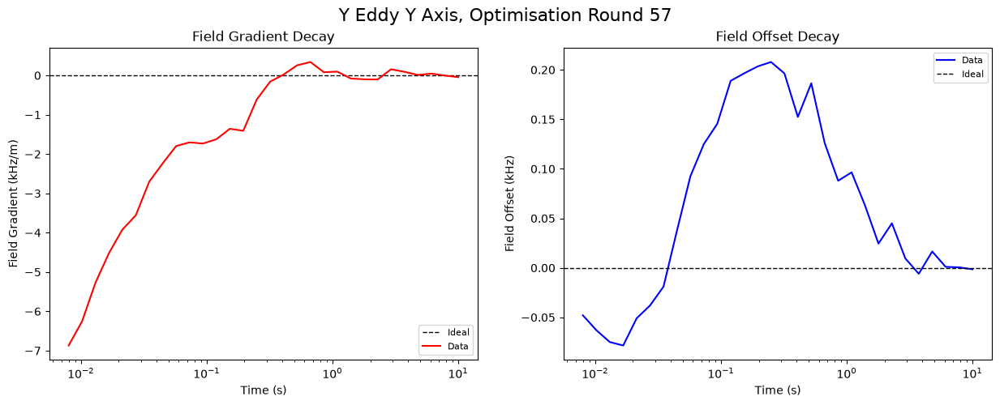

[I 2026-11-25 15:24:43,144] Trial 57 finished with value: 1070.9305975879108 and parameters: {'Y_A1': 0.05148841320574459, 'Y_A2': 0.12451166705712856, 'Y_A3': 0.09563990168664724, 'Y_A4': -9.903089418524208e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 14367.816091954019
mean |E| = 8996.168582375478
RMS E = 9222.645221635326
Total cost = 1.071e+03
E max = 0.13407880521103108
E nanmax = 0.13407880521103108
E contains nan = False
B max = 0.260653720258574
B nanmax = 0.260653720258574
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.260653720258574 !!!!!!!!!!!!!!!!


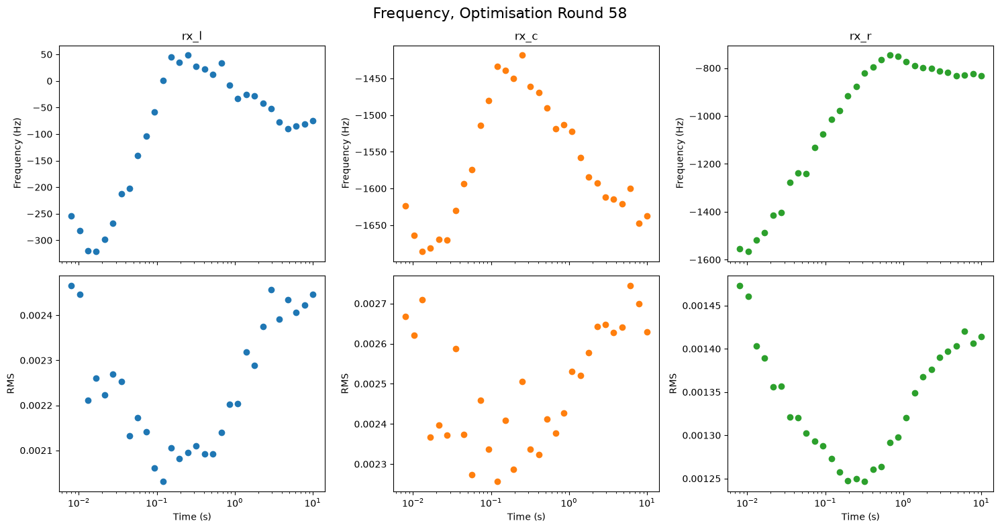

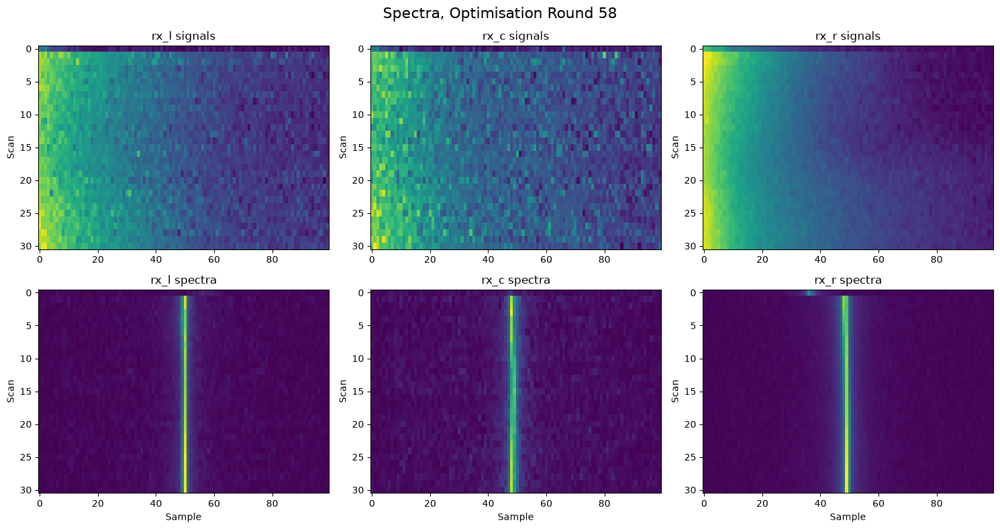

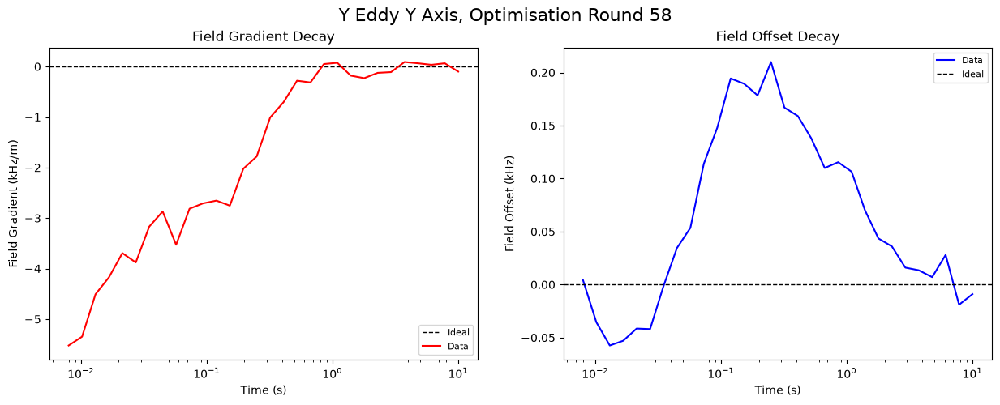

[I 2026-11-25 15:25:31,246] Trial 58 finished with value: 1749.439031749856 and parameters: {'Y_A1': 0.05974029143445666, 'Y_A2': 0.11661364096677335, 'Y_A3': 0.10492221125665449, 'Y_A4': 2.7287031329878065e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13003.49825087456
mean |E| = 9284.357821089454
RMS E = 9458.051045189533
Total cost = 1.749e+03
E max = 0.13741257094120835
E nanmax = 0.13741257094120835
E contains nan = False
B max = 0.26713467004899016
B nanmax = 0.26713467004899016
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26713467004899016 !!!!!!!!!!!!!!!!


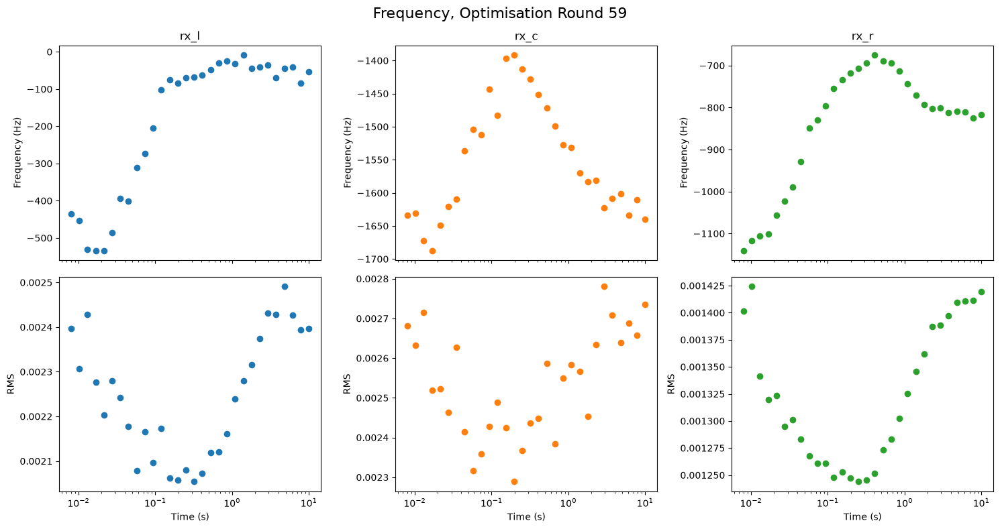

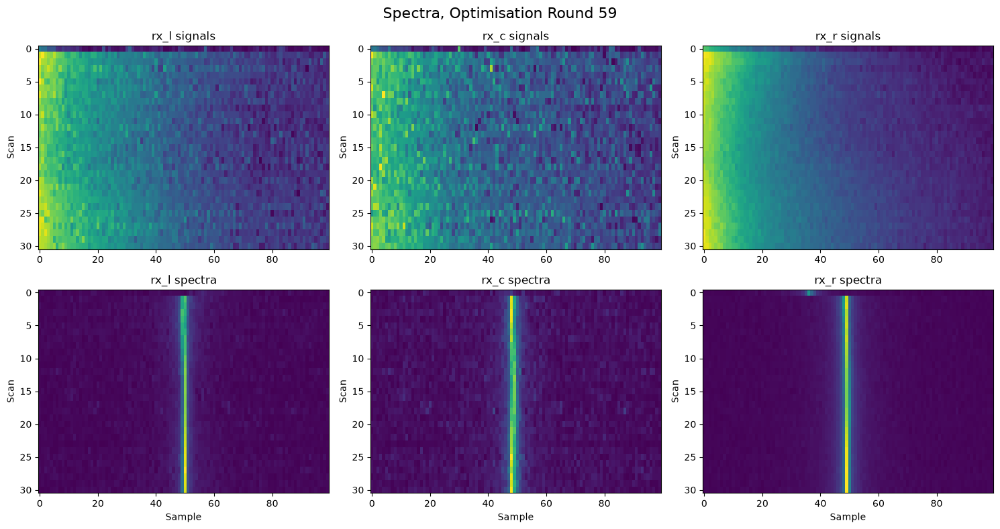

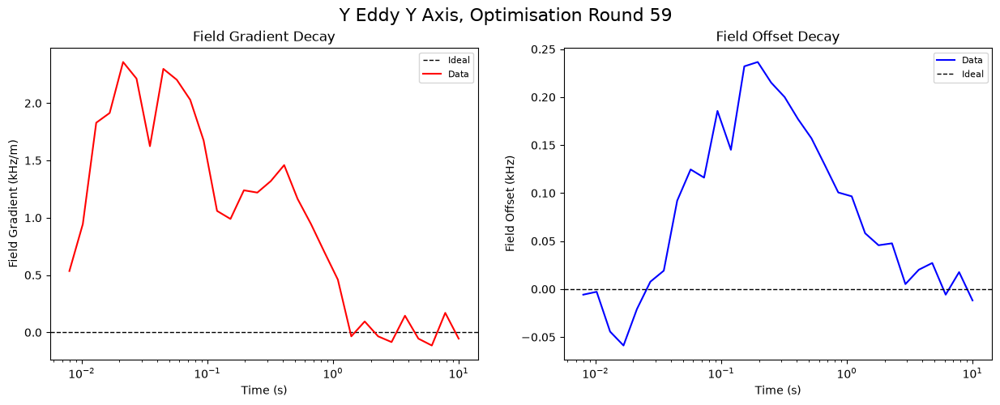

[I 2026-11-25 15:26:18,997] Trial 59 finished with value: 2131.3427612335367 and parameters: {'Y_A1': 0.059694505831733524, 'Y_A2': 0.13814352967730772, 'Y_A3': 0.10488733309327548, 'Y_A4': 2.0274429947957745e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 7696.1519240379785
mean |E| = 6574.212893553222
RMS E = 6624.626845923627
Total cost = 2.131e+03
E max = 0.1349693635419484
E nanmax = 0.1349693635419484
E contains nan = False
B max = 0.26238504403696766
B nanmax = 0.26238504403696766
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26238504403696766 !!!!!!!!!!!!!!!!


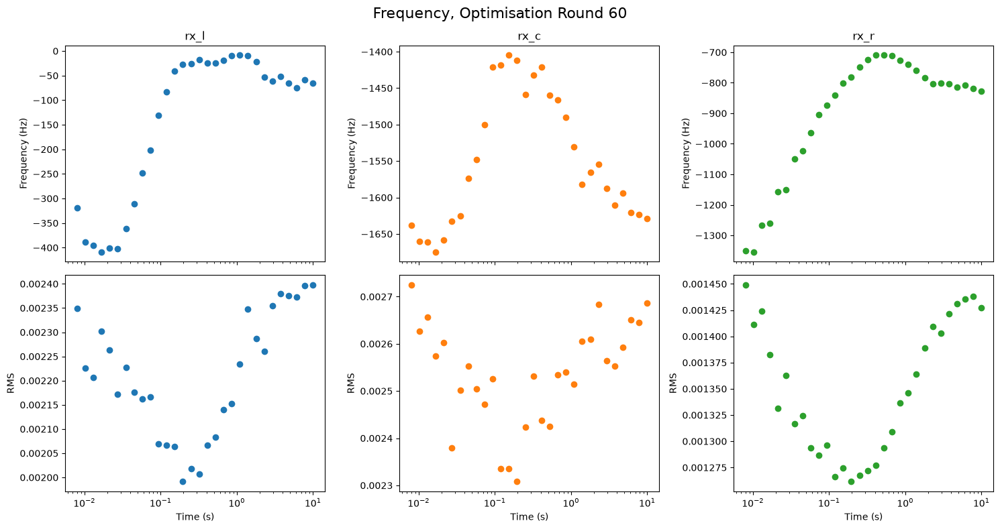

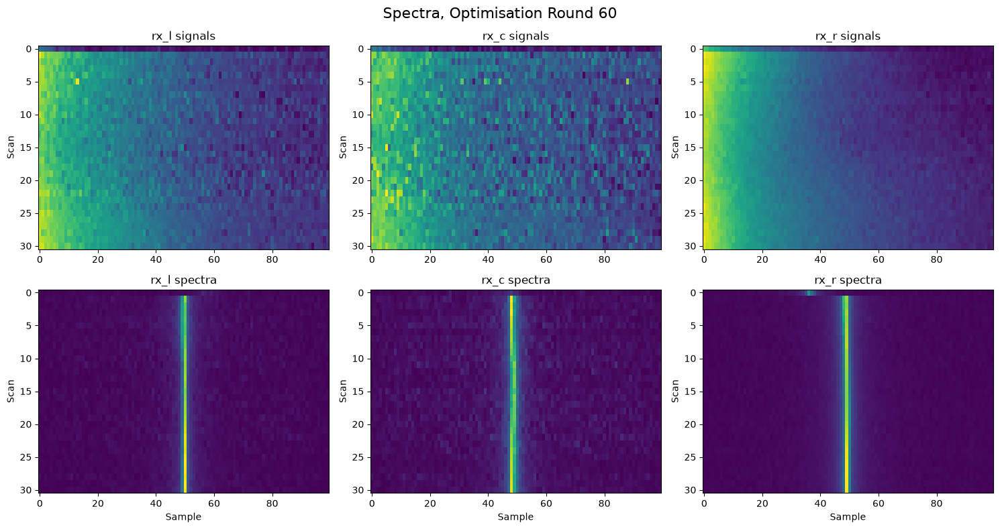

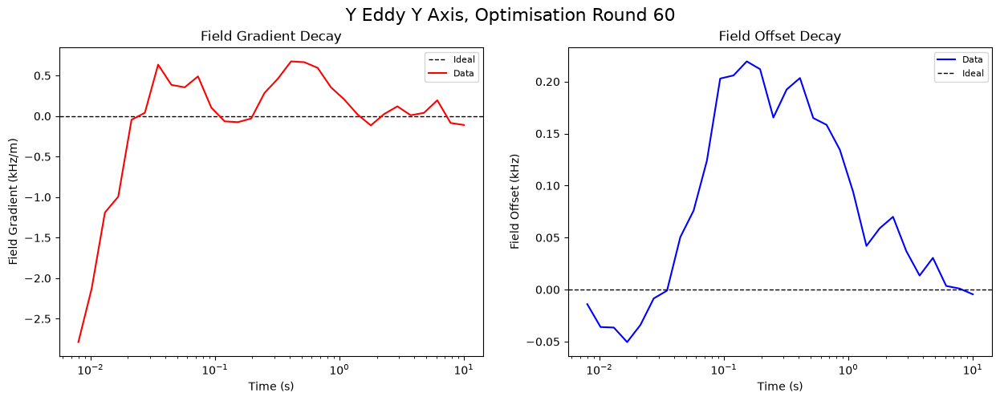

[I 2026-11-25 15:27:06,748] Trial 60 finished with value: 1285.344256714872 and parameters: {'Y_A1': 0.049414517032504615, 'Y_A2': 0.13026402937815243, 'Y_A3': 0.10634280978627866, 'Y_A4': 1.134295771381276e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10309.845077461265
mean |E| = 7586.873230051639
RMS E = 7624.834906941593
Total cost = 1.285e+03
E max = 0.13667935904013304
E nanmax = 0.13667935904013304
E contains nan = False
B max = 0.2657092955284474
B nanmax = 0.2657092955284474
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2657092955284474 !!!!!!!!!!!!!!!!


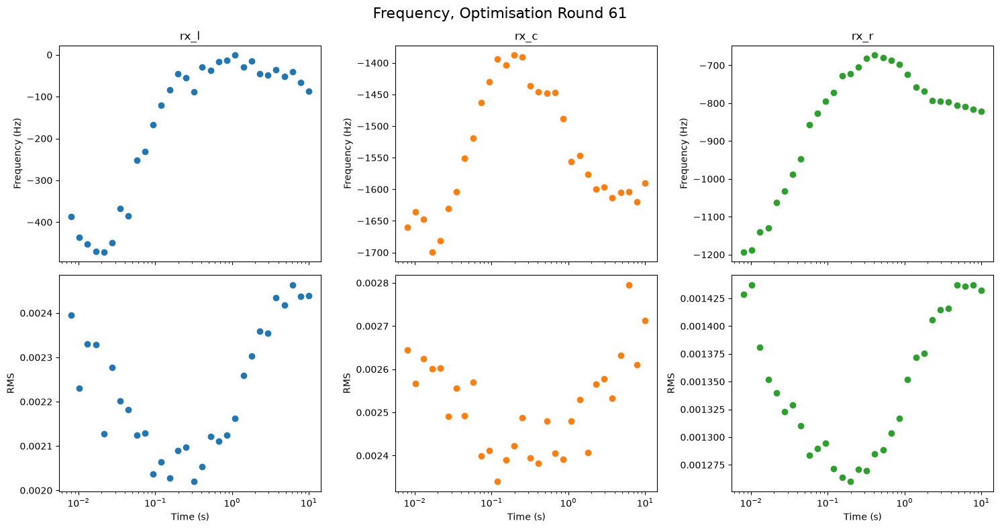

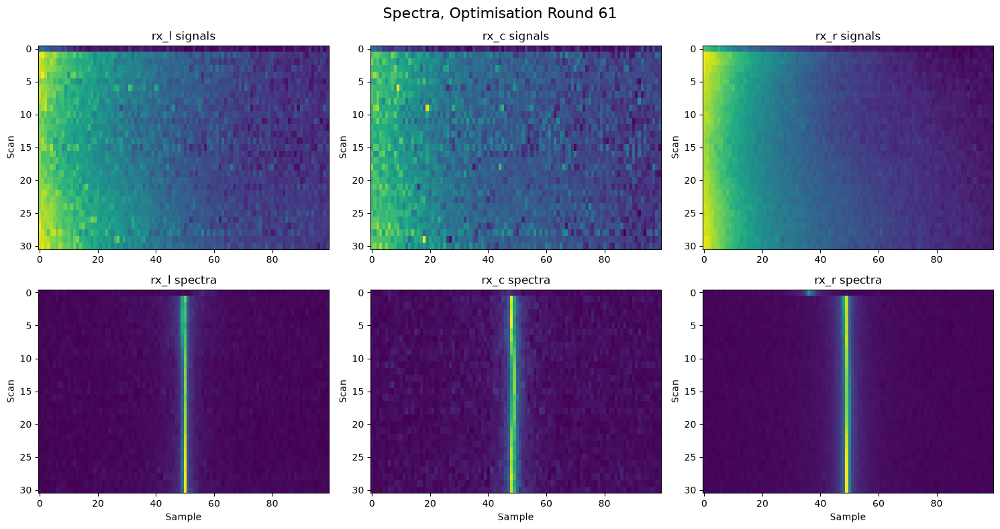

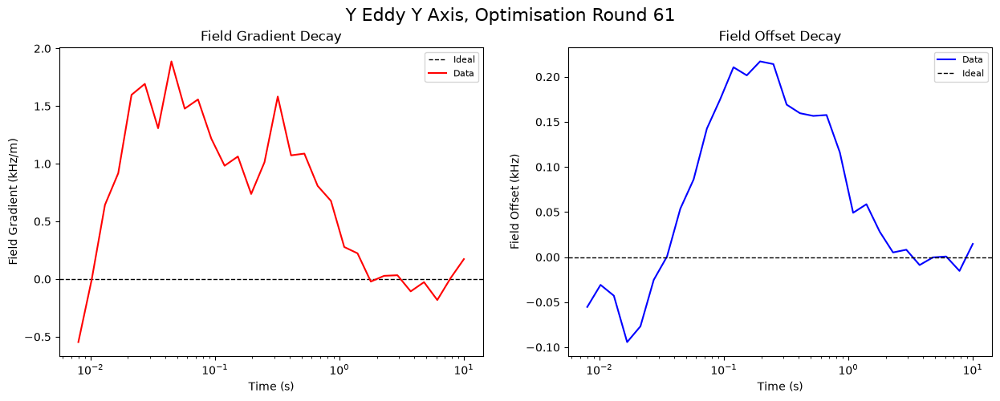

[I 2026-11-25 15:27:54,731] Trial 61 finished with value: 1773.5547503600021 and parameters: {'Y_A1': 0.057349259869952686, 'Y_A2': 0.1372794327939242, 'Y_A3': 0.10312496005345544, 'Y_A4': 2.6105579328791984e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 8055.972013993002
mean |E| = 6803.598200899549
RMS E = 6835.869796047842
Total cost = 1.774e+03
E max = 0.1354015510615648
E nanmax = 0.1354015510615648
E contains nan = False
B max = 0.2632252271084828
B nanmax = 0.2632252271084828
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2632252271084828 !!!!!!!!!!!!!!!!


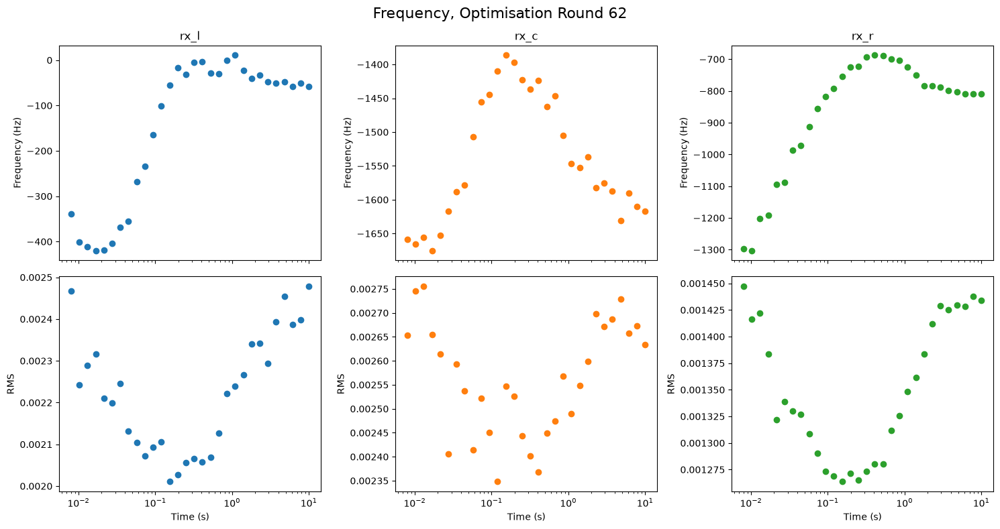

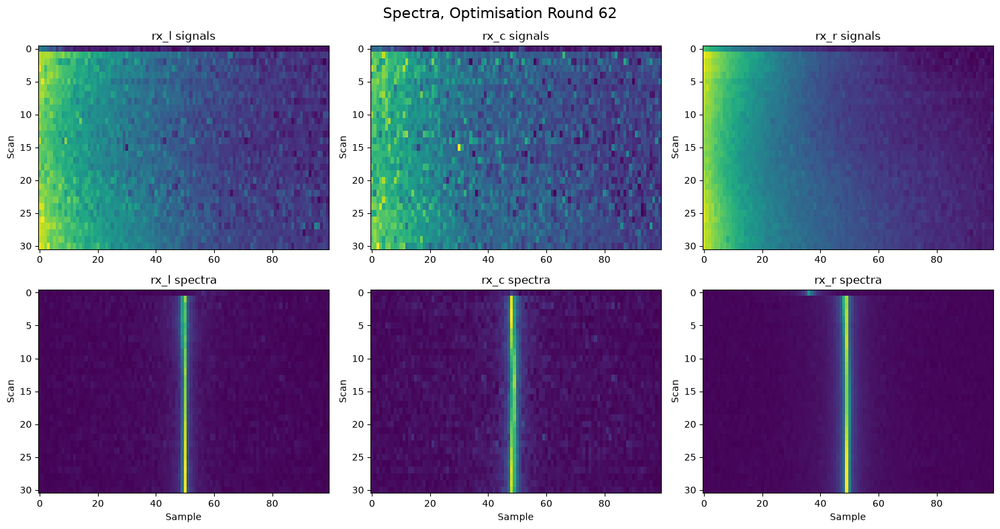

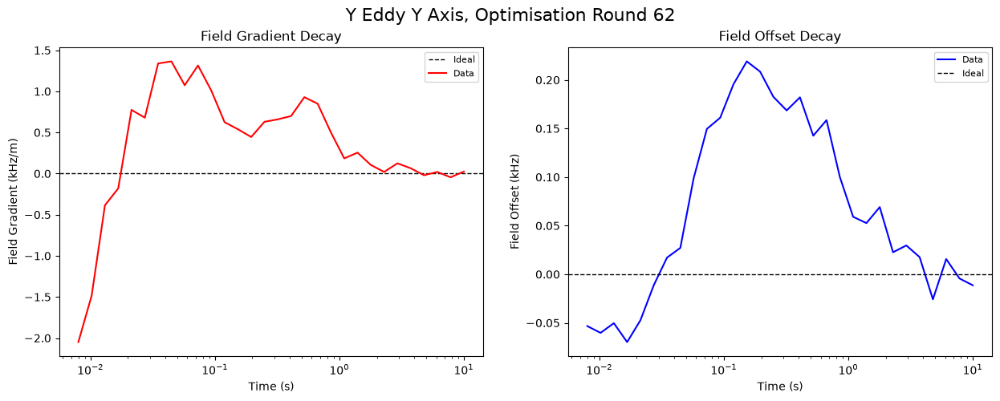

[I 2026-11-25 15:28:42,539] Trial 62 finished with value: 1214.0426895950666 and parameters: {'Y_A1': 0.050732813942354675, 'Y_A2': 0.13466598621161327, 'Y_A3': 0.10345030614009174, 'Y_A4': -2.01540002524339e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9580.20989505247
mean |E| = 7195.5688822255515
RMS E = 7232.510183365104
Total cost = 1.214e+03
E max = 0.13542732481165623
E nanmax = 0.13542732481165623
E contains nan = False
B max = 0.2632753438191492
B nanmax = 0.2632753438191492
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2632753438191492 !!!!!!!!!!!!!!!!


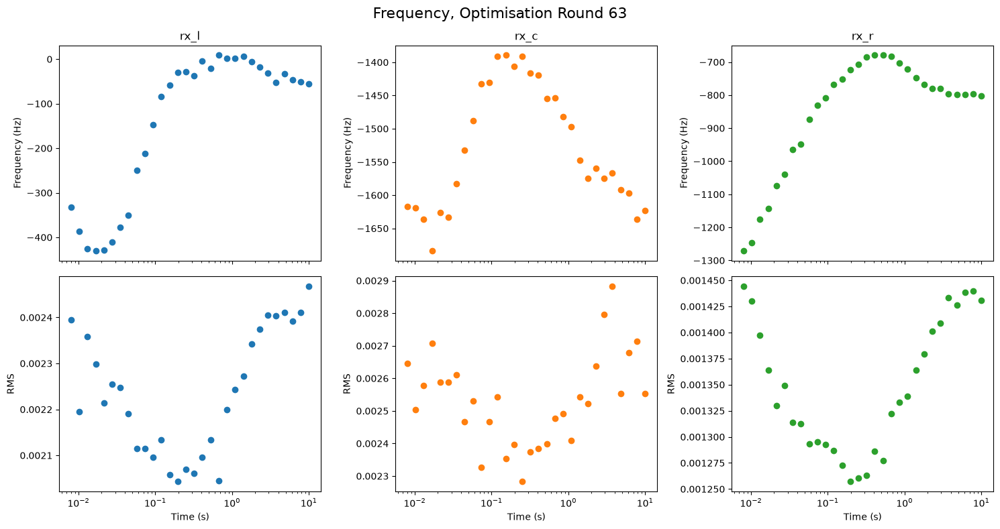

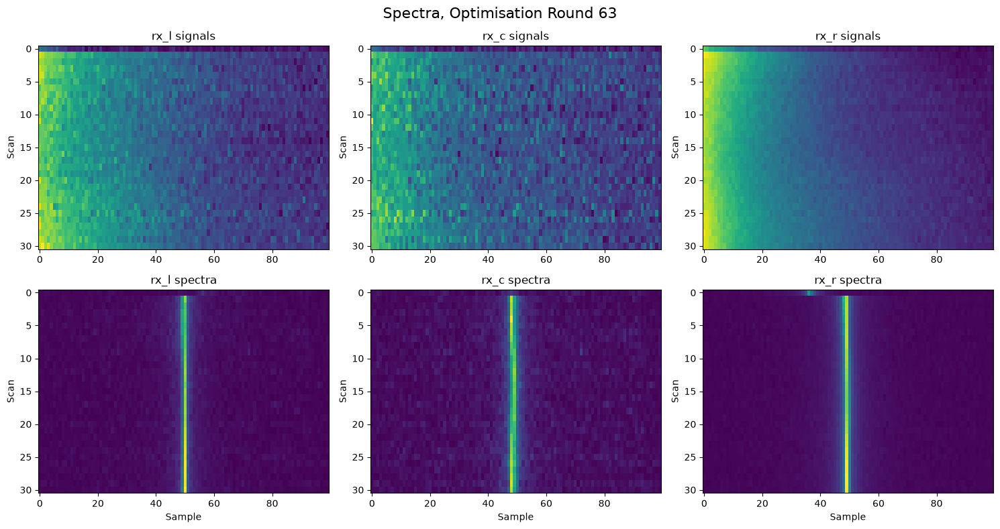

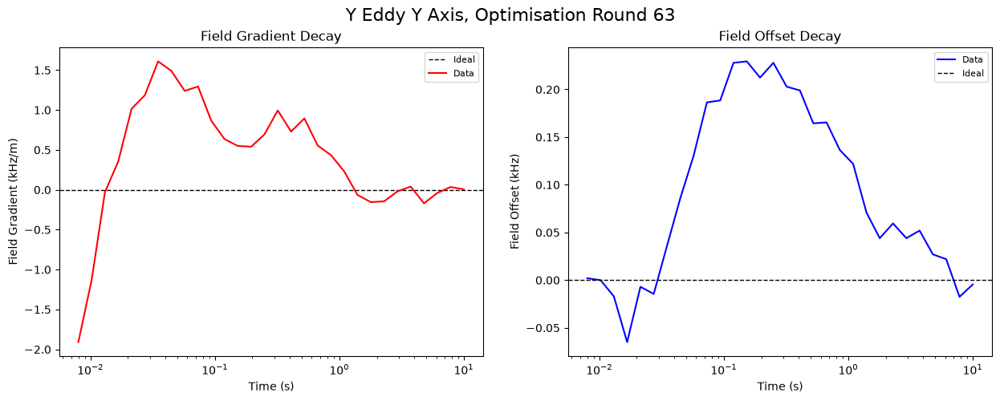

[I 2026-11-25 15:29:30,524] Trial 63 finished with value: 1298.472490307689 and parameters: {'Y_A1': 0.04788423380655879, 'Y_A2': 0.13509159258210754, 'Y_A3': 0.1057808805975559, 'Y_A4': 2.7370592709282517e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9385.307346326834
mean |E| = 7085.4572713643165
RMS E = 7123.219103598656
Total cost = 1.298e+03
E max = 0.13448207283773816
E nanmax = 0.13448207283773816
E contains nan = False
B max = 0.26143770676618244
B nanmax = 0.26143770676618244
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26143770676618244 !!!!!!!!!!!!!!!!


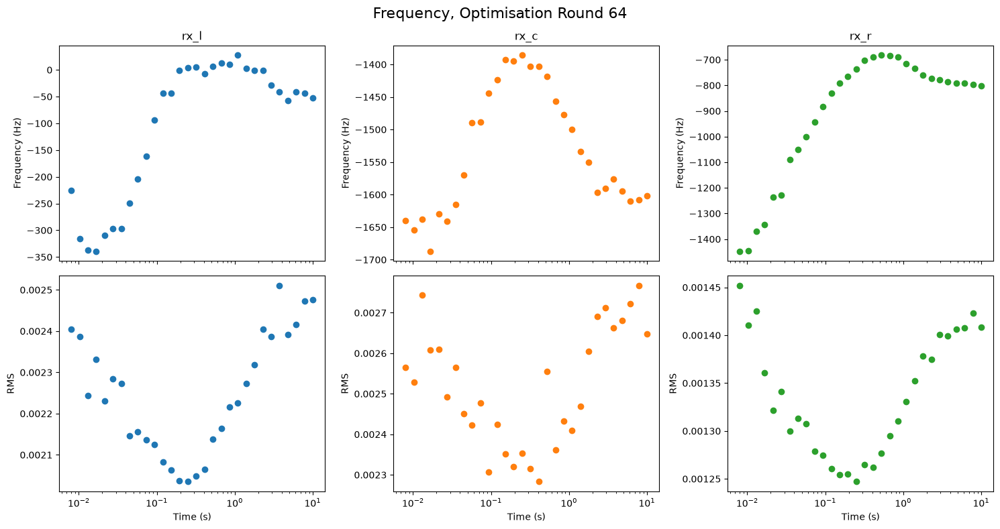

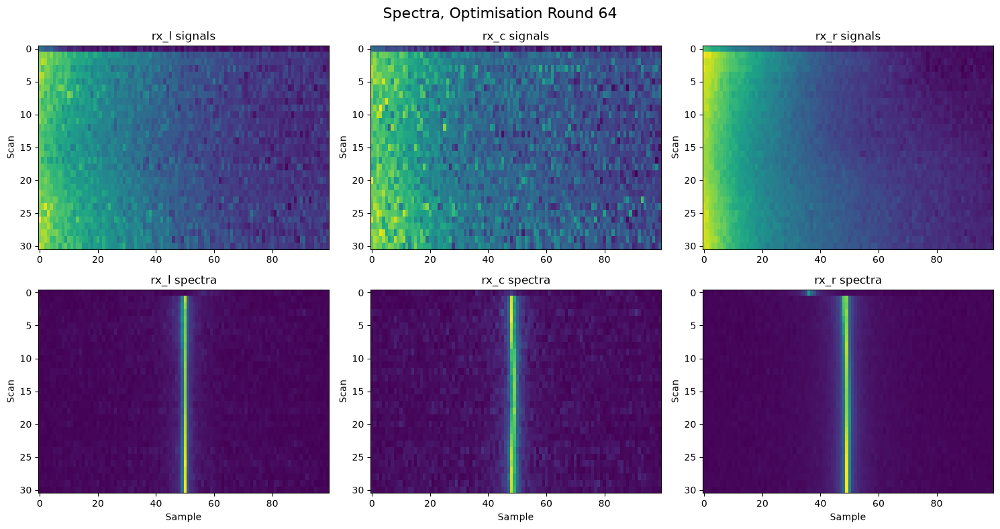

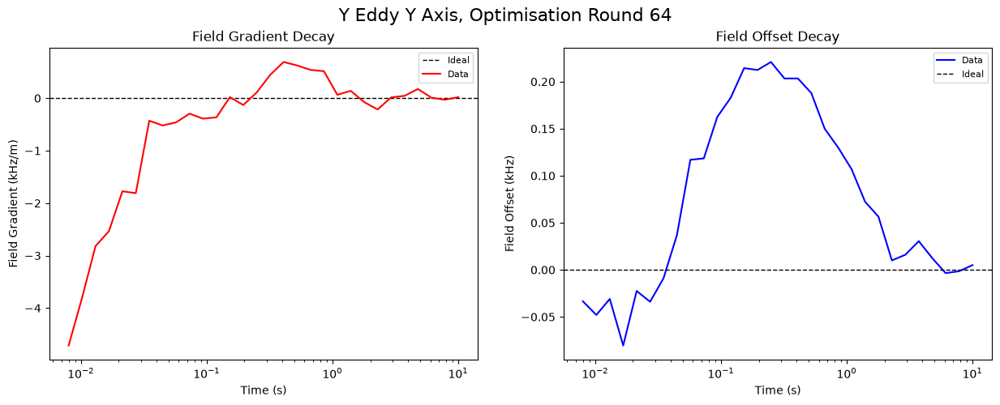

[I 2026-11-25 15:30:18,429] Trial 64 finished with value: 1074.3327899597816 and parameters: {'Y_A1': 0.05731597005152381, 'Y_A2': 0.13115298070281392, 'Y_A3': 0.09485971680618167, 'Y_A4': 2.197445385840517e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12218.890554722635
mean |E| = 8071.131101116106
RMS E = 8175.117526899416
Total cost = 1.074e+03
E max = 0.13381671927174177
E nanmax = 0.13381671927174177
E contains nan = False
B max = 0.26014425139793934
B nanmax = 0.26014425139793934
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26014425139793934 !!!!!!!!!!!!!!!!


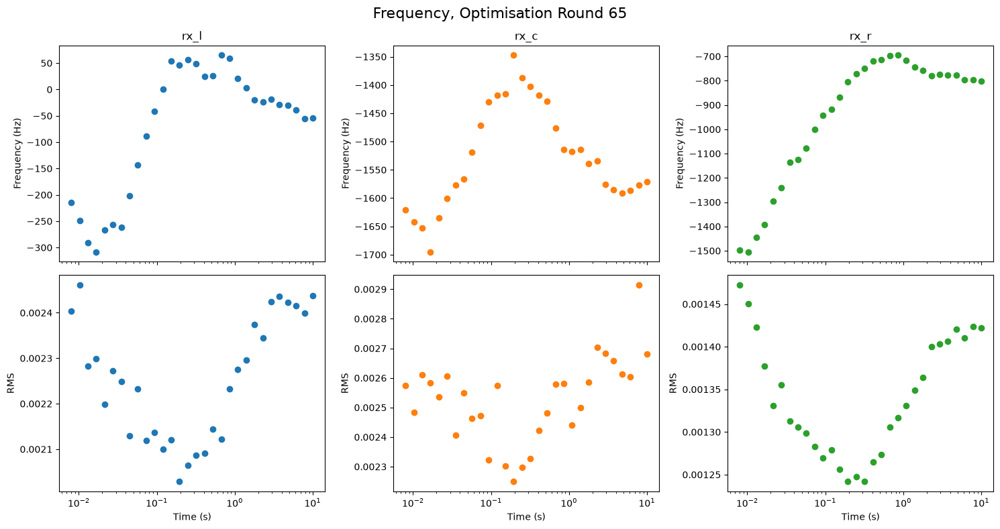

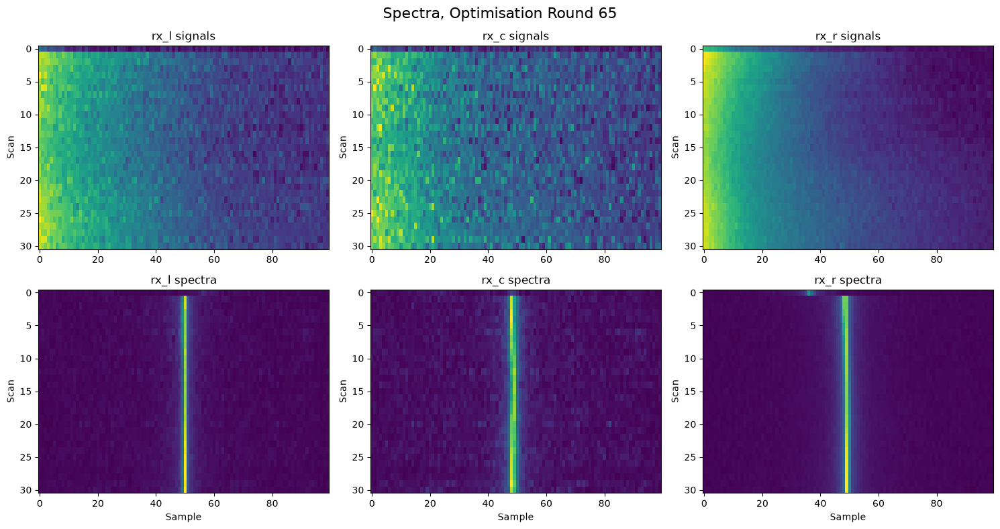

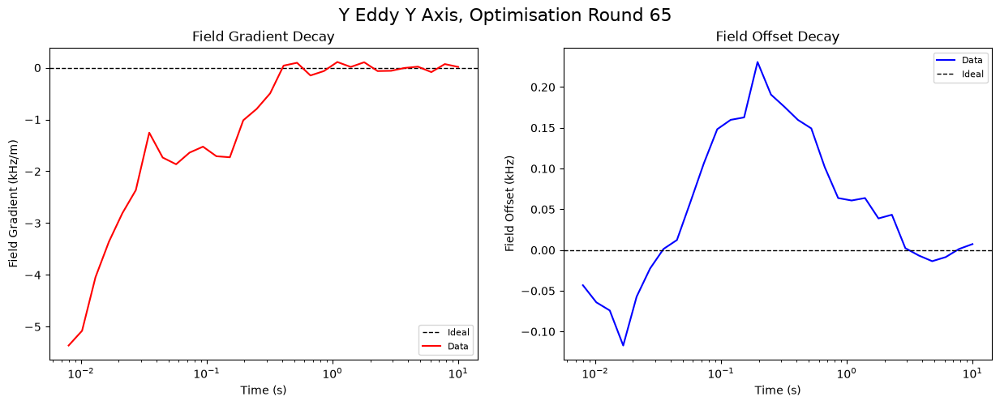

[I 2026-11-25 15:31:06,318] Trial 65 finished with value: 980.1499171584511 and parameters: {'Y_A1': 0.05291990104540914, 'Y_A2': 0.12265342239685516, 'Y_A3': 0.1032486570205956, 'Y_A4': 1.474026982088743e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12843.57821089455
mean |E| = 8705.64717641179
RMS E = 8841.70654802425
Total cost = 9.801e+02
E max = 0.13504438908997388
E nanmax = 0.13504438908997388
E contains nan = False
B max = 0.26253085076444665
B nanmax = 0.26253085076444665
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26253085076444665 !!!!!!!!!!!!!!!!


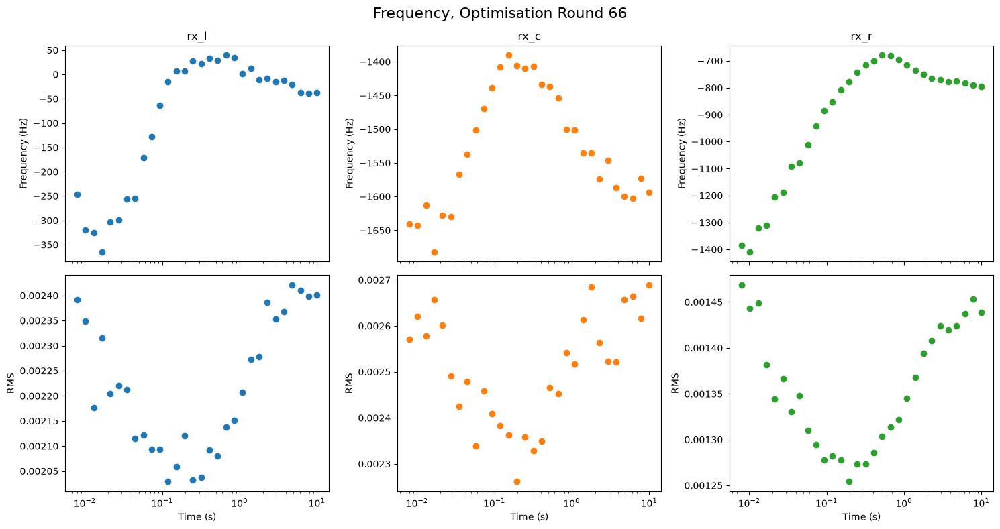

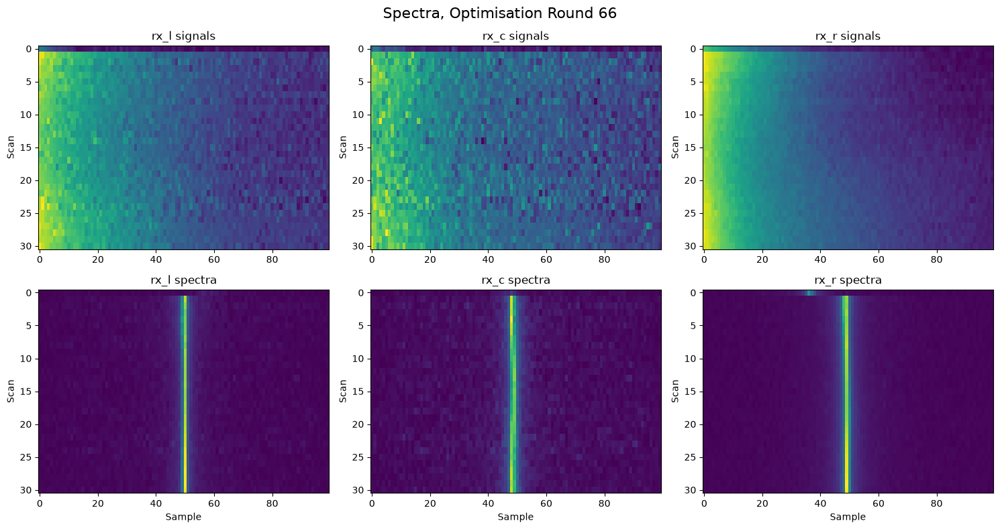

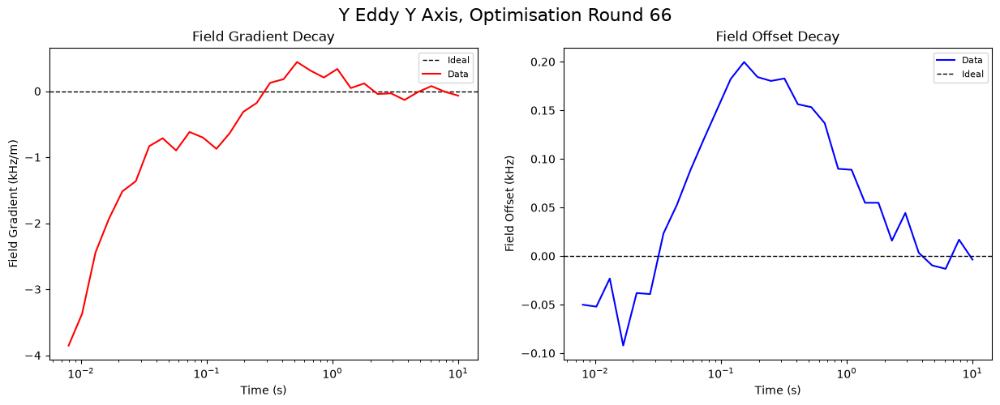

[I 2026-11-25 15:31:54,517] Trial 66 finished with value: 914.2163861628959 and parameters: {'Y_A1': 0.059926409816159515, 'Y_A2': 0.12783650224030893, 'Y_A3': 0.09968898791983939, 'Y_A4': 3.3168812987830844e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11369.315342328831
mean |E| = 8141.09611860736
RMS E = 8208.63908121572
Total cost = 9.142e+02
E max = 0.13354675942572572
E nanmax = 0.13354675942572572
E contains nan = False
B max = 0.25961945639958217
B nanmax = 0.25961945639958217
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25961945639958217 !!!!!!!!!!!!!!!!


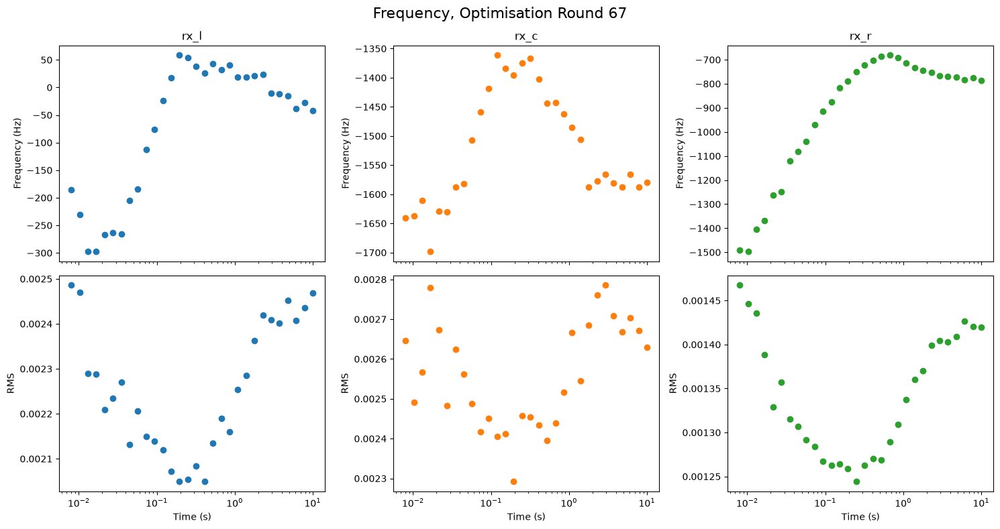

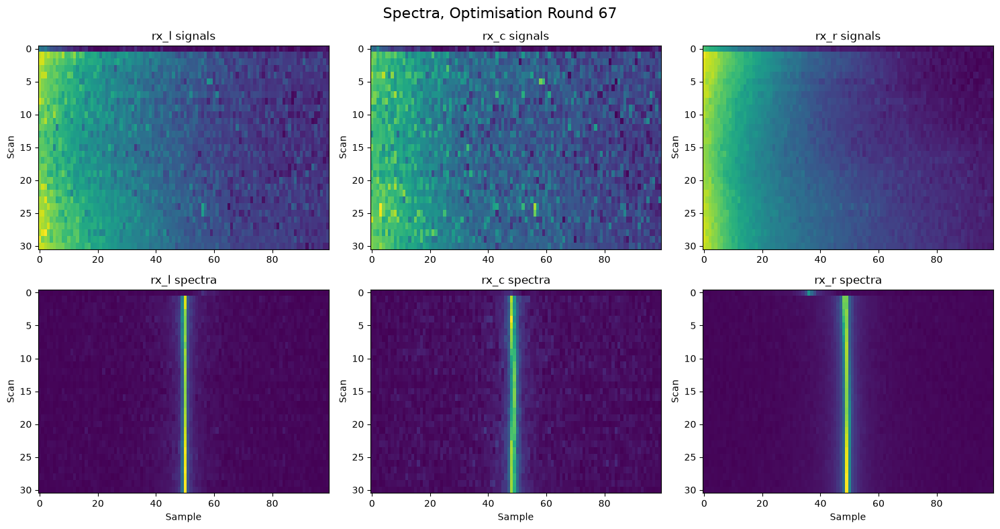

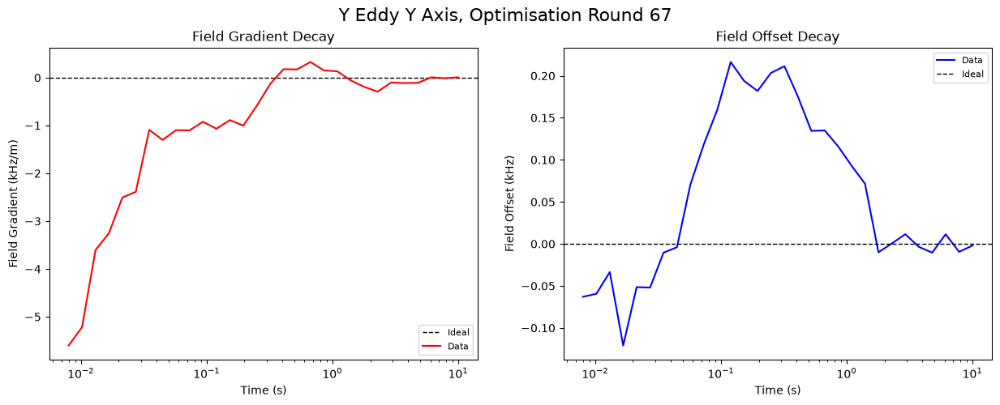

[I 2026-11-25 15:32:42,457] Trial 67 finished with value: 1104.085465611752 and parameters: {'Y_A1': 0.05007204012333584, 'Y_A2': 0.12569911664159444, 'Y_A3': 0.10089371477516826, 'Y_A4': 2.824220955481155e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13058.470764617688
mean |E| = 8514.07629518574
RMS E = 8650.999547078638
Total cost = 1.104e+03
E max = 0.13449786061163835
E nanmax = 0.13449786061163835
E contains nan = False
B max = 0.2614683953101055
B nanmax = 0.2614683953101055
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2614683953101055 !!!!!!!!!!!!!!!!


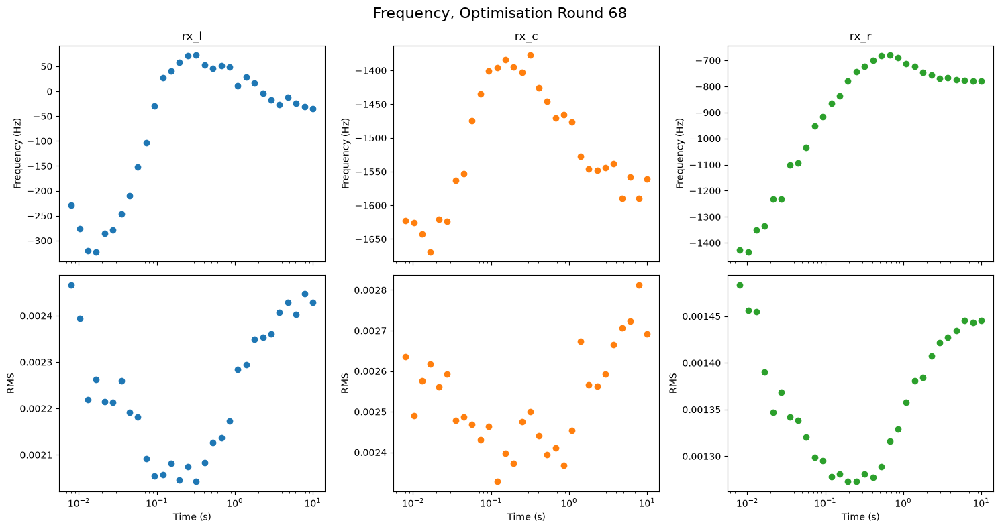

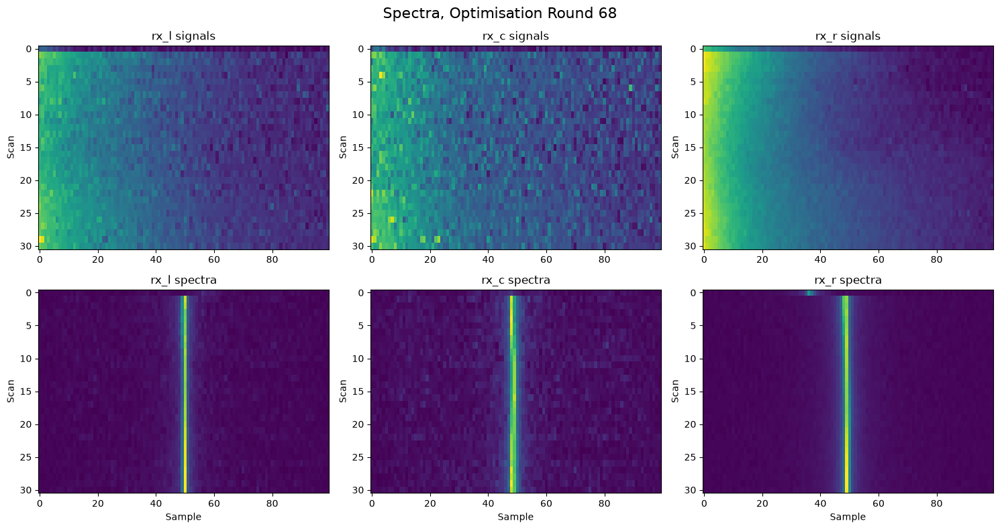

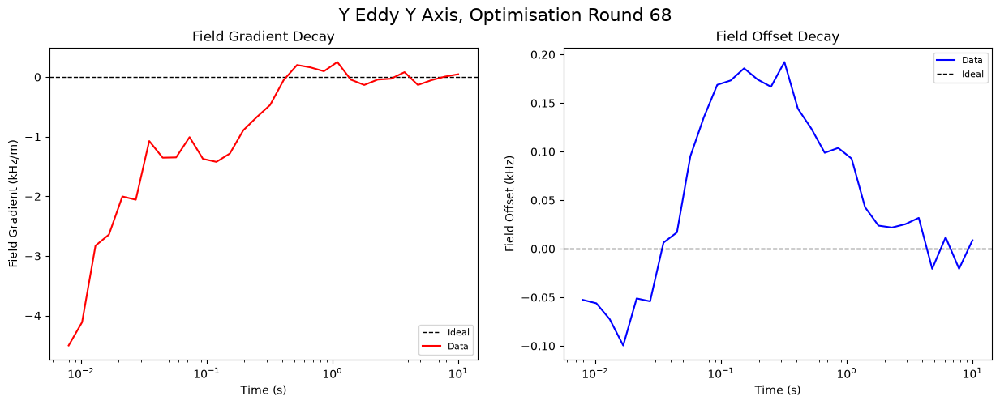

[I 2026-11-25 15:33:30,188] Trial 68 finished with value: 1012.8934284663763 and parameters: {'Y_A1': 0.056602540563323096, 'Y_A2': 0.12453919111756931, 'Y_A3': 0.10250596997321458, 'Y_A4': -1.1597786116644815e-11}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11984.007996001996
mean |E| = 8438.780609695152
RMS E = 8529.137742048106
Total cost = 1.013e+03
E max = 0.13625641034900318
E nanmax = 0.13625641034900318
E contains nan = False
B max = 0.2648870618232386
B nanmax = 0.2648870618232386
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2648870618232386 !!!!!!!!!!!!!!!!


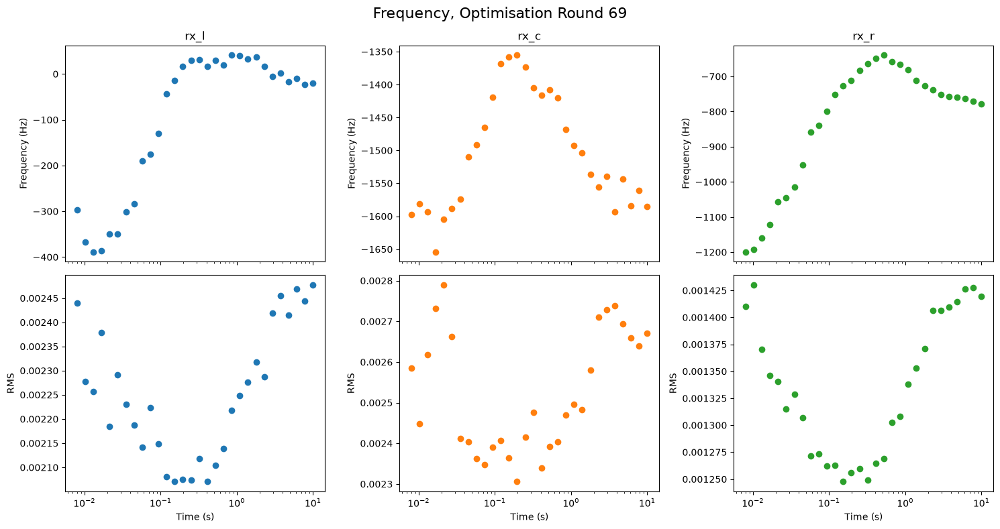

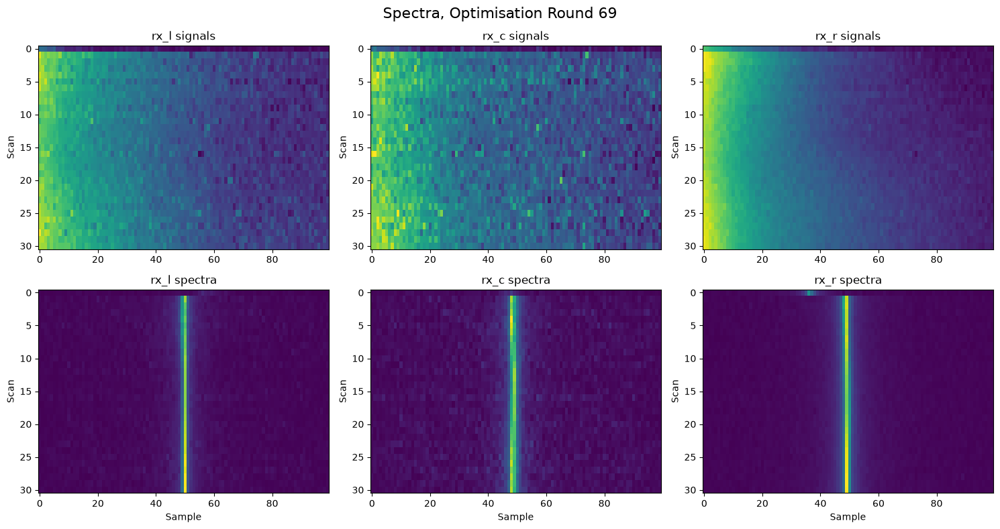

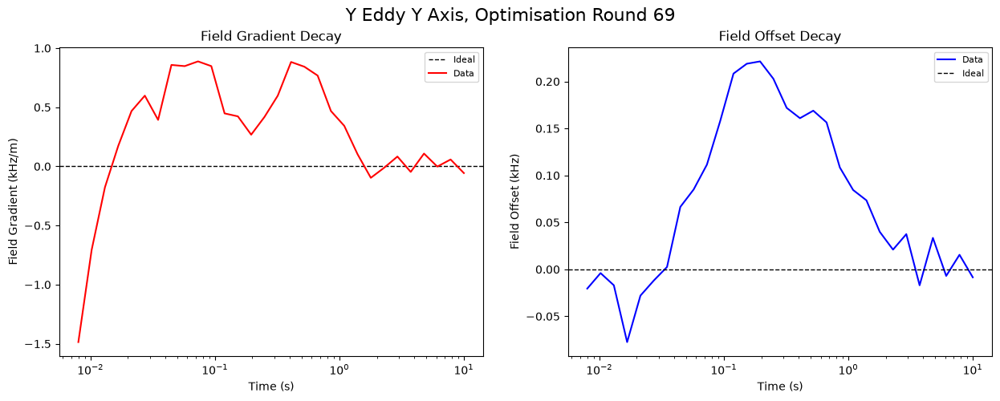

[I 2026-11-25 15:34:18,208] Trial 69 finished with value: 1202.8157329042147 and parameters: {'Y_A1': 0.05871600765645813, 'Y_A2': 0.1325681277907315, 'Y_A3': 0.10397793513667926, 'Y_A4': 5.690052383735434e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9025.48725637181
mean |E| = 7262.70198234216
RMS E = 7280.145801674736
Total cost = 1.203e+03
E max = 0.13596586294990537
E nanmax = 0.13596586294990537
E contains nan = False
B max = 0.26432222633276
B nanmax = 0.26432222633276
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26432222633276 !!!!!!!!!!!!!!!!


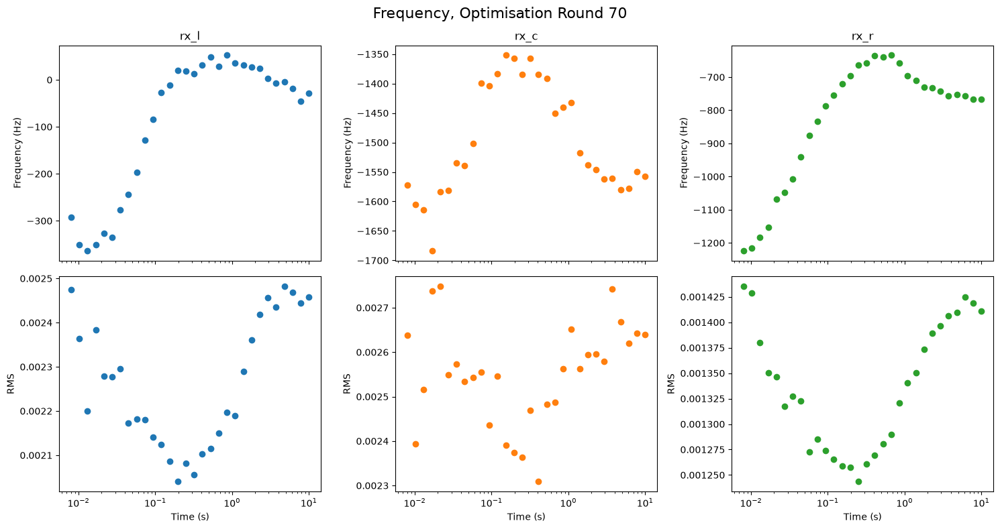

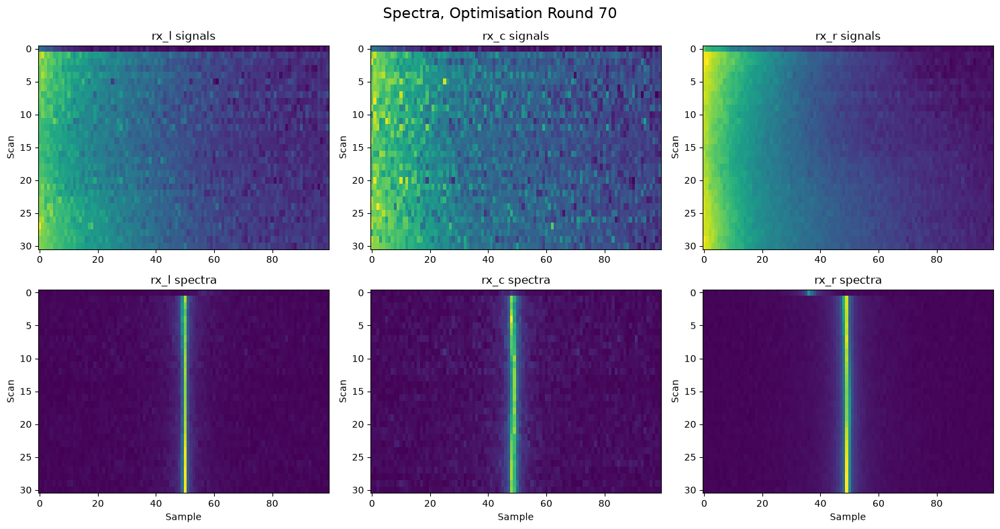

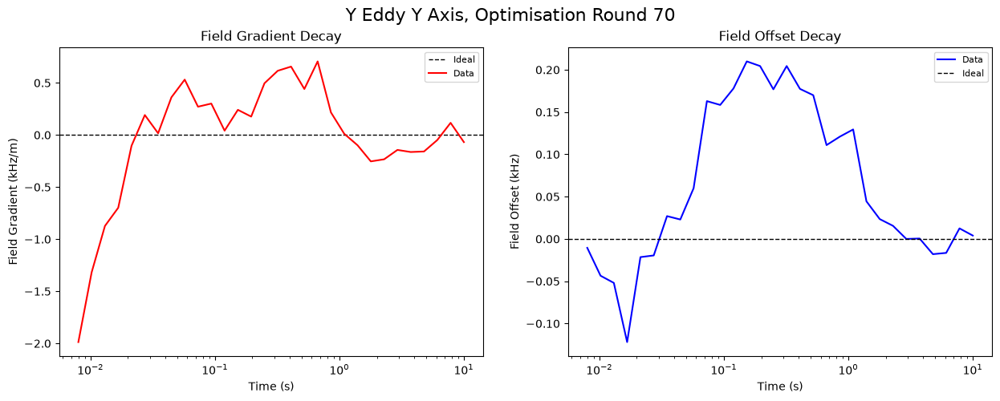

[I 2026-11-25 15:35:06,872] Trial 70 finished with value: 1523.2078160757176 and parameters: {'Y_A1': 0.05992235852304616, 'Y_A2': 0.1339956620472549, 'Y_A3': 0.09944006204343436, 'Y_A4': 1.9613743104957548e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9310.344827586205
mean |E| = 7347.992670331499
RMS E = 7369.851991025153
Total cost = 1.523e+03
E max = 0.13533775376839052
E nanmax = 0.13533775376839052
E contains nan = False
B max = 0.26310119267169574
B nanmax = 0.26310119267169574
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26310119267169574 !!!!!!!!!!!!!!!!


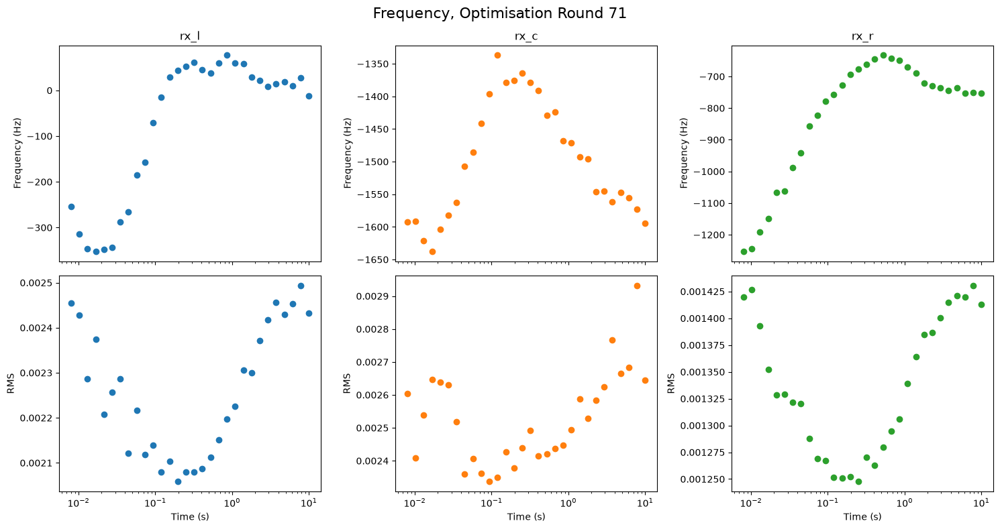

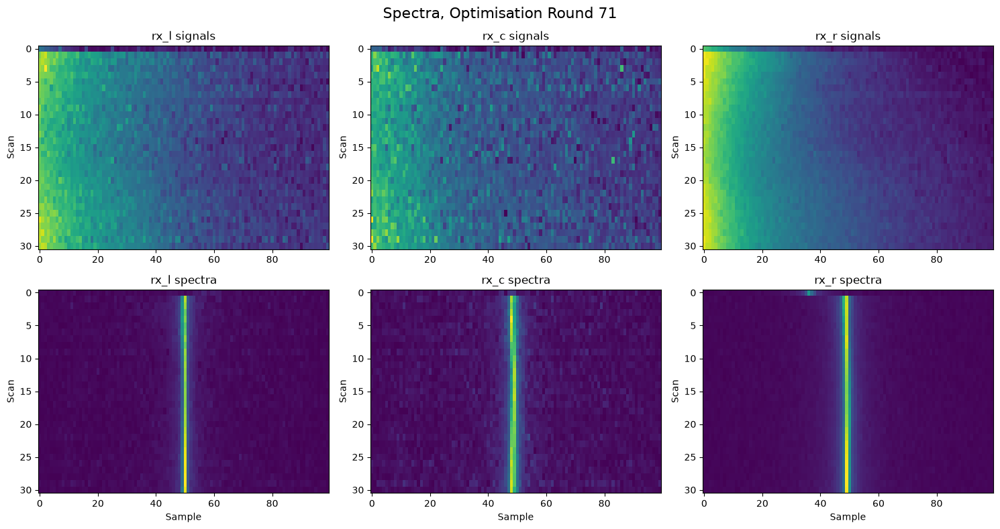

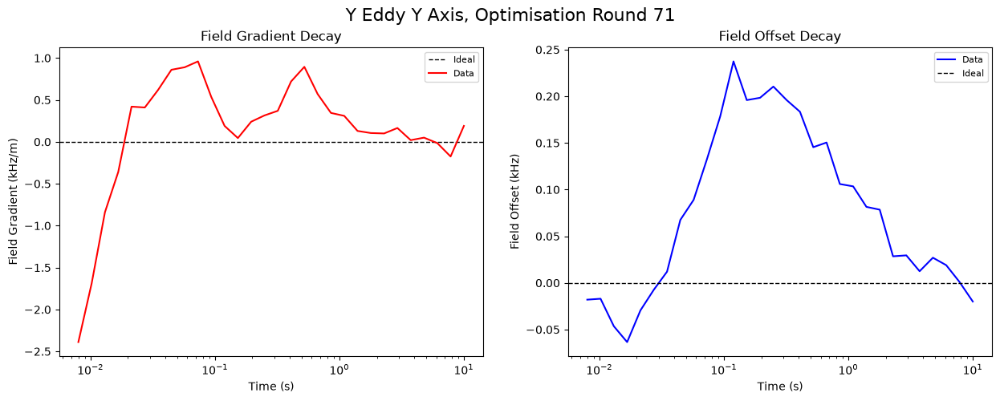

[I 2026-11-25 15:35:56,288] Trial 71 finished with value: 1498.695445415024 and parameters: {'Y_A1': 0.052638764763358374, 'Y_A2': 0.1314335239976048, 'Y_A3': 0.10464051381186644, 'Y_A4': 7.923783586283873e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9995.002498750622
mean |E| = 7473.4299516908195
RMS E = 7506.03930991936
Total cost = 1.499e+03
E max = 0.13469097032603694
E nanmax = 0.13469097032603694
E contains nan = False
B max = 0.2618437956568578
B nanmax = 0.2618437956568578
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2618437956568578 !!!!!!!!!!!!!!!!


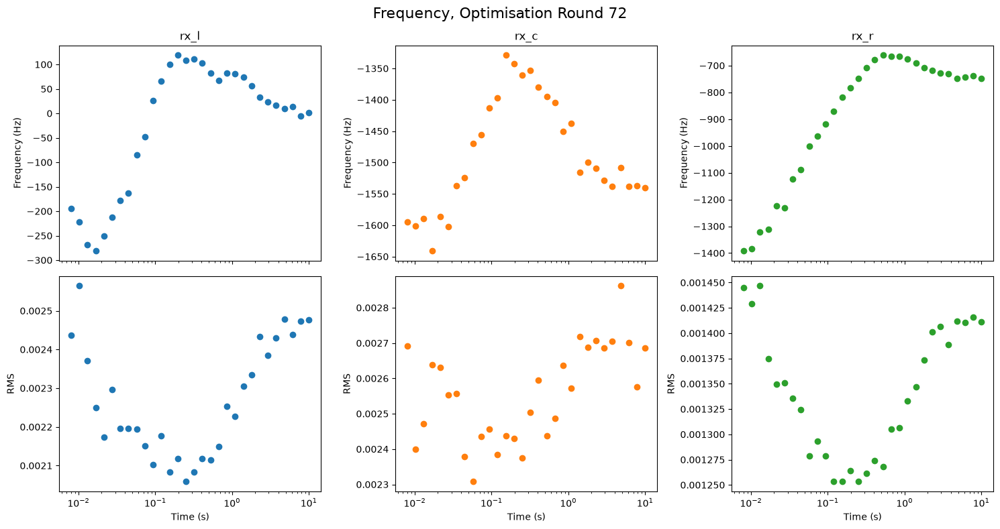

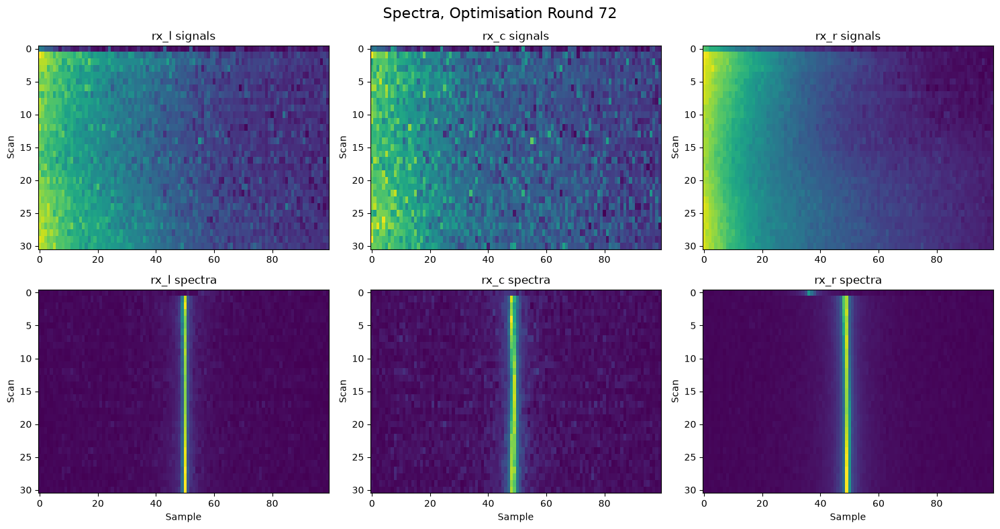

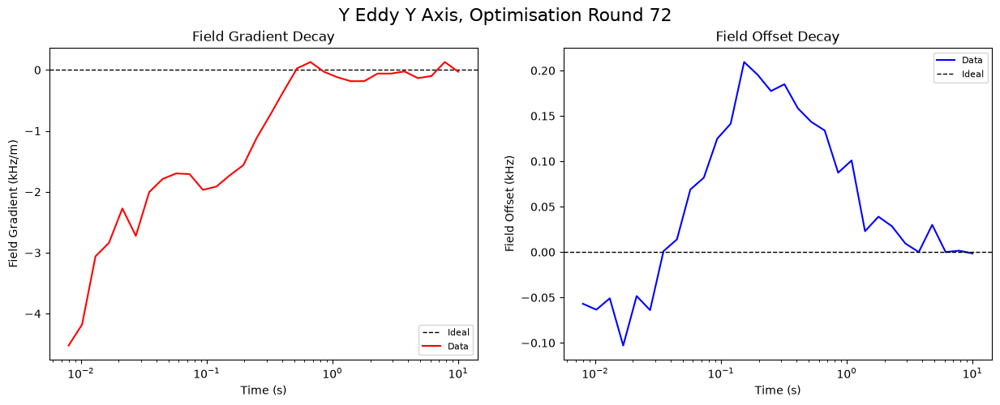

[I 2026-11-25 15:36:44,555] Trial 72 finished with value: 1476.423182337293 and parameters: {'Y_A1': 0.05816840259412056, 'Y_A2': 0.12060335741363411, 'Y_A3': 0.10640108880902363, 'Y_A4': 4.254261668587853e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11979.01049475262
mean |E| = 8683.658170914541
RMS E = 8780.589689954833
Total cost = 1.476e+03
E max = 0.13517972211612206
E nanmax = 0.13517972211612206
E contains nan = False
B max = 0.2627939759750285
B nanmax = 0.2627939759750285
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2627939759750285 !!!!!!!!!!!!!!!!


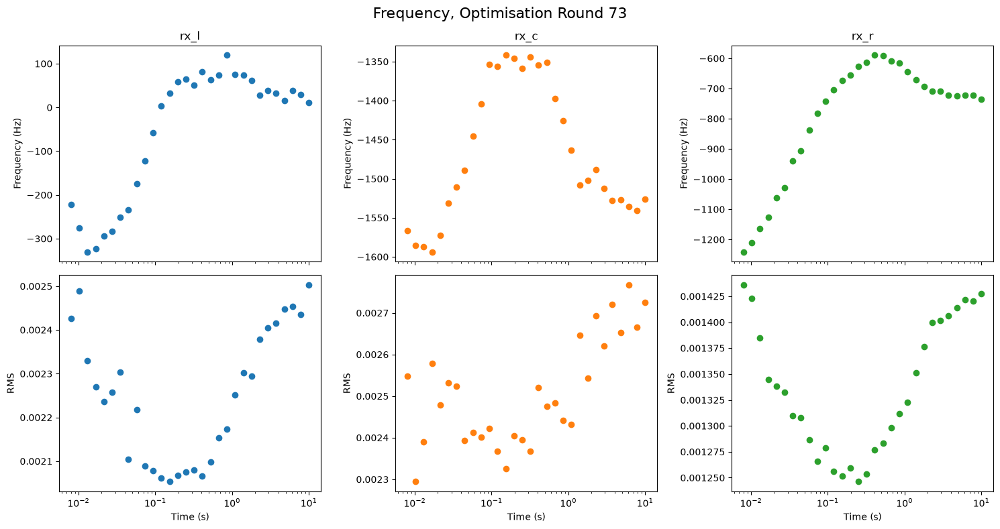

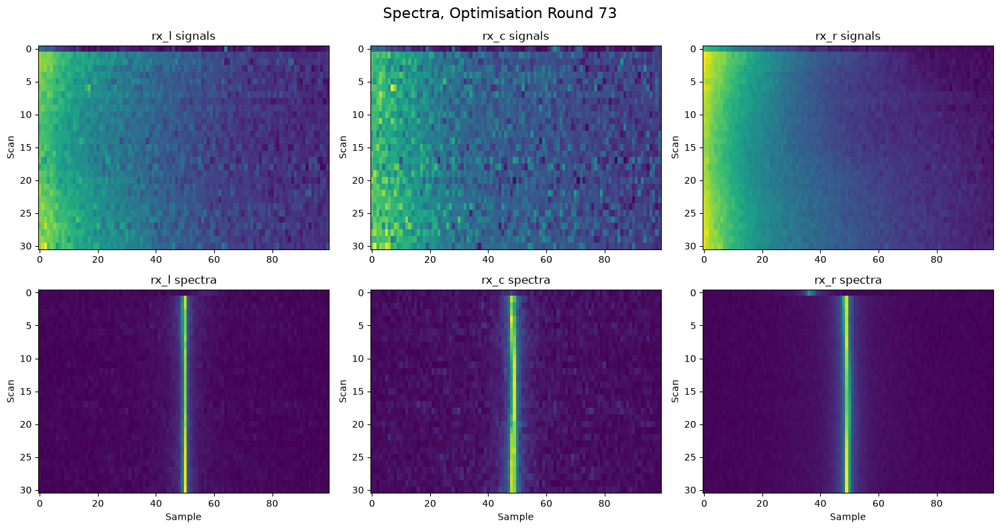

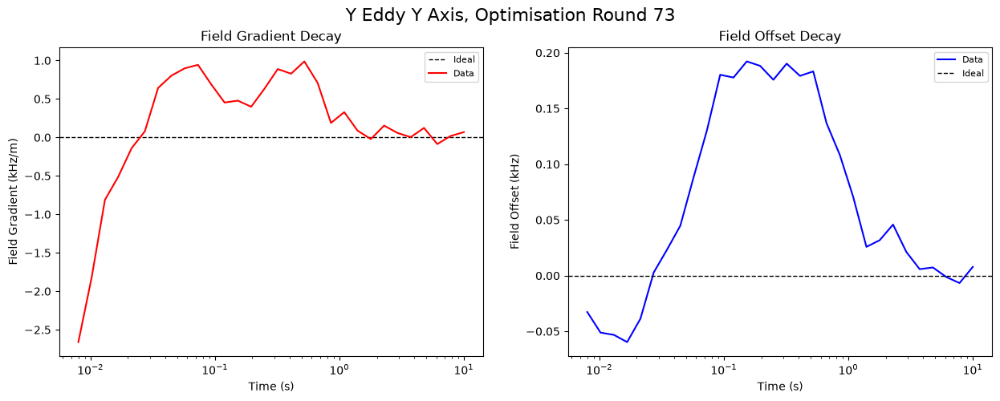

[I 2026-11-25 15:37:33,049] Trial 73 finished with value: 1254.8456465289116 and parameters: {'Y_A1': 0.05312975055712685, 'Y_A2': 0.13464555939467504, 'Y_A3': 0.09978476300852494, 'Y_A4': -6.755774656359188e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10194.902548725633
mean |E| = 7387.80609695152
RMS E = 7428.457111862244
Total cost = 1.255e+03
E max = 0.13572270663623634
E nanmax = 0.13572270663623634
E contains nan = False
B max = 0.26384955042798386
B nanmax = 0.26384955042798386
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26384955042798386 !!!!!!!!!!!!!!!!


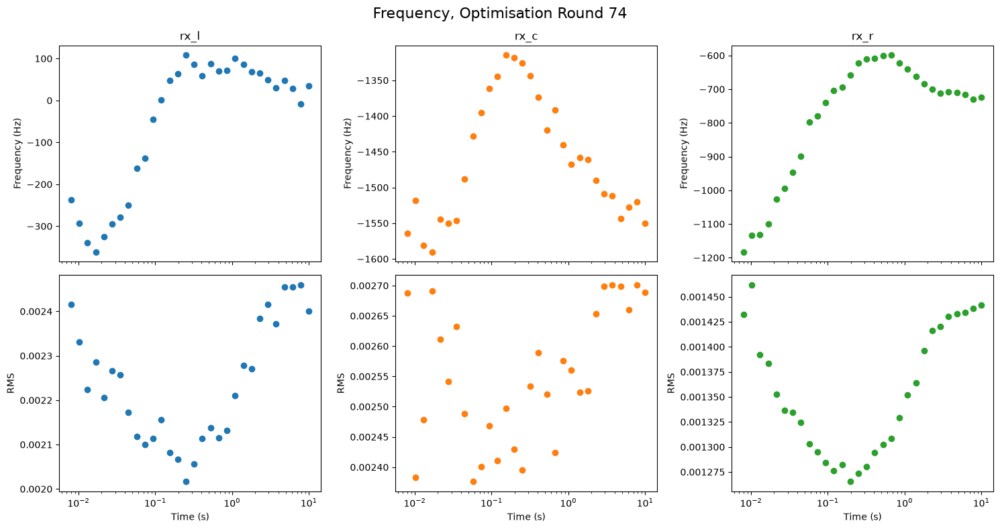

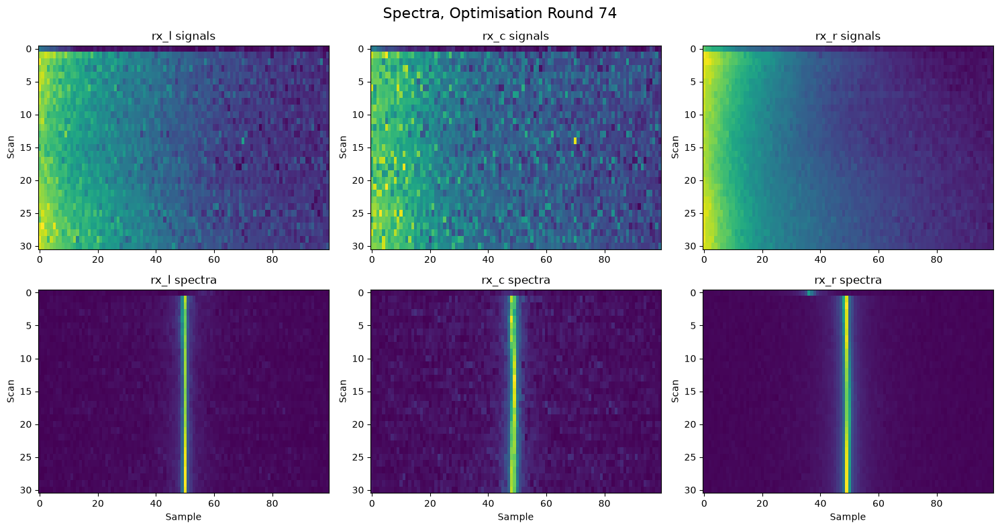

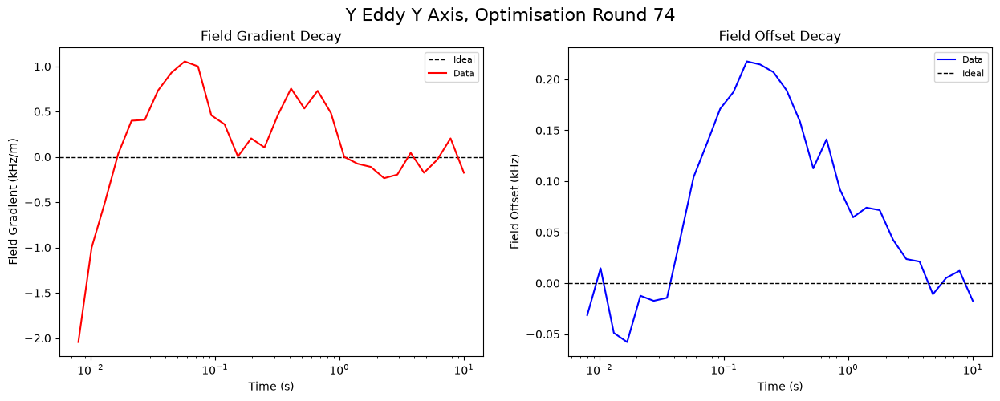

[I 2026-11-25 15:38:21,551] Trial 74 finished with value: 1739.805853399807 and parameters: {'Y_A1': 0.05311179166299027, 'Y_A2': 0.13246584703591496, 'Y_A3': 0.10569700706316676, 'Y_A4': -1.0039787146621284e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9460.269865067463
mean |E| = 7270.5314009661815
RMS E = 7295.881553193086
Total cost = 1.740e+03
E max = 0.1331703741397378
E nanmax = 0.1331703741397378
E contains nan = False
B max = 0.2588877318980713
B nanmax = 0.2588877318980713
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2588877318980713 !!!!!!!!!!!!!!!!


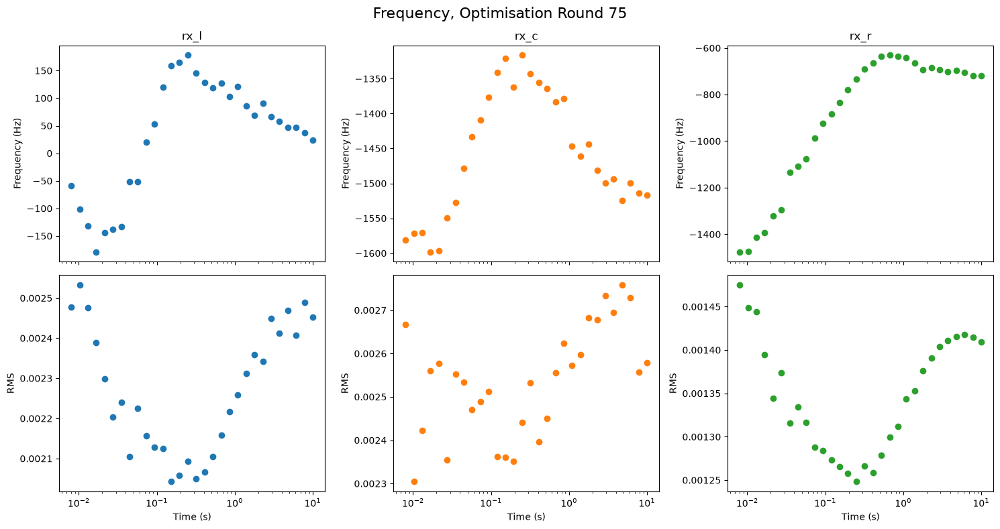

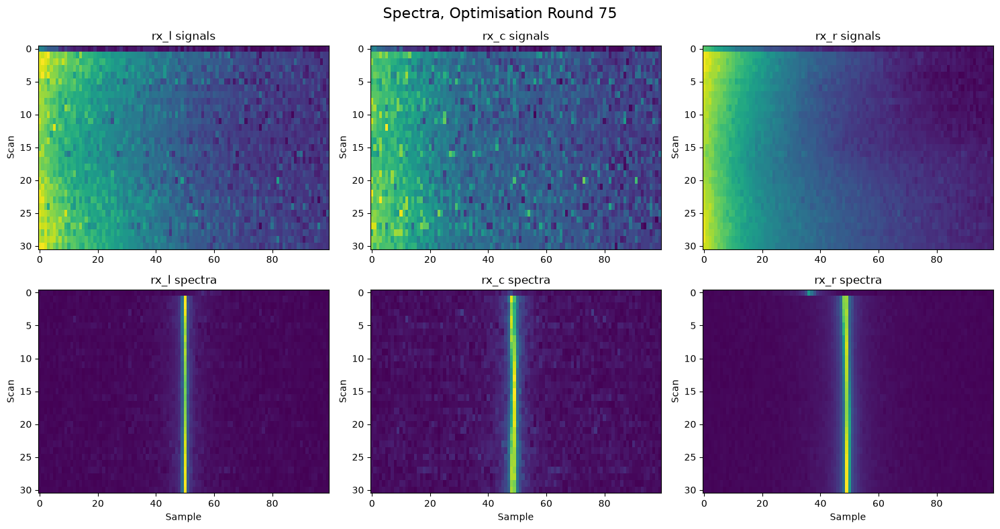

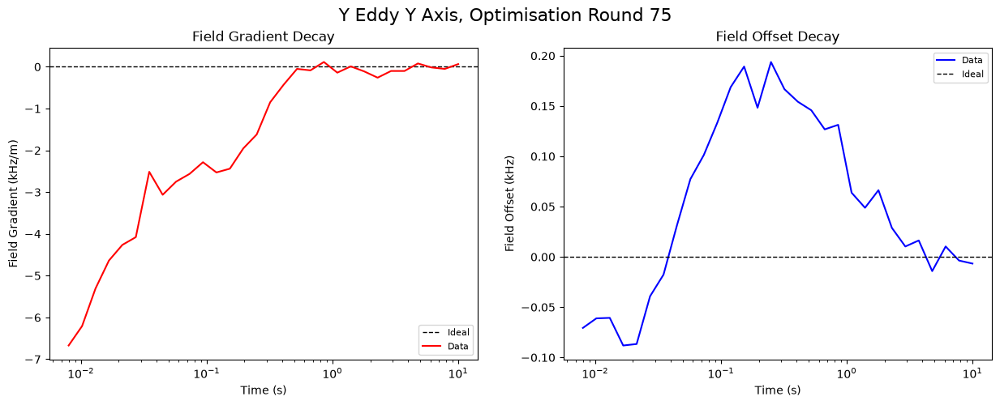

[I 2026-11-25 15:39:09,304] Trial 75 finished with value: 1513.1366716071052 and parameters: {'Y_A1': 0.05370054616320609, 'Y_A2': 0.11823929052497699, 'Y_A3': 0.10268600664783649, 'Y_A4': 2.8757173892694016e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 14172.913543228382
mean |E| = 9327.836081959018
RMS E = 9543.879753774245
Total cost = 1.513e+03
E max = 0.13369830944608738
E nanmax = 0.13369830944608738
E contains nan = False
B max = 0.25991403348841374
B nanmax = 0.25991403348841374
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25991403348841374 !!!!!!!!!!!!!!!!


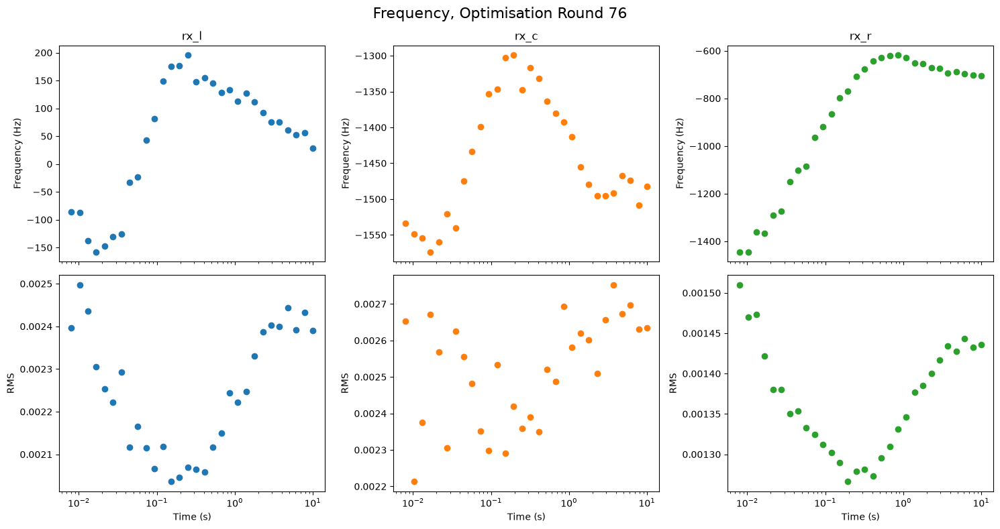

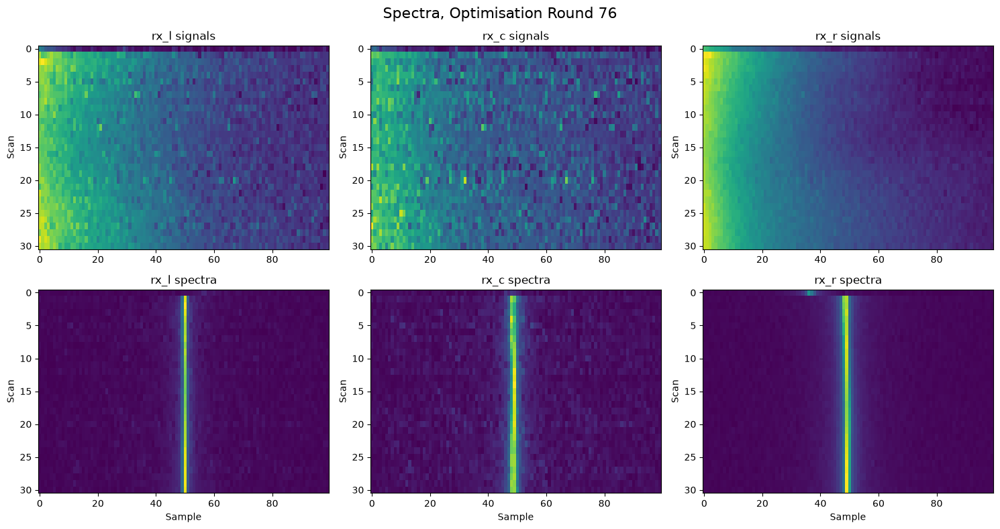

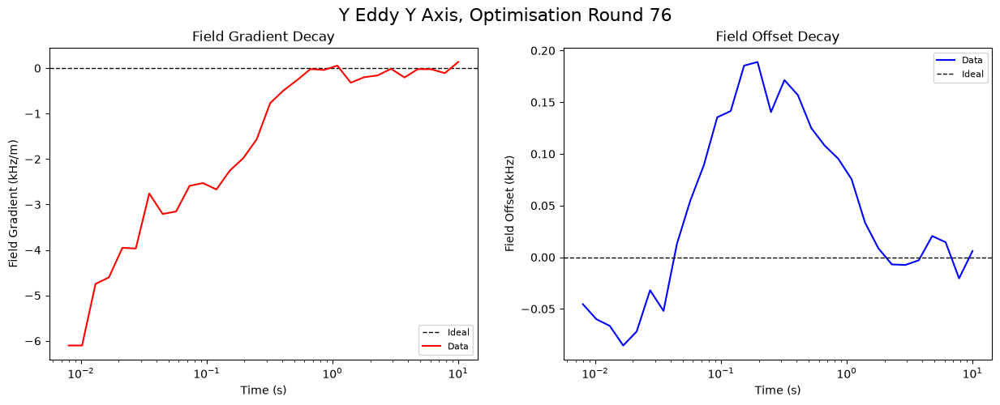

[I 2026-11-25 15:39:58,750] Trial 76 finished with value: 1759.5784260905225 and parameters: {'Y_A1': 0.05842933679692349, 'Y_A2': 0.11853051683274149, 'Y_A3': 0.10160534773203984, 'Y_A4': 1.6878371736576018e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13578.210894552722
mean |E| = 9297.184740962848
RMS E = 9493.643261255345
Total cost = 1.760e+03
E max = 0.13414525267435554
E nanmax = 0.13414525267435554
E contains nan = False
B max = 0.26078292767818445
B nanmax = 0.26078292767818445
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26078292767818445 !!!!!!!!!!!!!!!!


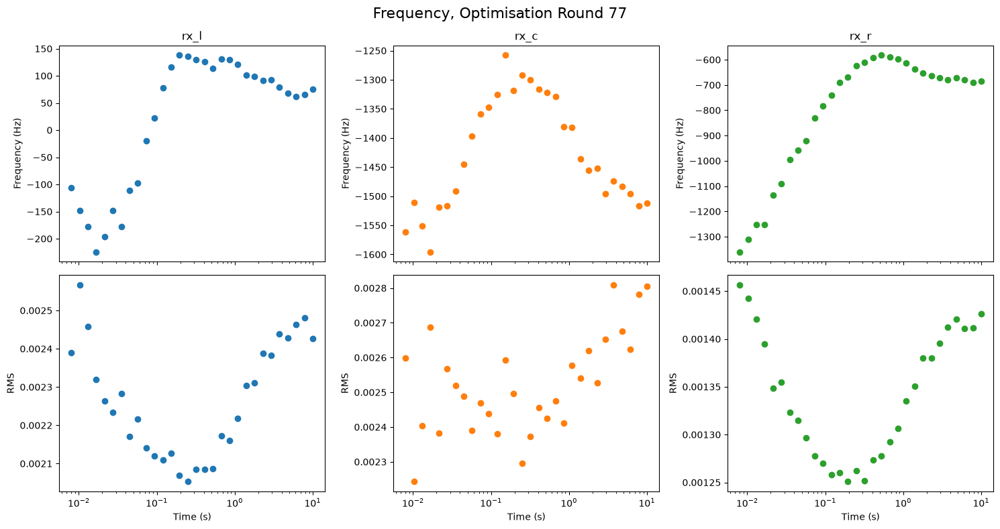

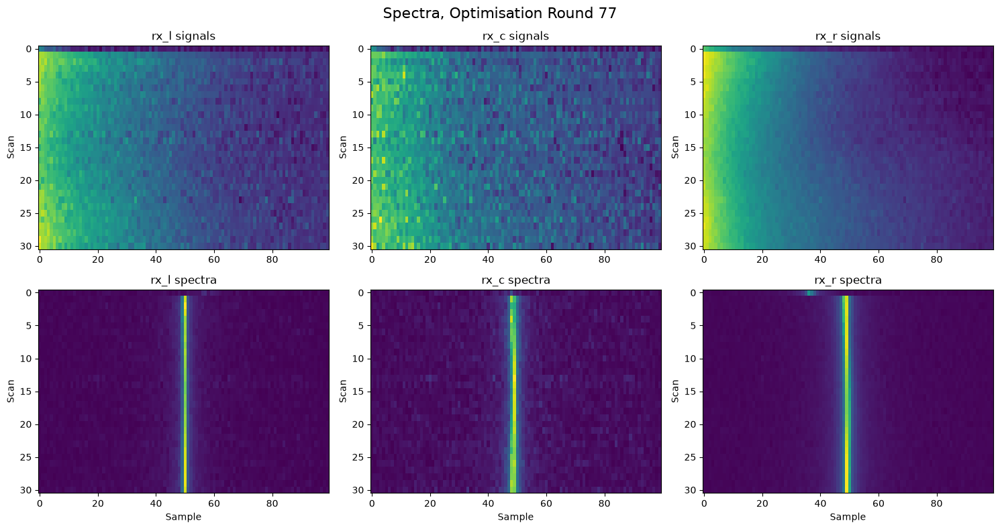

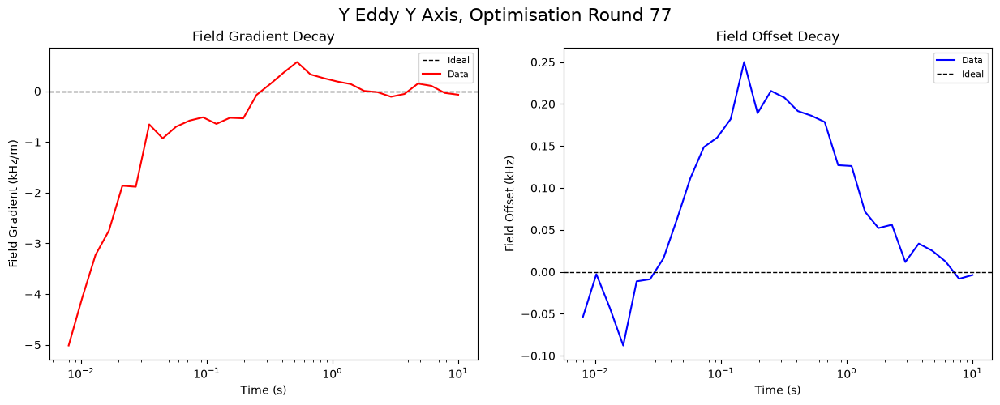

[I 2026-11-25 15:40:47,334] Trial 77 finished with value: 1136.6013654532678 and parameters: {'Y_A1': 0.054619979743234265, 'Y_A2': 0.12838477821662553, 'Y_A3': 0.097971367670064, 'Y_A4': 5.014950405882089e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12543.72813593203
mean |E| = 8264.86756621689
RMS E = 8374.613422907709
Total cost = 1.137e+03
E max = 0.13325590021888914
E nanmax = 0.13325590021888914
E contains nan = False
B max = 0.2590540098639077
B nanmax = 0.2590540098639077
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2590540098639077 !!!!!!!!!!!!!!!!


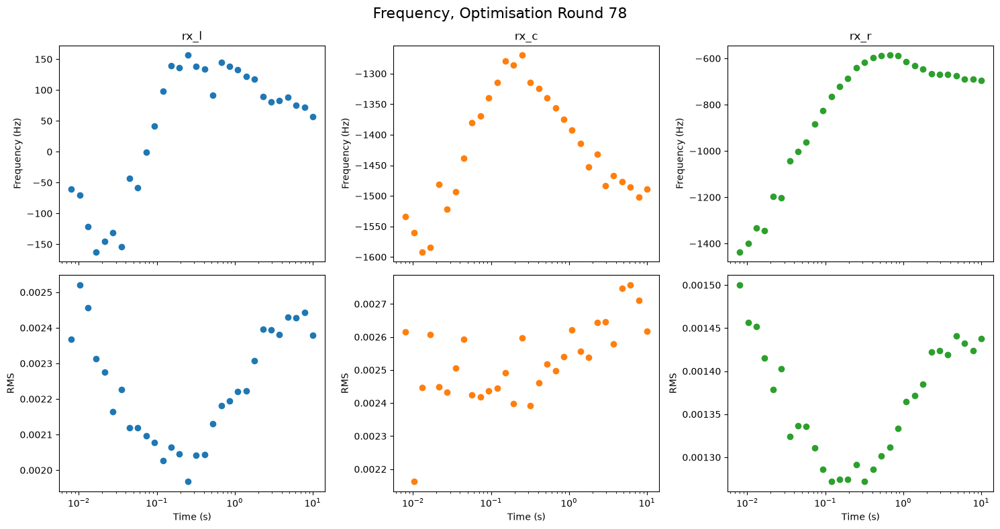

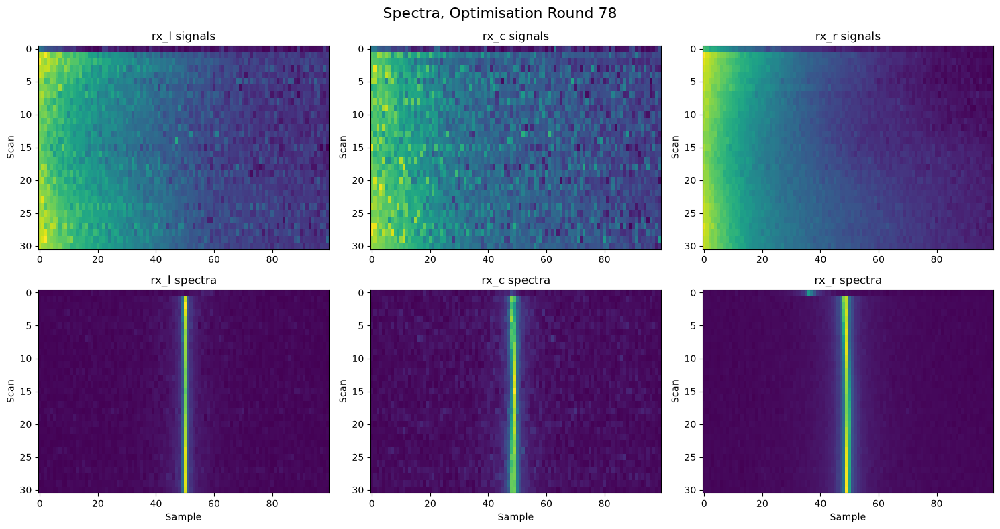

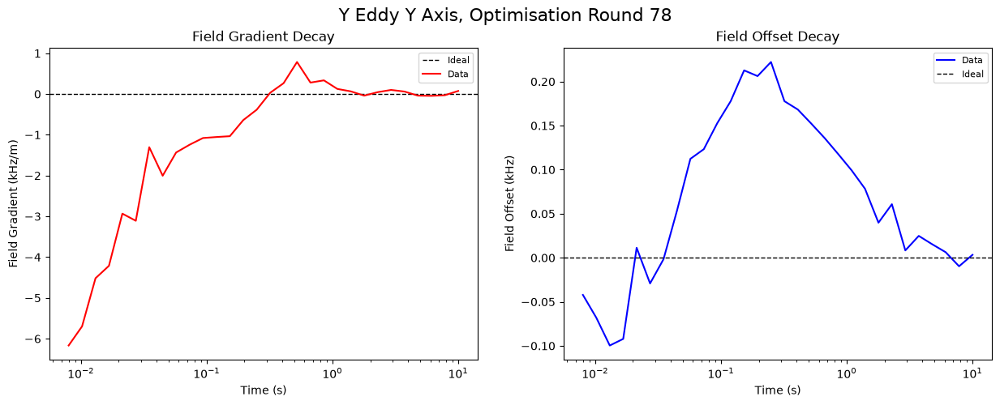

[I 2026-11-25 15:41:35,216] Trial 78 finished with value: 1050.227385931 and parameters: {'Y_A1': 0.05222136077934079, 'Y_A2': 0.12586538718041573, 'Y_A3': 0.09676188660713393, 'Y_A4': 1.6663691972984104e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13758.12093953023
mean |E| = 8751.457604531064
RMS E = 8941.143483946618
Total cost = 1.050e+03
E max = 0.13569610599698081
E nanmax = 0.13569610599698081
E contains nan = False
B max = 0.26379781472779423
B nanmax = 0.26379781472779423
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26379781472779423 !!!!!!!!!!!!!!!!


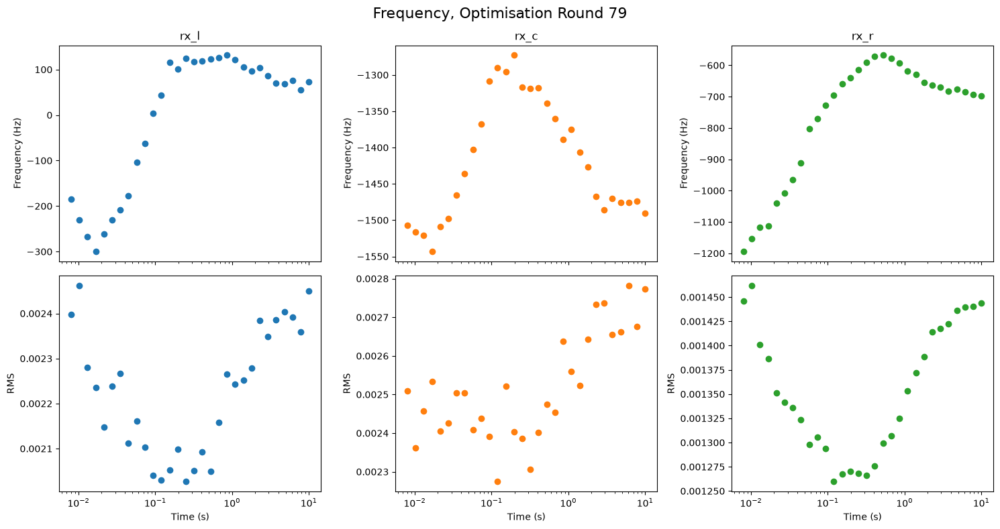

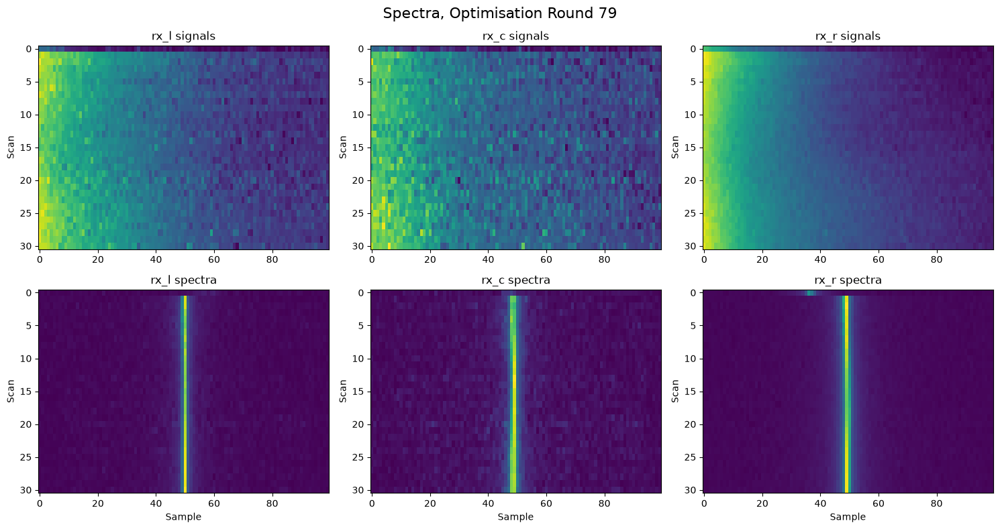

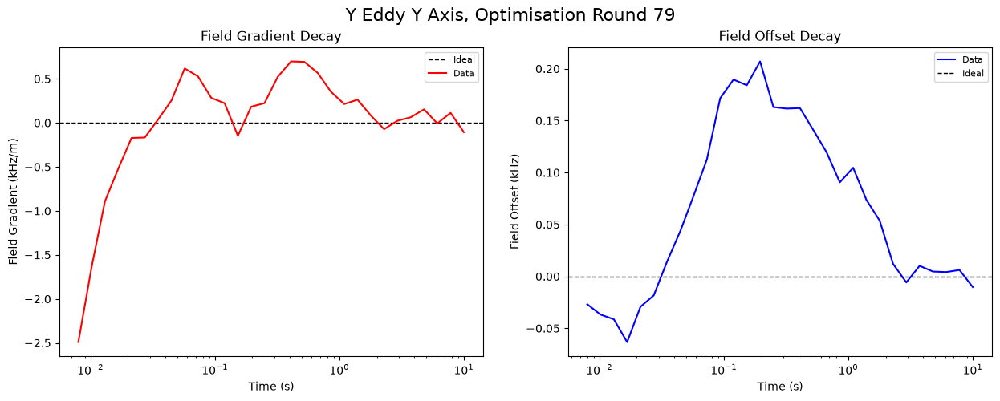

[I 2026-11-25 15:42:23,366] Trial 79 finished with value: 1280.14547211906 and parameters: {'Y_A1': 0.05856391292892606, 'Y_A2': 0.13135983595884917, 'Y_A3': 0.1016504213650536, 'Y_A4': 3.3681008845707e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10089.955022488753
mean |E| = 7603.198400799598
RMS E = 7631.270589933052
Total cost = 1.280e+03
E max = 0.13470735205064716
E nanmax = 0.13470735205064716
E contains nan = False
B max = 0.2618756810224697
B nanmax = 0.2618756810224697
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2618756810224697 !!!!!!!!!!!!!!!!


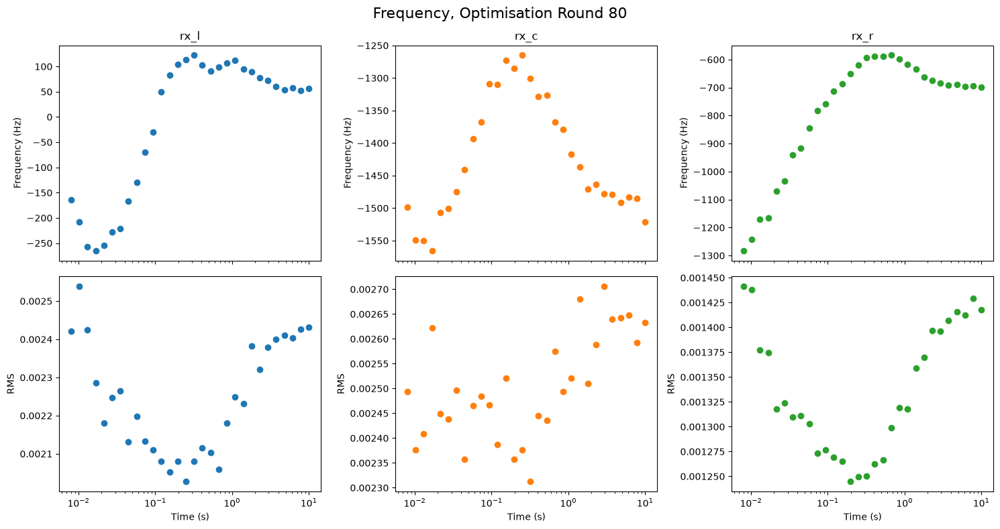

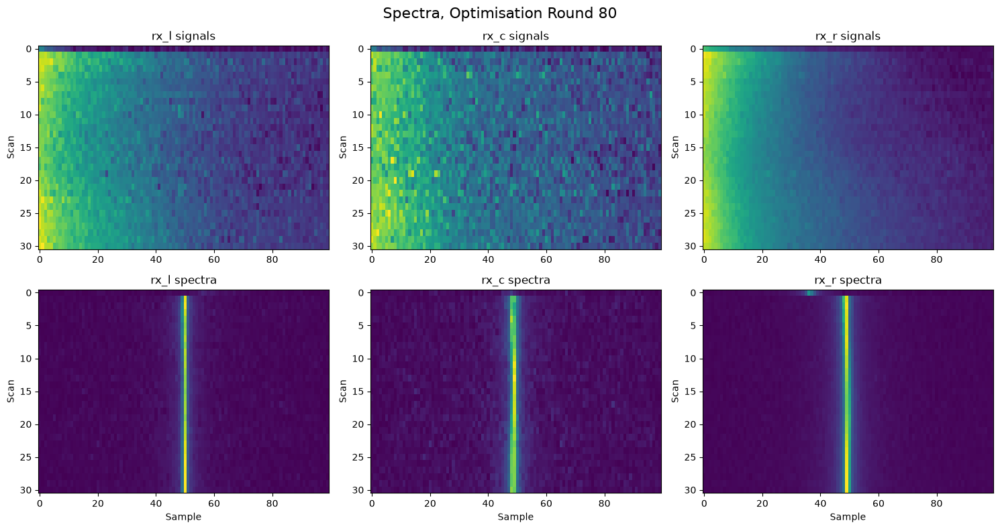

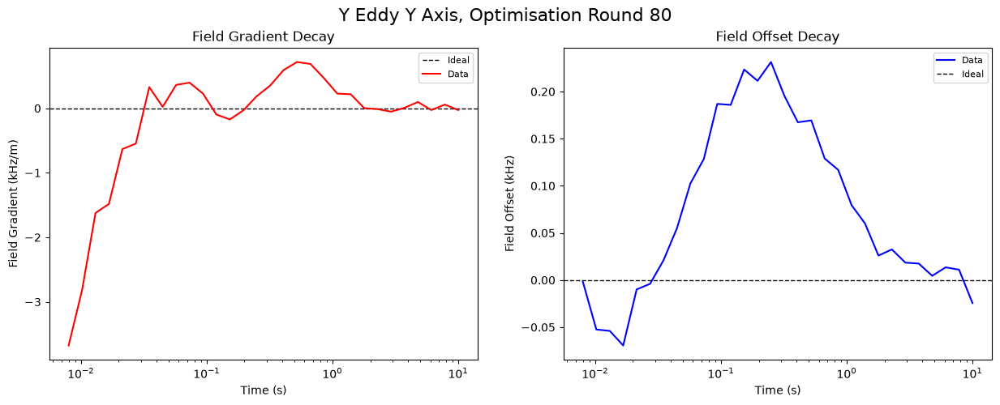

[I 2026-11-25 15:43:11,455] Trial 80 finished with value: 955.9623141054948 and parameters: {'Y_A1': 0.050884248049196376, 'Y_A2': 0.13053634014321222, 'Y_A3': 0.10296396300674023, 'Y_A4': 4.003805207637802e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11194.402798600697
mean |E| = 7726.969848409127
RMS E = 7787.096921306332
Total cost = 9.560e+02
E max = 0.135062630403184
E nanmax = 0.135062630403184
E contains nan = False
B max = 0.26256635512210563
B nanmax = 0.26256635512210563
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26256635512210563 !!!!!!!!!!!!!!!!


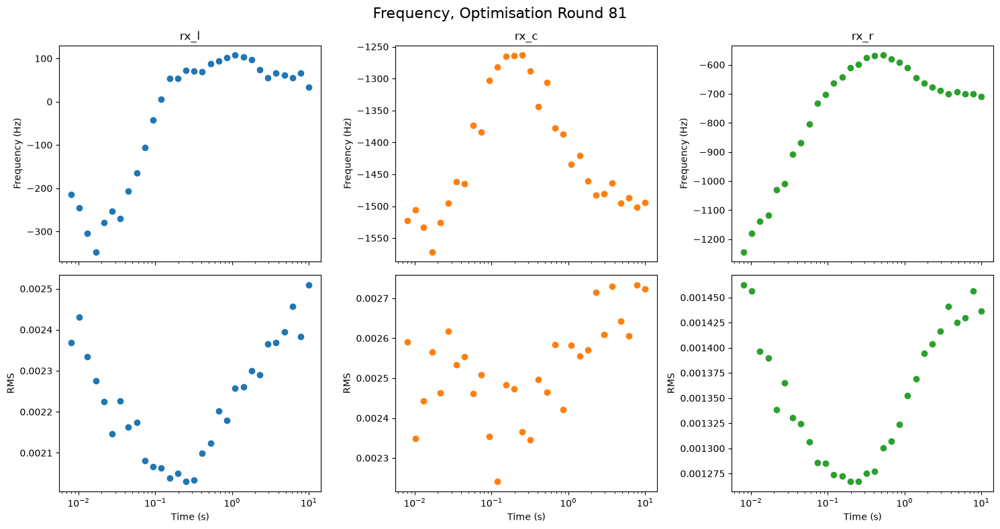

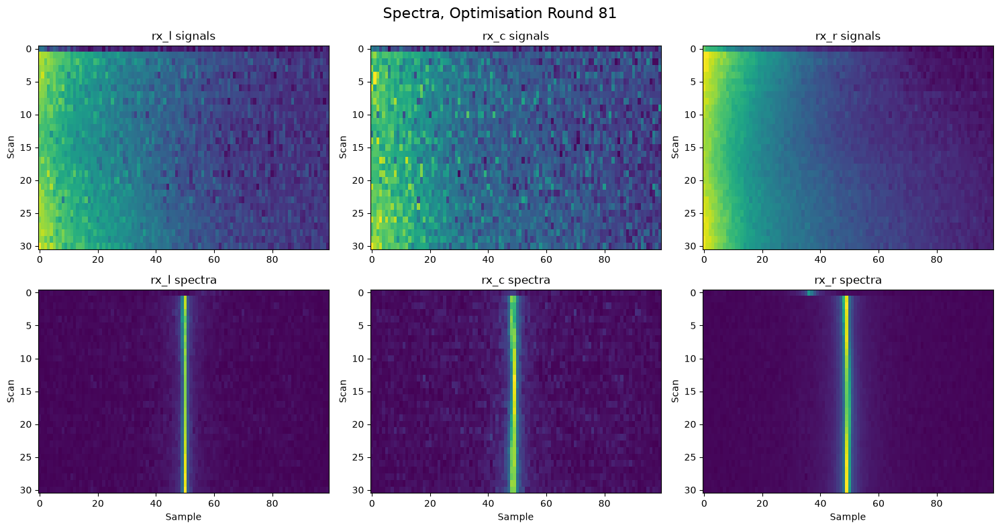

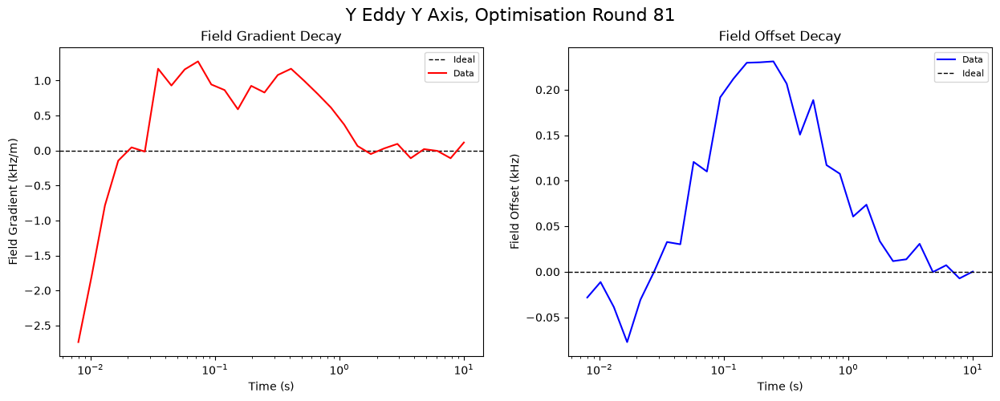

[I 2026-11-25 15:43:59,675] Trial 81 finished with value: 1540.0457565758932 and parameters: {'Y_A1': 0.051372797637654344, 'Y_A2': 0.136209585658273, 'Y_A3': 0.09897792568072106, 'Y_A4': 3.0648711610392414e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10289.855072463764
mean |E| = 7273.19673496585
RMS E = 7324.609149185834
Total cost = 1.540e+03
E max = 0.13355190714953058
E nanmax = 0.13355190714953058
E contains nan = False
B max = 0.259629460896176
B nanmax = 0.259629460896176
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.259629460896176 !!!!!!!!!!!!!!!!


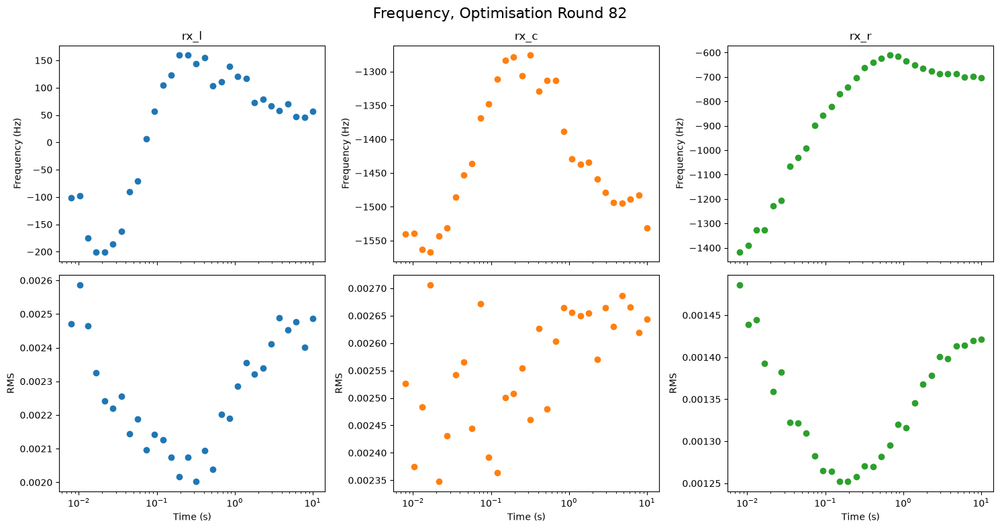

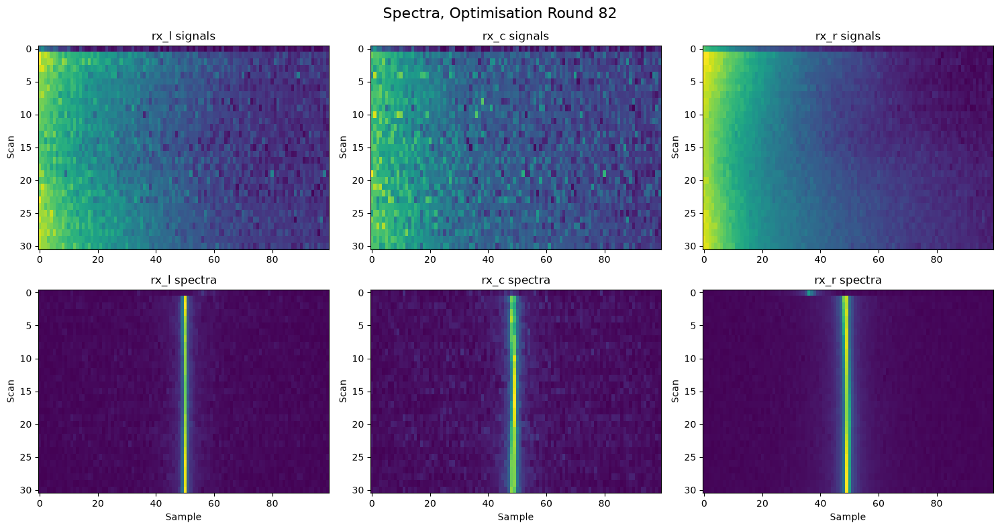

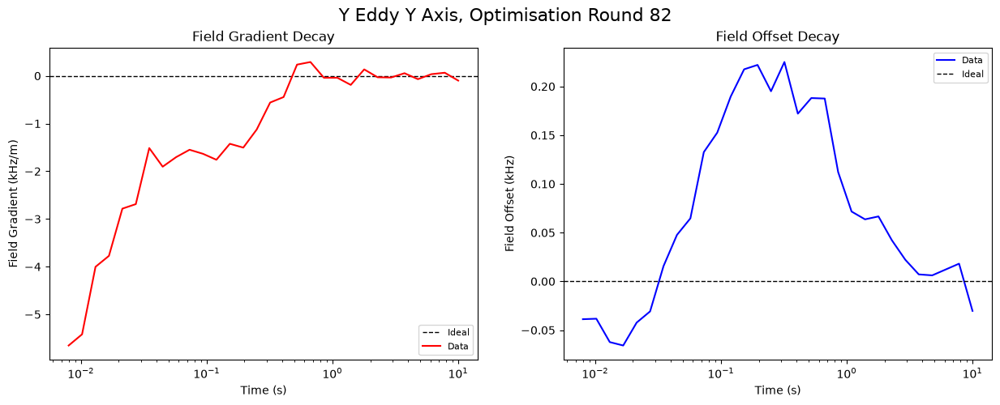

[I 2026-11-25 15:44:47,950] Trial 82 finished with value: 1234.2033048227413 and parameters: {'Y_A1': 0.049952404033640874, 'Y_A2': 0.12217568646324442, 'Y_A3': 0.10466982199435095, 'Y_A4': 4.201376565199545e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13153.42328835582
mean |E| = 8805.597201399298
RMS E = 8953.444353608578
Total cost = 1.234e+03
E max = 0.13575229859685967
E nanmax = 0.13575229859685967
E contains nan = False
B max = 0.26390707389697277
B nanmax = 0.26390707389697277
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26390707389697277 !!!!!!!!!!!!!!!!


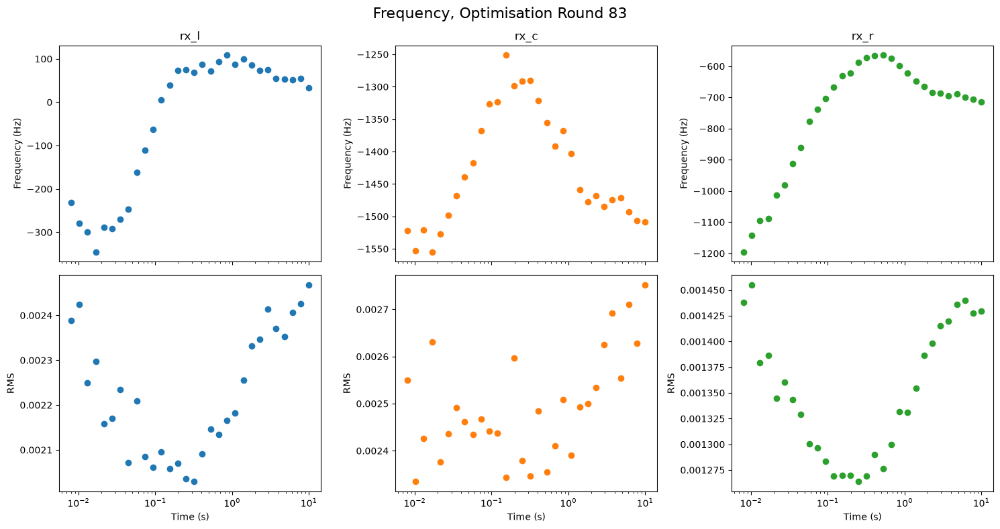

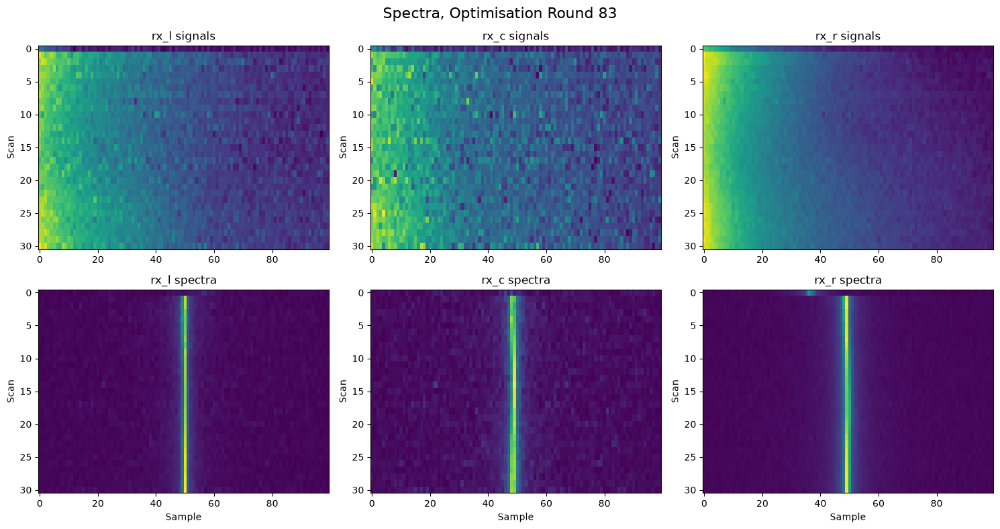

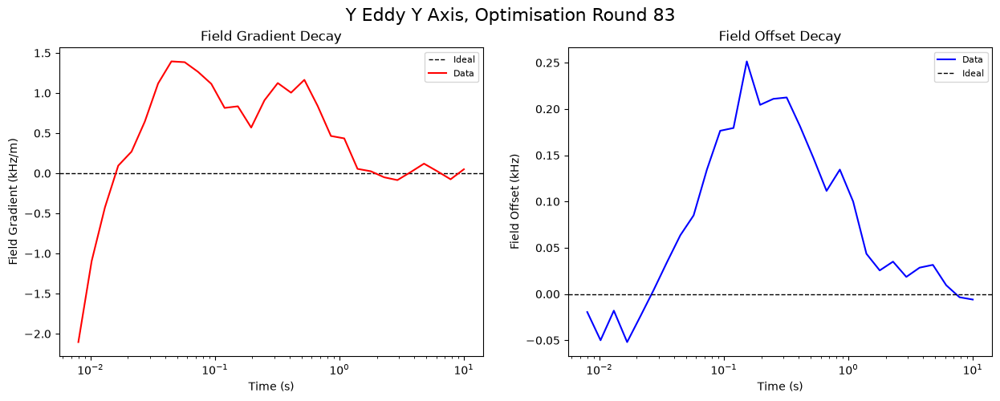

[I 2026-11-25 15:45:35,982] Trial 83 finished with value: 1460.2175471771595 and parameters: {'Y_A1': 0.05521910576591376, 'Y_A2': 0.13715122680672054, 'Y_A3': 0.09906275141746482, 'Y_A4': 3.5567673122298305e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 9635.1824087956
mean |E| = 7134.432783608193
RMS E = 7173.619935463713
Total cost = 1.460e+03
E max = 0.13383812892202732
E nanmax = 0.13383812892202732
E contains nan = False
B max = 0.26018586512218816
B nanmax = 0.26018586512218816
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26018586512218816 !!!!!!!!!!!!!!!!


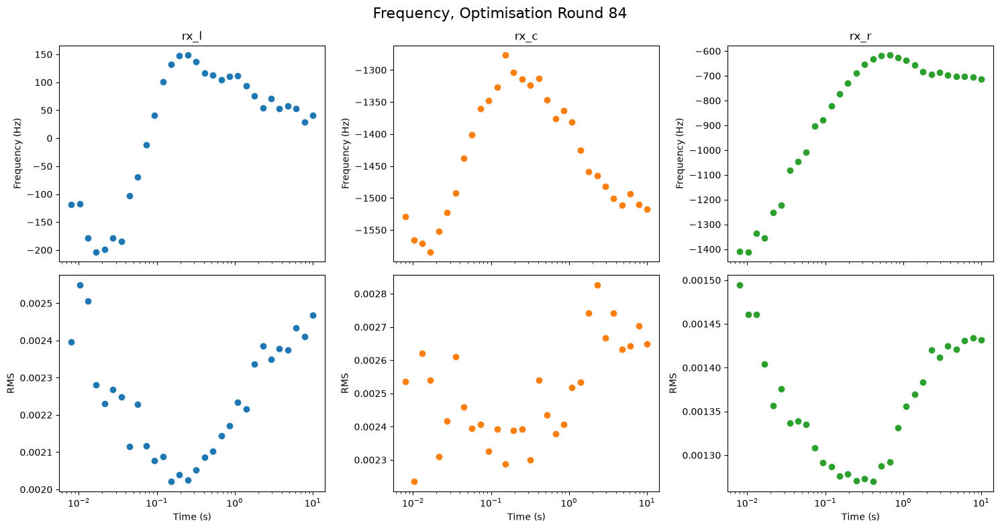

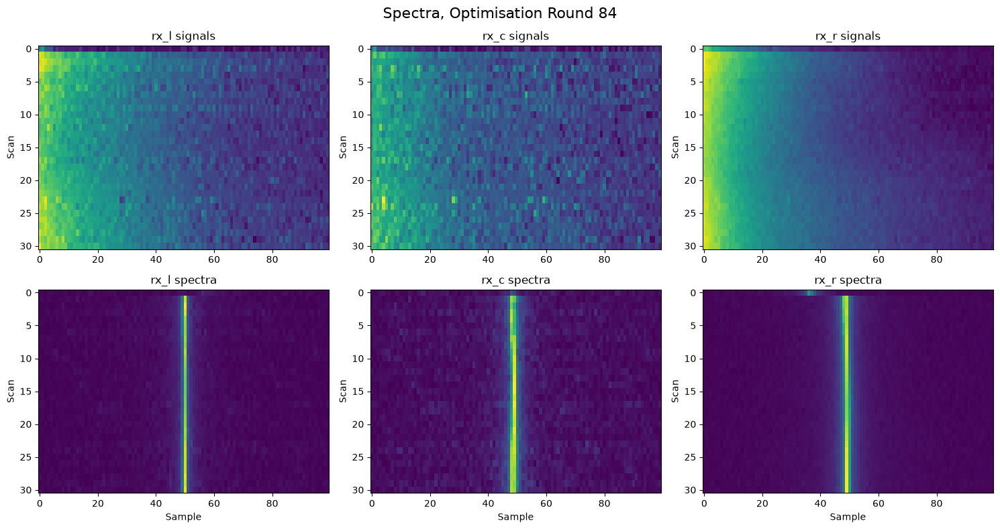

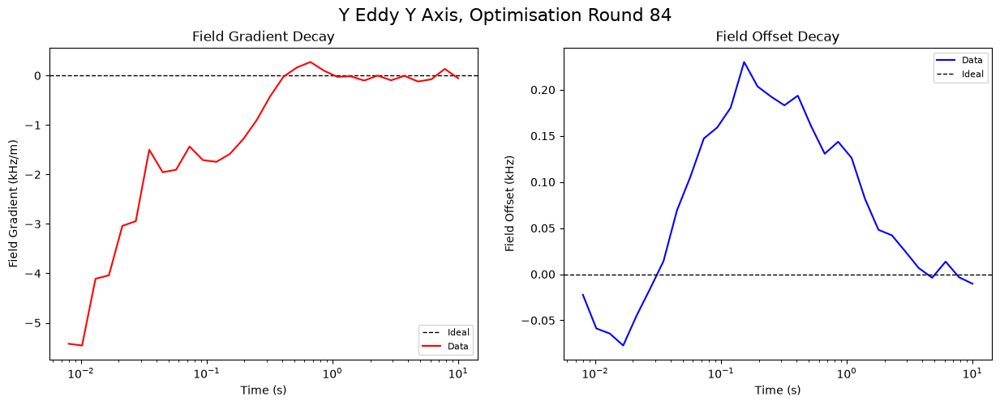

[I 2026-11-25 15:46:23,818] Trial 84 finished with value: 1284.5352292520645 and parameters: {'Y_A1': 0.054929869511315184, 'Y_A2': 0.1235735712567448, 'Y_A3': 0.10059475572200342, 'Y_A4': 3.0459150018433023e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12938.530734632679
mean |E| = 8790.438114276192
RMS E = 8944.321286892742
Total cost = 1.285e+03
E max = 0.13447770778953214
E nanmax = 0.13447770778953214
E contains nan = False
B max = 0.26142921976808403
B nanmax = 0.26142921976808403
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26142921976808403 !!!!!!!!!!!!!!!!


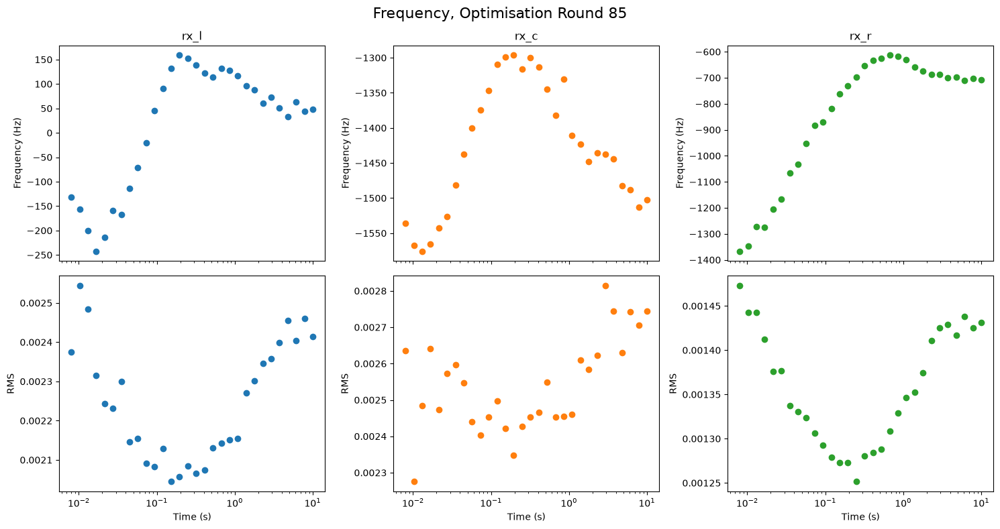

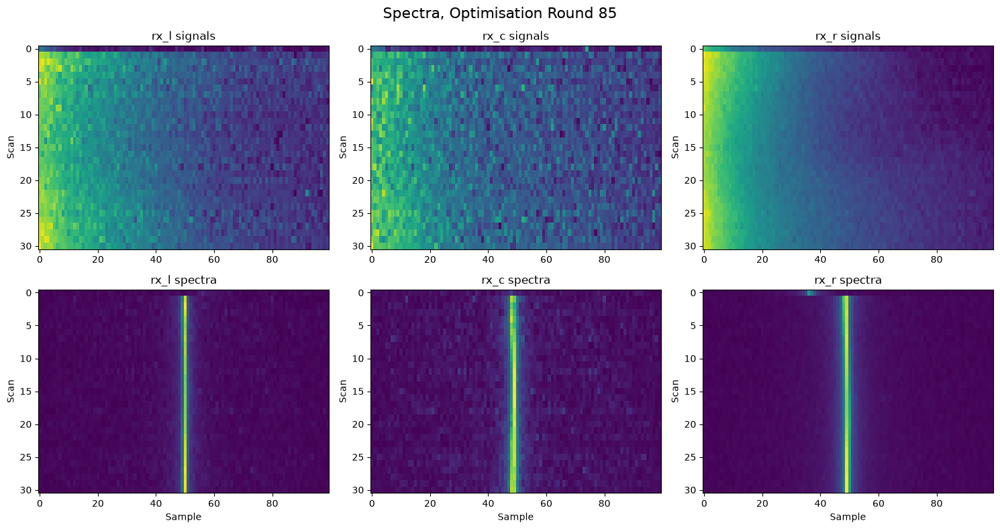

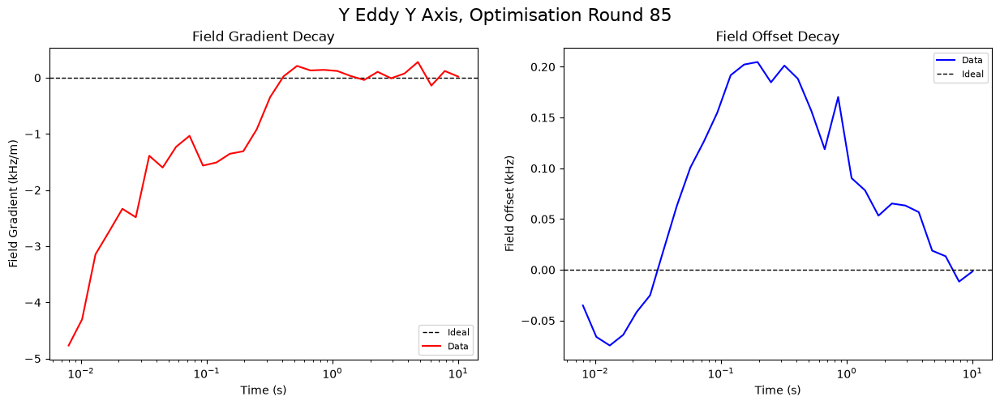

[I 2026-11-25 15:47:12,034] Trial 85 finished with value: 1492.0914668002383 and parameters: {'Y_A1': 0.0556130714238683, 'Y_A2': 0.12249194065149299, 'Y_A3': 0.10538790877969023, 'Y_A4': 2.8266520940595547e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12353.823088455769
mean |E| = 8618.357487922704
RMS E = 8723.771935187988
Total cost = 1.492e+03
E max = 0.133911545119587
E nanmax = 0.133911545119587
E contains nan = False
B max = 0.2603285826176257
B nanmax = 0.2603285826176257
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2603285826176257 !!!!!!!!!!!!!!!!


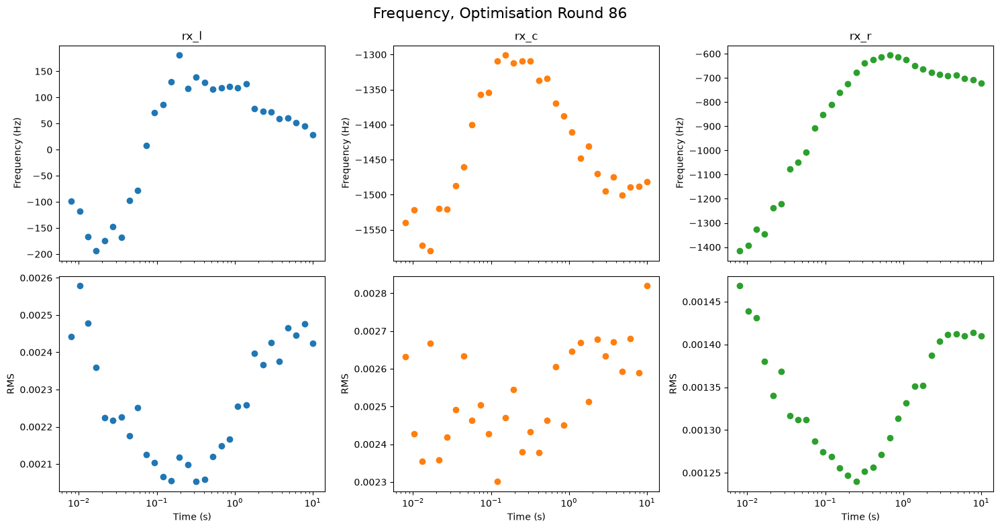

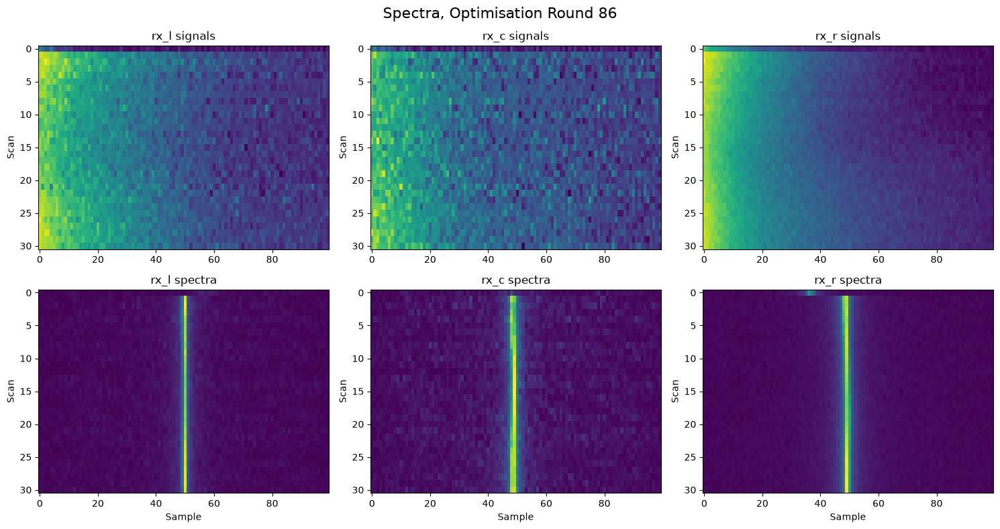

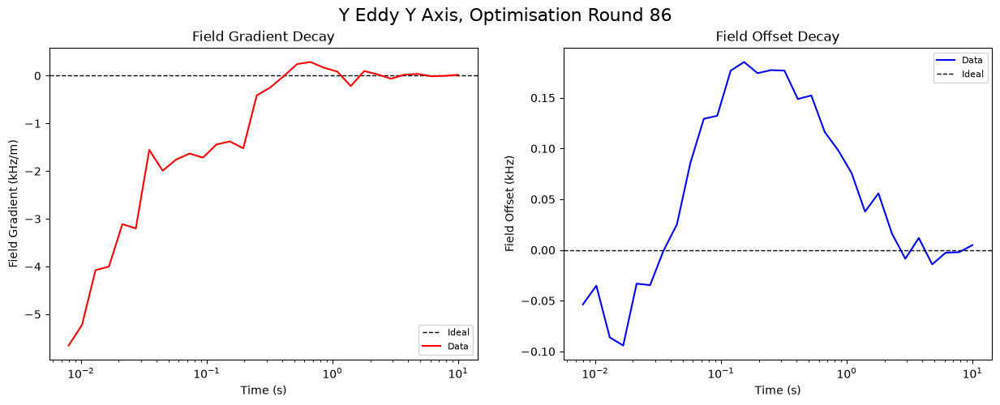

[I 2026-11-25 15:48:01,985] Trial 86 finished with value: 860.0900243515367 and parameters: {'Y_A1': 0.05647344844355366, 'Y_A2': 0.12429287214220844, 'Y_A3': 0.09892140765722314, 'Y_A4': -1.2067500486601815e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13178.410794602696
mean |E| = 8798.267532900214
RMS E = 8957.601779719384
Total cost = 8.601e+02
E max = 0.13545224528282016
E nanmax = 0.13545224528282016
E contains nan = False
B max = 0.26332374286890875
B nanmax = 0.26332374286890875
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26332374286890875 !!!!!!!!!!!!!!!!


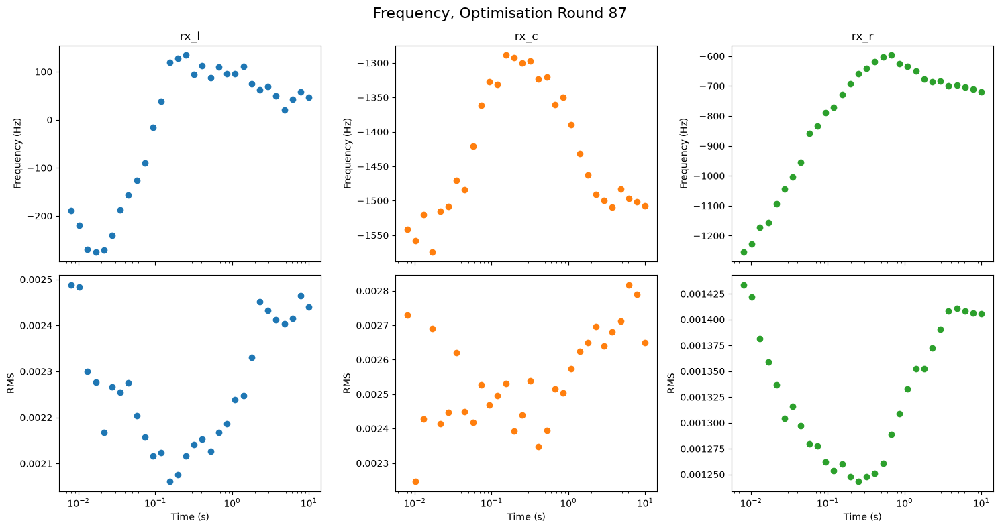

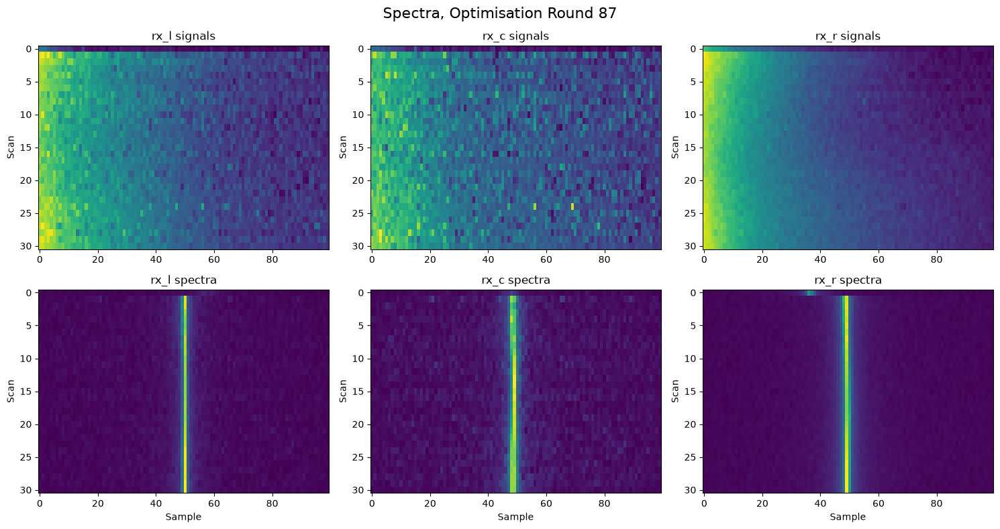

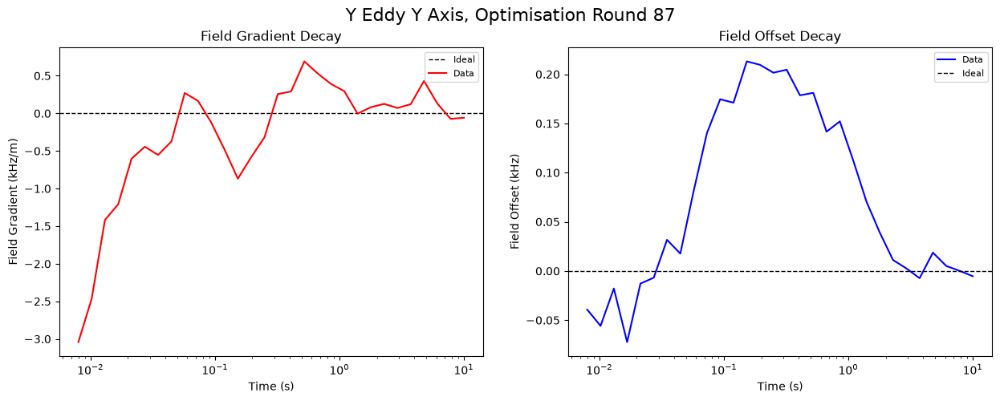

[I 2026-11-25 15:48:53,278] Trial 87 finished with value: 1724.0068970097088 and parameters: {'Y_A1': 0.05762999272671264, 'Y_A2': 0.127193026881446, 'Y_A3': 0.1052054874402012, 'Y_A4': 3.870084883142195e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10649.67516241879
mean |E| = 7899.716808262534
RMS E = 7942.238564166579
Total cost = 1.724e+03
E max = 0.13492217430183276
E nanmax = 0.13492217430183276
E contains nan = False
B max = 0.2622932860431326
B nanmax = 0.2622932860431326
B contains nan = False
Trial 88


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2622932860431326 !!!!!!!!!!!!!!!!


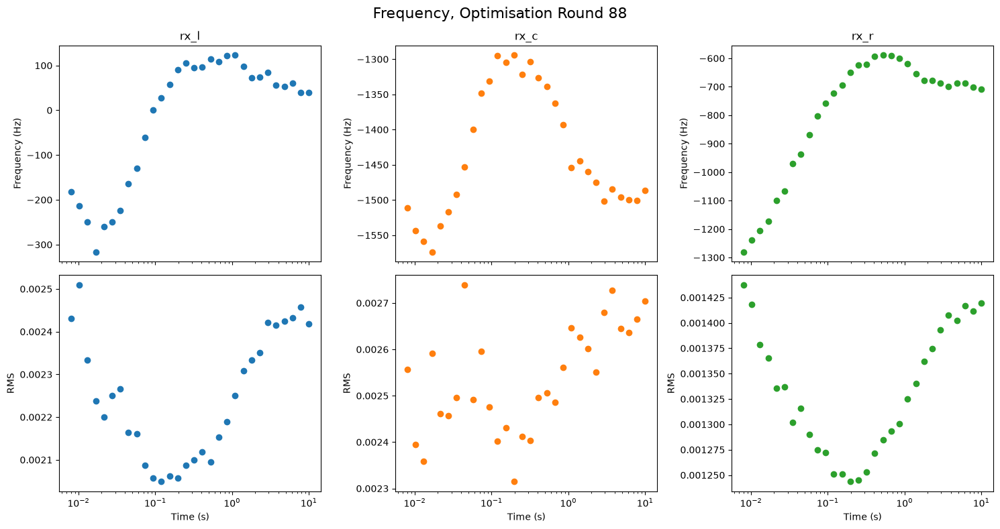

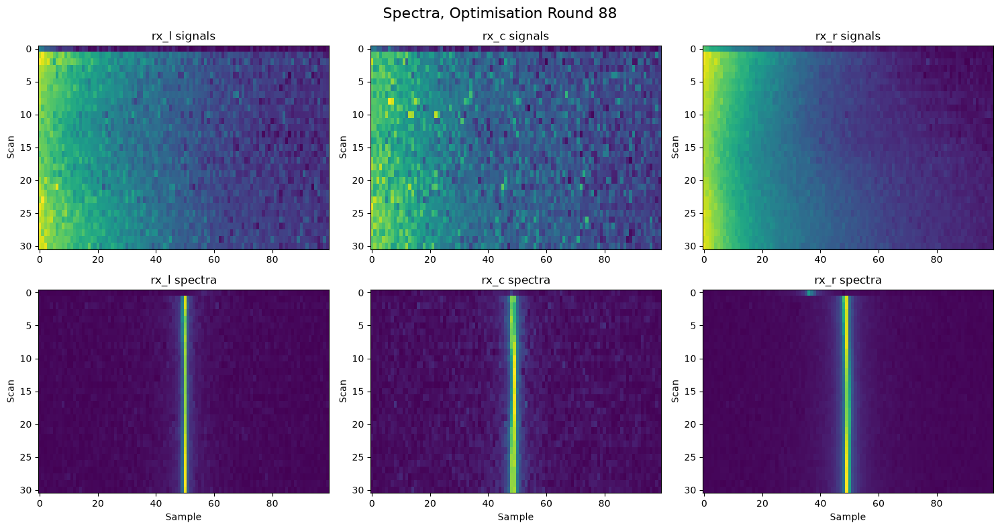

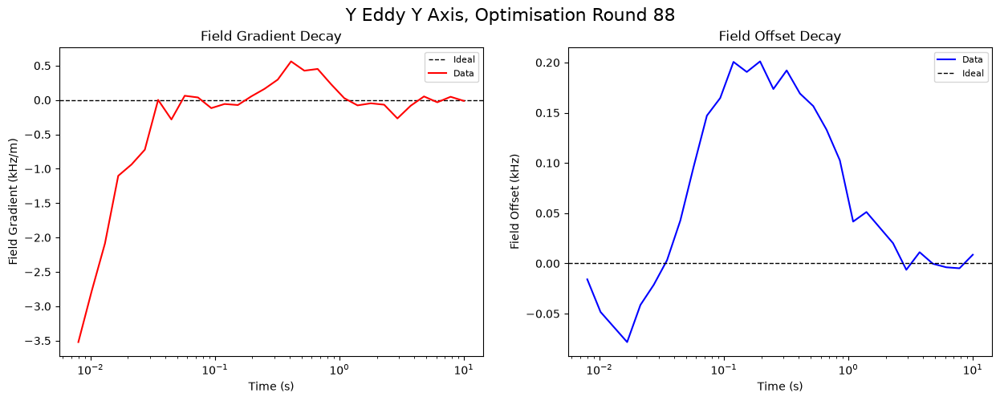

[I 2026-11-25 15:49:42,867] Trial 88 finished with value: 900.8787016751625 and parameters: {'Y_A1': 0.05491451948588058, 'Y_A2': 0.13165715754826368, 'Y_A3': 0.09953129373810324, 'Y_A4': 2.563443668751141e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10979.51024487756
mean |E| = 7787.10644677661
RMS E = 7840.31073958309
Total cost = 9.009e+02
E max = 0.1352519678348017
E nanmax = 0.1352519678348017
E contains nan = False
B max = 0.2629344026024144
B nanmax = 0.2629344026024144
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2629344026024144 !!!!!!!!!!!!!!!!


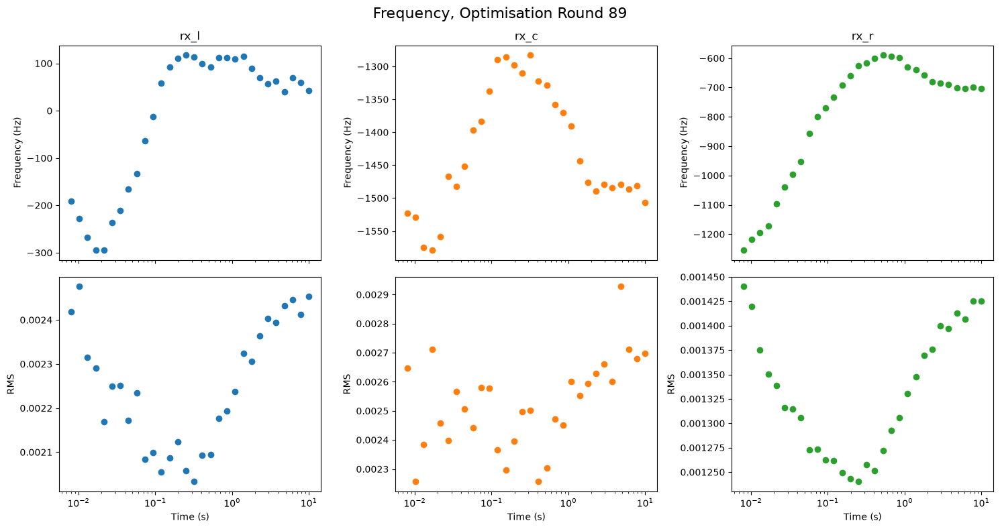

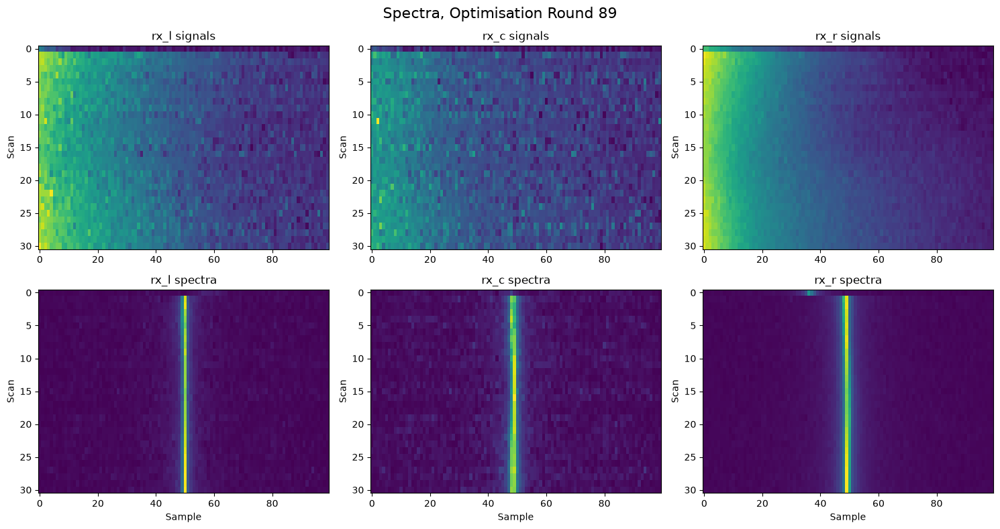

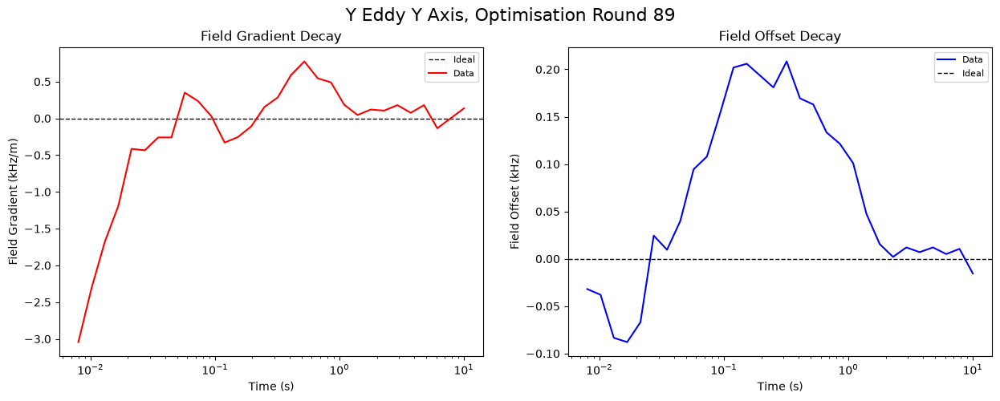

[I 2026-11-25 15:50:32,269] Trial 89 finished with value: 1396.809108204139 and parameters: {'Y_A1': 0.05719584290223943, 'Y_A2': 0.12997935521843593, 'Y_A3': 0.10138347470242588, 'Y_A4': 2.447797226825225e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10639.680159920037
mean |E| = 7794.102948525736
RMS E = 7837.271006381513
Total cost = 1.397e+03
E max = 0.13429030576984455
E nanmax = 0.13429030576984455
E contains nan = False
B max = 0.2610648984303234
B nanmax = 0.2610648984303234
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2610648984303234 !!!!!!!!!!!!!!!!


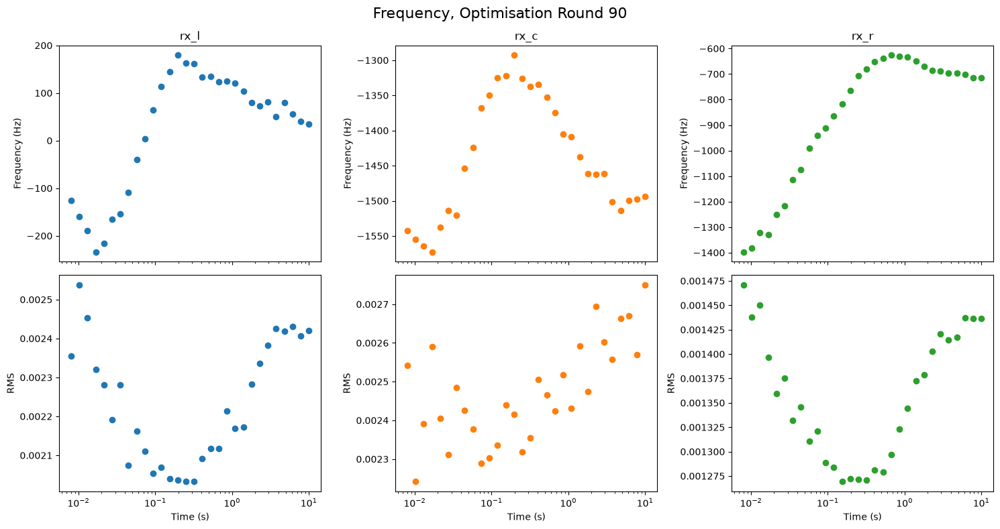

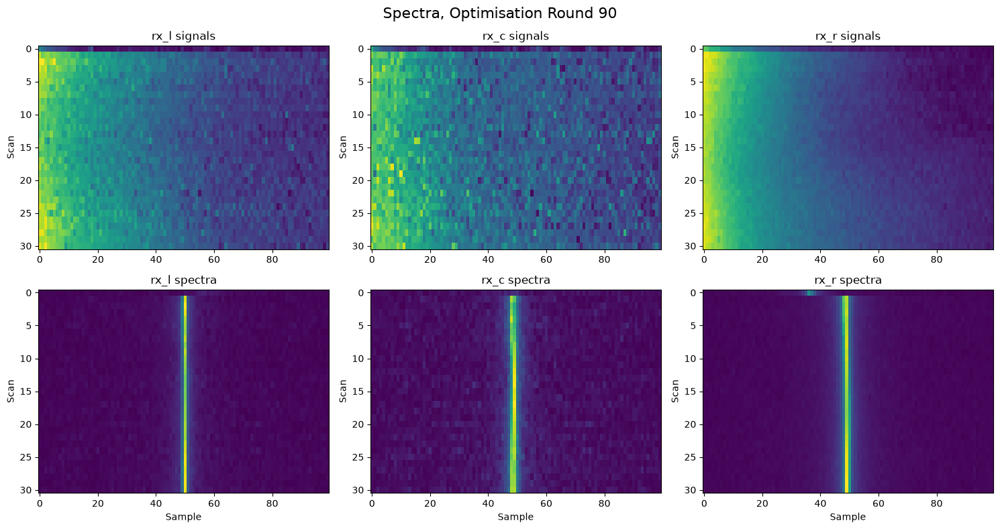

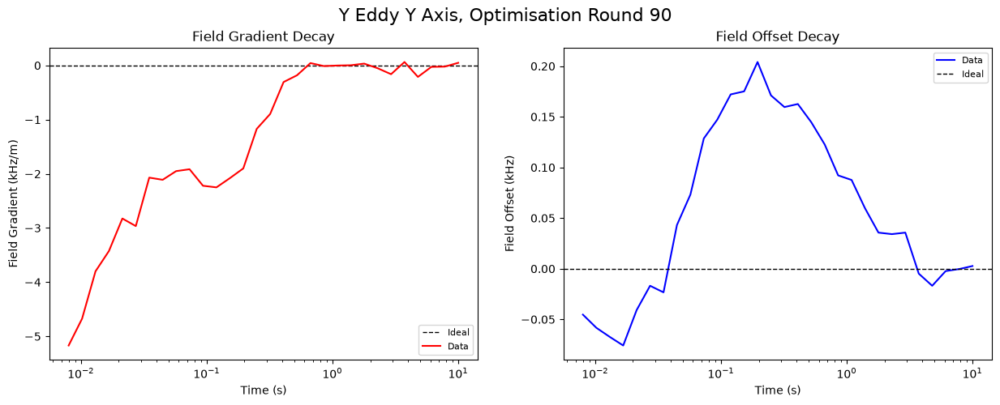

[I 2026-11-25 15:51:20,949] Trial 90 finished with value: 1289.9343320891824 and parameters: {'Y_A1': 0.056540051521465254, 'Y_A2': 0.11923949027644899, 'Y_A3': 0.10660919179266175, 'Y_A4': 5.5138967135640555e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12708.645677161416
mean |E| = 8946.52673663168
RMS E = 9073.54424756314
Total cost = 1.290e+03
E max = 0.13343054868969897
E nanmax = 0.13343054868969897
E contains nan = False
B max = 0.2593935200439894
B nanmax = 0.2593935200439894
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2593935200439894 !!!!!!!!!!!!!!!!


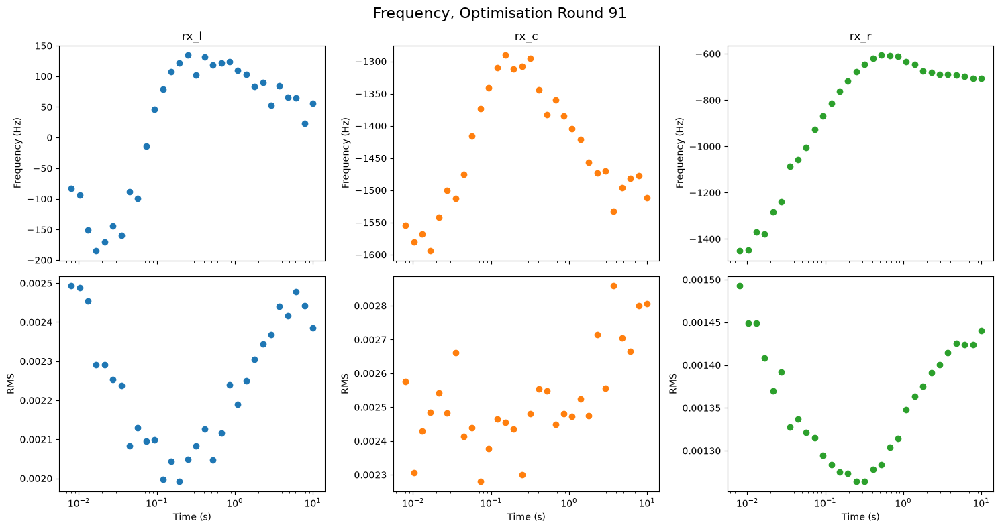

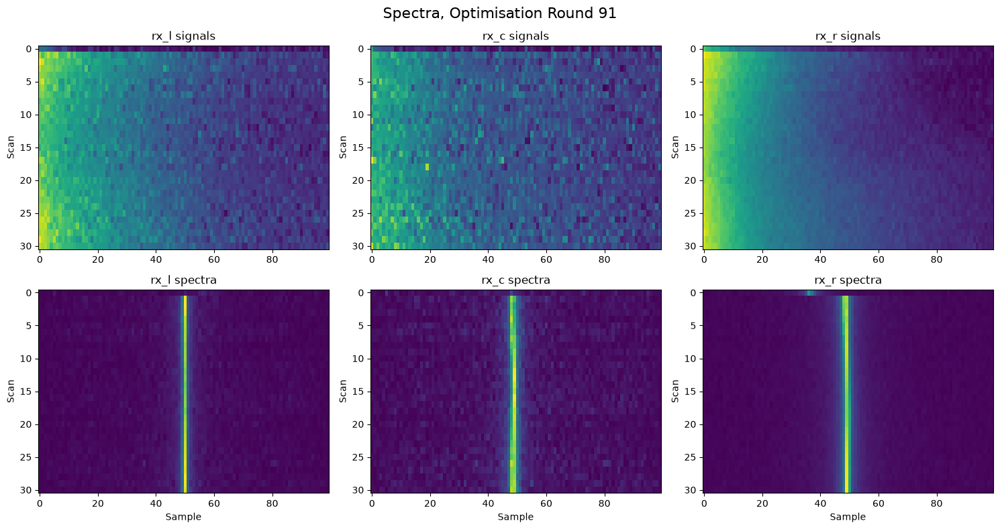

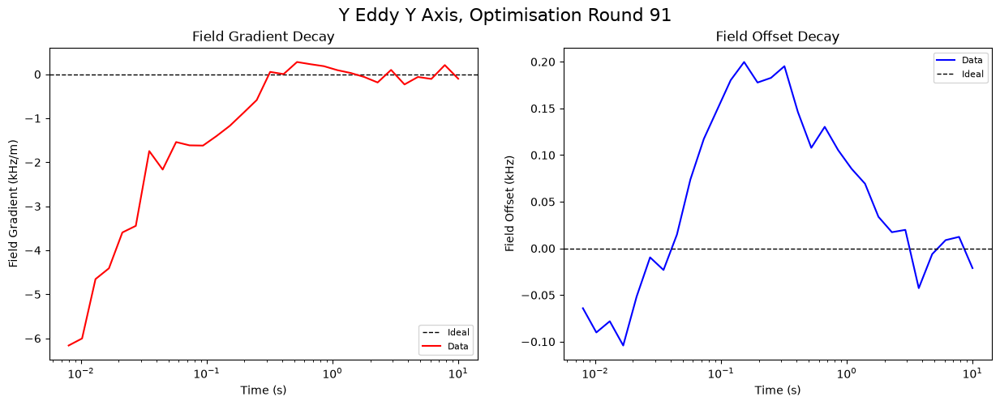

[I 2026-11-25 15:52:10,456] Trial 91 finished with value: 1714.6333691135856 and parameters: {'Y_A1': 0.05486293719900575, 'Y_A2': 0.1252471522956426, 'Y_A3': 0.09615169745603211, 'Y_A4': 3.567092101417866e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 13688.155922038977
mean |E| = 8877.228052640343
RMS E = 9072.596876010117
Total cost = 1.715e+03
E max = 0.13486514539941308
E nanmax = 0.13486514539941308
E contains nan = False
B max = 0.26218243257657525
B nanmax = 0.26218243257657525
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26218243257657525 !!!!!!!!!!!!!!!!


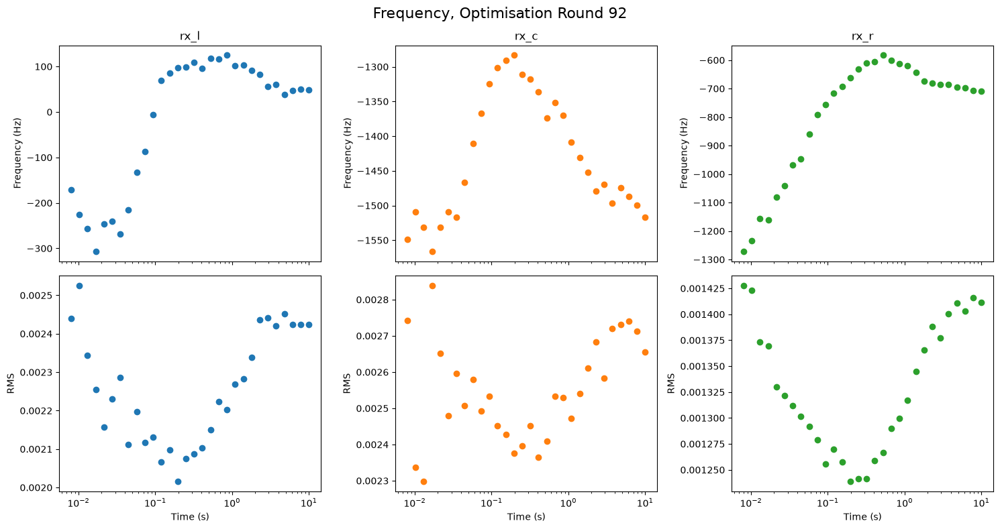

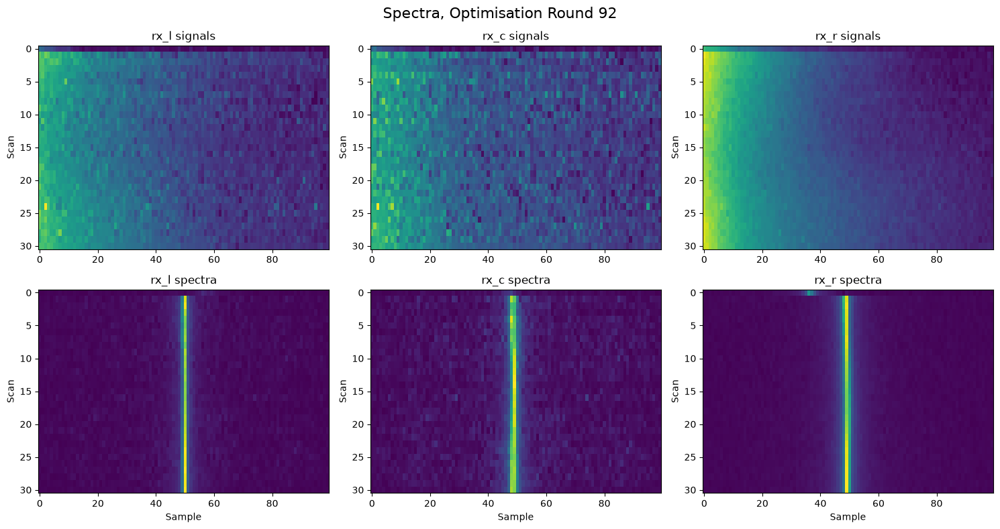

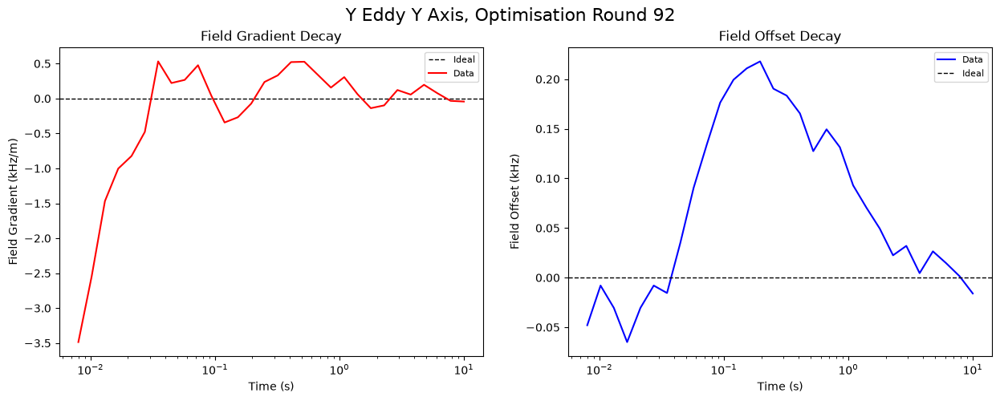

[I 2026-11-25 15:53:00,715] Trial 92 finished with value: 1148.3856732596491 and parameters: {'Y_A1': 0.05149081244111208, 'Y_A2': 0.12998814470370096, 'Y_A3': 0.10403428729748193, 'Y_A4': 4.583949217531053e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11014.492753623186
mean |E| = 7738.963851407628
RMS E = 7788.867752922259
Total cost = 1.148e+03
E max = 0.13492960970675044
E nanmax = 0.13492960970675044
E contains nan = False
B max = 0.26230774391900186
B nanmax = 0.26230774391900186
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26230774391900186 !!!!!!!!!!!!!!!!


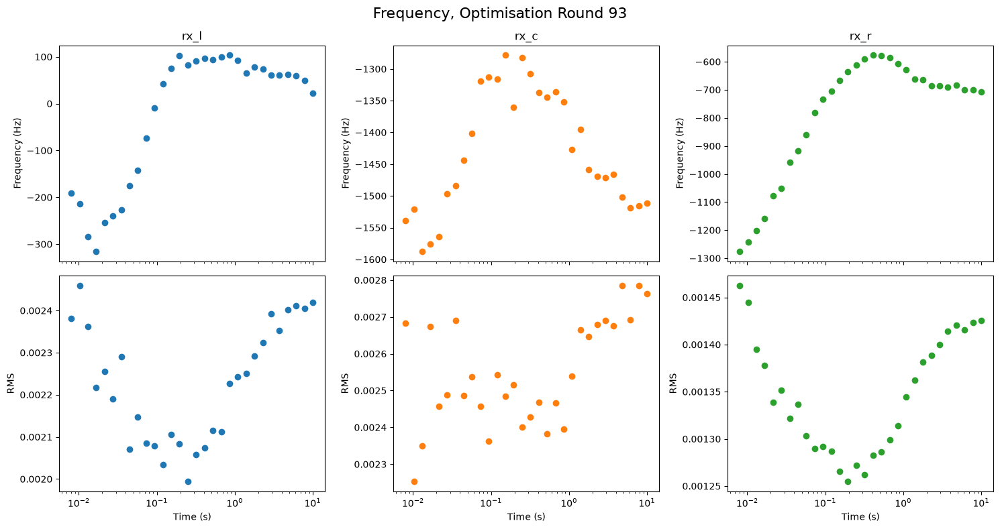

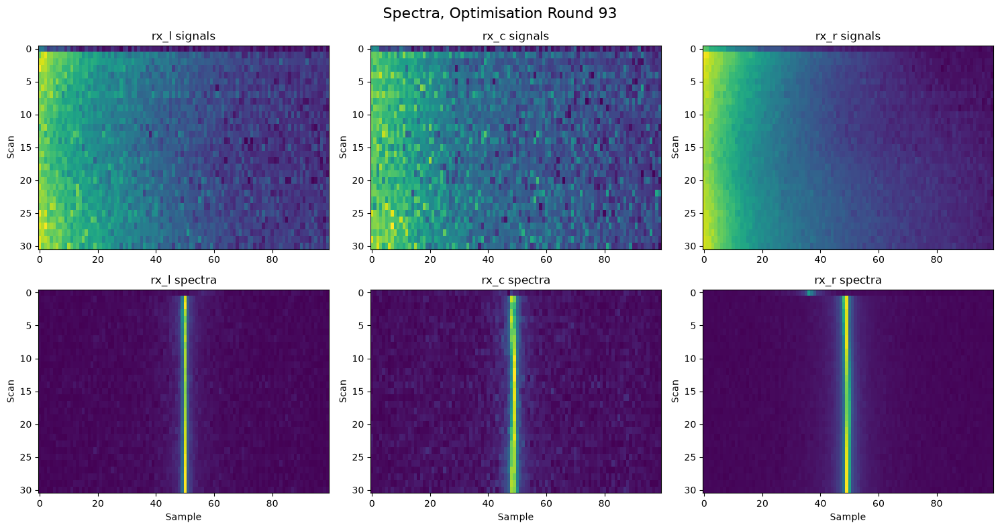

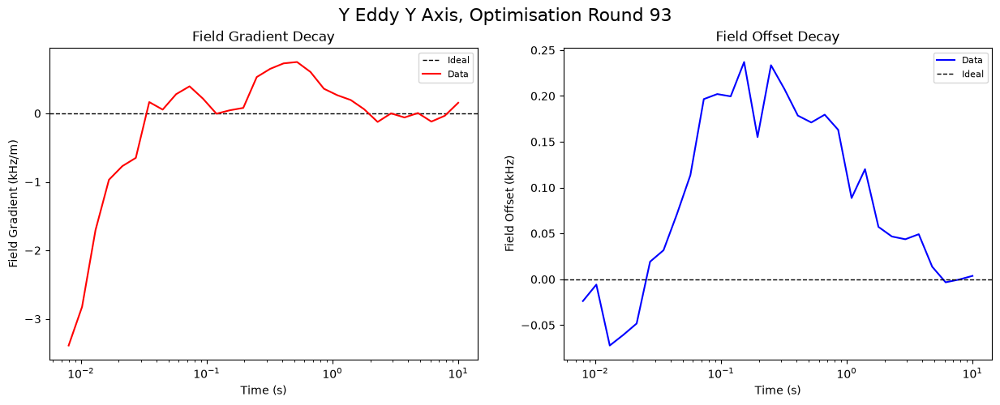

[I 2026-11-25 15:53:48,719] Trial 93 finished with value: 1203.7533076353416 and parameters: {'Y_A1': 0.05458335636699581, 'Y_A2': 0.13367039784008086, 'Y_A3': 0.09778203182859126, 'Y_A4': 1.1046522328304792e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 10854.572713643176
mean |E| = 7636.681659170411
RMS E = 7693.697510757377
Total cost = 1.204e+03
E max = 0.13385760772751115
E nanmax = 0.13385760772751115
E contains nan = False
B max = 0.26022374552046573
B nanmax = 0.26022374552046573
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26022374552046573 !!!!!!!!!!!!!!!!


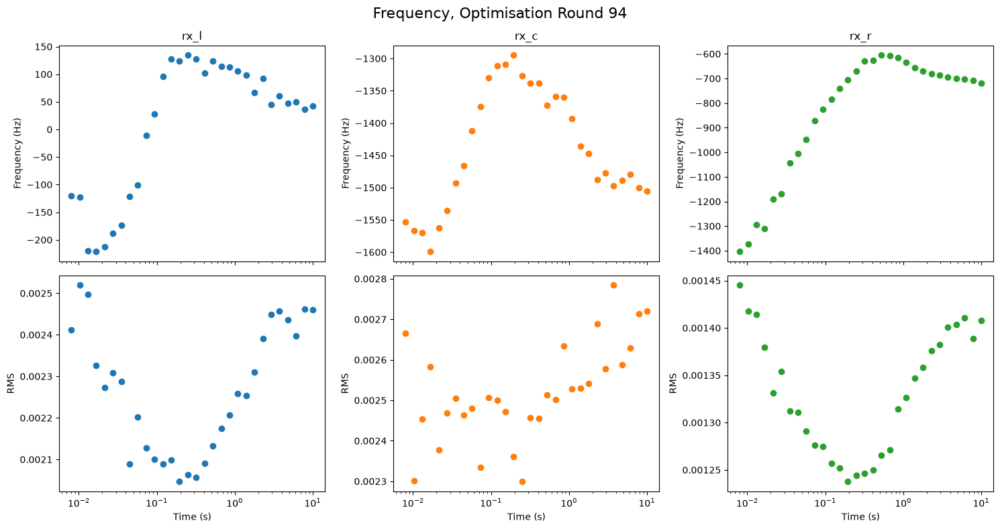

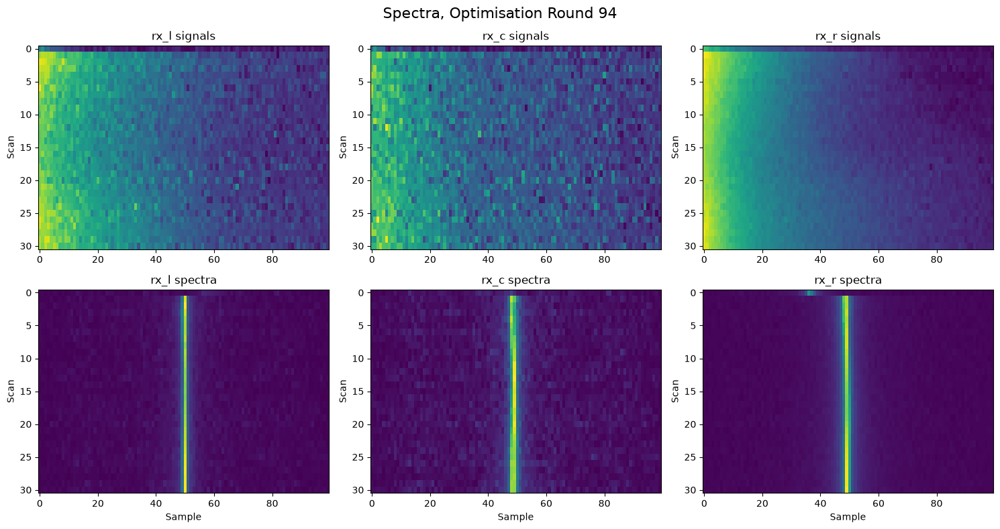

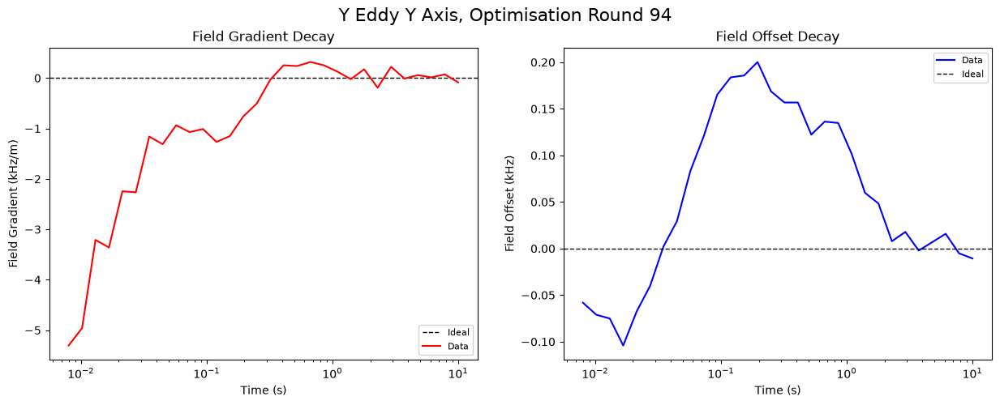

[I 2026-11-25 15:54:38,438] Trial 94 finished with value: 1194.549759456327 and parameters: {'Y_A1': 0.05209577704684762, 'Y_A2': 0.12539845644418968, 'Y_A3': 0.10145114691907009, 'Y_A4': -3.6760342429566875e-10}. Best is trial 39 with value: 759.5239601555228.


max |E| = 12833.583208395798
mean |E| = 8500.749625187404
RMS E = 8630.172545698524
Total cost = 1.195e+03
E max = 0.13470797213021485
E nanmax = 0.13470797213021485
E contains nan = False
B max = 0.26187684869041605
B nanmax = 0.26187684869041605
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26187684869041605 !!!!!!!!!!!!!!!!


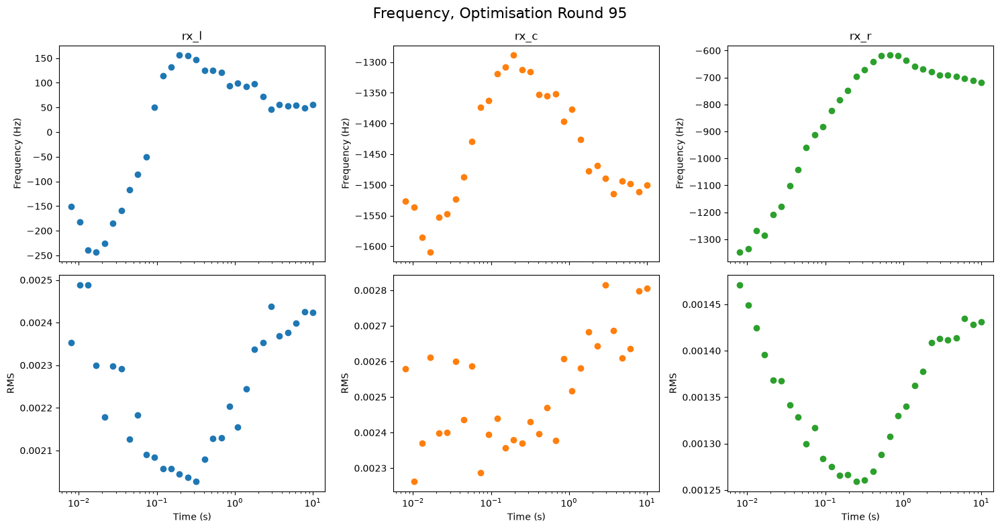

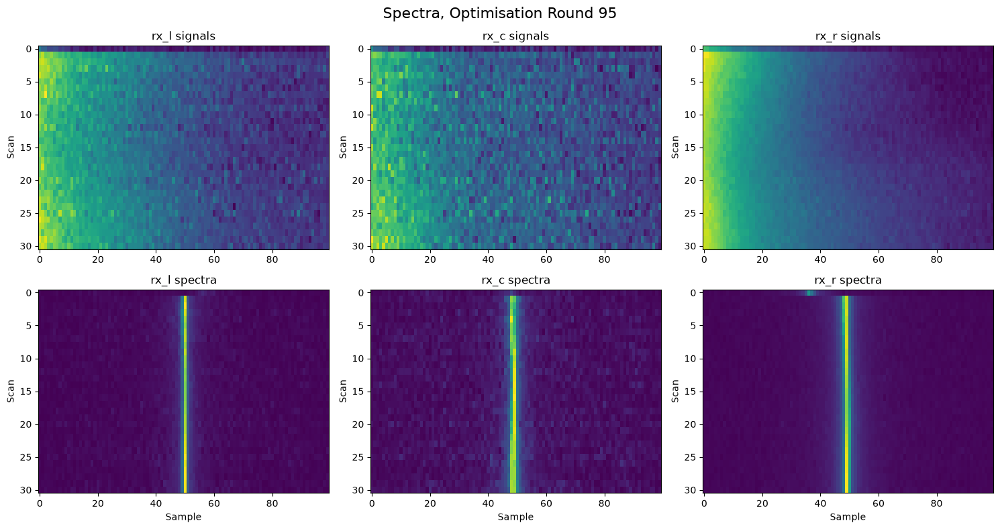

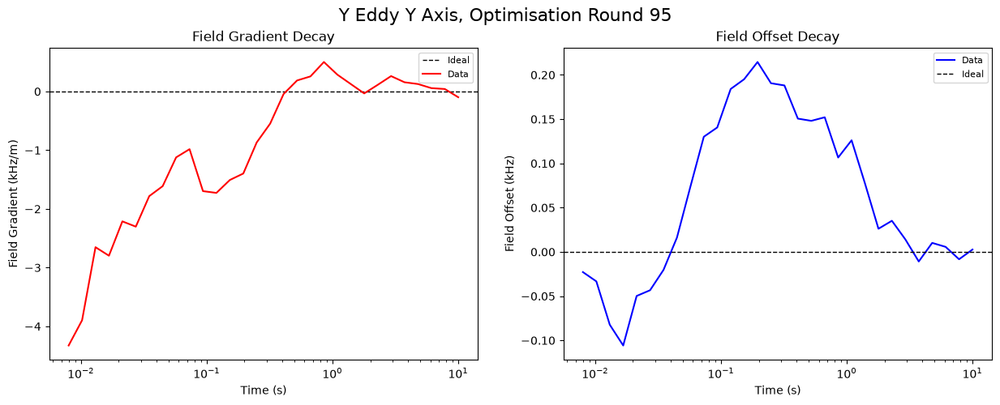

[I 2026-11-25 15:55:27,417] Trial 95 finished with value: 1580.5903591769368 and parameters: {'Y_A1': 0.05827453405750873, 'Y_A2': 0.12219992513699592, 'Y_A3': 0.10478133652123248, 'Y_A4': 2.3397552748447857e-09}. Best is trial 39 with value: 759.5239601555228.


max |E| = 11959.020489755118
mean |E| = 8616.025320672994
RMS E = 8711.608762626362
Total cost = 1.581e+03
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2617891513699515
B nanmax = 0.2617891513699515
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2617891513699515 !!!!!!!!!!!!!!!!


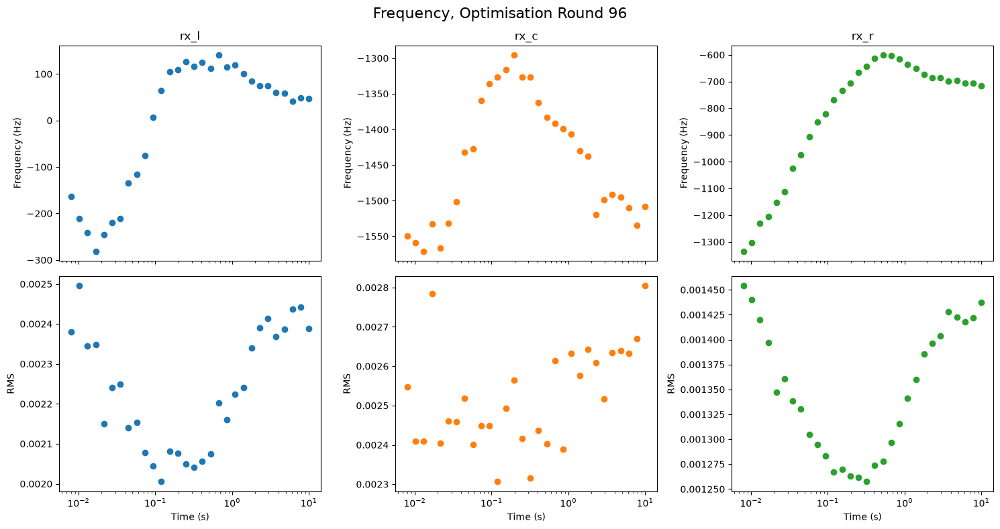

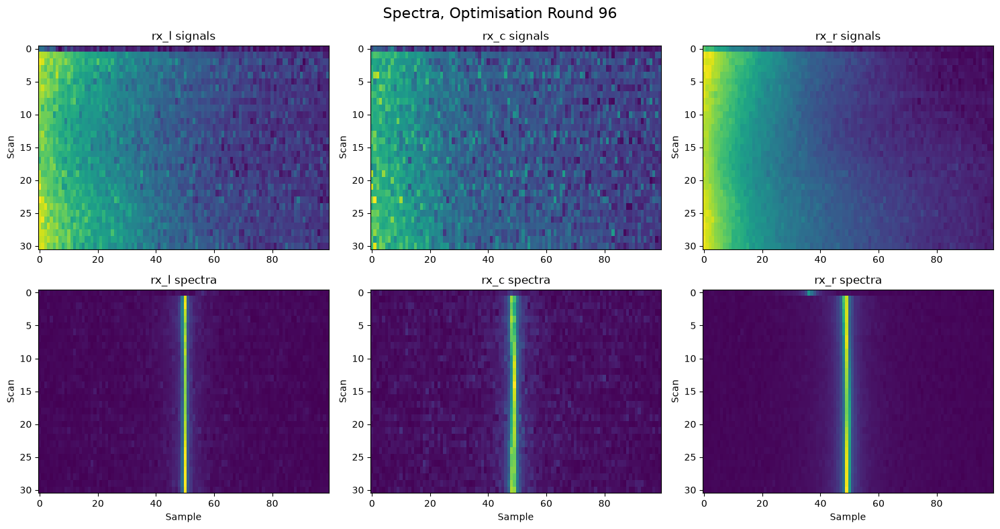

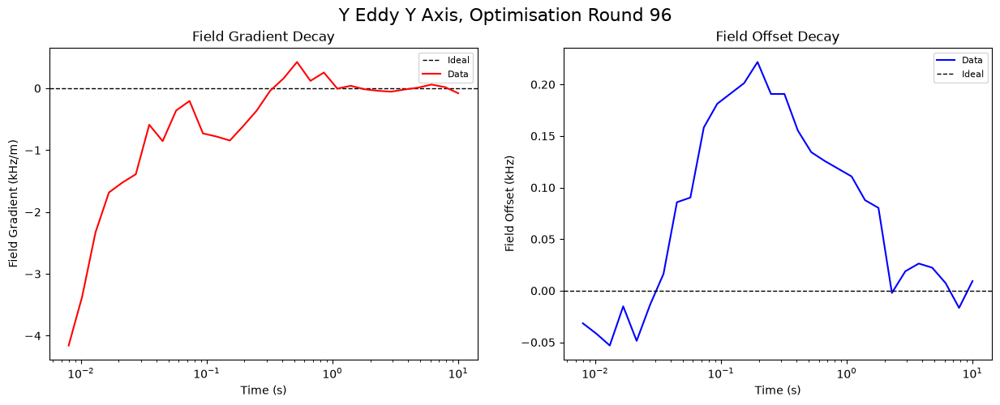

[I 2026-11-25 15:56:15,784] Trial 96 finished with value: 673.6668181827222 and parameters: {'Y_A1': 0.05465162273634427, 'Y_A2': 0.1269184979714973, 'Y_A3': 0.10295412965507912, 'Y_A4': 1.0597630721464298e-09}. Best is trial 96 with value: 673.6668181827222.


max |E| = 11709.145427286354
mean |E| = 8183.075129102114
RMS E = 8250.240139193727
Total cost = 6.737e+02
E max = 0.13471298272675325
E nanmax = 0.13471298272675325
E contains nan = False
B max = 0.26188660532665026
B nanmax = 0.26188660532665026
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26188660532665026 !!!!!!!!!!!!!!!!


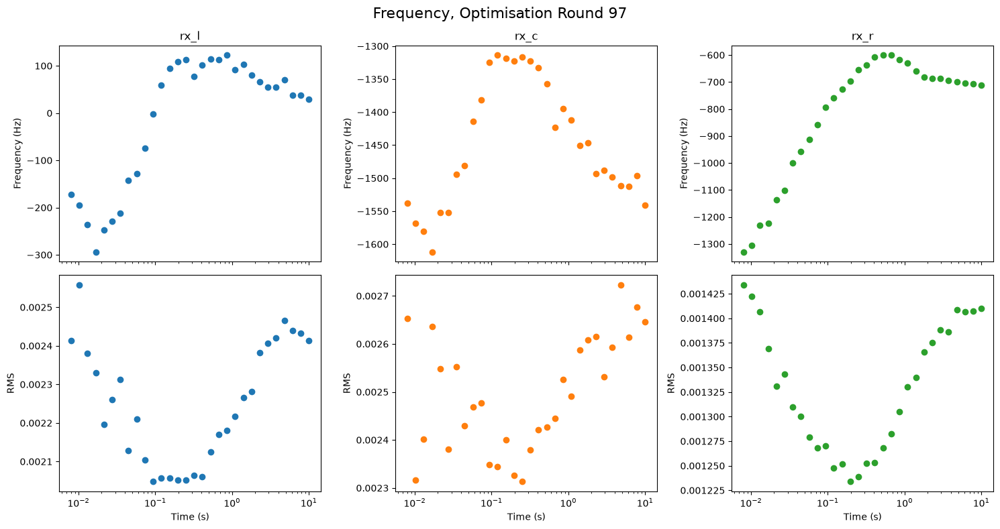

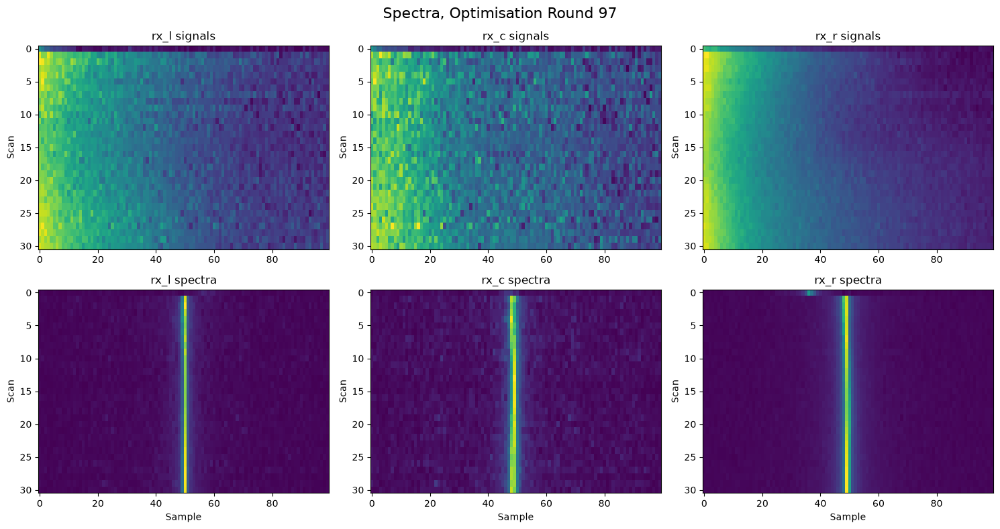

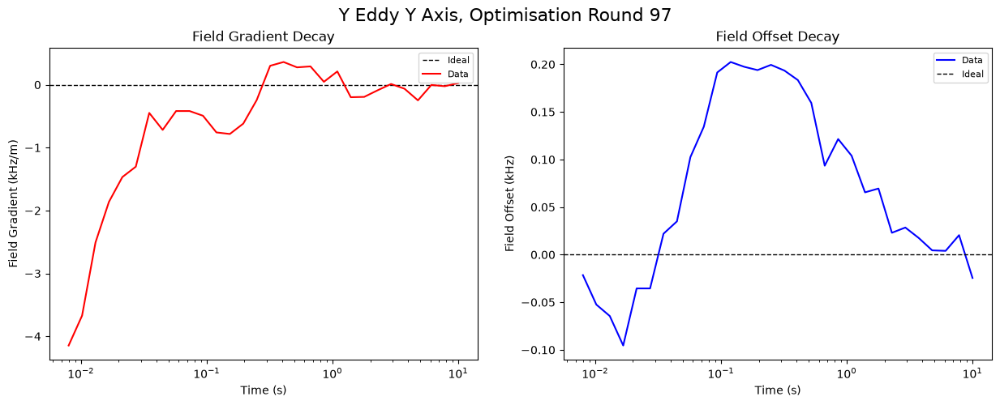

[I 2026-11-25 15:57:04,331] Trial 97 finished with value: 1039.5033373781234 and parameters: {'Y_A1': 0.05577808689067338, 'Y_A2': 0.1282837837034923, 'Y_A3': 0.10083808605879109, 'Y_A4': 1.1630593060208447e-09}. Best is trial 96 with value: 673.6668181827222.


max |E| = 11579.210394802596
mean |E| = 8071.131101116106
RMS E = 8144.265376685373
Total cost = 1.040e+03
E max = 0.1339714857212319
E nanmax = 0.1339714857212319
E contains nan = False
B max = 0.2604451042239645
B nanmax = 0.2604451042239645
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2604451042239645 !!!!!!!!!!!!!!!!


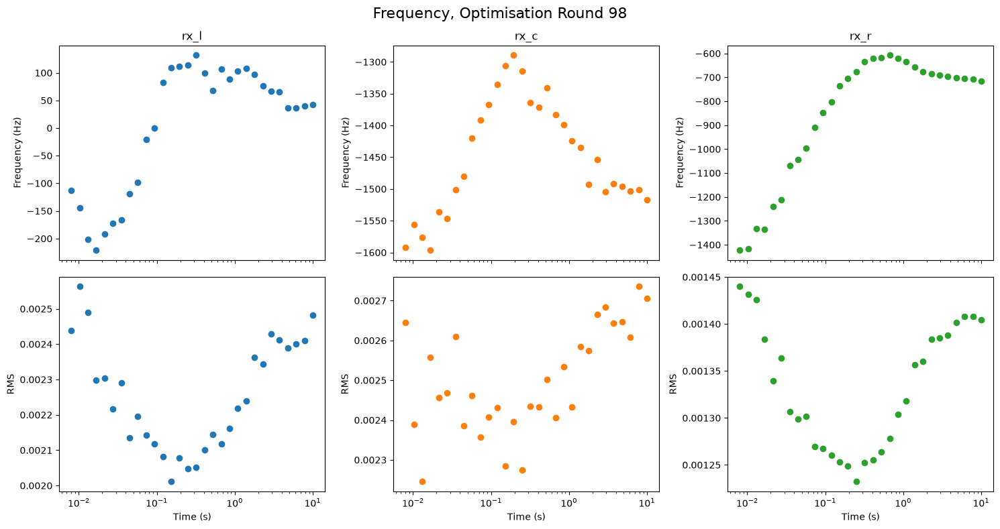

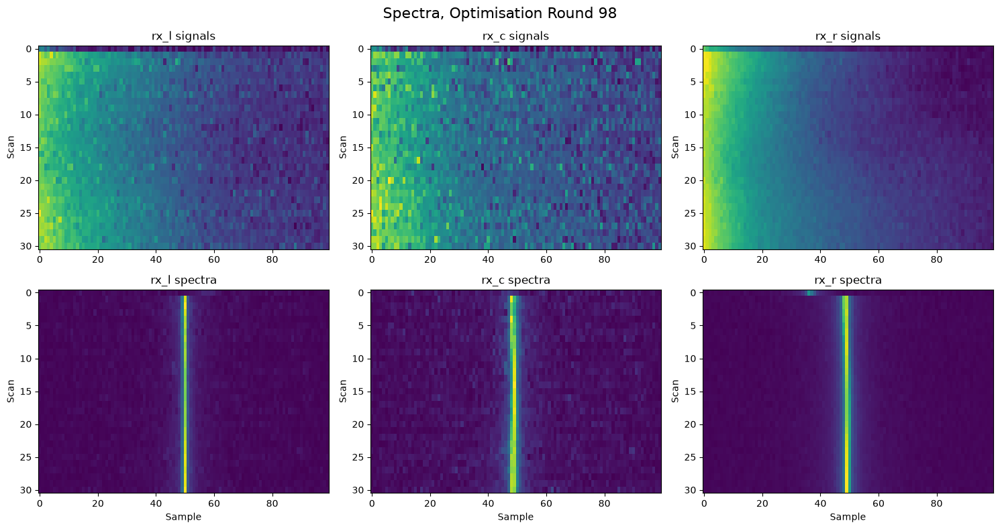

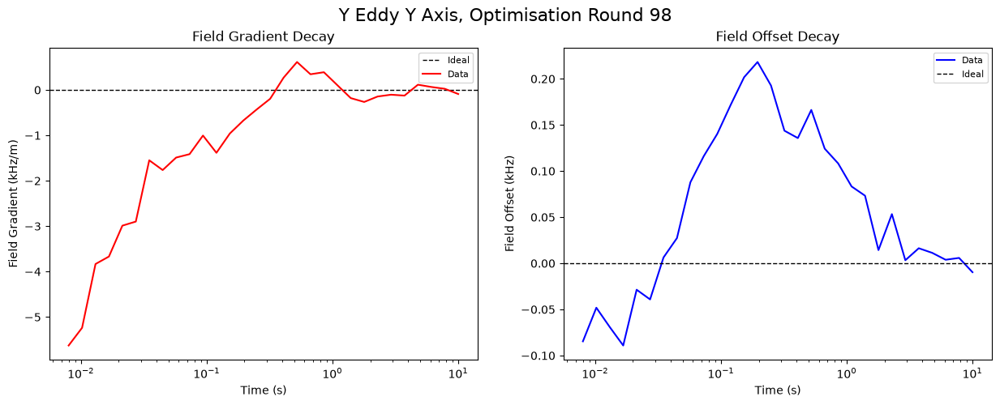

[I 2026-11-25 15:57:53,876] Trial 98 finished with value: 1451.0588559879661 and parameters: {'Y_A1': 0.058124038982869865, 'Y_A2': 0.1266194457874938, 'Y_A3': 0.09537862604050348, 'Y_A4': 1.0250976557092678e-09}. Best is trial 96 with value: 673.6668181827222.


max |E| = 13108.445777111441
mean |E| = 8617.857737797767
RMS E = 8773.07935316515
Total cost = 1.451e+03
E max = 0.13459368348838582
E nanmax = 0.13459368348838582
E contains nan = False
B max = 0.2616546971657202
B nanmax = 0.2616546971657202
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2616546971657202 !!!!!!!!!!!!!!!!


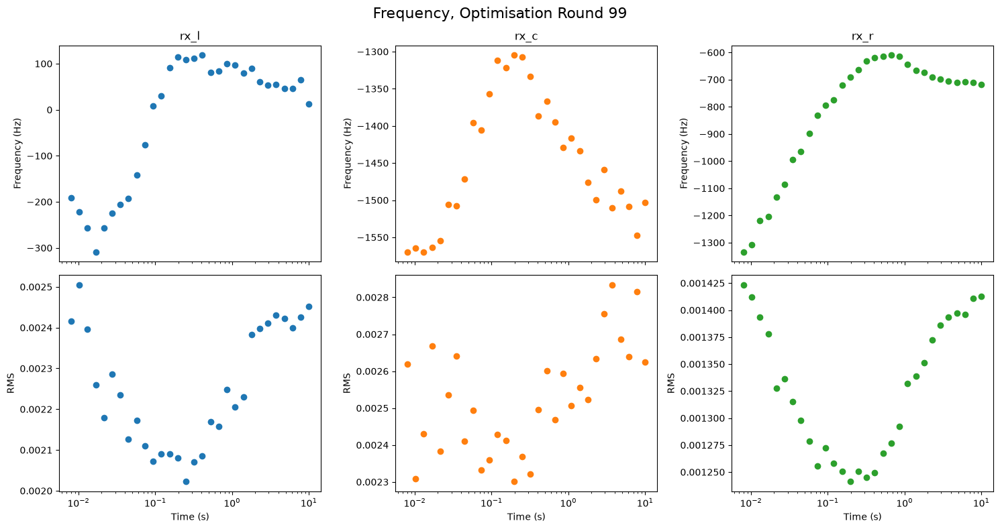

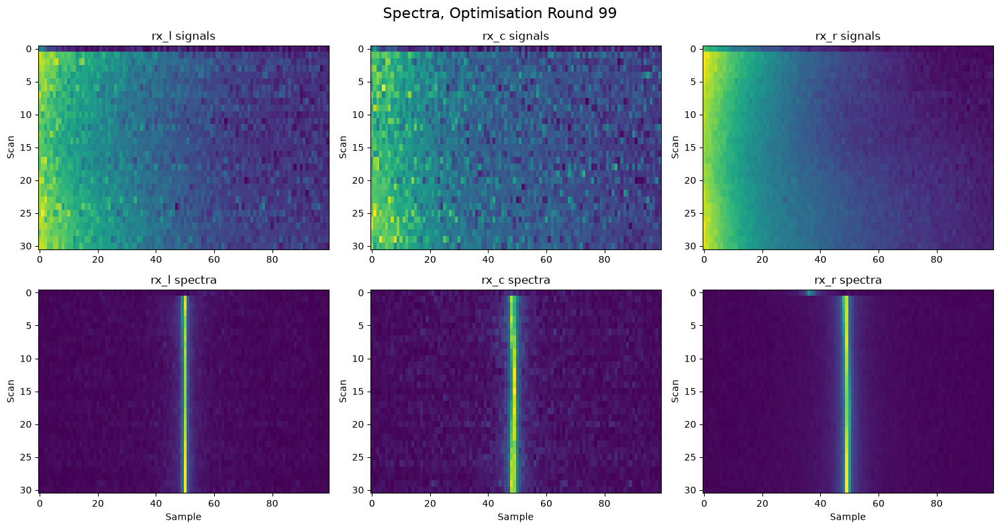

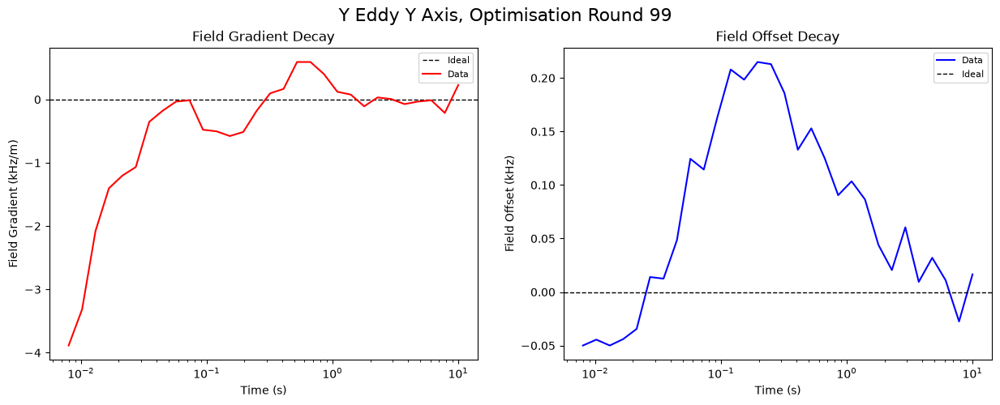

[I 2026-11-25 15:58:42,708] Trial 99 finished with value: 1333.2687096277105 and parameters: {'Y_A1': 0.052620461300427225, 'Y_A2': 0.1282732192481615, 'Y_A3': 0.10295490831440235, 'Y_A4': 2.56476724132955e-09}. Best is trial 96 with value: 673.6668181827222.


max |E| = 11424.287856071962
mean |E| = 8001.665833749789
RMS E = 8065.614438272245
Total cost = 1.333e+03
{'Y_A1': 0.05465162273634427, 'Y_A2': 0.1269184979714973, 'Y_A3': 0.10295412965507912, 'Y_A4': 1.0597630721464298e-09}
96
673.6668181827222
{'Y_A1': 0.05465162273634427, 'Y_A2': 0.1269184979714973, 'Y_A3': 0.10295412965507912, 'Y_A4': 1.0597630721464298e-09}


,trial,cost,g_pe_perc,max_b0var,status,Y_A1,Y_A2,Y_A3,Y_A4
0,0,1599.145893,129.265061,0.251296,PASS,0.050265,0.120533,0.076197,0.000000e+00
1,1,4897.375024,120.572833,0.234398,PASS,0.038384,0.091617,0.052327,1.053230e-09
2,2,2774.411626,127.500865,0.247866,PASS,0.069485,0.112612,0.053155,-9.994620e-09
3,3,1331.909059,131.247168,0.255149,PASS,0.031941,0.135540,0.091359,-2.708441e-09
4,4,1035.496734,133.262102,0.259066,PASS,0.045301,0.133229,0.095487,4.472182e-09
...,...,...,...,...,...,...,...,...,...
95,95,1580.590359,134.707972,0.261877,PASS,0.058275,0.122200,0.104781,2.339755e-09
96,96,673.666818,134.662851,0.261789,PASS,0.054652,0.126918,0.102954,1.059763e-09
97,97,1039.503337,134.712983,0.261887,PASS,0.055778,0.128284,0.100838,1.163059e-09
98,98,1451.058856,133.971486,0.260445,PASS,0.058124,0.126619,0.095379,1.025098e-09


In [8]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = E_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "gradient_info.csv", index=False)

df_pars = pd.DataFrame(seq_params.items(), columns=["Parameter", "Value"])
df_pars.to_csv(Path.cwd() / OPT_AXIS / "df_pars.csv", index=False)

opt.save_to_global(E_START, OPT_AXIS, "eddy_E.yaml")

#### Plot Optimisation Performance

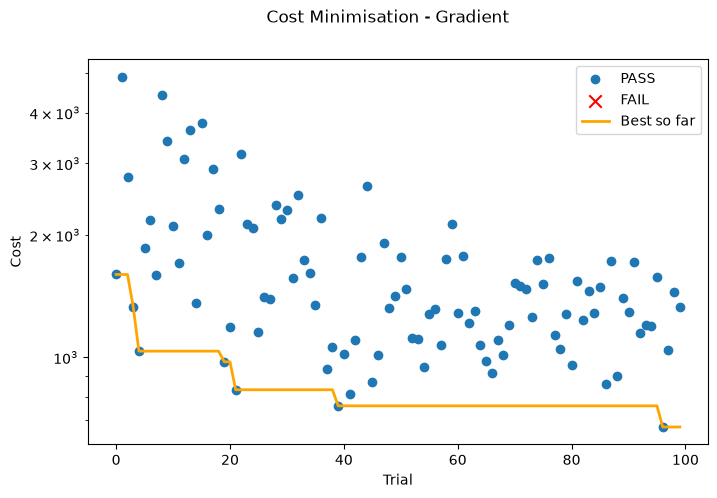

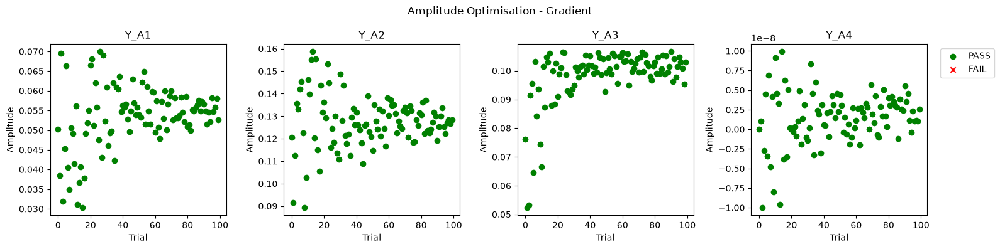

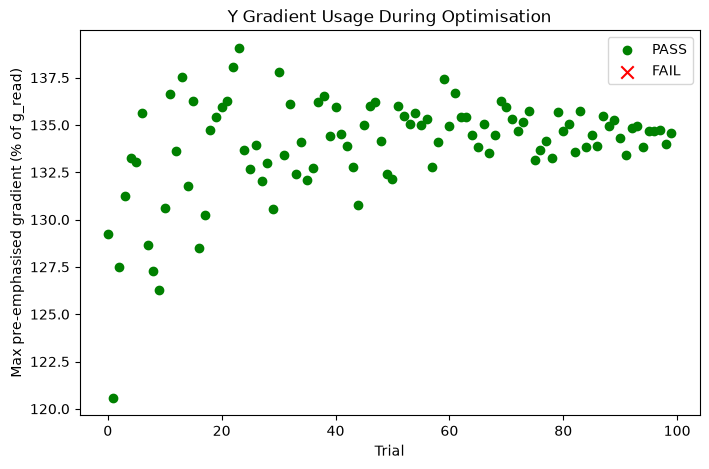

In [9]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)

### Run Offset (B0 Frequency) Optimiser

#### Set optimisation parameters for the offset

In [10]:
num_trials = 100 # number of trials to optimise over
percentage = 50 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "F" # tells that this is optimising the B0 offset (F)

# optimise B0 using the best pre-emphasis parameters from the gradient optimiser
E_START_opt = copy.deepcopy(E_START)
for i in range(1, MAX_EXP+1):
    E_START_opt[f"{OPT_AXIS}"][f"A{i}"] = best[f"{OPT_AXIS}_A{i}"]

#### Start and run optimiser sequence for gradient

[I 2026-11-25 15:58:43,337] A new study created in memory with name: no-name-1de766a1-c318-46c2-ac13-28f3b0072d19


E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2617891513699515
B nanmax = 0.2617891513699515
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2616546971657202 !!!!!!!!!!!!!!!!


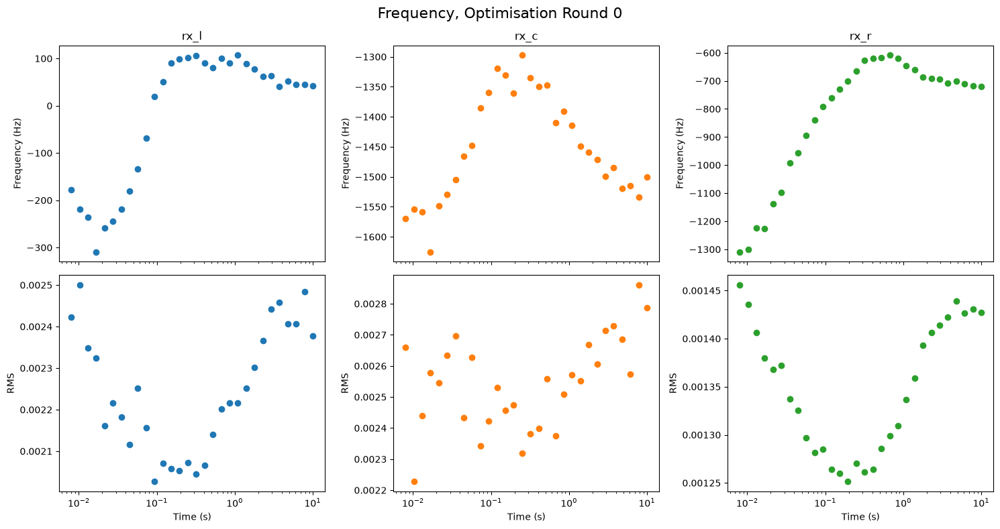

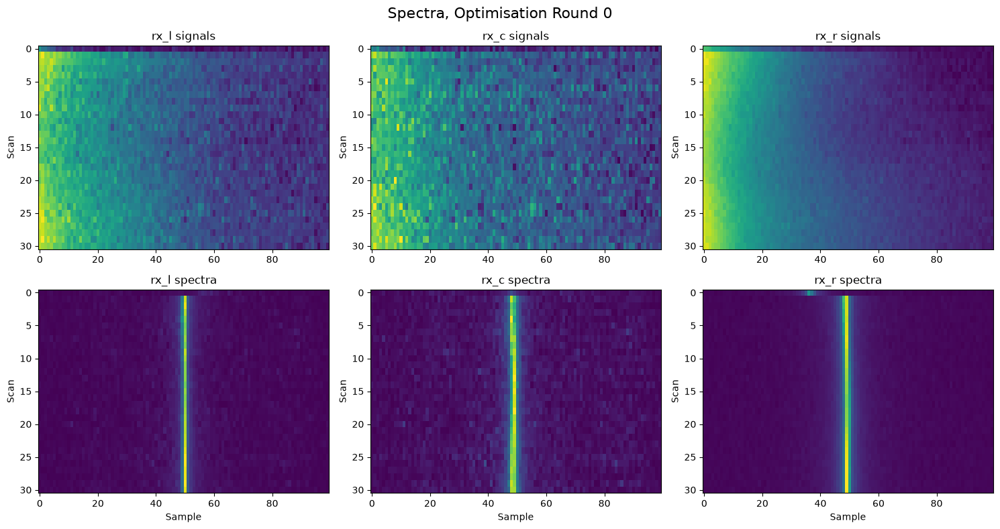

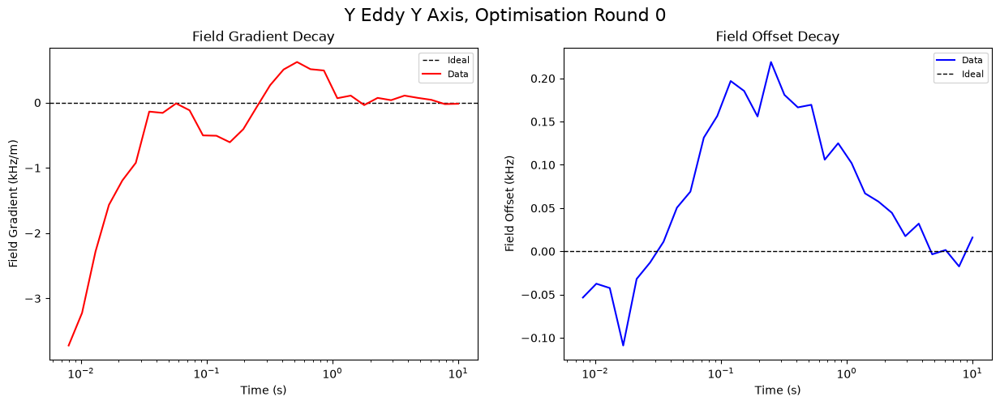

[I 2026-11-25 15:59:32,570] Trial 0 finished with value: 342.15742972563186 and parameters: {'Y_A1': -0.0129530863391364, 'Y_A2': -0.0056101475815073, 'Y_A3': 0, 'Y_A4': 0}. Best is trial 0 with value: 342.15742972563186.


rx_c: 3.422e+02
Total cost = 3.422e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2947602249375943
B nanmax = 0.2947602249375943
B contains nan = False
Trial 1


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2946088381068395 !!!!!!!!!!!!!!!!


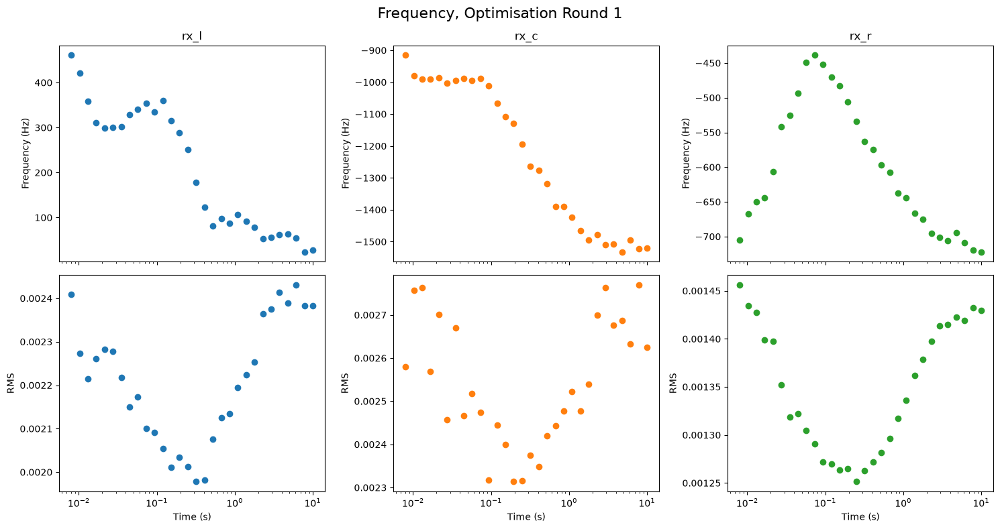

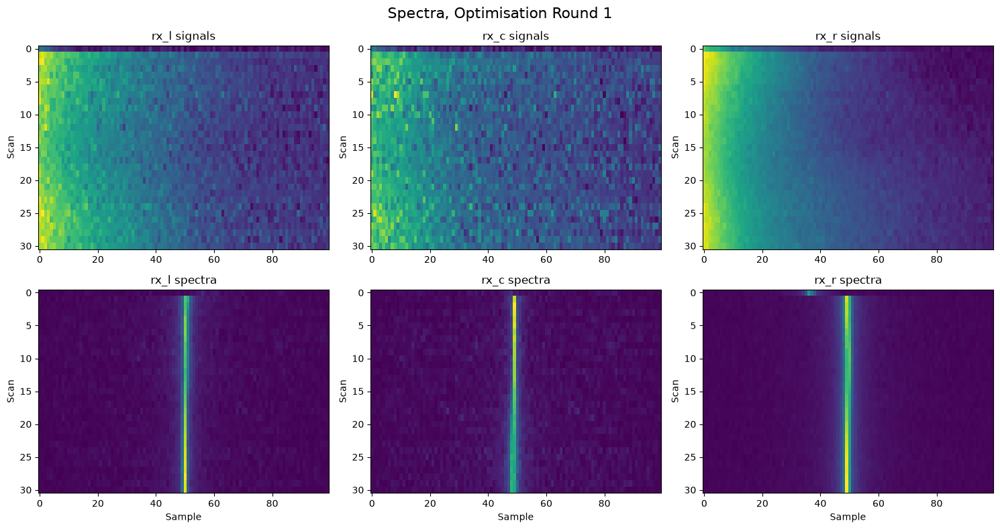

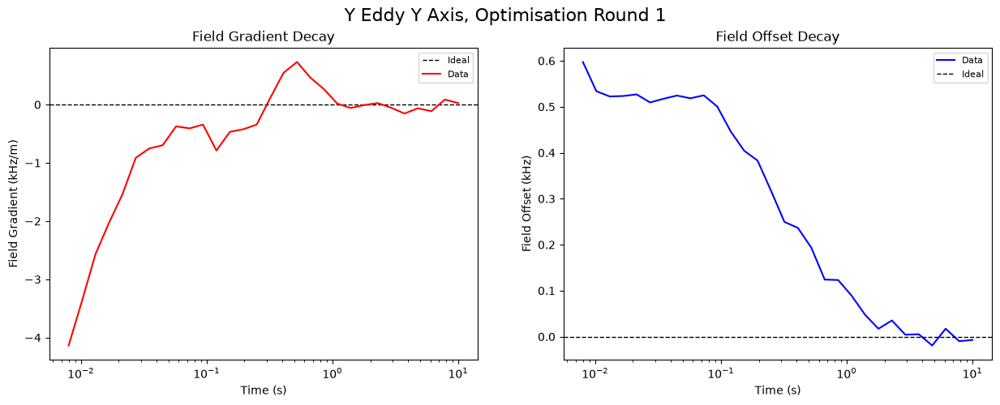

[I 2026-11-25 16:00:21,362] Trial 1 finished with value: 385.99701412139615 and parameters: {'Y_A1': -0.012826222522090463, 'Y_A2': -0.008078254161404968, 'Y_A3': 1.8617032850984423e-09, 'Y_A4': 7.505169057606837e-09}. Best is trial 0 with value: 342.15742972563186.


rx_c: 3.860e+02
Total cost = 3.860e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.221274112849395
B nanmax = 0.221274112849395
B contains nan = False
Trial 2


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:B0 uses pre-emphasised gradient
DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.22116046790721933 !!!!!!!!!!!!!!!!


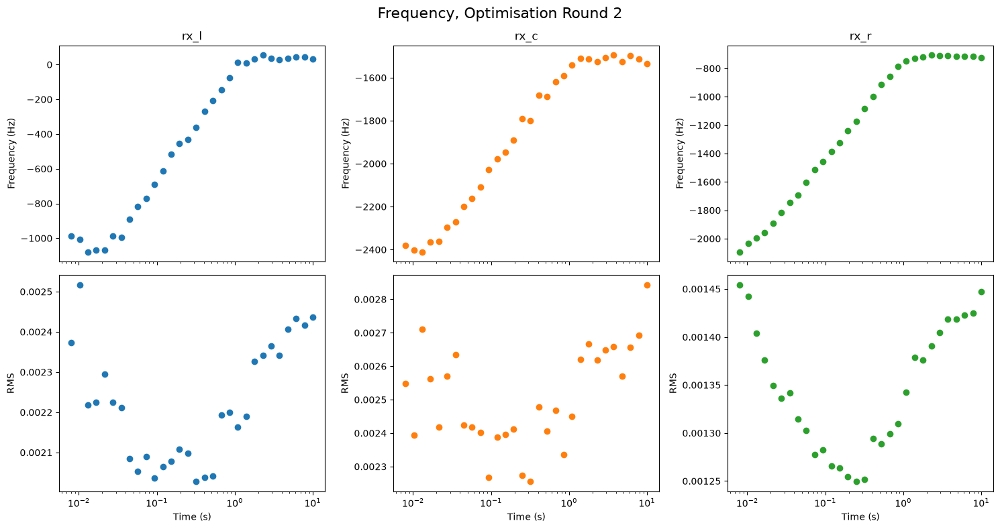

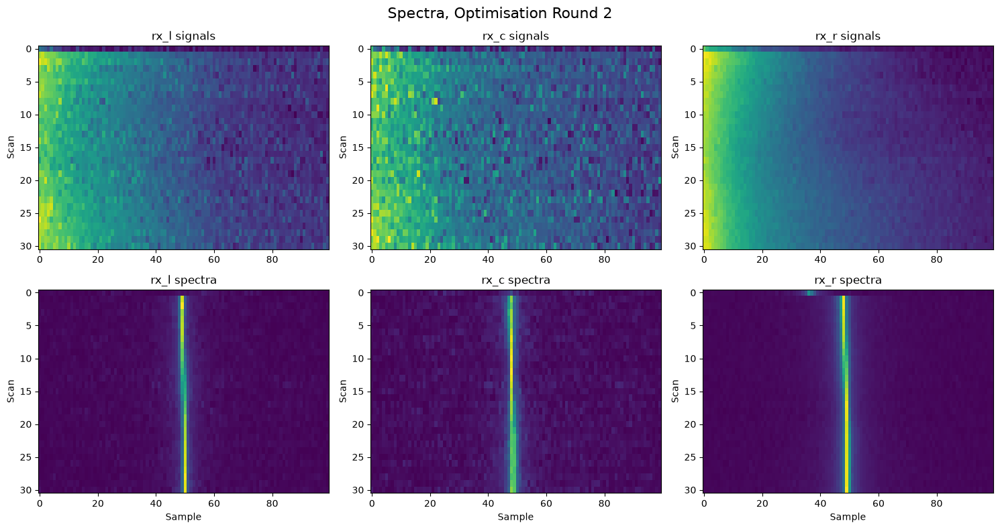

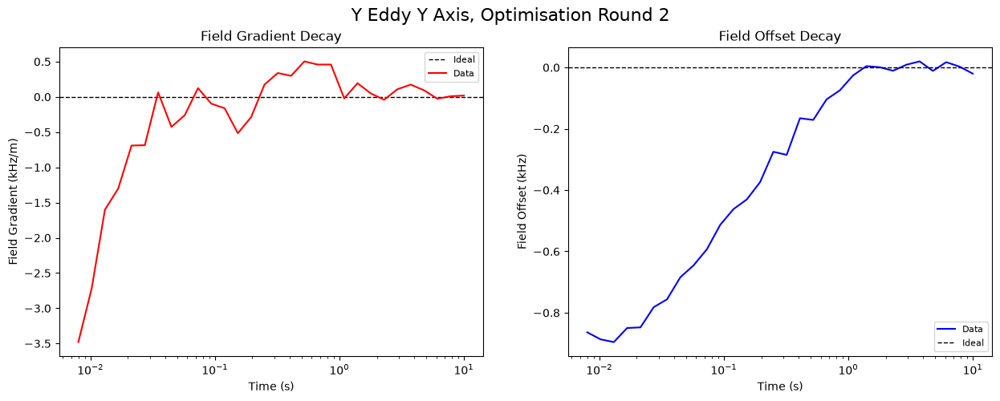

[I 2026-11-25 16:01:11,197] Trial 2 finished with value: 332.4543548031131 and parameters: {'Y_A1': -0.009735612215949778, 'Y_A2': -0.005957008508633877, 'Y_A3': -7.015086476941028e-09, 'Y_A4': -7.244703128306942e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 3.325e+02
Total cost = 3.325e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.27591490970315796
B nanmax = 0.27591490970315796
B contains nan = False
Trial 3


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.27577320041232767 !!!!!!!!!!!!!!!!


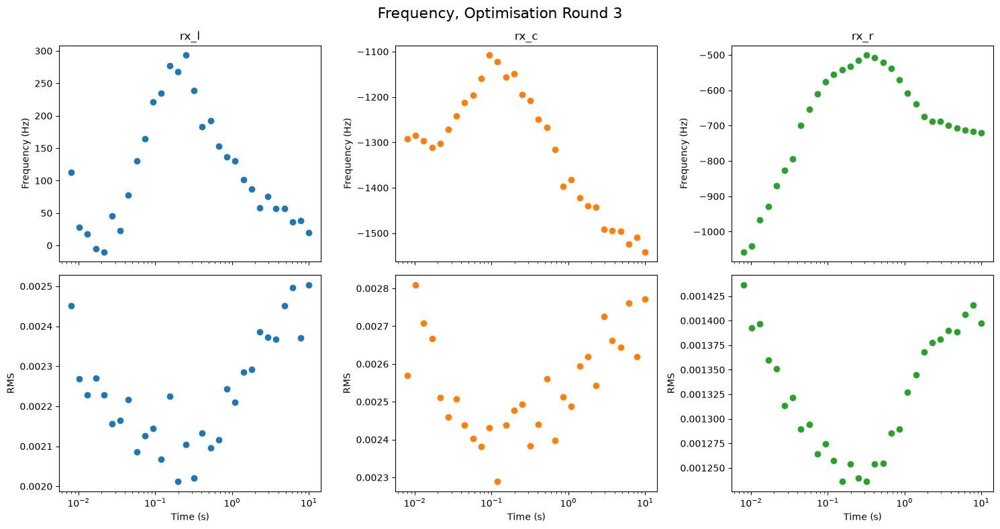

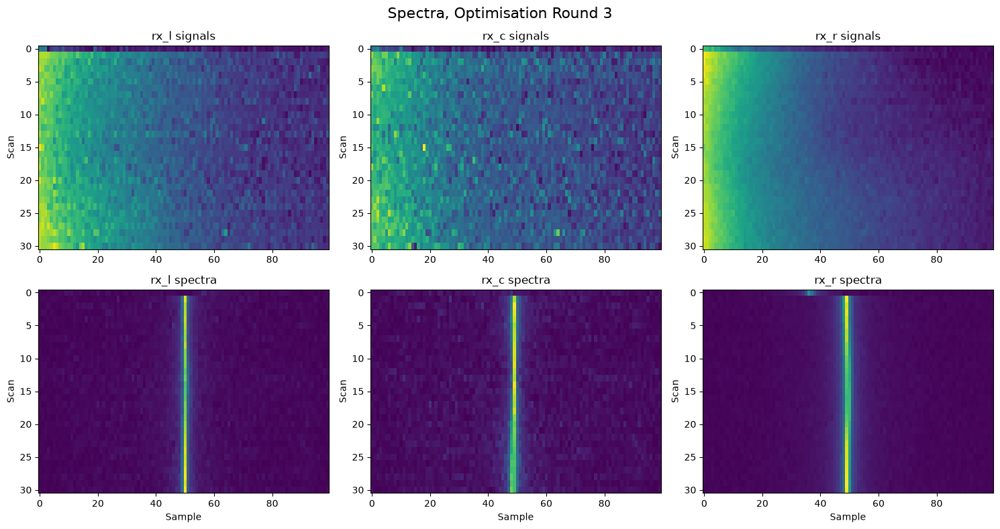

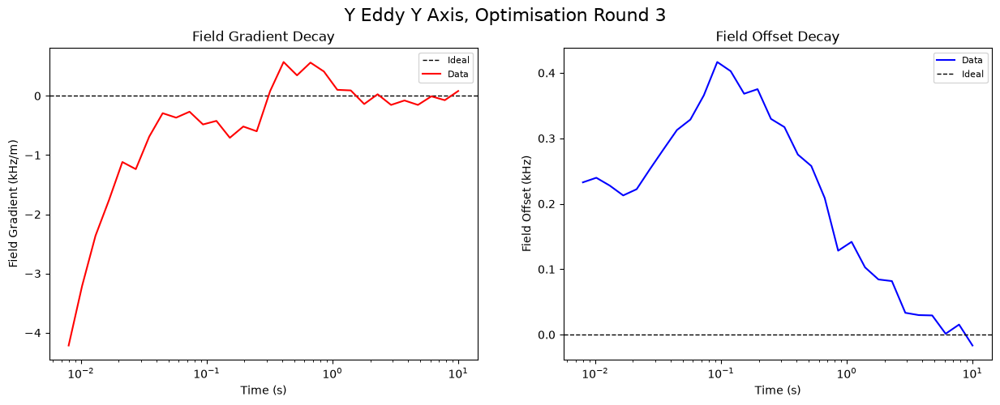

[I 2026-11-25 16:01:59,931] Trial 3 finished with value: 540.3163479153596 and parameters: {'Y_A1': -0.01384542405502806, 'Y_A2': -0.005719092430565852, 'Y_A3': 6.255752060108079e-09, 'Y_A4': 7.192395578851e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 5.403e+02
Total cost = 5.403e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.33914098314745456
B nanmax = 0.33914098314745456
B contains nan = False
Trial 4


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.3389668018651004 !!!!!!!!!!!!!!!!


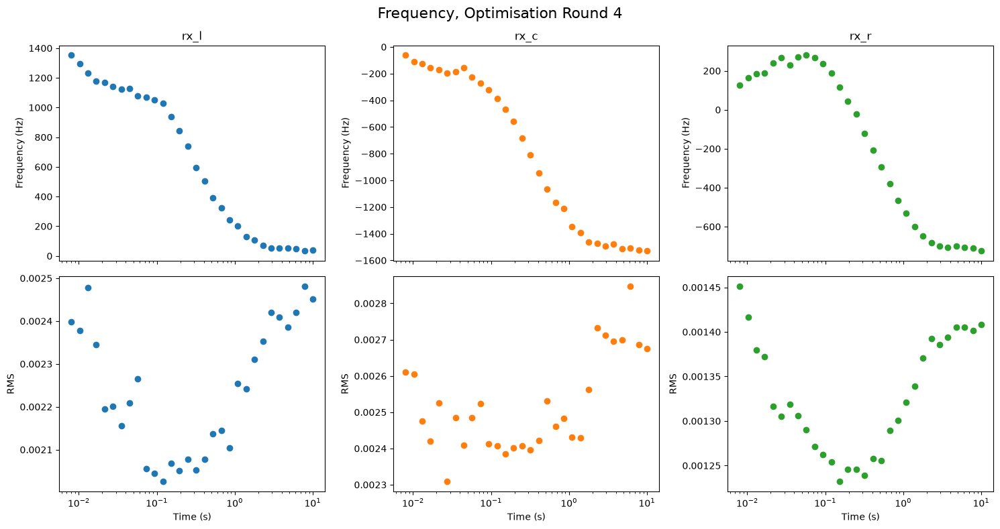

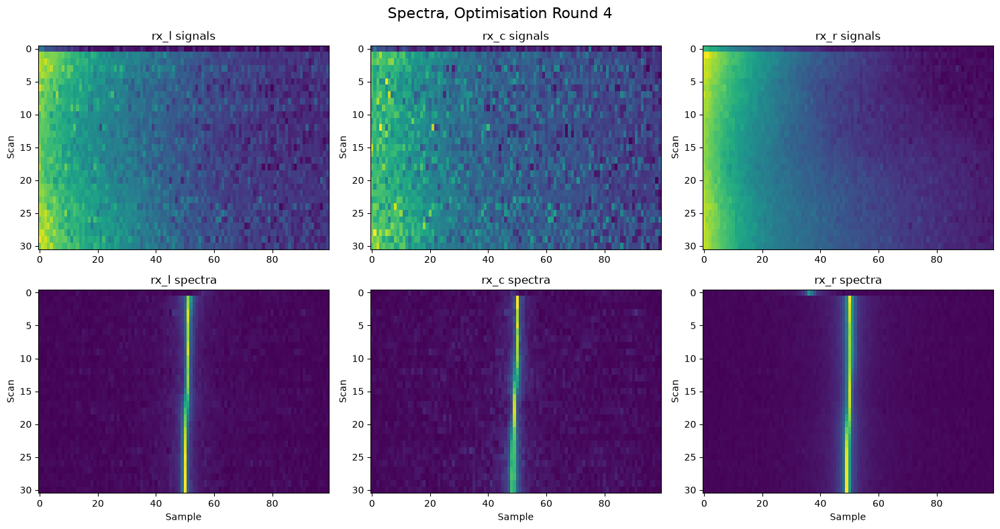

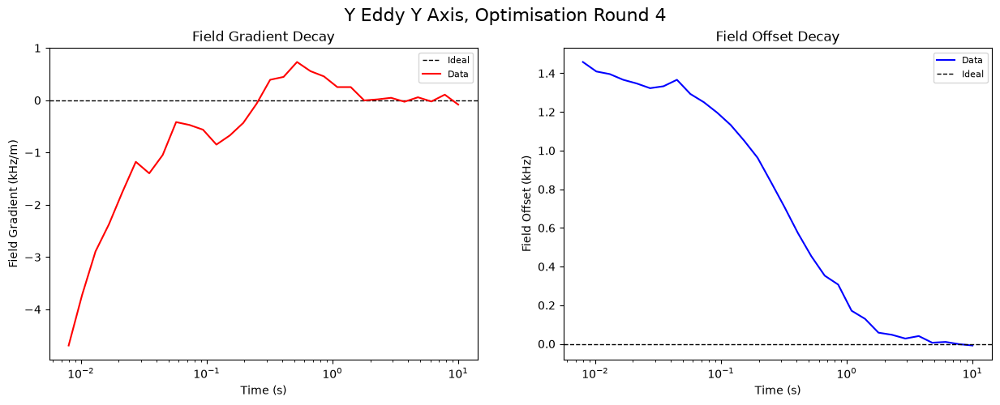

[I 2026-11-25 16:02:47,804] Trial 4 finished with value: 832.9027602145785 and parameters: {'Y_A1': -0.015900425021152794, 'Y_A2': -0.008149406236070219, 'Y_A3': -3.820055073634127e-09, 'Y_A4': 5.8389142805130585e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 8.329e+02
Total cost = 8.329e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.34528746151857515
B nanmax = 0.34528746151857515
B contains nan = False
Trial 5


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.34511012323444157 !!!!!!!!!!!!!!!!


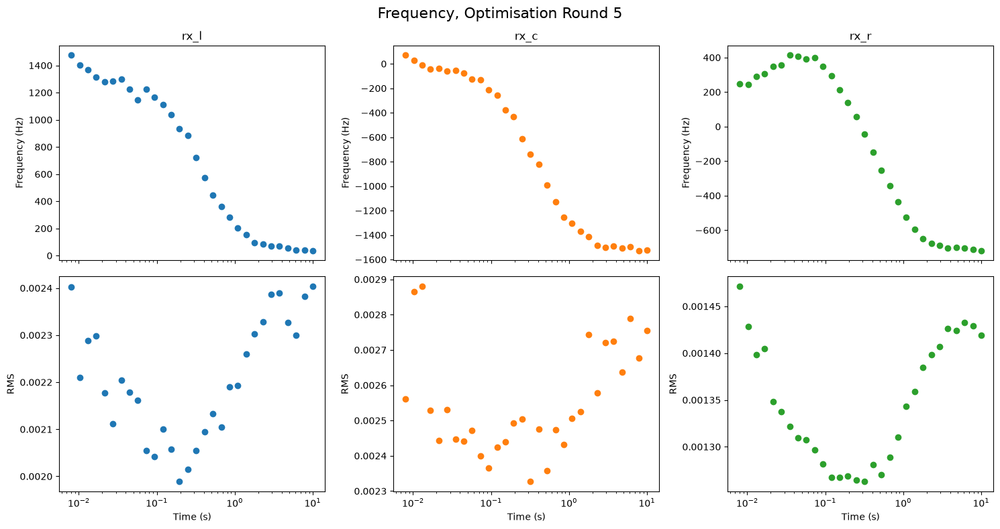

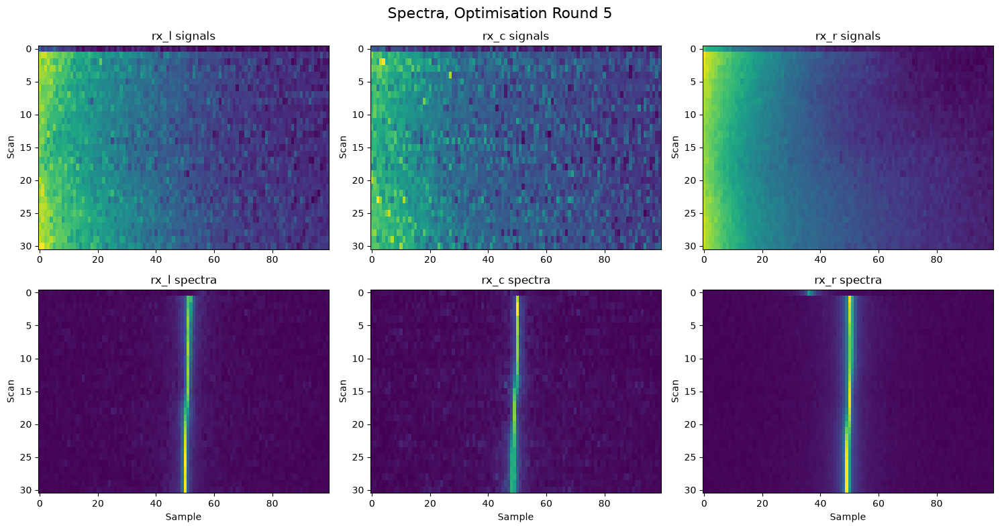

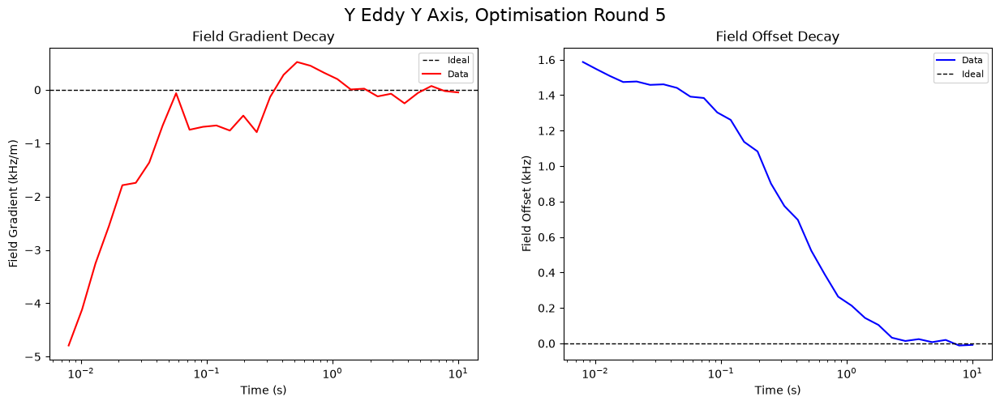

[I 2026-11-25 16:03:35,919] Trial 5 finished with value: 924.180180713261 and parameters: {'Y_A1': -0.01647227147231385, 'Y_A2': -0.008012899556755838, 'Y_A3': -6.826039464097475e-09, 'Y_A4': -2.0038269432433335e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 9.242e+02
Total cost = 9.242e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.15857422704720606
B nanmax = 0.15857422704720606
B contains nan = False
Trial 6


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.15849278423947352 !!!!!!!!!!!!!!!!


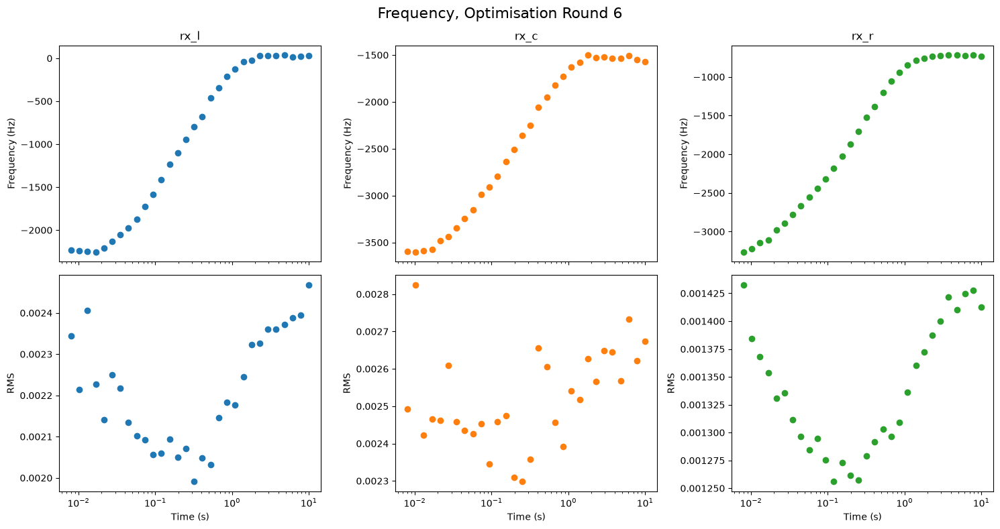

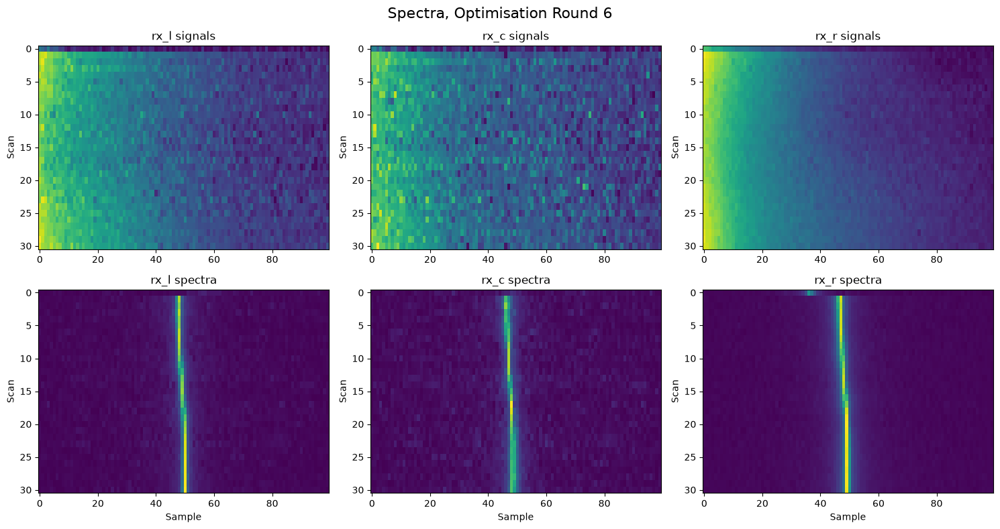

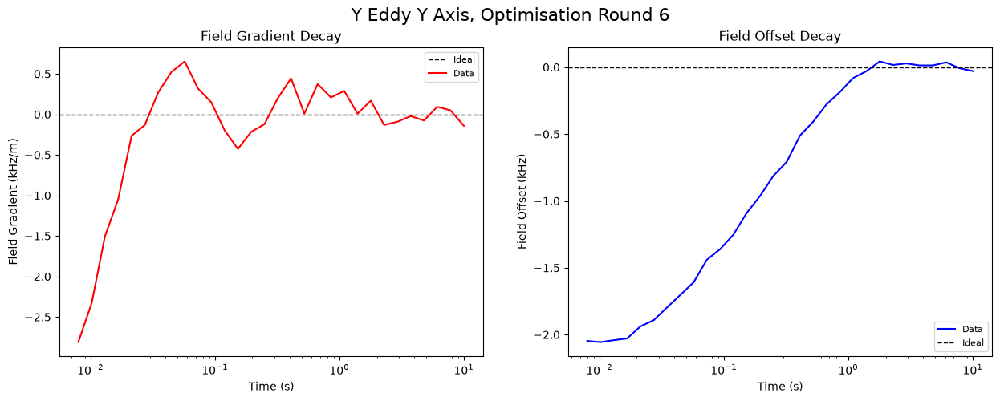

[I 2026-11-25 16:04:25,268] Trial 6 finished with value: 793.6134495681271 and parameters: {'Y_A1': -0.007146226232953254, 'Y_A2': -0.004099440983234632, 'Y_A3': -9.1297497902206e-09, 'Y_A4': 4.668938976949716e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 7.936e+02
Total cost = 7.936e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.3331581464525241
B nanmax = 0.3331581464525241
B contains nan = False
Trial 7


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.33298703530587453 !!!!!!!!!!!!!!!!


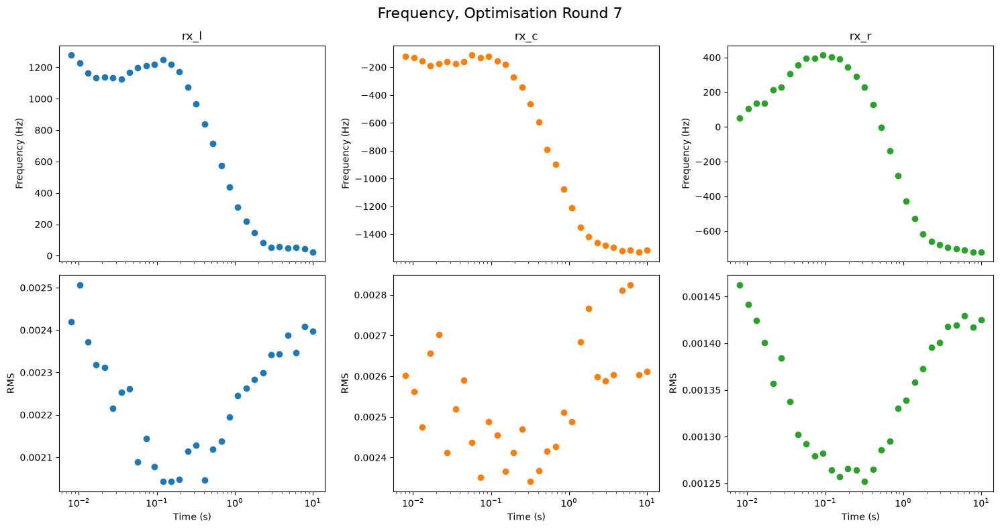

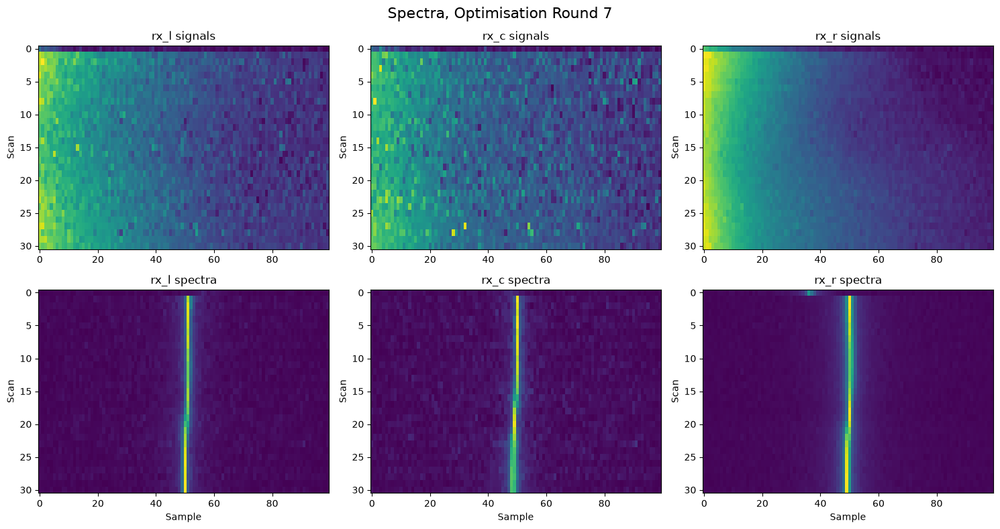

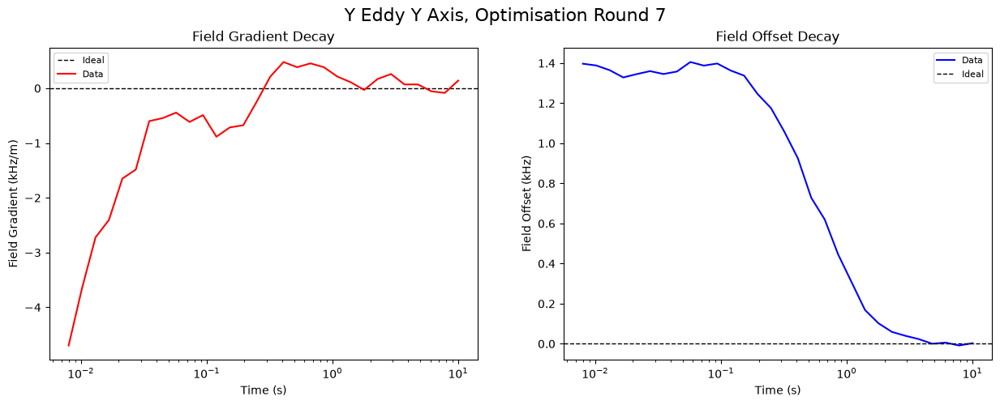

[I 2026-11-25 16:05:15,263] Trial 7 finished with value: 1131.7646424946315 and parameters: {'Y_A1': -0.01937388884433795, 'Y_A2': -0.004244643888090132, 'Y_A3': 9.452822031467094e-09, 'Y_A4': -9.354971627944657e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 1.132e+03
Total cost = 1.132e+03
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2935981272769155
B nanmax = 0.2935981272769155
B contains nan = False
Trial 8


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.29344733529589145 !!!!!!!!!!!!!!!!


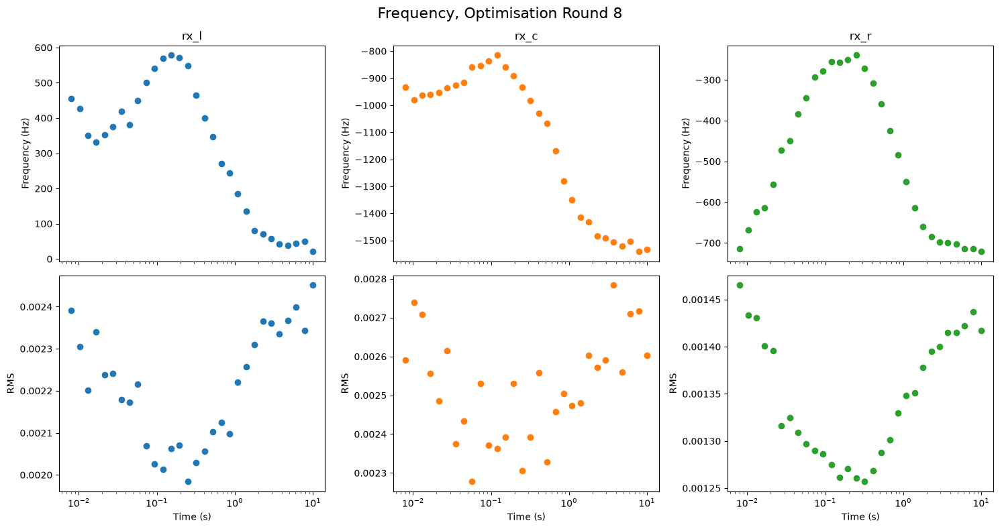

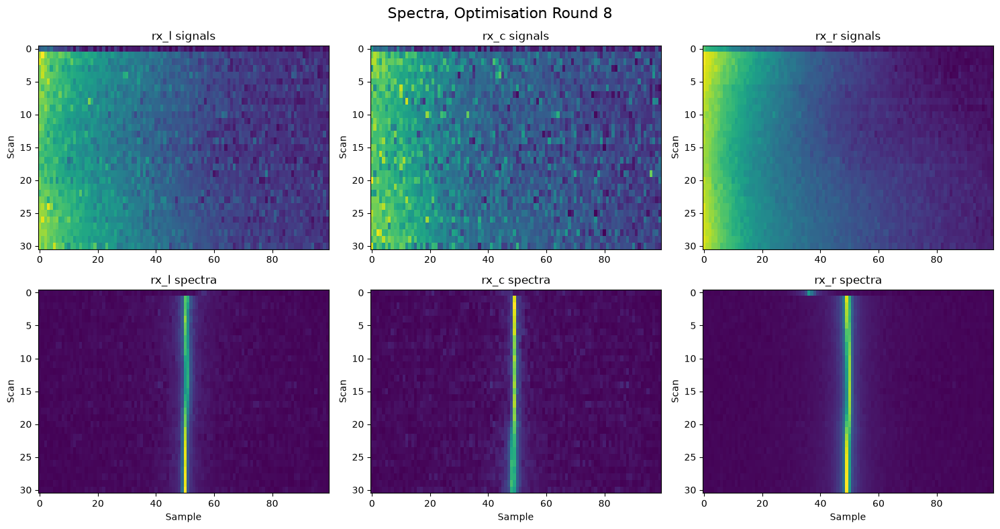

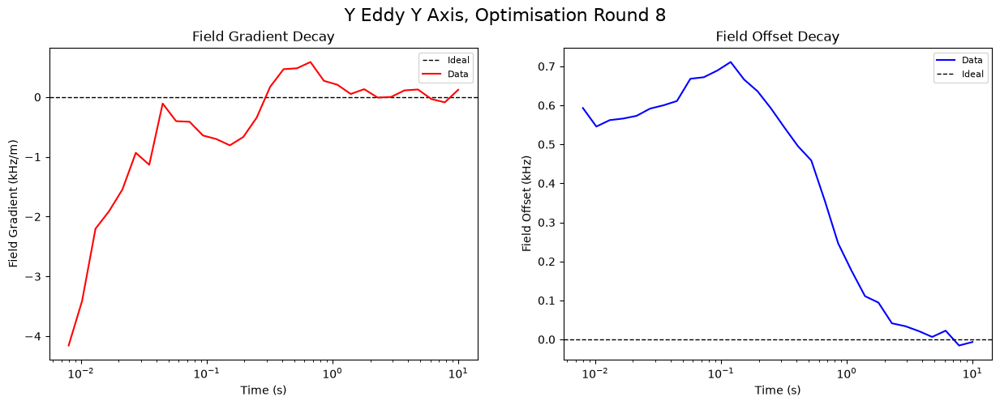

[I 2026-11-25 16:06:03,842] Trial 8 finished with value: 716.6765067869676 and parameters: {'Y_A1': -0.01563256640689782, 'Y_A2': -0.005184142472515063, 'Y_A3': 4.107818009048427e-09, 'Y_A4': -5.721078582448183e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 7.167e+02
Total cost = 7.167e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.3076914483561386
B nanmax = 0.3076914483561386
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.3075334189885834 !!!!!!!!!!!!!!!!


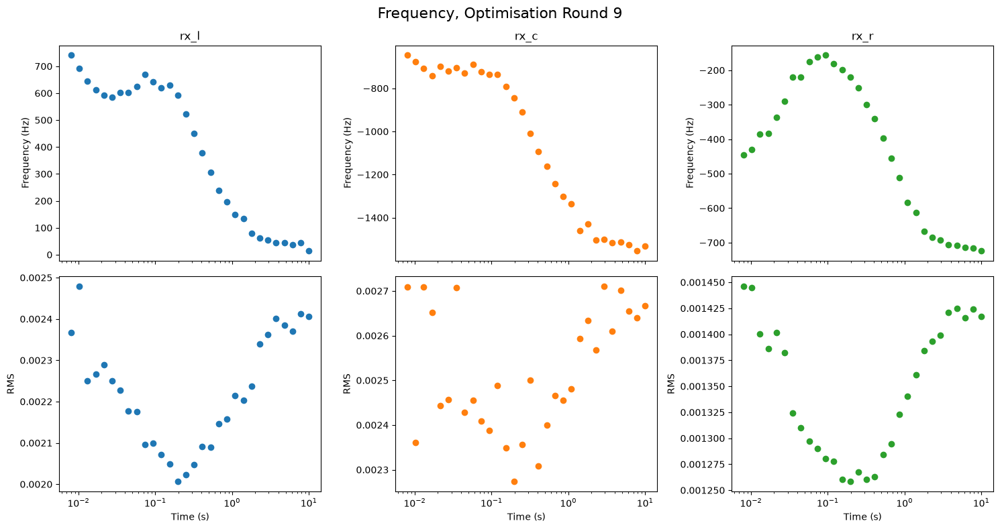

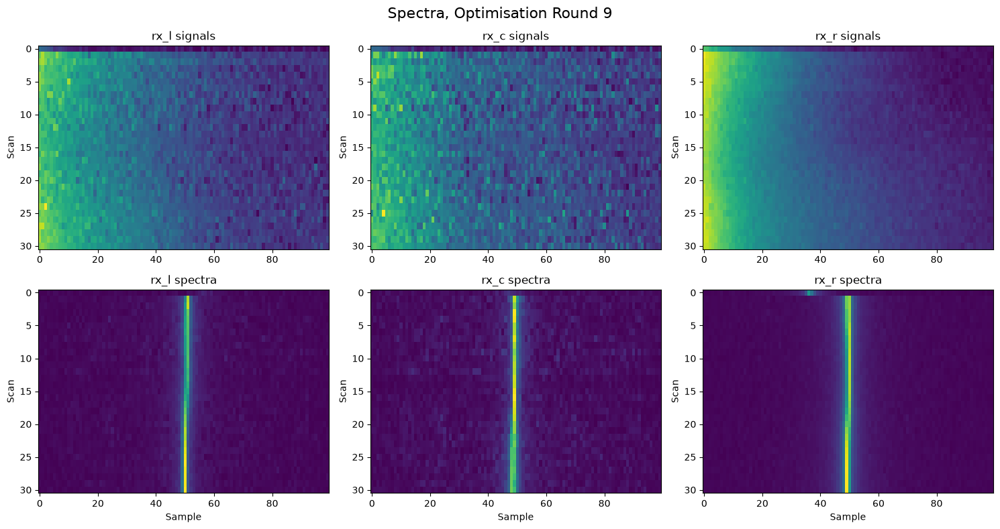

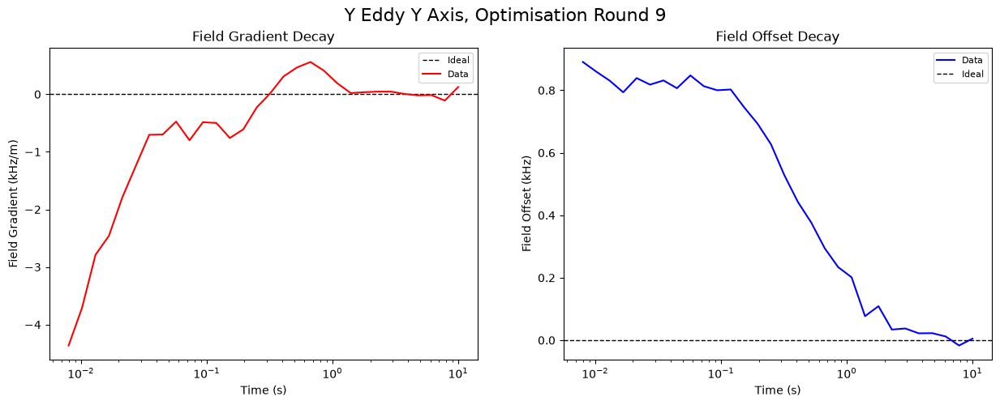

[I 2026-11-25 16:06:54,007] Trial 9 finished with value: 720.1363369257211 and parameters: {'Y_A1': -0.015033929331434576, 'Y_A2': -0.0067845518777910644, 'Y_A3': -9.653024773388604e-09, 'Y_A4': 9.597998050542877e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 7.201e+02
Total cost = 7.201e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.21441037937111018
B nanmax = 0.21441037937111018
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.21430026050272388 !!!!!!!!!!!!!!!!


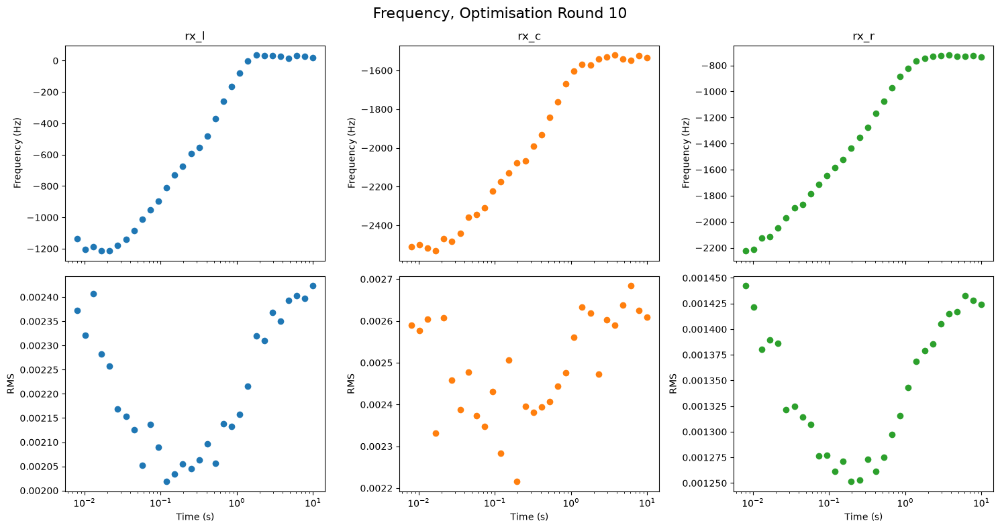

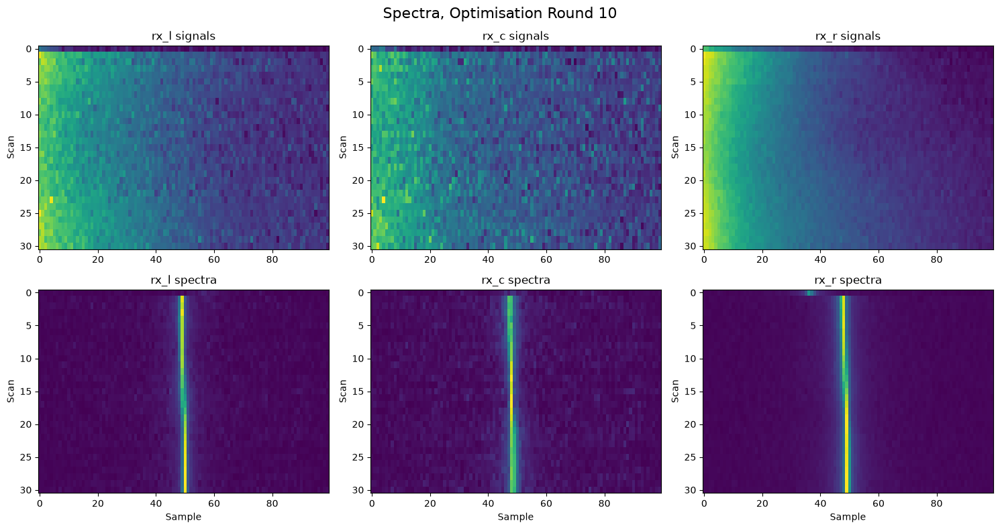

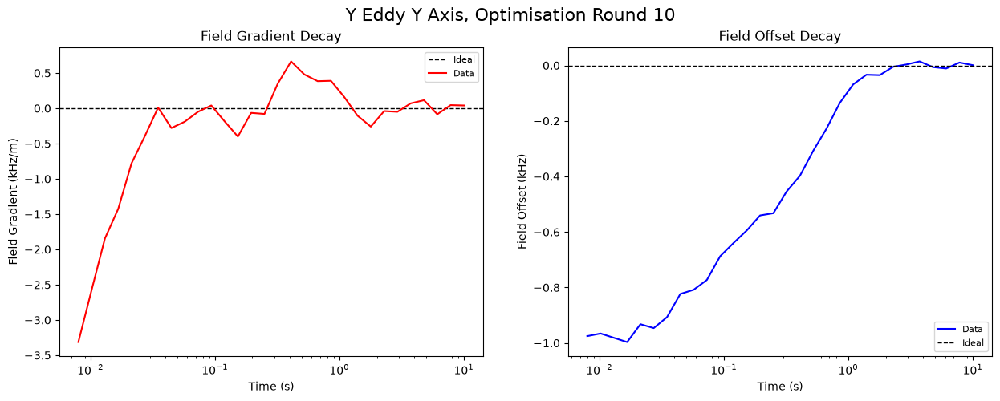

[I 2026-11-25 16:07:42,216] Trial 10 finished with value: 474.42616066564744 and parameters: {'Y_A1': -0.008138053551805795, 'Y_A2': -0.007070222353134583, 'Y_A3': 3.589084896975281e-09, 'Y_A4': 1.2477720540661998e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 4.744e+02
Total cost = 4.744e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.20376211123265509
B nanmax = 0.20376211123265509
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2036574600858635 !!!!!!!!!!!!!!!!


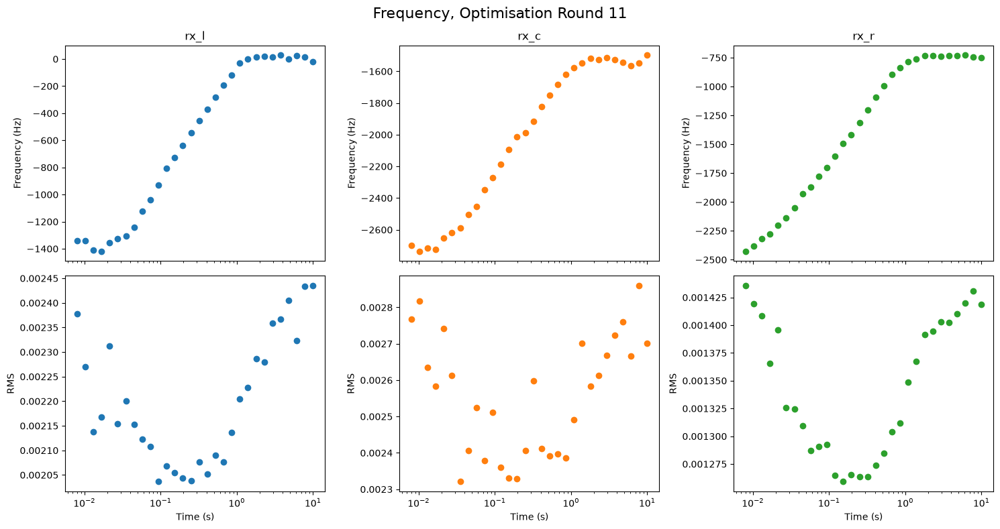

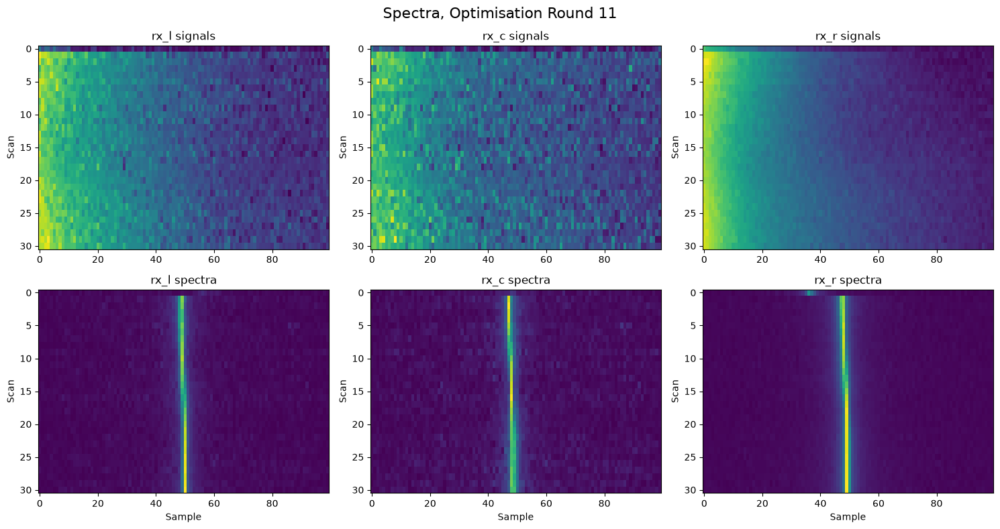

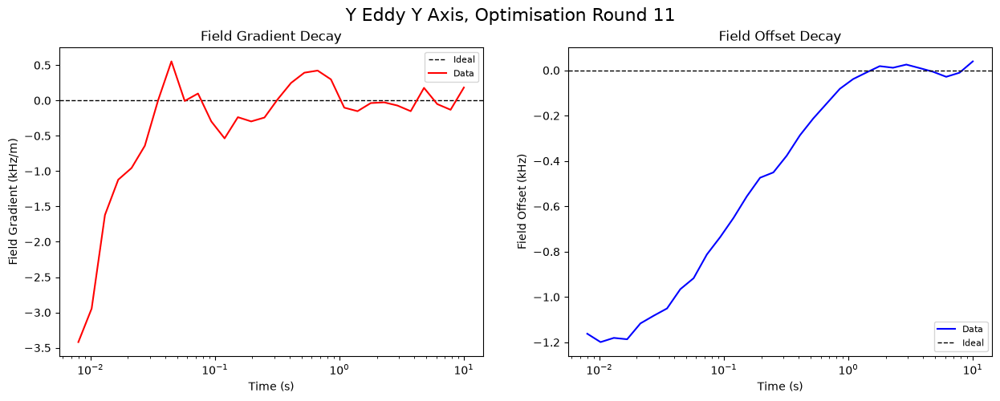

[I 2026-11-25 16:08:29,962] Trial 11 finished with value: 481.43010730284743 and parameters: {'Y_A1': -0.009329472271036787, 'Y_A2': -0.005120525829042666, 'Y_A3': -8.095939631659437e-09, 'Y_A4': -8.555211707593544e-09}. Best is trial 2 with value: 332.4543548031131.


rx_c: 4.814e+02
Total cost = 4.814e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24329288139375435
B nanmax = 0.24329288139375435
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24316792698774933 !!!!!!!!!!!!!!!!


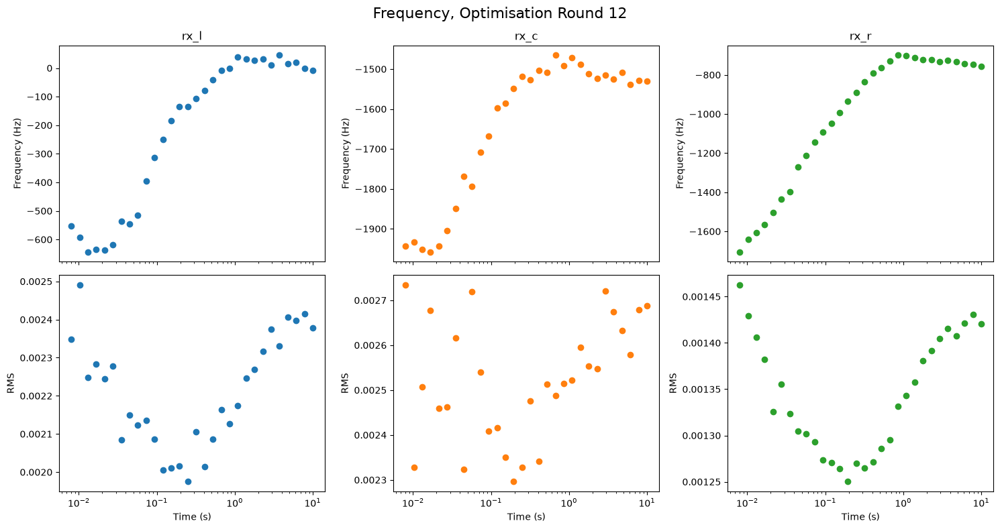

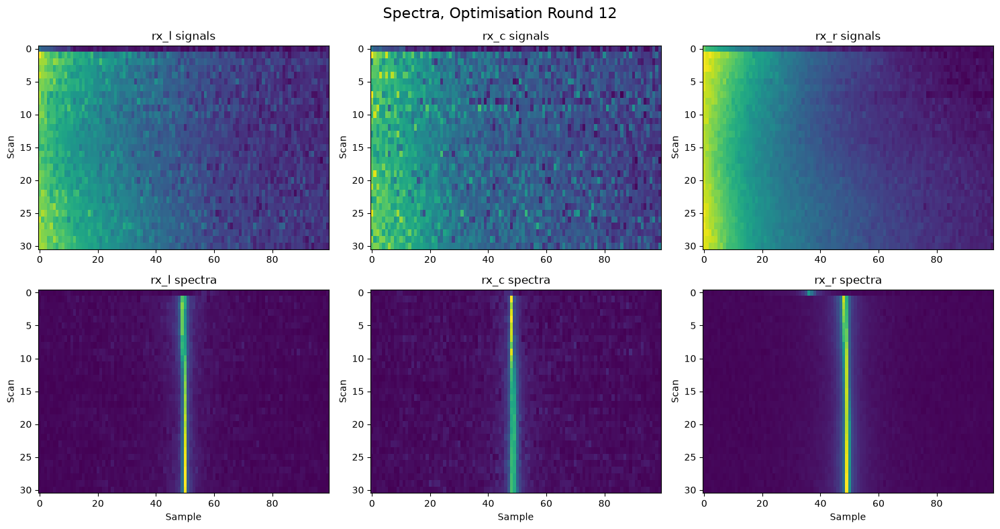

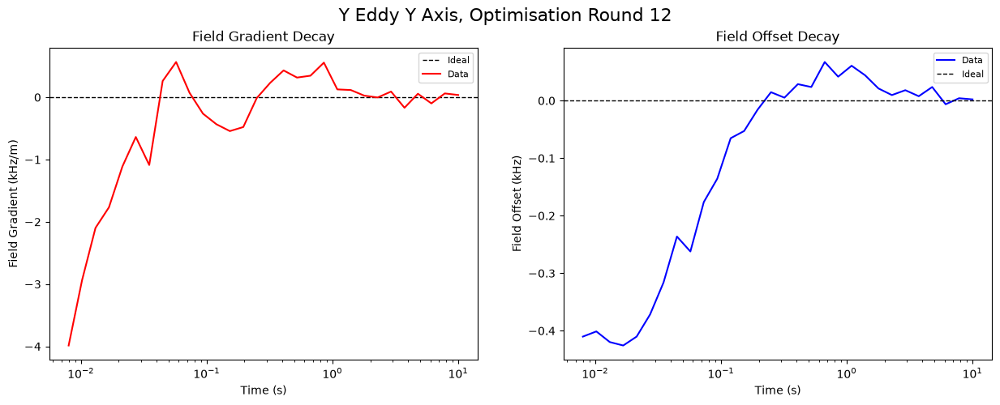

[I 2026-11-25 16:09:17,699] Trial 12 finished with value: 171.94550592568584 and parameters: {'Y_A1': -0.011803561781749784, 'Y_A2': -0.005448557197567349, 'Y_A3': 7.130028489150199e-10, 'Y_A4': 2.637017174133885e-10}. Best is trial 12 with value: 171.94550592568584.


rx_c: 1.719e+02
Total cost = 1.719e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.19482443231033394
B nanmax = 0.19482443231033394
B contains nan = False
Trial 13


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.19472437089456282 !!!!!!!!!!!!!!!!


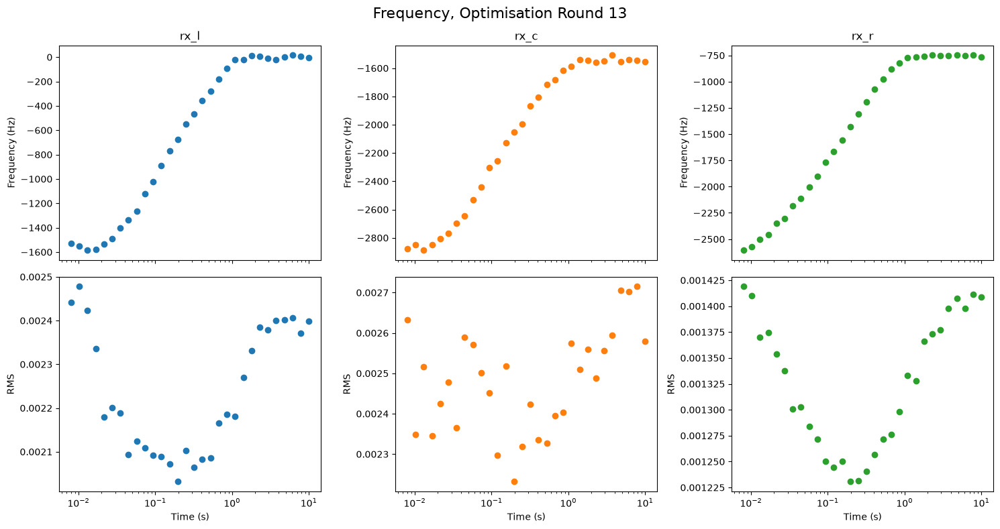

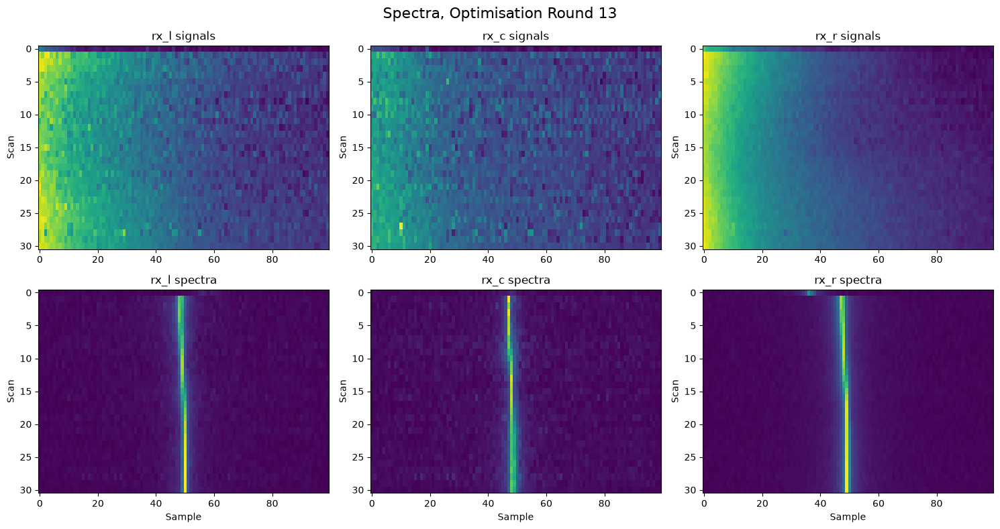

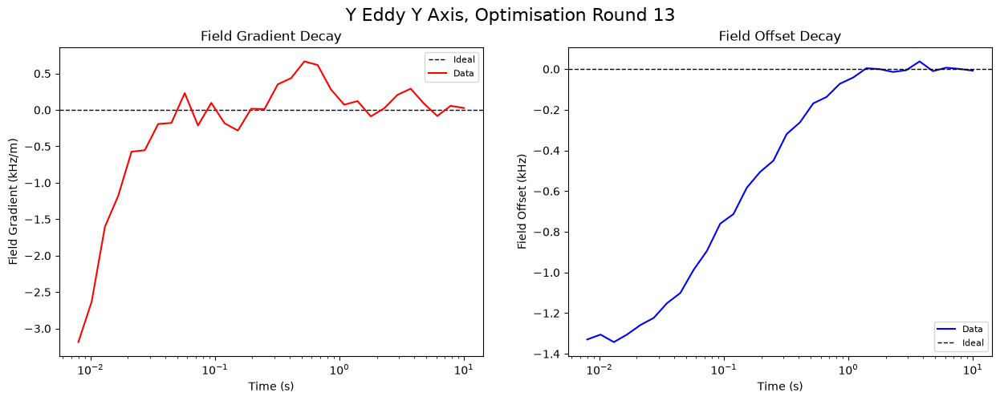

[I 2026-11-25 16:10:05,663] Trial 13 finished with value: 399.88161285554423 and parameters: {'Y_A1': -0.009798913175554348, 'Y_A2': -0.004015614406041542, 'Y_A3': 5.249630400946507e-10, 'Y_A4': -4.261197173032082e-09}. Best is trial 12 with value: 171.94550592568584.


rx_c: 3.999e+02
Total cost = 3.999e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2561408503160669
B nanmax = 0.2561408503160669
B contains nan = False
Trial 14


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.256009297291329 !!!!!!!!!!!!!!!!


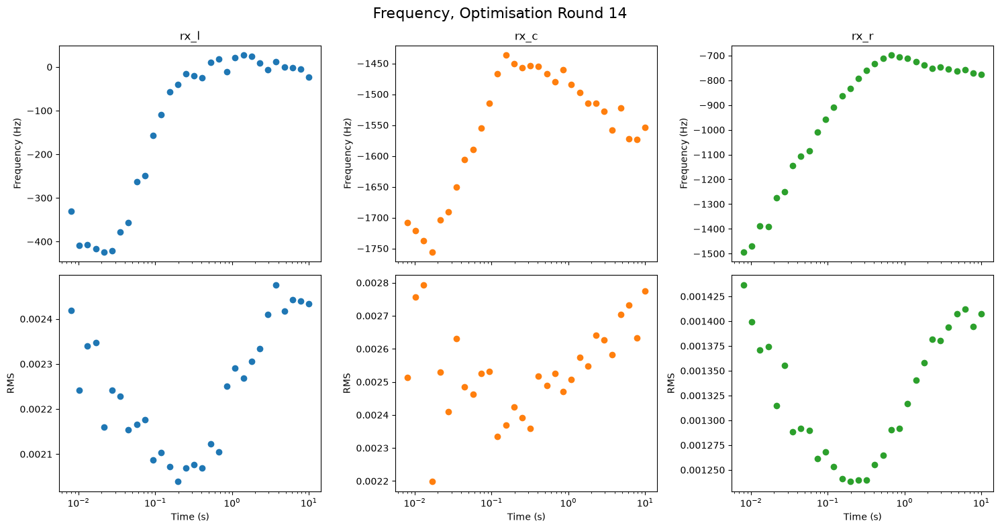

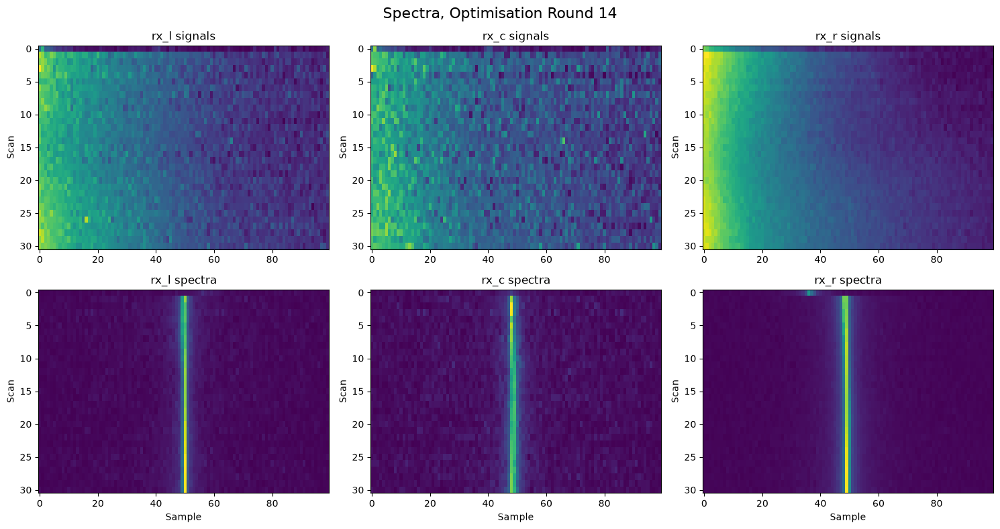

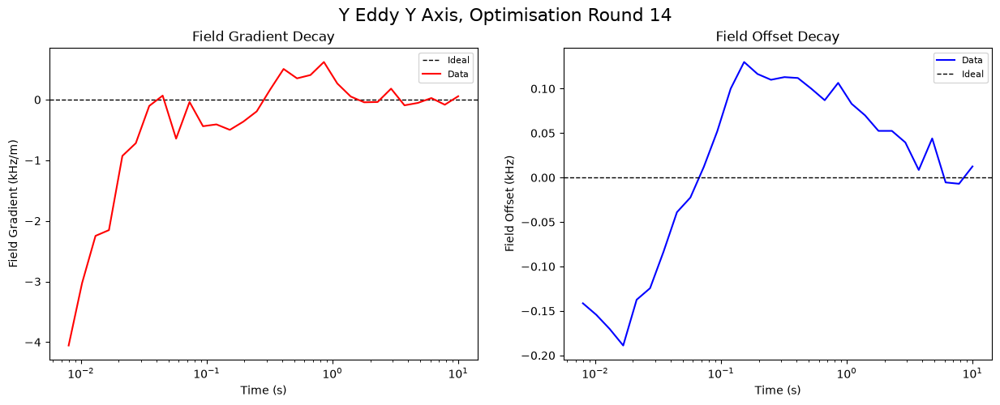

[I 2026-11-25 16:10:53,603] Trial 14 finished with value: 321.4660693575623 and parameters: {'Y_A1': -0.01234828098929464, 'Y_A2': -0.005815046377015341, 'Y_A3': -7.766522745454652e-11, 'Y_A4': -9.102808186296738e-09}. Best is trial 12 with value: 171.94550592568584.


rx_c: 3.215e+02
Total cost = 3.215e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.21838903939492568
B nanmax = 0.21838903939492568
B contains nan = False
Trial 15


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.21827687615047364 !!!!!!!!!!!!!!!!


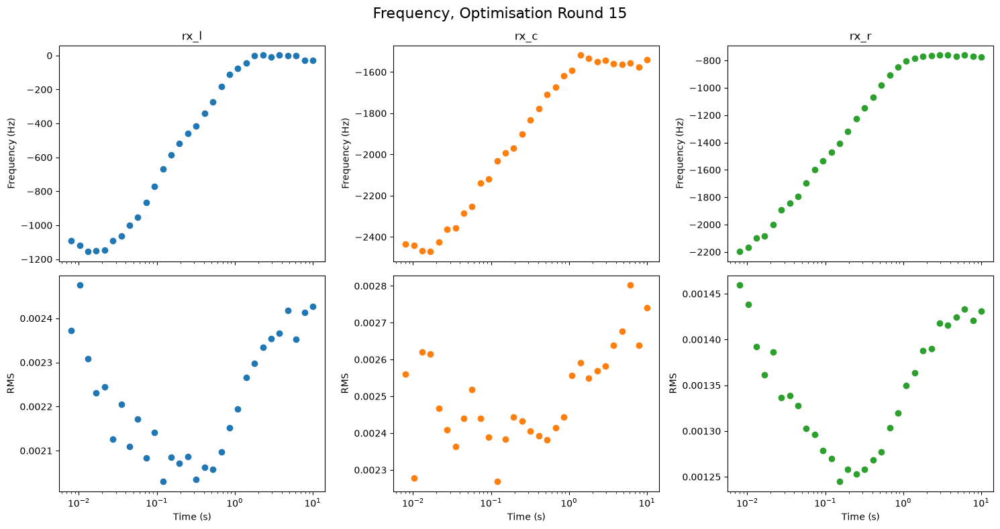

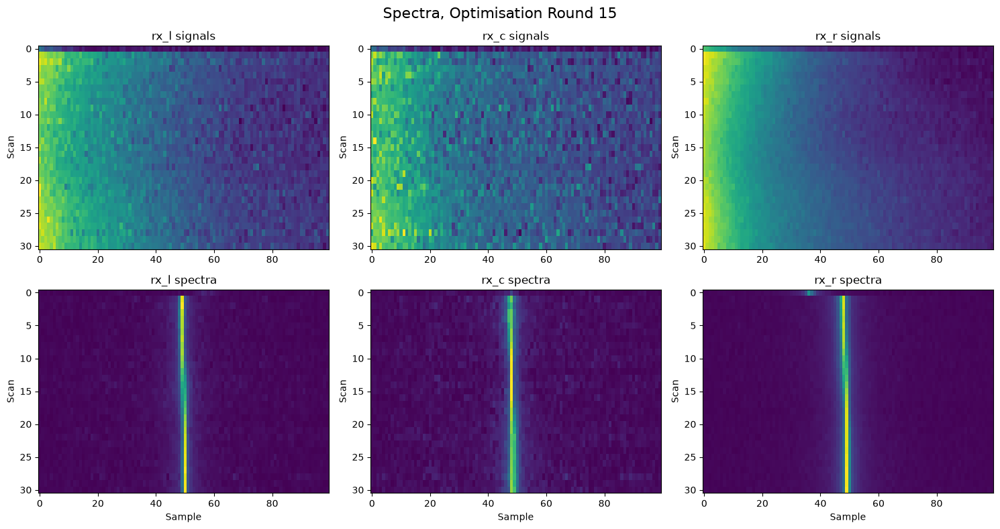

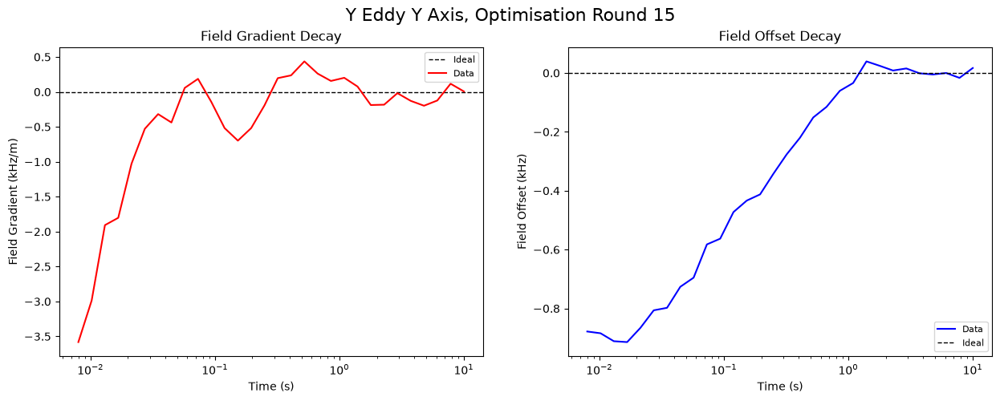

[I 2026-11-25 16:11:41,443] Trial 15 finished with value: 344.13905531027433 and parameters: {'Y_A1': -0.009690557557007352, 'Y_A2': -0.005797302193928518, 'Y_A3': -1.0949362085257477e-09, 'Y_A4': -9.328789897418213e-09}. Best is trial 12 with value: 171.94550592568584.


rx_c: 3.441e+02
Total cost = 3.441e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.29641477201531913
B nanmax = 0.29641477201531913
B contains nan = False
Trial 16


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2962625350830347 !!!!!!!!!!!!!!!!


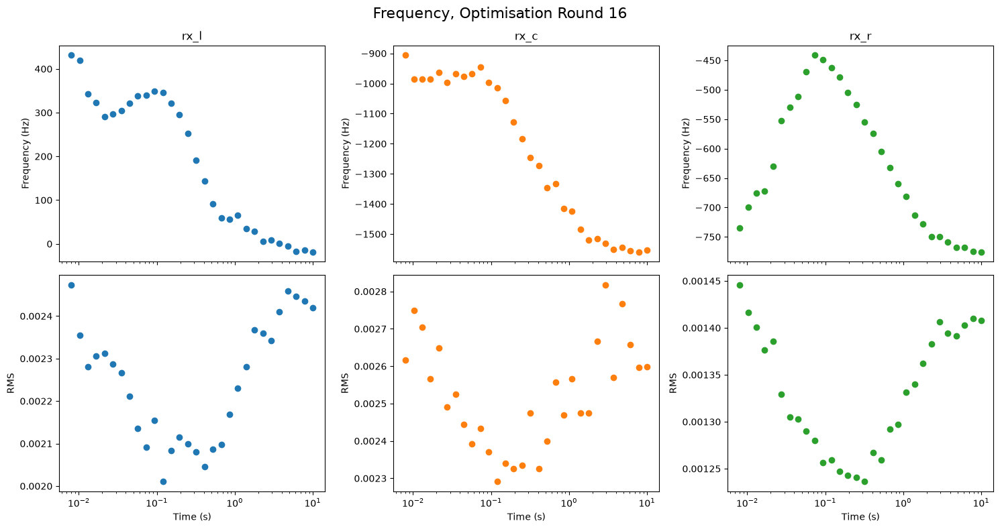

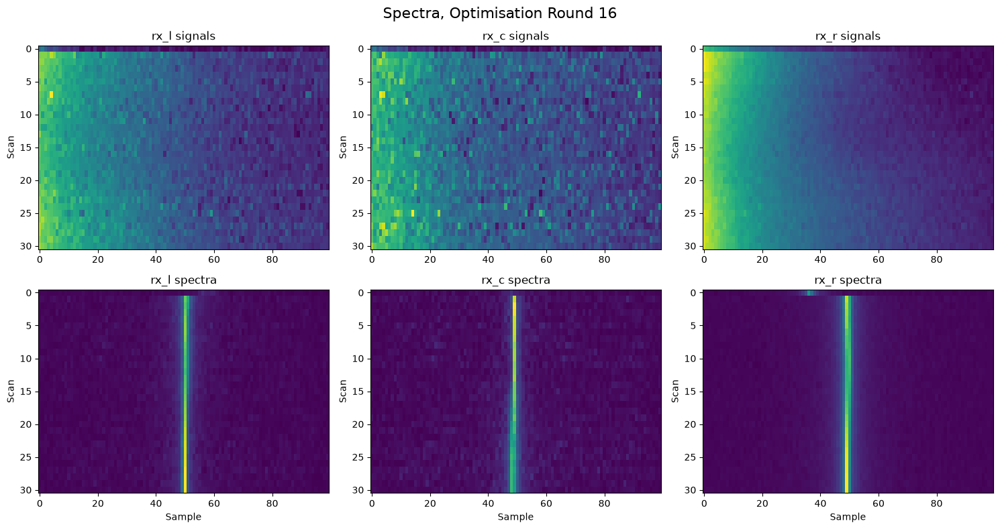

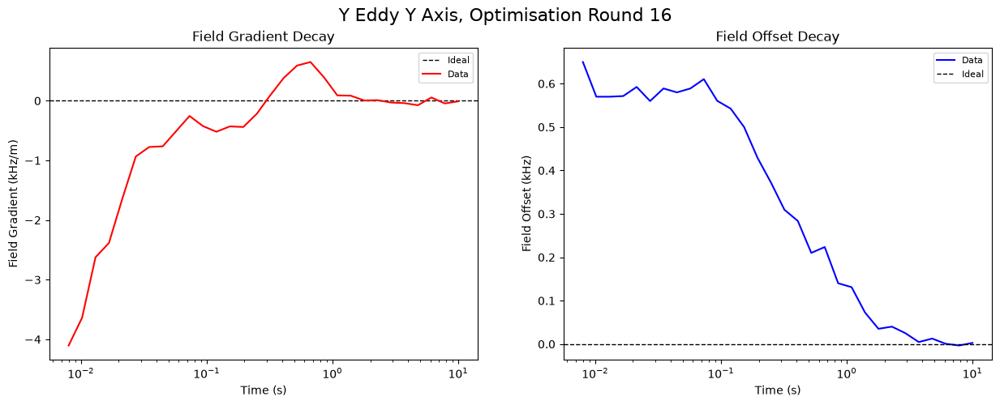

[I 2026-11-25 16:12:29,351] Trial 16 finished with value: 431.30833074214553 and parameters: {'Y_A1': -0.013381355371622383, 'Y_A2': -0.007639557244999588, 'Y_A3': 5.256541451521133e-09, 'Y_A4': -7.316648547204791e-09}. Best is trial 12 with value: 171.94550592568584.


rx_c: 4.313e+02
Total cost = 4.313e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.3019074923822177
B nanmax = 0.3019074923822177
B contains nan = False
Trial 17


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.3017524332483981 !!!!!!!!!!!!!!!!


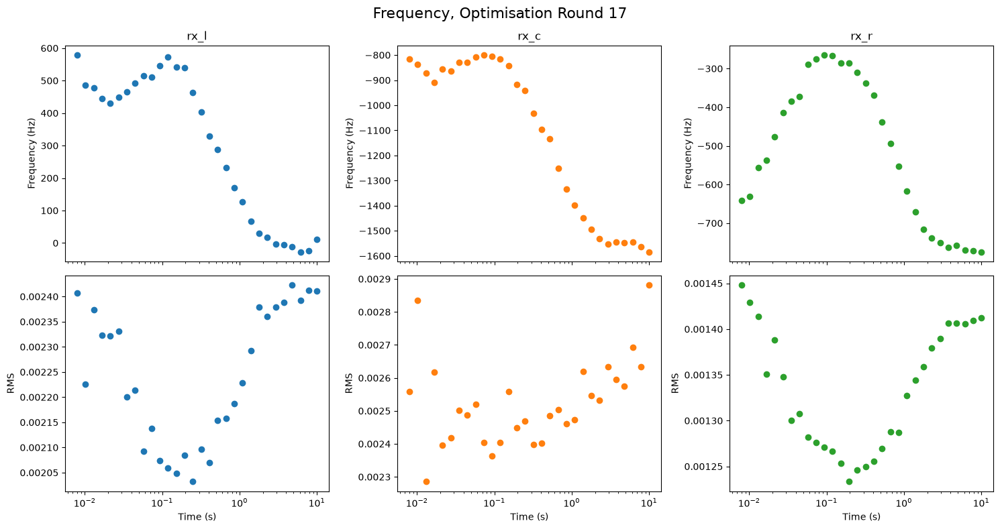

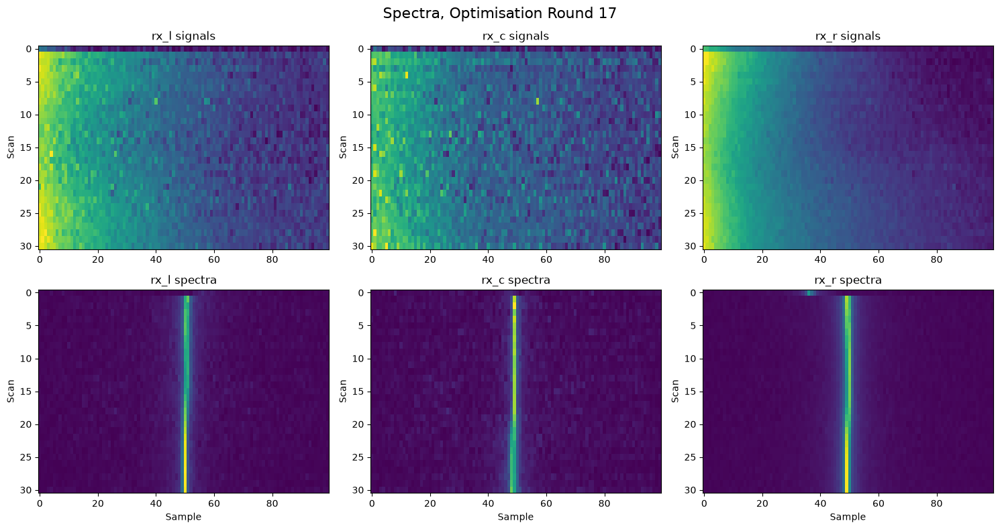

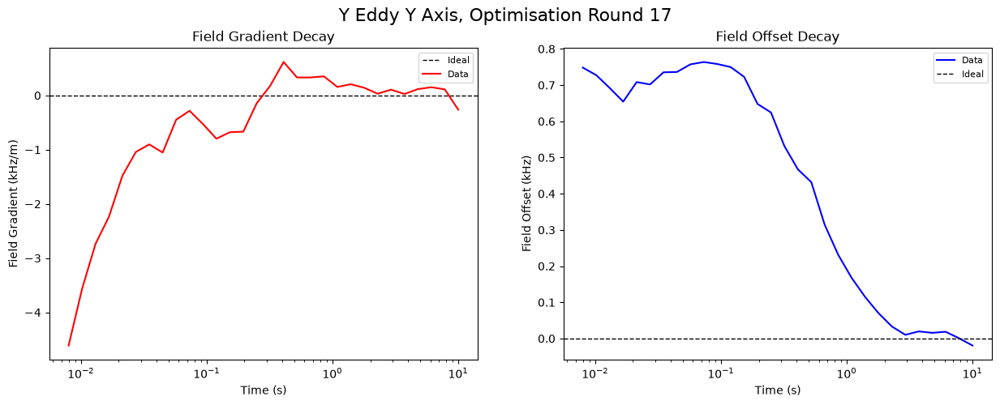

[I 2026-11-25 16:13:17,301] Trial 17 finished with value: 670.594769447204 and parameters: {'Y_A1': -0.01530676026265932, 'Y_A2': -0.00610053867767518, 'Y_A3': -2.1030909380592127e-09, 'Y_A4': -9.471967458864649e-09}. Best is trial 12 with value: 171.94550592568584.


rx_c: 6.706e+02
Total cost = 6.706e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26381707964453865
B nanmax = 0.26381707964453865
B contains nan = False
Trial 18


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26368158477510845 !!!!!!!!!!!!!!!!


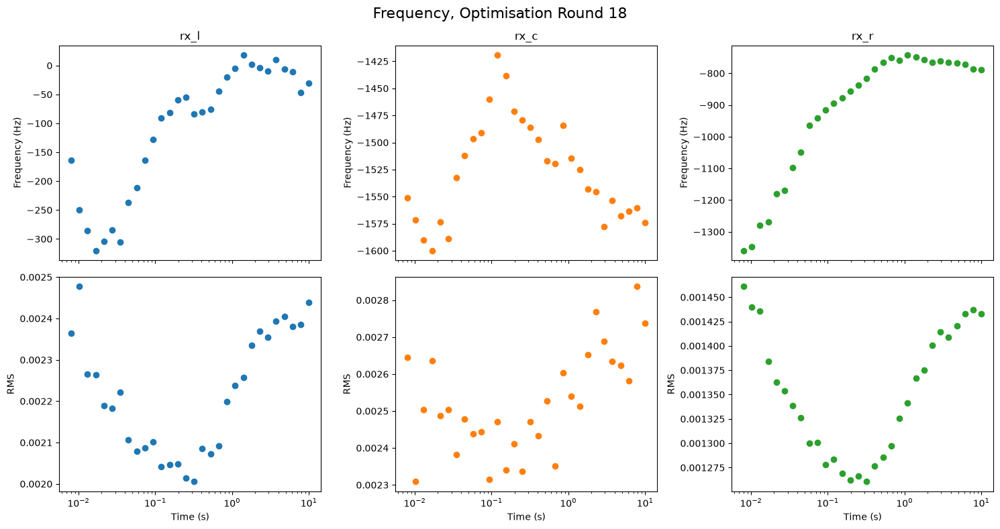

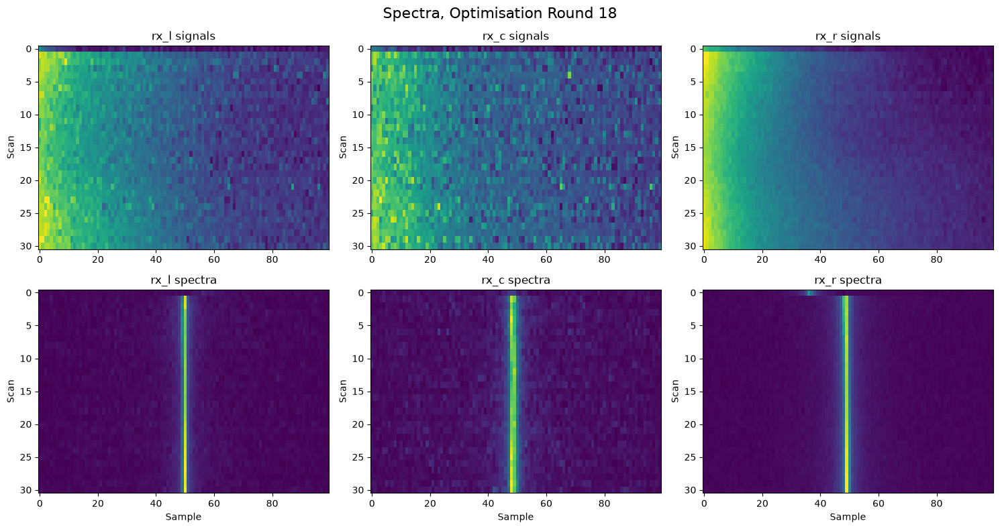

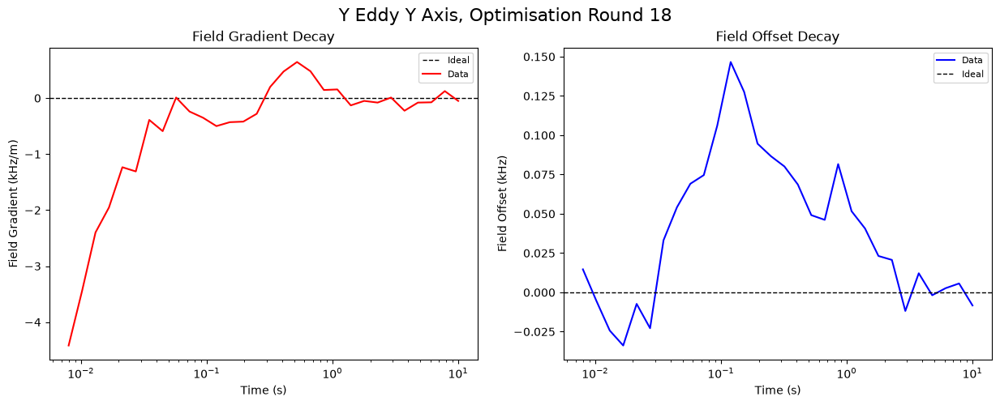

[I 2026-11-25 16:14:05,498] Trial 18 finished with value: 166.40228571721127 and parameters: {'Y_A1': -0.01180324188041898, 'Y_A2': -0.006906132438953048, 'Y_A3': 6.254996850015389e-10, 'Y_A4': -8.192113520841222e-09}. Best is trial 18 with value: 166.40228571721127.


rx_c: 1.664e+02
Total cost = 1.664e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2535403840156893
B nanmax = 0.2535403840156893
B contains nan = False
Trial 19


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25341016683353096 !!!!!!!!!!!!!!!!


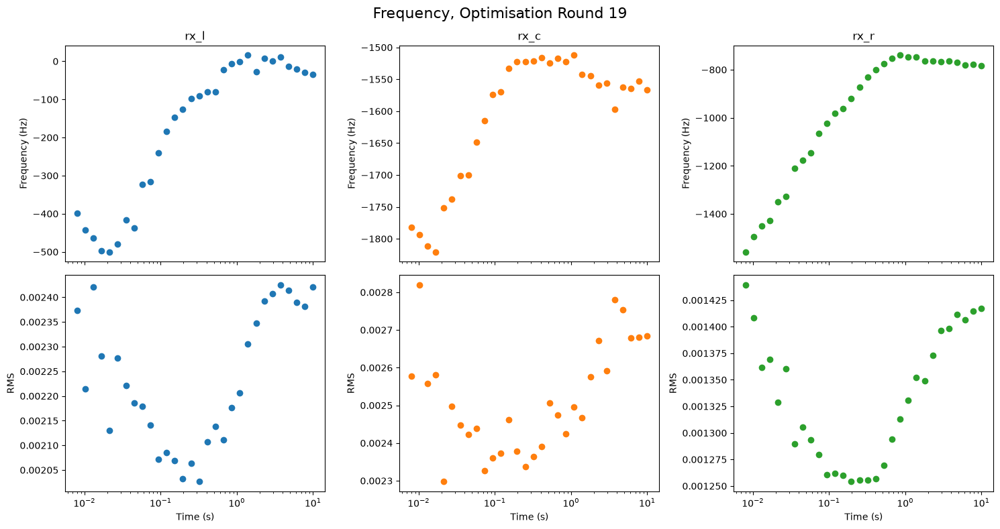

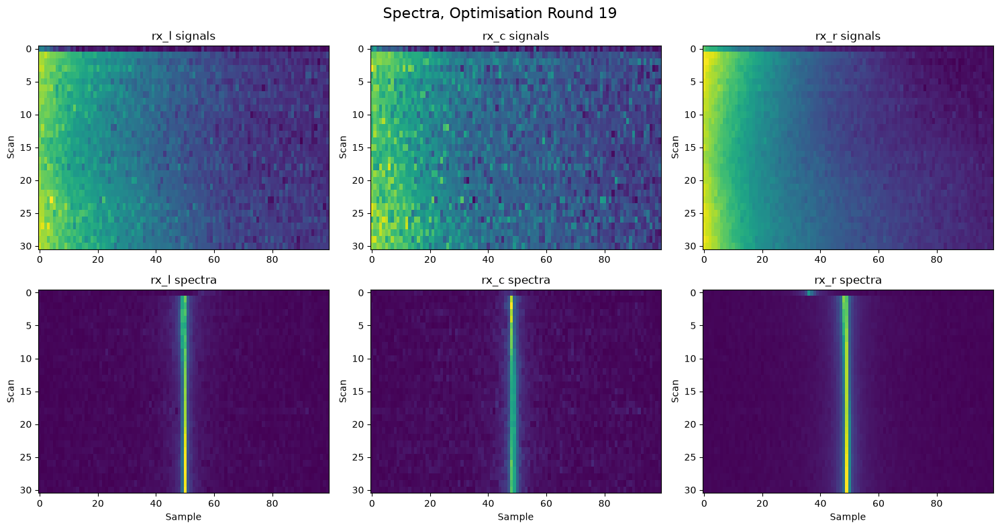

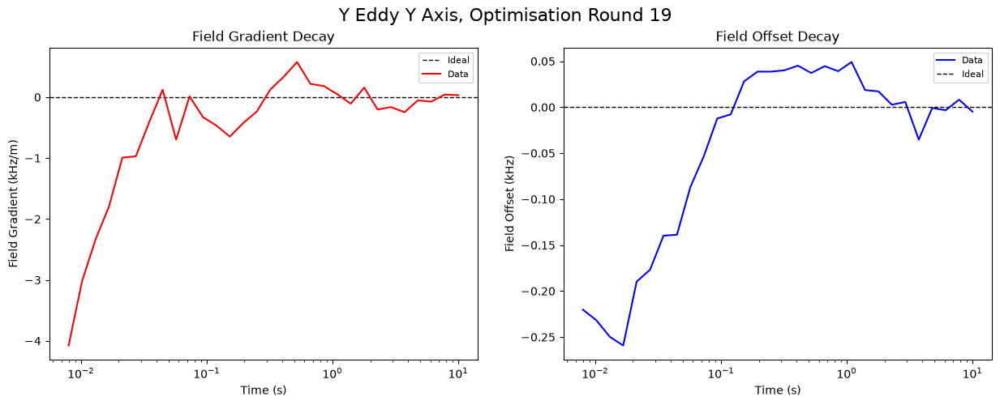

[I 2026-11-25 16:14:53,446] Trial 19 finished with value: 137.1436633610362 and parameters: {'Y_A1': -0.011861609105619803, 'Y_A2': -0.006117992133056961, 'Y_A3': -3.444145378864098e-09, 'Y_A4': -3.632661438510678e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.371e+02
Total cost = 1.371e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.21667315946786325
B nanmax = 0.21667315946786325
B contains nan = False
Trial 20


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2165618774262225 !!!!!!!!!!!!!!!!


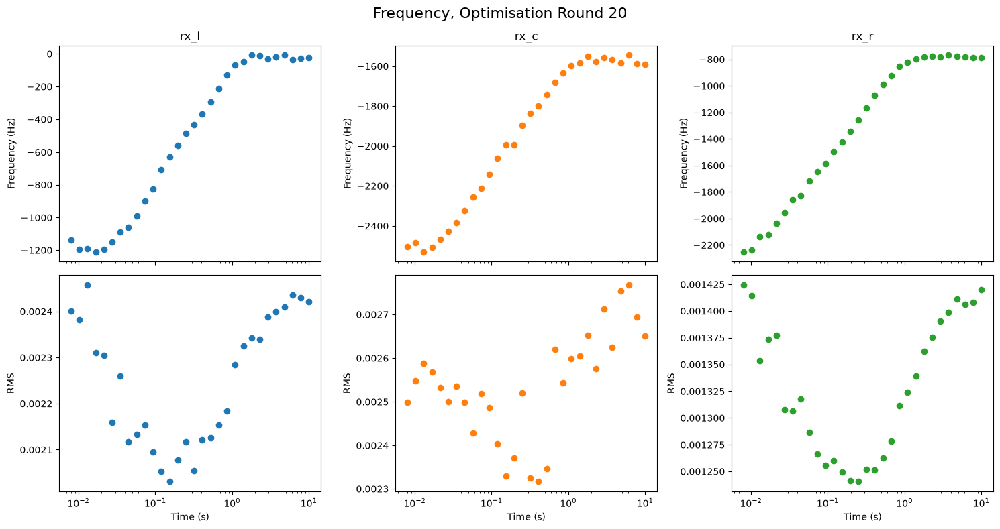

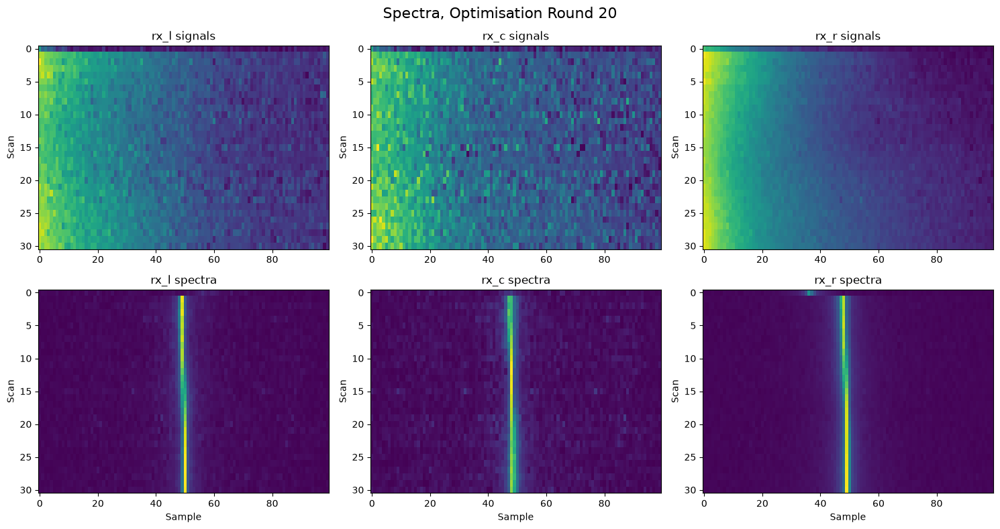

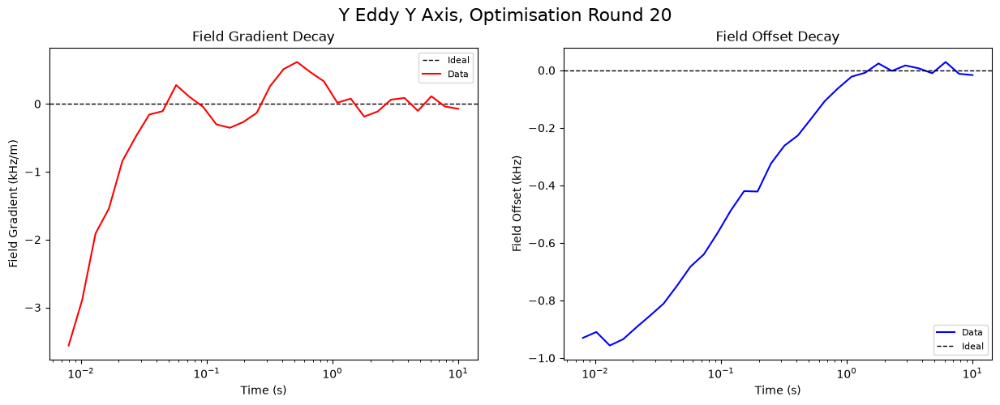

[I 2026-11-25 16:15:41,176] Trial 20 finished with value: 375.43499222850346 and parameters: {'Y_A1': -0.009703724398336567, 'Y_A2': -0.00566228014858449, 'Y_A3': -5.407707224883506e-09, 'Y_A4': -9.958701481164426e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.754e+02
Total cost = 3.754e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.28267176060413063
B nanmax = 0.28267176060413063
B contains nan = False
Trial 21


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2825265814789568 !!!!!!!!!!!!!!!!


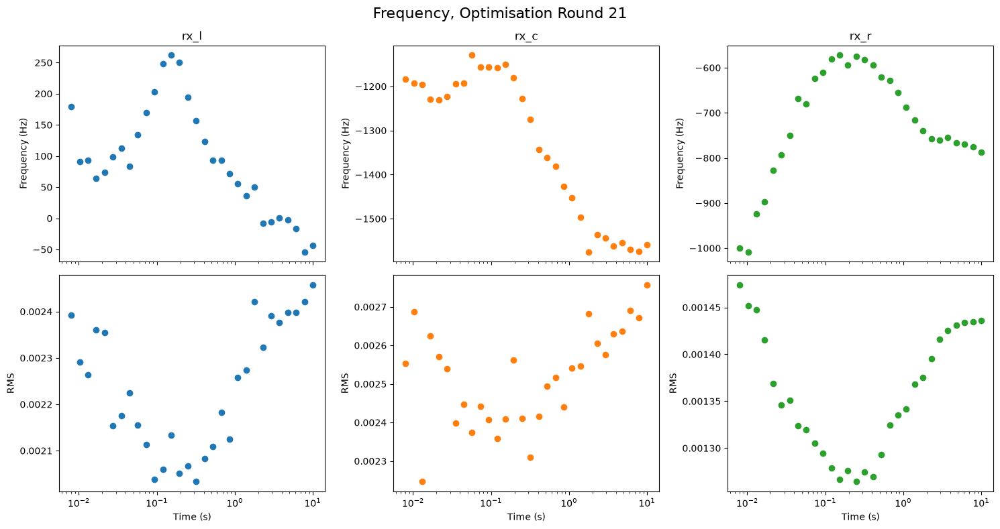

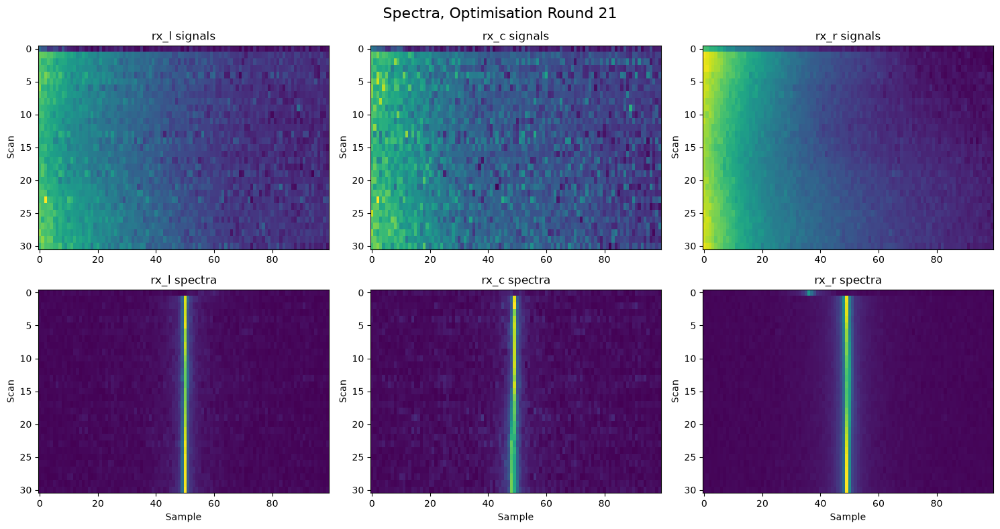

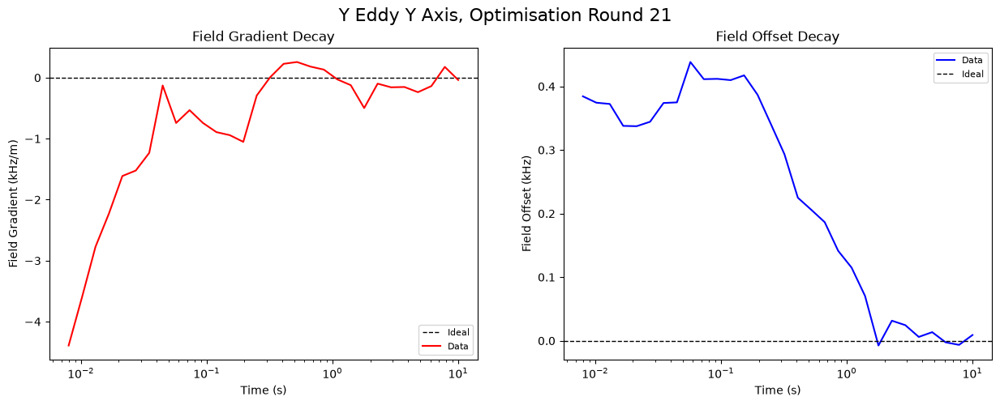

[I 2026-11-25 16:16:29,117] Trial 21 finished with value: 383.1941011838653 and parameters: {'Y_A1': -0.013512487543032324, 'Y_A2': -0.006532401078000741, 'Y_A3': -3.0347503859445266e-09, 'Y_A4': -4.883018701237358e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.832e+02
Total cost = 3.832e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24777469955391168
B nanmax = 0.24777469955391168
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24764744405630384 !!!!!!!!!!!!!!!!


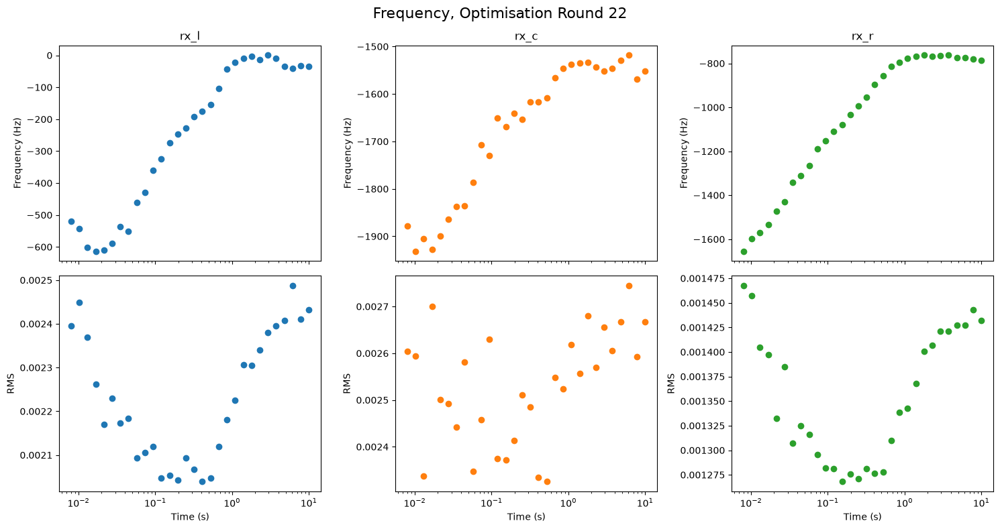

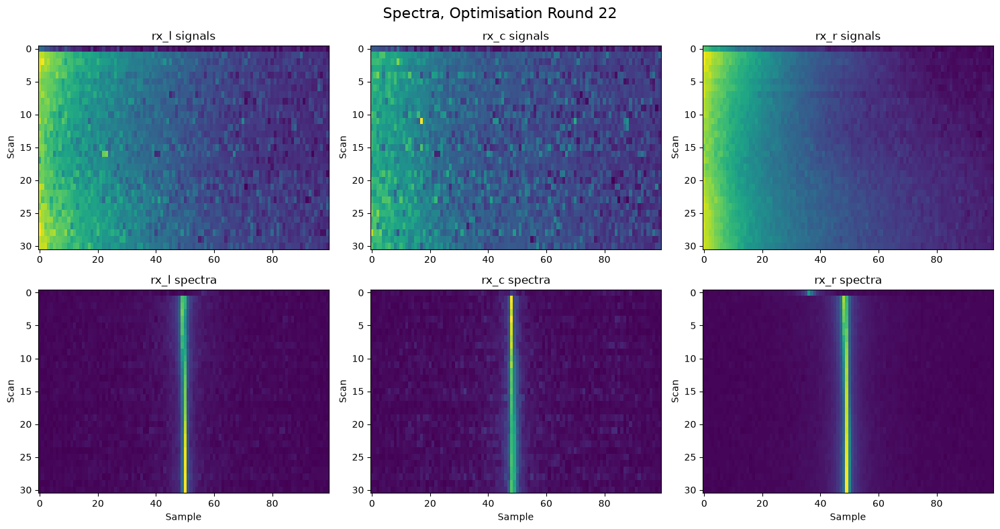

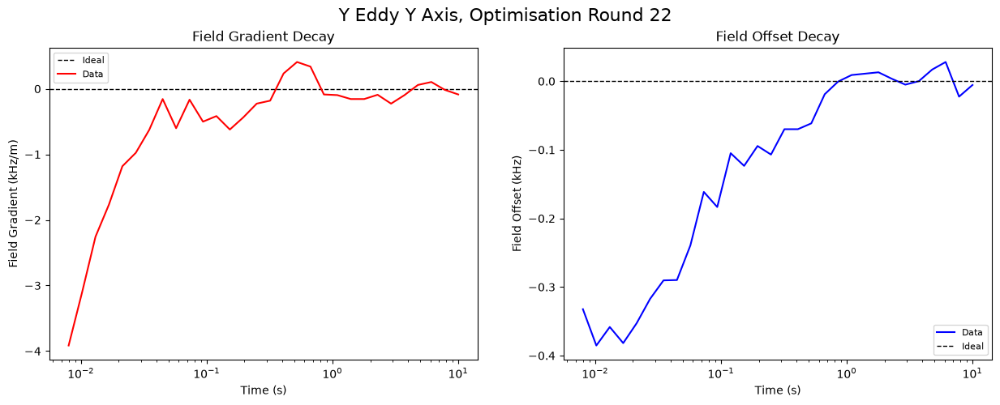

[I 2026-11-25 16:17:17,063] Trial 22 finished with value: 197.43667098263992 and parameters: {'Y_A1': -0.010939987156016106, 'Y_A2': -0.006631966551970826, 'Y_A3': -2.4009680333832774e-09, 'Y_A4': -2.3119856701014652e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.974e+02
Total cost = 1.974e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2416174811066781
B nanmax = 0.2416174811066781
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24149338710242368 !!!!!!!!!!!!!!!!


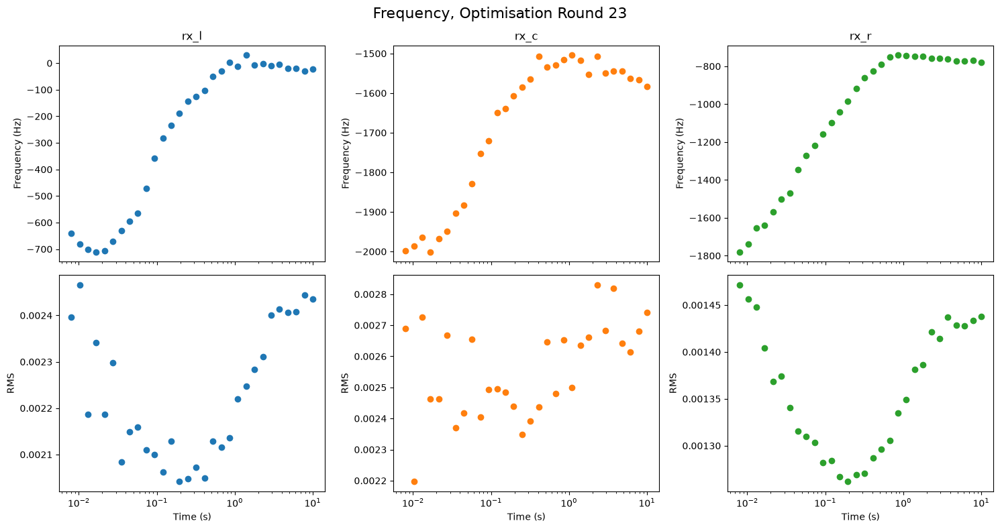

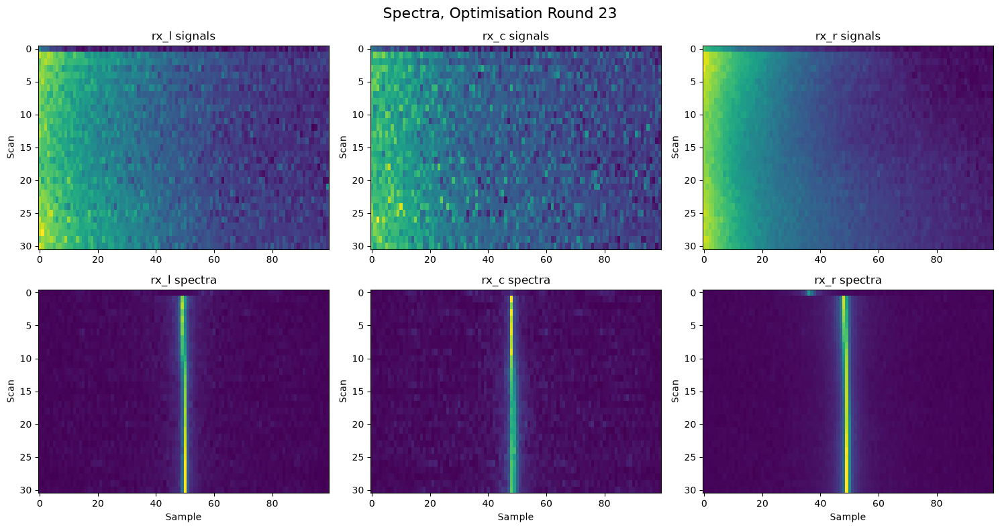

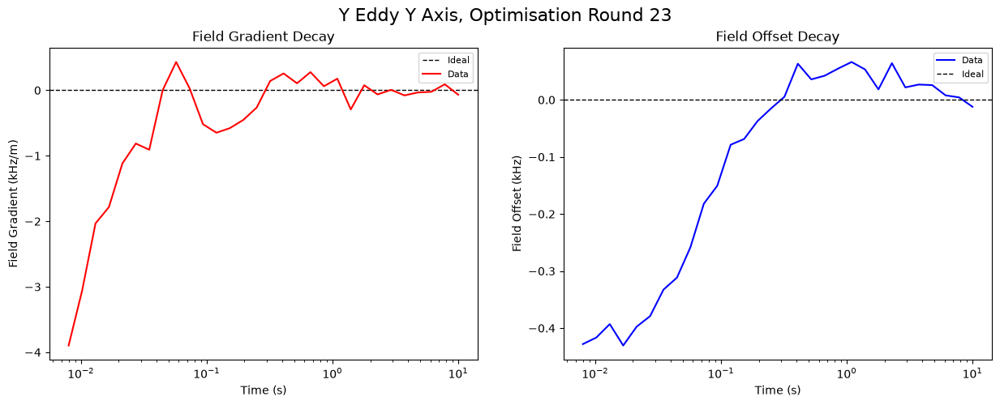

[I 2026-11-25 16:18:05,276] Trial 23 finished with value: 250.170457830004 and parameters: {'Y_A1': -0.011834242984078057, 'Y_A2': -0.005298862110383591, 'Y_A3': -2.3660006169396635e-09, 'Y_A4': -3.6291200414287313e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.502e+02
Total cost = 2.502e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25922503556963633
B nanmax = 0.25922503556963633
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2590918985394919 !!!!!!!!!!!!!!!!


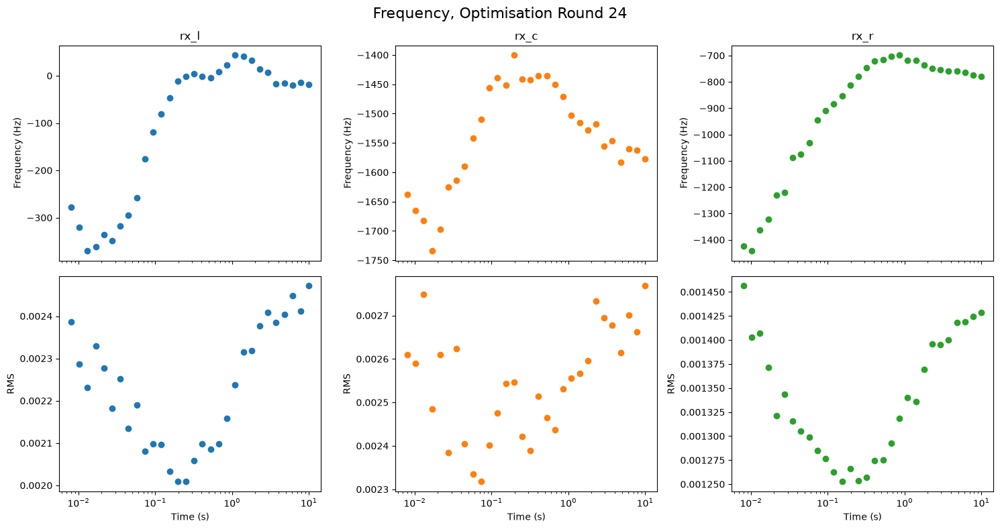

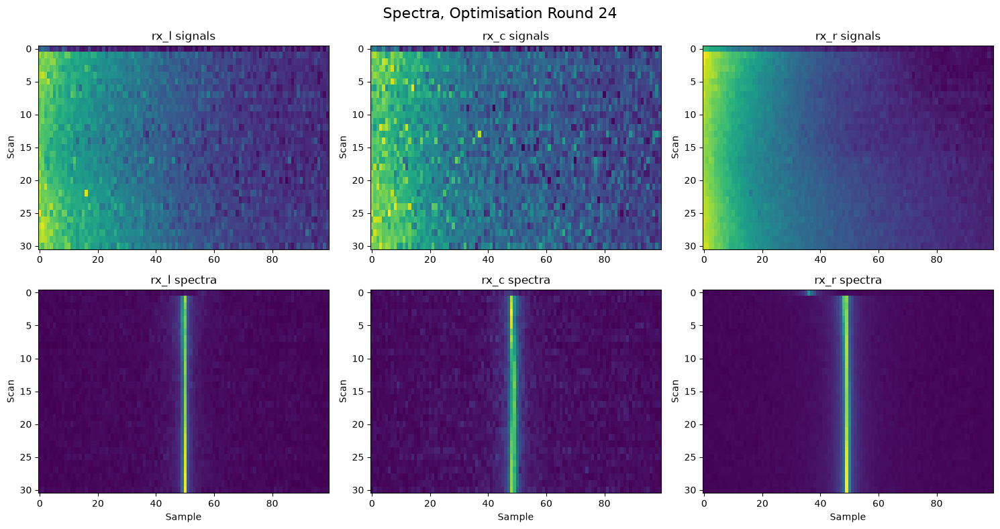

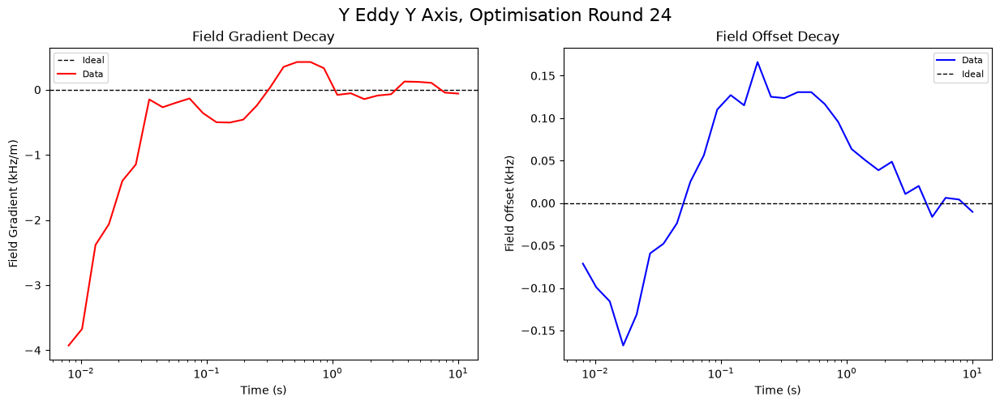

[I 2026-11-25 16:18:53,194] Trial 24 finished with value: 265.089254347577 and parameters: {'Y_A1': -0.012466744923318411, 'Y_A2': -0.005915343201107305, 'Y_A3': -7.170303157994819e-09, 'Y_A4': -4.364727260957091e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.651e+02
Total cost = 2.651e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.29074676847964076
B nanmax = 0.29074676847964076
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.29059744250972247 !!!!!!!!!!!!!!!!


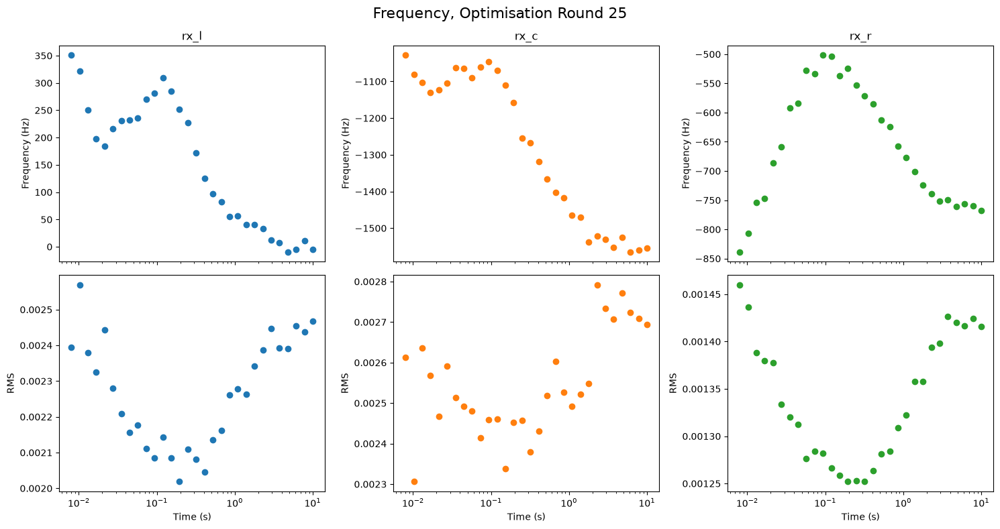

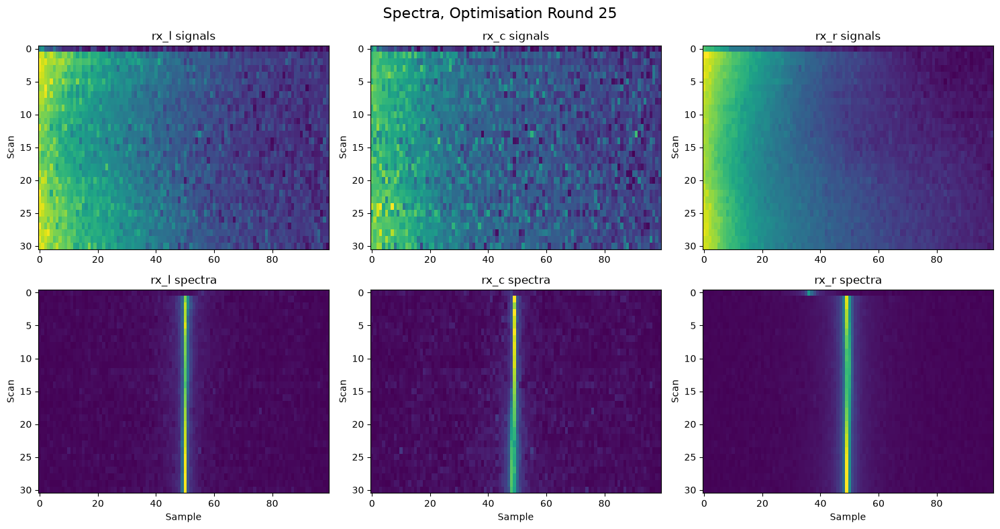

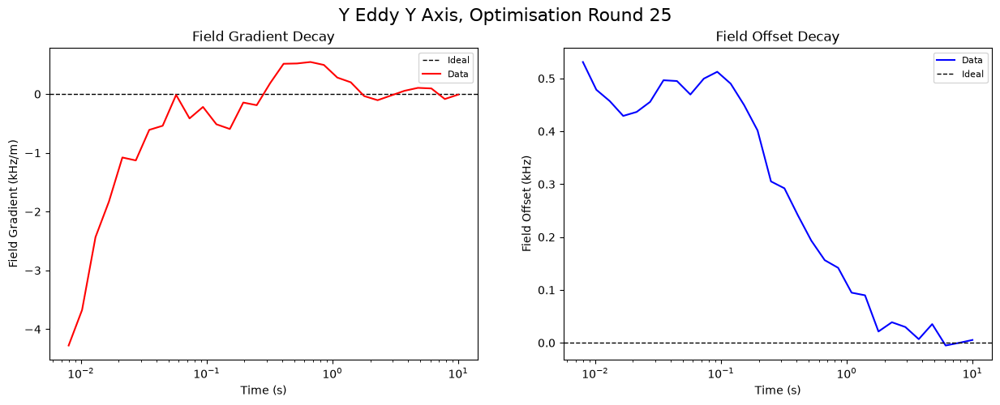

[I 2026-11-25 16:19:41,186] Trial 25 finished with value: 419.3549290087411 and parameters: {'Y_A1': -0.013256974990695052, 'Y_A2': -0.007361732236559452, 'Y_A3': -7.942063087010413e-10, 'Y_A4': -8.83132593032213e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 4.194e+02
Total cost = 4.194e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2694959796660556
B nanmax = 0.2694959796660556
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26935756837275954 !!!!!!!!!!!!!!!!


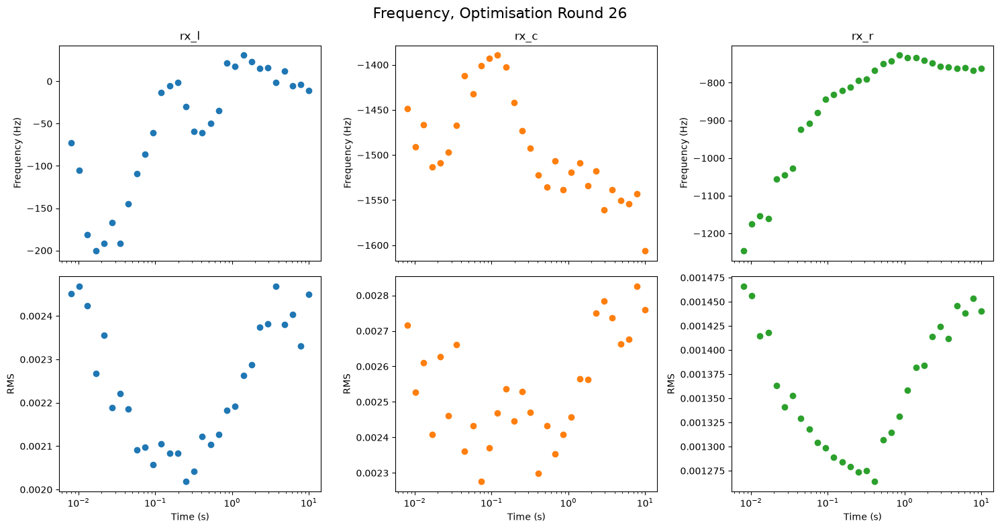

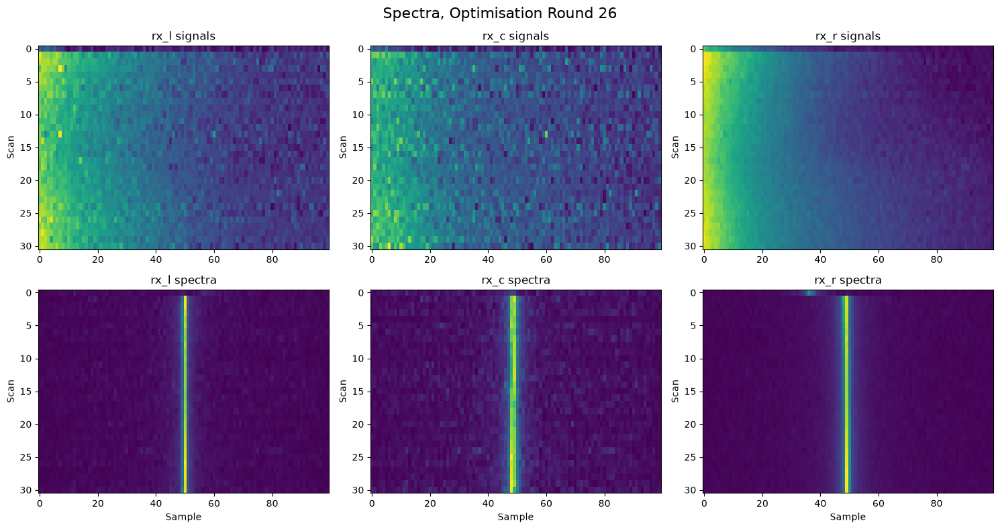

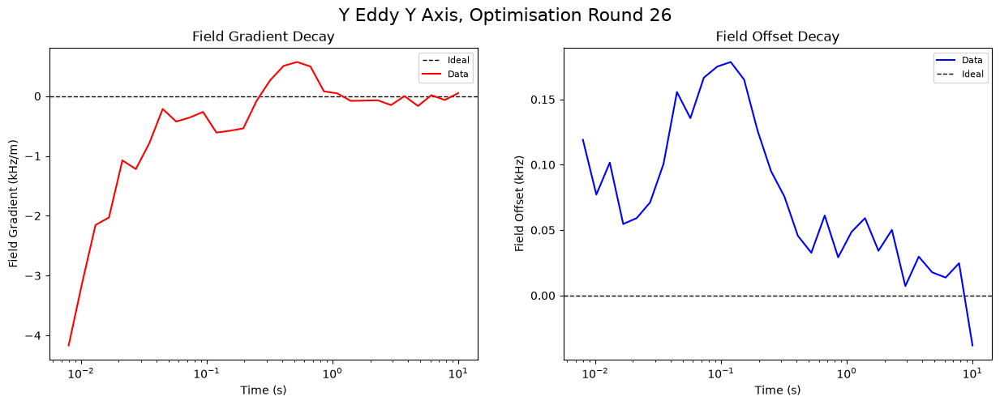

[I 2026-11-25 16:20:29,183] Trial 26 finished with value: 309.67895915698097 and parameters: {'Y_A1': -0.011735054077802379, 'Y_A2': -0.0073776600162443525, 'Y_A3': 6.955187097932408e-10, 'Y_A4': -5.893877737312601e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.097e+02
Total cost = 3.097e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2630372496426836
B nanmax = 0.2630372496426836
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2629021546675083 !!!!!!!!!!!!!!!!


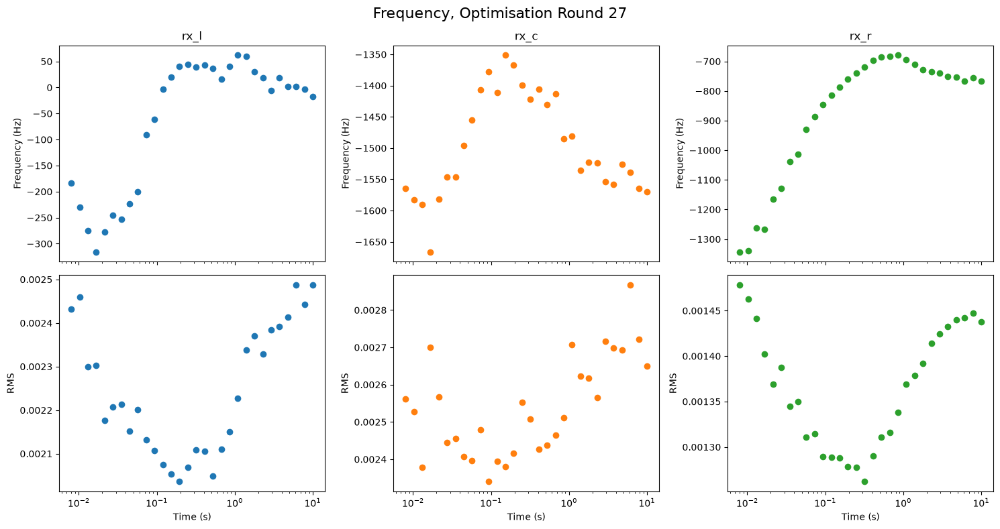

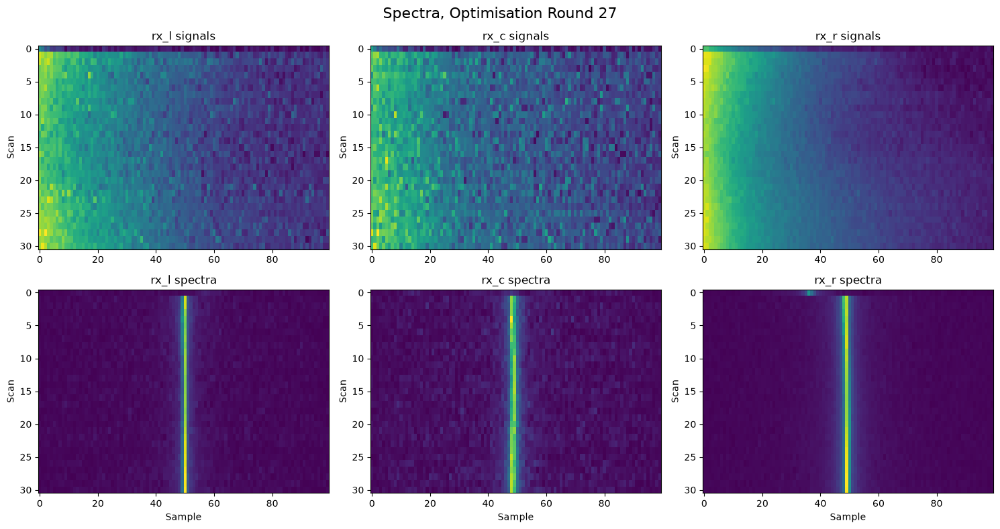

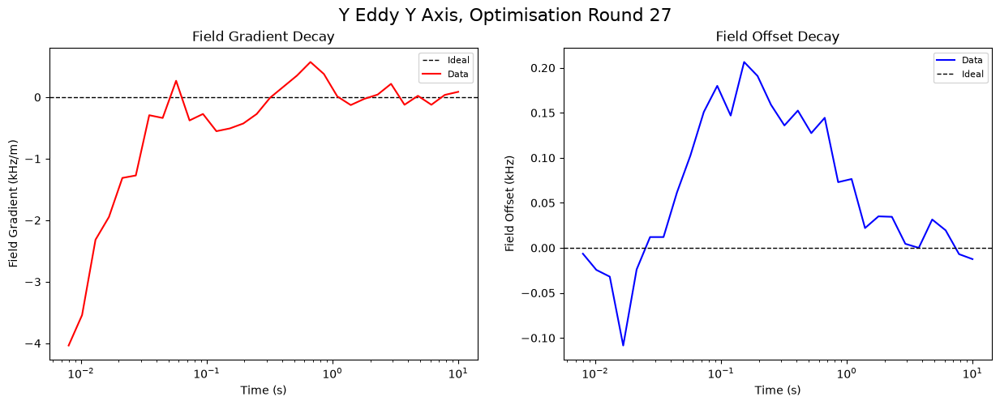

[I 2026-11-25 16:21:17,559] Trial 27 finished with value: 284.6928187044517 and parameters: {'Y_A1': -0.01265842622832748, 'Y_A2': -0.005993976851472643, 'Y_A3': -4.73730880311329e-09, 'Y_A4': -8.246795711322525e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.847e+02
Total cost = 2.847e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23018586357746473
B nanmax = 0.23018586357746473
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23006764168537372 !!!!!!!!!!!!!!!!


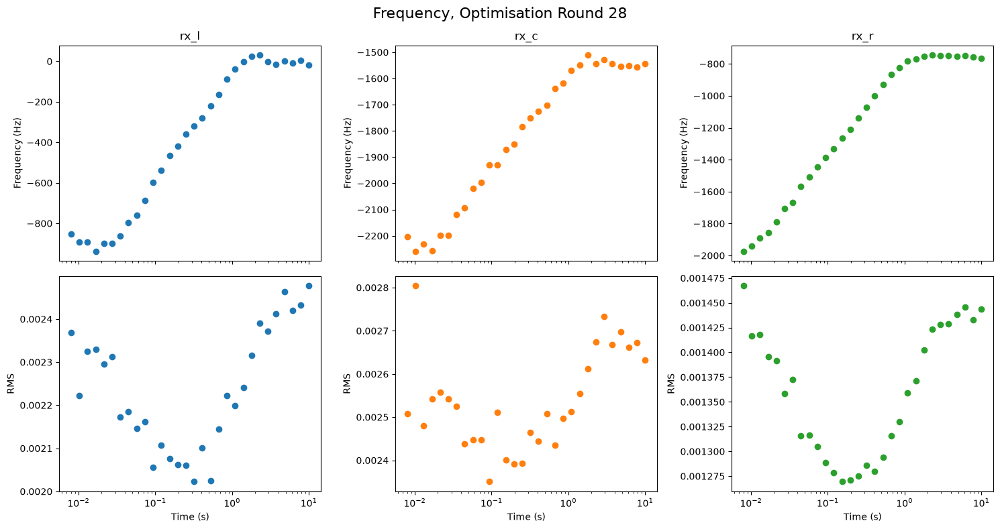

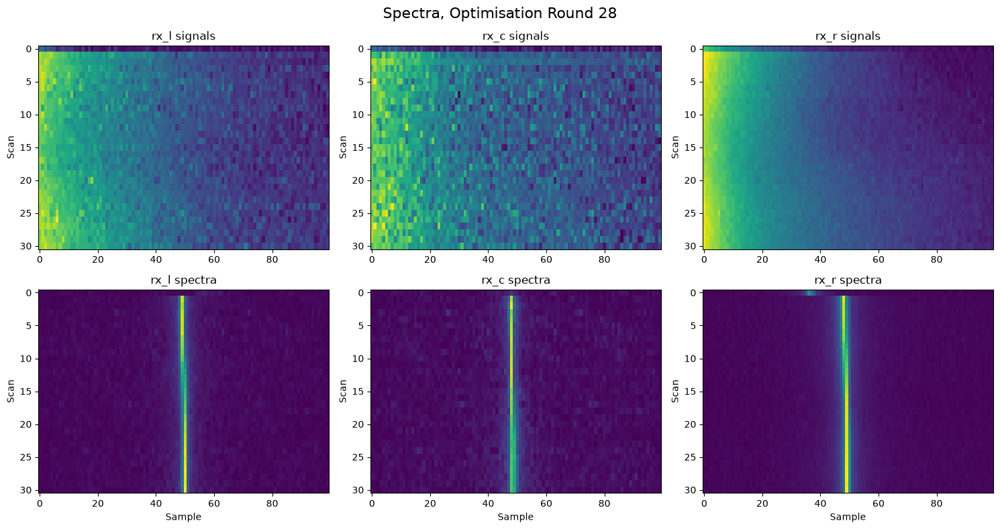

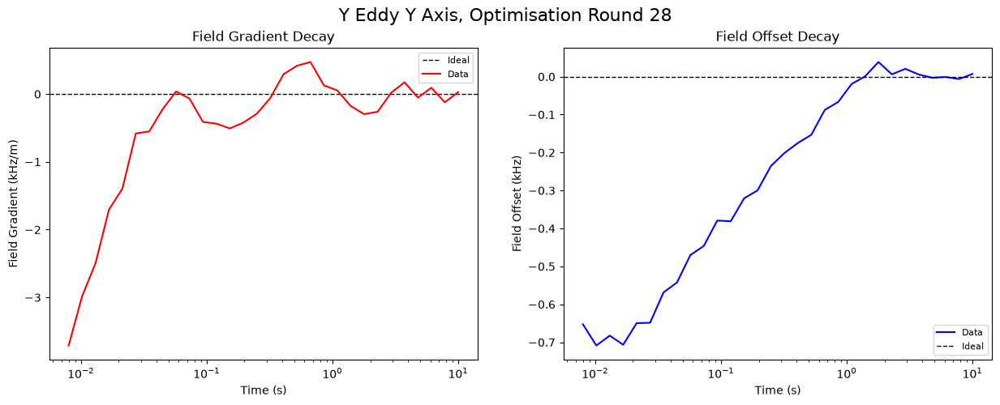

[I 2026-11-25 16:22:05,740] Trial 28 finished with value: 256.3448682704833 and parameters: {'Y_A1': -0.01003154917279097, 'Y_A2': -0.0062932674297728666, 'Y_A3': 3.0121470879138007e-10, 'Y_A4': -3.838083790108996e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.563e+02
Total cost = 2.563e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23721654725852906
B nanmax = 0.23721654725852906
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2370947137362767 !!!!!!!!!!!!!!!!


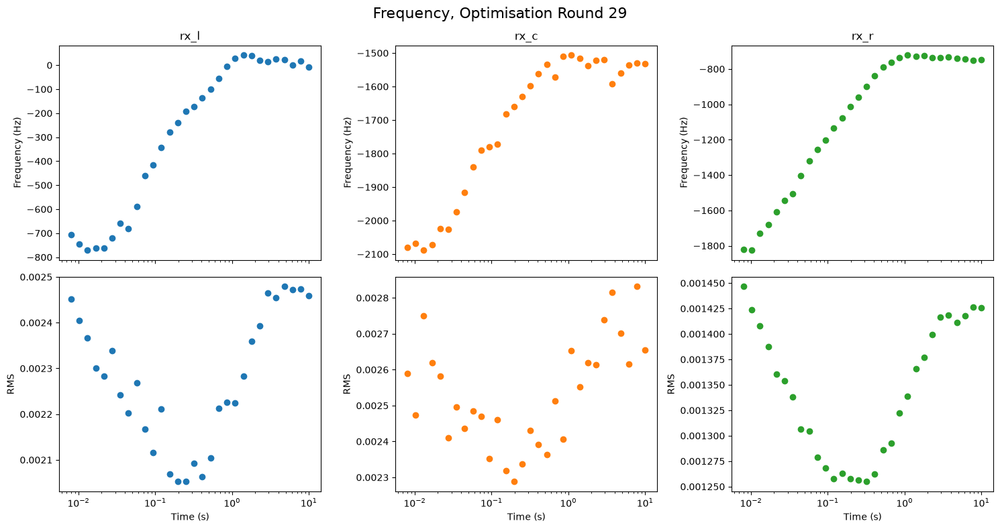

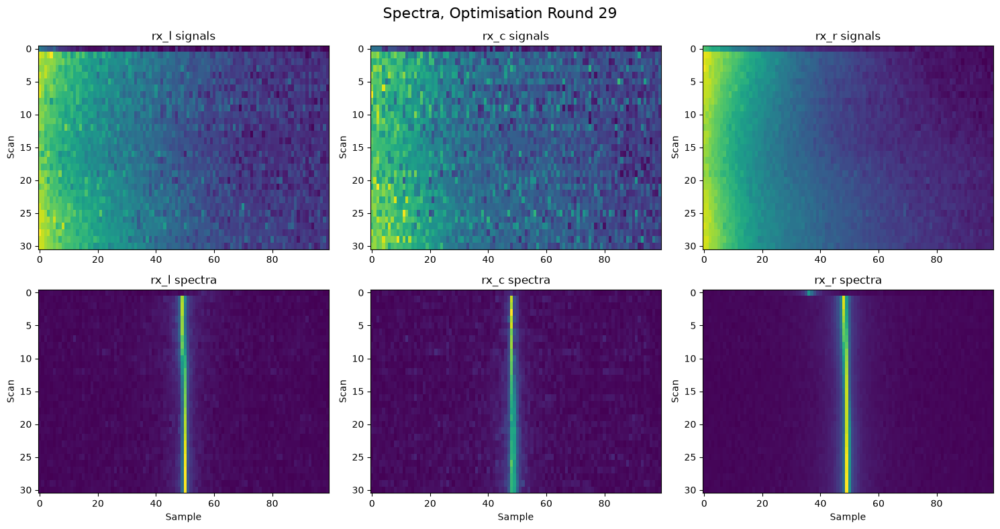

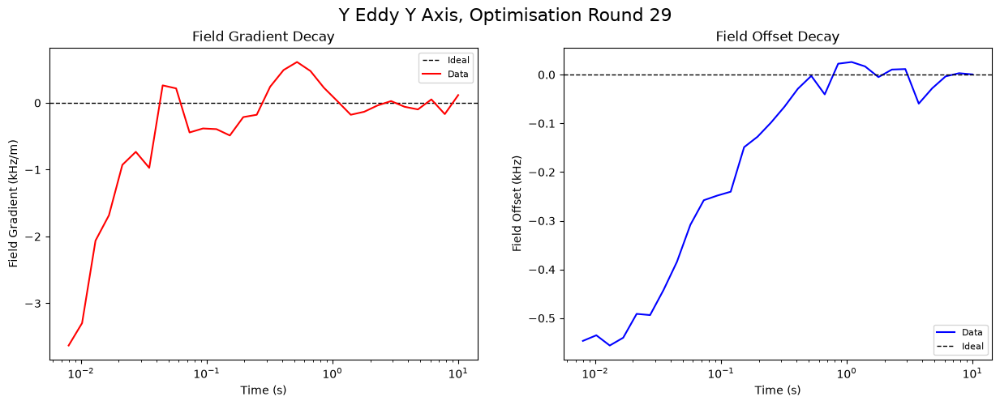

[I 2026-11-25 16:22:53,657] Trial 29 finished with value: 209.710249142041 and parameters: {'Y_A1': -0.011367085630018842, 'Y_A2': -0.005454420370235889, 'Y_A3': 2.125350767514824e-09, 'Y_A4': -1.843208356801851e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.097e+02
Total cost = 2.097e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2510769794712135
B nanmax = 0.2510769794712135
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25094802808962313 !!!!!!!!!!!!!!!!


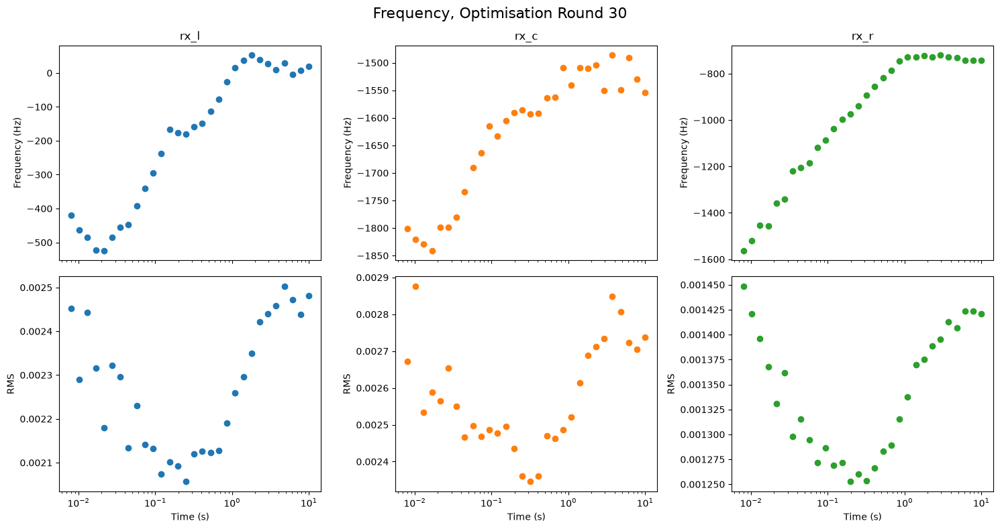

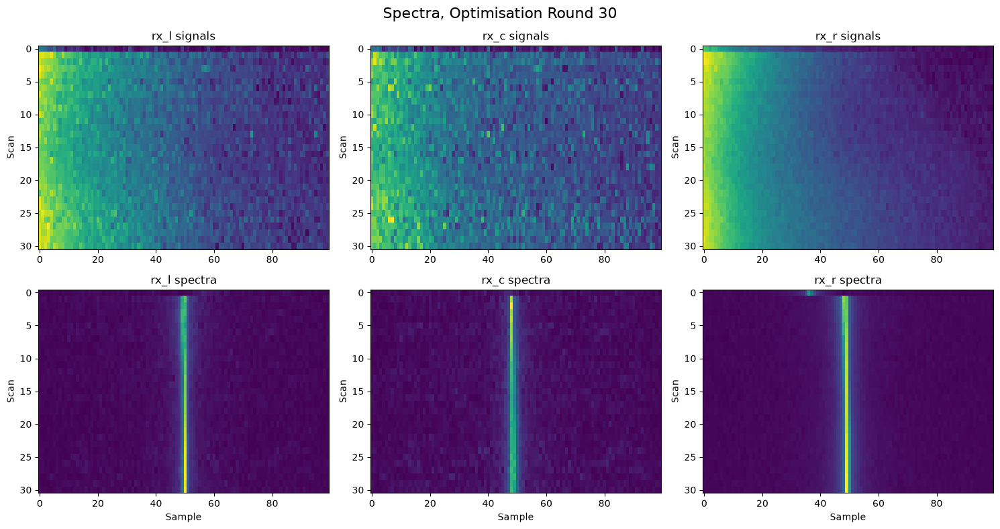

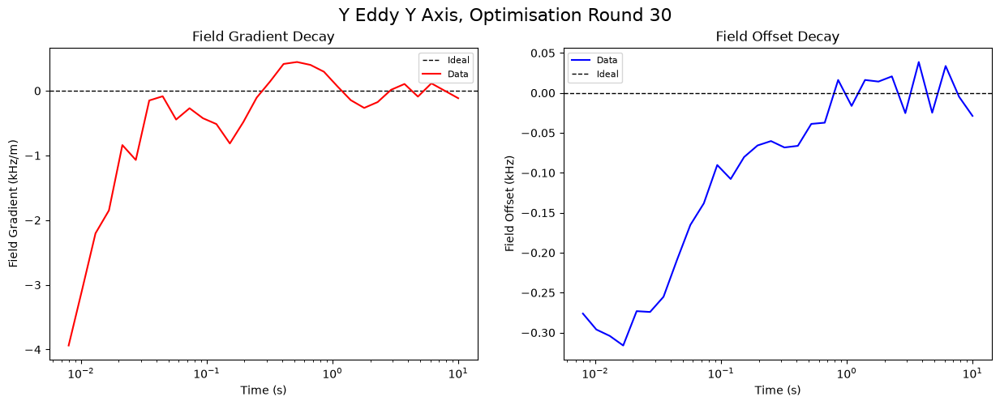

[I 2026-11-25 16:23:41,566] Trial 30 finished with value: 261.9573322363051 and parameters: {'Y_A1': -0.010877046205015495, 'Y_A2': -0.006929493176273491, 'Y_A3': -2.811299327869504e-09, 'Y_A4': -8.03939710136731e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.620e+02
Total cost = 2.620e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2444231574188261
B nanmax = 0.2444231574188261
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24429762279870199 !!!!!!!!!!!!!!!!


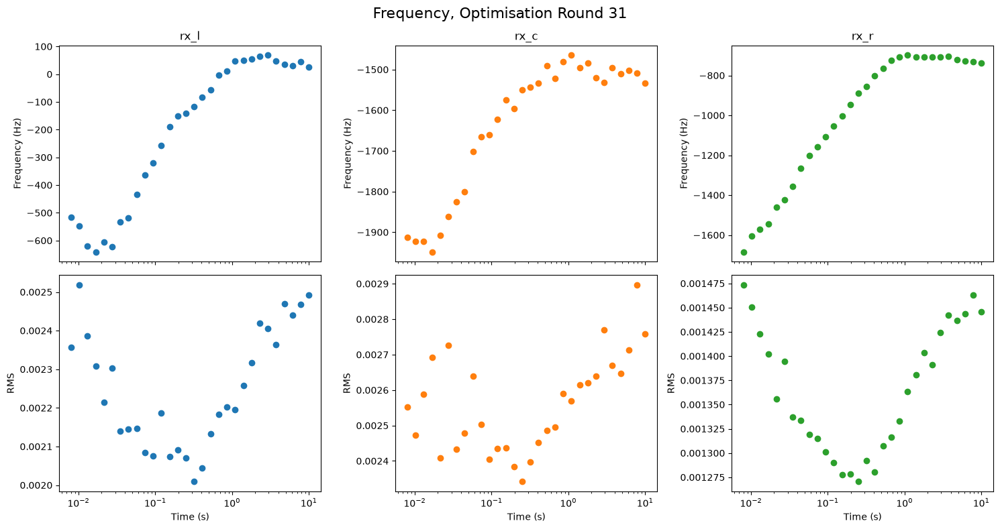

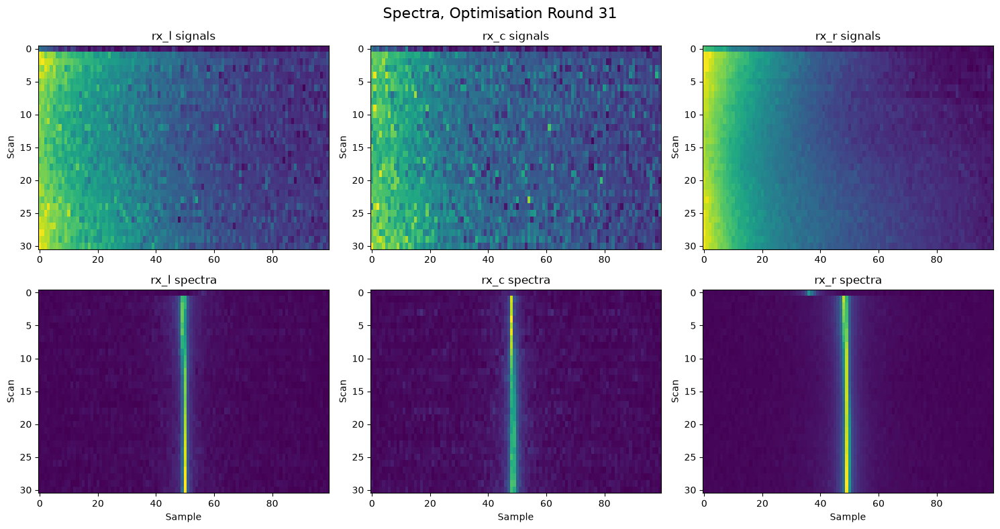

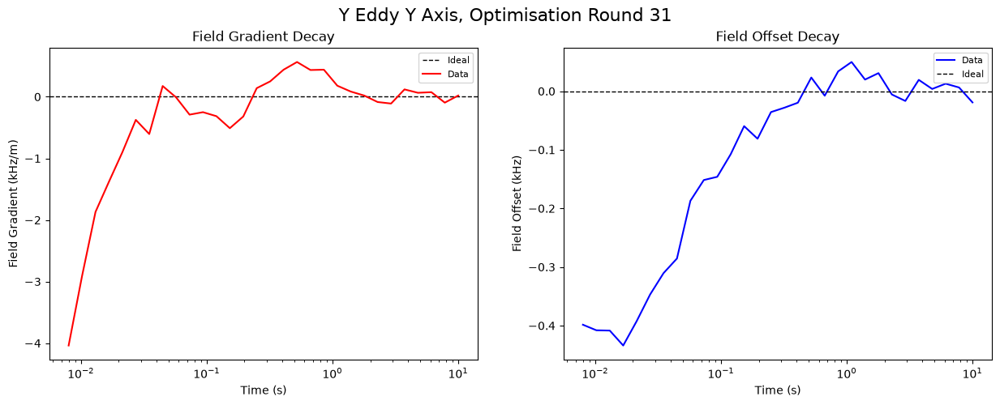

[I 2026-11-25 16:24:29,693] Trial 31 finished with value: 175.65137211242993 and parameters: {'Y_A1': -0.011440602657654383, 'Y_A2': -0.00589244782726839, 'Y_A3': -1.1714432626466461e-09, 'Y_A4': 1.5279461935985031e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.757e+02
Total cost = 1.757e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23760866773451833
B nanmax = 0.23760866773451833
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23748663284642754 !!!!!!!!!!!!!!!!


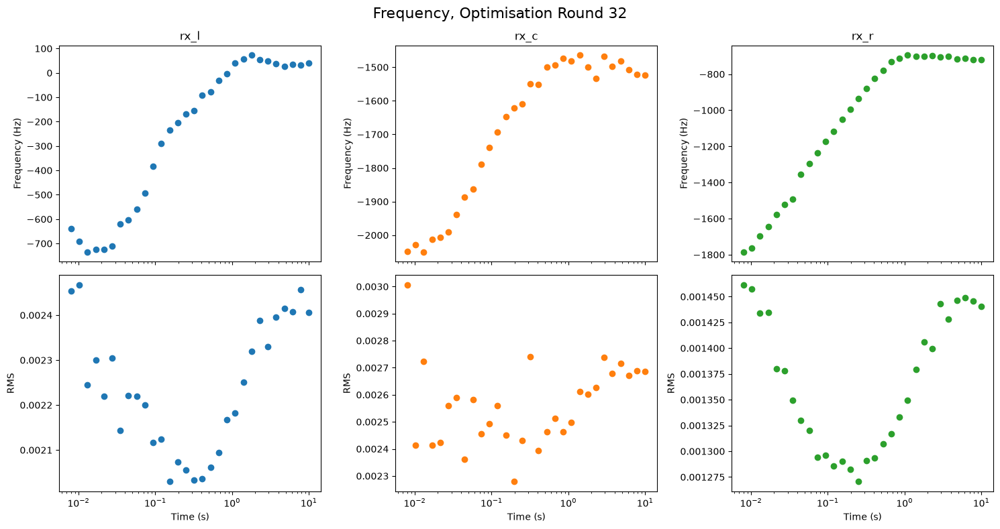

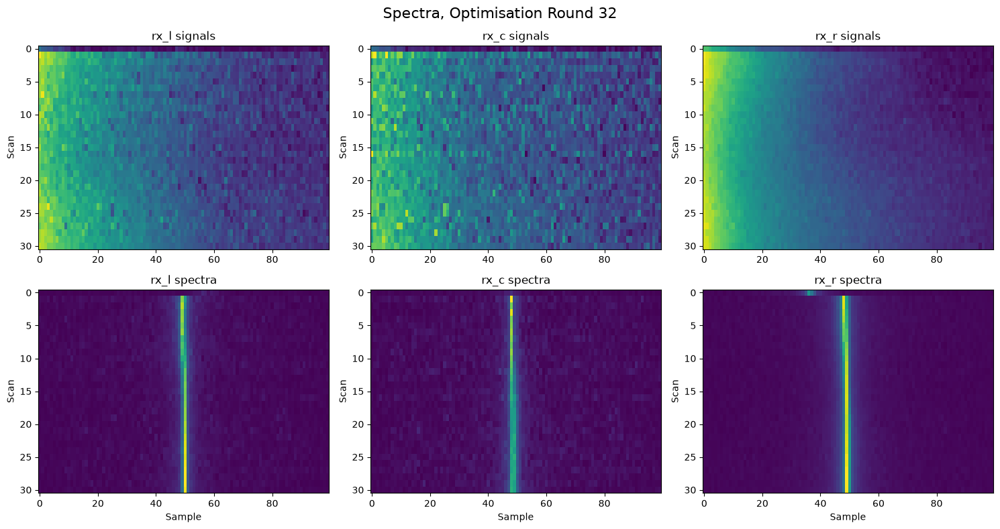

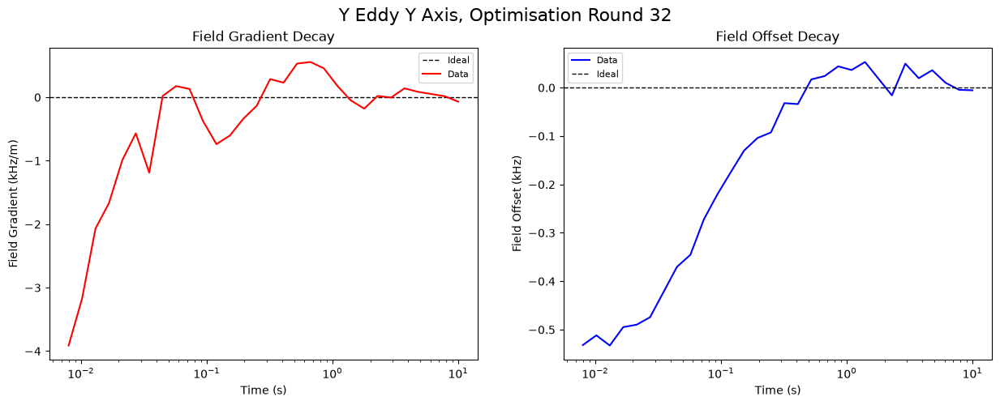

[I 2026-11-25 16:25:17,648] Trial 32 finished with value: 249.0288120941202 and parameters: {'Y_A1': -0.01134900478103239, 'Y_A2': -0.005500376342242144, 'Y_A3': -1.3500685792476281e-09, 'Y_A4': 4.913762720223685e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.490e+02
Total cost = 2.490e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26441093391019277
B nanmax = 0.26441093391019277
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26427513375960826 !!!!!!!!!!!!!!!!


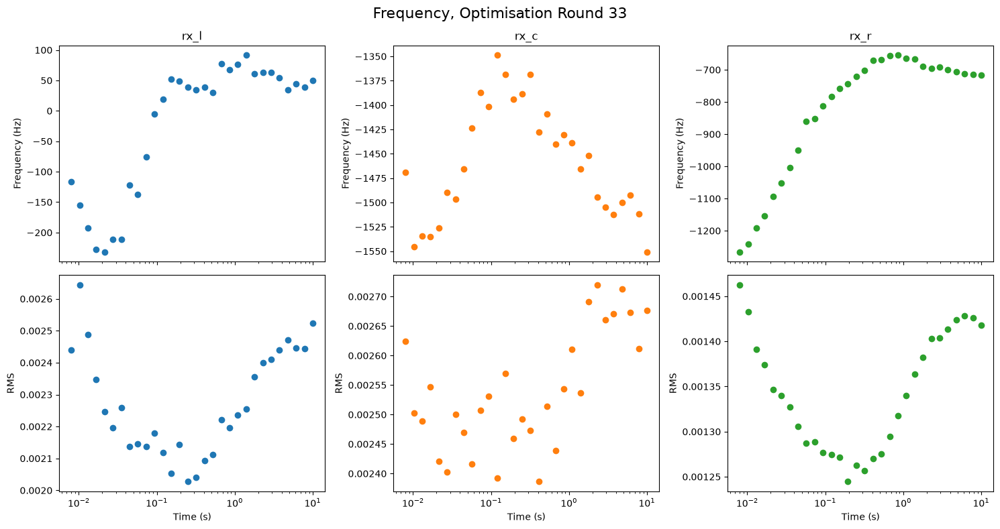

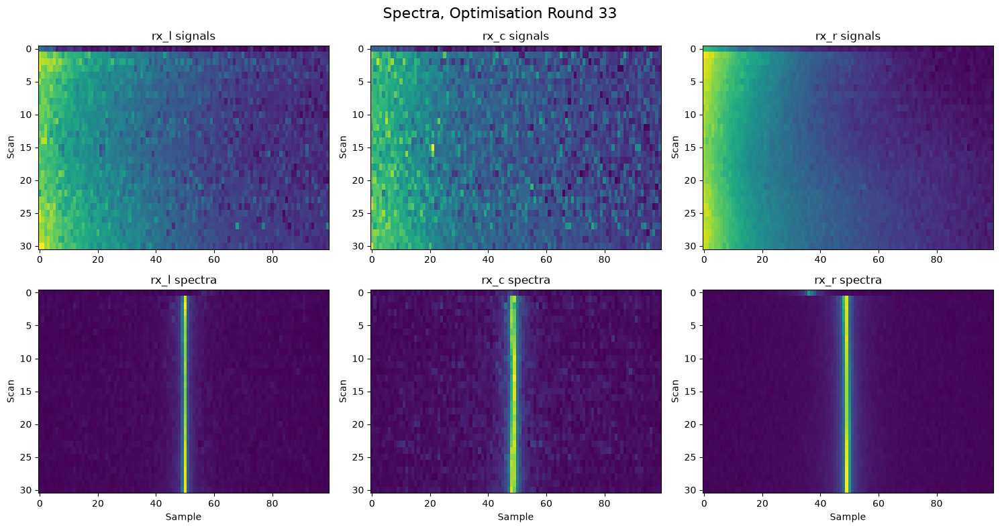

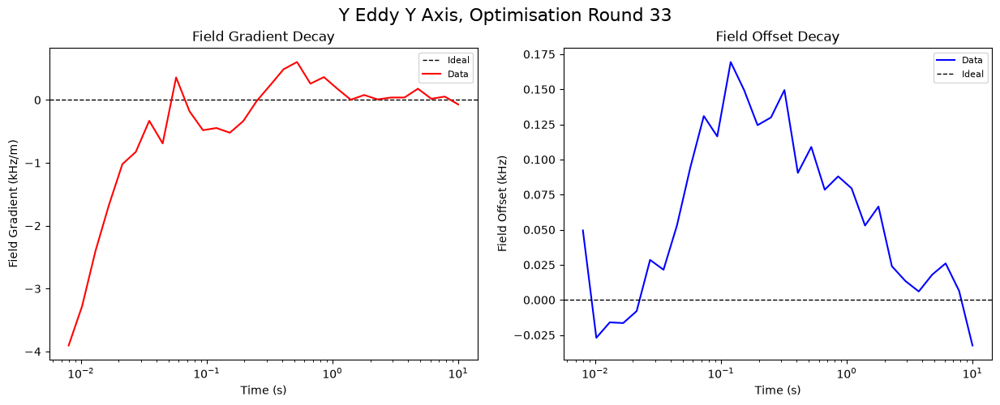

[I 2026-11-25 16:26:05,484] Trial 33 finished with value: 306.81659541520065 and parameters: {'Y_A1': -0.012232314830661508, 'Y_A2': -0.006518420470521373, 'Y_A3': -1.0347295702223273e-09, 'Y_A4': 4.3807233457673124e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.068e+02
Total cost = 3.068e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2624409644652241
B nanmax = 0.2624409644652241
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.262306175935119 !!!!!!!!!!!!!!!!


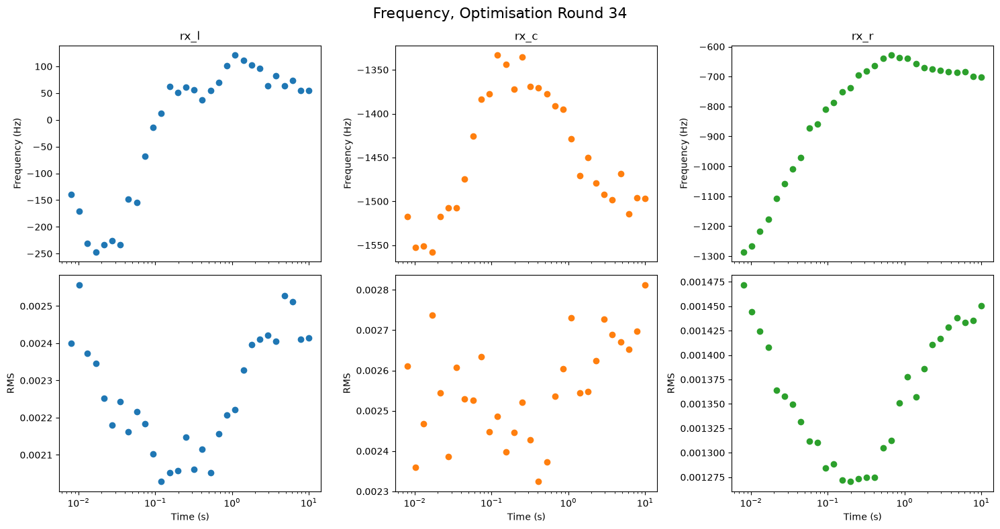

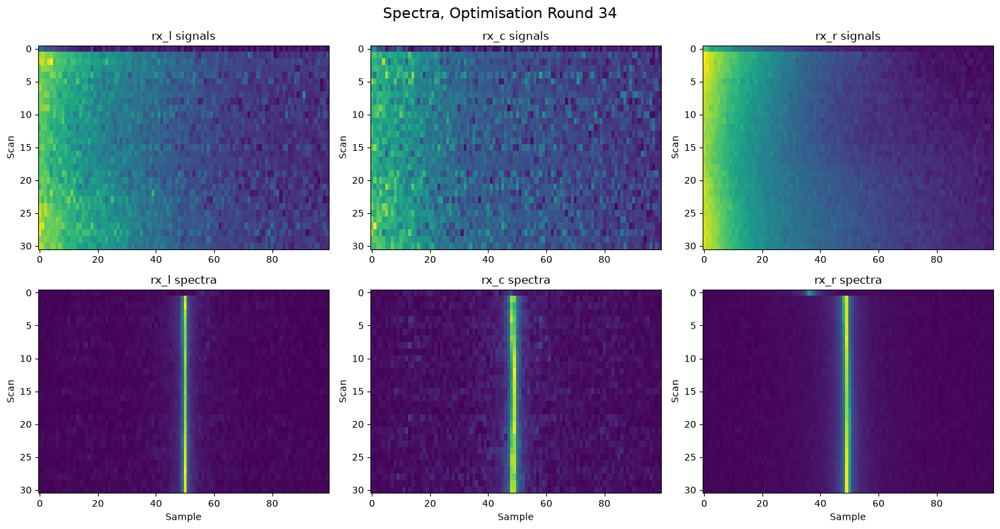

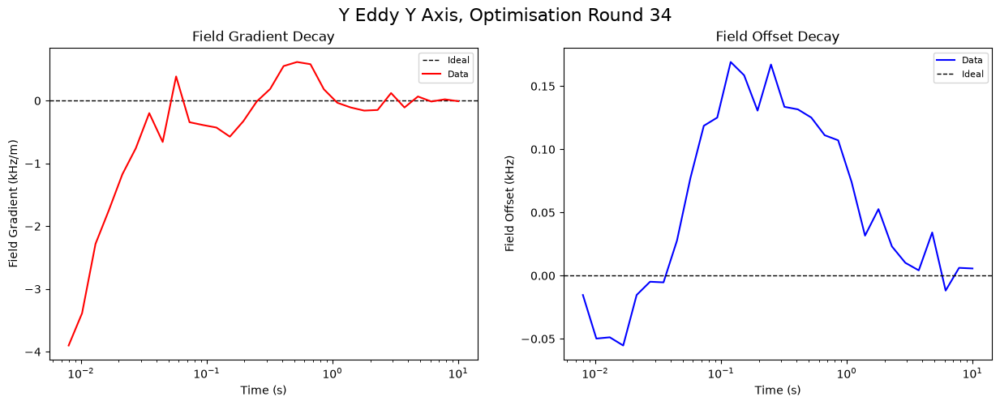

[I 2026-11-25 16:26:53,449] Trial 34 finished with value: 271.9667247994071 and parameters: {'Y_A1': -0.012350334287703943, 'Y_A2': -0.006260308591698088, 'Y_A3': 2.4872498781443307e-09, 'Y_A4': -3.1749483819635104e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.720e+02
Total cost = 2.720e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2863958187445664
B nanmax = 0.2863958187445664
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.28624872692643843 !!!!!!!!!!!!!!!!


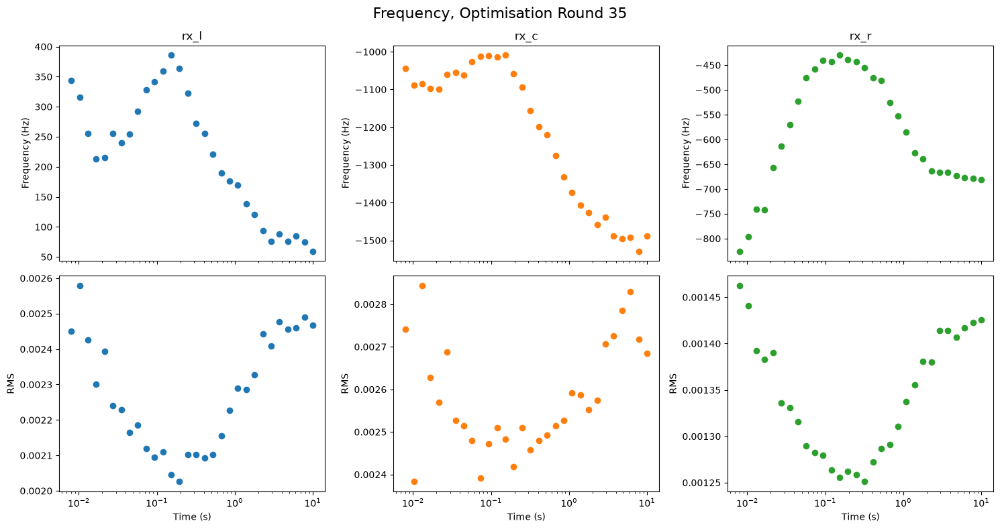

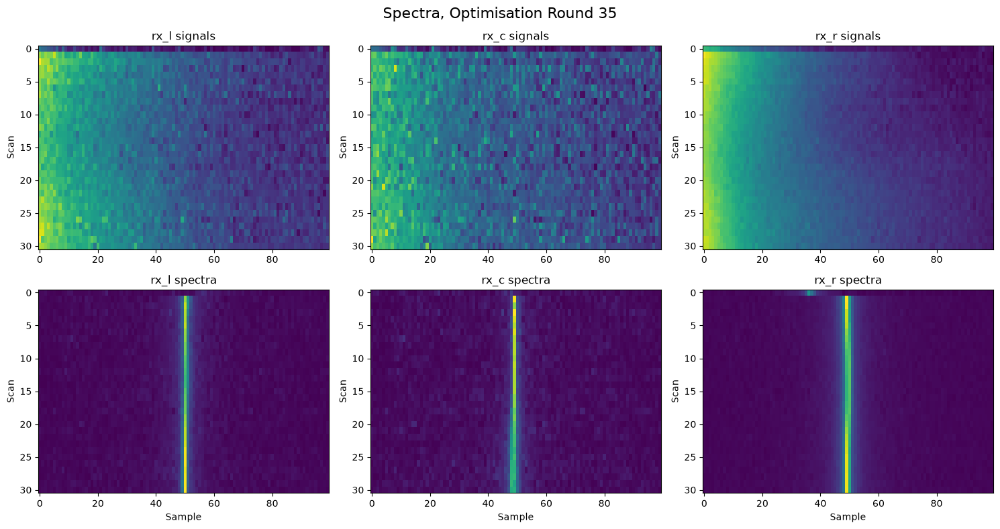

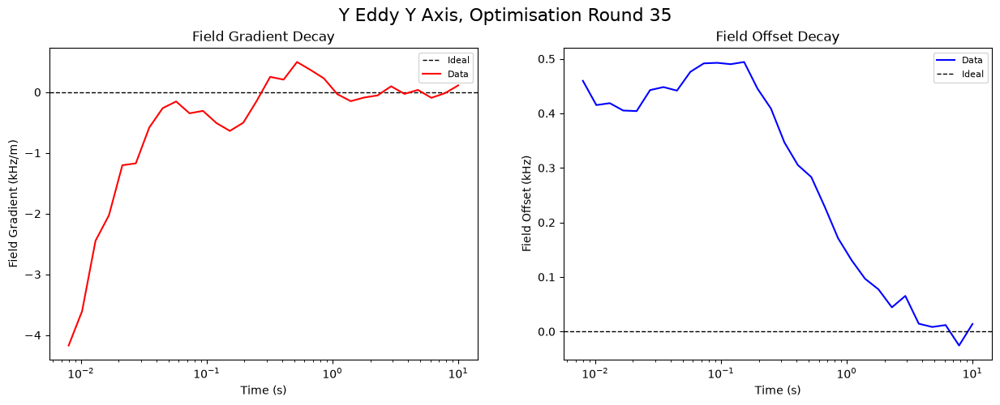

[I 2026-11-25 16:27:41,494] Trial 35 finished with value: 577.7896345518507 and parameters: {'Y_A1': -0.01373498389365238, 'Y_A2': -0.006573902731852157, 'Y_A3': 5.155289539777702e-10, 'Y_A4': -6.4137130660953125e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 5.778e+02
Total cost = 5.778e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23242043583229946
B nanmax = 0.23242043583229946
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2323010662379432 !!!!!!!!!!!!!!!!


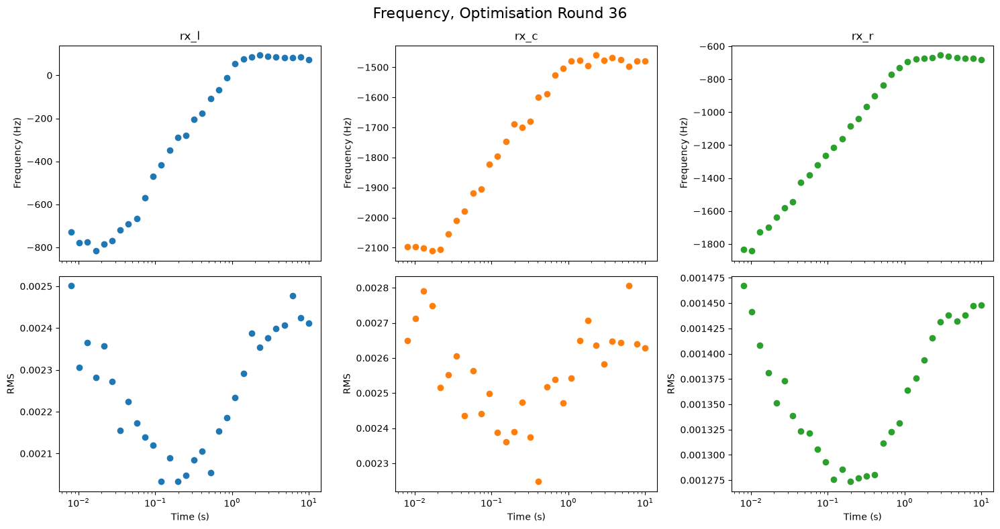

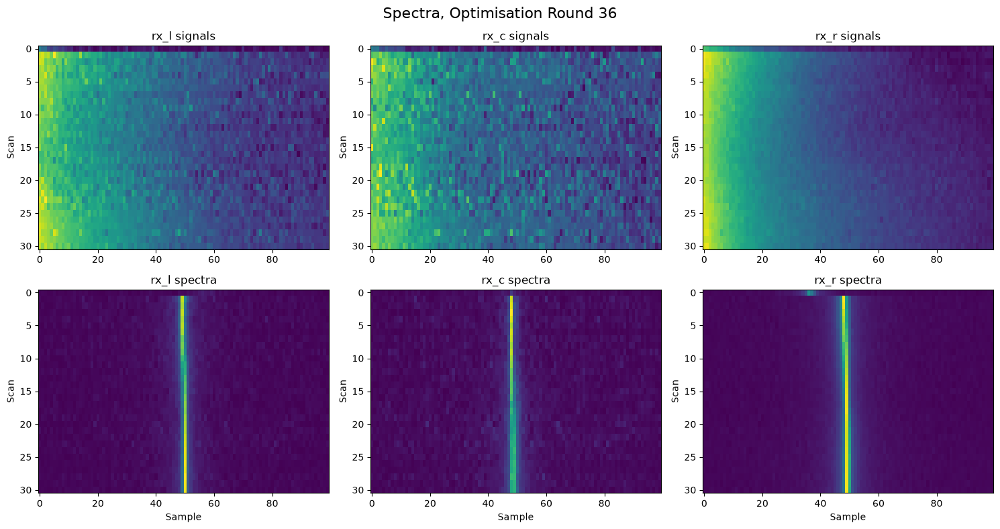

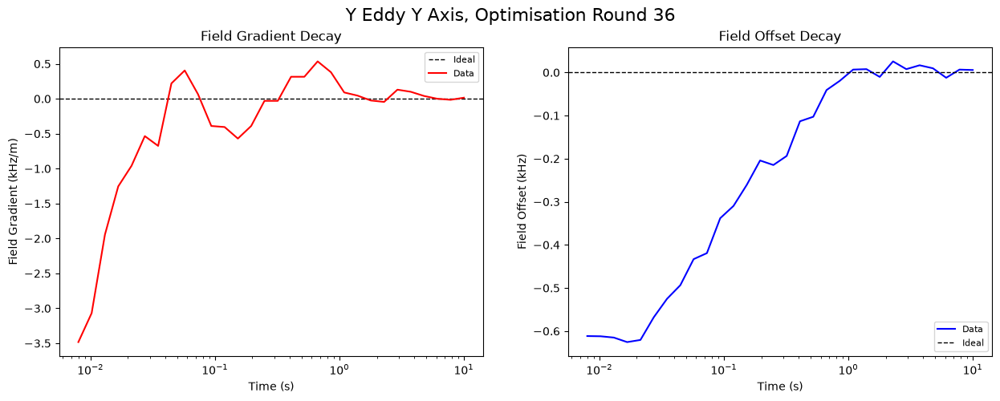

[I 2026-11-25 16:28:29,477] Trial 36 finished with value: 233.15163256554067 and parameters: {'Y_A1': -0.010187872403732466, 'Y_A2': -0.006295309998892706, 'Y_A3': -3.553179001098344e-09, 'Y_A4': 2.963751740162244e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.332e+02
Total cost = 2.332e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2609812140861664
B nanmax = 0.2609812140861664
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.260847175650024 !!!!!!!!!!!!!!!!


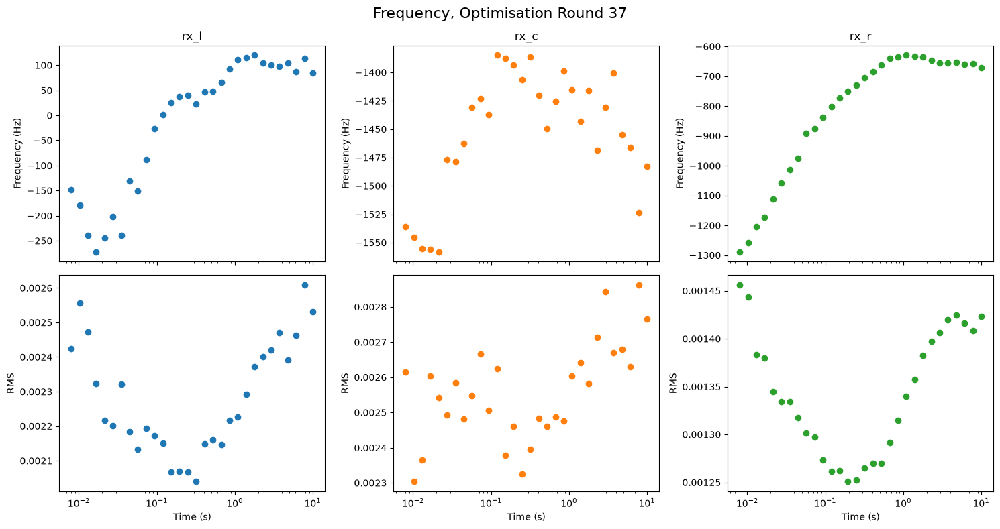

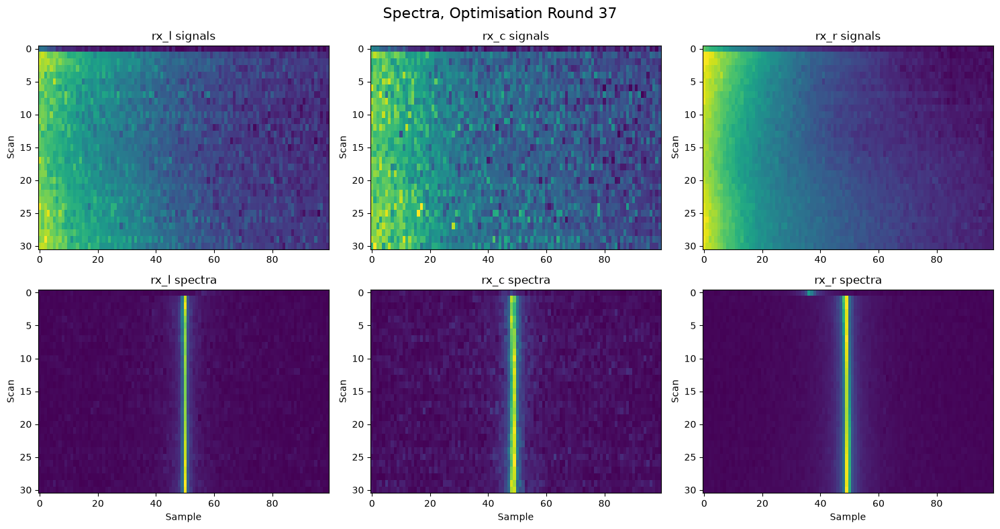

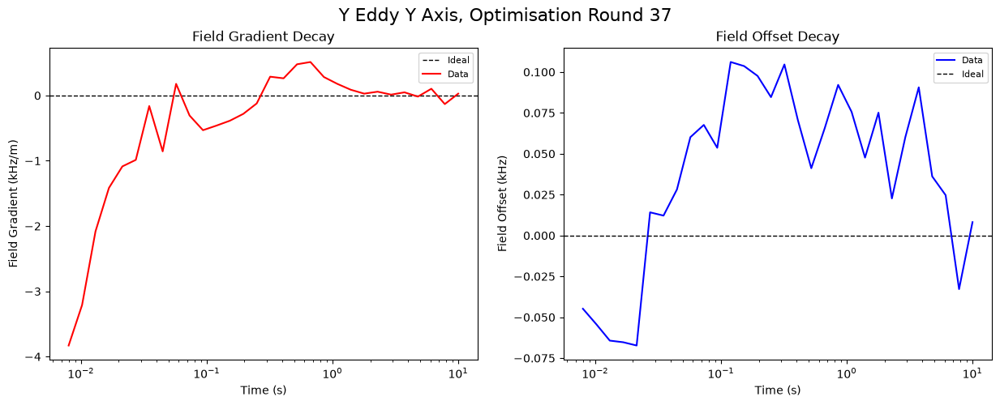

[I 2026-11-25 16:29:17,218] Trial 37 finished with value: 437.4789743662489 and parameters: {'Y_A1': -0.011748303363244604, 'Y_A2': -0.006759822345278838, 'Y_A3': 3.3163445240156864e-09, 'Y_A4': -8.708673390952244e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 4.375e+02
Total cost = 4.375e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.22771595857754692
B nanmax = 0.22771595857754692
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2275990045866886 !!!!!!!!!!!!!!!!


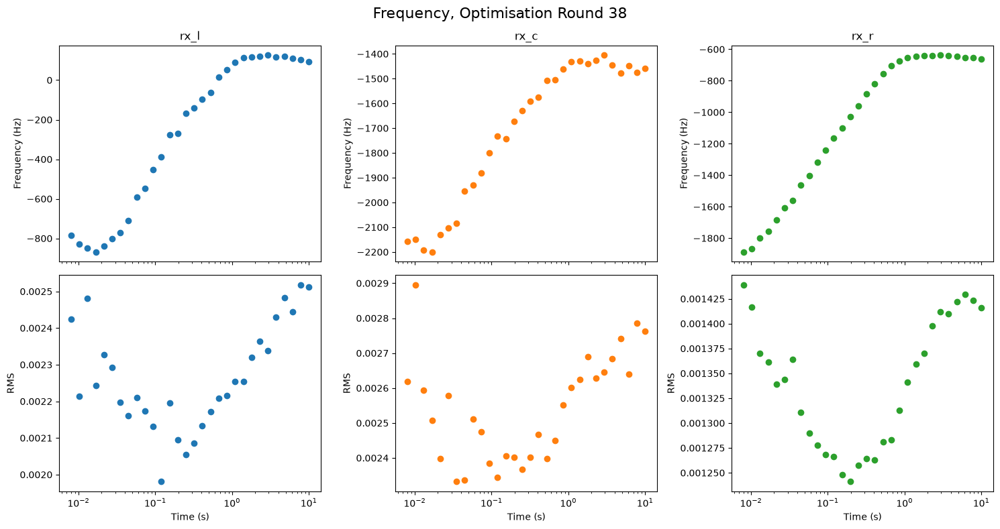

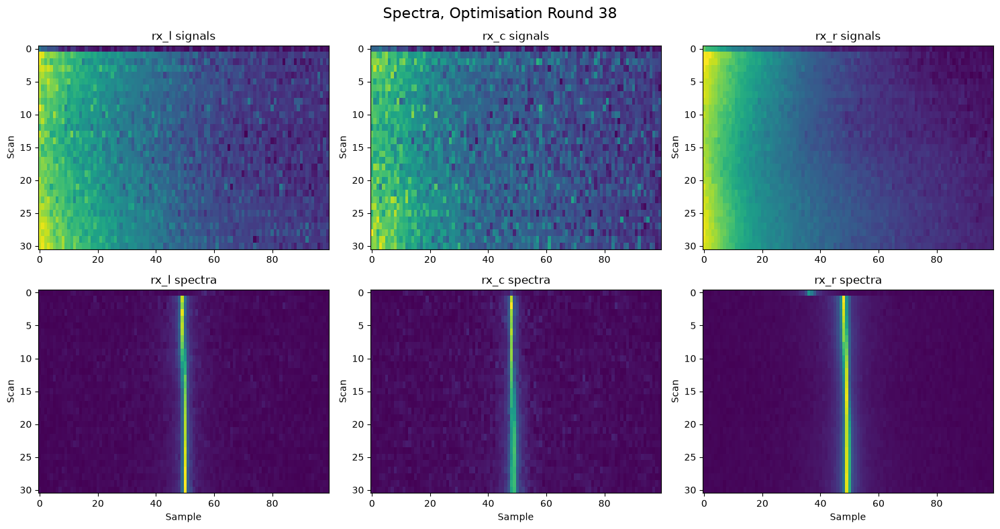

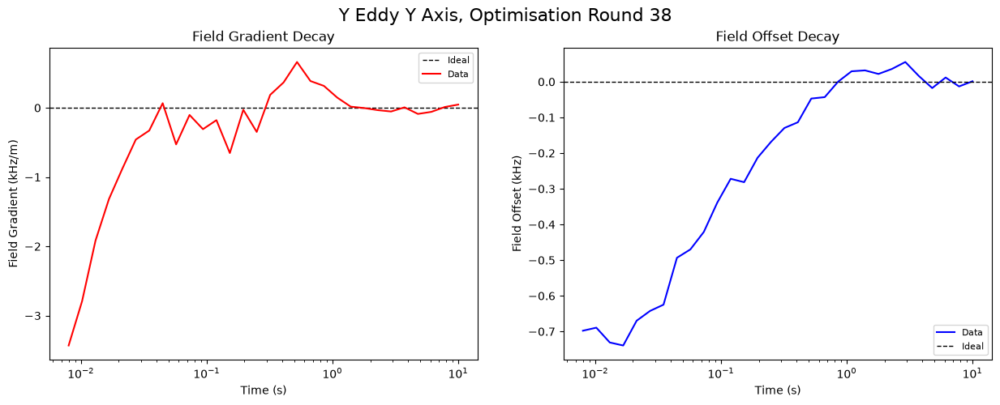

[I 2026-11-25 16:30:04,955] Trial 38 finished with value: 294.1565986150489 and parameters: {'Y_A1': -0.010818858470277236, 'Y_A2': -0.005329115691009448, 'Y_A3': -1.0230768506284753e-09, 'Y_A4': 2.2628297892265987e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.942e+02
Total cost = 2.942e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25212565523619224
B nanmax = 0.25212565523619224
B contains nan = False
Trial 39


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25199616403954256 !!!!!!!!!!!!!!!!


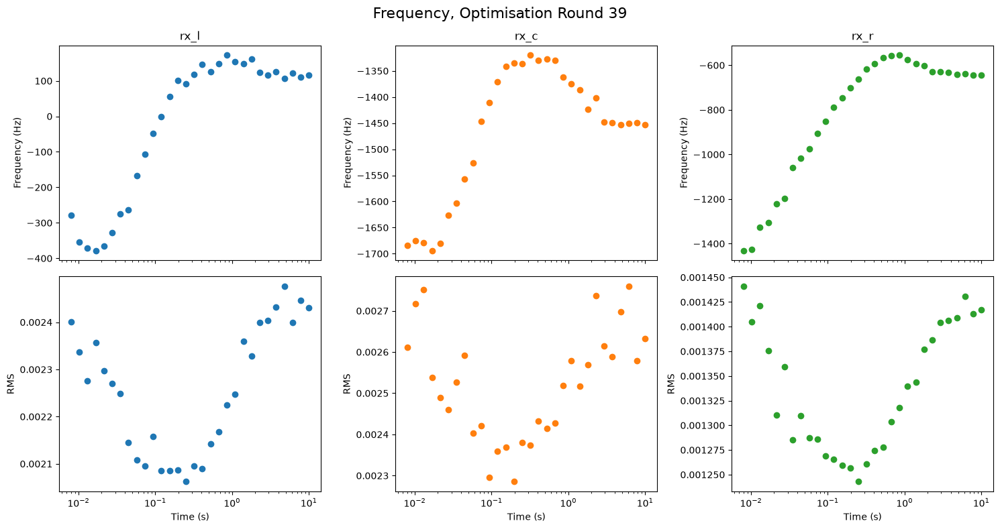

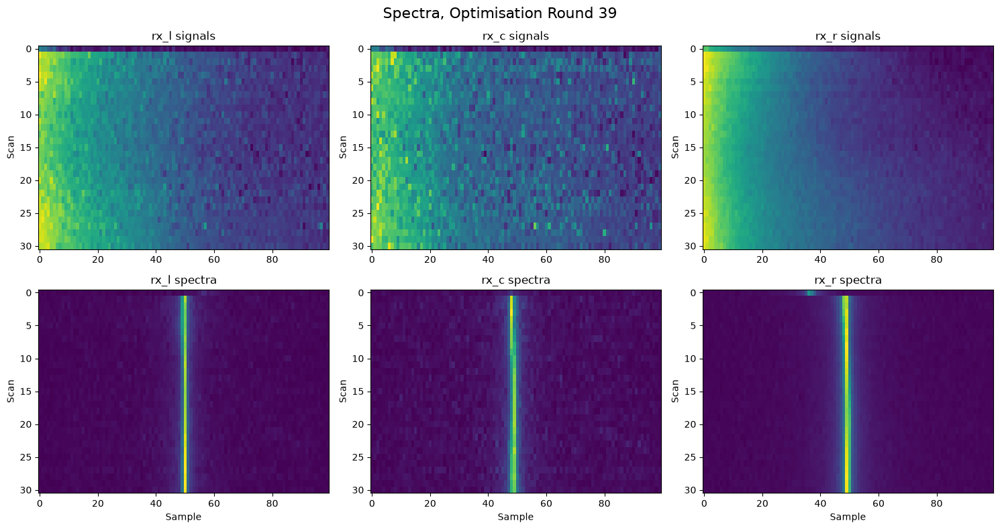

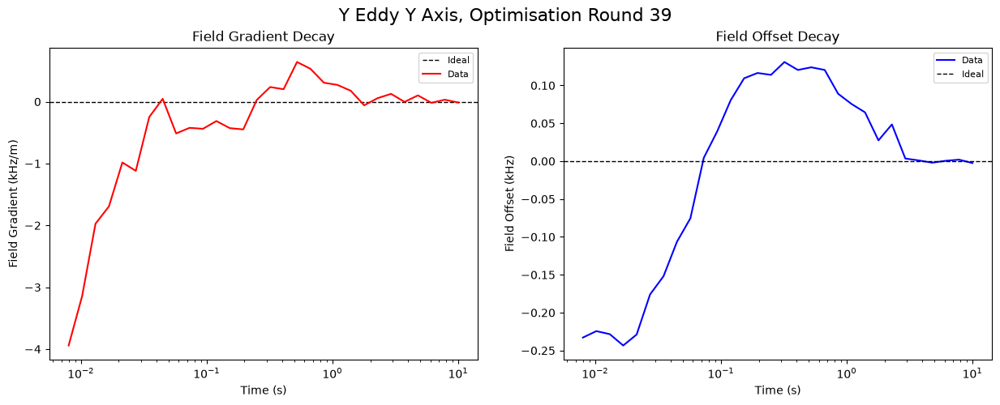

[I 2026-11-25 16:30:52,751] Trial 39 finished with value: 202.34209792885468 and parameters: {'Y_A1': -0.012672584881061828, 'Y_A2': -0.005205048981353277, 'Y_A3': 1.0057697127792124e-09, 'Y_A4': 2.891980405999799e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.023e+02
Total cost = 2.023e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.27155717967608045
B nanmax = 0.27155717967608045
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.27141770942765564 !!!!!!!!!!!!!!!!


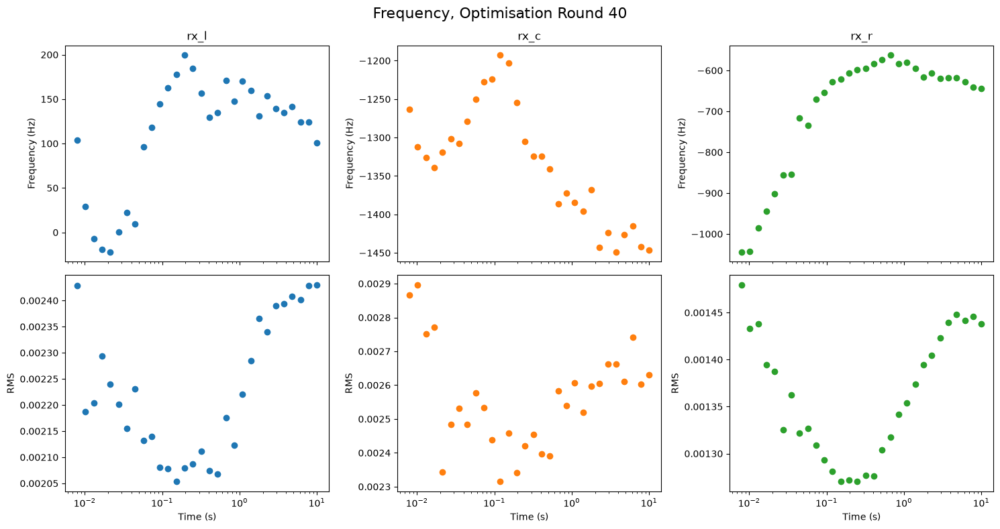

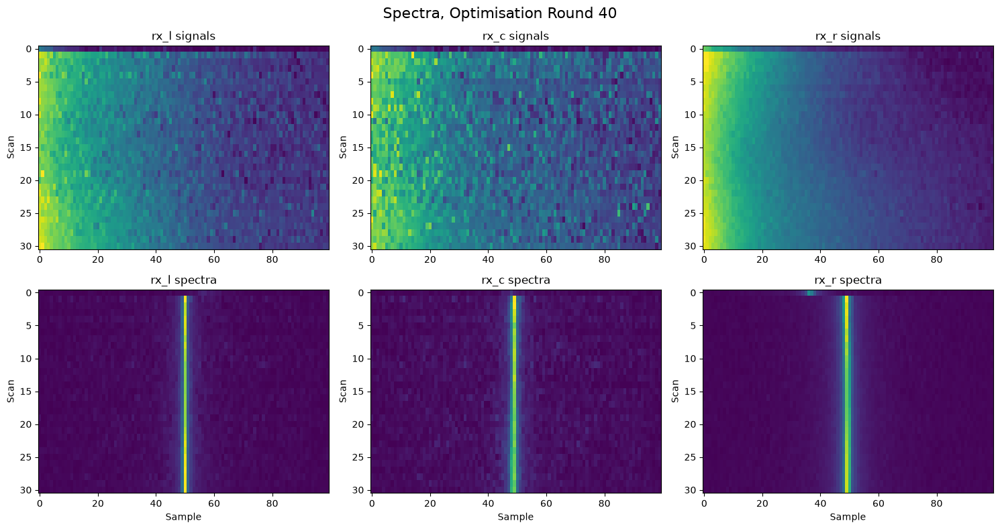

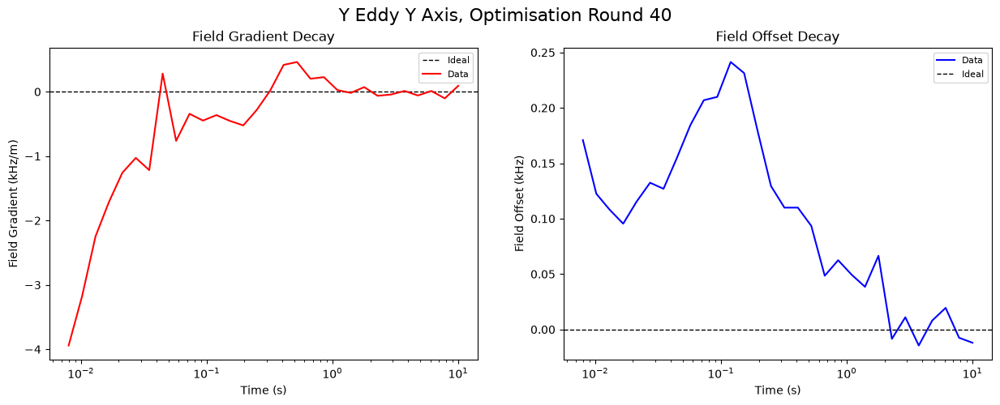

[I 2026-11-25 16:31:41,050] Trial 40 finished with value: 252.26840238883918 and parameters: {'Y_A1': -0.012307081802623356, 'Y_A2': -0.0069509096620146696, 'Y_A3': 2.528137850946492e-09, 'Y_A4': -3.14898249942122e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.523e+02
Total cost = 2.523e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24264218238283186
B nanmax = 0.24264218238283186
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24251756236888977 !!!!!!!!!!!!!!!!


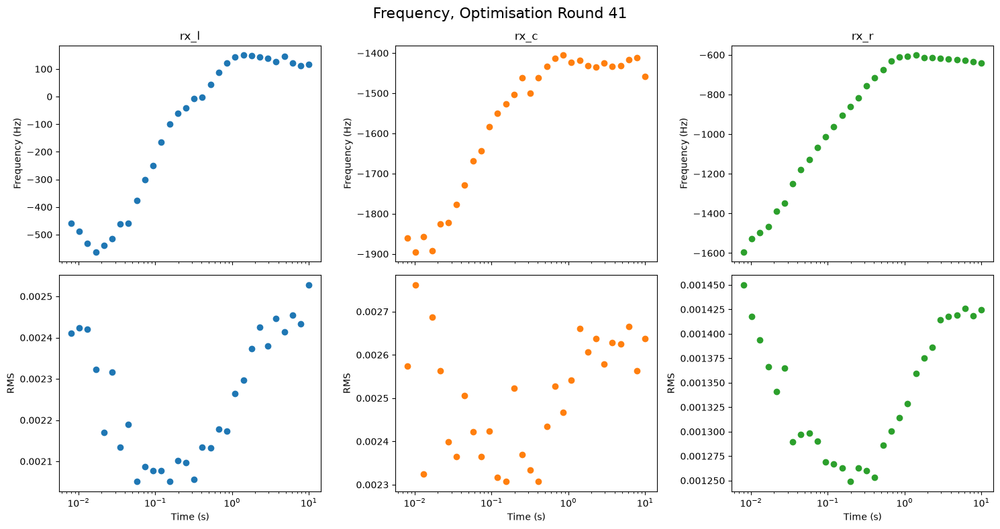

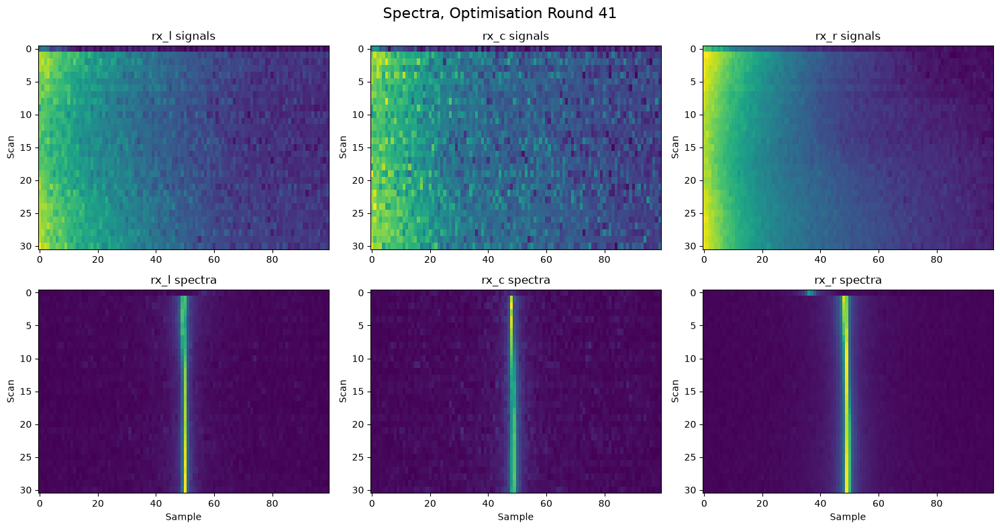

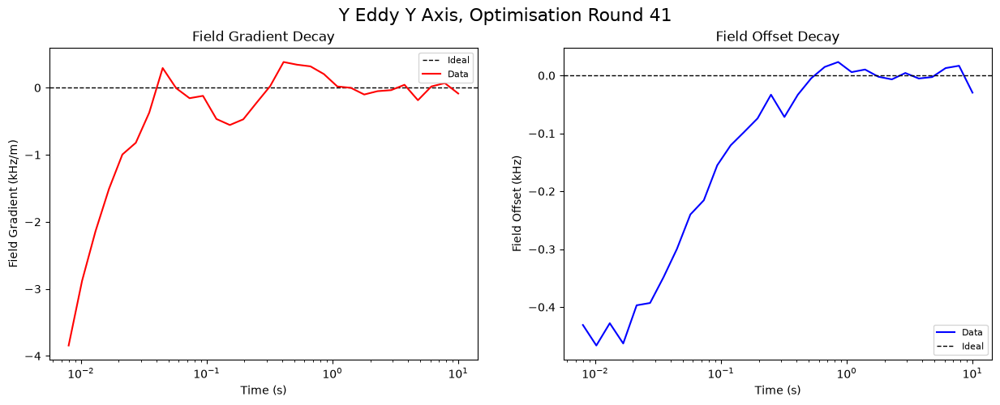

[I 2026-11-25 16:32:29,128] Trial 41 finished with value: 162.5879327833287 and parameters: {'Y_A1': -0.011492498562733487, 'Y_A2': -0.005714002302549264, 'Y_A3': -6.011646065226863e-09, 'Y_A4': -4.1381716616314644e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.626e+02
Total cost = 1.626e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26811384399651556
B nanmax = 0.26811384399651556
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2679761417912729 !!!!!!!!!!!!!!!!


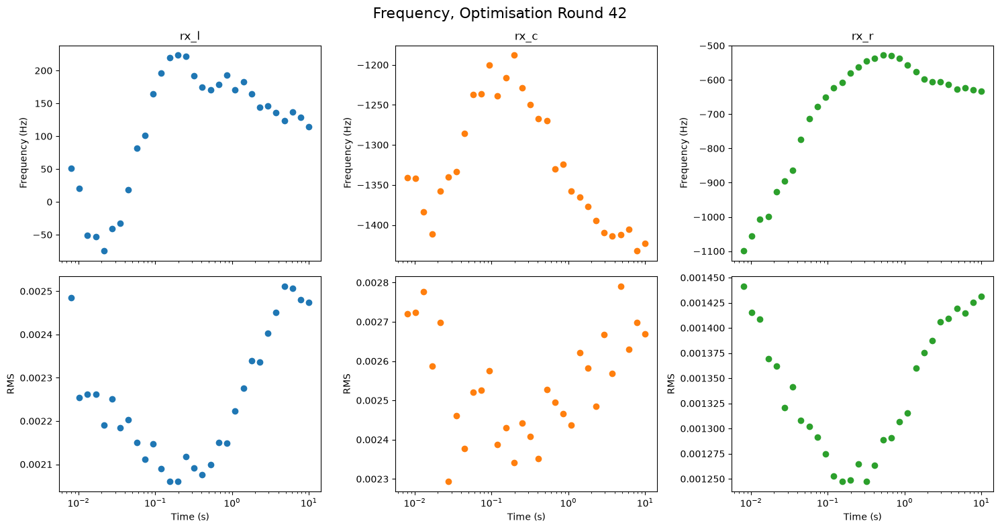

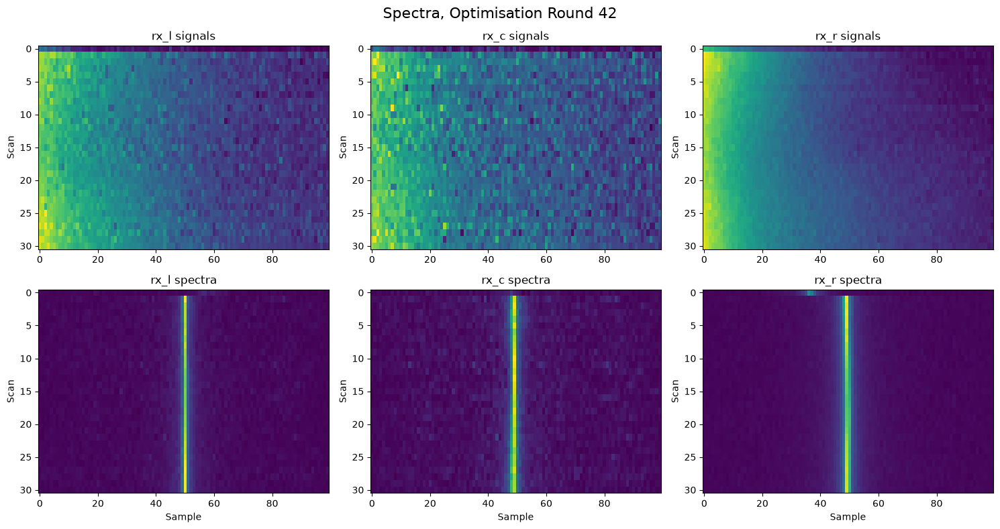

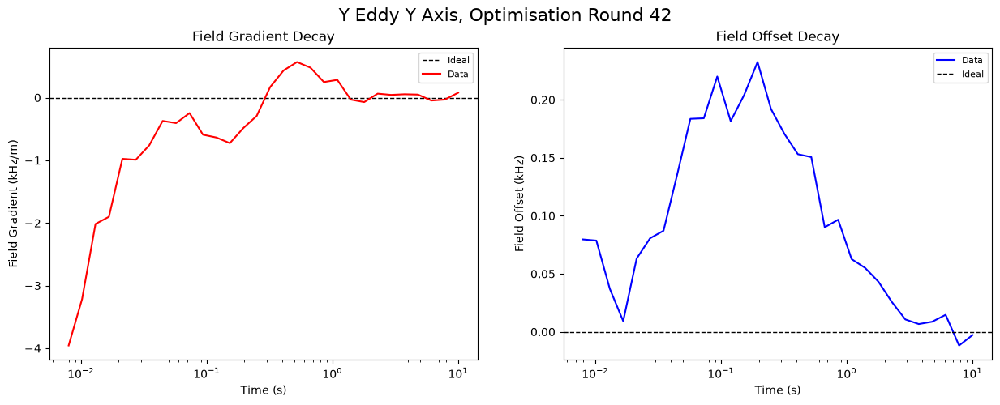

[I 2026-11-25 16:33:17,098] Trial 42 finished with value: 277.64196396169956 and parameters: {'Y_A1': -0.012773410996450428, 'Y_A2': -0.006239223963993473, 'Y_A3': -7.065634929613773e-09, 'Y_A4': 2.1930715237398567e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.776e+02
Total cost = 2.776e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.21667320969256293
B nanmax = 0.21667320969256293
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.21656192721074835 !!!!!!!!!!!!!!!!


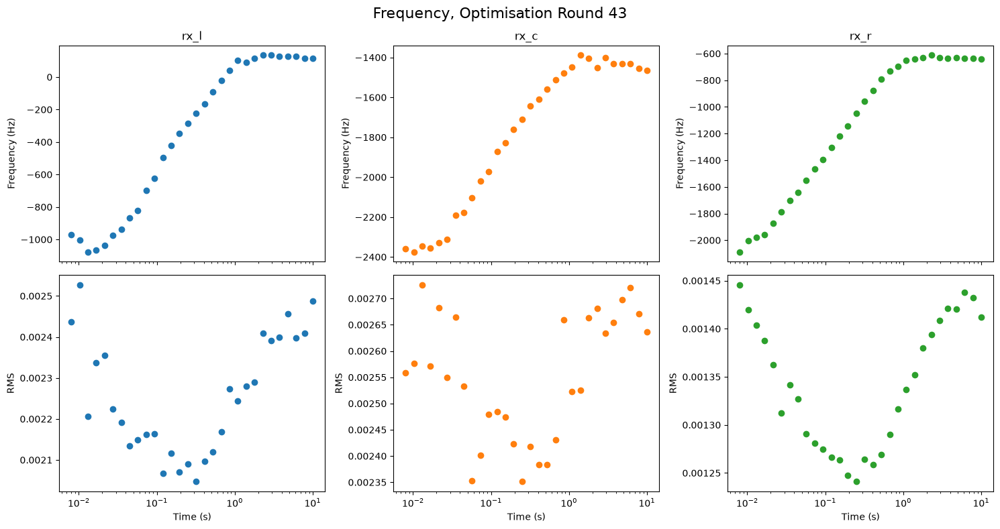

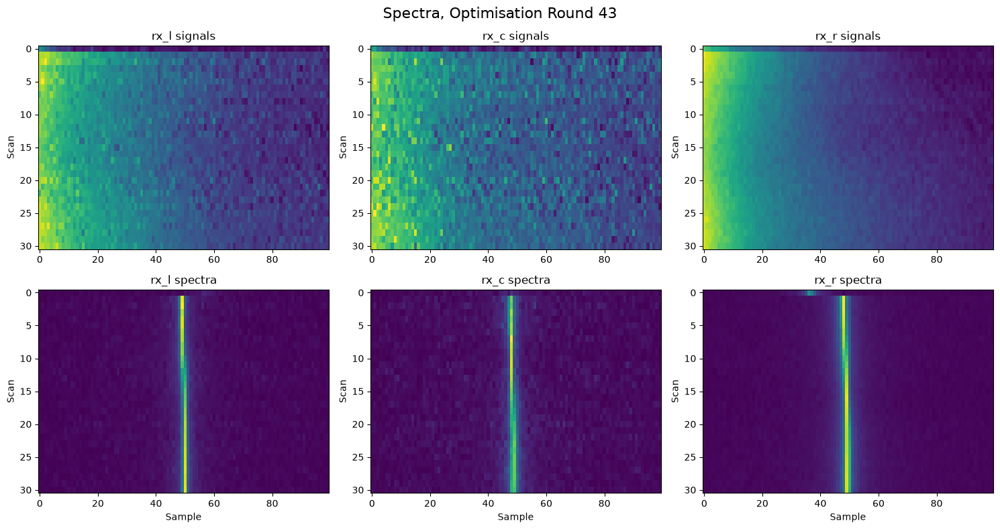

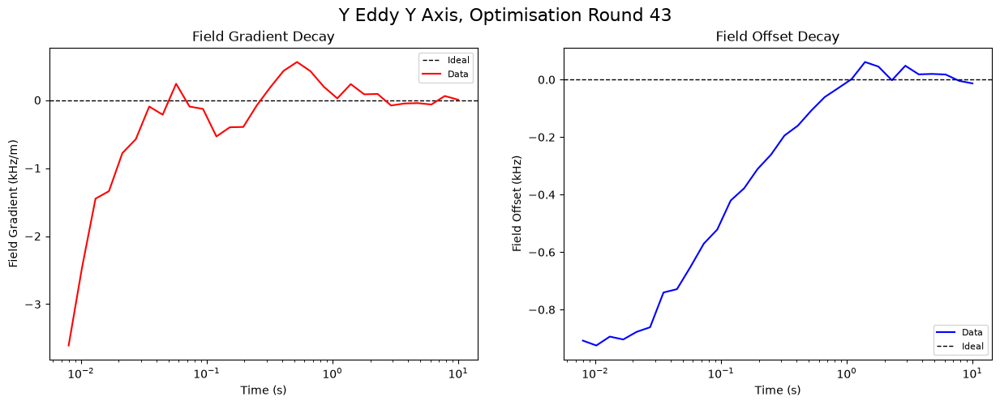

[I 2026-11-25 16:34:05,241] Trial 43 finished with value: 355.2214870905587 and parameters: {'Y_A1': -0.010296944559780478, 'Y_A2': -0.005067952343577034, 'Y_A3': -5.119848122501938e-09, 'Y_A4': -1.060229451768661e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.552e+02
Total cost = 3.552e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2421814927462097
B nanmax = 0.2421814927462097
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24205710861570376 !!!!!!!!!!!!!!!!


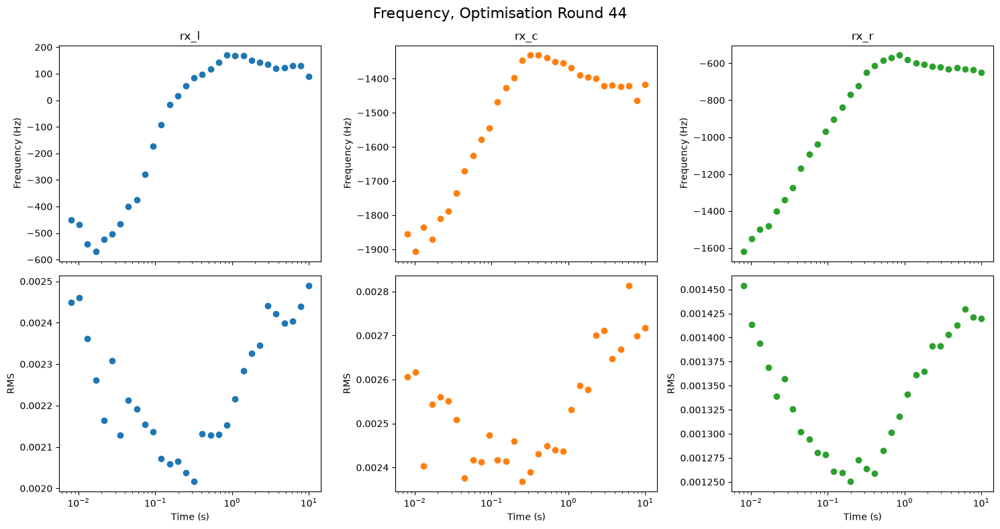

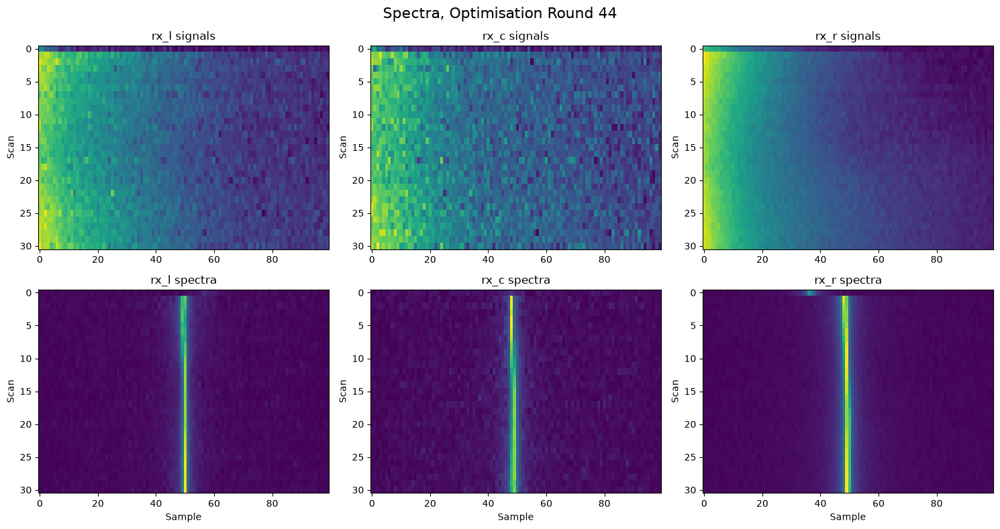

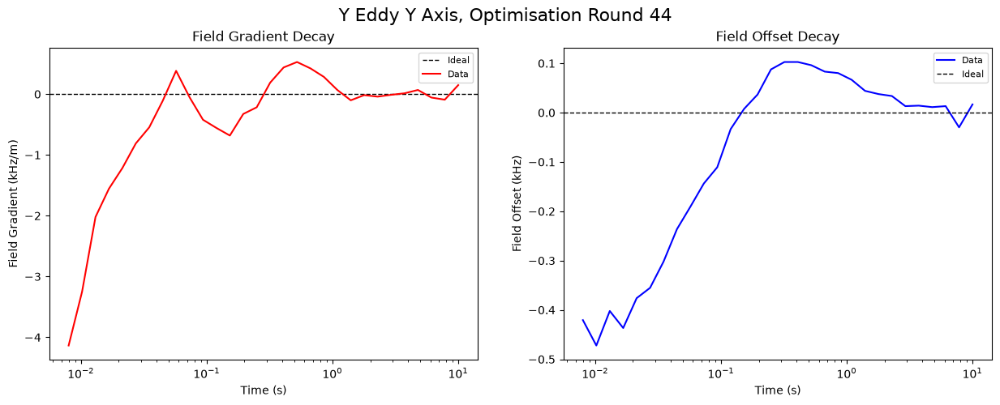

[I 2026-11-25 16:34:52,979] Trial 44 finished with value: 294.049772553882 and parameters: {'Y_A1': -0.012508339455836456, 'Y_A2': -0.004663548766904312, 'Y_A3': 4.970011122472111e-10, 'Y_A4': -9.892828635121053e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.940e+02
Total cost = 2.940e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2553958022406989
B nanmax = 0.2553958022406989
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25526463156981244 !!!!!!!!!!!!!!!!


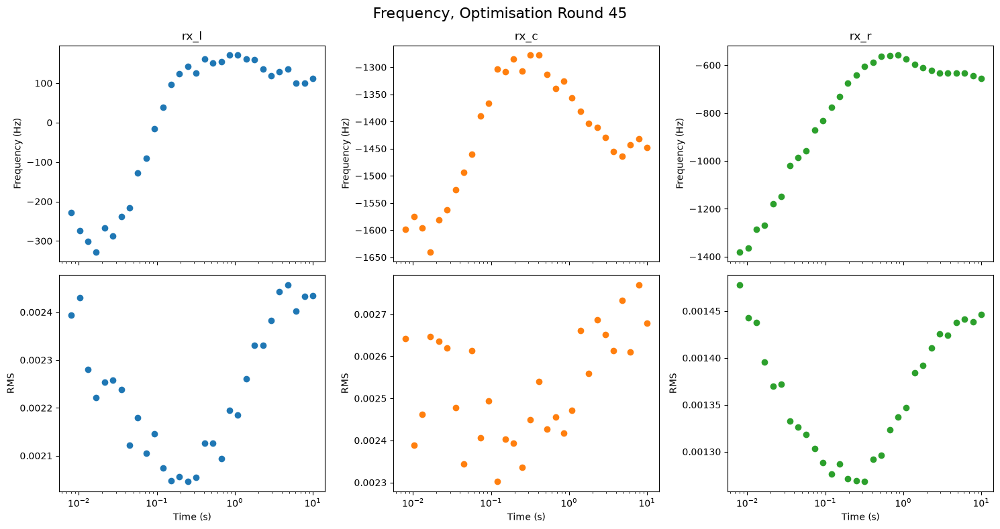

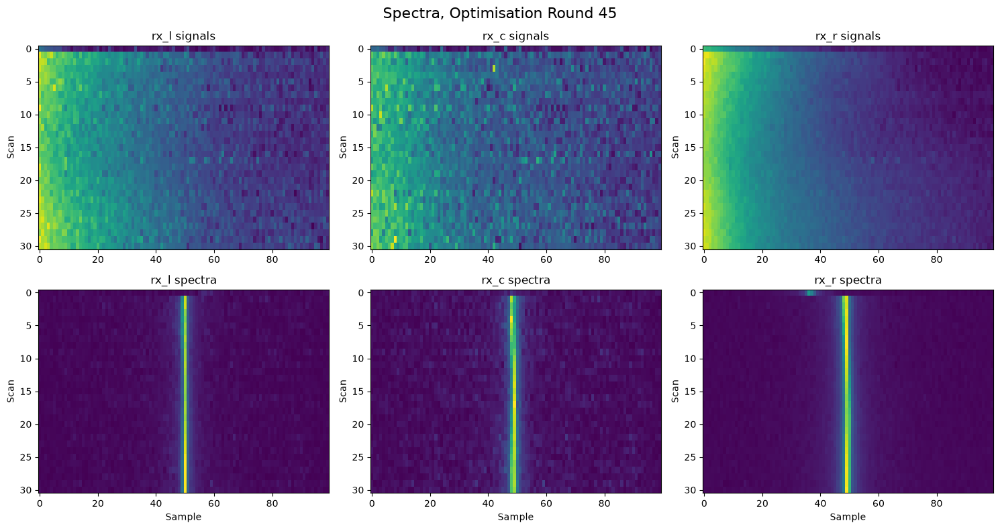

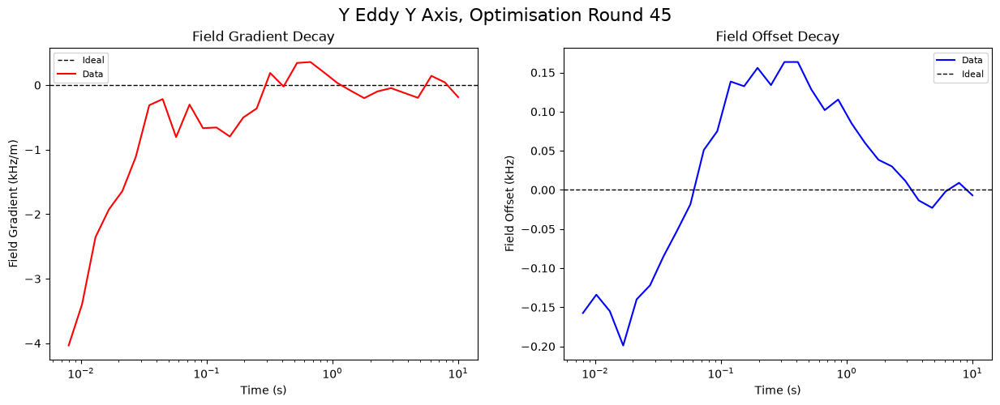

[I 2026-11-25 16:35:40,801] Trial 45 finished with value: 274.79563680800004 and parameters: {'Y_A1': -0.012742081417253873, 'Y_A2': -0.005367608544672044, 'Y_A3': -3.5193508559515104e-09, 'Y_A4': 2.542064538918092e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.748e+02
Total cost = 2.748e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23460720694964515
B nanmax = 0.23460720694964515
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2344867133334934 !!!!!!!!!!!!!!!!


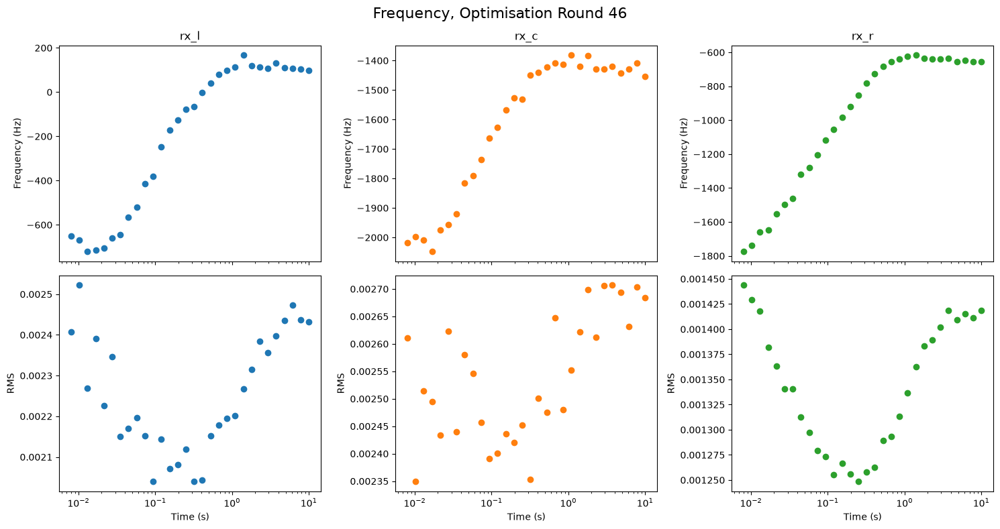

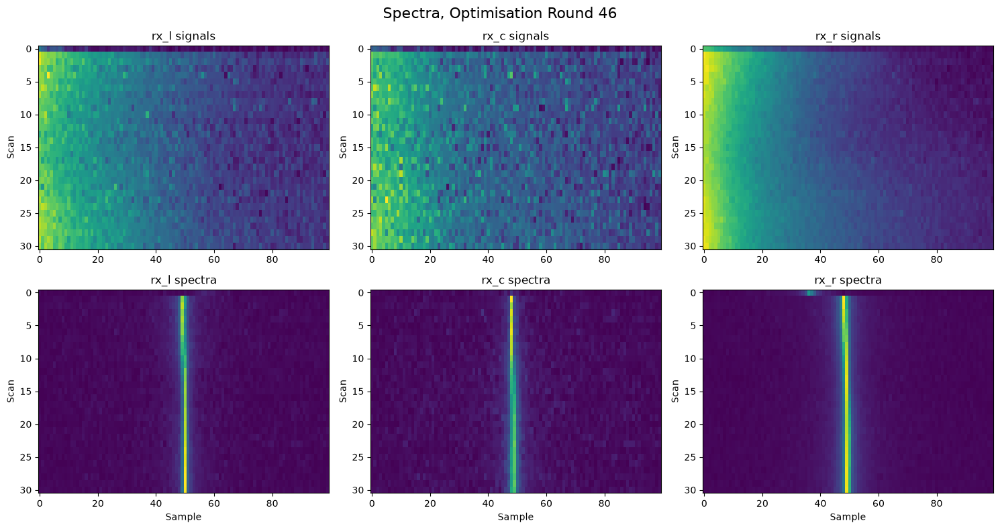

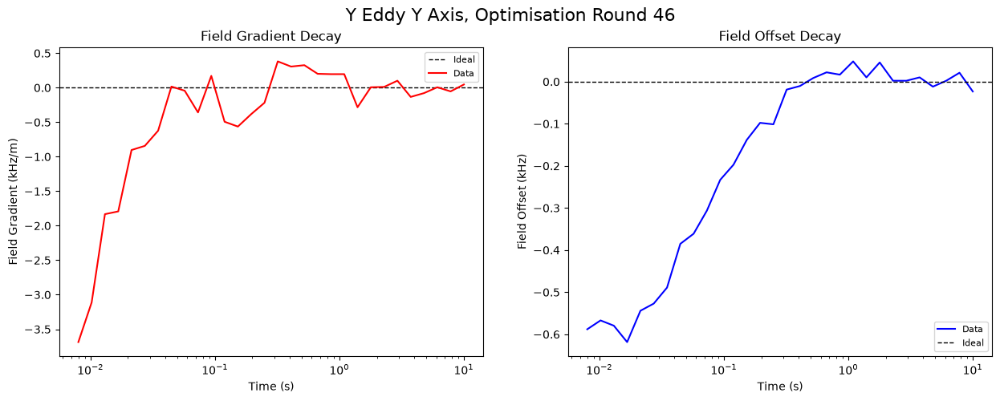

[I 2026-11-25 16:36:28,705] Trial 46 finished with value: 203.68161227566455 and parameters: {'Y_A1': -0.01158738190332443, 'Y_A2': -0.005048443618481818, 'Y_A3': -2.577307494875583e-09, 'Y_A4': 1.5948649041555857e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.037e+02
Total cost = 2.037e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.21259052050995456
B nanmax = 0.21259052050995456
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.21248133551885898 !!!!!!!!!!!!!!!!


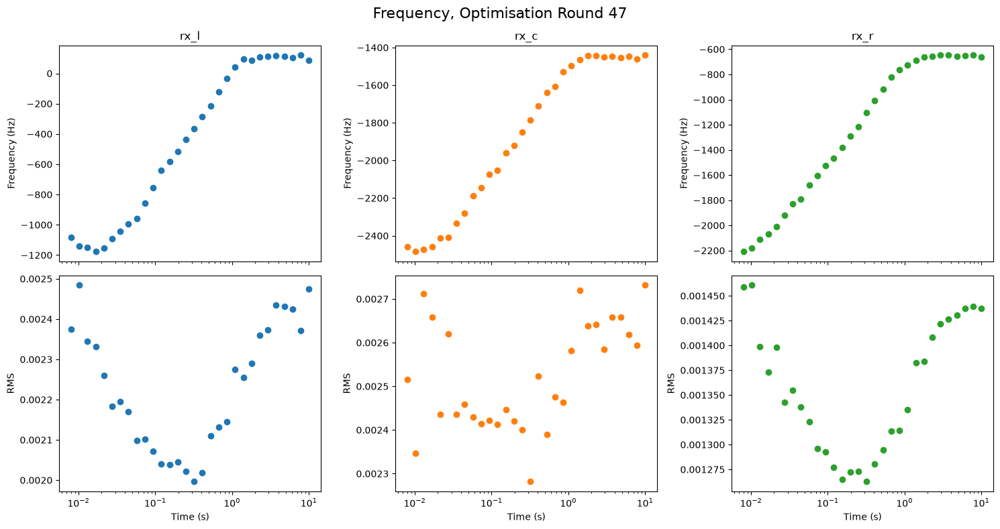

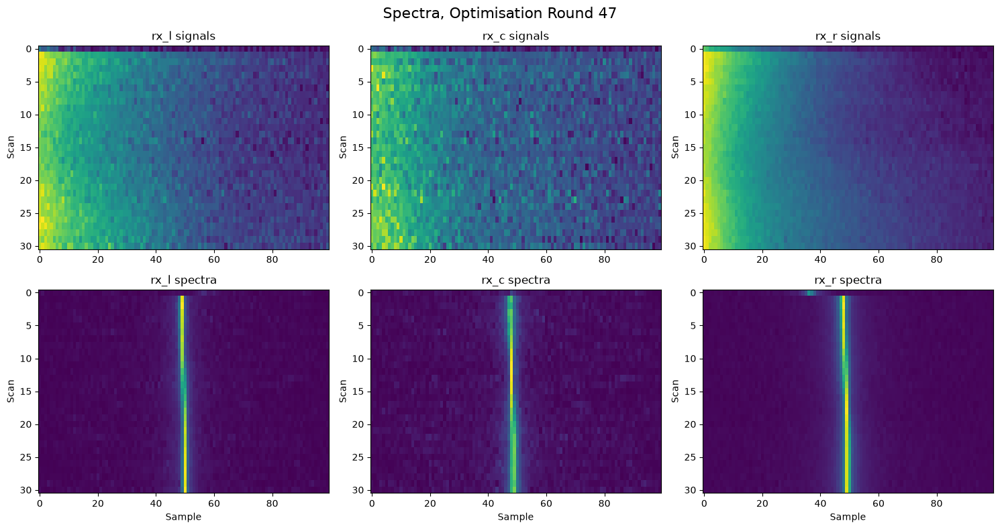

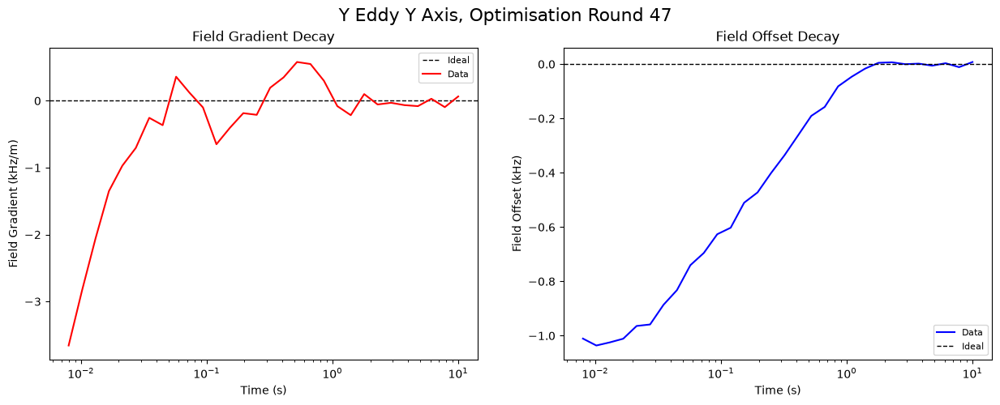

[I 2026-11-25 16:37:16,562] Trial 47 finished with value: 352.8020478984099 and parameters: {'Y_A1': -0.009189419193678133, 'Y_A2': -0.005887674081381657, 'Y_A3': -2.0805463252934534e-09, 'Y_A4': 2.0210003284639893e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.528e+02
Total cost = 3.528e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2419523176801977
B nanmax = 0.2419523176801977
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24182805183948577 !!!!!!!!!!!!!!!!


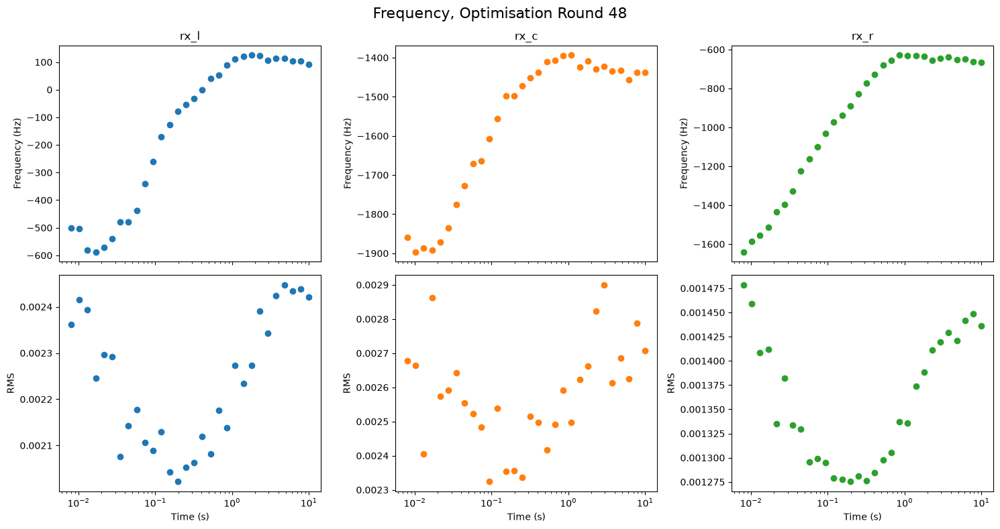

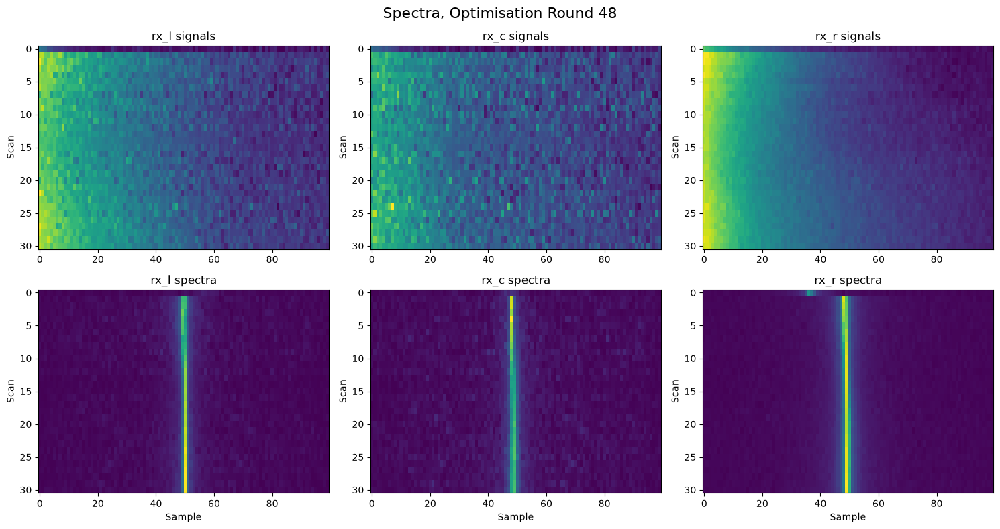

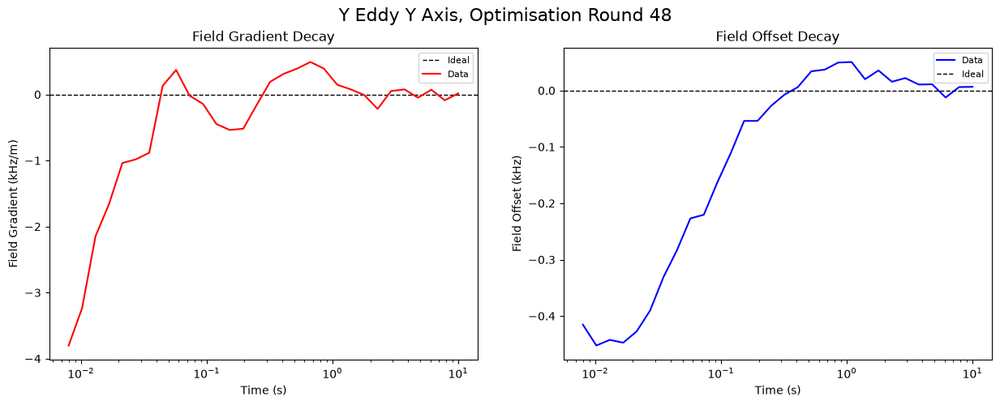

[I 2026-11-25 16:38:04,550] Trial 48 finished with value: 180.5440448646716 and parameters: {'Y_A1': -0.011657961930711815, 'Y_A2': -0.0054992473652099, 'Y_A3': 6.1686895447708e-10, 'Y_A4': 1.4878943705702653e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.805e+02
Total cost = 1.805e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2382723971926942
B nanmax = 0.2382723971926942
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2381500216997597 !!!!!!!!!!!!!!!!


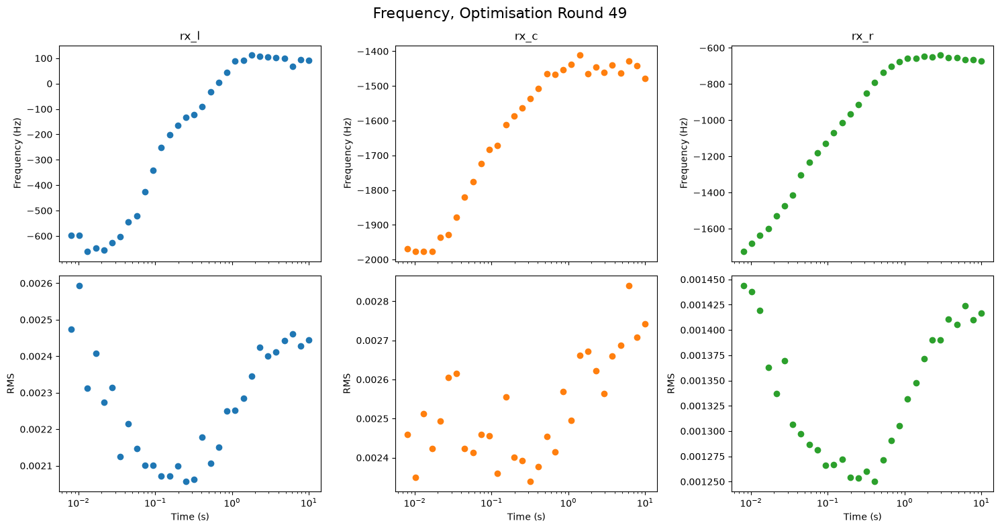

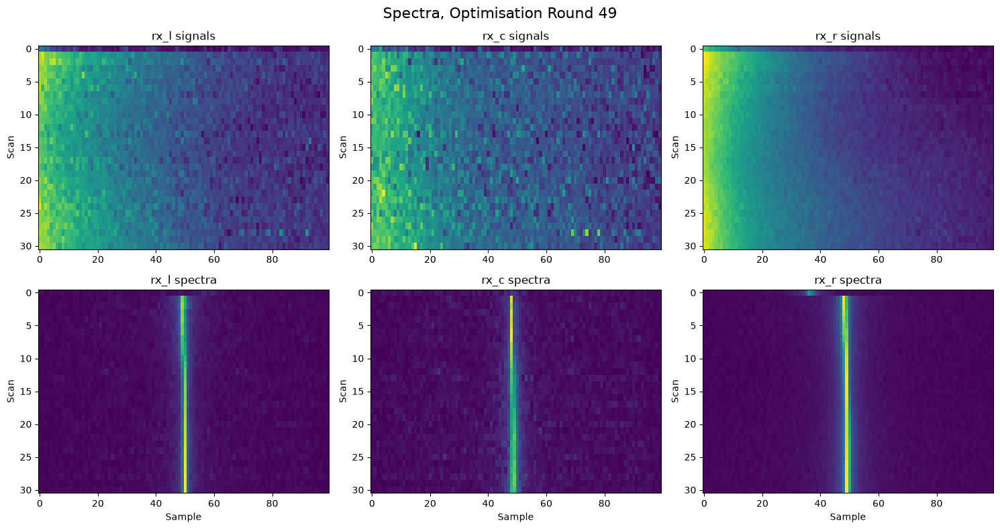

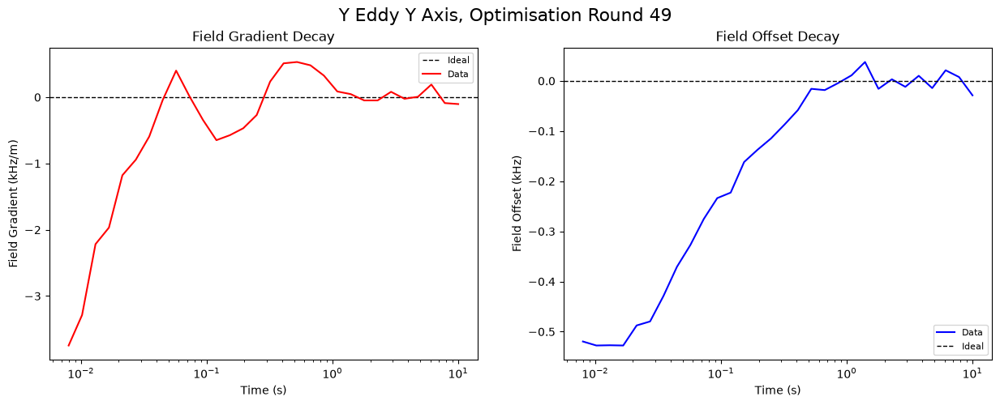

[I 2026-11-25 16:38:52,307] Trial 49 finished with value: 218.44641804198156 and parameters: {'Y_A1': -0.010974107461698473, 'Y_A2': -0.0059231018898980425, 'Y_A3': -2.4524310035049134e-09, 'Y_A4': -1.1229380670665435e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.184e+02
Total cost = 2.184e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24032450597180957
B nanmax = 0.24032450597180957
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24020107648762512 !!!!!!!!!!!!!!!!


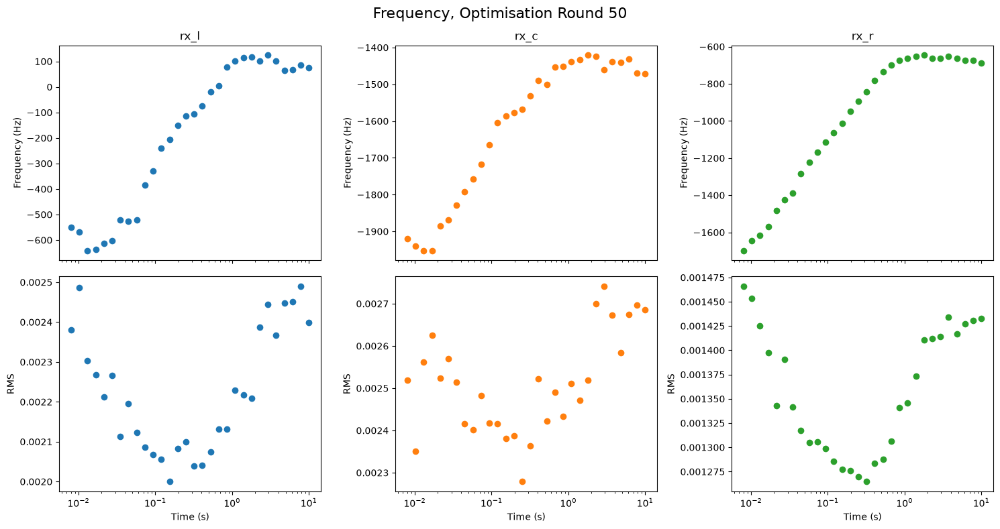

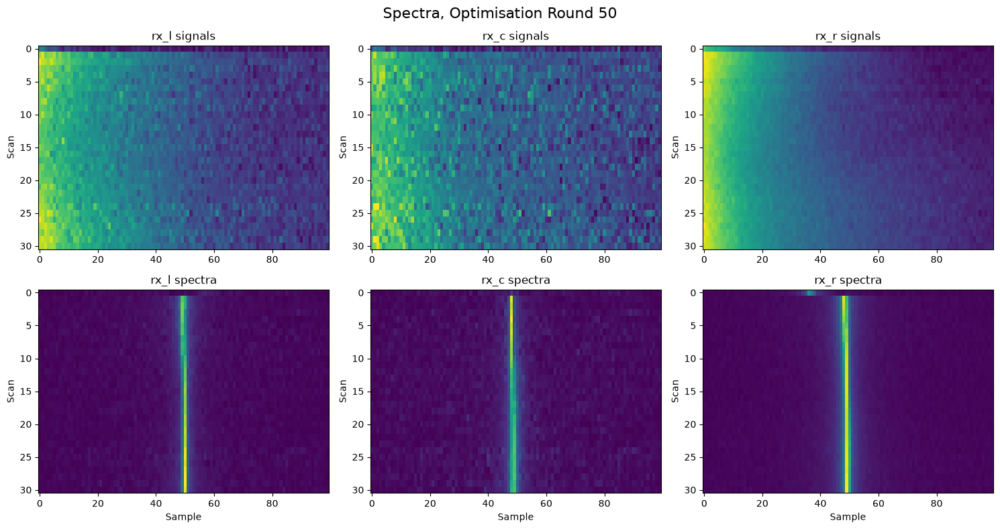

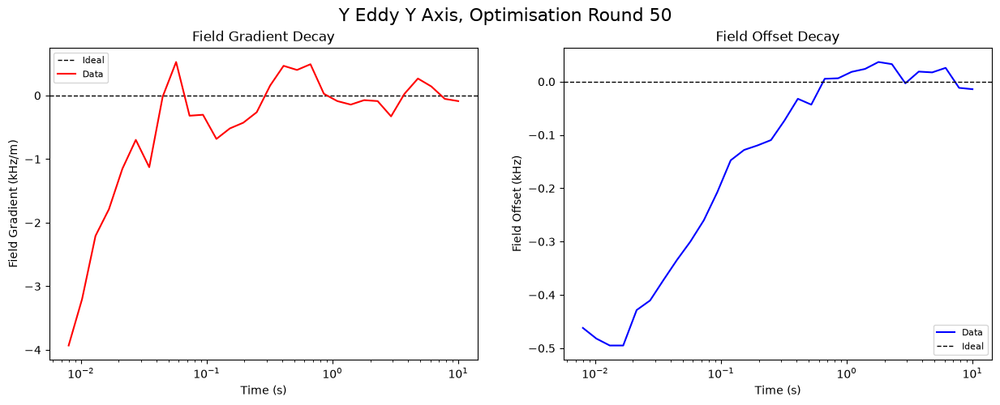

[I 2026-11-25 16:39:40,281] Trial 50 finished with value: 235.9212623054628 and parameters: {'Y_A1': -0.011123885641361337, 'Y_A2': -0.005918746537637744, 'Y_A3': 2.6504911389901416e-09, 'Y_A4': 3.0971014165646355e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.359e+02
Total cost = 2.359e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24760713500396123
B nanmax = 0.24760713500396123
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24747996531102062 !!!!!!!!!!!!!!!!


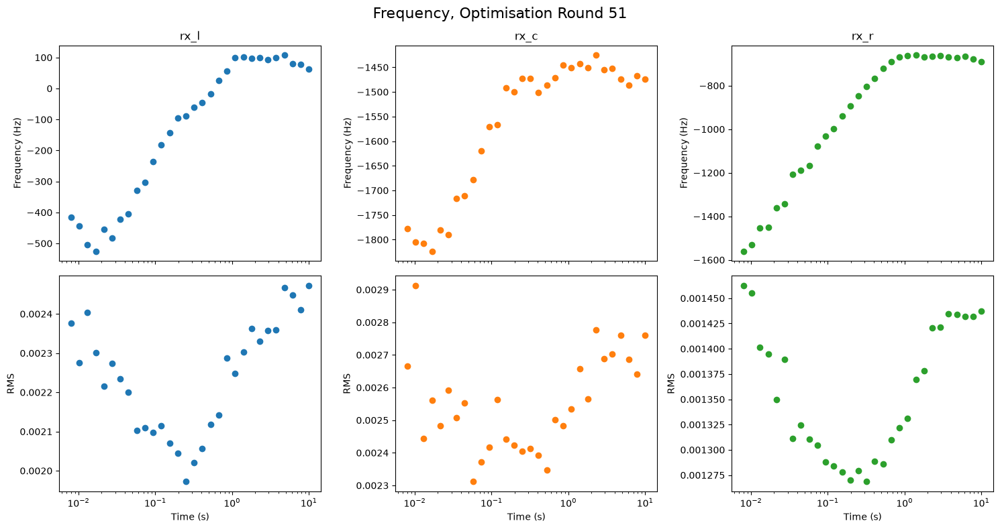

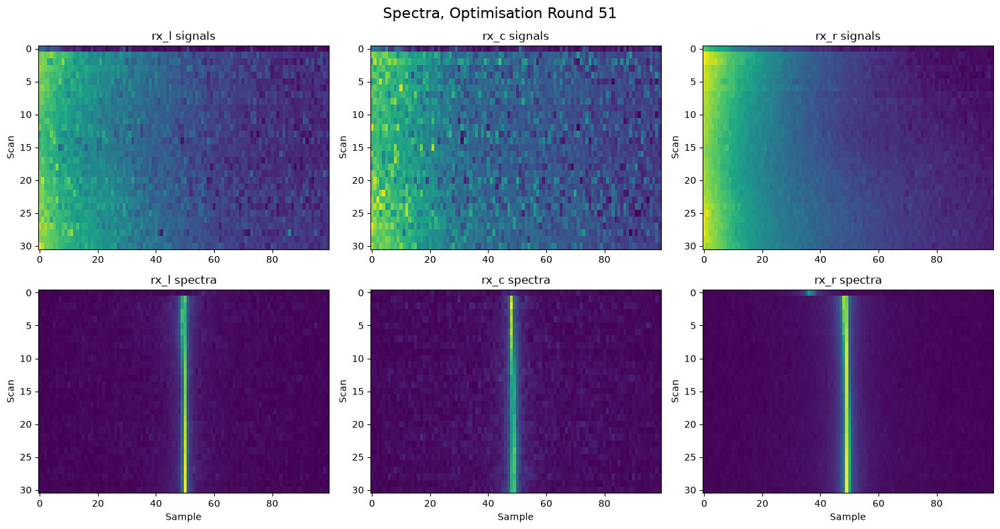

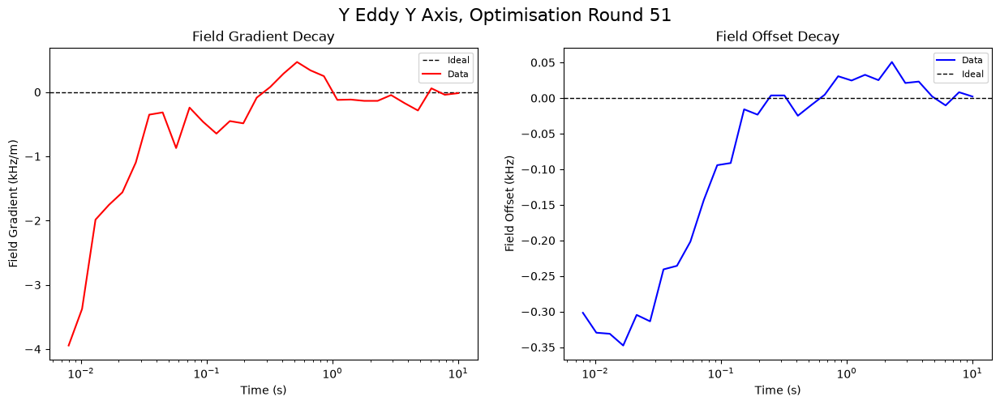

[I 2026-11-25 16:40:28,639] Trial 51 finished with value: 167.19298548056406 and parameters: {'Y_A1': -0.011298221861233058, 'Y_A2': -0.006261163425395127, 'Y_A3': -1.0008888012512237e-09, 'Y_A4': -5.626273187738262e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.672e+02
Total cost = 1.672e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2600488425642018
B nanmax = 0.2600488425642018
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2599152826283867 !!!!!!!!!!!!!!!!


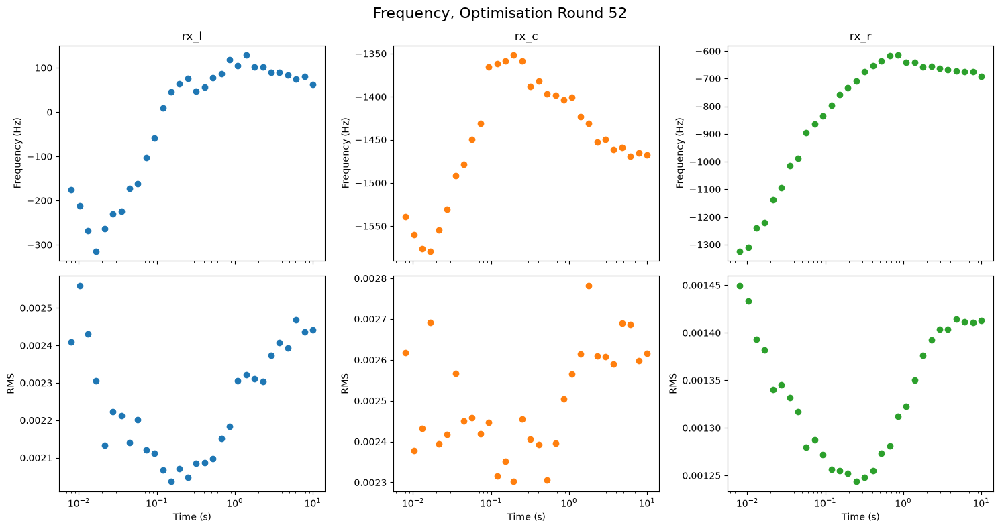

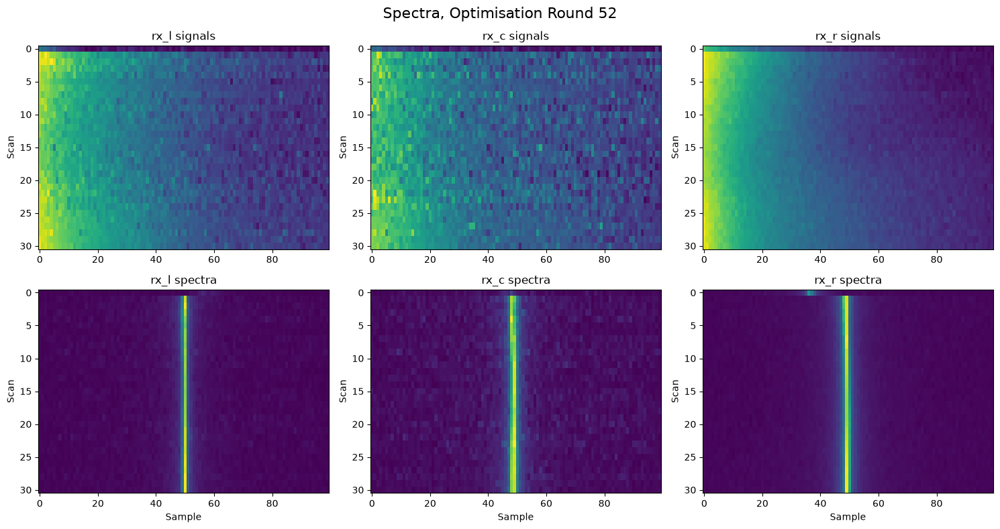

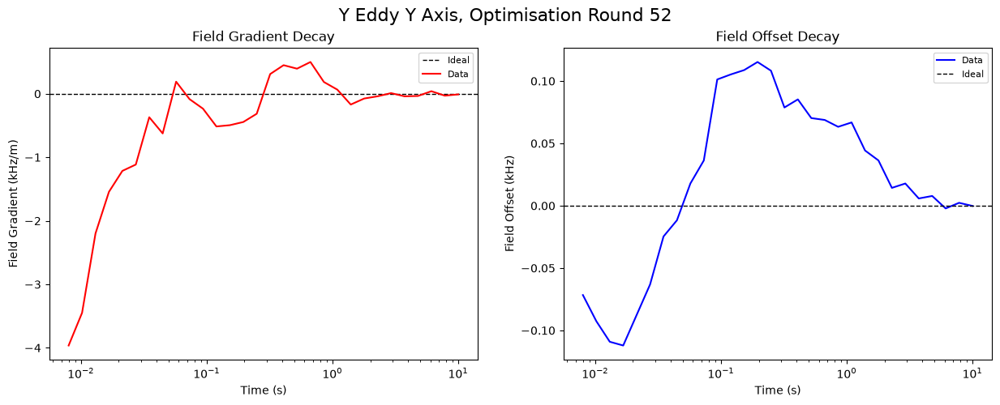

[I 2026-11-25 16:41:17,456] Trial 52 finished with value: 167.63113168060534 and parameters: {'Y_A1': -0.012222076421531032, 'Y_A2': -0.006218961779929812, 'Y_A3': -3.8776831130273055e-09, 'Y_A4': -1.6414281403388028e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.676e+02
Total cost = 1.676e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2658612770693171
B nanmax = 0.2658612770693171
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2657247315771157 !!!!!!!!!!!!!!!!


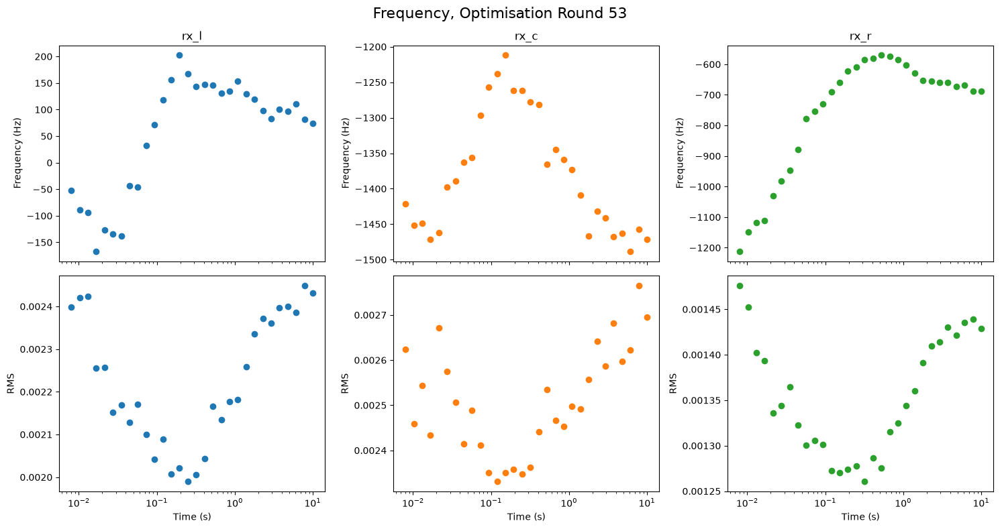

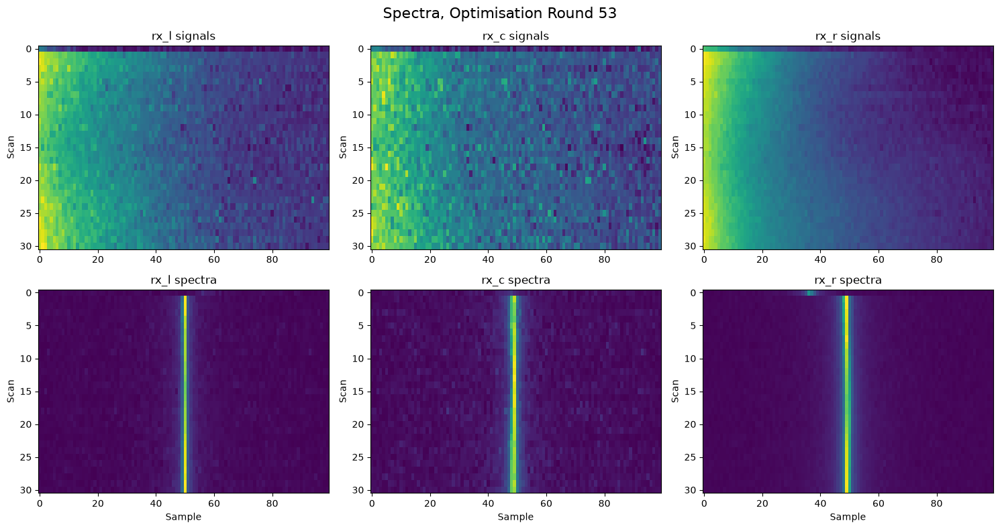

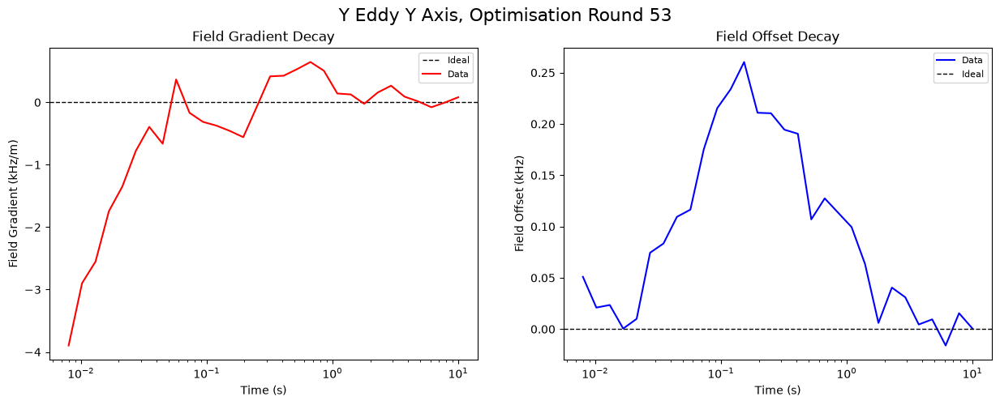

[I 2026-11-25 16:42:05,284] Trial 53 finished with value: 314.24862735173554 and parameters: {'Y_A1': -0.012947228008075767, 'Y_A2': -0.005905145085507742, 'Y_A3': -6.303174244003168e-11, 'Y_A4': -4.553884334116019e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.142e+02
Total cost = 3.142e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26174941279012204
B nanmax = 0.26174941279012204
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26161497960188124 !!!!!!!!!!!!!!!!


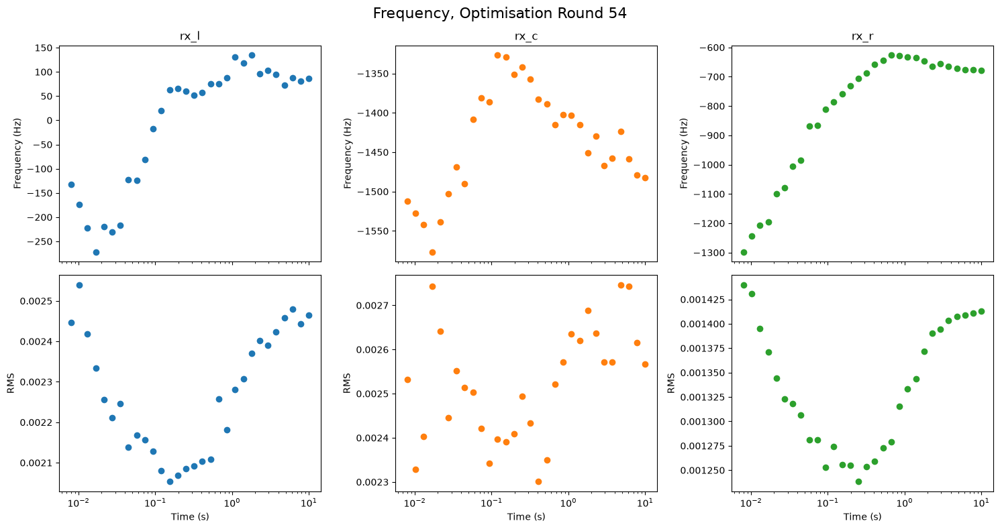

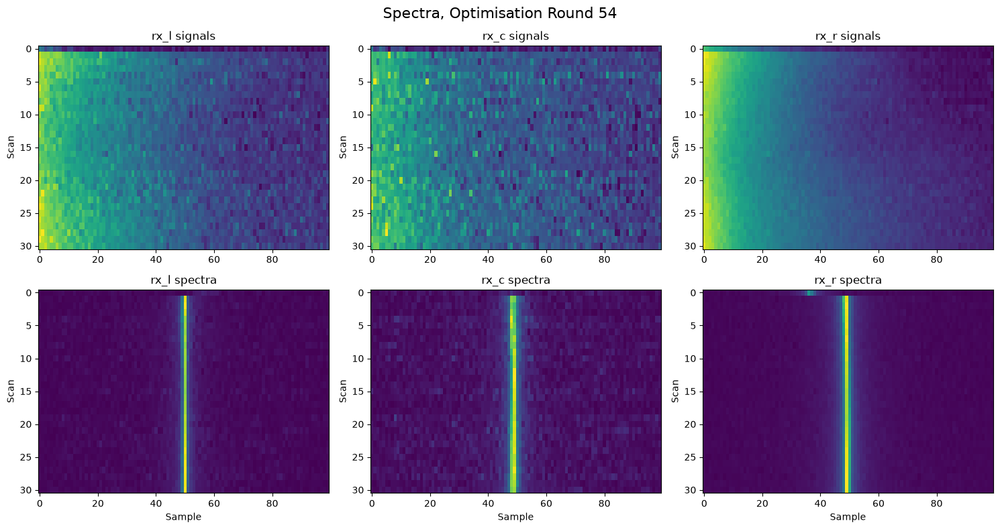

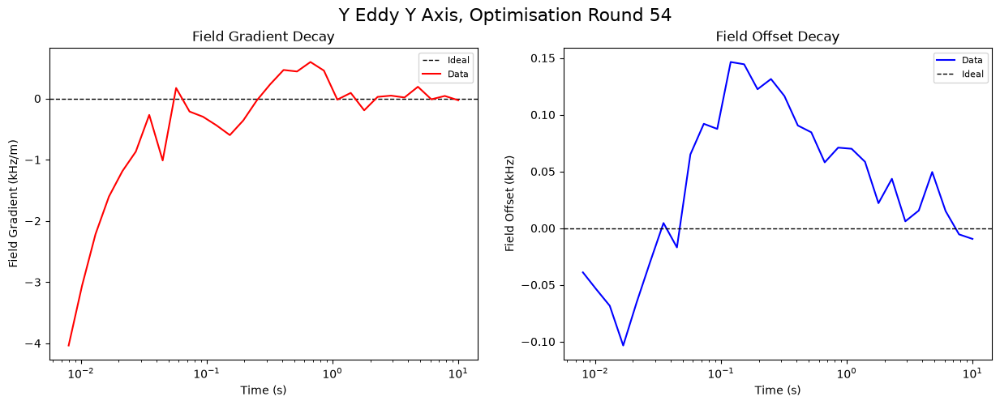

[I 2026-11-25 16:42:53,115] Trial 54 finished with value: 279.399304940093 and parameters: {'Y_A1': -0.012083083892867816, 'Y_A2': -0.006478958190949109, 'Y_A3': -1.2962573837841428e-09, 'Y_A4': -6.28557360229077e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.794e+02
Total cost = 2.794e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.27045240795270287
B nanmax = 0.27045240795270287
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.27031350462915615 !!!!!!!!!!!!!!!!


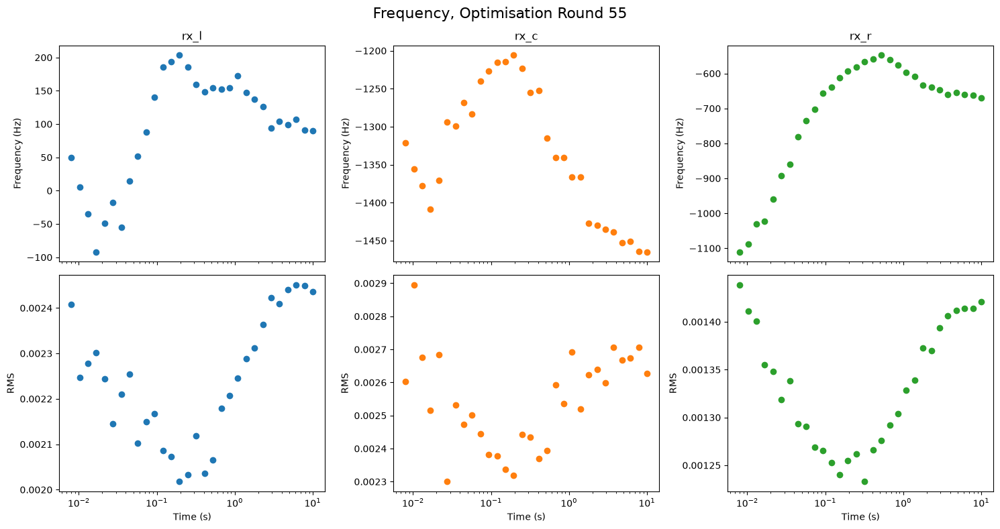

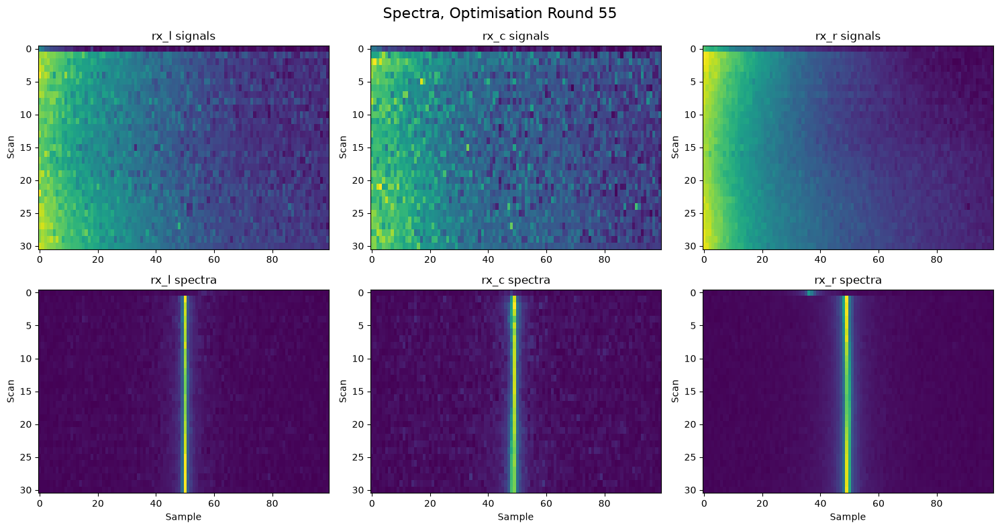

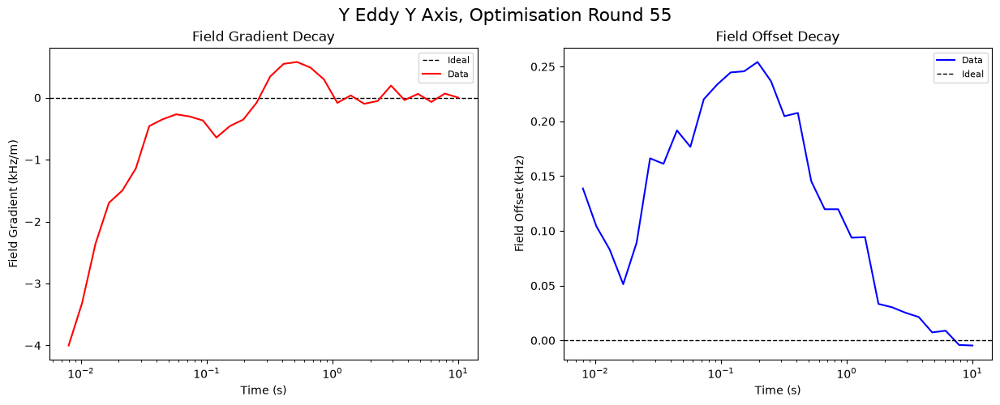

[I 2026-11-25 16:43:40,976] Trial 55 finished with value: 326.95626344533827 and parameters: {'Y_A1': -0.012943727021486268, 'Y_A2': -0.006234631124532143, 'Y_A3': -5.778264247687357e-09, 'Y_A4': -1.5944257777534034e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 3.270e+02
Total cost = 3.270e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2447005689733024
B nanmax = 0.2447005689733024
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24457489200759966 !!!!!!!!!!!!!!!!


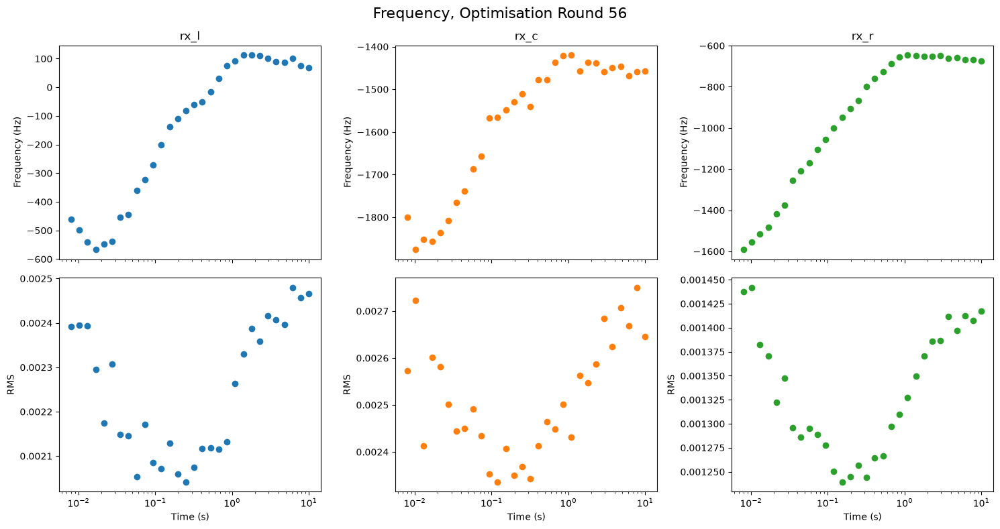

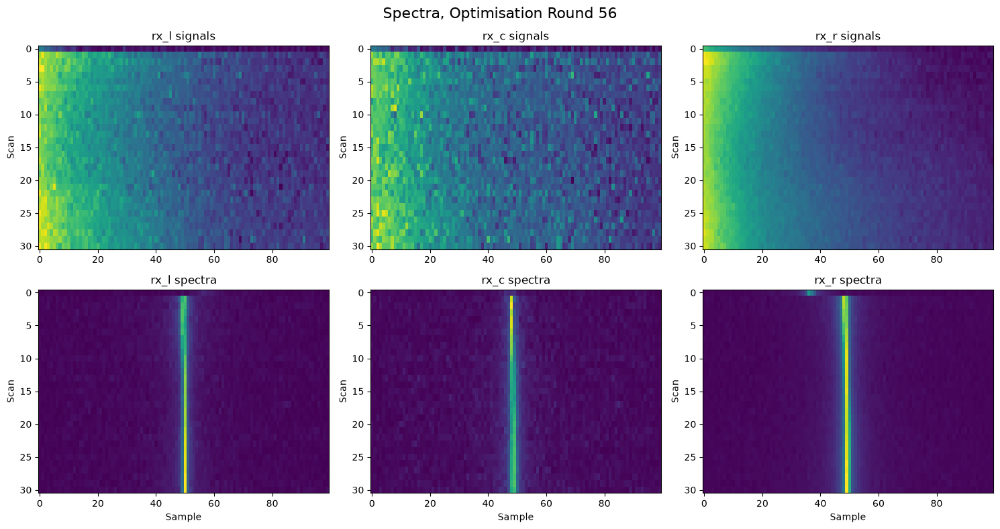

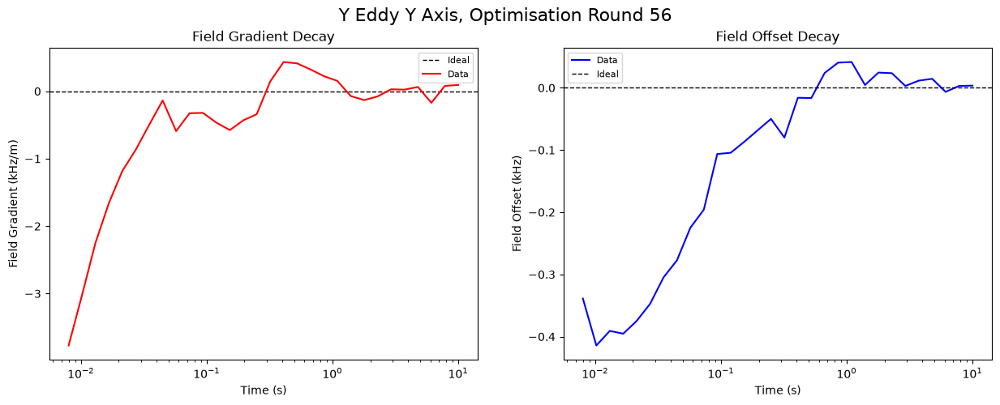

[I 2026-11-25 16:44:29,176] Trial 56 finished with value: 145.816789559578 and parameters: {'Y_A1': -0.011265008188085953, 'Y_A2': -0.006088067933262845, 'Y_A3': -4.158648492410396e-09, 'Y_A4': -3.3209282015270816e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.458e+02
Total cost = 1.458e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.238306689315934
B nanmax = 0.238306689315934
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23818429616456477 !!!!!!!!!!!!!!!!


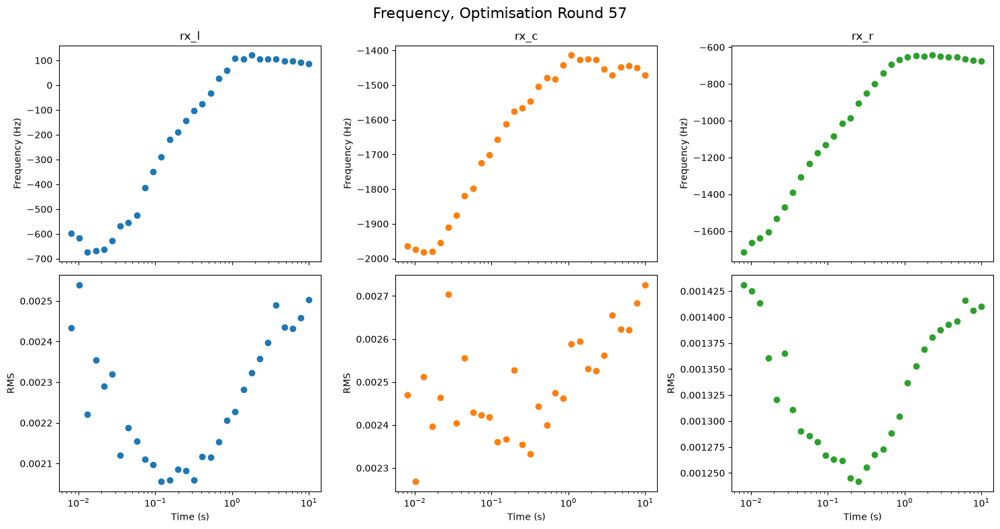

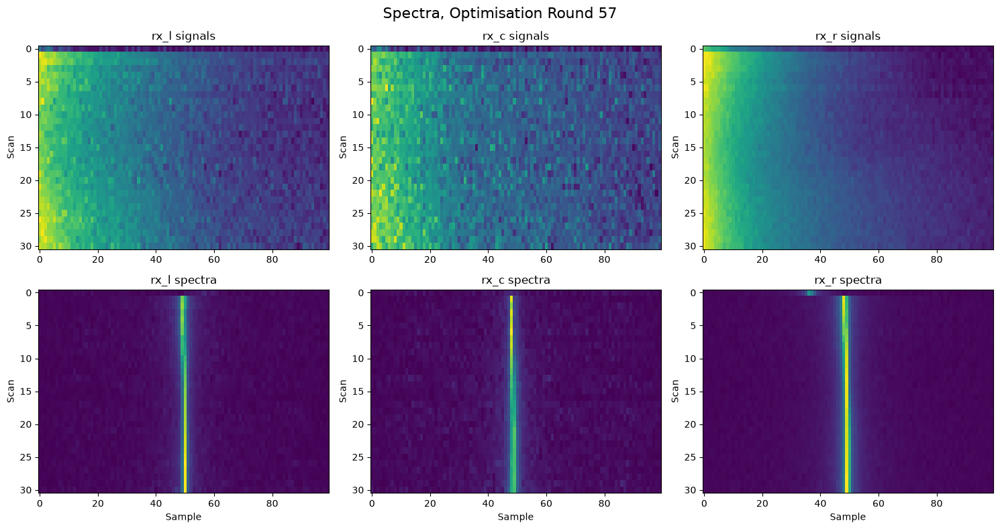

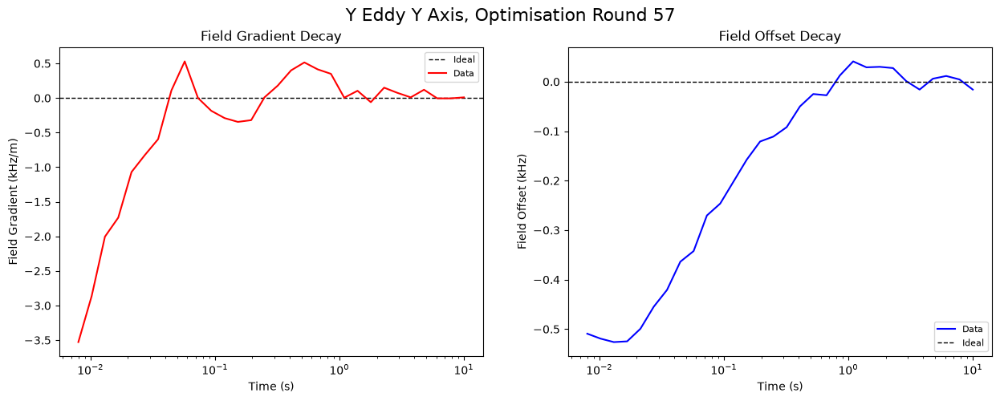

[I 2026-11-25 16:45:17,151] Trial 57 finished with value: 198.77568971802316 and parameters: {'Y_A1': -0.01104178853216935, 'Y_A2': -0.0058577288424428945, 'Y_A3': -2.5352817543589905e-09, 'Y_A4': -4.351335563846219e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.988e+02
Total cost = 1.988e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24422415991303634
B nanmax = 0.24422415991303634
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24409872768152388 !!!!!!!!!!!!!!!!


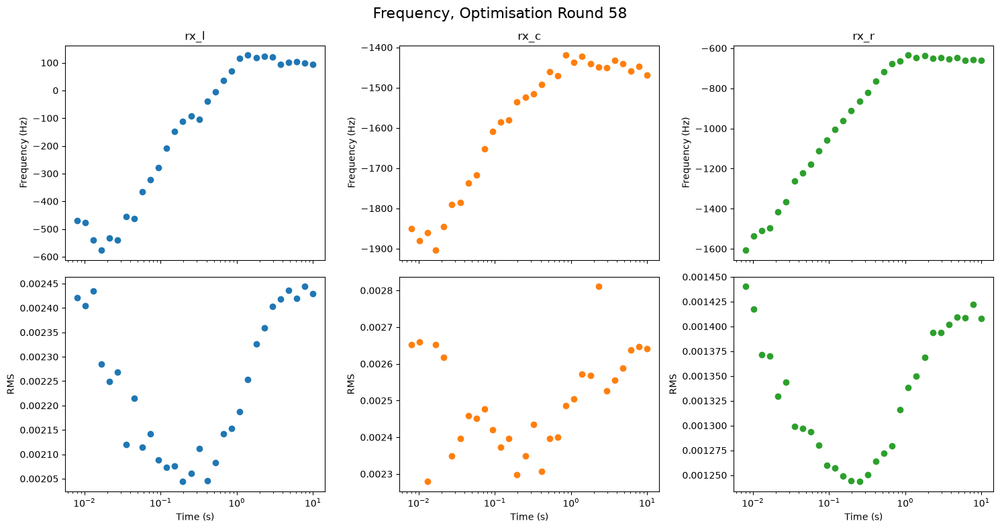

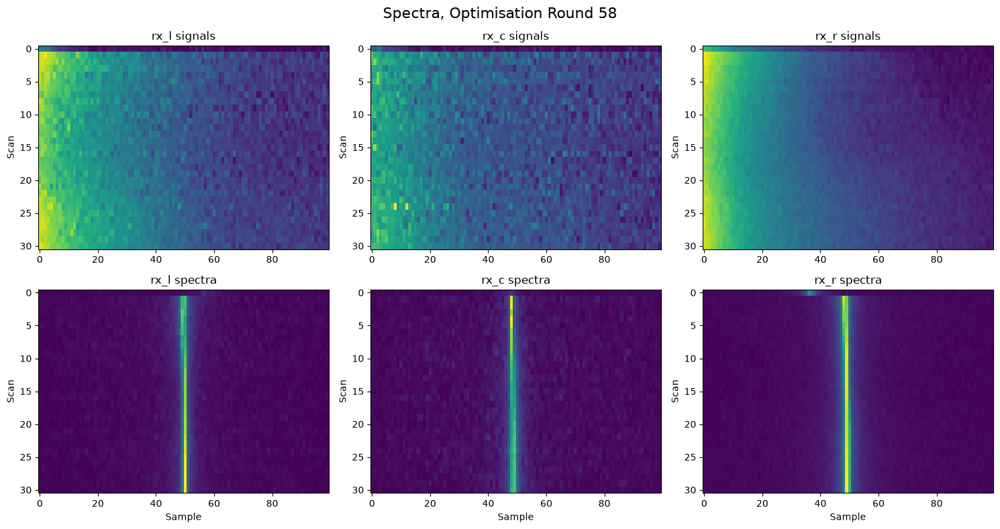

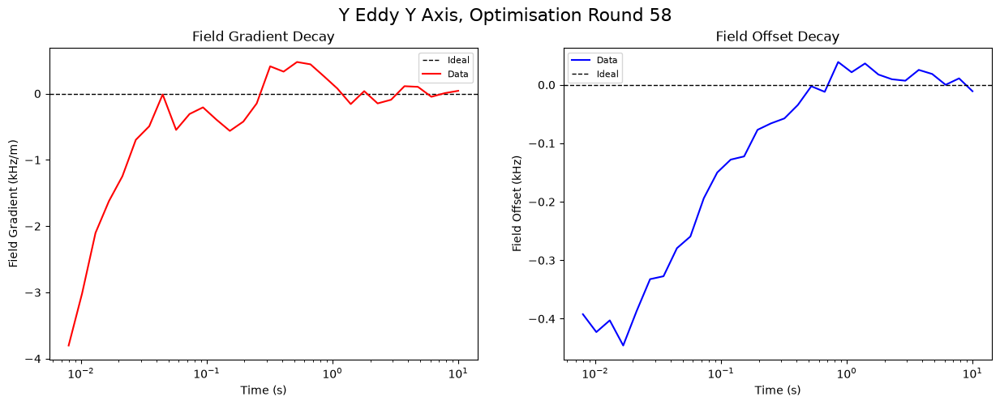

[I 2026-11-25 16:46:05,151] Trial 58 finished with value: 176.31298120852784 and parameters: {'Y_A1': -0.011167311255633059, 'Y_A2': -0.006152121975547255, 'Y_A3': -4.966155123584591e-09, 'Y_A4': -3.0648156716549753e-10}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.763e+02
Total cost = 1.763e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26595428531049303
B nanmax = 0.26595428531049303
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26581769268321537 !!!!!!!!!!!!!!!!


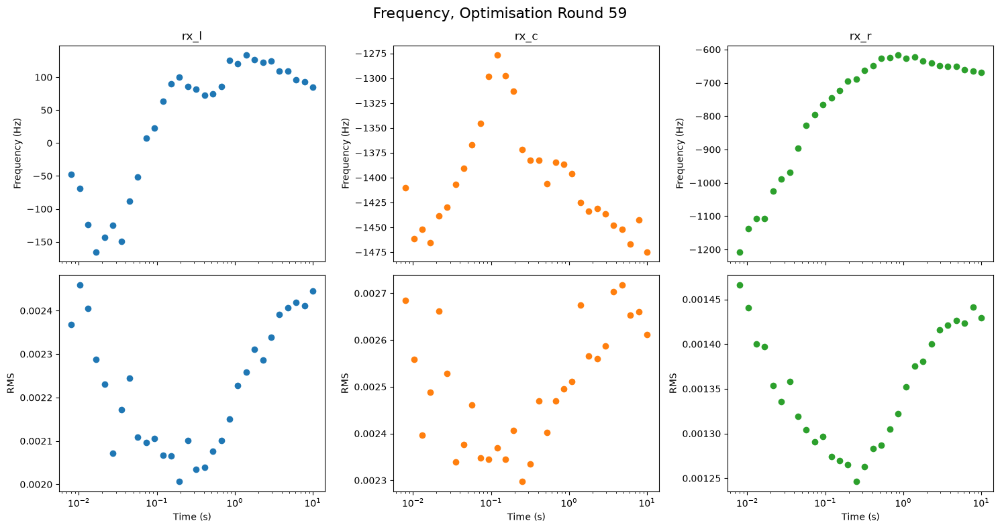

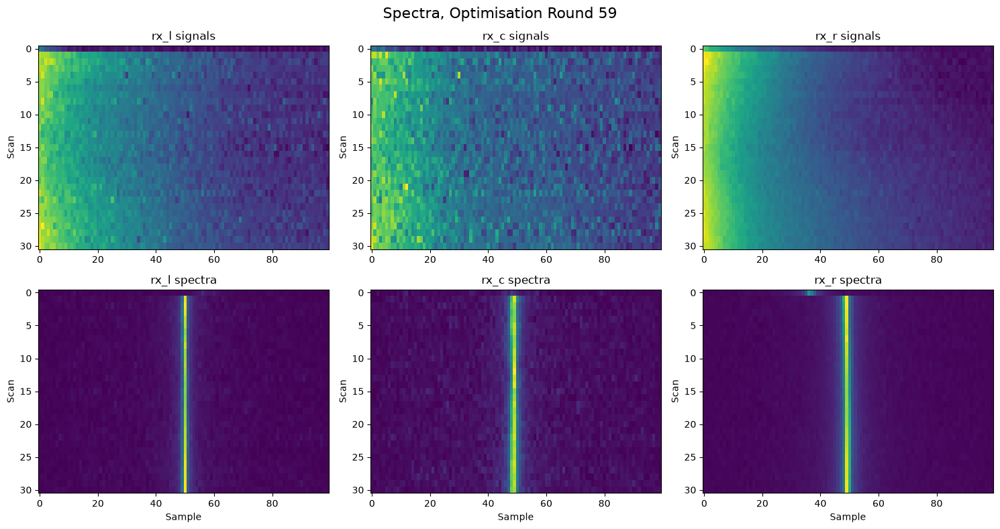

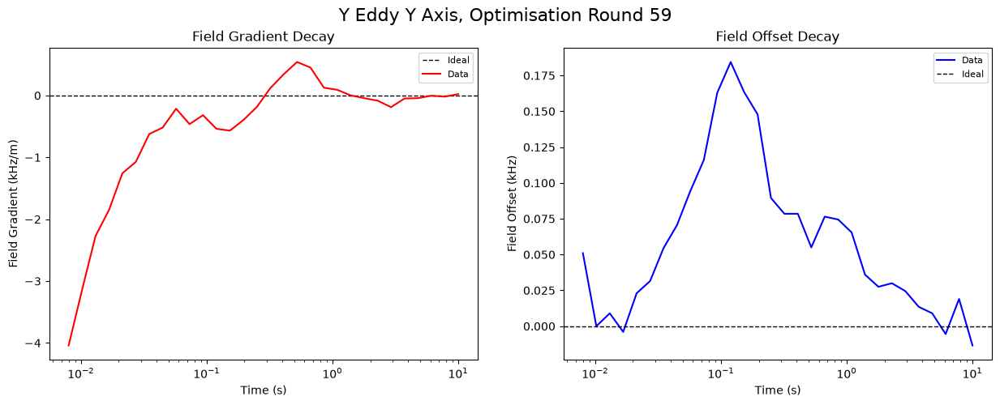

[I 2026-11-25 16:46:53,094] Trial 59 finished with value: 243.6984378079265 and parameters: {'Y_A1': -0.012044650441451699, 'Y_A2': -0.006816017095883899, 'Y_A3': -2.484811631008824e-09, 'Y_A4': -3.4678535255544282e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.437e+02
Total cost = 2.437e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25048222985964436
B nanmax = 0.25048222985964436
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2503535833050048 !!!!!!!!!!!!!!!!


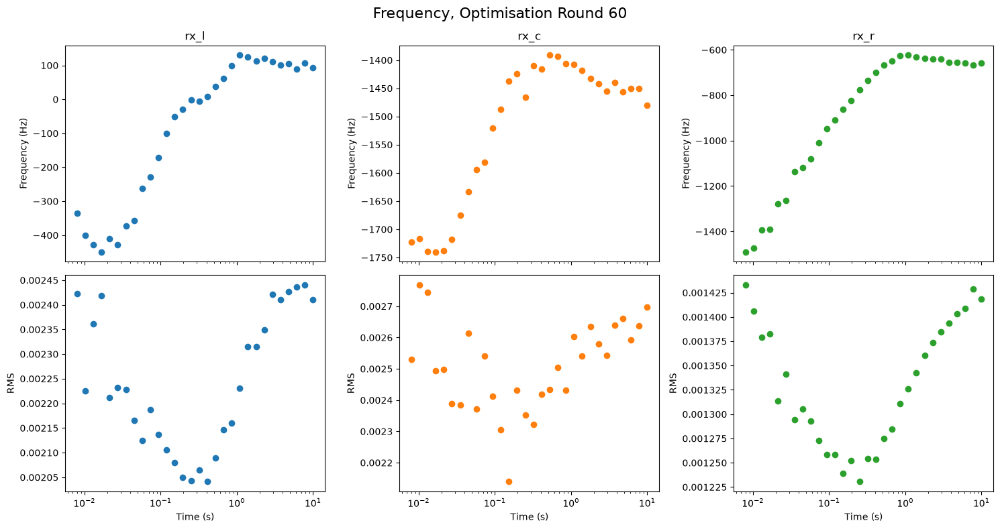

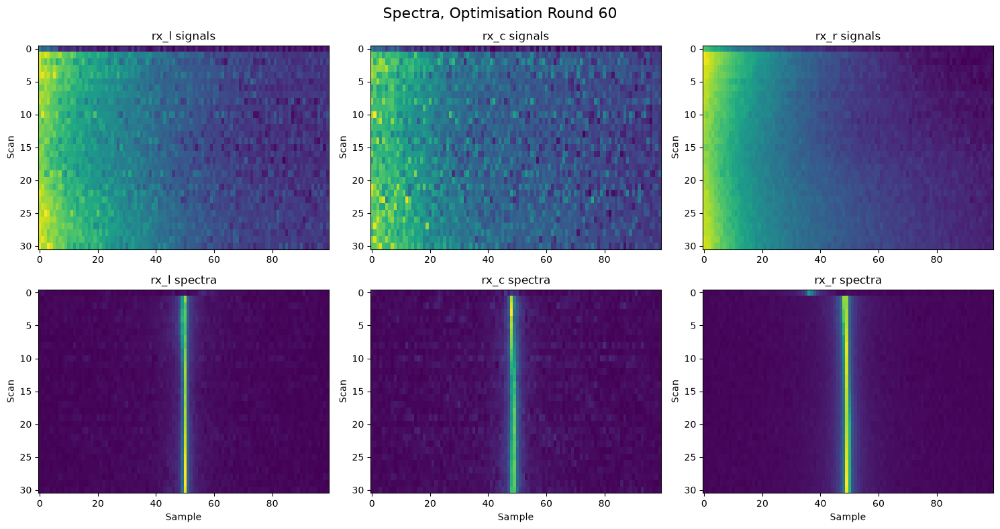

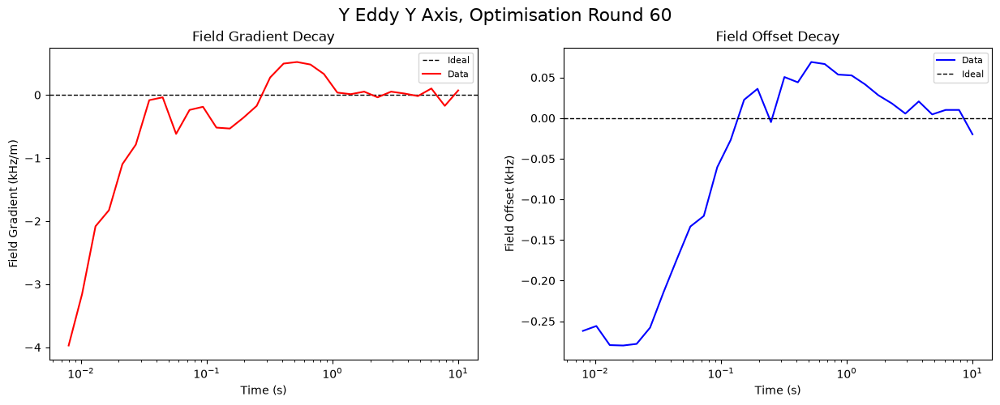

[I 2026-11-25 16:47:40,923] Trial 60 finished with value: 195.13714048300392 and parameters: {'Y_A1': -0.01175643835827717, 'Y_A2': -0.00600622547614646, 'Y_A3': -3.818500229915857e-09, 'Y_A4': -1.2627840635315965e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.951e+02
Total cost = 1.951e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26532278843961404
B nanmax = 0.26532278843961404
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.26518652006206395 !!!!!!!!!!!!!!!!


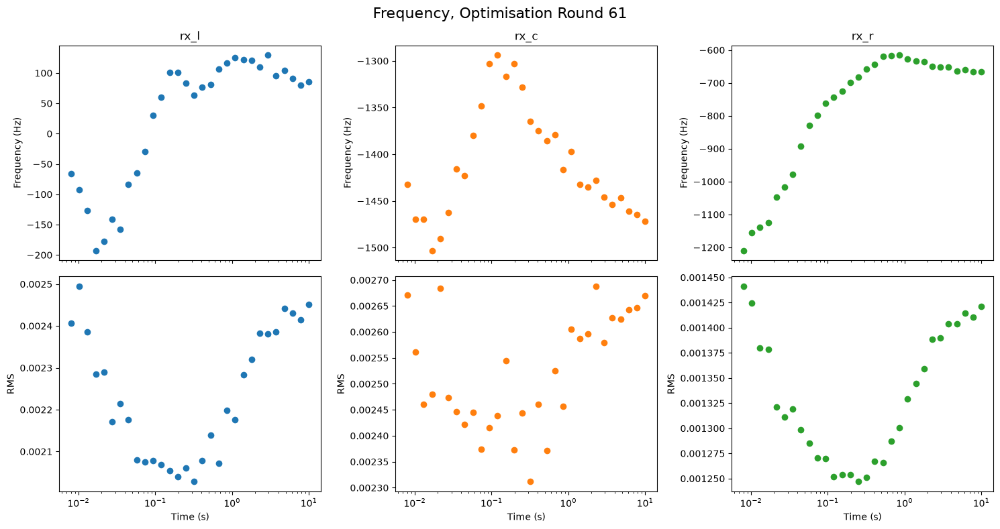

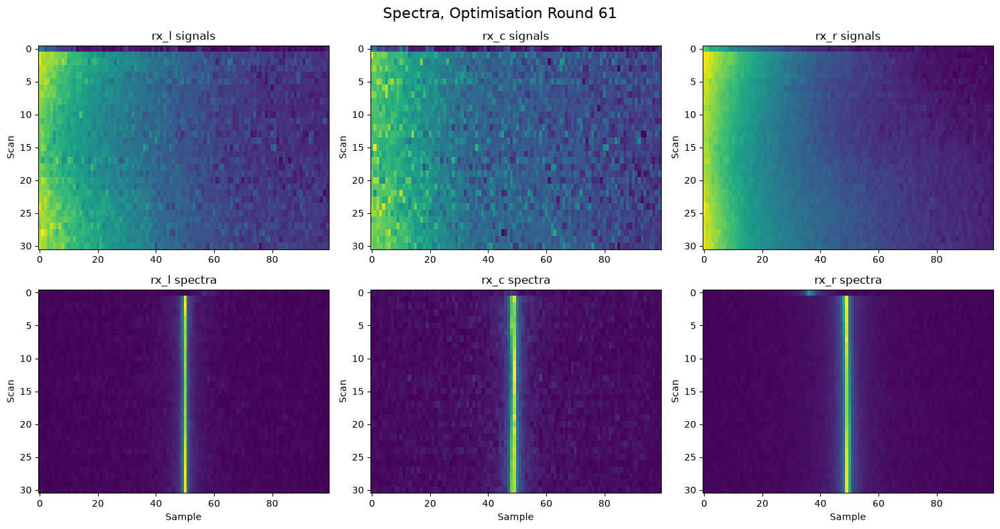

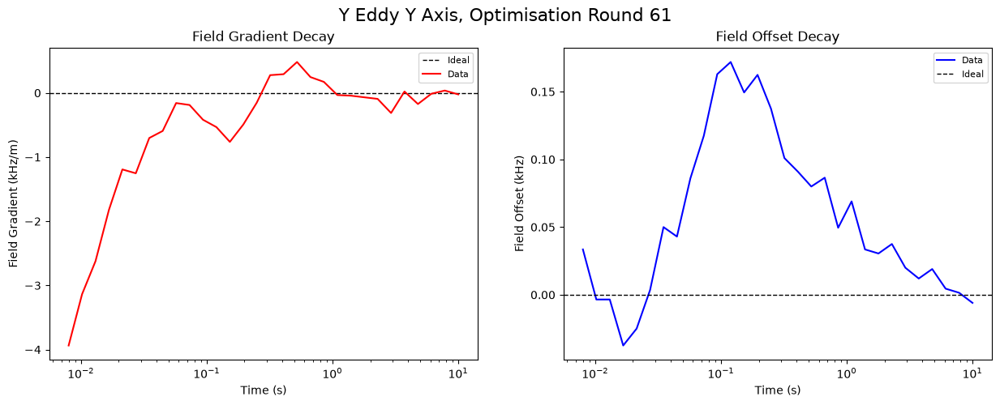

[I 2026-11-25 16:48:28,897] Trial 61 finished with value: 217.84961251418844 and parameters: {'Y_A1': -0.012135612255169601, 'Y_A2': -0.006680047488134521, 'Y_A3': -4.1283393718965615e-09, 'Y_A4': -4.716640596747747e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.178e+02
Total cost = 2.178e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24447291641154856
B nanmax = 0.24447291641154856
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2443473560743332 !!!!!!!!!!!!!!!!


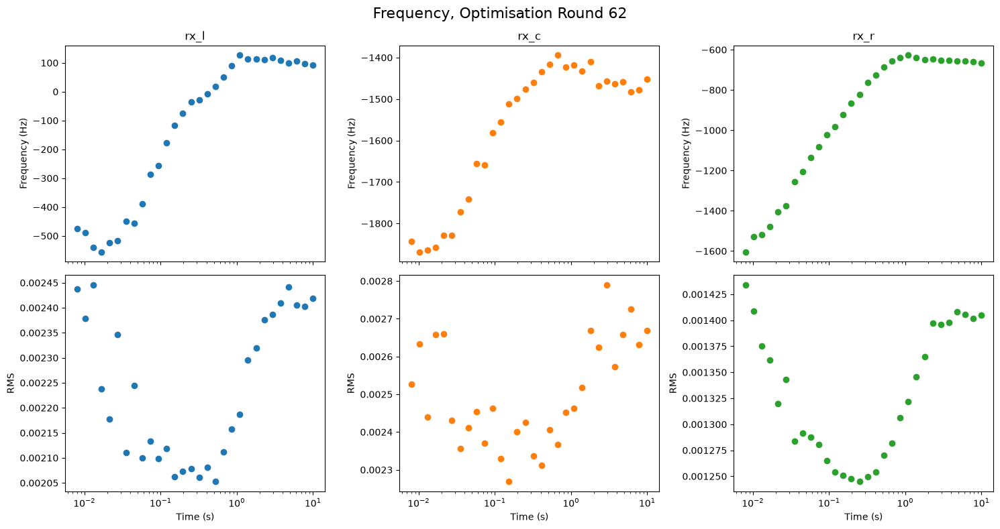

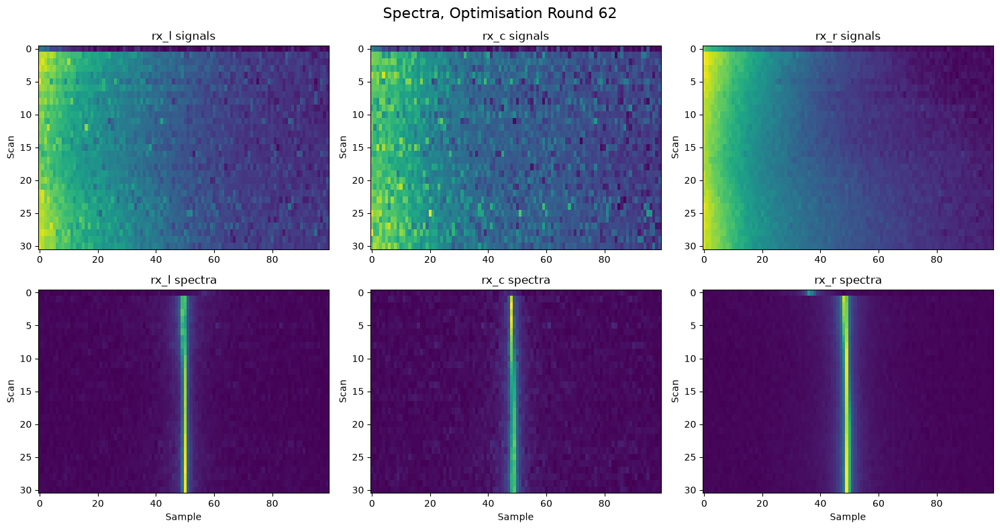

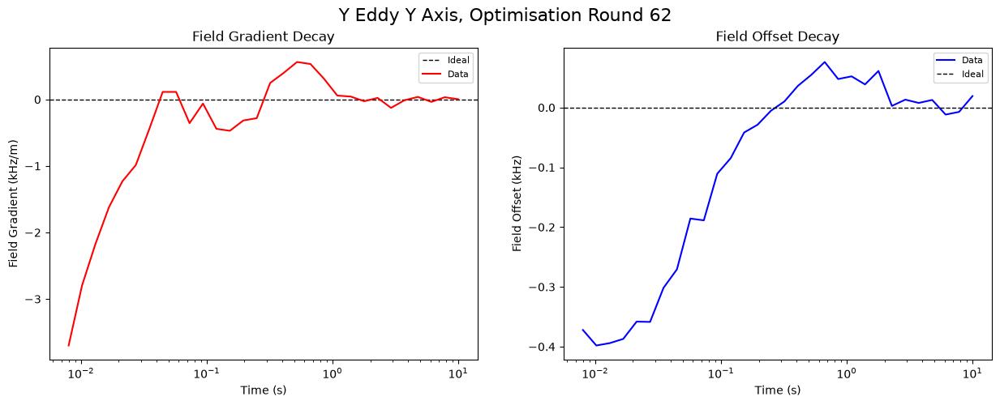

[I 2026-11-25 16:49:16,781] Trial 62 finished with value: 204.16675846344404 and parameters: {'Y_A1': -0.01167355364165934, 'Y_A2': -0.005662593460938145, 'Y_A3': -4.921392612463109e-09, 'Y_A4': -5.391763163605417e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 2.042e+02
Total cost = 2.042e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24882851211720394
B nanmax = 0.24882851211720394
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24870071521278136 !!!!!!!!!!!!!!!!


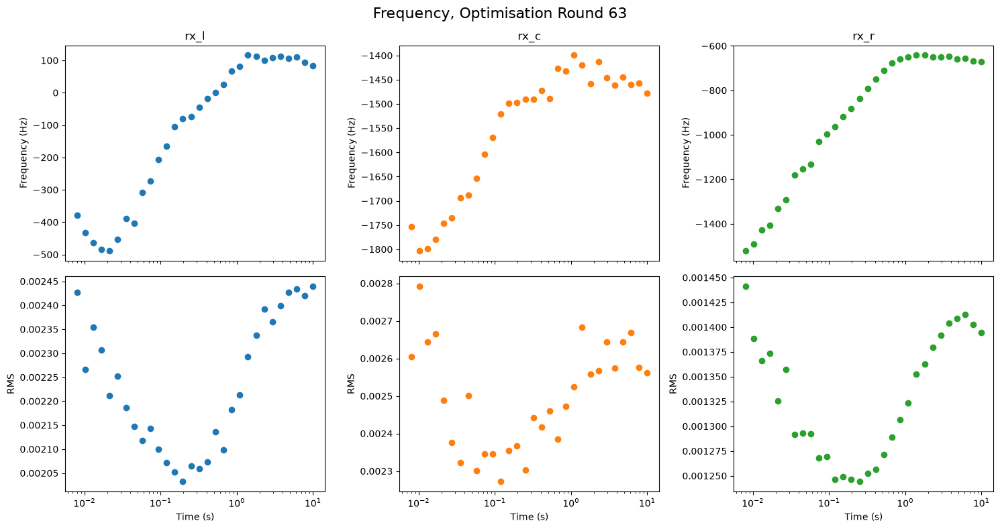

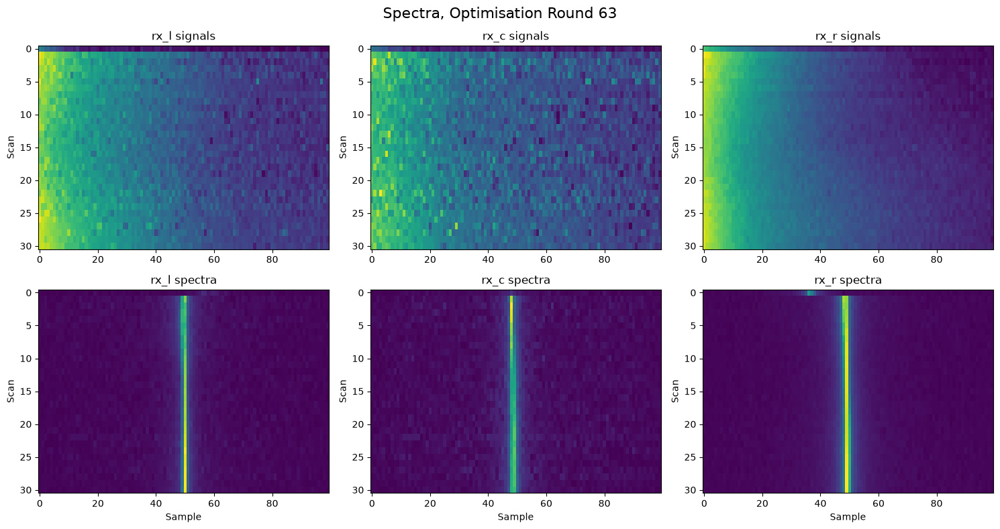

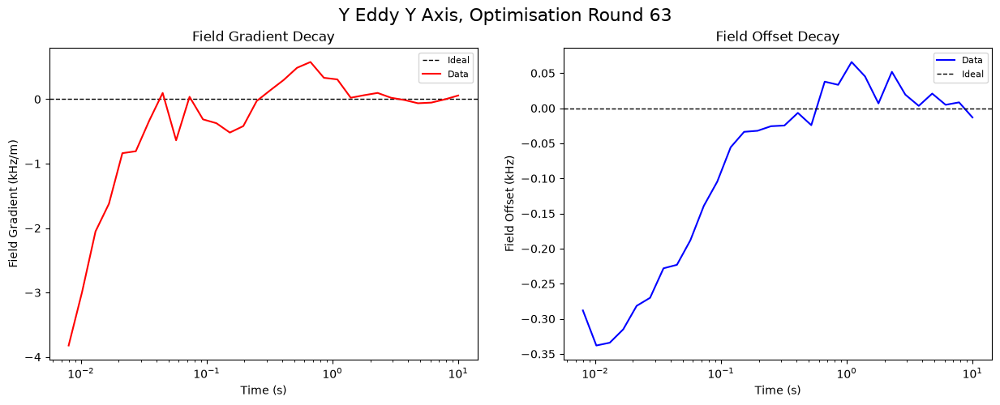

[I 2026-11-25 16:50:04,784] Trial 63 finished with value: 190.01447141685546 and parameters: {'Y_A1': -0.011237657816623874, 'Y_A2': -0.006408560874454441, 'Y_A3': -5.107793102456063e-09, 'Y_A4': -3.2116139939493205e-09}. Best is trial 19 with value: 137.1436633610362.


rx_c: 1.900e+02
Total cost = 1.900e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24933762566776127
B nanmax = 0.24933762566776127
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24920956718962092 !!!!!!!!!!!!!!!!


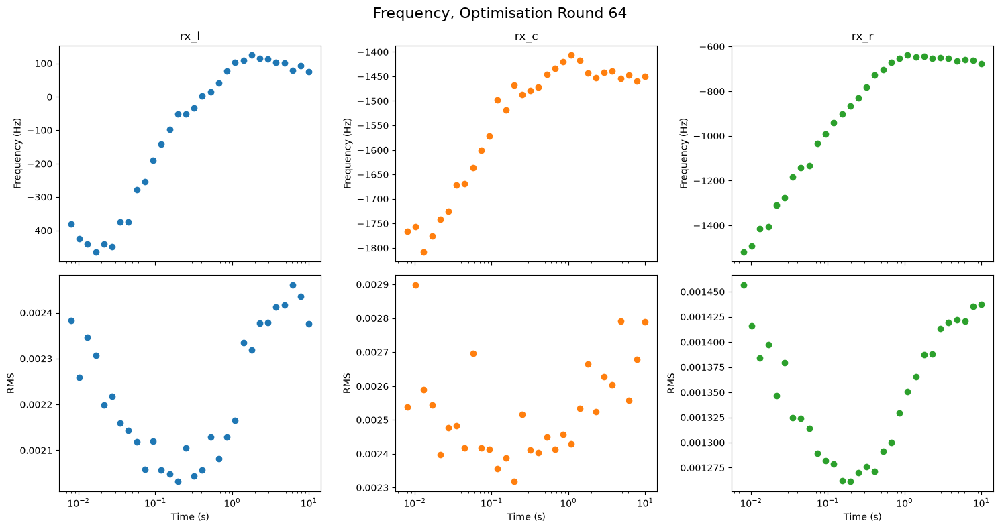

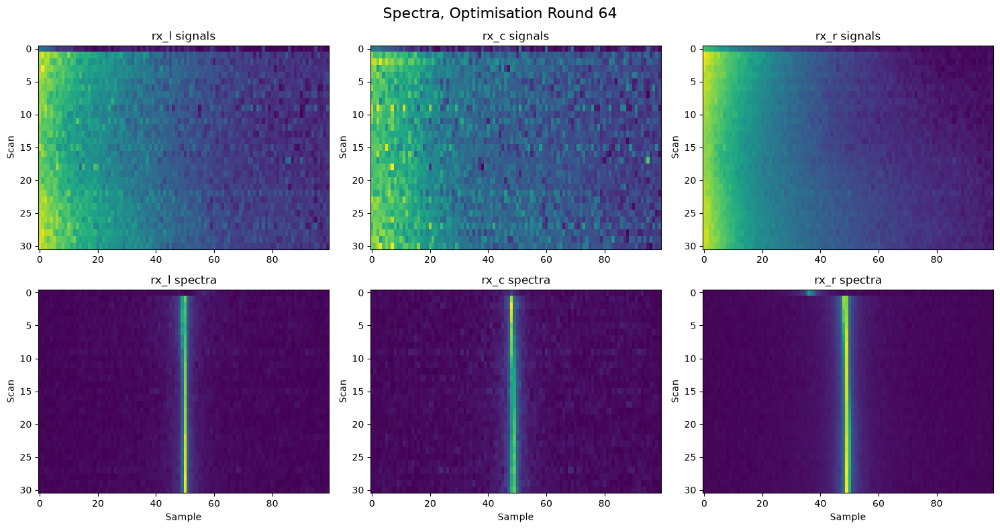

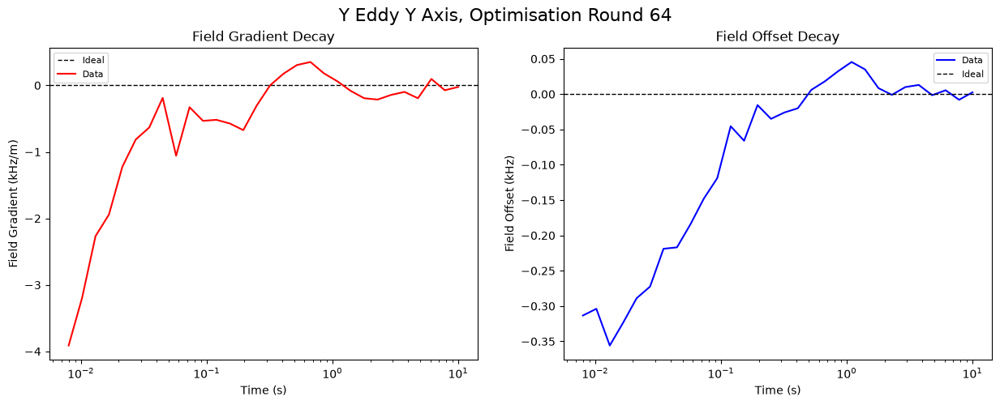

[I 2026-11-25 16:50:52,920] Trial 64 finished with value: 117.49743056208108 and parameters: {'Y_A1': -0.011397943785723855, 'Y_A2': -0.0062841226320714755, 'Y_A3': -3.4141359184485785e-10, 'Y_A4': -8.327135441131884e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.175e+02
Total cost = 1.175e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2377684604761064
B nanmax = 0.2377684604761064
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2376463440538936 !!!!!!!!!!!!!!!!


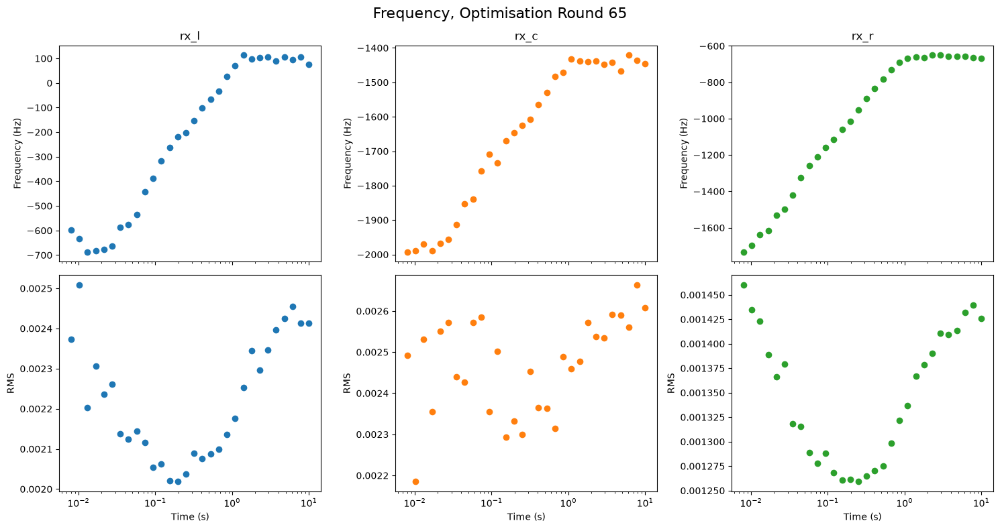

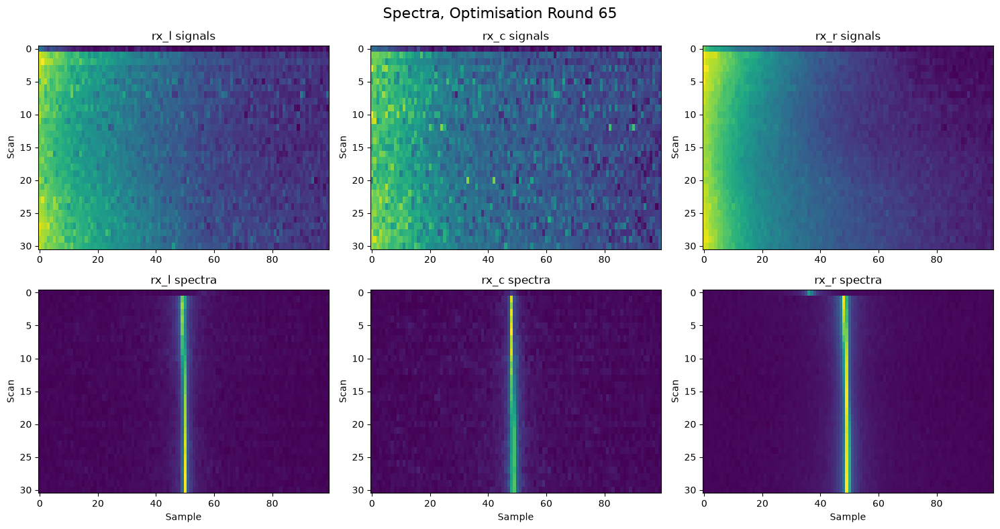

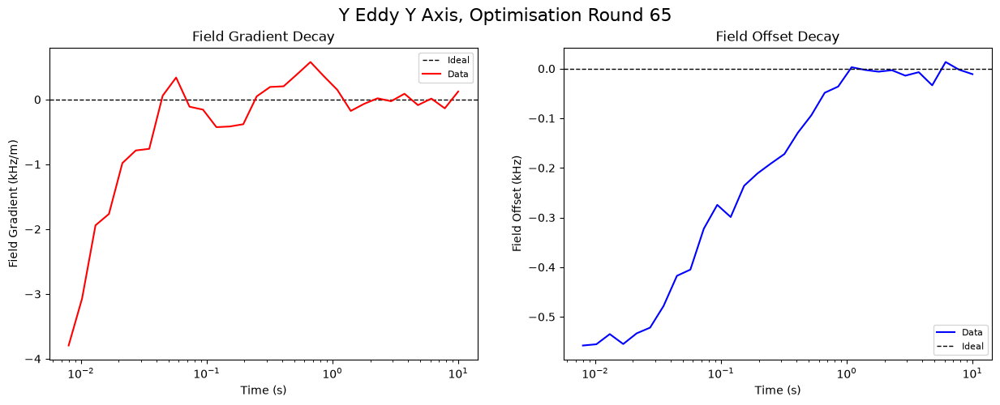

[I 2026-11-25 16:51:41,410] Trial 65 finished with value: 233.74340242104154 and parameters: {'Y_A1': -0.010591032423142932, 'Y_A2': -0.006271114090775942, 'Y_A3': -6.201731820288981e-10, 'Y_A4': -6.3255816721897714e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.337e+02
Total cost = 2.337e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26227624389708376
B nanmax = 0.26227624389708376
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2621415401088599 !!!!!!!!!!!!!!!!


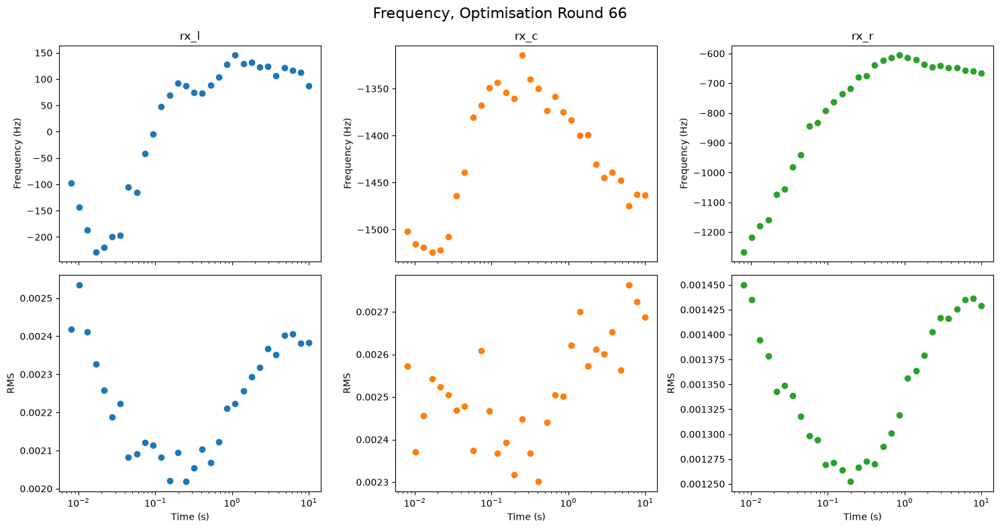

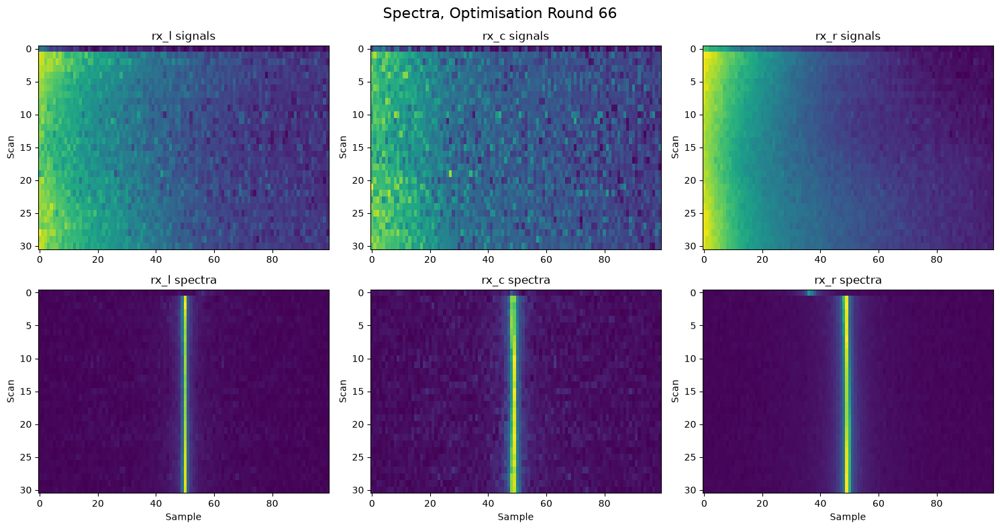

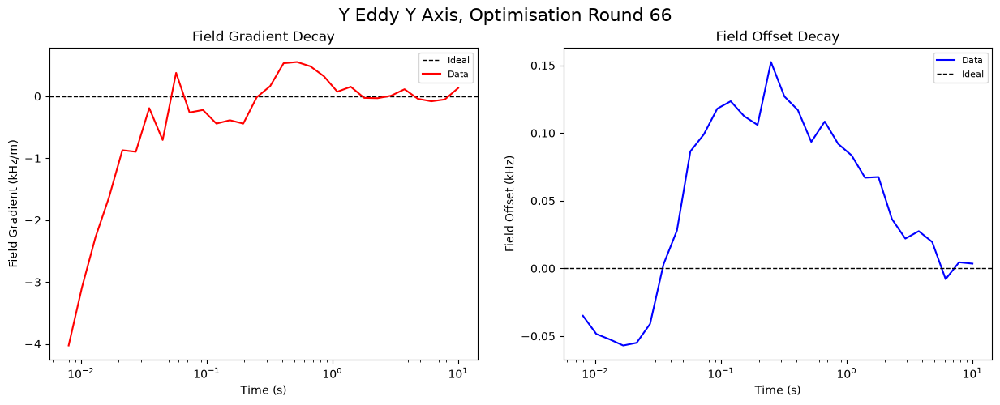

[I 2026-11-25 16:52:29,663] Trial 66 finished with value: 287.4254051064672 and parameters: {'Y_A1': -0.012139132505419785, 'Y_A2': -0.006460210538859136, 'Y_A3': -2.8234261238207164e-10, 'Y_A4': -8.234652404606821e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.874e+02
Total cost = 2.874e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24662156627705487
B nanmax = 0.24662156627705487
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2464949028425798 !!!!!!!!!!!!!!!!


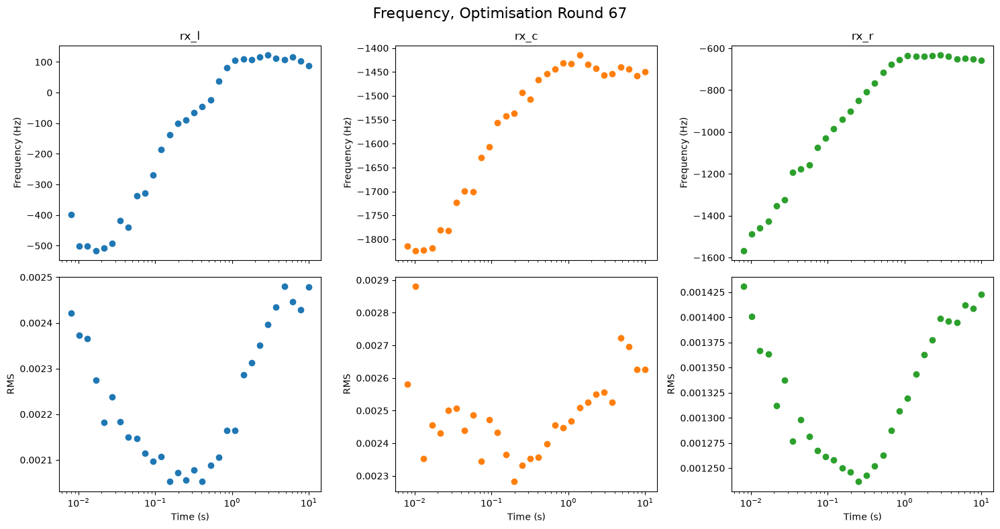

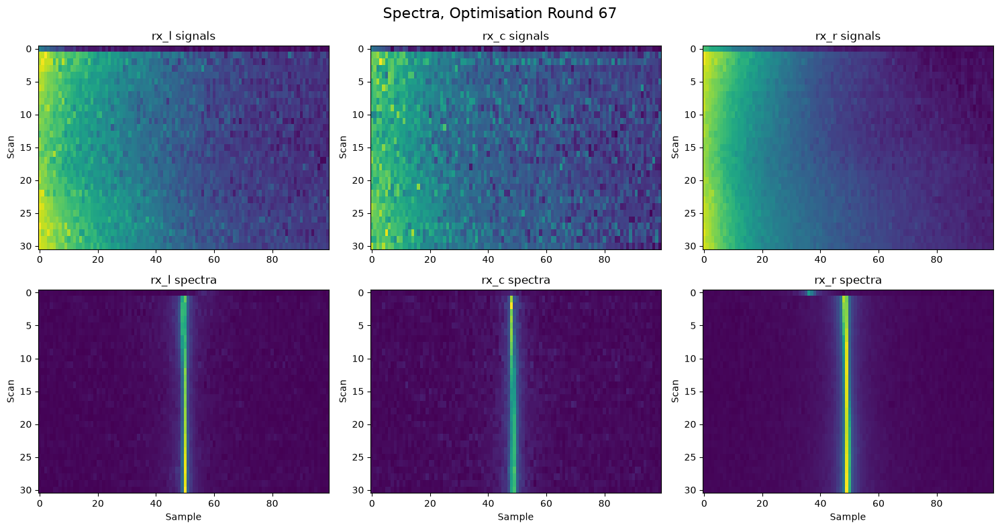

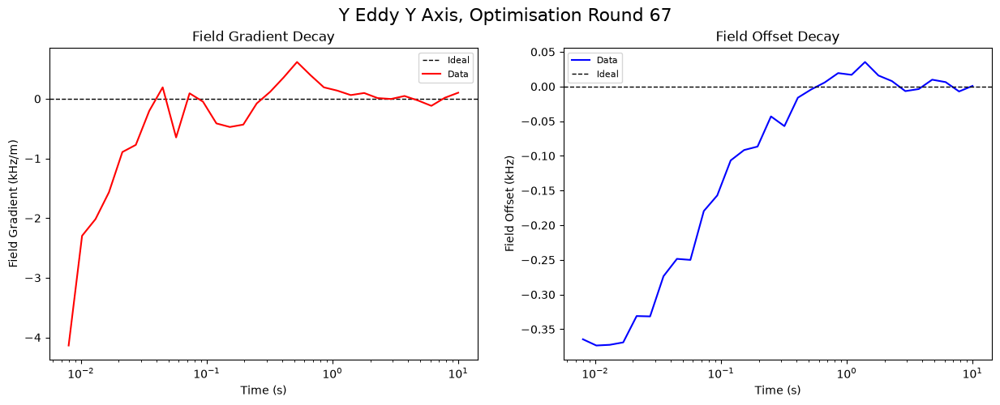

[I 2026-11-25 16:53:17,632] Trial 67 finished with value: 121.71436909149212 and parameters: {'Y_A1': -0.01114492773466483, 'Y_A2': -0.006344767559575564, 'Y_A3': 1.7254796101804478e-09, 'Y_A4': -8.535477257947898e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.217e+02
Total cost = 1.217e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25062382251300974
B nanmax = 0.25062382251300974
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2504951032651646 !!!!!!!!!!!!!!!!


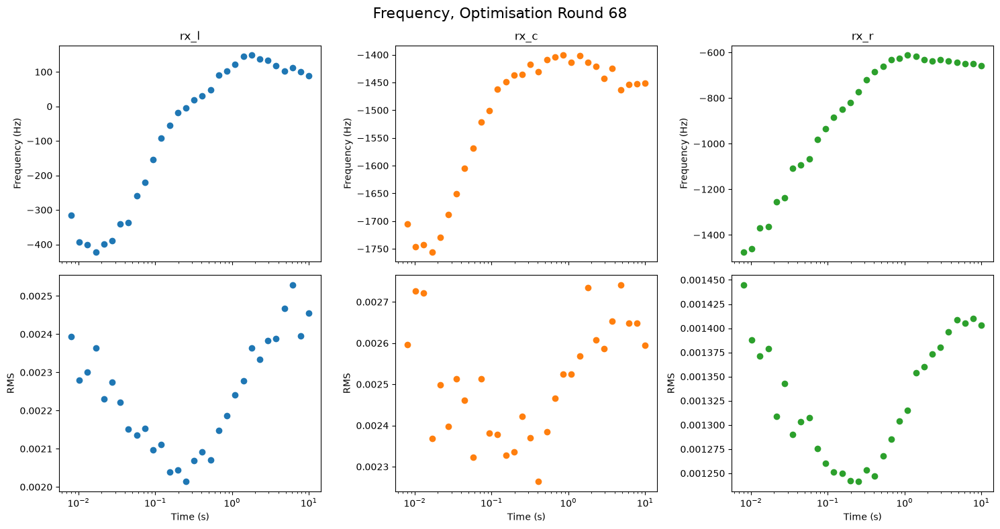

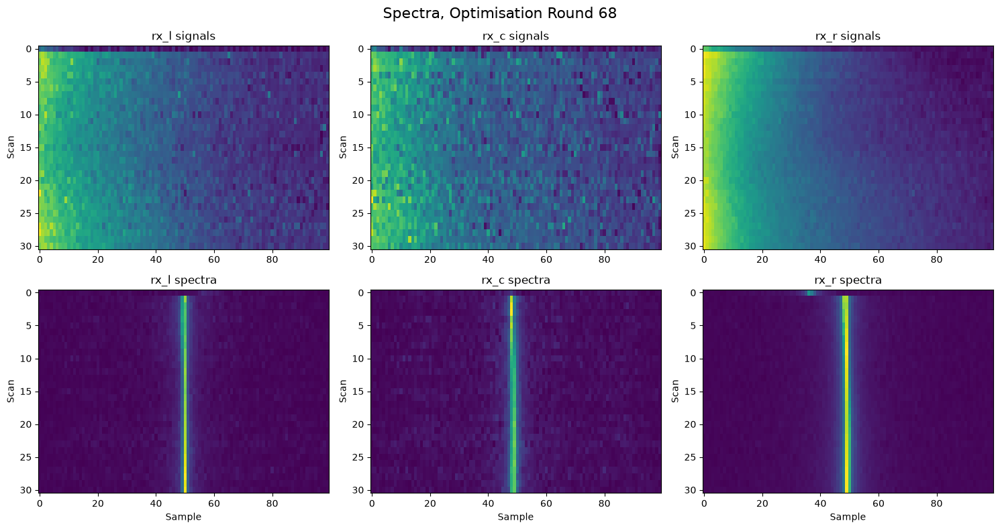

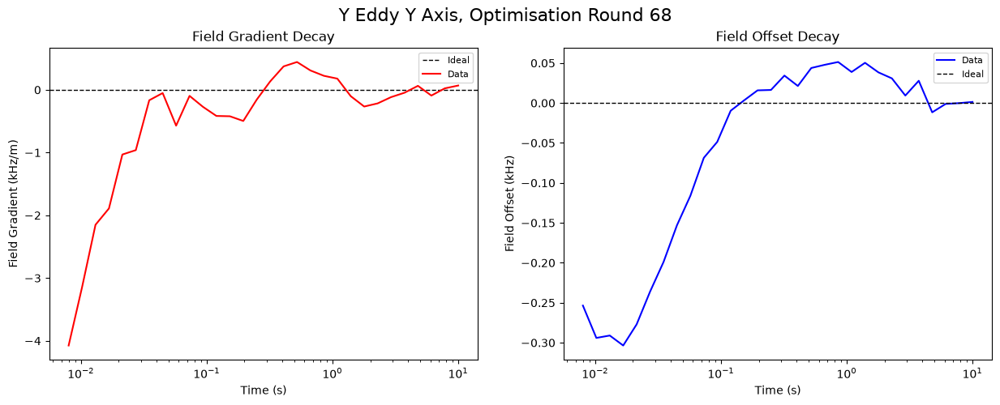

[I 2026-11-25 16:54:05,646] Trial 68 finished with value: 157.9502723730986 and parameters: {'Y_A1': -0.01172278919193292, 'Y_A2': -0.006049991004853417, 'Y_A3': -1.1896824411666246e-09, 'Y_A4': -7.201594265893415e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.580e+02
Total cost = 1.580e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2563515395909555
B nanmax = 0.2563515395909555
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2562198787978005 !!!!!!!!!!!!!!!!


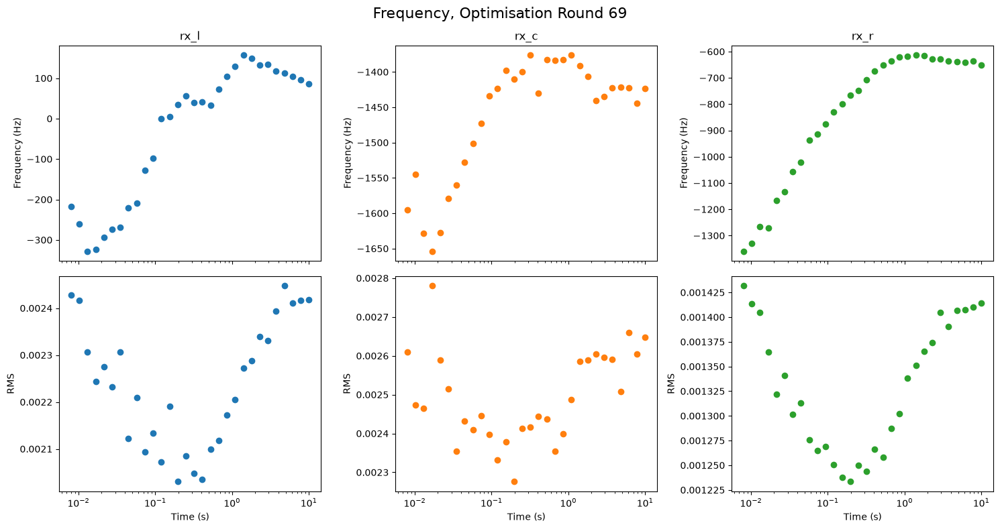

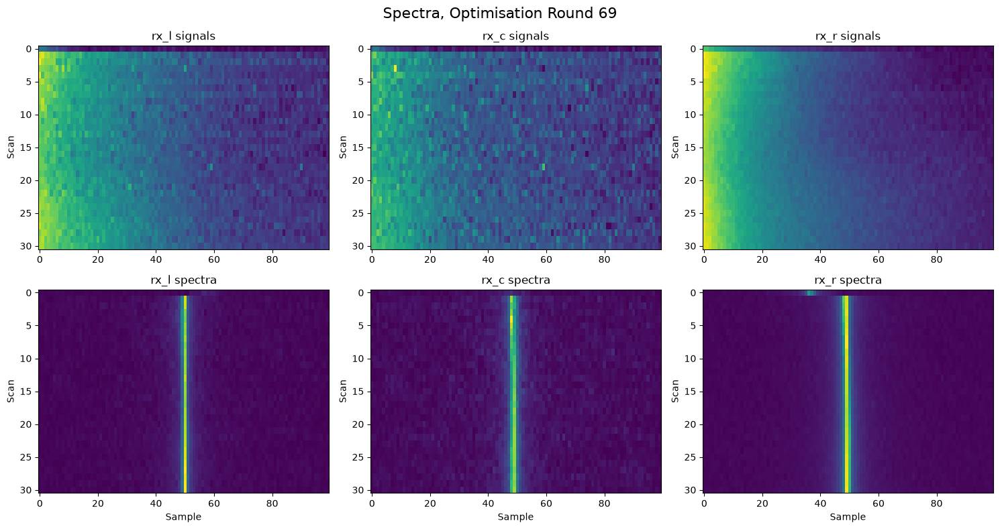

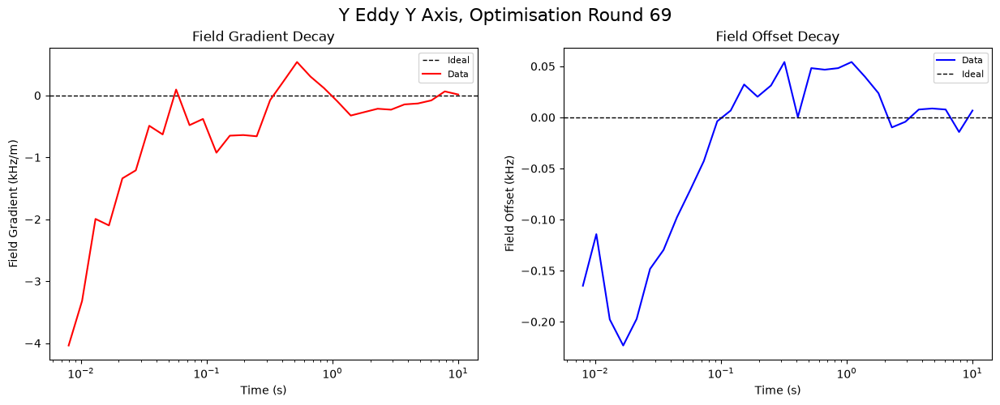

[I 2026-11-25 16:54:53,539] Trial 69 finished with value: 152.91793624699673 and parameters: {'Y_A1': -0.011727352251699867, 'Y_A2': -0.0064520975423351945, 'Y_A3': 1.368055922544019e-09, 'Y_A4': -7.36078571037955e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.529e+02
Total cost = 1.529e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23636009318824988
B nanmax = 0.23636009318824988
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23623869991505933 !!!!!!!!!!!!!!!!


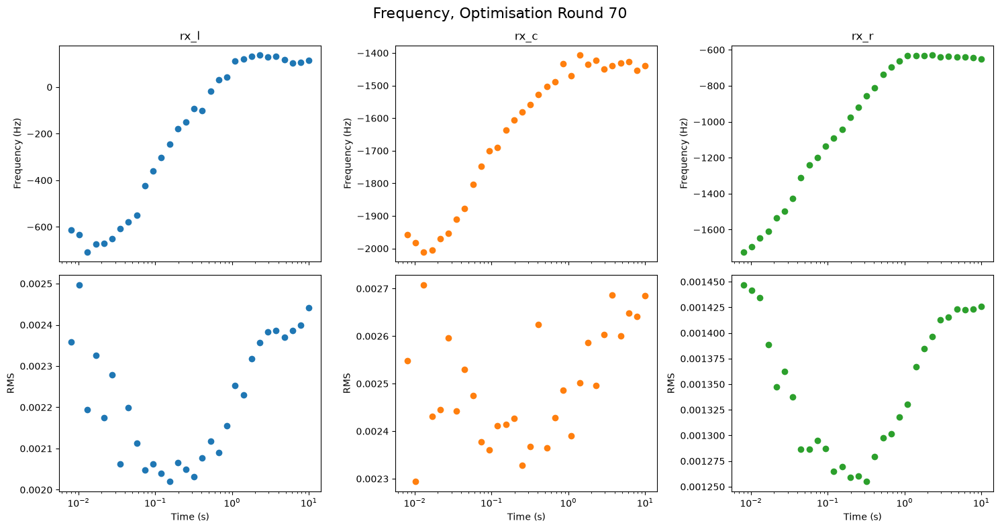

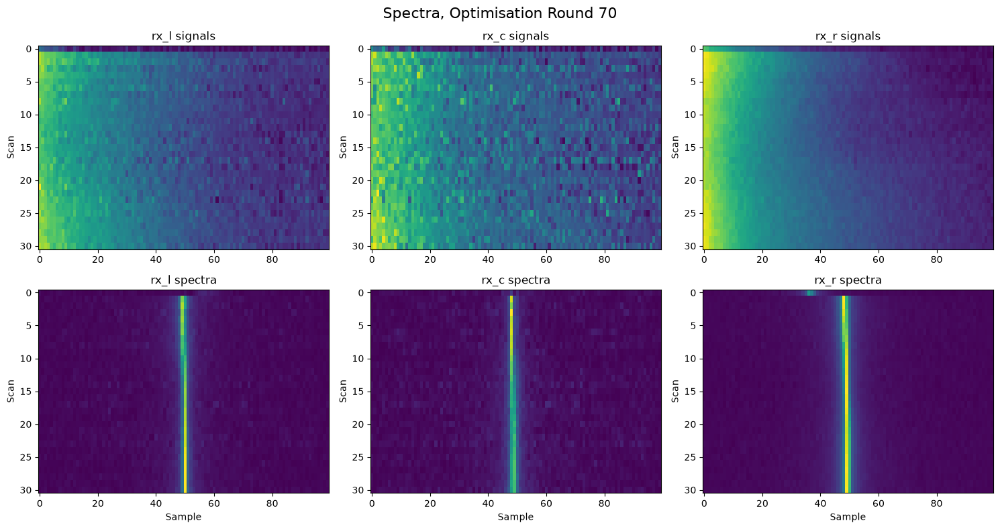

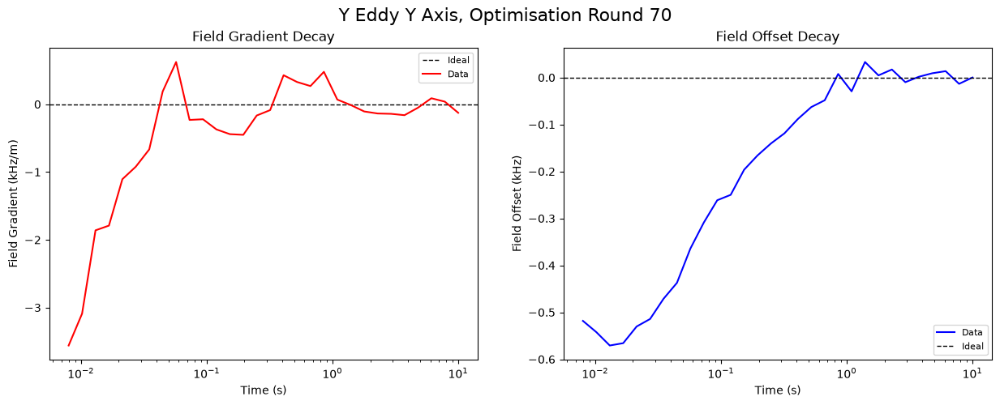

[I 2026-11-25 16:55:41,460] Trial 70 finished with value: 203.37279040217715 and parameters: {'Y_A1': -0.01078565228082975, 'Y_A2': -0.0059761330811977055, 'Y_A3': 8.377206229501839e-10, 'Y_A4': -8.808400050195514e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.034e+02
Total cost = 2.034e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24720839932378874
B nanmax = 0.24720839932378874
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2470814347738403 !!!!!!!!!!!!!!!!


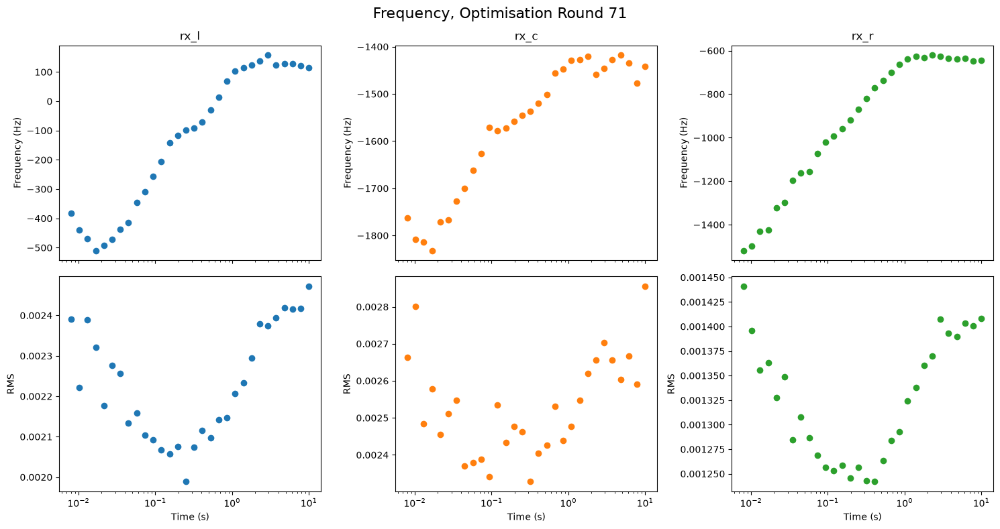

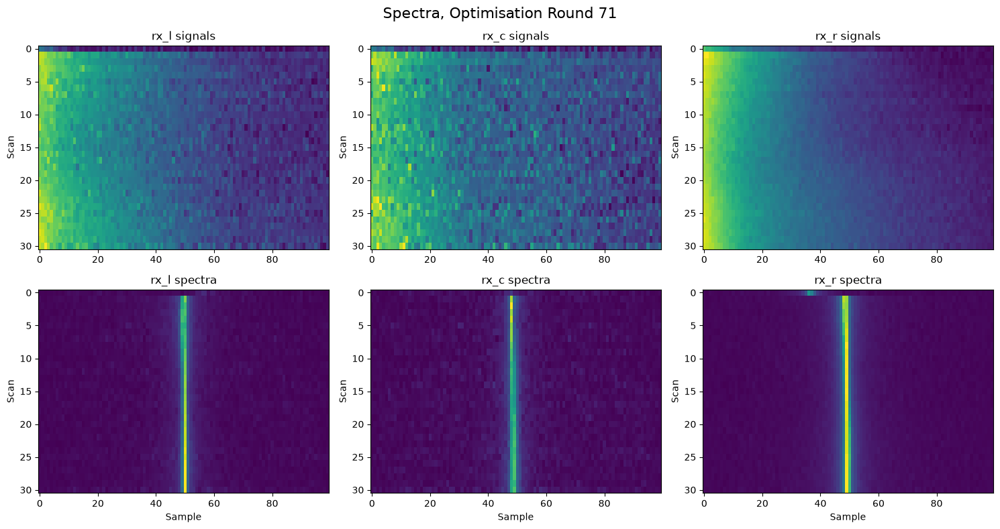

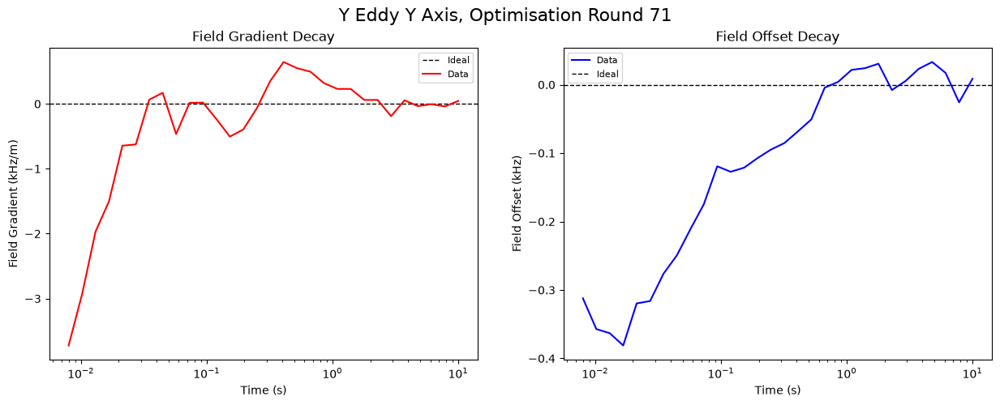

[I 2026-11-25 16:56:29,475] Trial 71 finished with value: 246.01529427689212 and parameters: {'Y_A1': -0.010772558662638277, 'Y_A2': -0.006759500341473873, 'Y_A3': 5.643116900296192e-10, 'Y_A4': -7.846357540164497e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.460e+02
Total cost = 2.460e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26551924826148054
B nanmax = 0.26551924826148054
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2653828787382181 !!!!!!!!!!!!!!!!


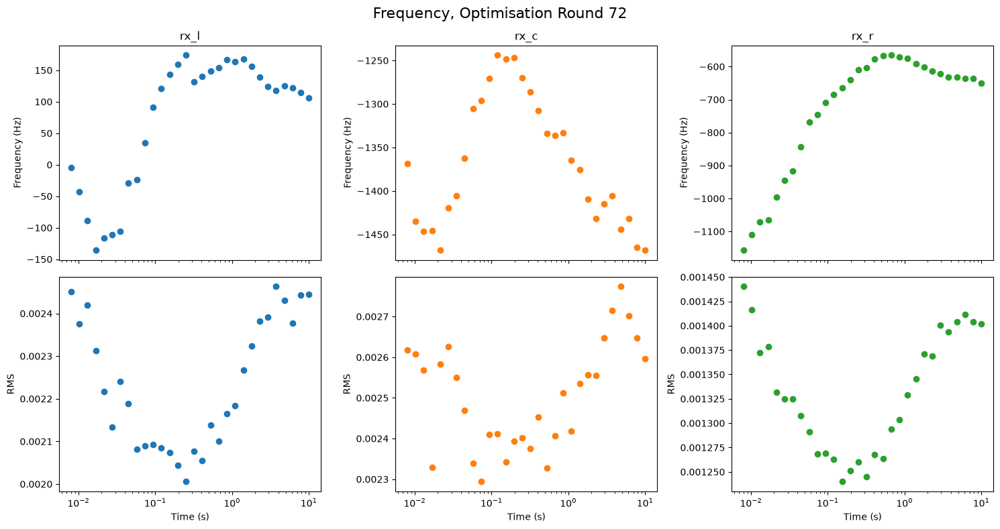

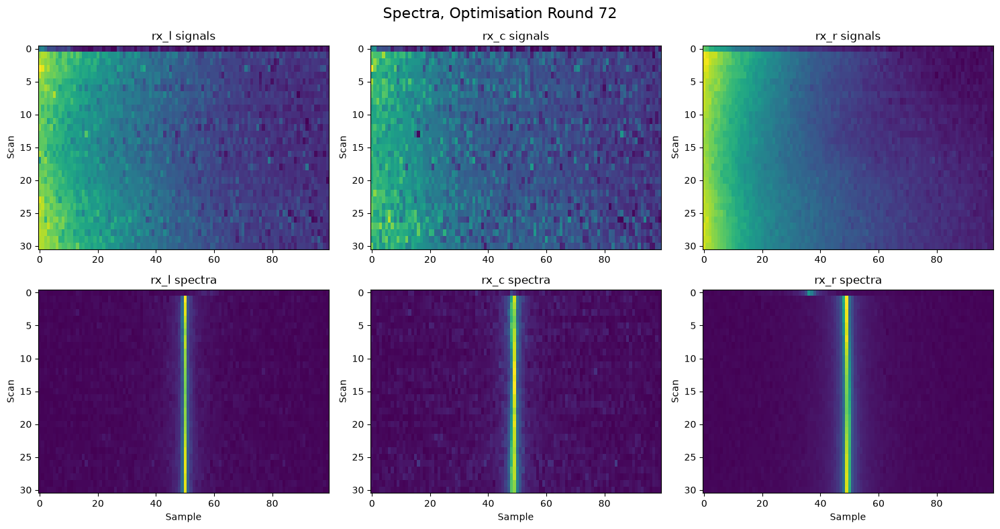

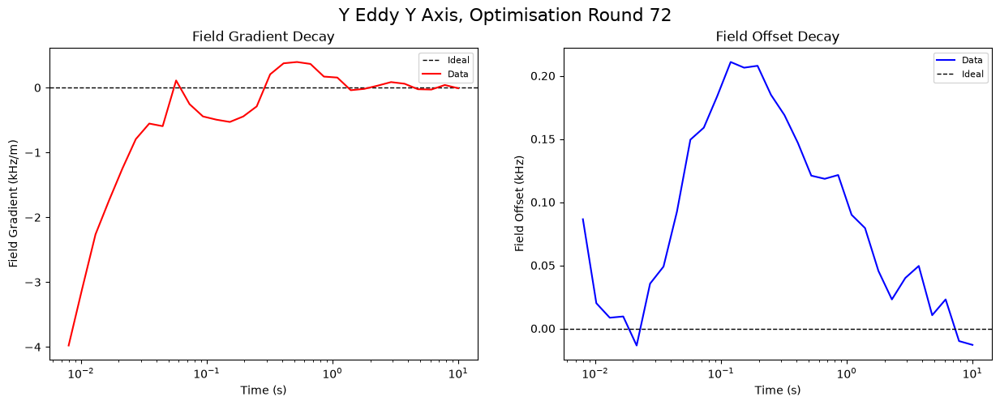

[I 2026-11-25 16:57:17,535] Trial 72 finished with value: 377.7395276397052 and parameters: {'Y_A1': -0.012495311665897475, 'Y_A2': -0.00633362329308988, 'Y_A3': 2.3141120827123647e-09, 'Y_A4': -8.535495573196489e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 3.777e+02
Total cost = 3.777e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2564595702020099
B nanmax = 0.2564595702020099
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25632785342345066 !!!!!!!!!!!!!!!!


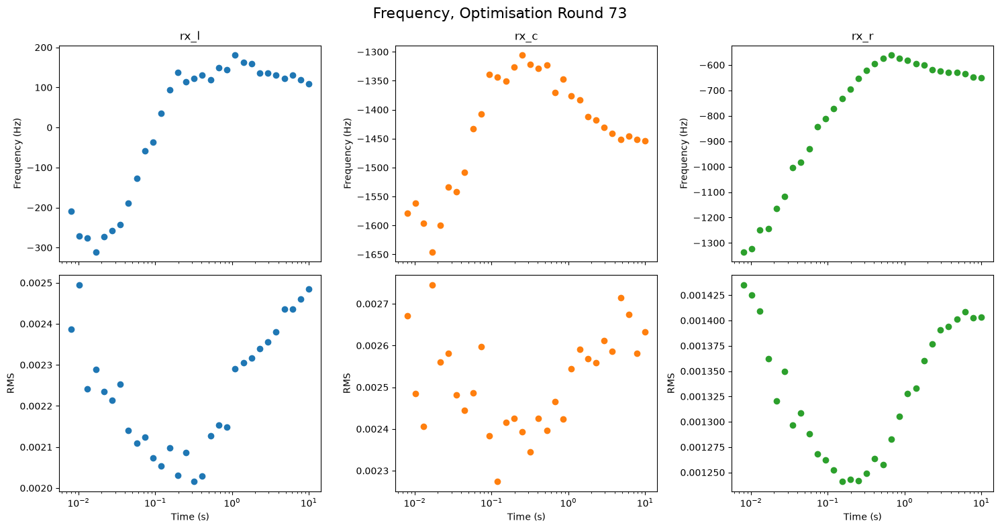

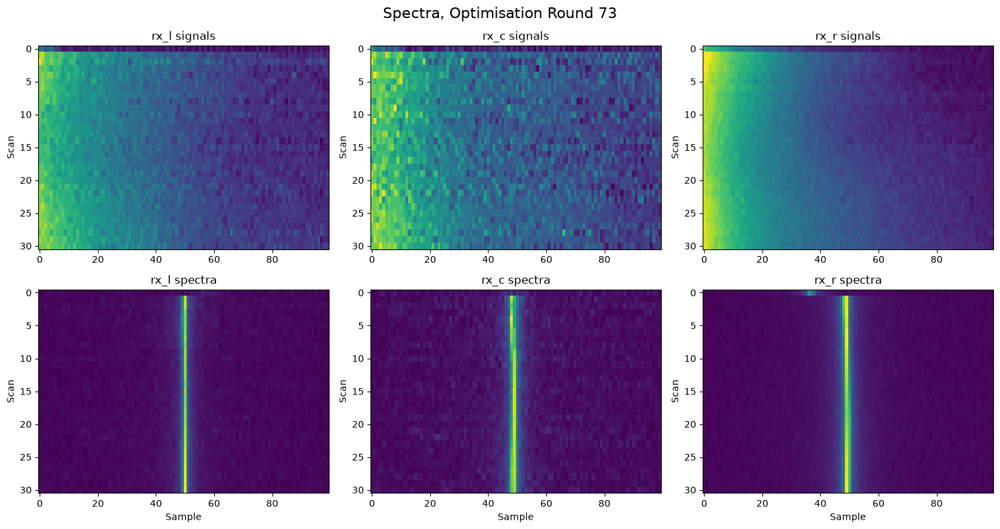

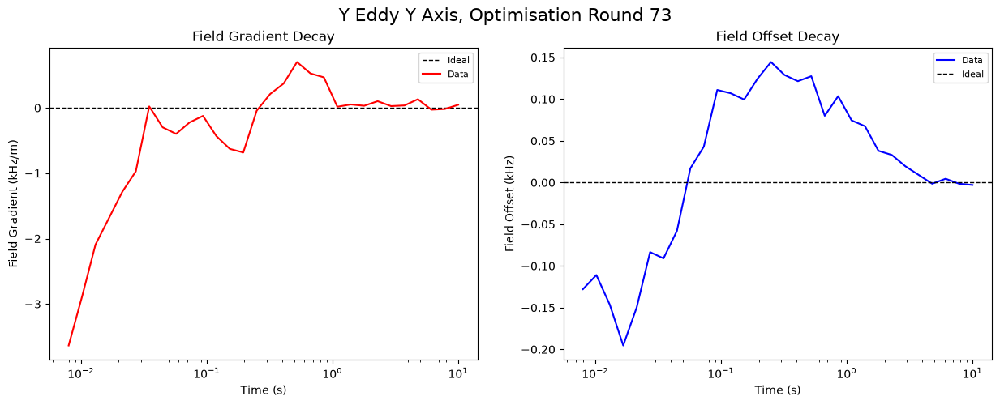

[I 2026-11-25 16:58:05,637] Trial 73 finished with value: 221.0530428358845 and parameters: {'Y_A1': -0.012450152187274875, 'Y_A2': -0.005735614036965182, 'Y_A3': -1.8728411577200695e-09, 'Y_A4': -5.157236874883733e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.211e+02
Total cost = 2.211e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26566155528075885
B nanmax = 0.26566155528075885
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2655251127072507 !!!!!!!!!!!!!!!!


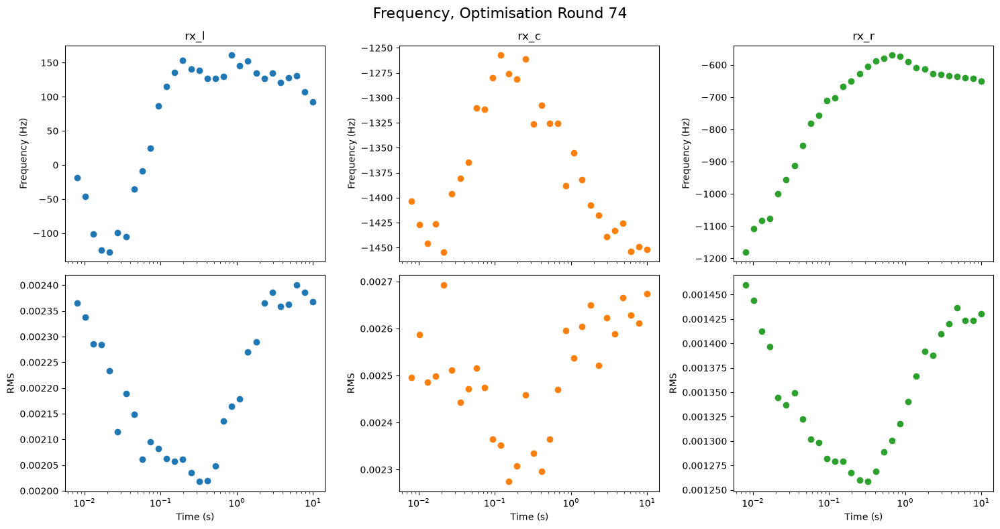

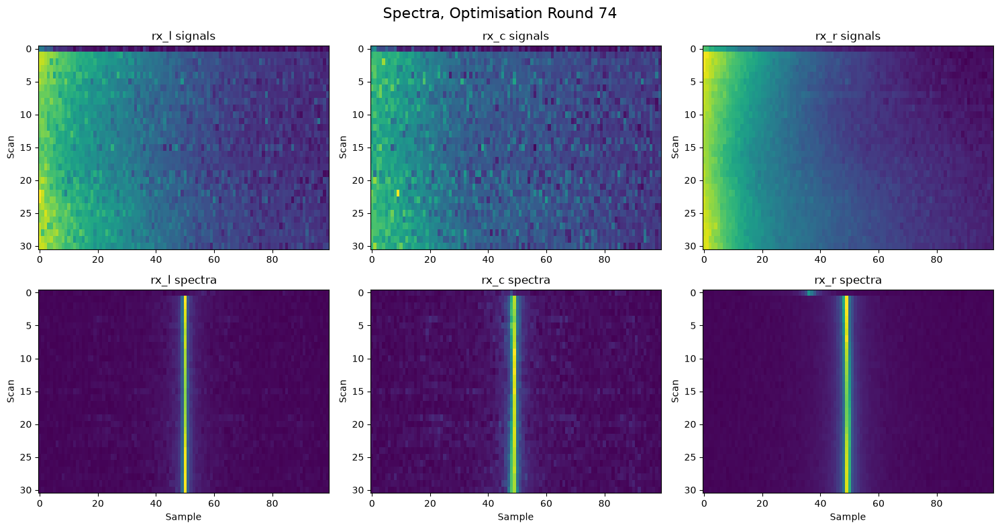

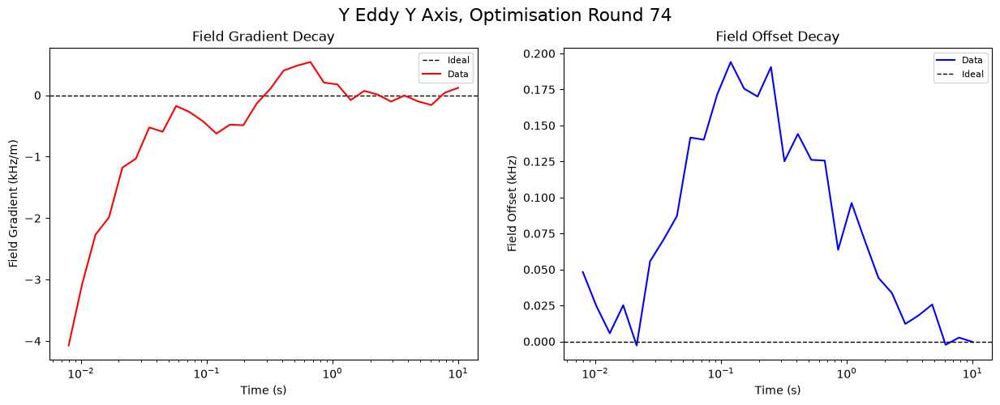

[I 2026-11-25 16:58:53,832] Trial 74 finished with value: 272.9129107105258 and parameters: {'Y_A1': -0.01244758396445693, 'Y_A2': -0.00639154444981424, 'Y_A3': 5.577887391879836e-10, 'Y_A4': -6.677685702667441e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.729e+02
Total cost = 2.729e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2359112901075884
B nanmax = 0.2359112901075884
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23579012775953775 !!!!!!!!!!!!!!!!


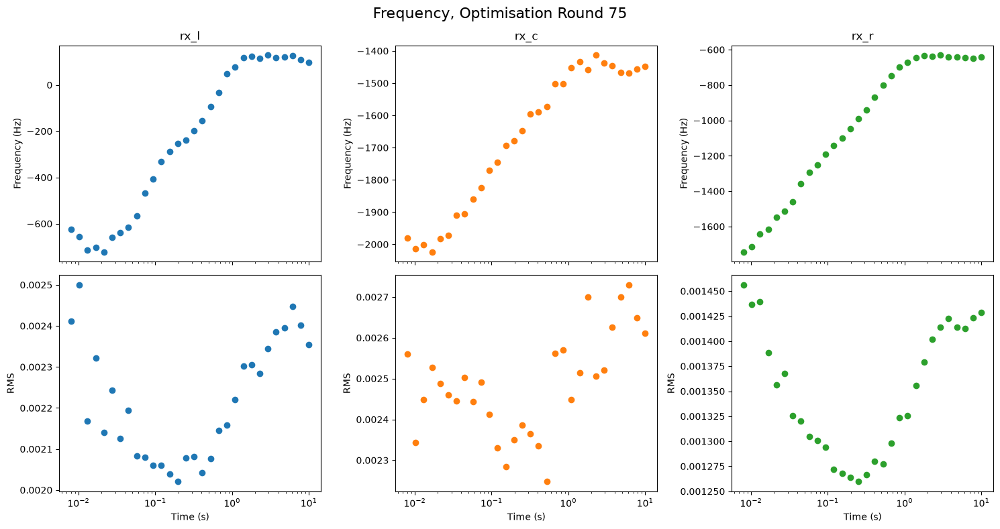

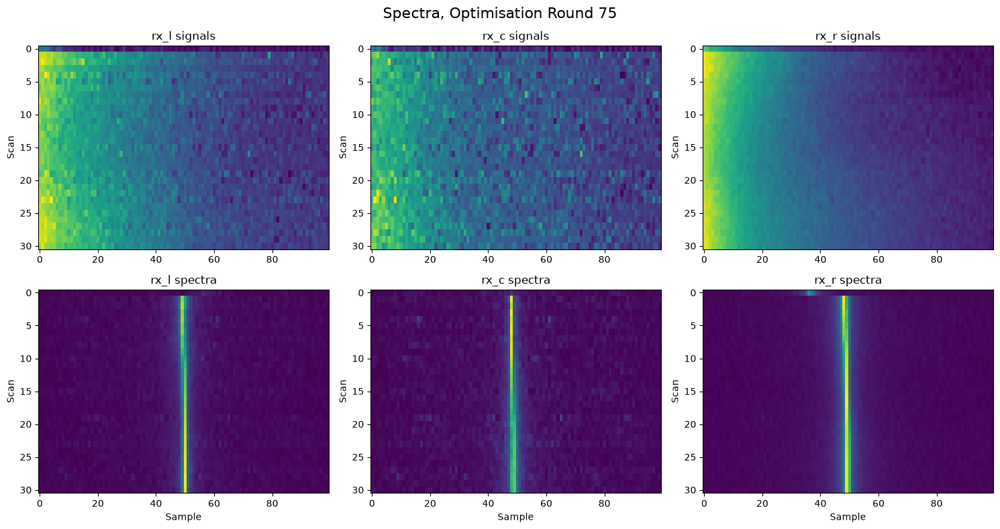

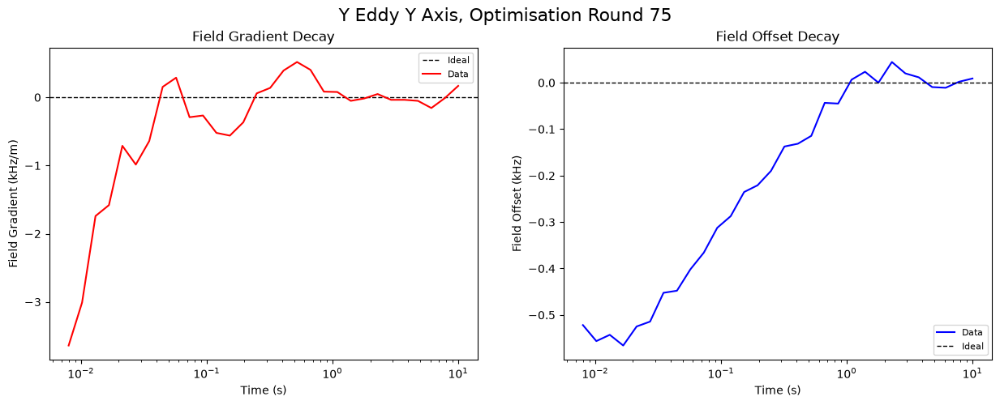

[I 2026-11-25 16:59:41,869] Trial 75 finished with value: 238.88187689468384 and parameters: {'Y_A1': -0.010160644949403335, 'Y_A2': -0.006570445344919665, 'Y_A3': -3.3457919355745195e-10, 'Y_A4': -9.422533849719222e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.389e+02
Total cost = 2.389e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.26318337061079067
B nanmax = 0.26318337061079067
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.263048200445476 !!!!!!!!!!!!!!!!


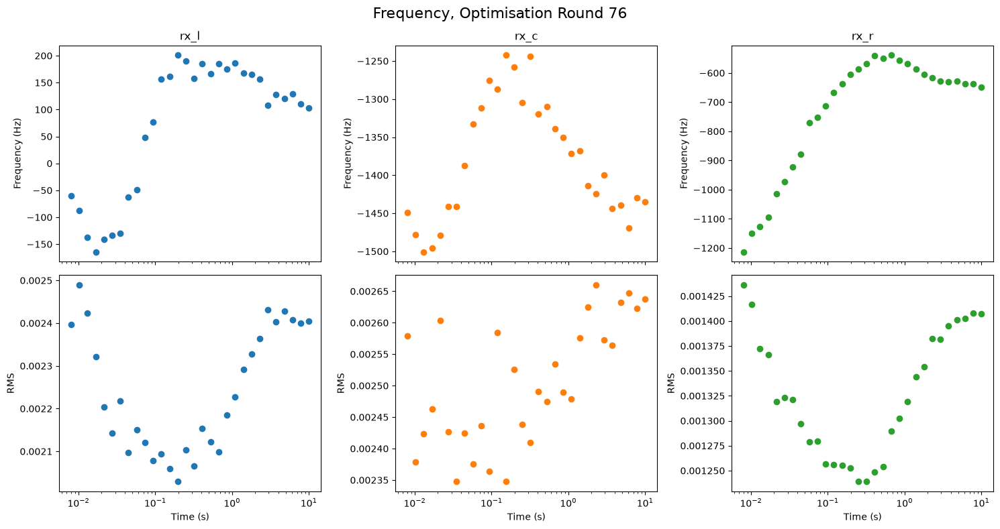

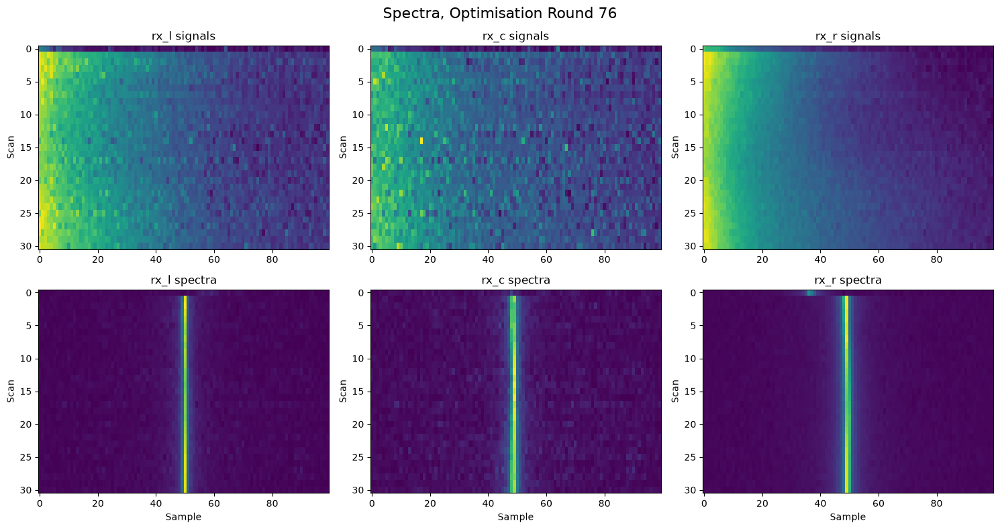

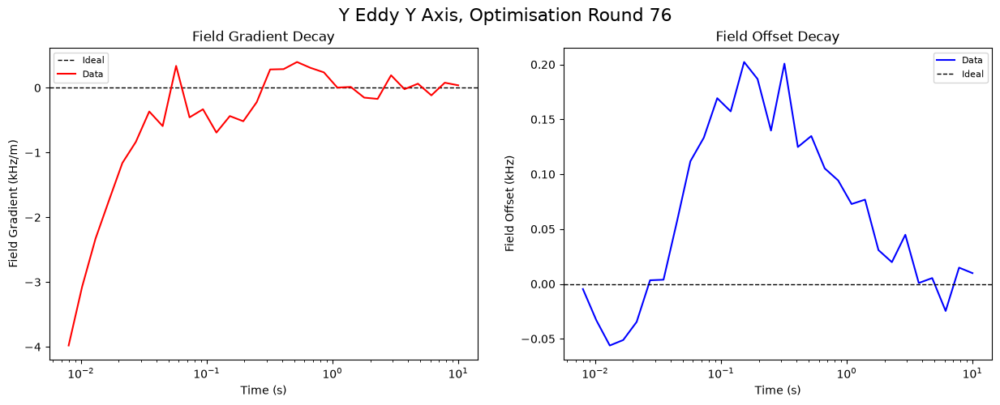

[I 2026-11-25 17:00:29,959] Trial 76 finished with value: 311.0684159557827 and parameters: {'Y_A1': -0.012870086928762174, 'Y_A2': -0.00579229452169474, 'Y_A3': 2.0868782131877636e-10, 'Y_A4': -7.391987039810972e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 3.111e+02
Total cost = 3.111e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24449098519053578
B nanmax = 0.24449098519053578
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24436541621432653 !!!!!!!!!!!!!!!!


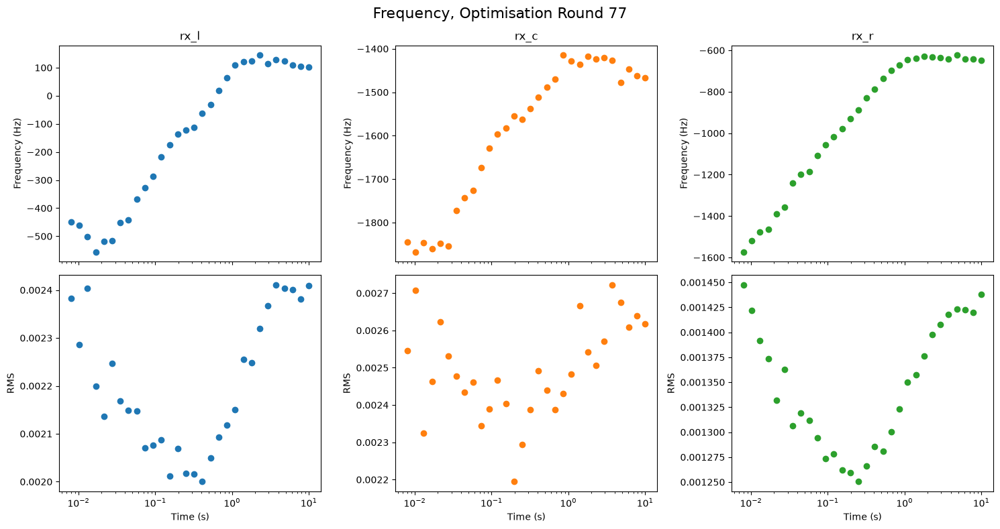

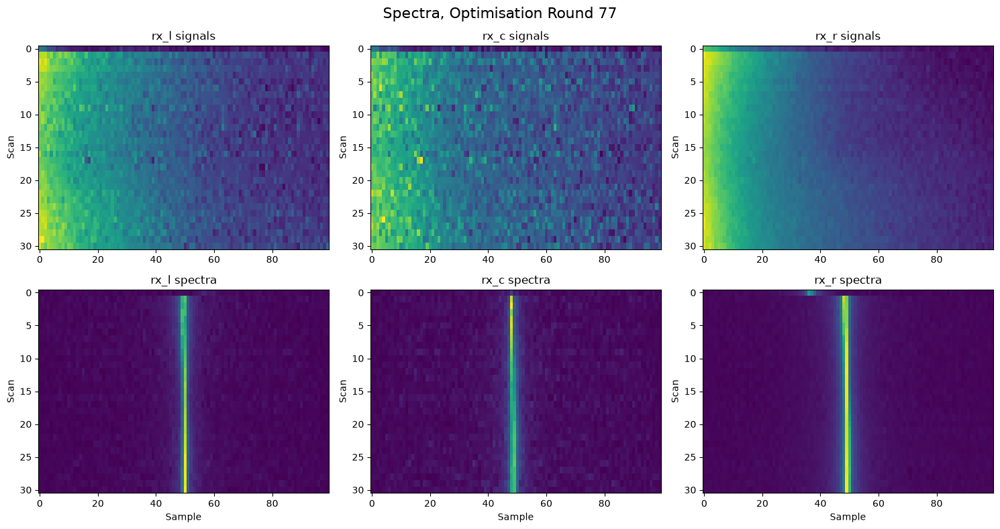

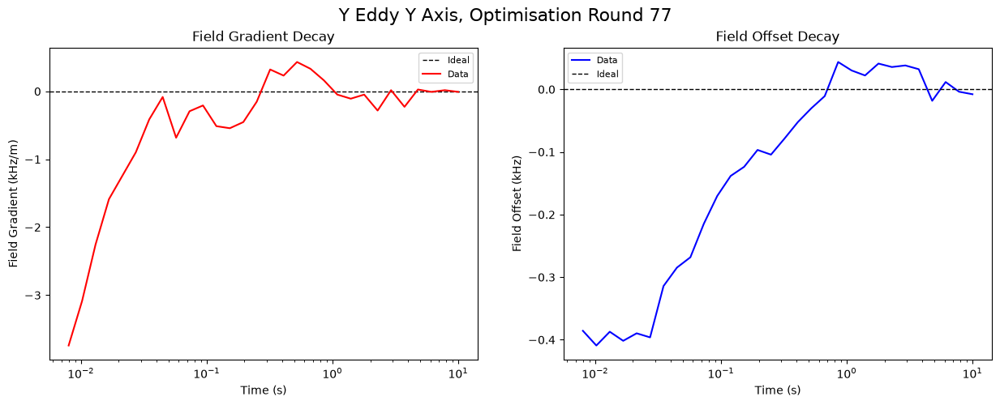

[I 2026-11-25 17:01:18,035] Trial 77 finished with value: 240.7306685992102 and parameters: {'Y_A1': -0.010756708781323059, 'Y_A2': -0.006582438654581343, 'Y_A3': 2.2785543393705317e-09, 'Y_A4': -9.033473792833371e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.407e+02
Total cost = 2.407e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.27366609426308675
B nanmax = 0.27366609426308675
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2735255407968733 !!!!!!!!!!!!!!!!


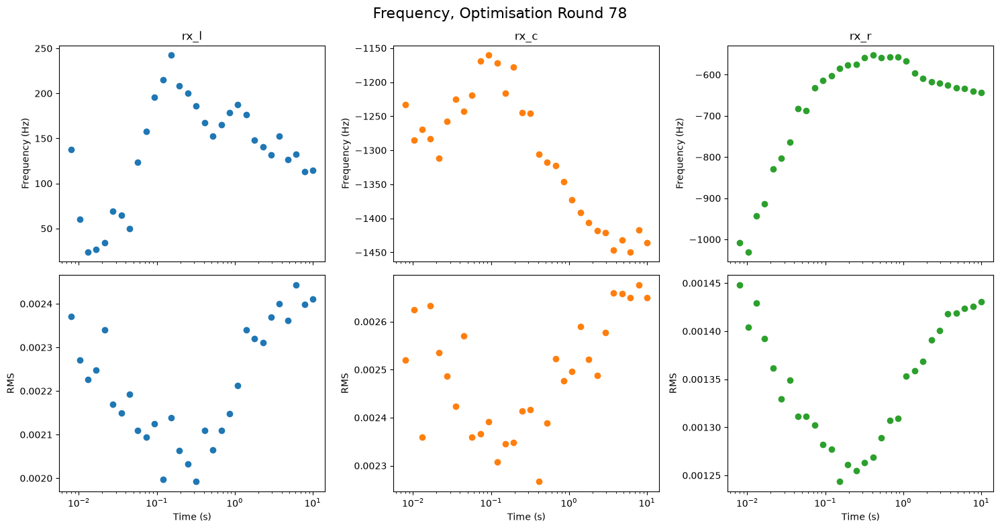

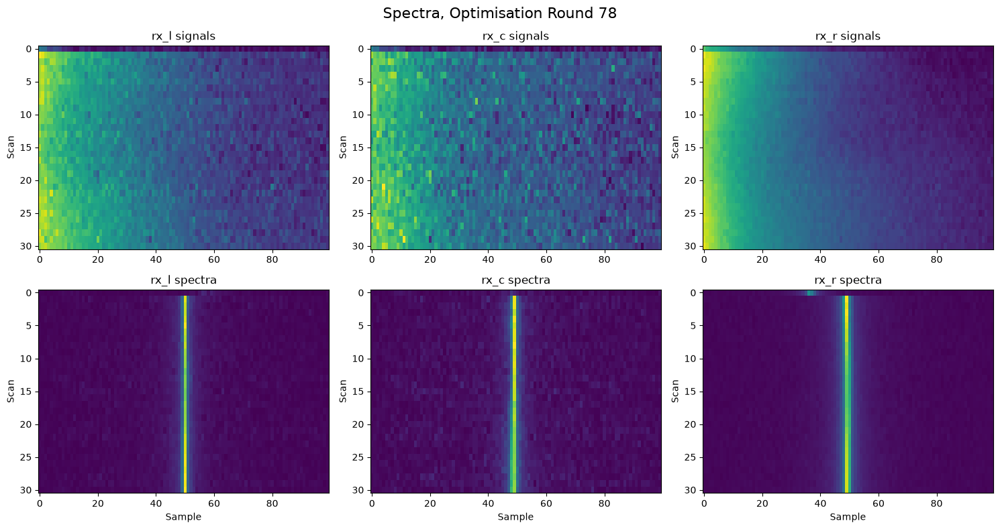

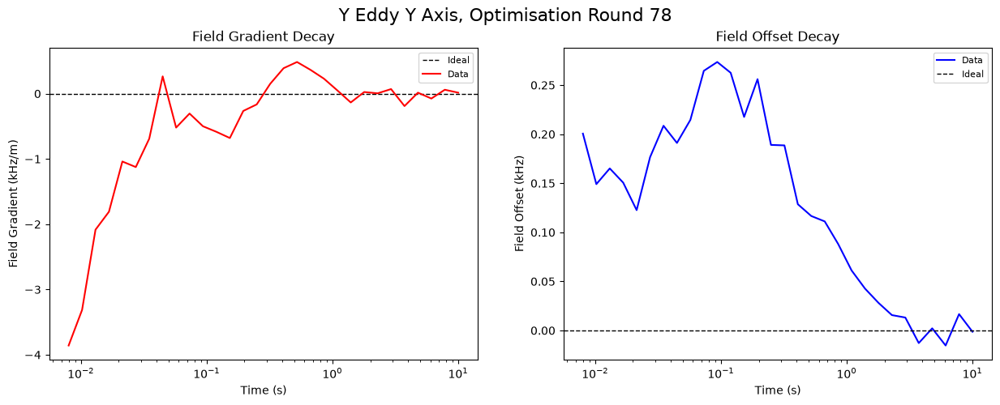

[I 2026-11-25 17:02:05,773] Trial 78 finished with value: 276.33583154087154 and parameters: {'Y_A1': -0.0125330083491971, 'Y_A2': -0.006874296616897243, 'Y_A3': 3.687808652256359e-10, 'Y_A4': -7.806631981618234e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.763e+02
Total cost = 2.763e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24910646777273948
B nanmax = 0.24910646777273948
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24897852818010088 !!!!!!!!!!!!!!!!


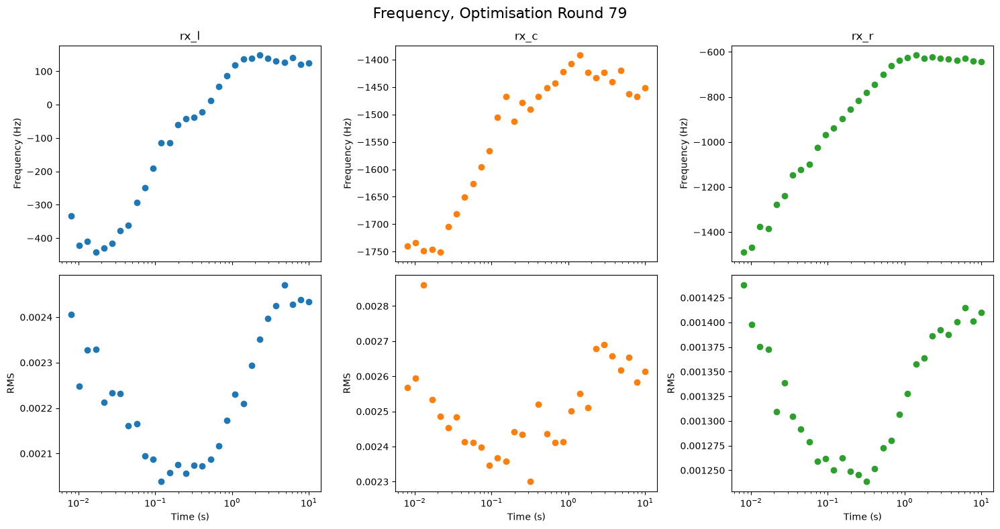

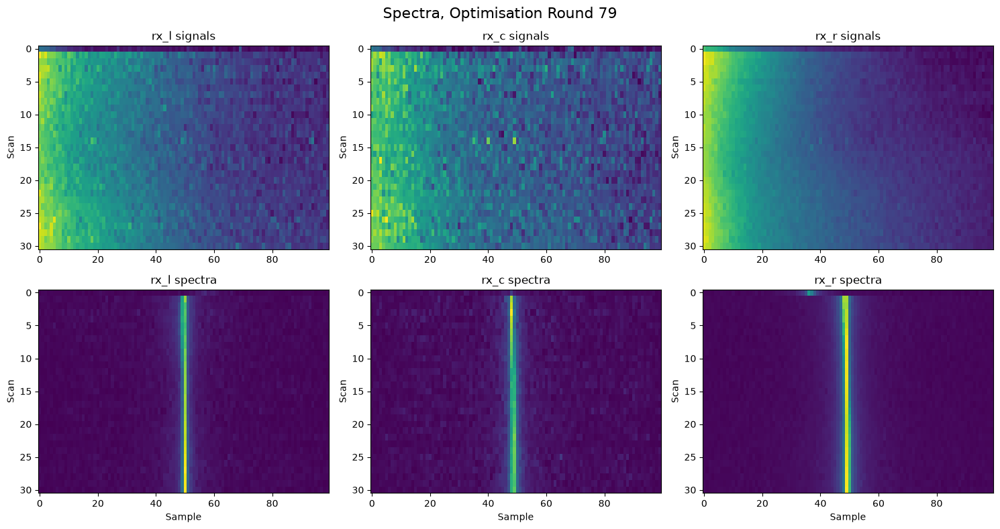

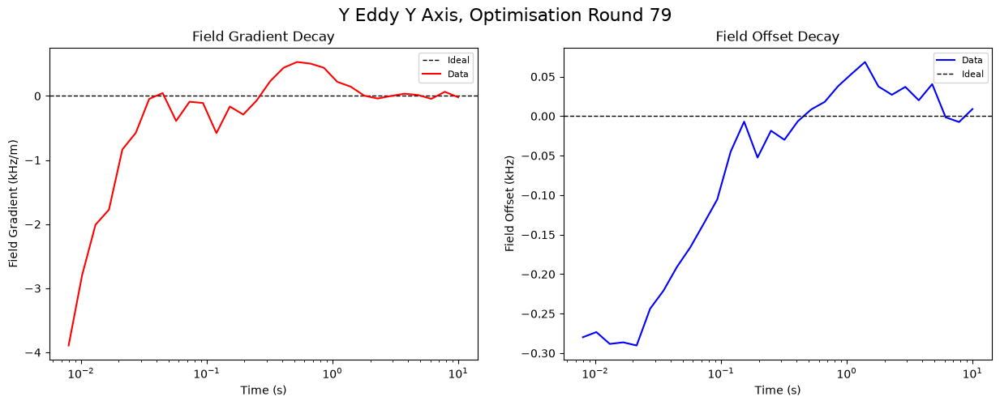

[I 2026-11-25 17:02:53,747] Trial 79 finished with value: 228.5954097630959 and parameters: {'Y_A1': -0.011152549037142669, 'Y_A2': -0.006513564426300376, 'Y_A3': 1.6467012277112866e-09, 'Y_A4': -7.226683506904573e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.286e+02
Total cost = 2.286e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23803117978307303
B nanmax = 0.23803117978307303
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23790892841322175 !!!!!!!!!!!!!!!!


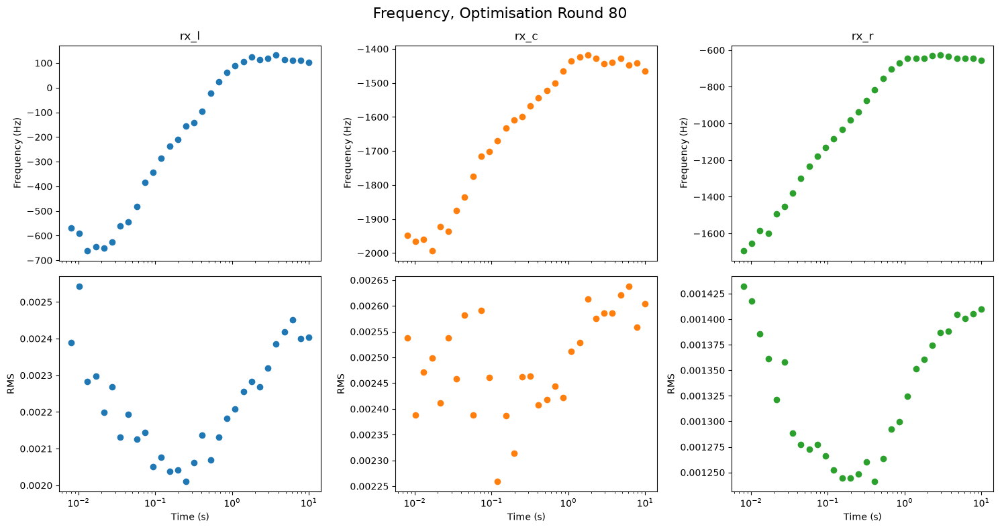

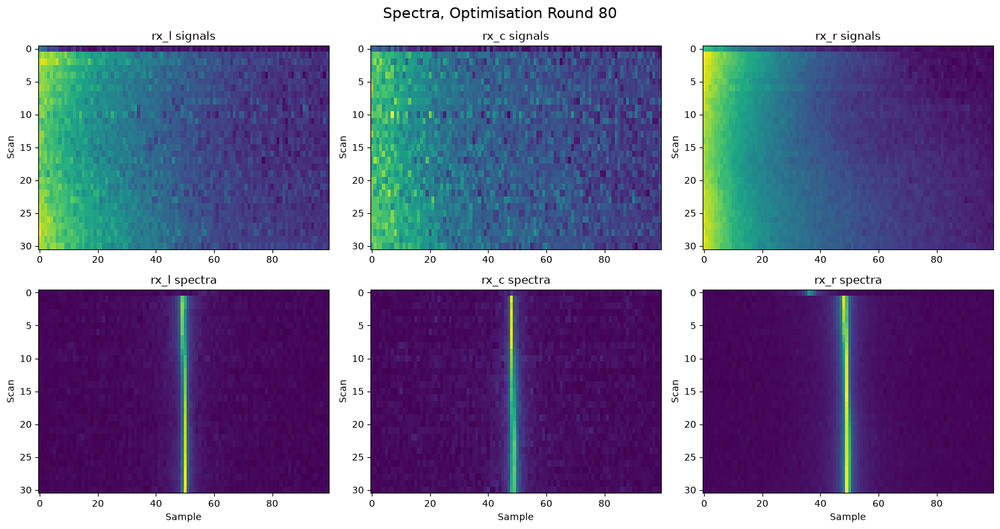

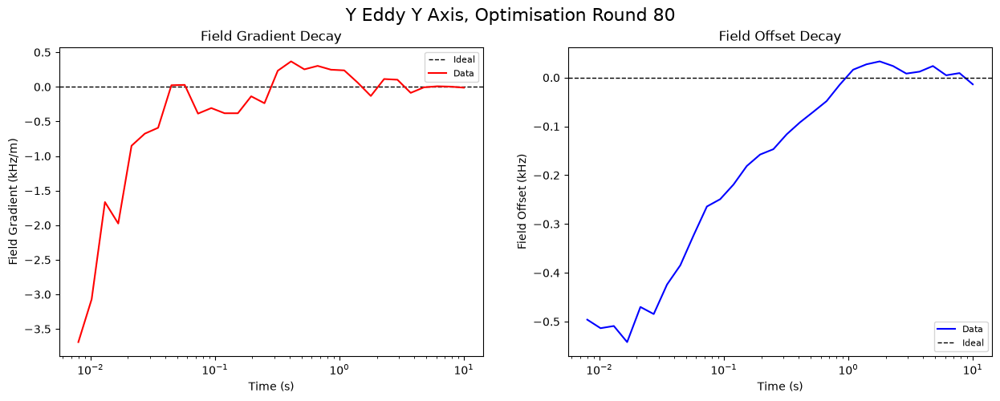

[I 2026-11-25 17:03:41,767] Trial 80 finished with value: 230.89411514035112 and parameters: {'Y_A1': -0.010626518667932976, 'Y_A2': -0.006254214913898115, 'Y_A3': -8.165222740856585e-10, 'Y_A4': -8.203538002043146e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.309e+02
Total cost = 2.309e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24619822338971145
B nanmax = 0.24619822338971145
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24607177718253082 !!!!!!!!!!!!!!!!


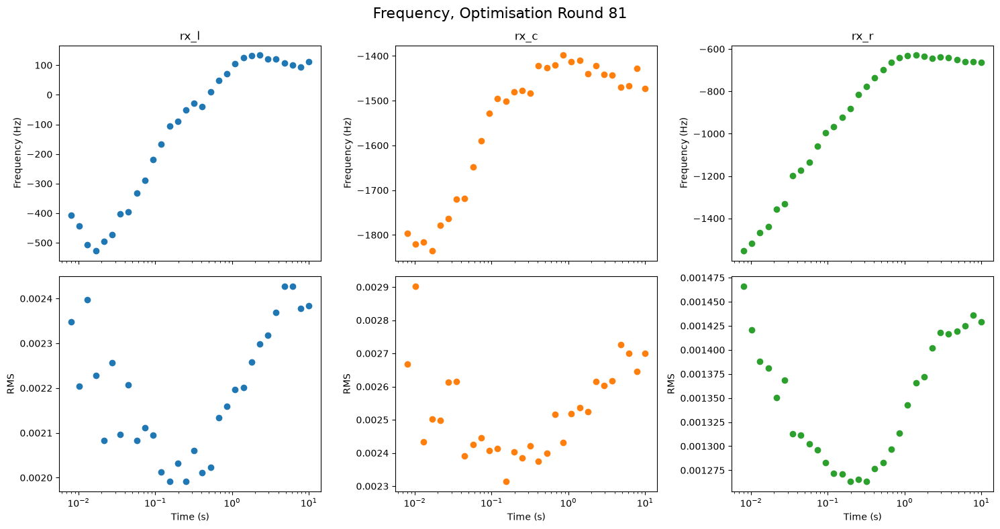

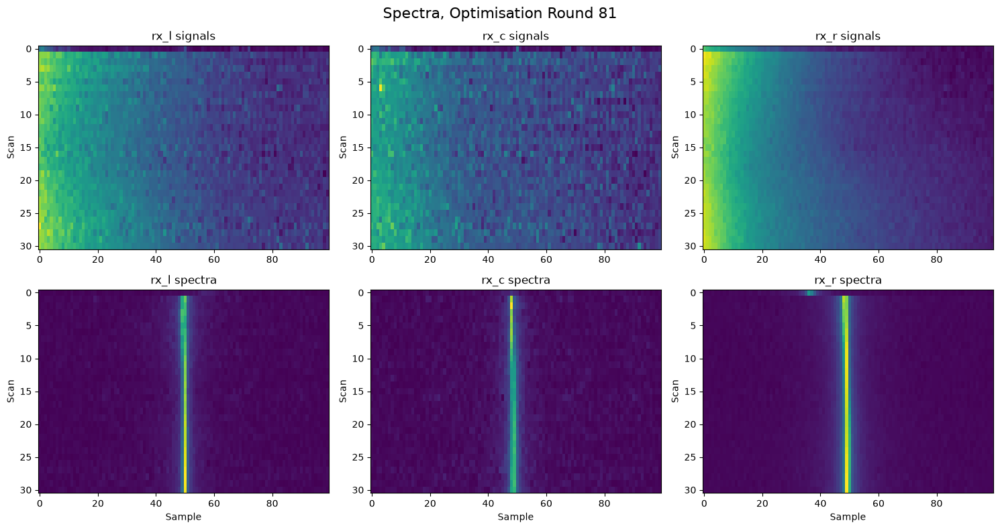

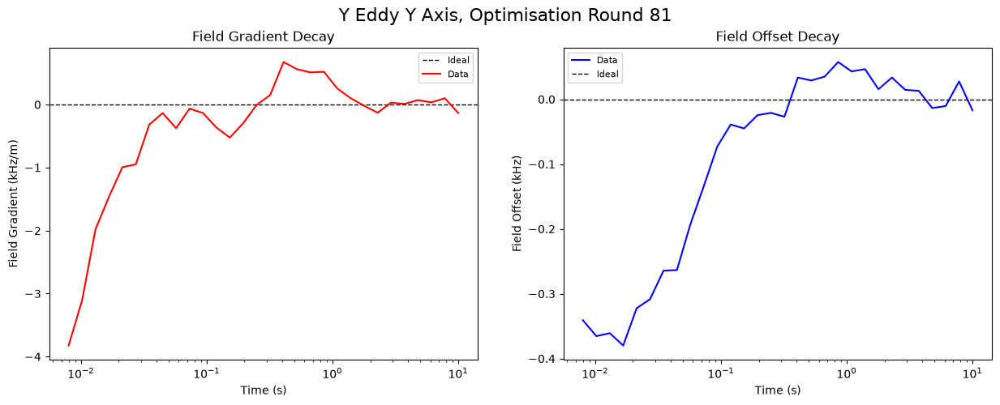

[I 2026-11-25 17:04:29,820] Trial 81 finished with value: 232.84324321810158 and parameters: {'Y_A1': -0.011410971021183386, 'Y_A2': -0.006048167824162978, 'Y_A3': 3.7310262977438175e-10, 'Y_A4': -7.5415646221242e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.328e+02
Total cost = 2.328e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2503776143755922
B nanmax = 0.2503776143755922
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25024902183457 !!!!!!!!!!!!!!!!


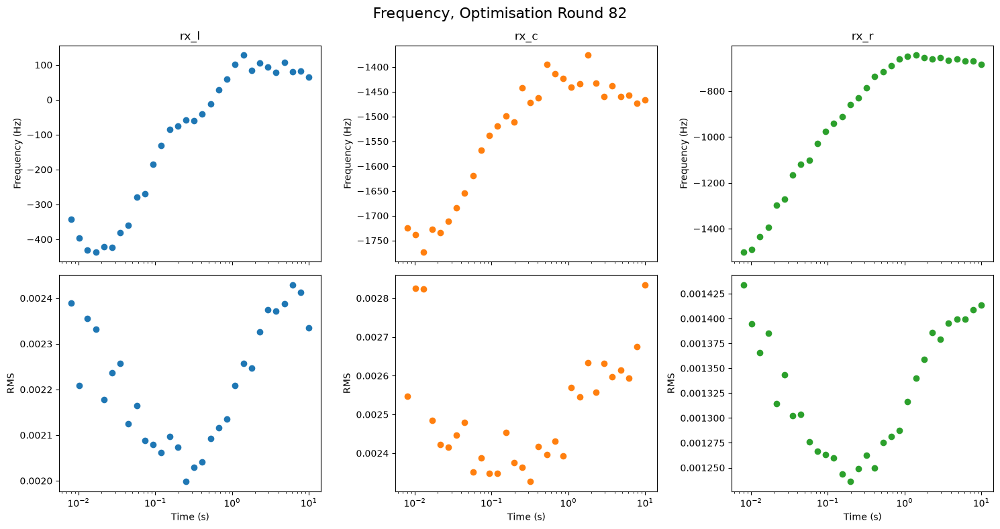

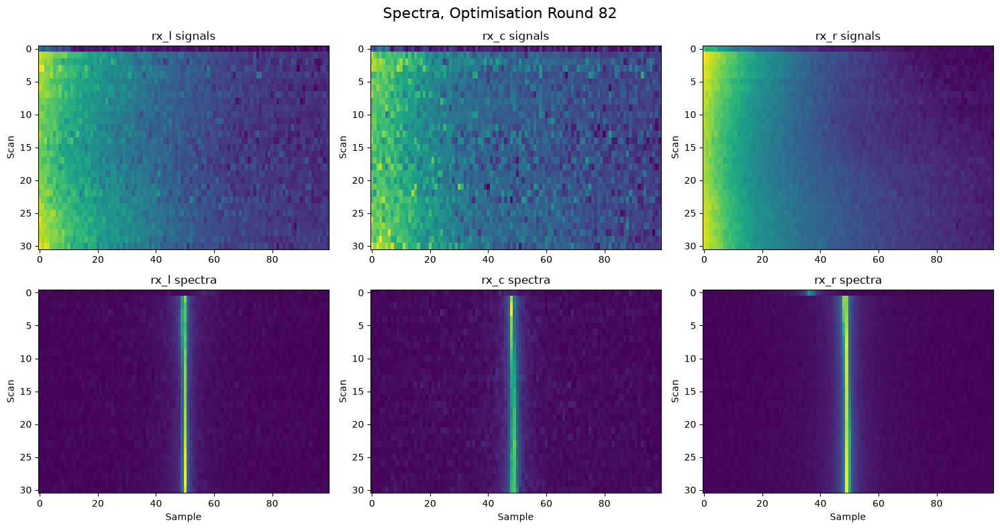

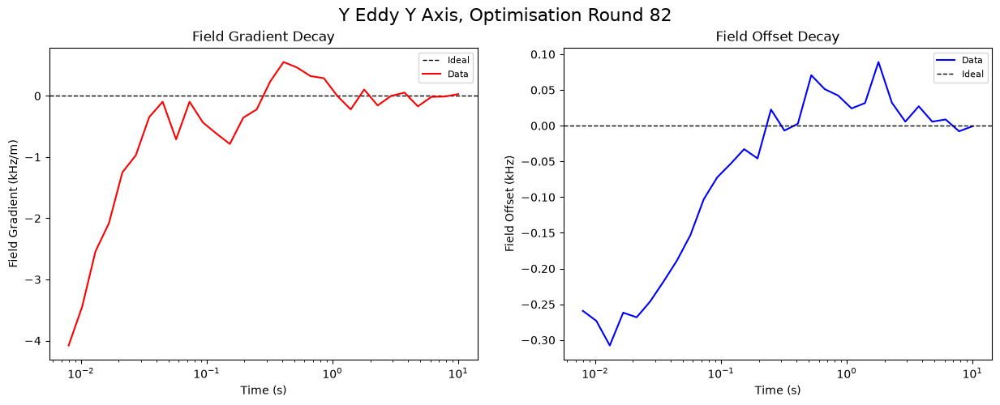

[I 2026-11-25 17:05:17,901] Trial 82 finished with value: 190.52967384626152 and parameters: {'Y_A1': -0.011345579511761473, 'Y_A2': -0.006410426049995635, 'Y_A3': -2.337779564827249e-09, 'Y_A4': -7.245360014497854e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.905e+02
Total cost = 1.905e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25538005164836
B nanmax = 0.25538005164836
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2552488896584315 !!!!!!!!!!!!!!!!


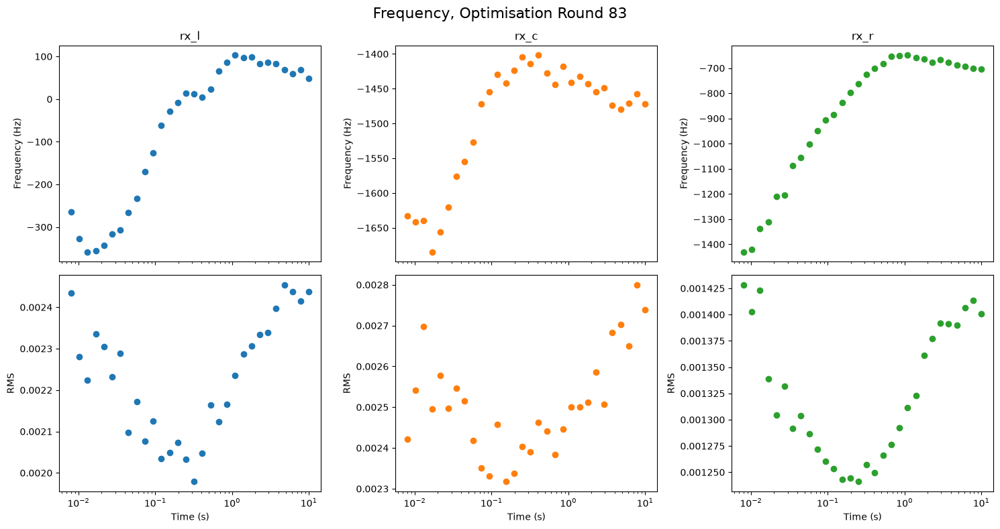

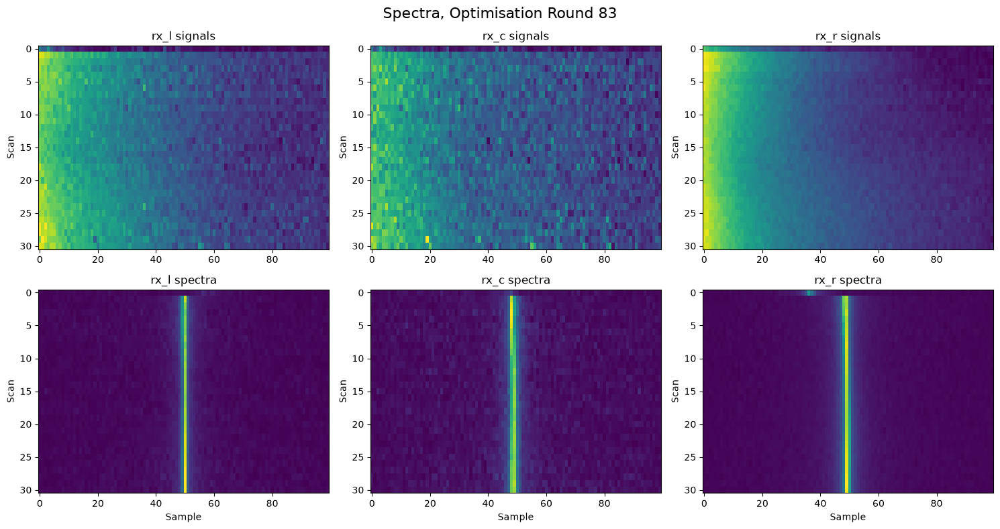

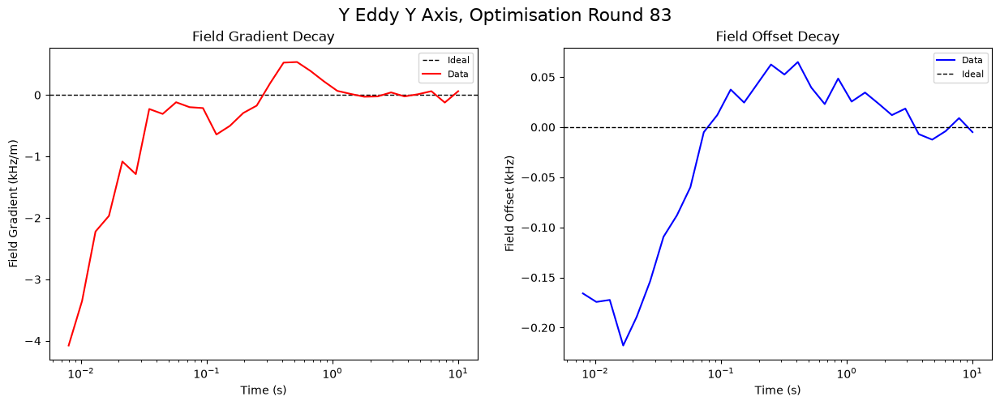

[I 2026-11-25 17:06:05,838] Trial 83 finished with value: 145.25717757992115 and parameters: {'Y_A1': -0.011894544128087178, 'Y_A2': -0.006215615105637492, 'Y_A3': -1.4083491084613983e-09, 'Y_A4': -8.83401436731684e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.453e+02
Total cost = 1.453e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25535821872570985
B nanmax = 0.25535821872570985
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25522706814262025 !!!!!!!!!!!!!!!!


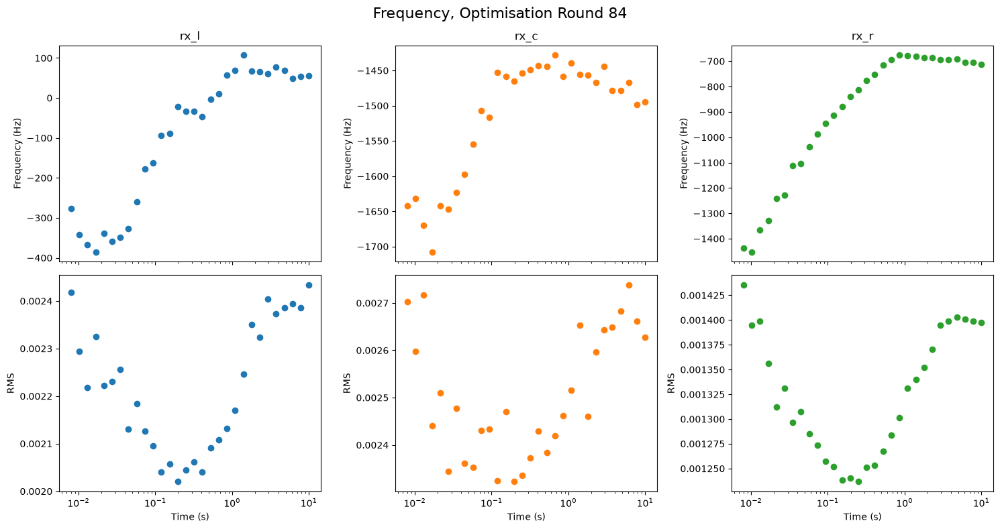

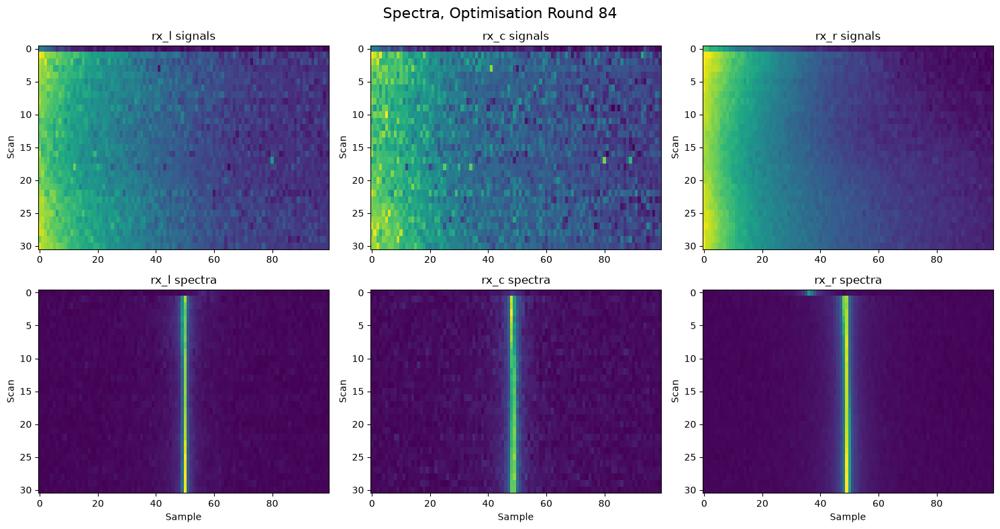

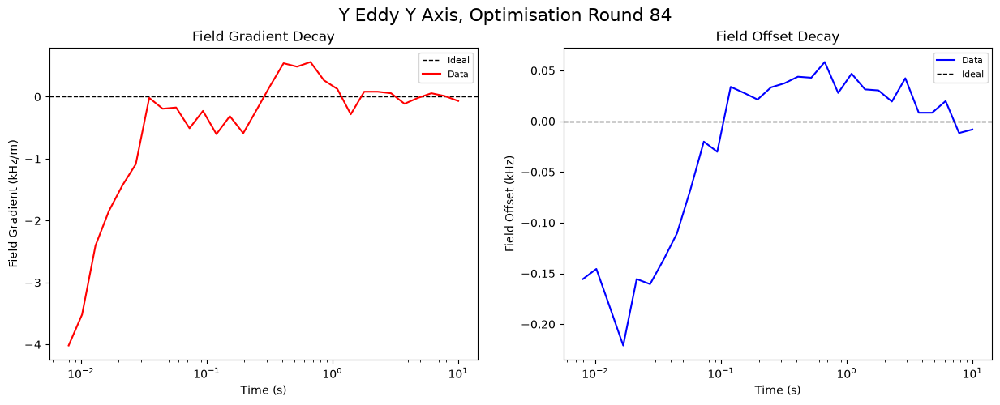

[I 2026-11-25 17:06:53,847] Trial 84 finished with value: 200.2168923801035 and parameters: {'Y_A1': -0.011616447221164524, 'Y_A2': -0.00649268276230026, 'Y_A3': -1.9792575574636367e-09, 'Y_A4': -8.519597241778987e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.002e+02
Total cost = 2.002e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2550070249199812
B nanmax = 0.2550070249199812
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25487605453492346 !!!!!!!!!!!!!!!!


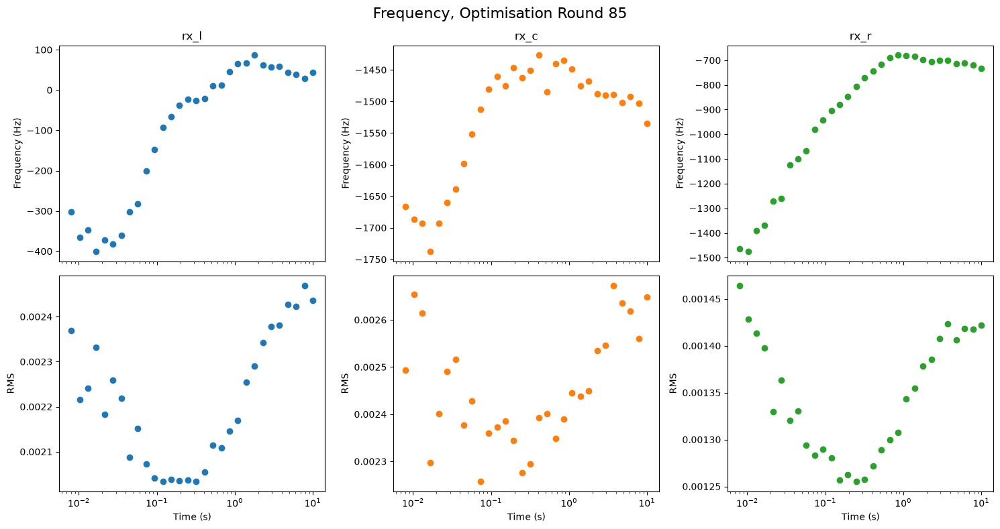

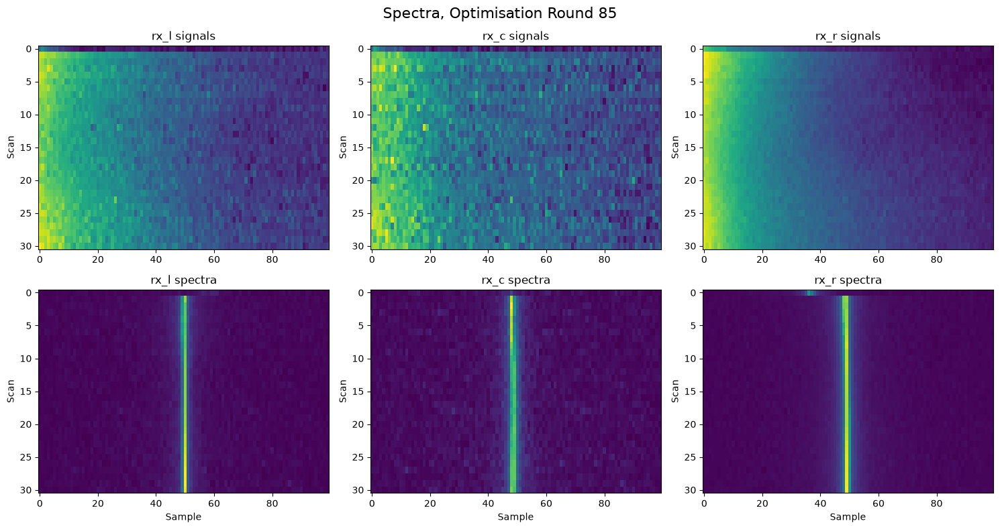

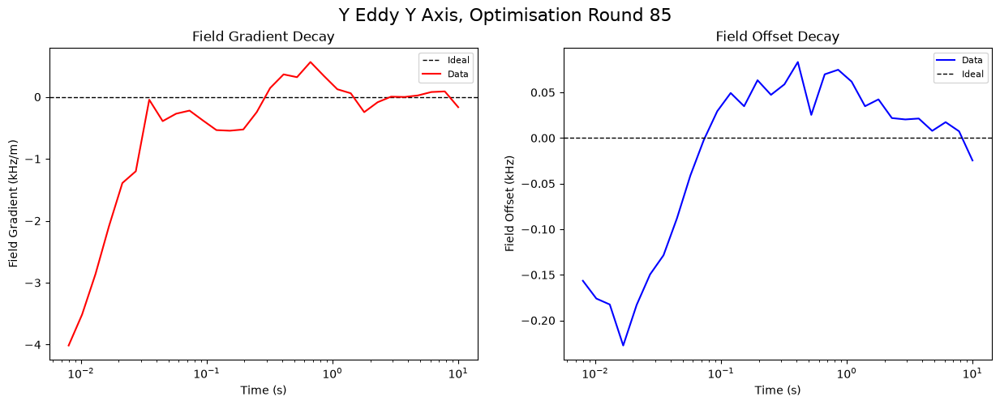

[I 2026-11-25 17:07:41,518] Trial 85 finished with value: 231.62523363346799 and parameters: {'Y_A1': -0.011848392278031104, 'Y_A2': -0.006235367842429519, 'Y_A3': -1.1677902129486032e-09, 'Y_A4': -9.95936995181682e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.316e+02
Total cost = 2.316e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24509803729152205
B nanmax = 0.24509803729152205
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24497215610054418 !!!!!!!!!!!!!!!!


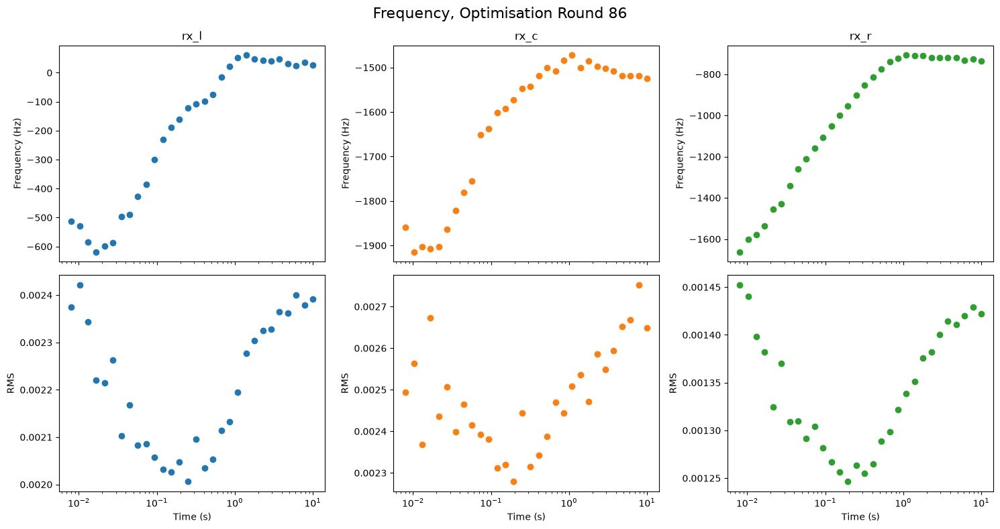

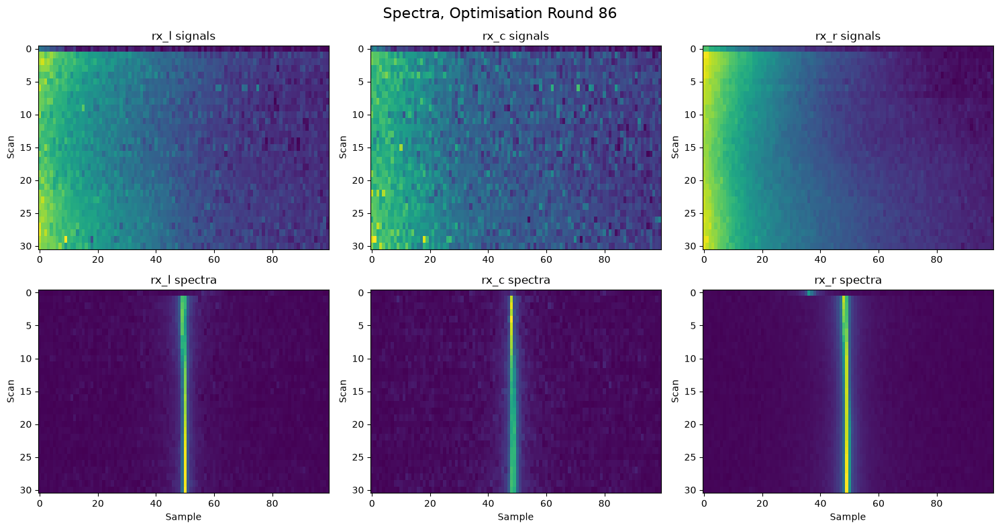

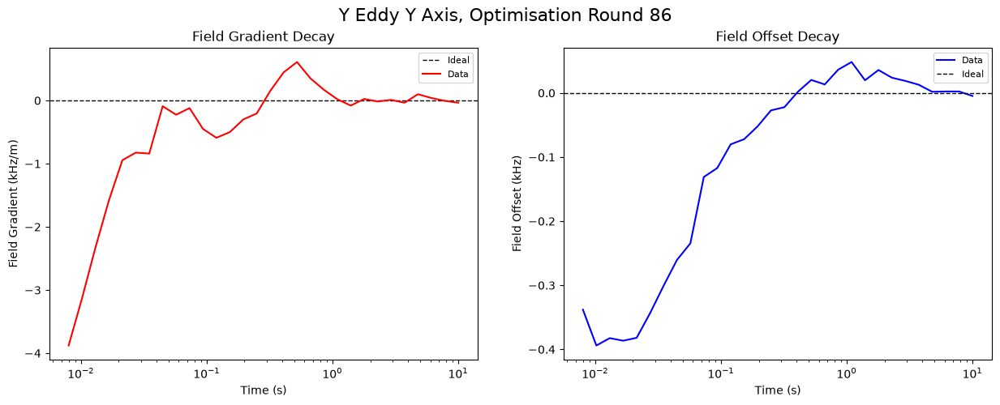

[I 2026-11-25 17:08:29,302] Trial 86 finished with value: 136.76093552737754 and parameters: {'Y_A1': -0.011408668694720658, 'Y_A2': -0.005972359284927816, 'Y_A3': -1.7959465001180948e-10, 'Y_A4': -8.969860832825206e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.368e+02
Total cost = 1.368e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25521369553778184
B nanmax = 0.25521369553778184
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.25508261883629835 !!!!!!!!!!!!!!!!


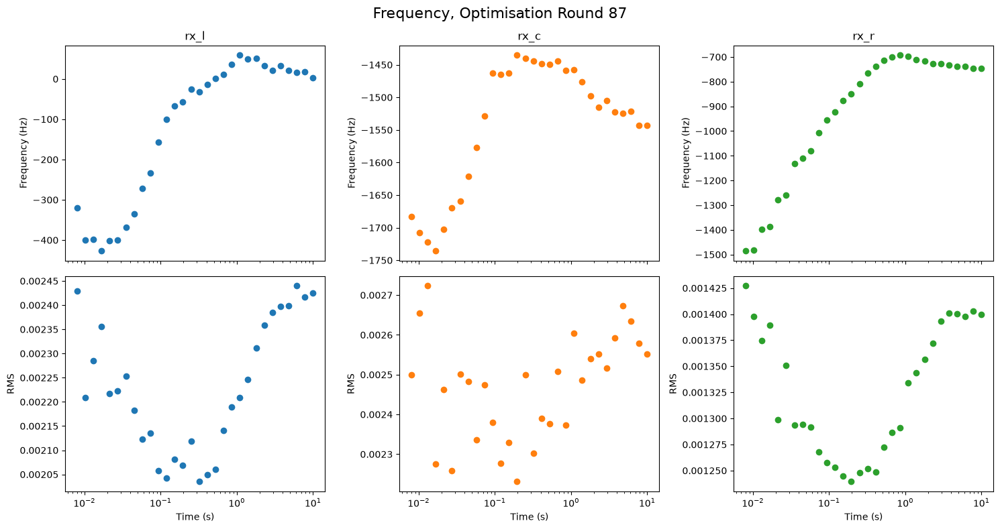

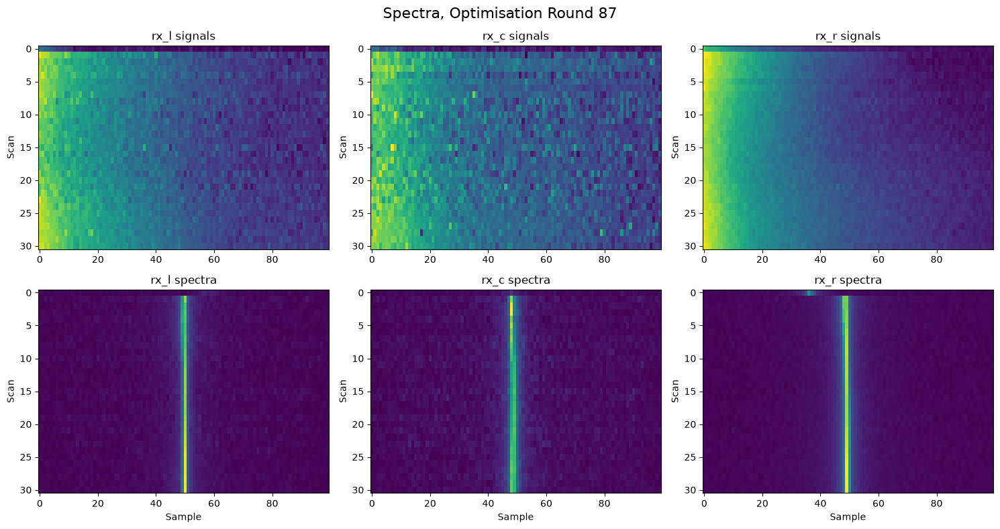

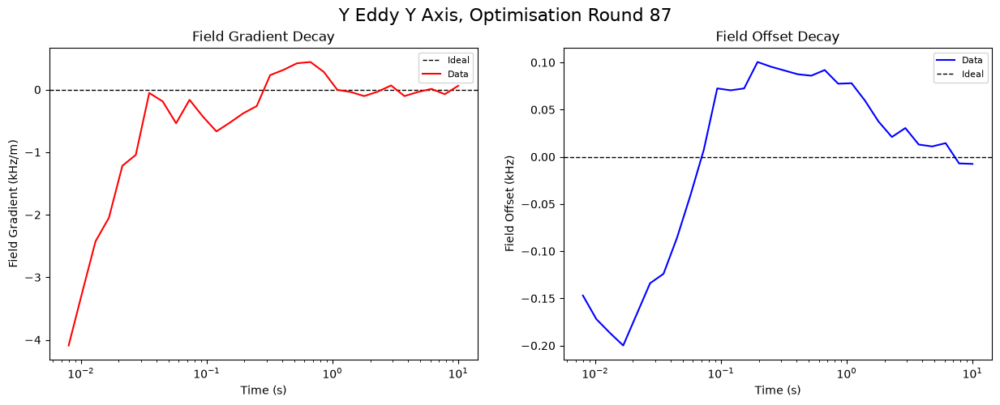

[I 2026-11-25 17:09:17,026] Trial 87 finished with value: 244.42474216438148 and parameters: {'Y_A1': -0.012103345941856023, 'Y_A2': -0.005994610586936959, 'Y_A3': 1.5198097096166472e-09, 'Y_A4': -8.308082625111513e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.444e+02
Total cost = 2.444e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.27135516910423124
B nanmax = 0.27135516910423124
B contains nan = False
Trial 88


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2712158023783161 !!!!!!!!!!!!!!!!


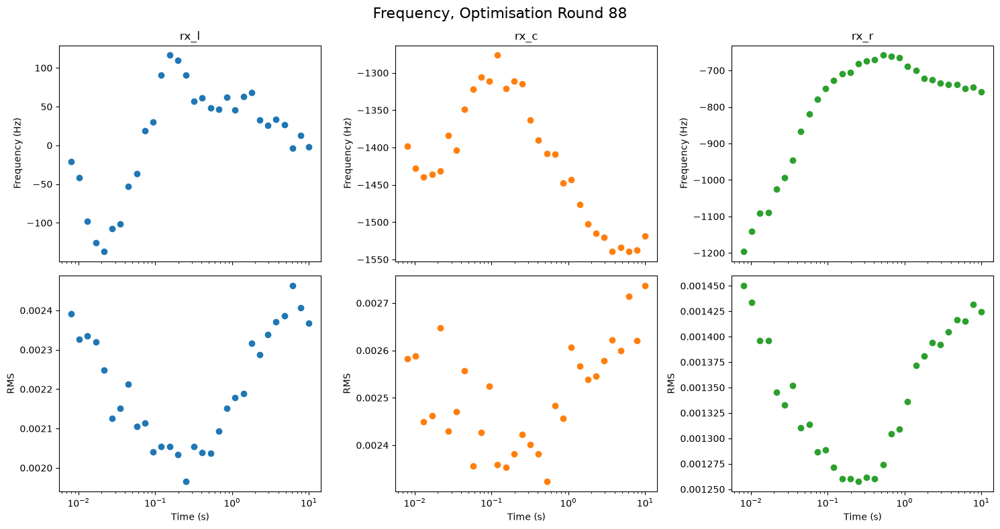

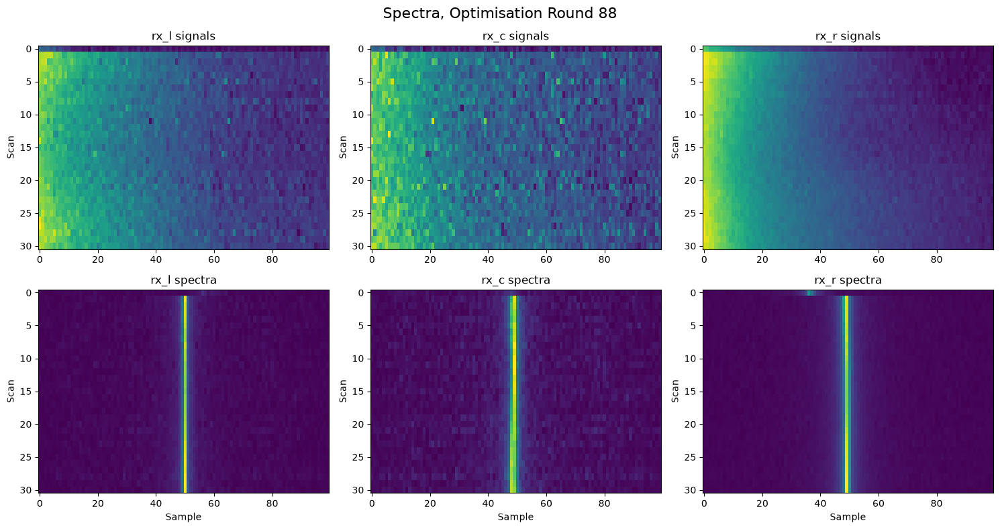

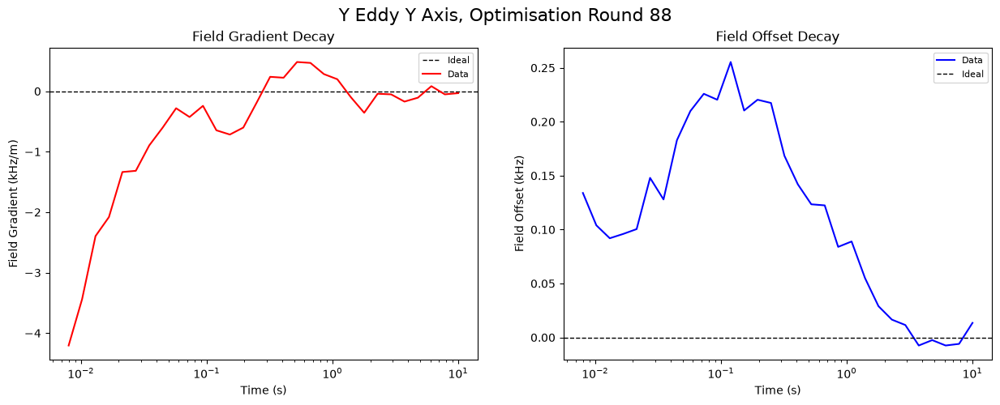

[I 2026-11-25 17:10:04,907] Trial 88 finished with value: 261.3259654489062 and parameters: {'Y_A1': -0.012625739911945847, 'Y_A2': -0.006617311536428997, 'Y_A3': -1.4246285196959848e-09, 'Y_A4': -9.374564340331038e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.613e+02
Total cost = 2.613e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2393472368890987
B nanmax = 0.2393472368890987
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23922430964433214 !!!!!!!!!!!!!!!!


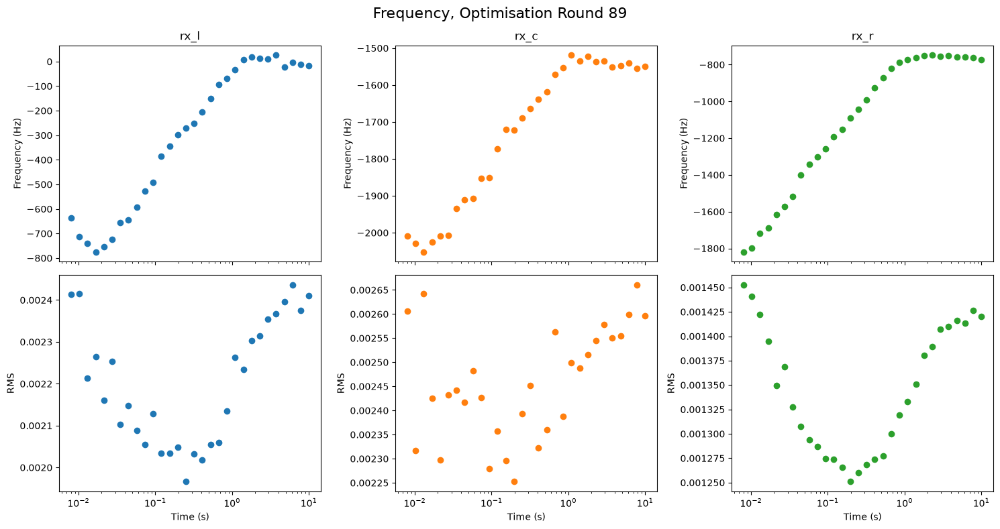

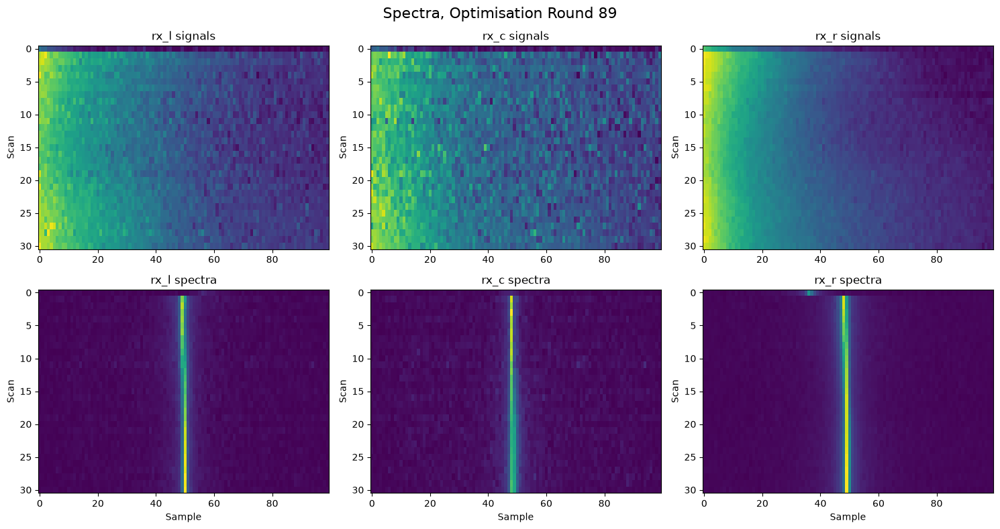

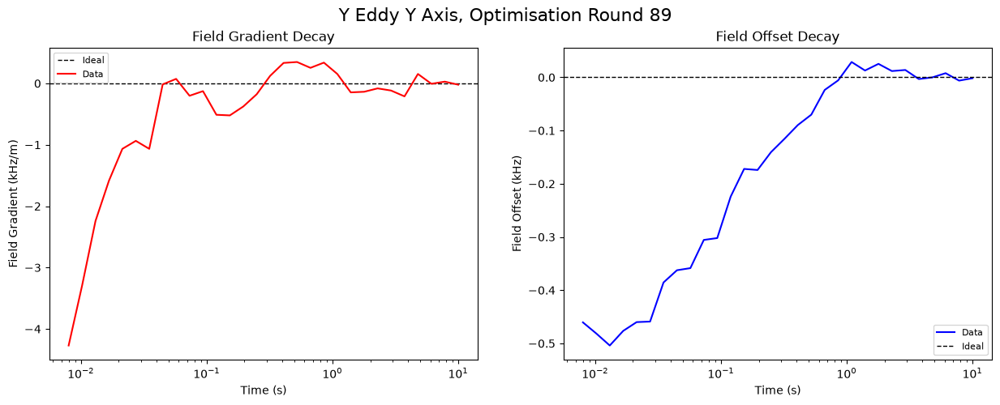

[I 2026-11-25 17:10:53,271] Trial 89 finished with value: 167.98166001969633 and parameters: {'Y_A1': -0.010622239859518661, 'Y_A2': -0.00635194414287142, 'Y_A3': 4.275180754326839e-10, 'Y_A4': -8.885868678559709e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.680e+02
Total cost = 1.680e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.261170900382285
B nanmax = 0.261170900382285
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.261036763995771 !!!!!!!!!!!!!!!!


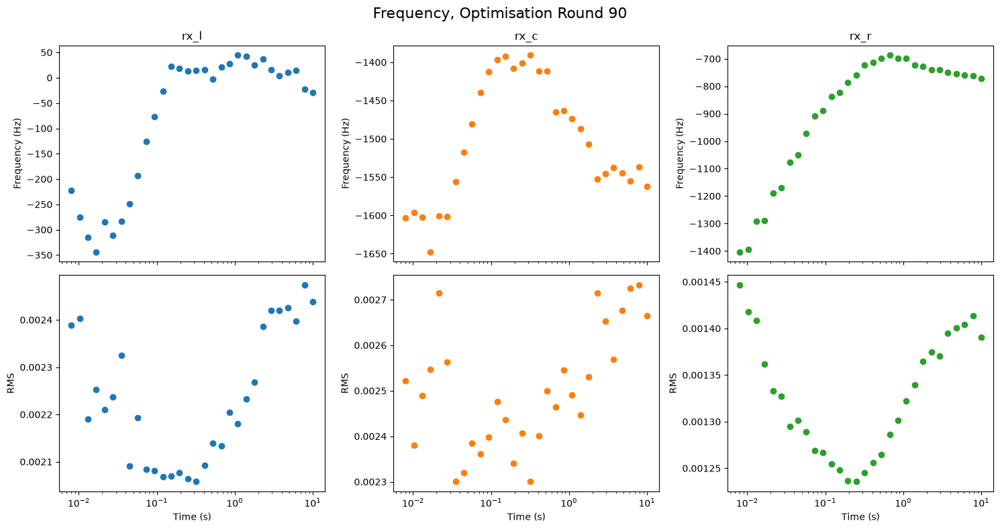

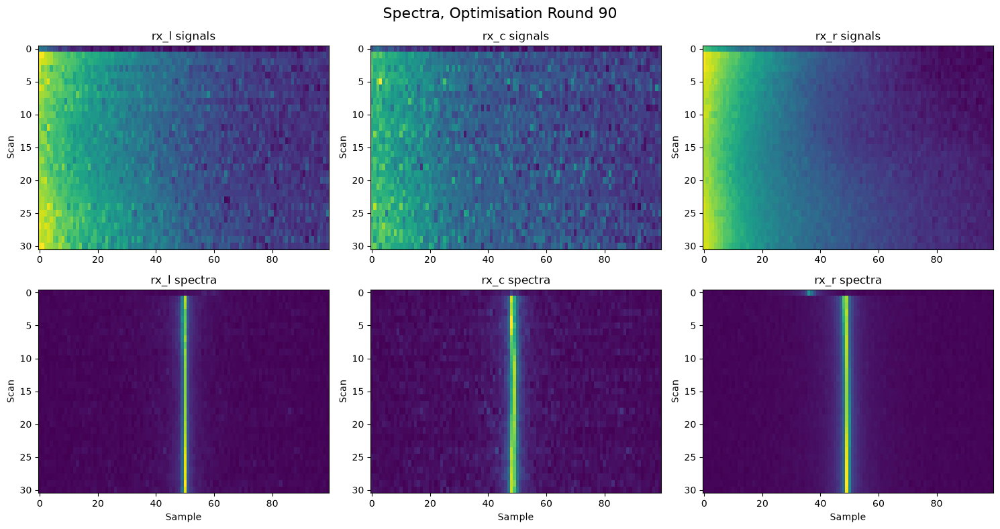

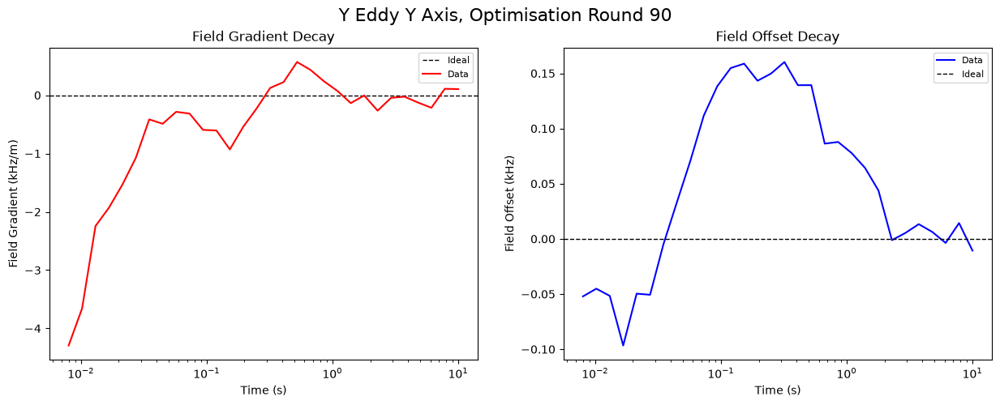

[I 2026-11-25 17:11:41,195] Trial 90 finished with value: 245.23145239772853 and parameters: {'Y_A1': -0.012513543450218238, 'Y_A2': -0.006006616889873967, 'Y_A3': -2.2710769925407324e-09, 'Y_A4': -9.212003247341745e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.452e+02
Total cost = 2.452e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2608315270892278
B nanmax = 0.2608315270892278
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2606975653534965 !!!!!!!!!!!!!!!!


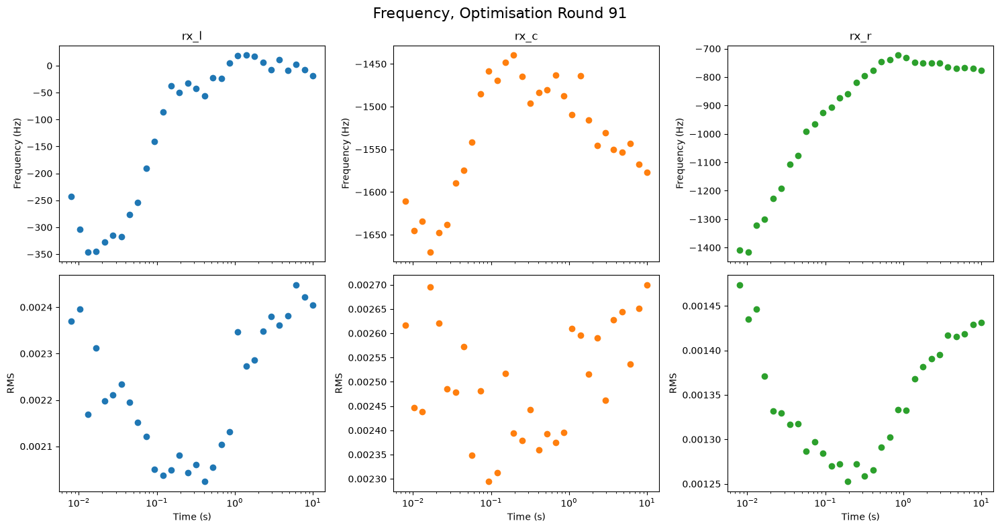

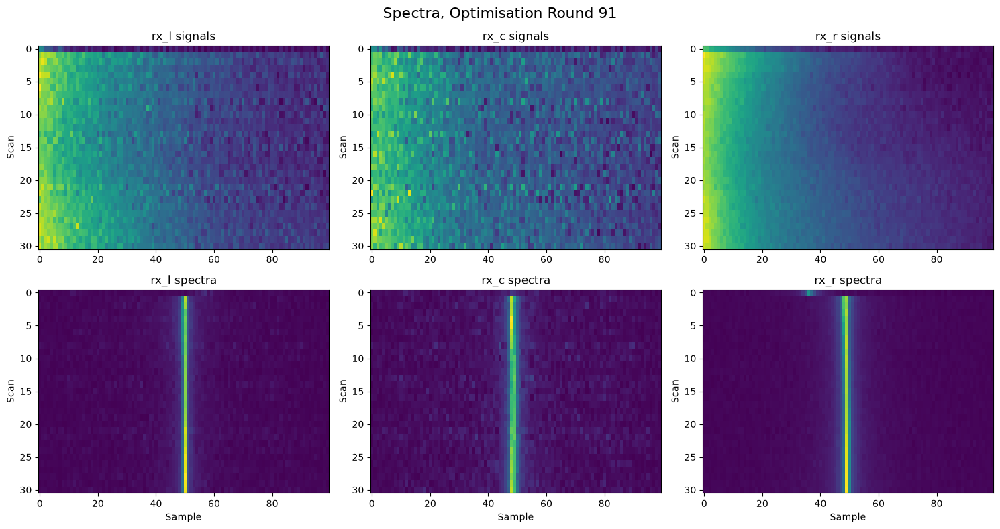

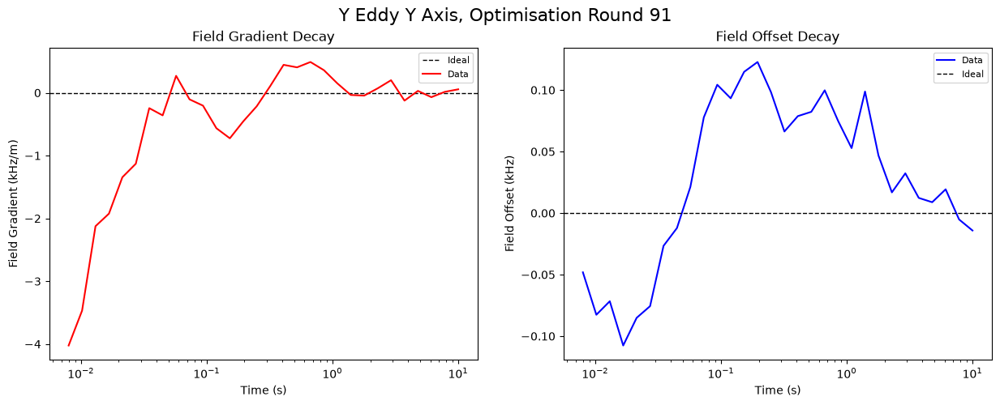

[I 2026-11-25 17:12:29,172] Trial 91 finished with value: 261.2813945104173 and parameters: {'Y_A1': -0.011996321645319509, 'Y_A2': -0.006500711435517772, 'Y_A3': 1.6024485378358245e-09, 'Y_A4': -7.409564494497747e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.613e+02
Total cost = 2.613e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24377973641267864
B nanmax = 0.24377973641267864
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24365453216552646 !!!!!!!!!!!!!!!!


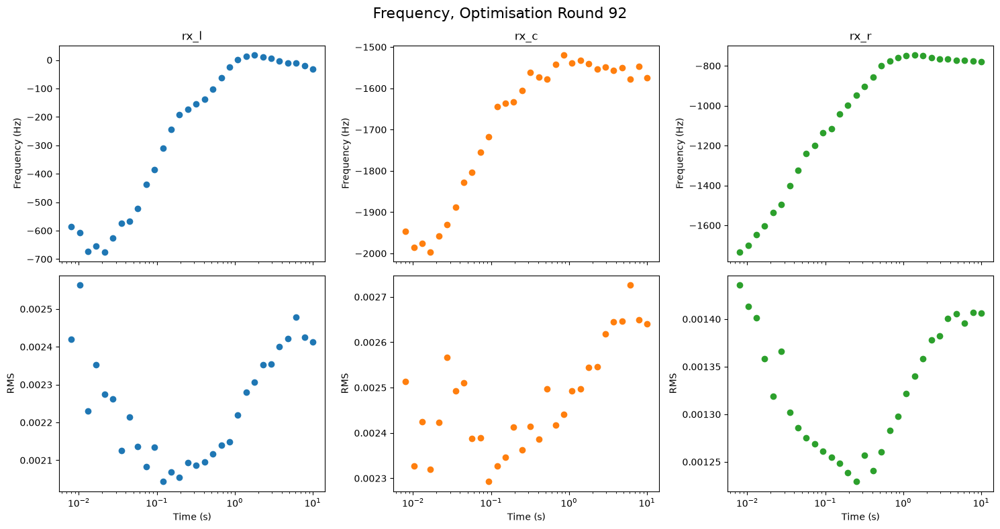

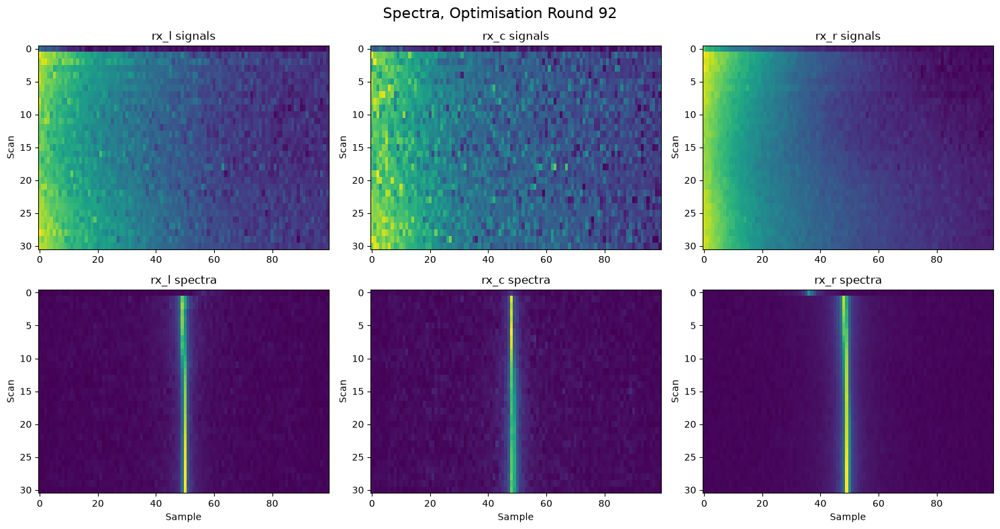

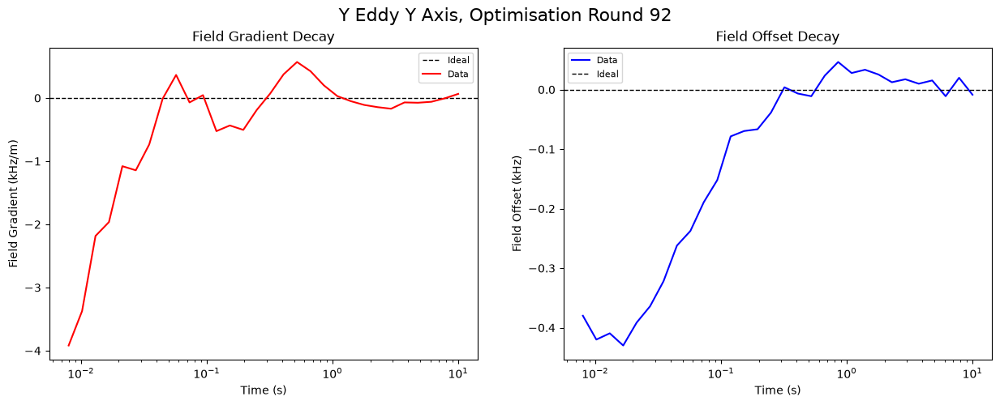

[I 2026-11-25 17:13:17,125] Trial 92 finished with value: 194.17179134720283 and parameters: {'Y_A1': -0.011532349852626524, 'Y_A2': -0.00575484473219685, 'Y_A3': 3.8903082661274164e-10, 'Y_A4': -8.707121761552902e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.942e+02
Total cost = 1.942e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25461250920389955
B nanmax = 0.25461250920389955
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2544817418499546 !!!!!!!!!!!!!!!!


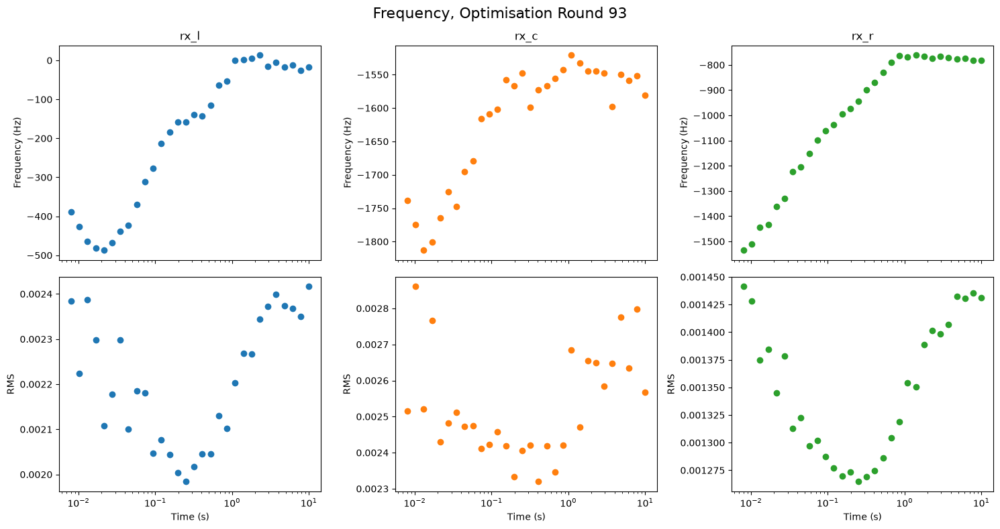

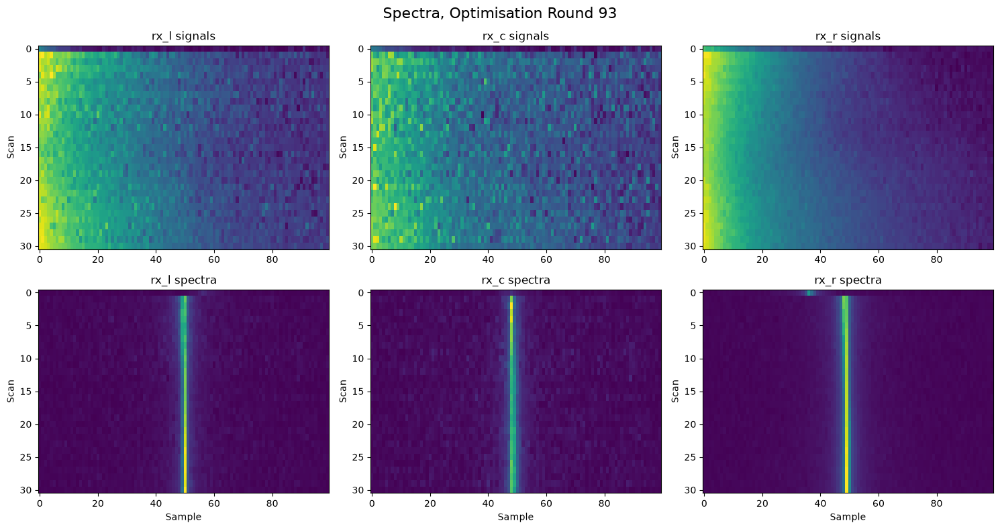

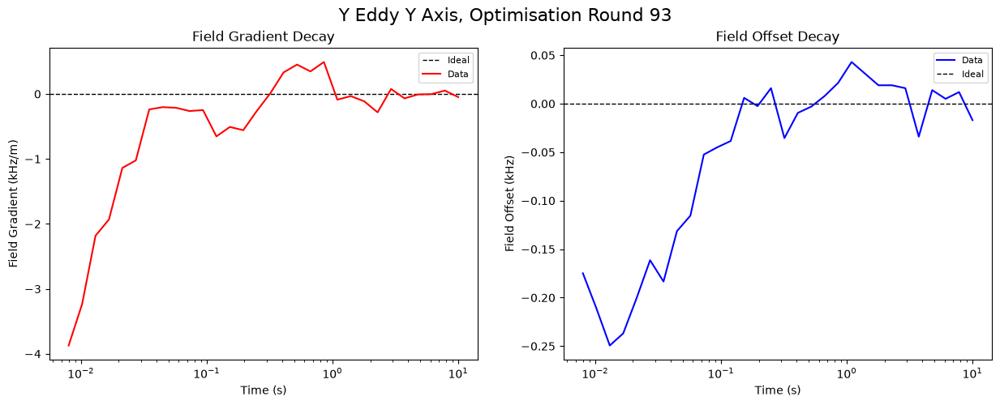

[I 2026-11-25 17:14:04,927] Trial 93 finished with value: 174.80278895113776 and parameters: {'Y_A1': -0.011243511452654049, 'Y_A2': -0.0068133703993494945, 'Y_A3': -5.333915127978599e-10, 'Y_A4': -7.431852936635053e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.748e+02
Total cost = 1.748e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24935908476800062
B nanmax = 0.24935908476800062
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24923101504671583 !!!!!!!!!!!!!!!!


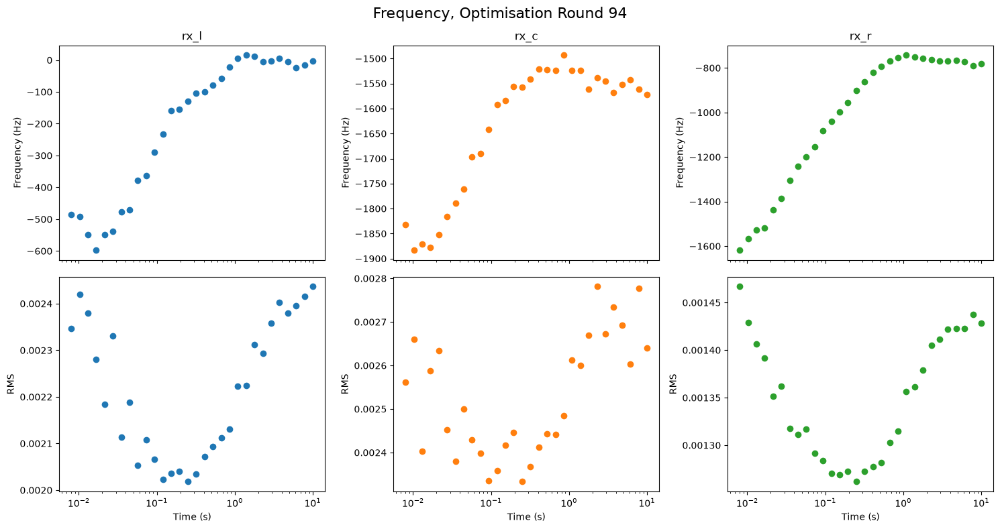

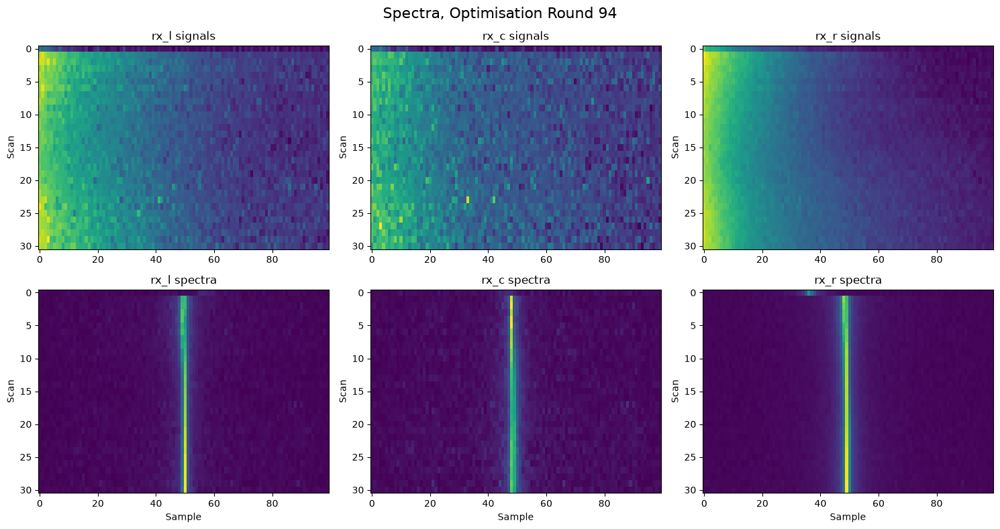

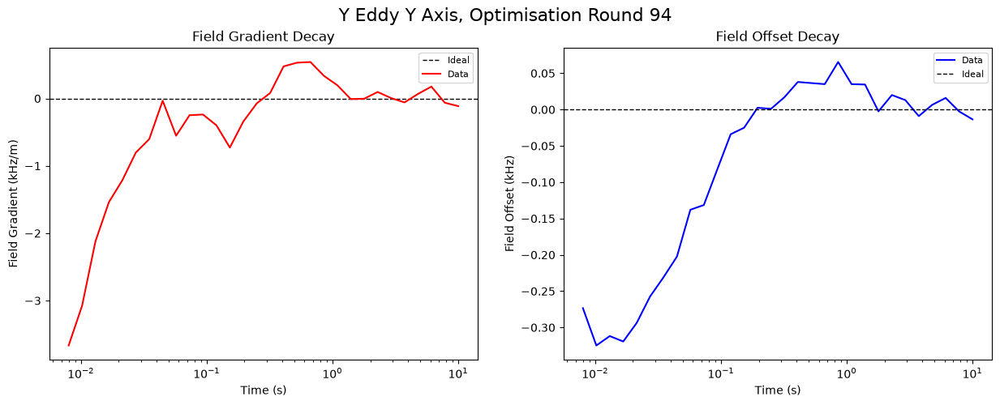

[I 2026-11-25 17:14:52,991] Trial 94 finished with value: 152.4149816383569 and parameters: {'Y_A1': -0.01171653353484236, 'Y_A2': -0.005966459740671749, 'Y_A3': -3.3928223270359436e-09, 'Y_A4': -7.682300950300008e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.524e+02
Total cost = 1.524e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.23644809972505673
B nanmax = 0.23644809972505673
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.23632666105467492 !!!!!!!!!!!!!!!!


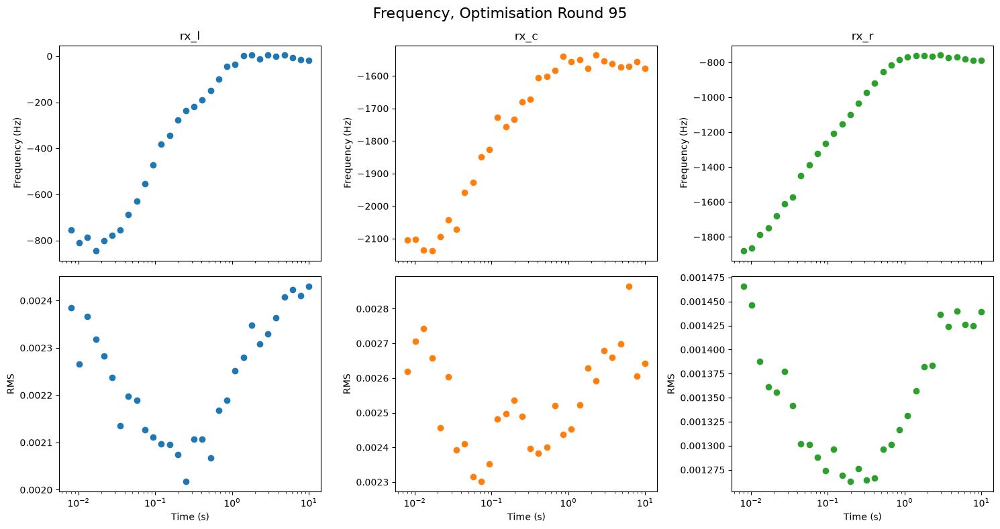

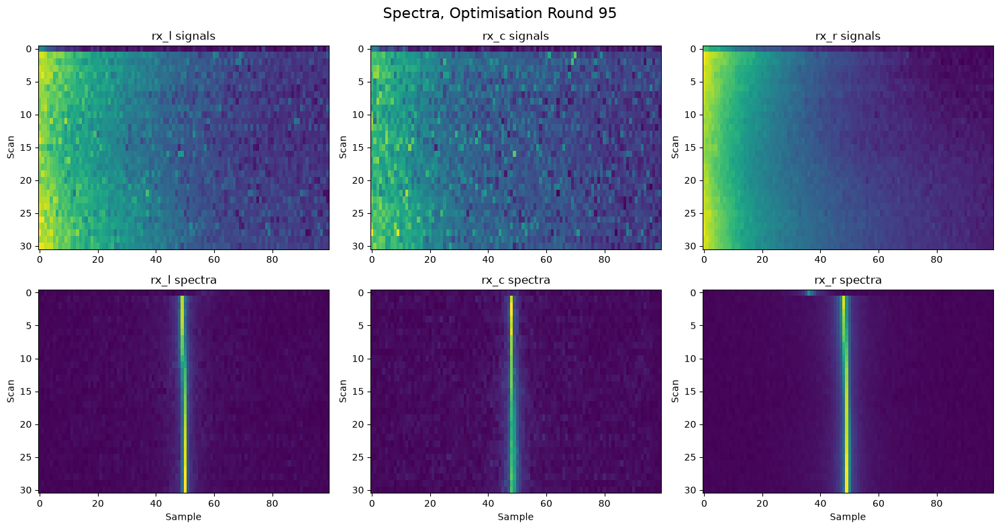

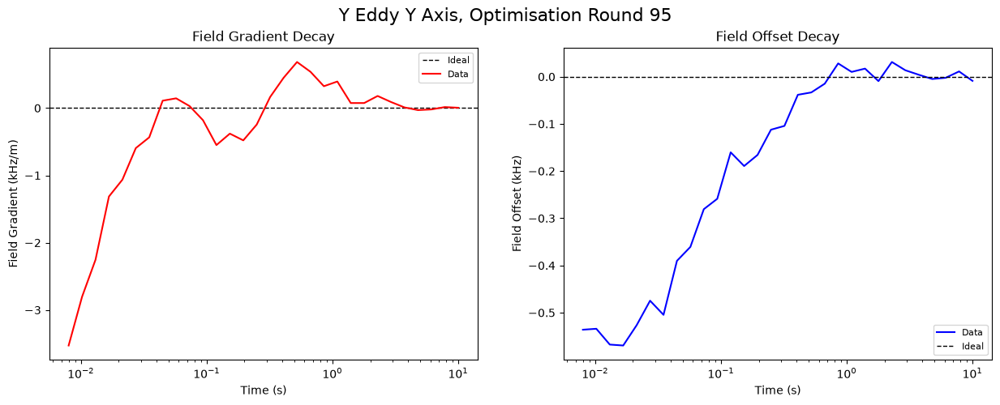

[I 2026-11-25 17:15:40,921] Trial 95 finished with value: 173.999102489353 and parameters: {'Y_A1': -0.011072410001264672, 'Y_A2': -0.005695086832558569, 'Y_A3': -4.8086313547266335e-09, 'Y_A4': -2.980721590190223e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.740e+02
Total cost = 1.740e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.25505028852035794
B nanmax = 0.25505028852035794
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2549192961476562 !!!!!!!!!!!!!!!!


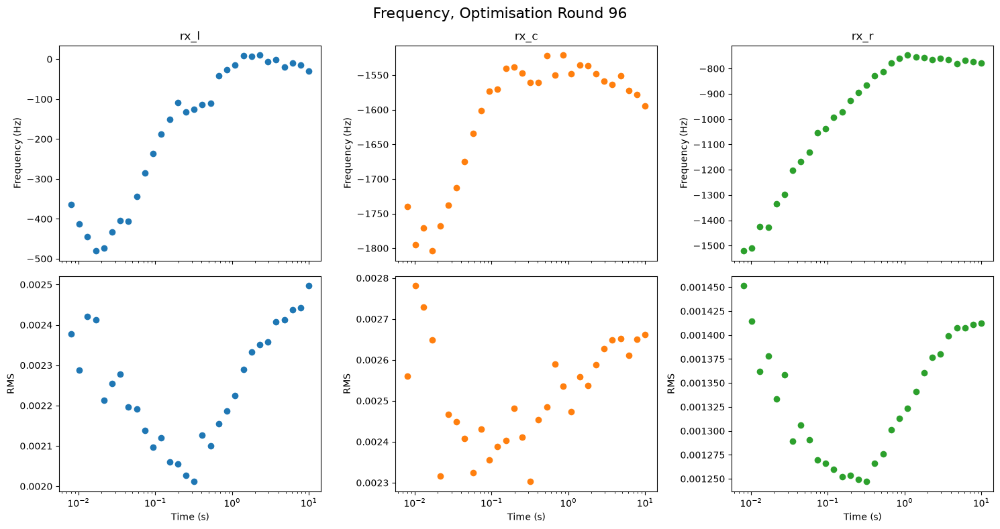

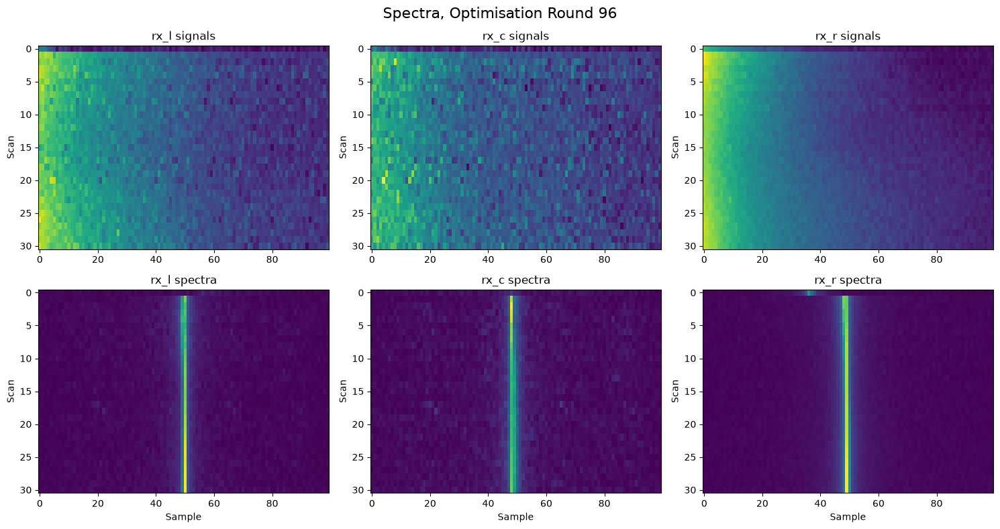

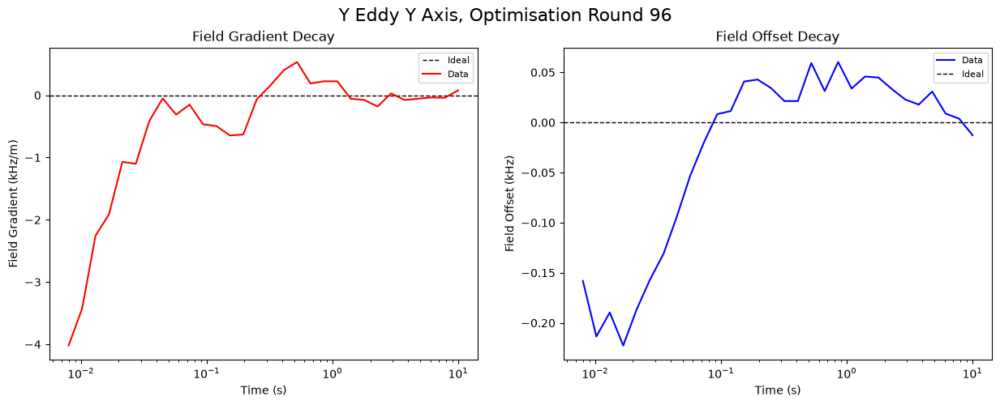

[I 2026-11-25 17:16:28,759] Trial 96 finished with value: 211.79805702278173 and parameters: {'Y_A1': -0.011517807002412938, 'Y_A2': -0.006569644157505102, 'Y_A3': 1.7952175844204502e-10, 'Y_A4': -9.772151858373e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.118e+02
Total cost = 2.118e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24796327569389798
B nanmax = 0.24796327569389798
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24783592274416097 !!!!!!!!!!!!!!!!


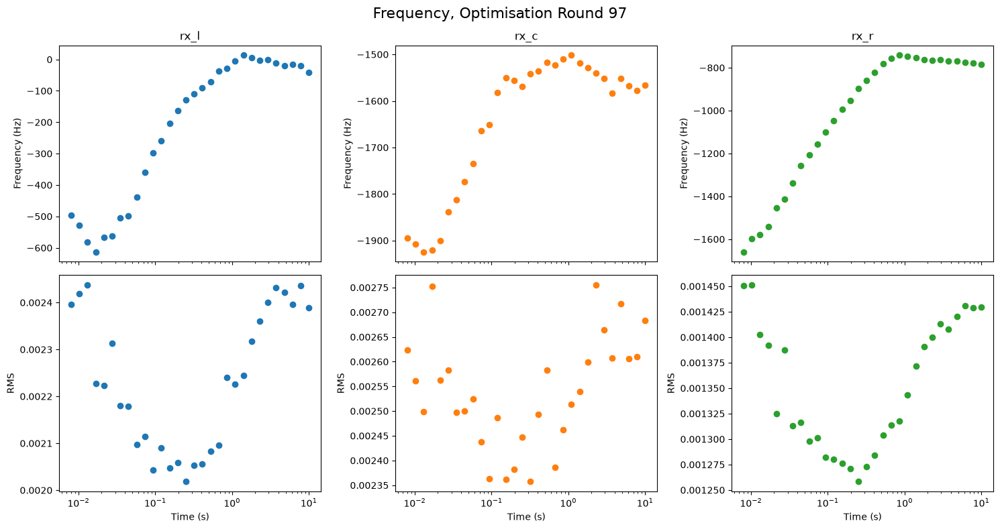

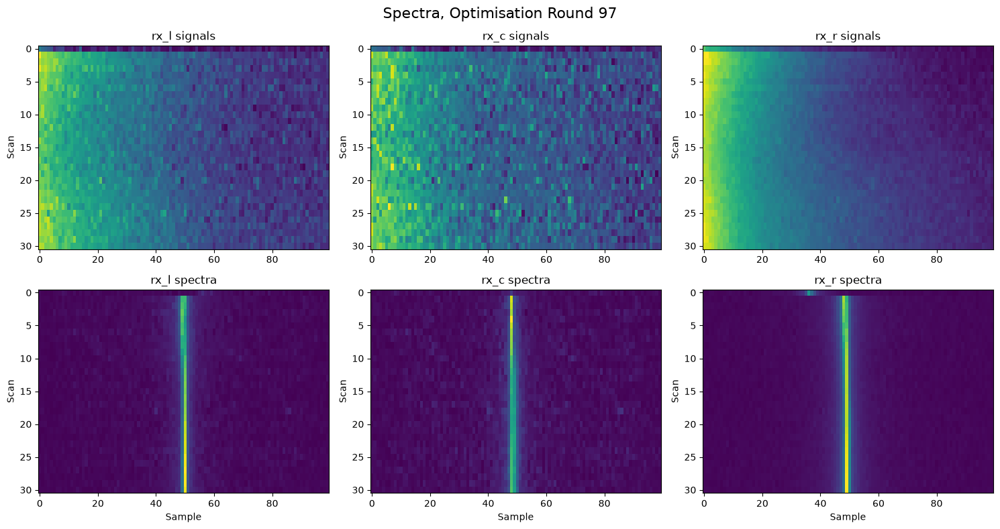

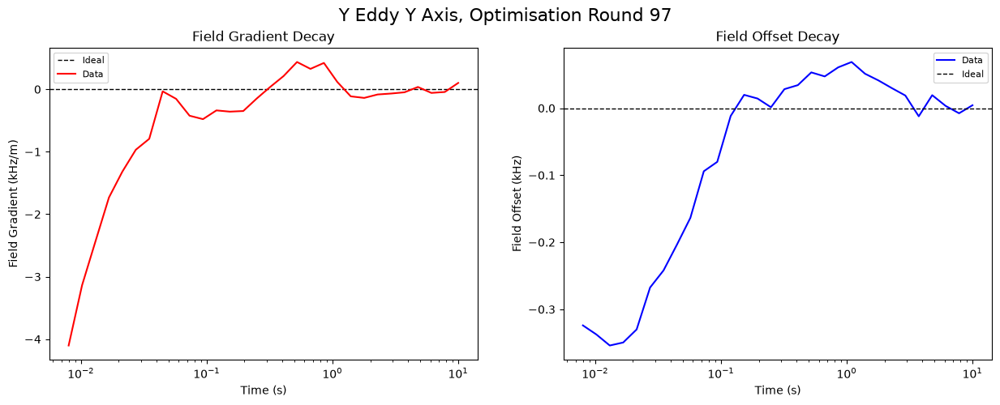

[I 2026-11-25 17:17:16,774] Trial 97 finished with value: 197.3550975617619 and parameters: {'Y_A1': -0.011808146983835694, 'Y_A2': -0.005775569745197244, 'Y_A3': -1.3134350536618507e-09, 'Y_A4': -8.997963039757613e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 1.974e+02
Total cost = 1.974e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.24432123789293905
B nanmax = 0.24432123789293905
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.24419575590329656 !!!!!!!!!!!!!!!!


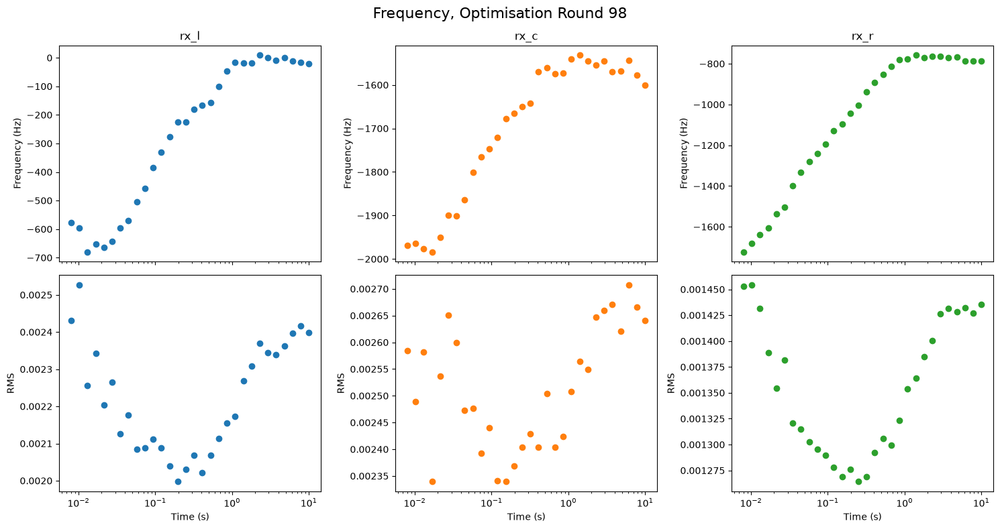

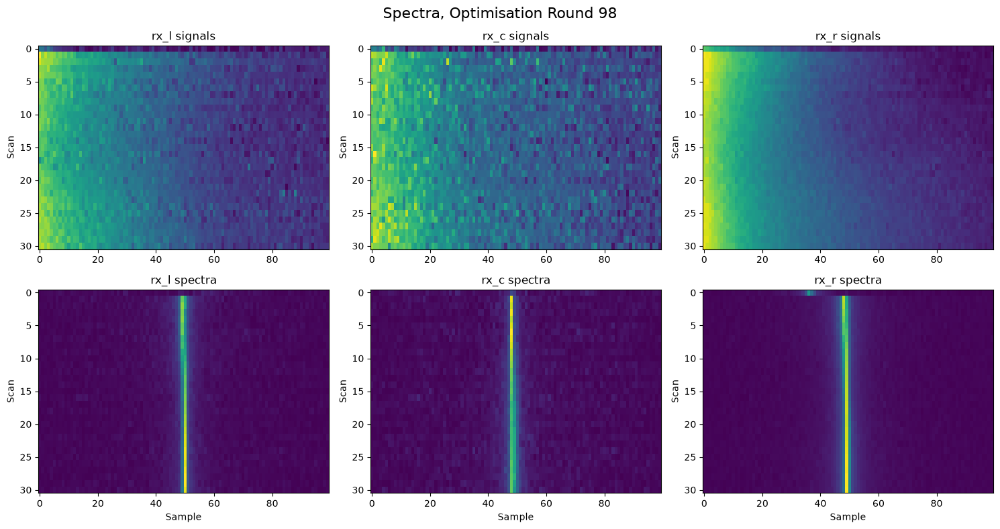

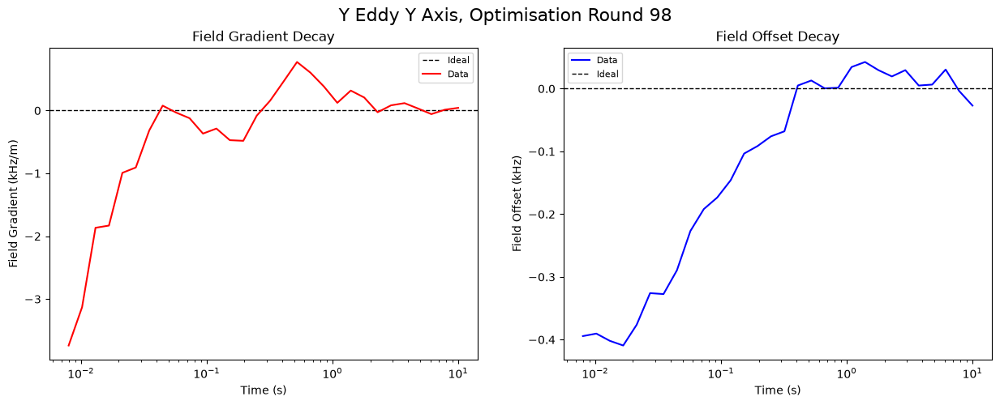

[I 2026-11-25 17:18:04,833] Trial 98 finished with value: 215.45420795562558 and parameters: {'Y_A1': -0.011027733060054523, 'Y_A2': -0.006298854336551177, 'Y_A3': -1.1219526051546683e-09, 'Y_A4': -9.302740896936868e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.155e+02
Total cost = 2.155e+02
E max = 0.13466285109505693
E nanmax = 0.13466285109505693
E contains nan = False
B max = 0.2560325103521221
B nanmax = 0.2560325103521221
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.2559010133758219 !!!!!!!!!!!!!!!!


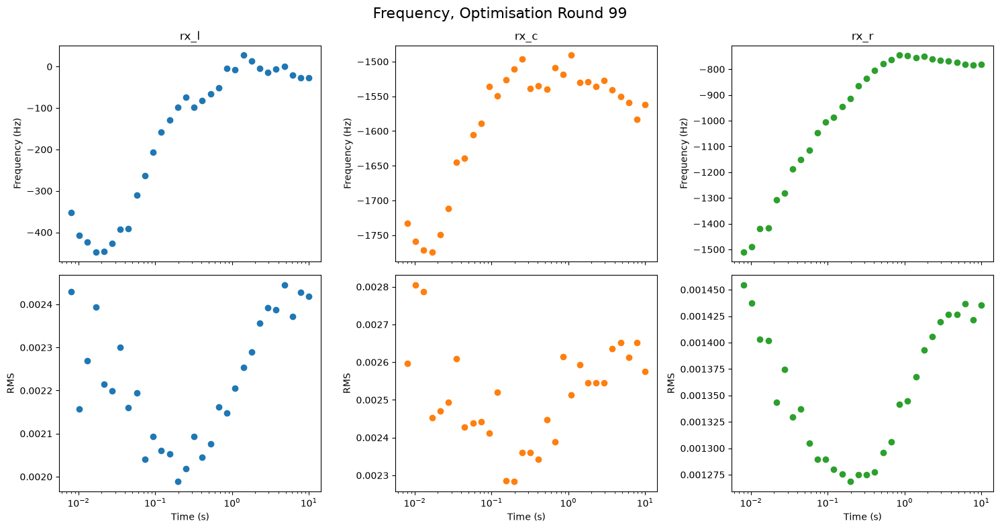

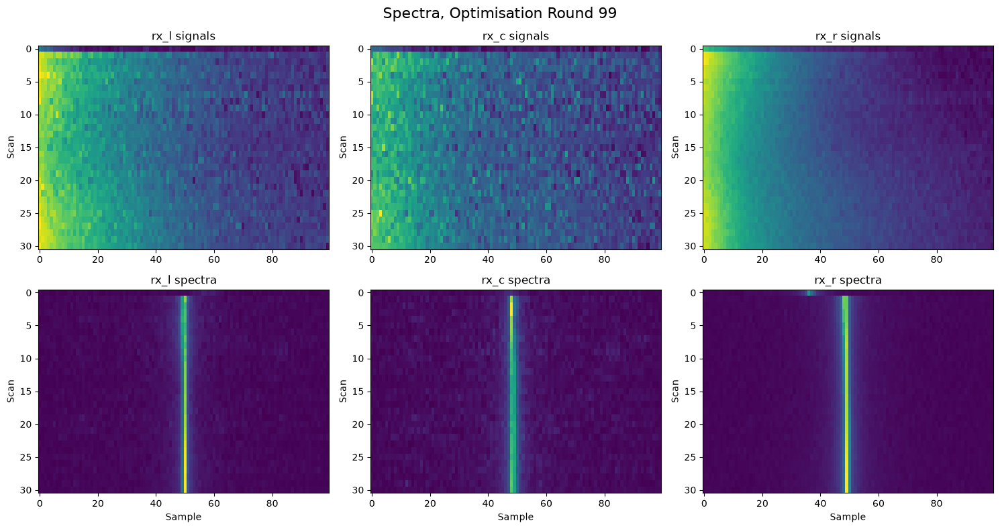

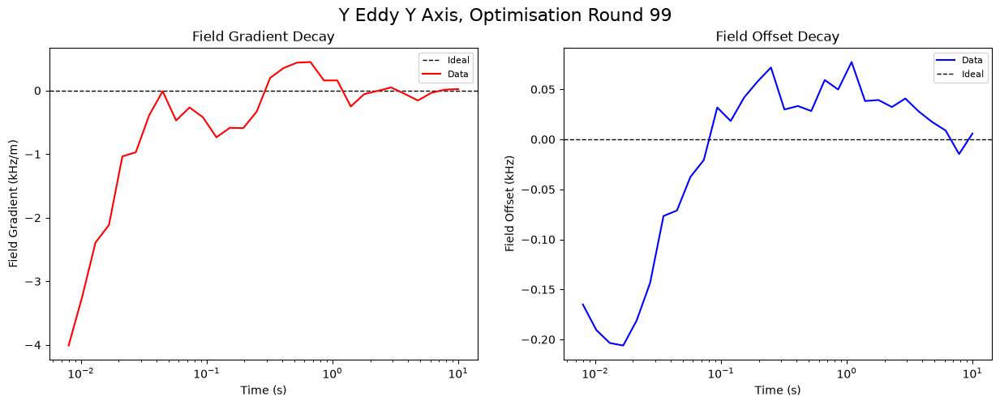

[I 2026-11-25 17:18:52,752] Trial 99 finished with value: 240.9252896984874 and parameters: {'Y_A1': -0.011762677931345113, 'Y_A2': -0.006394054045365918, 'Y_A3': 1.6023541662004936e-09, 'Y_A4': -9.870399104171263e-09}. Best is trial 64 with value: 117.49743056208108.


rx_c: 2.409e+02
Total cost = 2.409e+02
{'Y_A1': -0.011397943785723855, 'Y_A2': -0.0062841226320714755, 'Y_A3': -3.4141359184485785e-10, 'Y_A4': -8.327135441131884e-09}
64
117.49743056208108
{'Y_A1': -0.011397943785723855, 'Y_A2': -0.0062841226320714755, 'Y_A3': -3.4141359184485785e-10, 'Y_A4': -8.327135441131884e-09}


,trial,cost,g_pe_perc,max_b0var,status,Y_A1,Y_A2,Y_A3,Y_A4
0,0,342.157430,134.662851,0.261789,PASS,-0.012953,-0.005610,0.000000e+00,0.000000e+00
1,1,385.997014,134.662851,0.294760,PASS,-0.012826,-0.008078,1.861703e-09,7.505169e-09
2,2,332.454355,134.662851,0.221274,PASS,-0.009736,-0.005957,-7.015086e-09,-7.244703e-09
3,3,540.316348,134.662851,0.275915,PASS,-0.013845,-0.005719,6.255752e-09,7.192396e-09
4,4,832.902760,134.662851,0.339141,PASS,-0.015900,-0.008149,-3.820055e-09,5.838914e-09
...,...,...,...,...,...,...,...,...,...
95,95,173.999102,134.662851,0.236448,PASS,-0.011072,-0.005695,-4.808631e-09,-2.980722e-09
96,96,211.798057,134.662851,0.255050,PASS,-0.011518,-0.006570,1.795218e-10,-9.772152e-09
97,97,197.355098,134.662851,0.247963,PASS,-0.011808,-0.005776,-1.313435e-09,-8.997963e-09
98,98,215.454208,134.662851,0.244321,PASS,-0.011028,-0.006299,-1.121953e-09,-9.302741e-09


In [11]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = B_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START_opt, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "offset_info.csv", index=False)

opt.save_to_global(B_START, OPT_AXIS, "eddy_B0.yaml")

#### Plot Optimisation Performance

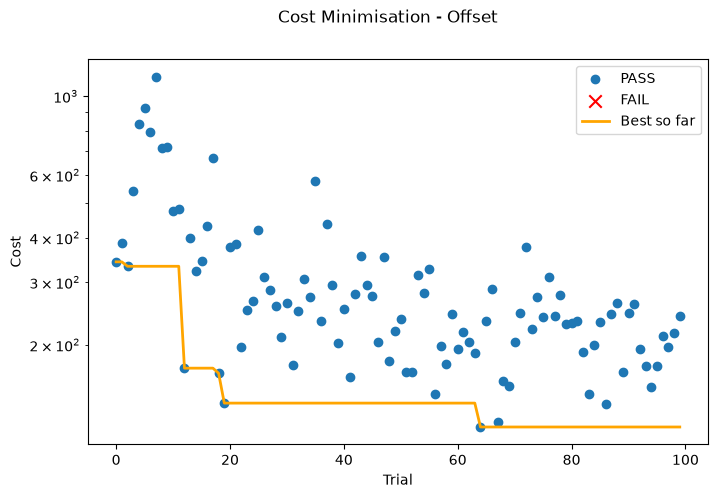

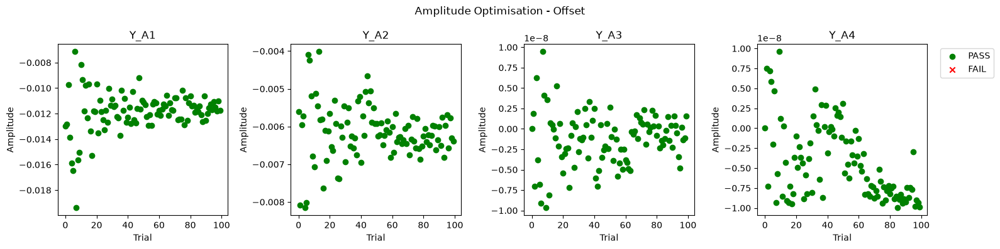

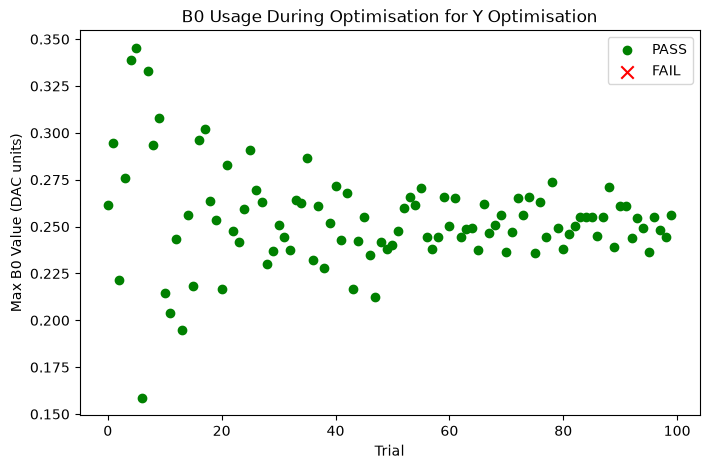

In [12]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)